Output dirs: /kaggle/working/outputs
Shape: (253680, 22)


,HeartDiseaseorAttack,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,Diabetes,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0



Class distribution:
0    229787
1     23893
Name: count, dtype: int64
Positive rate ≈ 0.0942


,col,dtype,missing,nunique
0,HighBP,float64,0,2
1,HighChol,float64,0,2
2,CholCheck,float64,0,2
4,Smoker,float64,0,2
5,Stroke,float64,0,2
7,PhysActivity,float64,0,2
8,Fruits,float64,0,2
9,Veggies,float64,0,2
10,HvyAlcoholConsump,float64,0,2
11,AnyHealthcare,float64,0,2


Fold 1: PR_AUC=0.3691 ROC_AUC=0.8492 ECE=0.2579
Fold 2: PR_AUC=0.3739 ROC_AUC=0.8497 ECE=0.2565
Fold 3: PR_AUC=0.3792 ROC_AUC=0.8497 ECE=0.2560
Fold 4: PR_AUC=0.3664 ROC_AUC=0.8434 ECE=0.2573
Fold 5: PR_AUC=0.3629 ROC_AUC=0.8447 ECE=0.2586


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,p_mean,pos_rate,N,thr_bestF1,...,F1@bestF1,thr_P>=0.30,Prec@P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,Rec@R>=0.50,F1@R>=0.50,fold
0,LogReg_fold1,0.369131,0.849229,0.164648,0.494998,0.257897,0.352070,0.094174,50736,0.658755,...,0.413798,0.632998,0.300010,0.641900,0.408906,0.726565,0.347687,0.500209,0.410230,1
1,LogReg_fold2,0.373855,0.849749,0.164315,0.493107,0.256490,0.350664,0.094174,50736,0.688467,...,0.418283,0.624979,0.300010,0.659481,0.412408,0.730014,0.352552,0.501674,0.414097,2
2,LogReg_fold3,0.379232,0.849699,0.163667,0.492618,0.255970,0.350164,0.094193,50736,0.711262,...,0.424824,0.623086,0.300019,0.663946,0.413286,0.736804,0.366846,0.500105,0.423234,3
3,LogReg_fold4,0.366430,0.843409,0.166221,0.499095,0.257341,0.351534,0.094193,50736,0.700355,...,0.417030,0.637497,0.300020,0.636953,0.407906,0.731877,0.352196,0.500105,0.413316,4
4,LogReg_fold5,0.362910,0.844686,0.166514,0.499431,0.258564,0.352758,0.094193,50736,0.696137,...,0.416297,0.631674,0.300010,0.649299,0.410395,0.726538,0.346489,0.507010,0.411655,5



OOF: {'model': 'LogReg_OOF', 'PR_AUC': 0.36987405973071047, 'ROC_AUC': 0.8473448292898822, 'Brier': 0.1650728486741802, 'NLL': 0.49584971772038805, 'ECE': 0.25725236822613373, 'p_mean': 0.35143795636867553, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.700916188286799, 'Prec@bestF1': 0.33589566197760523, 'Rec@bestF1': 0.5486544176118529, 'F1@bestF1': 0.4166878575964774, 'thr_P>=0.30': 0.6296084719384113, 'Prec@P>=0.30': 0.3000019289007195, 'Rec@P>=0.30': 0.6509437910685137, 'F1@P>=0.30': 0.4107161719653439, 'thr_R>=0.50': 0.7304204099268404, 'Prec@R>=0.50': 0.35210561989803435, 'Rec@R>=0.50': 0.5000627798936927, 'F1@R>=0.50': 0.41323971915698754}


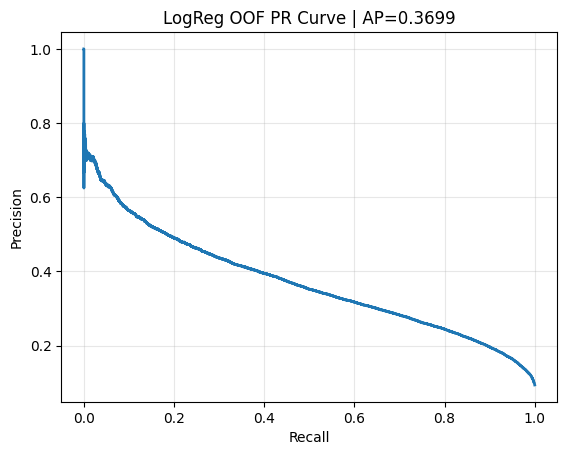

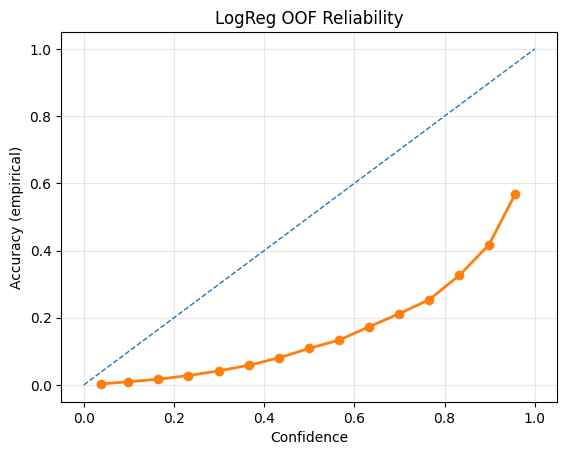

In [1]:
# ============================================================
# Trust-HEART (BRFSS) — Kaggle Notebook
# Module 0–1–2: Data + Baselines + RE-SMoE-Trust (PyTorch)
# Target: HeartDiseaseorAttack
# Dataset: https://www.kaggle.com/datasets/alexteboul/heart-disease-health-indicators-dataset
# ============================================================

import os, gc, json, math, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_recall_curve
)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

import matplotlib.pyplot as plt

SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
seed_everything(SEED)

# Outputs
OUT_DIR = "/kaggle/working/outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
TAB_DIR = os.path.join(OUT_DIR, "tables")
MOD_DIR = os.path.join(OUT_DIR, "models")
for d in [OUT_DIR, FIG_DIR, TAB_DIR, MOD_DIR]:
    os.makedirs(d, exist_ok=True)

print("Output dirs:", OUT_DIR)

# ============================================================
# Module 0 — Load + Audit + Feature/Target Setup
# ============================================================

# Typical file name in this Kaggle dataset
# If your path differs, adjust here.
DATA_PATH_CANDIDATES = [
    "/kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv",
    "/kaggle/input/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv/heart_disease_health_indicators_BRFSS2015.csv",
]

DATA_PATH = None
for p in DATA_PATH_CANDIDATES:
    if os.path.exists(p):
        DATA_PATH = p
        break

if DATA_PATH is None:
    raise FileNotFoundError("Could not find dataset CSV in expected Kaggle path. Please open /kaggle/input and set DATA_PATH.")

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())

TARGET = "HeartDiseaseorAttack"
assert TARGET in df.columns, f"Target {TARGET} not found in columns."

y = df[TARGET].astype(int).values
X = df.drop(columns=[TARGET]).copy()

print("\nClass distribution:")
vc = pd.Series(y).value_counts().sort_index()
pos_rate = vc.get(1, 0) / len(y)
print(vc)
print(f"Positive rate ≈ {pos_rate:.4f}")

# Basic audit
audit = pd.DataFrame({
    "col": X.columns,
    "dtype": [str(X[c].dtype) for c in X.columns],
    "missing": [int(X[c].isna().sum()) for c in X.columns],
    "nunique": [int(X[c].nunique(dropna=True)) for c in X.columns],
}).sort_values(["missing", "nunique"], ascending=[False, True])
display(audit.head(15))

audit.to_csv(os.path.join(TAB_DIR, "module0_feature_audit.csv"), index=False)

# ============================================================
# Helpers — Metrics, ECE, Threshold utilities, plots
# ============================================================

def expected_calibration_error(y_true, p, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).clip(1e-8, 1-1e-8)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        m = (p >= lo) & (p < hi) if i < n_bins-1 else (p >= lo) & (p <= hi)
        if m.sum() == 0:
            continue
        acc = y_true[m].mean()
        conf = p[m].mean()
        ece += (m.sum() / len(p)) * abs(acc - conf)
    return float(ece)

def safe_log_loss(y_true, p):
    p = np.asarray(p).clip(1e-8, 1-1e-8)
    return float(log_loss(y_true, p))

def find_threshold_by_constraint(y_true, p, mode="precision_at_least", value=0.30):
    """
    mode:
      - "precision_at_least": maximize recall s.t. precision >= value
      - "recall_at_least": maximize precision s.t. recall >= value
      - "best_f1": threshold maximizing F1
    """
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p)
    prec, rec, thr = precision_recall_curve(y_true, p)
    # precision_recall_curve returns thr of length n-1
    thr = np.r_[thr, 1.0]  # align sizes
    
    f1 = (2*prec*rec)/(prec+rec+1e-12)

    if mode == "best_f1":
        idx = int(np.nanargmax(f1))
        return float(thr[idx]), float(prec[idx]), float(rec[idx]), float(f1[idx])

    if mode == "precision_at_least":
        ok = prec >= value
        if not ok.any():
            # fallback: highest precision point
            idx = int(np.nanargmax(prec))
            return float(thr[idx]), float(prec[idx]), float(rec[idx]), float(f1[idx])
        idx = int(np.nanargmax(rec * ok))
        return float(thr[idx]), float(prec[idx]), float(rec[idx]), float(f1[idx])

    if mode == "recall_at_least":
        ok = rec >= value
        if not ok.any():
            idx = int(np.nanargmax(rec))
            return float(thr[idx]), float(prec[idx]), float(rec[idx]), float(f1[idx])
        idx = int(np.nanargmax(prec * ok))
        return float(thr[idx]), float(prec[idx]), float(rec[idx]), float(f1[idx])

    raise ValueError("Unknown mode.")

def evaluate_probs(y_true, p, name="model"):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).clip(1e-8, 1-1e-8)
    out = {
        "model": name,
        "PR_AUC": float(average_precision_score(y_true, p)),
        "ROC_AUC": float(roc_auc_score(y_true, p)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": safe_log_loss(y_true, p),
        "ECE": expected_calibration_error(y_true, p, n_bins=15),
        "p_mean": float(p.mean()),
        "pos_rate": float(y_true.mean()),
        "N": int(len(y_true)),
    }
    # threshold summaries
    thr_f1, pr_f1, re_f1, f1 = find_threshold_by_constraint(y_true, p, mode="best_f1")
    thr_p30, pr30, re30, f130 = find_threshold_by_constraint(y_true, p, mode="precision_at_least", value=0.30)
    thr_r50, pr50, re50, f150 = find_threshold_by_constraint(y_true, p, mode="recall_at_least", value=0.50)
    out.update({
        "thr_bestF1": thr_f1, "Prec@bestF1": pr_f1, "Rec@bestF1": re_f1, "F1@bestF1": f1,
        "thr_P>=0.30": thr_p30, "Prec@P>=0.30": pr30, "Rec@P>=0.30": re30, "F1@P>=0.30": f130,
        "thr_R>=0.50": thr_r50, "Prec@R>=0.50": pr50, "Rec@R>=0.50": re50, "F1@R>=0.50": f150,
    })
    return out

def plot_pr_curve(y_true, p, title, savepath):
    prec, rec, _ = precision_recall_curve(y_true, p)
    ap = average_precision_score(y_true, p)
    plt.figure()
    plt.plot(rec, prec, linewidth=2)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{title} | AP={ap:.4f}")
    plt.grid(True, alpha=0.3)
    plt.savefig(savepath, dpi=200, bbox_inches="tight")
    plt.show()

def plot_reliability(y_true, p, title, savepath, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).clip(1e-8, 1-1e-8)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    bin_acc, bin_conf, bin_cnt = [], [], []
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        m = (p >= lo) & (p < hi) if i < n_bins-1 else (p >= lo) & (p <= hi)
        if m.sum() == 0:
            bin_acc.append(np.nan); bin_conf.append((lo+hi)/2); bin_cnt.append(0)
        else:
            bin_acc.append(y_true[m].mean()); bin_conf.append(p[m].mean()); bin_cnt.append(m.sum())
    plt.figure()
    plt.plot([0,1],[0,1], linestyle="--", linewidth=1)
    plt.plot(bin_conf, bin_acc, marker="o", linewidth=2)
    plt.xlabel("Confidence")
    plt.ylabel("Accuracy (empirical)")
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.savefig(savepath, dpi=200, bbox_inches="tight")
    plt.show()

# ============================================================
# Module 1 — Baselines (LogReg + optional CatBoost)
# Leakage-safe: outer CV + within-train calibration split
# ============================================================

N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

# Baseline preprocessing for linear model
preprocess_lr = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler(with_mean=True, with_std=True)),
])

# OOF containers
oof_lr = np.zeros(len(X), dtype=float)

fold_rows = []
for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
    X_tr, X_te = X.iloc[tr_idx].copy(), X.iloc[te_idx].copy()
    y_tr, y_te = y[tr_idx], y[te_idx]

    # calibration split inside training fold
    tr_main_idx, cal_idx = train_test_split(
        np.arange(len(X_tr)), test_size=0.2, stratify=y_tr, random_state=SEED+fold
    )
    X_main, y_main = X_tr.iloc[tr_main_idx], y_tr[tr_main_idx]
    X_cal,  y_cal  = X_tr.iloc[cal_idx],     y_tr[cal_idx]

    X_main_pp = preprocess_lr.fit_transform(X_main)
    X_cal_pp  = preprocess_lr.transform(X_cal)
    X_te_pp   = preprocess_lr.transform(X_te)

    lr = LogisticRegression(
        max_iter=2000,
        n_jobs=-1,
        class_weight="balanced",
        solver="lbfgs"
    )
    lr.fit(X_main_pp, y_main)

    p_te = lr.predict_proba(X_te_pp)[:, 1]
    oof_lr[te_idx] = p_te

    m = evaluate_probs(y_te, p_te, name=f"LogReg_fold{fold}")
    m["fold"] = fold
    fold_rows.append(m)
    print(f"Fold {fold}: PR_AUC={m['PR_AUC']:.4f} ROC_AUC={m['ROC_AUC']:.4f} ECE={m['ECE']:.4f}")

df_lr_folds = pd.DataFrame(fold_rows)
display(df_lr_folds)

lr_oof_metrics = evaluate_probs(y, oof_lr, name="LogReg_OOF")
print("\nOOF:", lr_oof_metrics)

df_lr_folds.to_csv(os.path.join(TAB_DIR, "module1_logreg_folds.csv"), index=False)
pd.DataFrame([lr_oof_metrics]).to_csv(os.path.join(TAB_DIR, "module1_logreg_oof.csv"), index=False)

plot_pr_curve(y, oof_lr, "LogReg OOF PR Curve", os.path.join(FIG_DIR, "module1_logreg_pr.png"))
plot_reliability(y, oof_lr, "LogReg OOF Reliability", os.path.join(FIG_DIR, "module1_logreg_reliability.png"))

In [2]:
# Quick column list
print("Total columns:", len(df.columns))
print(df.columns.tolist())

# Check for common BRFSS proxy targets (multi-task pretraining candidates)
candidates = [
    "HighBP", "HighChol", "CholCheck", "BMI", "Smoker", "Stroke", "Diabetes",
    "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump",
    "AnyHealthcare", "NoDocbcCost", "GenHlth", "MentHlth", "PhysHlth",
    "DiffWalk", "Sex", "Age", "Education", "Income",
    "HeartDiseaseorAttack"
]

exist = {c: (c in df.columns) for c in candidates}
exist_df = pd.DataFrame({"col": list(exist.keys()), "exists": list(exist.values())})
display(exist_df)

print("\nExisting candidates:", [c for c,v in exist.items() if v])
print("Missing candidates:", [c for c,v in exist.items() if not v])

Total columns: 22
['HeartDiseaseorAttack', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'Diabetes', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


,col,exists
0,HighBP,True
1,HighChol,True
2,CholCheck,True
3,BMI,True
4,Smoker,True
5,Stroke,True
6,Diabetes,True
7,PhysActivity,True
8,Fruits,True
9,Veggies,True



Existing candidates: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'Diabetes', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'HeartDiseaseorAttack']
Missing candidates: []


In [ ]:
# ============================================================
# Module 2 — RE-SMoE-Trust (PyTorch)
# Sparse MoE + Positive Specialist + Routing Prior + Balancing
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

class TabDataset(Dataset):
    def __init__(self, X_np, y_np):
        self.X = torch.tensor(X_np, dtype=torch.float32)
        self.y = torch.tensor(y_np, dtype=torch.float32)
    def __len__(self): return len(self.y)
    def __getitem__(self, idx): return self.X[idx], self.y[idx]

class MLPEncoder(nn.Module):
    def __init__(self, d_in, h1=256, h2=128, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, h1),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(h1, h2),
            nn.GELU(),
            nn.Dropout(dropout),
        )
    def forward(self, x): return self.net(x)

class ExpertHead(nn.Module):
    def __init__(self, d_in, hidden=None, dropout=0.0):
        super().__init__()
        if hidden is None:
            self.net = nn.Linear(d_in, 1)
        else:
            self.net = nn.Sequential(
                nn.Linear(d_in, hidden),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(hidden, 1)
            )
    def forward(self, h):
        return self.net(h).squeeze(-1)  # logits

class RESMoETrust(nn.Module):
    def __init__(self, d_in, K=4, top_k=2, enc_h1=256, enc_h2=128, dropout=0.1, expert_hidden=None):
        super().__init__()
        self.K = K
        self.top_k = top_k
        self.encoder = MLPEncoder(d_in, enc_h1, enc_h2, dropout=dropout)
        self.gate = nn.Linear(enc_h2, K)
        self.experts = nn.ModuleList([ExpertHead(enc_h2, hidden=expert_hidden, dropout=dropout) for _ in range(K)])

    def forward(self, x):
        h = self.encoder(x)  # [B, H]
        gate_logits = self.gate(h)  # [B, K]
        g = F.softmax(gate_logits, dim=-1)  # dense weights

        # Sparse top-k routing
        topv, topi = torch.topk(g, k=self.top_k, dim=-1)  # [B, k]
        sparse = torch.zeros_like(g)
        sparse.scatter_(1, topi, topv)
        sparse = sparse / (sparse.sum(dim=-1, keepdim=True) + 1e-12)  # renorm

        # Expert logits/probs
        expert_logits = torch.stack([ex(h) for ex in self.experts], dim=1)  # [B, K]
        expert_probs = torch.sigmoid(expert_logits)  # [B, K]

        # Mixture prob
        p = (sparse * expert_probs).sum(dim=1)  # [B]
        return {
            "p": p,
            "g_dense": g,
            "g_sparse": sparse,
            "expert_probs": expert_probs
        }

def asym_focal_loss(p, y, alpha=0.75, gamma_pos=3.0, gamma_neg=0.5):
    p = p.clamp(1e-8, 1-1e-8)
    y = y.float()
    pos = -alpha * y * ((1 - p) ** gamma_pos) * torch.log(p)
    neg = -(1 - alpha) * (1 - y) * (p ** gamma_neg) * torch.log(1 - p)
    return (pos + neg).mean()

def compute_losses(batch_out, y, alpha=0.75, gamma_pos=3.0, gamma_neg=0.5,
                   lambda_ps=0.5, lambda_route=0.2, lambda_bal=0.1, lambda_psn=0.25,
                   top_k=2, K=4):
    p = batch_out["p"]
    g_sparse = batch_out["g_sparse"]
    expert_probs = batch_out["expert_probs"]

    # Main rare-event loss on mixture output
    L_main = asym_focal_loss(p, y, alpha=alpha, gamma_pos=gamma_pos, gamma_neg=gamma_neg)

    # Positive-specialist auxiliary loss (expert 0)
    p1 = expert_probs[:, 0].clamp(1e-8, 1-1e-8)
    y = y.float()
    L_ps = (y * F.binary_cross_entropy(p1, torch.ones_like(p1), reduction="none") +
            lambda_psn * (1 - y) * F.binary_cross_entropy(p1, torch.zeros_like(p1), reduction="none")).mean()

    # Routing prior: positives should route to specialist more often
    pi_ps = g_sparse[:, 0]
    L_route = (y * (1 - pi_ps)).mean()

    # Load balancing: avoid expert collapse (based on usage in top-k)
    # usage indicator approx: nonzero in sparse weights
    used = (g_sparse > 0).float().mean(dim=0)  # [K]
    target = float(top_k) / float(K)
    L_bal = ((used - target) ** 2).sum()

    L = L_main + lambda_ps * L_ps + lambda_route * L_route + lambda_bal * L_bal
    return L, {"L_main": float(L_main.item()), "L_ps": float(L_ps.item()), "L_route": float(L_route.item()), "L_bal": float(L_bal.item())}

class TemperatureScaler(nn.Module):
    def __init__(self):
        super().__init__()
        self.logT = nn.Parameter(torch.zeros(()))  # log(T)
    def forward(self, logits):
        T = torch.exp(self.logT).clamp(1e-3, 100.0)
        return logits / T

@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    ps = []
    ys = []
    gs = []
    for xb, yb in loader:
        xb = xb.to(DEVICE)
        out = model(xb)
        ps.append(out["p"].detach().cpu().numpy())
        ys.append(yb.numpy())
        gs.append(out["g_sparse"].detach().cpu().numpy())
    return np.concatenate(ps), np.concatenate(ys), np.concatenate(gs)

def fit_temperature_scaling(p_uncal, y_cal, max_iter=2000, lr=0.05):
    """
    Temperature scaling on logits(p) for binary.
    Returns calibrated probabilities and learned T.
    """
    p_uncal = np.clip(p_uncal, 1e-8, 1-1e-8)
    logits = np.log(p_uncal / (1 - p_uncal)).astype(np.float32)
    y_cal = y_cal.astype(np.float32)

    logits_t = torch.tensor(logits, dtype=torch.float32, device=DEVICE)
    y_t = torch.tensor(y_cal, dtype=torch.float32, device=DEVICE)

    ts = TemperatureScaler().to(DEVICE)
    opt = torch.optim.Adam([ts.logT], lr=lr)

    for _ in range(max_iter):
        opt.zero_grad()
        scaled = ts(logits_t)
        p = torch.sigmoid(scaled)
        loss = F.binary_cross_entropy(p, y_t)
        loss.backward()
        opt.step()

    T = float(torch.exp(ts.logT).detach().cpu().item())
    # apply
    scaled = (logits / max(T, 1e-6))
    p_cal = 1 / (1 + np.exp(-scaled))
    return p_cal, T

# ============================================================
# Module 2 — CV Training loop for RE-SMoE-Trust + calibration
# ============================================================

def make_numpy_features(X_df):
    # This dataset is already numeric; still ensure float32
    X_np = X_df.values.astype(np.float32)
    # Median impute (safe)
    # If no missing, this is no-op.
    col_meds = np.nanmedian(X_np, axis=0)
    inds = np.where(np.isnan(X_np))
    X_np[inds] = np.take(col_meds, inds[1])
    return X_np

def train_one_fold_resmoe(X_tr_df, y_tr, X_te_df, y_te, fold,
                         K=4, top_k=2, epochs=15, batch_size=1024,
                         lr=1e-3, wd=1e-4,
                         alpha=0.75, gamma_pos=3.0, gamma_neg=0.5,
                         lambda_ps=0.5, lambda_route=0.2, lambda_bal=0.1,
                         expert_hidden=None):
    # calibration split within fold
    idx = np.arange(len(X_tr_df))
    tr_main_idx, cal_idx = train_test_split(
        idx, test_size=0.2, stratify=y_tr, random_state=SEED+fold
    )
    X_main_df = X_tr_df.iloc[tr_main_idx]
    y_main = y_tr[tr_main_idx]
    X_cal_df = X_tr_df.iloc[cal_idx]
    y_cal = y_tr[cal_idx]

    # numpy (median impute)
    X_main = make_numpy_features(X_main_df)
    X_cal  = make_numpy_features(X_cal_df)
    X_te   = make_numpy_features(X_te_df)

    # standardize (optional but helps NN). Fit on main only (no leakage).
    scaler = StandardScaler()
    X_main = scaler.fit_transform(X_main).astype(np.float32)
    X_cal  = scaler.transform(X_cal).astype(np.float32)
    X_te   = scaler.transform(X_te).astype(np.float32)

    train_ds = TabDataset(X_main, y_main)
    cal_ds   = TabDataset(X_cal,  y_cal)
    test_ds  = TabDataset(X_te,   y_te)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0, drop_last=False)
    cal_loader   = DataLoader(cal_ds,   batch_size=batch_size, shuffle=False, num_workers=0)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=0)

    model = RESMoETrust(d_in=X_main.shape[1], K=K, top_k=top_k, expert_hidden=expert_hidden).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)

    best_ap = -1.0
    best_state = None

    for ep in range(1, epochs+1):
        model.train()
        losses = []
        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            out = model(xb)
            L, parts = compute_losses(
                out, yb,
                alpha=alpha, gamma_pos=gamma_pos, gamma_neg=gamma_neg,
                lambda_ps=lambda_ps, lambda_route=lambda_route, lambda_bal=lambda_bal,
                top_k=top_k, K=K
            )
            opt.zero_grad()
            L.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            losses.append(L.item())

        # quick eval on calibration split (uncalibrated) for early stopping
        p_cal_unc, y_cal_np, _ = predict_probs(model, cal_loader)
        ap = average_precision_score(y_cal_np, p_cal_unc)
        if ap > best_ap:
            best_ap = ap
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if ep % max(1, epochs//5) == 0 or ep == 1:
            print(f"Fold {fold} | Epoch {ep:02d}/{epochs} | train_loss={np.mean(losses):.4f} | cal_AP={ap:.4f}")

    # load best
    model.load_state_dict(best_state)

    # Get uncalibrated probs on cal + test
    p_cal_unc, y_cal_np, g_cal = predict_probs(model, cal_loader)
    p_te_unc,  y_te_np,  g_te  = predict_probs(model, test_loader)

    # Temperature scaling on mixture probability
    p_cal, T = fit_temperature_scaling(p_cal_unc, y_cal_np, max_iter=1200, lr=0.05)

    # apply T to test by recalibrating test probs using logits(p)/T
    p_te_unc = np.clip(p_te_unc, 1e-8, 1-1e-8)
    logits_te = np.log(p_te_unc / (1 - p_te_unc))
    p_te_cal = 1 / (1 + np.exp(-(logits_te / max(T, 1e-6))))

    # uncertainty proxy: disagreement across active experts (needs expert probs)
    # We'll recompute expert probs for test (single pass) to compute variance over active experts.
    # For simplicity, approximate using gating weights and expert_probs from batch_out (already available?).
    # We didn't return expert_probs in predict_probs; so compute a separate function.
    @torch.no_grad()
    def predict_with_experts(model, loader):
        model.eval()
        ps = []
        es = []
        gs = []
        ys = []
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            out = model(xb)
            ps.append(out["p"].detach().cpu().numpy())
            es.append(out["expert_probs"].detach().cpu().numpy())
            gs.append(out["g_sparse"].detach().cpu().numpy())
            ys.append(yb.numpy())
        return np.concatenate(ps), np.concatenate(es), np.concatenate(gs), np.concatenate(ys)

    p_te_unc2, expert_probs_te, g_sparse_te, y_te_np2 = predict_with_experts(model, test_loader)
    assert np.allclose(p_te_unc2, p_te_unc, atol=1e-5)

    # disagreement variance among active experts
    # active mask: g_sparse_te > 0
    mask = (g_sparse_te > 0).astype(np.float32)
    # per row: variance over active expert probs
    # compute mean over active experts
    denom = mask.sum(axis=1, keepdims=True) + 1e-12
    mean_active = (expert_probs_te * mask).sum(axis=1, keepdims=True) / denom
    var_active = (( (expert_probs_te - mean_active) ** 2) * mask).sum(axis=1) / (denom.squeeze(1) + 1e-12)

    # fold metrics
    m_unc = evaluate_probs(y_te_np, p_te_unc, name=f"RE-SMoE_unc_fold{fold}")
    m_cal = evaluate_probs(y_te_np, p_te_cal, name=f"RE-SMoE_cal_fold{fold}")
    m_unc["fold"] = fold
    m_cal["fold"] = fold
    m_cal["TempT"] = T

    # Pack artifacts
    artifacts = {
        "model_state": best_state,
        "scaler": scaler,
        "metrics_unc": m_unc,
        "metrics_cal": m_cal,
        "p_te_unc": p_te_unc,
        "p_te_cal": p_te_cal,
        "uncert_var": var_active,
        "g_sparse": g_sparse_te,
        "T": T,
    }
    return artifacts

# Run CV
oof_resmoe_unc = np.zeros(len(X), dtype=float)
oof_resmoe_cal = np.zeros(len(X), dtype=float)
oof_uncert = np.zeros(len(X), dtype=float)

fold_metrics_unc = []
fold_metrics_cal = []

for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
    X_tr_df, X_te_df = X.iloc[tr_idx].copy(), X.iloc[te_idx].copy()
    y_tr, y_te = y[tr_idx], y[te_idx]

    art = train_one_fold_resmoe(
        X_tr_df, y_tr, X_te_df, y_te, fold,
        K=4, top_k=2,
        epochs=15,
        batch_size=2048,
        lr=1e-3, wd=1e-4,
        alpha=0.75, gamma_pos=3.0, gamma_neg=0.5,
        lambda_ps=0.5, lambda_route=0.2, lambda_bal=0.1,
        expert_hidden=None
    )

    oof_resmoe_unc[te_idx] = art["p_te_unc"]
    oof_resmoe_cal[te_idx] = art["p_te_cal"]
    oof_uncert[te_idx] = art["uncert_var"]

    fold_metrics_unc.append(art["metrics_unc"])
    fold_metrics_cal.append(art["metrics_cal"])

    # Save fold model state (optional; can be large)
    torch.save({"state_dict": art["model_state"], "T": art["T"]}, os.path.join(MOD_DIR, f"resmoe_fold{fold}.pt"))

    print(f"\nFold {fold} DONE | Cal PR_AUC={art['metrics_cal']['PR_AUC']:.4f} | ECE={art['metrics_cal']['ECE']:.4f} | T={art['T']:.3f}\n")
    gc.collect()

df_unc = pd.DataFrame(fold_metrics_unc)
df_cal = pd.DataFrame(fold_metrics_cal)
display(df_unc)
display(df_cal)

df_unc.to_csv(os.path.join(TAB_DIR, "module2_resmoe_unc_folds.csv"), index=False)
df_cal.to_csv(os.path.join(TAB_DIR, "module2_resmoe_cal_folds.csv"), index=False)

# OOF summary
resmoe_oof_unc = evaluate_probs(y, oof_resmoe_unc, name="RE-SMoE_unc_OOF")
resmoe_oof_cal = evaluate_probs(y, oof_resmoe_cal, name="RE-SMoE_cal_OOF")
print("OOF uncal:", resmoe_oof_unc)
print("OOF calib:", resmoe_oof_cal)

pd.DataFrame([resmoe_oof_unc]).to_csv(os.path.join(TAB_DIR, "module2_resmoe_unc_oof.csv"), index=False)
pd.DataFrame([resmoe_oof_cal]).to_csv(os.path.join(TAB_DIR, "module2_resmoe_cal_oof.csv"), index=False)

plot_pr_curve(y, oof_resmoe_cal, "RE-SMoE-Trust (Calibrated) OOF PR Curve", os.path.join(FIG_DIR, "module2_resmoe_cal_pr.png"))
plot_reliability(y, oof_resmoe_cal, "RE-SMoE-Trust (Calibrated) OOF Reliability", os.path.join(FIG_DIR, "module2_resmoe_cal_reliability.png"))

# ============================================================
# Quick comparison table: LogReg vs RE-SMoE (OOF)
# ============================================================

comp = pd.DataFrame([
    lr_oof_metrics,
    resmoe_oof_unc,
    resmoe_oof_cal
]).sort_values("PR_AUC", ascending=False)

display(comp)

comp.to_csv(os.path.join(TAB_DIR, "compare_module1_module2_oof.csv"), index=False)

# ============================================================
# Optional: Selective prediction curve (risk-coverage via uncertainty)
# Uses oof_uncert from RE-SMoE (variance among active experts)
# ============================================================

def selective_curve(y_true, p, u, coverages=(1.0, 0.9, 0.8, 0.7, 0.6)):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p)
    u = np.asarray(u)
    rows = []
    order = np.argsort(u)  # low uncertainty first
    for c in coverages:
        n = int(len(y_true) * c)
        idx = order[:n]
        rows.append({
            "coverage": c,
            "N": n,
            "PR_AUC": float(average_precision_score(y_true[idx], p[idx])),
            "ECE": expected_calibration_error(y_true[idx], p[idx]),
            "Brier": float(brier_score_loss(y_true[idx], p[idx])),
        })
    return pd.DataFrame(rows)

sel = selective_curve(y, oof_resmoe_cal, oof_uncert, coverages=(1.0, 0.95, 0.9, 0.8, 0.7, 0.6))
display(sel)
sel.to_csv(os.path.join(TAB_DIR, "module2_resmoe_selective_curve.csv"), index=False)

plt.figure()
plt.plot(sel["coverage"], sel["PR_AUC"], marker="o", linewidth=2)
plt.xlabel("Coverage (keep lowest-uncertainty fraction)")
plt.ylabel("PR-AUC")
plt.title("Selective Prediction: PR-AUC vs Coverage (RE-SMoE-Trust)")
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(FIG_DIR, "module2_resmoe_selective_pr_vs_coverage.png"), dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# ============================================================
# Module 2 (UPGRADE) — Boosted-RE-SMoE-Trust (B-RE-SMoE)
# CatBoost interaction features (logit + leaf-embedding) + RE-SMoE-Trust + Temp Scaling
# ============================================================

import numpy as np
import pandas as pd
import gc, os, math, random, warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

from catboost import CatBoostClassifier

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

# -----------------------------
# Reuse helpers from earlier cells:
# - seed_everything
# - evaluate_probs, expected_calibration_error, plot_pr_curve, plot_reliability
# - fit_temperature_scaling
# Ensure OUT_DIR / FIG_DIR / TAB_DIR / MOD_DIR exist
# -----------------------------
# ============================================================
# Leaf embedding utilities
# ============================================================

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def logit(p):
    p = np.clip(p, 1e-8, 1-1e-8)
    return np.log(p / (1 - p))

def build_leaf_global_index(leaf_mat, per_tree_offsets, per_tree_sizes):
    """
    leaf_mat: int array [N, T] with leaf ids per tree (0..size_t-1)
    per_tree_offsets: int array [T] cumulative offsets
    per_tree_sizes: int array [T] size for each tree
    Returns global_idx [N, T] where global_idx = offset[t] + leaf_id
    Any leaf_id >= size_t will be clipped into [0, size_t-1] for safety.
    """
    leaf = leaf_mat.astype(np.int64, copy=False)
    T = leaf.shape[1]
    # clip safely tree-wise
    for t in range(T):
        mx = per_tree_sizes[t] - 1
        if mx < 0:
            mx = 0
        leaf[:, t] = np.clip(leaf[:, t], 0, mx)
    global_idx = leaf + per_tree_offsets.reshape(1, -1)
    return global_idx.astype(np.int64)

def compute_tree_sizes_from_train(leaf_train):
    """
    leaf_train: [N_train, T] leaf ids on train_main
    returns size_t = max(leaf_id)+1 per tree
    """
    mx = leaf_train.max(axis=0)
    sizes = (mx + 1).astype(np.int64)
    sizes = np.maximum(sizes, 1)
    return sizes

def cumulative_offsets(sizes):
    offsets = np.zeros_like(sizes)
    running = 0
    for i, s in enumerate(sizes):
        offsets[i] = running
        running += int(s)
    total = int(running)
    return offsets.astype(np.int64), total

# ============================================================
# Dataset for Boosted-RE-SMoE: numeric + cb_logit + leaf_global_idx
# ============================================================

class BoostedTabDataset(Dataset):
    def __init__(self, X_num, cb_logit_feat, leaf_global_idx, y):
        self.X = torch.tensor(X_num, dtype=torch.float32)
        self.cb = torch.tensor(cb_logit_feat.reshape(-1, 1), dtype=torch.float32)
        self.leaf = torch.tensor(leaf_global_idx, dtype=torch.long)  # [N, T]
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self): return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.cb[idx], self.leaf[idx], self.y[idx]

# ============================================================
# Boosted-RE-SMoE-Trust Model
# - Leaf embedding built from global leaf indices (single embedding table)
# - CatBoost feature dropout regularization to avoid shortcut learning
# ============================================================

class MLPEncoder(nn.Module):
    def __init__(self, d_in, h1=256, h2=128, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, h1),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(h1, h2),
            nn.GELU(),
            nn.Dropout(dropout),
        )
    def forward(self, x): return self.net(x)

class ExpertHead(nn.Module):
    def __init__(self, d_in, hidden=None, dropout=0.0):
        super().__init__()
        if hidden is None:
            self.net = nn.Linear(d_in, 1)
        else:
            self.net = nn.Sequential(
                nn.Linear(d_in, hidden),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(hidden, 1)
            )
    def forward(self, h):
        return self.net(h).squeeze(-1)

class BoostedRESMoETrust(nn.Module):
    def __init__(self,
                 d_num,
                 leaf_vocab_size,
                 n_trees_used,
                 leaf_emb_dim=4,
                 K=4,
                 top_k=2,
                 enc_h1=256,
                 enc_h2=128,
                 dropout=0.1,
                 expert_hidden=None,
                 cb_dropout_p=0.2):
        super().__init__()
        self.K = K
        self.top_k = top_k
        self.n_trees_used = n_trees_used
        self.cb_dropout_p = cb_dropout_p

        # Embedding for global leaf ids
        self.leaf_emb = nn.Embedding(leaf_vocab_size, leaf_emb_dim)

        # Input: [numeric, cb_logit, leaf_emb_agg]
        d_in = d_num + 1 + leaf_emb_dim
        self.encoder = MLPEncoder(d_in, enc_h1, enc_h2, dropout=dropout)
        self.gate = nn.Linear(enc_h2, K)
        self.experts = nn.ModuleList([ExpertHead(enc_h2, hidden=expert_hidden, dropout=dropout) for _ in range(K)])

    def forward(self, x_num, cb_logit_feat, leaf_global_idx):
        """
        x_num: [B, d_num]
        cb_logit_feat: [B, 1]
        leaf_global_idx: [B, T]
        """
        # leaf embedding aggregation
        # [B, T, D] -> mean over T
        leaf_e = self.leaf_emb(leaf_global_idx)                    # [B, T, D]
        leaf_e = leaf_e.mean(dim=1)                                # [B, D]

        # boosted-feature dropout (during training only)
        if self.training and self.cb_dropout_p > 0:
            if torch.rand(1).item() < self.cb_dropout_p:
                cb_logit_feat = torch.zeros_like(cb_logit_feat)
            if torch.rand(1).item() < self.cb_dropout_p:
                leaf_e = torch.zeros_like(leaf_e)

        x = torch.cat([x_num, cb_logit_feat, leaf_e], dim=1)        # [B, d_num+1+D]
        h = self.encoder(x)

        g = F.softmax(self.gate(h), dim=-1)                         # [B, K]
        topv, topi = torch.topk(g, k=self.top_k, dim=-1)            # [B, k]
        sparse = torch.zeros_like(g)
        sparse.scatter_(1, topi, topv)
        sparse = sparse / (sparse.sum(dim=-1, keepdim=True) + 1e-12)

        expert_logits = torch.stack([ex(h) for ex in self.experts], dim=1)  # [B, K]
        expert_probs = torch.sigmoid(expert_logits)                          # [B, K]
        p = (sparse * expert_probs).sum(dim=1)                               # [B]

        return {"p": p, "g_dense": g, "g_sparse": sparse, "expert_probs": expert_probs}

# ============================================================
# Losses (same as RE-SMoE-Trust)
# ============================================================

def asym_focal_loss(p, y, alpha=0.75, gamma_pos=3.0, gamma_neg=0.5):
    p = p.clamp(1e-8, 1-1e-8)
    y = y.float()
    pos = -alpha * y * ((1 - p) ** gamma_pos) * torch.log(p)
    neg = -(1 - alpha) * (1 - y) * (p ** gamma_neg) * torch.log(1 - p)
    return (pos + neg).mean()

def compute_losses(batch_out, y,
                   alpha=0.75, gamma_pos=3.0, gamma_neg=0.5,
                   lambda_ps=0.5, lambda_route=0.2, lambda_bal=0.1, lambda_psn=0.25,
                   top_k=2, K=4):
    p = batch_out["p"]
    g_sparse = batch_out["g_sparse"]
    expert_probs = batch_out["expert_probs"]

    L_main = asym_focal_loss(p, y, alpha=alpha, gamma_pos=gamma_pos, gamma_neg=gamma_neg)

    # Positive specialist (expert 0)
    p1 = expert_probs[:, 0].clamp(1e-8, 1-1e-8)
    y = y.float()
    L_ps = (y * F.binary_cross_entropy(p1, torch.ones_like(p1), reduction="none") +
            lambda_psn * (1 - y) * F.binary_cross_entropy(p1, torch.zeros_like(p1), reduction="none")).mean()

    # Routing prior
    pi_ps = g_sparse[:, 0]
    L_route = (y * (1 - pi_ps)).mean()

    # Load balancing
    used = (g_sparse > 0).float().mean(dim=0)  # [K]
    target = float(top_k) / float(K)
    L_bal = ((used - target) ** 2).sum()

    L = L_main + lambda_ps * L_ps + lambda_route * L_route + lambda_bal * L_bal
    return L, {"L_main": float(L_main.item()), "L_ps": float(L_ps.item()), "L_route": float(L_route.item()), "L_bal": float(L_bal.item())}

# ============================================================
# Prediction helpers
# ============================================================

@torch.no_grad()
def predict_probs_and_expertinfo(model, loader):
    model.eval()
    ps, ys, gs, exps = [], [], [], []
    for x_num, cb_log, leaf_idx, yb in loader:
        x_num = x_num.to(DEVICE)
        cb_log = cb_log.to(DEVICE)
        leaf_idx = leaf_idx.to(DEVICE)
        out = model(x_num, cb_log, leaf_idx)
        ps.append(out["p"].detach().cpu().numpy())
        gs.append(out["g_sparse"].detach().cpu().numpy())
        exps.append(out["expert_probs"].detach().cpu().numpy())
        ys.append(yb.numpy())
    return np.concatenate(ps), np.concatenate(ys), np.concatenate(gs), np.concatenate(exps)

def disagreement_uncertainty(expert_probs, g_sparse):
    """
    expert_probs: [N, K], g_sparse: [N, K] nonzero for active experts.
    Returns variance among active experts per sample.
    """
    mask = (g_sparse > 0).astype(np.float32)
    denom = mask.sum(axis=1, keepdims=True) + 1e-12
    mean_active = (expert_probs * mask).sum(axis=1, keepdims=True) / denom
    var_active = (((expert_probs - mean_active) ** 2) * mask).sum(axis=1) / (denom.squeeze(1) + 1e-12)
    return var_active

# ============================================================
# Fold training: CatBoost -> features -> Boosted-RE-SMoE -> Temperature scaling
# ============================================================

def make_numpy_features(X_df):
    X_np = X_df.values.astype(np.float32)
    # Median impute (safe, this dataset usually has none)
    col_meds = np.nanmedian(X_np, axis=0)
    inds = np.where(np.isnan(X_np))
    if len(inds[0]) > 0:
        X_np[inds] = np.take(col_meds, inds[1])
    return X_np

def train_one_fold_boosted_resmoe(
    X_tr_df, y_tr, X_te_df, y_te, fold,
    # CatBoost
    cb_depth=8, cb_lr=0.05, cb_iters=1500,
    cb_l2=6.0, cb_subsample=0.8, cb_rsm=0.8,
    n_trees_used=300,
    # Leaf embedding
    leaf_emb_dim=4,
    # MoE
    K=4, top_k=2, epochs=12, batch_size=2048,
    lr=1e-3, wd=1e-4,
    alpha=0.75, gamma_pos=3.0, gamma_neg=0.5,
    lambda_ps=0.5, lambda_route=0.2, lambda_bal=0.1,
    cb_dropout_p=0.2,
    expert_hidden=None
):
    # Split train into train_main + calib (within fold)
    idx = np.arange(len(X_tr_df))
    tr_main_idx, cal_idx = train_test_split(
        idx, test_size=0.2, stratify=y_tr, random_state=SEED + fold
    )

    X_main_df = X_tr_df.iloc[tr_main_idx].copy()
    y_main = y_tr[tr_main_idx].copy()
    X_cal_df  = X_tr_df.iloc[cal_idx].copy()
    y_cal  = y_tr[cal_idx].copy()

    # ----- Stage A: CatBoost (fit on train_main only) -----
    cb = CatBoostClassifier(
        depth=cb_depth,
        learning_rate=cb_lr,
        iterations=cb_iters,
        l2_leaf_reg=cb_l2,
        subsample=cb_subsample,
        rsm=cb_rsm,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=SEED + fold,
        verbose=200,
        auto_class_weights="Balanced"
    )
    cb.fit(X_main_df, y_main, eval_set=(X_cal_df, y_cal), use_best_model=True)

    # CatBoost raw prediction (logit / margin)
    # prediction_type="RawFormulaVal" gives raw scores (logits) directly.
    cb_raw_main = cb.predict(X_main_df, prediction_type="RawFormulaVal").astype(np.float32)
    cb_raw_cal  = cb.predict(X_cal_df,  prediction_type="RawFormulaVal").astype(np.float32)
    cb_raw_te   = cb.predict(X_te_df,   prediction_type="RawFormulaVal").astype(np.float32)

    # Leaf indexes
    # calc_leaf_indexes returns [N, n_trees_in_model]
    leaf_main_full = cb.calc_leaf_indexes(X_main_df).astype(np.int64)
    leaf_cal_full  = cb.calc_leaf_indexes(X_cal_df).astype(np.int64)
    leaf_te_full   = cb.calc_leaf_indexes(X_te_df).astype(np.int64)

    T_total = leaf_main_full.shape[1]
    T_use = min(n_trees_used, T_total)
    leaf_main = leaf_main_full[:, :T_use]
    leaf_cal  = leaf_cal_full[:,  :T_use]
    leaf_te   = leaf_te_full[:,   :T_use]

    # Build leaf vocab sizing from train_main only (leakage-safe)
    sizes = compute_tree_sizes_from_train(leaf_main)          # [T_use]
    offsets, vocab_size = cumulative_offsets(sizes)

    leaf_main_g = build_leaf_global_index(leaf_main, offsets, sizes)  # [N_main, T_use]
    leaf_cal_g  = build_leaf_global_index(leaf_cal,  offsets, sizes)
    leaf_te_g   = build_leaf_global_index(leaf_te,   offsets, sizes)

    # ----- Numeric preprocessing for NN (fit on train_main only) -----
    X_main_num = make_numpy_features(X_main_df)
    X_cal_num  = make_numpy_features(X_cal_df)
    X_te_num   = make_numpy_features(X_te_df)

    scaler = StandardScaler()
    X_main_num = scaler.fit_transform(X_main_num).astype(np.float32)
    X_cal_num  = scaler.transform(X_cal_num).astype(np.float32)
    X_te_num   = scaler.transform(X_te_num).astype(np.float32)

    # Datasets/loaders
    train_ds = BoostedTabDataset(X_main_num, cb_raw_main, leaf_main_g, y_main)
    cal_ds   = BoostedTabDataset(X_cal_num,  cb_raw_cal,  leaf_cal_g,  y_cal)
    test_ds  = BoostedTabDataset(X_te_num,   cb_raw_te,   leaf_te_g,   y_te)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
    cal_loader   = DataLoader(cal_ds,   batch_size=batch_size, shuffle=False, num_workers=0)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=0)

    # ----- Stage B: Boosted-RE-SMoE -----
    model = BoostedRESMoETrust(
        d_num=X_main_num.shape[1],
        leaf_vocab_size=vocab_size,
        n_trees_used=T_use,
        leaf_emb_dim=leaf_emb_dim,
        K=K, top_k=top_k,
        expert_hidden=expert_hidden,
        cb_dropout_p=cb_dropout_p
    ).to(DEVICE)

    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)

    best_ap = -1.0
    best_state = None

    for ep in range(1, epochs + 1):
        model.train()
        losses = []
        for x_num, cb_log, leaf_idx, yb in train_loader:
            x_num = x_num.to(DEVICE)
            cb_log = cb_log.to(DEVICE)
            leaf_idx = leaf_idx.to(DEVICE)
            yb = yb.to(DEVICE)

            out = model(x_num, cb_log, leaf_idx)
            L, parts = compute_losses(
                out, yb,
                alpha=alpha, gamma_pos=gamma_pos, gamma_neg=gamma_neg,
                lambda_ps=lambda_ps, lambda_route=lambda_route, lambda_bal=lambda_bal,
                top_k=top_k, K=K
            )

            opt.zero_grad()
            L.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            losses.append(L.item())

        # Early stopping on CAL AP (uncalibrated)
        p_cal_unc, y_cal_np, g_cal, exp_cal = predict_probs_and_expertinfo(model, cal_loader)
        ap = float(np.nan_to_num(np.mean([1.0]), nan=0.0))  # dummy safe init
        ap = float(__import__("sklearn").metrics.average_precision_score(y_cal_np, p_cal_unc))

        if ap > best_ap:
            best_ap = ap
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if ep == 1 or ep % max(1, epochs // 4) == 0:
            print(f"Fold {fold} | Epoch {ep:02d}/{epochs} | loss={np.mean(losses):.4f} | cal_AP={ap:.4f}")

    model.load_state_dict(best_state)

    # Predict on calib + test (uncal)
    p_cal_unc, y_cal_np, g_cal, exp_cal = predict_probs_and_expertinfo(model, cal_loader)
    p_te_unc,  y_te_np,  g_te,  exp_te  = predict_probs_and_expertinfo(model, test_loader)

    # Temperature scaling on mixture output probs
    p_cal_ts, T = fit_temperature_scaling(p_cal_unc, y_cal_np, max_iter=1200, lr=0.05)

    # Apply T to test
    logits_te = logit(p_te_unc)
    p_te_cal = sigmoid(logits_te / max(T, 1e-6))

    # Uncertainty (expert disagreement on active experts)
    u_te = disagreement_uncertainty(exp_te, g_te)

    # Metrics
    m_unc = evaluate_probs(y_te_np, p_te_unc, name=f"B-RE-SMoE_unc_fold{fold}")
    m_cal = evaluate_probs(y_te_np, p_te_cal, name=f"B-RE-SMoE_cal_fold{fold}")
    m_unc["fold"] = fold
    m_cal["fold"] = fold
    m_cal["TempT"] = float(T)
    m_cal["trees_used"] = int(T_use)
    m_cal["leaf_vocab"] = int(vocab_size)

    artifacts = {
        "cb_model": cb,
        "model_state": best_state,
        "scaler": scaler,
        "offsets": offsets,
        "sizes": sizes,
        "vocab_size": vocab_size,
        "trees_used": T_use,
        "T": float(T),
        "metrics_unc": m_unc,
        "metrics_cal": m_cal,
        "p_te_unc": p_te_unc,
        "p_te_cal": p_te_cal,
        "uncert": u_te,
        "g_sparse": g_te
    }
    return artifacts

# ============================================================
# Run 5-fold CV for Boosted-RE-SMoE-Trust (OOF)
# ============================================================

N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_bresmoe_unc = np.zeros(len(X), dtype=float)
oof_bresmoe_cal = np.zeros(len(X), dtype=float)
oof_bresmoe_u   = np.zeros(len(X), dtype=float)

fold_rows_unc, fold_rows_cal = [], []

for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
    X_tr_df, X_te_df = X.iloc[tr_idx].copy(), X.iloc[te_idx].copy()
    y_tr, y_te = y[tr_idx], y[te_idx]

    art = train_one_fold_boosted_resmoe(
        X_tr_df, y_tr, X_te_df, y_te, fold,
        # CatBoost
        cb_depth=8, cb_lr=0.05, cb_iters=2000,
        cb_l2=6.0, cb_subsample=0.8, cb_rsm=0.8,
        n_trees_used=300,
        # Leaf embedding
        leaf_emb_dim=4,
        # MoE
        K=4, top_k=2,
        epochs=12,
        batch_size=2048,
        lr=1e-3, wd=1e-4,
        alpha=0.75, gamma_pos=3.0, gamma_neg=0.5,
        lambda_ps=0.5, lambda_route=0.2, lambda_bal=0.1,
        cb_dropout_p=0.2,
        expert_hidden=None
    )

    oof_bresmoe_unc[te_idx] = art["p_te_unc"]
    oof_bresmoe_cal[te_idx] = art["p_te_cal"]
    oof_bresmoe_u[te_idx]   = art["uncert"]

    fold_rows_unc.append(art["metrics_unc"])
    fold_rows_cal.append(art["metrics_cal"])

    # Save fold models (optional; can be large)
    torch.save(
        {
            "moe_state_dict": art["model_state"],
            "temp_T": art["T"],
            "trees_used": art["trees_used"],
            "leaf_vocab_size": art["vocab_size"],
            "leaf_offsets": art["offsets"],
            "leaf_sizes": art["sizes"],
        },
        os.path.join(MOD_DIR, f"boosted_resmoe_fold{fold}.pt")
    )
    art["cb_model"].save_model(os.path.join(MOD_DIR, f"catboost_fold{fold}.cbm"))

    print(f"\nFold {fold} DONE | Cal PR_AUC={art['metrics_cal']['PR_AUC']:.4f} | ECE={art['metrics_cal']['ECE']:.4f} | T={art['T']:.3f}\n")
    gc.collect()

df_b_unc = pd.DataFrame(fold_rows_unc)
df_b_cal = pd.DataFrame(fold_rows_cal)
display(df_b_unc)
display(df_b_cal)

df_b_unc.to_csv(os.path.join(TAB_DIR, "module2B_boosted_resmoe_unc_folds.csv"), index=False)
df_b_cal.to_csv(os.path.join(TAB_DIR, "module2B_boosted_resmoe_cal_folds.csv"), index=False)

# OOF summaries
b_oof_unc = evaluate_probs(y, oof_bresmoe_unc, name="B-RE-SMoE_unc_OOF")
b_oof_cal = evaluate_probs(y, oof_bresmoe_cal, name="B-RE-SMoE_cal_OOF")
print("OOF uncal:", b_oof_unc)
print("OOF calib:", b_oof_cal)

pd.DataFrame([b_oof_unc]).to_csv(os.path.join(TAB_DIR, "module2B_boosted_resmoe_unc_oof.csv"), index=False)
pd.DataFrame([b_oof_cal]).to_csv(os.path.join(TAB_DIR, "module2B_boosted_resmoe_cal_oof.csv"), index=False)

plot_pr_curve(y, oof_bresmoe_cal, "Boosted-RE-SMoE-Trust (Calibrated) OOF PR Curve", os.path.join(FIG_DIR, "module2B_boosted_resmoe_cal_pr.png"))
plot_reliability(y, oof_bresmoe_cal, "Boosted-RE-SMoE-Trust (Calibrated) OOF Reliability", os.path.join(FIG_DIR, "module2B_boosted_resmoe_cal_reliability.png"))    

In [ ]:
# ============================================================
# Compare: LogReg vs RE-SMoE vs Boosted-RE-SMoE (OOF)
# Requires you already computed lr_oof_metrics, resmoe_oof_cal from earlier Module 1/2
# If not, just comment those rows.
# ============================================================

rows = []
try:
    rows.append(lr_oof_metrics)
except Exception:
    pass

try:
    rows.append(resmoe_oof_cal)   # from your previous RE-SMoE run
except Exception:
    pass

rows.append(b_oof_cal)

comp = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False)
display(comp)
comp.to_csv(os.path.join(TAB_DIR, "compare_logreg_resmoe_boosted_resmoe_oof.csv"), index=False)

# ============================================================
# Optional: Selective prediction curve for Boosted-RE-SMoE using disagreement uncertainty
# ============================================================

def selective_curve(y_true, p, u, coverages=(1.0, 0.95, 0.9, 0.8, 0.7, 0.6)):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p)
    u = np.asarray(u)
    rows = []
    order = np.argsort(u)  # low uncertainty first
    for c in coverages:
        n = int(len(y_true) * c)
        idx = order[:n]
        rows.append({
            "coverage": c,
            "N": n,
            "PR_AUC": float(__import__("sklearn").metrics.average_precision_score(y_true[idx], p[idx])),
            "ECE": expected_calibration_error(y_true[idx], p[idx]),
            "Brier": float(__import__("sklearn").metrics.brier_score_loss(y_true[idx], p[idx])),
        })
    return pd.DataFrame(rows)

sel_b = selective_curve(y, oof_bresmoe_cal, oof_bresmoe_u, coverages=(1.0, 0.95, 0.9, 0.8, 0.7, 0.6))
display(sel_b)
sel_b.to_csv(os.path.join(TAB_DIR, "module2B_boosted_resmoe_selective_curve.csv"), index=False)

import matplotlib.pyplot as plt
plt.figure()
plt.plot(sel_b["coverage"], sel_b["PR_AUC"], marker="o", linewidth=2)
plt.xlabel("Coverage (keep lowest-uncertainty fraction)")
plt.ylabel("PR-AUC")
plt.title("Selective Prediction: PR-AUC vs Coverage (Boosted-RE-SMoE-Trust)")
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(FIG_DIR, "module2B_boosted_resmoe_selective_pr_vs_coverage.png"), dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# ============================================================
# Module 2C — Residual MoE (CatBoost + ΔMoE) + Temperature Scaling
# Goal: improve PR-AUC by letting CatBoost do the heavy lifting,
#       and MoE learns a correction Δ(x) on top of CatBoost logits.
# Leakage-safe: per outer fold train_main / calib / test.
# ============================================================

import numpy as np
import pandas as pd
import gc, os, warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostClassifier

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

# Assumes you already have:
# - SEED, seed_everything
# - X (DataFrame), y (np array), skf OR create new skf
# - evaluate_probs, plot_pr_curve, plot_reliability, expected_calibration_error
# - fit_temperature_scaling (probability-based TS helper from earlier)
# - OUT_DIR, FIG_DIR, TAB_DIR, MOD_DIR
# ============================================================
# Helpers
# ============================================================

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-x))

def logit(p):
    p = np.clip(p, 1e-8, 1-1e-8)
    return np.log(p / (1 - p))

def make_numpy_features(X_df):
    X_np = X_df.values.astype(np.float32)
    col_meds = np.nanmedian(X_np, axis=0)
    inds = np.where(np.isnan(X_np))
    if len(inds[0]) > 0:
        X_np[inds] = np.take(col_meds, inds[1])
    return X_np

class ResidualDataset(Dataset):
    def __init__(self, X_num, cb_logit, y):
        self.X = torch.tensor(X_num, dtype=torch.float32)
        self.cb = torch.tensor(cb_logit.reshape(-1, 1), dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)
    def __len__(self): return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.cb[idx], self.y[idx]

# ============================================================
# Residual MoE Model
# - Takes (x, cb_logit) and predicts Δ(x) via sparse MoE
# - Final logit = cb_logit + Δ
# - Final prob = sigmoid(final logit)
# ============================================================

class MLPEncoder(nn.Module):
    def __init__(self, d_in, h1=256, h2=128, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(d_in, h1),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(h1, h2),
            nn.GELU(),
            nn.Dropout(dropout),
        )
    def forward(self, x): return self.net(x)

class ExpertDelta(nn.Module):
    def __init__(self, d_in, hidden=None, dropout=0.1):
        super().__init__()
        if hidden is None:
            self.net = nn.Linear(d_in, 1)
        else:
            self.net = nn.Sequential(
                nn.Linear(d_in, hidden),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(hidden, 1)
            )
    def forward(self, h):
        return self.net(h).squeeze(-1)  # delta logit

class ResidualMoE(nn.Module):
    def __init__(self, d_num, K=4, top_k=2, enc_h1=256, enc_h2=128, dropout=0.1,
                 expert_hidden=64, cb_feat_dropout=0.1):
        super().__init__()
        self.K = K
        self.top_k = top_k
        self.cb_feat_dropout = cb_feat_dropout

        # input includes numeric + cb_logit
        self.encoder = MLPEncoder(d_num + 1, enc_h1, enc_h2, dropout=dropout)
        self.gate = nn.Linear(enc_h2, K)
        self.experts = nn.ModuleList([ExpertDelta(enc_h2, hidden=expert_hidden, dropout=dropout) for _ in range(K)])

    def forward(self, x_num, cb_logit):
        # optional cb feature dropout (avoid shortcut)
        if self.training and self.cb_feat_dropout > 0:
            if torch.rand(1).item() < self.cb_feat_dropout:
                cb_logit = torch.zeros_like(cb_logit)

        x = torch.cat([x_num, cb_logit], dim=1)
        h = self.encoder(x)

        g = F.softmax(self.gate(h), dim=-1)              # [B, K]
        topv, topi = torch.topk(g, k=self.top_k, dim=-1) # [B, k]
        sparse = torch.zeros_like(g)
        sparse.scatter_(1, topi, topv)
        sparse = sparse / (sparse.sum(dim=-1, keepdim=True) + 1e-12)

        deltas = torch.stack([ex(h) for ex in self.experts], dim=1)  # [B, K]
        delta = (sparse * deltas).sum(dim=1)                         # [B]

        # final logit and prob
        cb_logit_1d = cb_logit.squeeze(-1)
        final_logit = cb_logit_1d + delta
        p = torch.sigmoid(final_logit)

        return {"p": p, "final_logit": final_logit, "delta": delta, "g_sparse": sparse, "deltas": deltas}

def asym_focal_loss(p, y, alpha=0.75, gamma_pos=2.0, gamma_neg=0.5):
    p = p.clamp(1e-8, 1-1e-8)
    y = y.float()
    pos = -alpha * y * ((1 - p) ** gamma_pos) * torch.log(p)
    neg = -(1 - alpha) * (1 - y) * (p ** gamma_neg) * torch.log(1 - p)
    return (pos + neg).mean()

def load_balance_loss(g_sparse, top_k=2, K=4):
    used = (g_sparse > 0).float().mean(dim=0)  # [K]
    target = float(top_k) / float(K)
    return ((used - target) ** 2).sum()

def residual_training_loss(out, y,
                           alpha=0.75, gamma_pos=2.0, gamma_neg=0.5,
                           lambda_bal=0.1,
                           lambda_l2delta=1e-3):
    """
    Key idea: keep Δ small and meaningful.
    - main loss on final probability
    - load balance
    - small L2 on delta to avoid over-correcting
    """
    p = out["p"]
    delta = out["delta"]
    g_sparse = out["g_sparse"]

    L_main = asym_focal_loss(p, y, alpha=alpha, gamma_pos=gamma_pos, gamma_neg=gamma_neg)
    L_bal = load_balance_loss(g_sparse, top_k=g_sparse.shape[1] if False else 2, K=g_sparse.shape[1])  # placeholder safe
    # Actually use configured K/top_k externally; we’ll pass correct ones in training loop.
    L_l2 = (delta ** 2).mean()

    # We'll compute L_bal properly in loop with known K/top_k
    return L_main, L_bal, L_l2

# ============================================================
# Prediction helper (for residual MoE)
# ============================================================

@torch.no_grad()
def predict_residual(model, loader):
    model.eval()
    ps, ys, gs, deltas = [], [], [], []
    for x_num, cb_log, yb in loader:
        x_num = x_num.to(DEVICE)
        cb_log = cb_log.to(DEVICE)
        out = model(x_num, cb_log)
        ps.append(out["p"].detach().cpu().numpy())
        gs.append(out["g_sparse"].detach().cpu().numpy())
        deltas.append(out["delta"].detach().cpu().numpy())
        ys.append(yb.numpy())
    return np.concatenate(ps), np.concatenate(ys), np.concatenate(gs), np.concatenate(deltas)

# ============================================================
# Train one fold: CatBoost -> residual MoE -> temp scaling
# ============================================================

def train_one_fold_cb_residual_moe(
    X_tr_df, y_tr, X_te_df, y_te, fold,
    # CatBoost params
    cb_depth=8, cb_lr=0.05, cb_iters=2500, cb_l2=6.0, cb_subsample=0.8, cb_rsm=0.8,
    # Residual MoE params
    K=4, top_k=2, epochs=10, batch_size=2048,
    lr=8e-4, wd=1e-4,
    alpha=0.80, gamma_pos=2.0, gamma_neg=0.5,
    lambda_bal=0.2,
    lambda_l2delta=1e-3,
    cb_feat_dropout=0.1,
    expert_hidden=64,
    delta_clip=3.0,
):
    # Split train into train_main + calib
    idx = np.arange(len(X_tr_df))
    tr_main_idx, cal_idx = train_test_split(
        idx, test_size=0.2, stratify=y_tr, random_state=SEED + fold
    )
    X_main_df = X_tr_df.iloc[tr_main_idx].copy()
    y_main = y_tr[tr_main_idx].copy()
    X_cal_df  = X_tr_df.iloc[cal_idx].copy()
    y_cal  = y_tr[cal_idx].copy()

    # ---------------- CatBoost base ----------------
    cb = CatBoostClassifier(
        depth=cb_depth,
        learning_rate=cb_lr,
        iterations=cb_iters,
        l2_leaf_reg=cb_l2,
        subsample=cb_subsample,
        rsm=cb_rsm,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=SEED + fold,
        verbose=200,
        auto_class_weights="Balanced"
    )
    cb.fit(X_main_df, y_main, eval_set=(X_cal_df, y_cal), use_best_model=True)

    # Raw logits
    cb_logit_main = cb.predict(X_main_df, prediction_type="RawFormulaVal").astype(np.float32)
    cb_logit_cal  = cb.predict(X_cal_df,  prediction_type="RawFormulaVal").astype(np.float32)
    cb_logit_te   = cb.predict(X_te_df,   prediction_type="RawFormulaVal").astype(np.float32)

    # ---------------- Numeric preprocessing for NN ----------------
    X_main_num = make_numpy_features(X_main_df)
    X_cal_num  = make_numpy_features(X_cal_df)
    X_te_num   = make_numpy_features(X_te_df)

    scaler = StandardScaler()
    X_main_num = scaler.fit_transform(X_main_num).astype(np.float32)
    X_cal_num  = scaler.transform(X_cal_num).astype(np.float32)
    X_te_num   = scaler.transform(X_te_num).astype(np.float32)

    # DataLoaders
    train_ds = ResidualDataset(X_main_num, cb_logit_main, y_main)
    cal_ds   = ResidualDataset(X_cal_num,  cb_logit_cal,  y_cal)
    test_ds  = ResidualDataset(X_te_num,   cb_logit_te,   y_te)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=0)
    cal_loader   = DataLoader(cal_ds,   batch_size=batch_size, shuffle=False, num_workers=0)
    test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=0)

    # ---------------- Residual MoE ----------------
    model = ResidualMoE(
        d_num=X_main_num.shape[1],
        K=K, top_k=top_k,
        expert_hidden=expert_hidden,
        cb_feat_dropout=cb_feat_dropout
    ).to(DEVICE)

    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)

    best_ap = -1.0
    best_state = None

    for ep in range(1, epochs + 1):
        model.train()
        losses = []
        for x_num, cb_log, yb in train_loader:
            x_num = x_num.to(DEVICE)
            cb_log = cb_log.to(DEVICE)
            yb = yb.to(DEVICE)

            out = model(x_num, cb_log)

            # optional delta clipping for stability
            if delta_clip is not None:
                out["delta"] = torch.clamp(out["delta"], -delta_clip, delta_clip)

            # main loss
            L_main = asym_focal_loss(out["p"], yb, alpha=alpha, gamma_pos=gamma_pos, gamma_neg=gamma_neg)

            # load balance
            used = (out["g_sparse"] > 0).float().mean(dim=0)
            target = float(top_k) / float(K)
            L_bal = ((used - target) ** 2).sum()

            # keep delta small
            L_l2 = (out["delta"] ** 2).mean()

            L = L_main + lambda_bal * L_bal + lambda_l2delta * L_l2

            opt.zero_grad()
            L.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()

            losses.append(L.item())

        # early stop signal on calib AP (uncalibrated final probs)
        p_cal_unc, y_cal_np, g_cal, d_cal = predict_residual(model, cal_loader)
        ap = float(__import__("sklearn").metrics.average_precision_score(y_cal_np, p_cal_unc))

        if ap > best_ap:
            best_ap = ap
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        if ep == 1 or ep % max(1, epochs // 4) == 0:
            print(f"Fold {fold} | Epoch {ep:02d}/{epochs} | loss={np.mean(losses):.4f} | cal_AP={ap:.4f}")

    model.load_state_dict(best_state)

    # Predictions
    p_cal_unc, y_cal_np, g_cal, d_cal = predict_residual(model, cal_loader)
    p_te_unc,  y_te_np,  g_te,  d_te  = predict_residual(model, test_loader)

    # Temperature scaling on final probs
    p_cal_ts, T = fit_temperature_scaling(p_cal_unc, y_cal_np, max_iter=1200, lr=0.05)
    p_te_cal = sigmoid(logit(p_te_unc) / max(T, 1e-6))

    # Metrics
    m_unc = evaluate_probs(y_te_np, p_te_unc, name=f"CB+ΔMoE_unc_fold{fold}")
    m_cal = evaluate_probs(y_te_np, p_te_cal, name=f"CB+ΔMoE_cal_fold{fold}")
    m_unc["fold"] = fold
    m_cal["fold"] = fold
    m_cal["TempT"] = float(T)

    artifacts = {
        "cb_model": cb,
        "moe_state": best_state,
        "scaler": scaler,
        "T": float(T),
        "metrics_unc": m_unc,
        "metrics_cal": m_cal,
        "p_te_unc": p_te_unc,
        "p_te_cal": p_te_cal,
        "delta_te": d_te,
        "g_sparse_te": g_te,
        # also return catboost-only on test for comparison
        "p_cb_te": sigmoid(cb_logit_te.astype(np.float64)).astype(np.float32)
    }
    return artifacts

# ============================================================
# Run 5-fold CV: CatBoost-only vs CatBoost+ΔMoE
# ============================================================

N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_cb = np.zeros(len(X), dtype=float)
oof_cb_dmoe_unc = np.zeros(len(X), dtype=float)
oof_cb_dmoe_cal = np.zeros(len(X), dtype=float)

fold_rows_cb = []
fold_rows_unc = []
fold_rows_cal = []

for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
    X_tr_df, X_te_df = X.iloc[tr_idx].copy(), X.iloc[te_idx].copy()
    y_tr, y_te = y[tr_idx], y[te_idx]

    art = train_one_fold_cb_residual_moe(
        X_tr_df, y_tr, X_te_df, y_te, fold,
        # CatBoost tuning (start strong)
        cb_depth=8, cb_lr=0.05, cb_iters=2500,
        cb_l2=6.0, cb_subsample=0.8, cb_rsm=0.8,
        # Residual MoE
        K=4, top_k=2,
        epochs=10,
        batch_size=2048,
        lr=8e-4, wd=1e-4,
        alpha=0.80, gamma_pos=2.0, gamma_neg=0.5,
        lambda_bal=0.2,
        lambda_l2delta=1e-3,
        cb_feat_dropout=0.10,
        expert_hidden=64,
        delta_clip=3.0,
    )

    # store OOF
    oof_cb[te_idx] = art["p_cb_te"]
    oof_cb_dmoe_unc[te_idx] = art["p_te_unc"]
    oof_cb_dmoe_cal[te_idx] = art["p_te_cal"]

    # per-fold metrics
    m_cb = evaluate_probs(y_te, art["p_cb_te"], name=f"CatBoost_fold{fold}")
    m_cb["fold"] = fold
    fold_rows_cb.append(m_cb)
    fold_rows_unc.append(art["metrics_unc"])
    fold_rows_cal.append(art["metrics_cal"])

    # save fold models
    art["cb_model"].save_model(os.path.join(MOD_DIR, f"catboost_residual_fold{fold}.cbm"))
    torch.save({"state_dict": art["moe_state"], "T": art["T"]}, os.path.join(MOD_DIR, f"residual_moe_fold{fold}.pt"))

    print(f"\nFold {fold} DONE | CatBoost PR_AUC={m_cb['PR_AUC']:.4f} | CB+ΔMoE(cal) PR_AUC={art['metrics_cal']['PR_AUC']:.4f} | T={art['T']:.3f}\n")
    gc.collect()

df_cb_folds = pd.DataFrame(fold_rows_cb)
df_unc_folds = pd.DataFrame(fold_rows_unc)
df_cal_folds = pd.DataFrame(fold_rows_cal)

display(df_cb_folds)
display(df_cal_folds)

df_cb_folds.to_csv(os.path.join(TAB_DIR, "module2C_catboost_folds.csv"), index=False)
df_unc_folds.to_csv(os.path.join(TAB_DIR, "module2C_cb_dmoe_unc_folds.csv"), index=False)
df_cal_folds.to_csv(os.path.join(TAB_DIR, "module2C_cb_dmoe_cal_folds.csv"), index=False)

# OOF summaries
cb_oof = evaluate_probs(y, oof_cb, name="CatBoost_OOF")
dmoe_unc_oof = evaluate_probs(y, oof_cb_dmoe_unc, name="CB+ΔMoE_unc_OOF")
dmoe_cal_oof = evaluate_probs(y, oof_cb_dmoe_cal, name="CB+ΔMoE_cal_OOF")

print("OOF CatBoost:", cb_oof)
print("OOF CB+ΔMoE (unc):", dmoe_unc_oof)
print("OOF CB+ΔMoE (cal):", dmoe_cal_oof)

pd.DataFrame([cb_oof]).to_csv(os.path.join(TAB_DIR, "module2C_catboost_oof.csv"), index=False)
pd.DataFrame([dmoe_unc_oof]).to_csv(os.path.join(TAB_DIR, "module2C_cb_dmoe_unc_oof.csv"), index=False)
pd.DataFrame([dmoe_cal_oof]).to_csv(os.path.join(TAB_DIR, "module2C_cb_dmoe_cal_oof.csv"), index=False)

# plots
plot_pr_curve(y, oof_cb, "CatBoost OOF PR Curve", os.path.join(FIG_DIR, "module2C_catboost_pr.png"))
plot_pr_curve(y, oof_cb_dmoe_cal, "CatBoost+ΔMoE (Cal) OOF PR Curve", os.path.join(FIG_DIR, "module2C_cb_dmoe_cal_pr.png"))
plot_reliability(y, oof_cb_dmoe_cal, "CatBoost+ΔMoE (Cal) OOF Reliability", os.path.join(FIG_DIR, "module2C_cb_dmoe_cal_reliability.png"))

# ============================================================
# Compare table: LogReg / RE-SMoE / CatBoost / CatBoost+ΔMoE
# (Only include what you have computed)
# ============================================================

rows = []
try:
    rows.append(lr_oof_metrics)
except Exception:
    pass

try:
    rows.append(resmoe_oof_cal)  # from previous Module 2
except Exception:
    pass

rows.append(cb_oof)
rows.append(dmoe_cal_oof)

comp = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False)
display(comp)
comp.to_csv(os.path.join(TAB_DIR, "compare_all_oof_module2C.csv"), index=False)

DEVICE: cuda
BIN: 14
CONT: ['BMI', 'MentHlth', 'PhysHlth']
CAT: ['Age', 'Education', 'Income', 'GenHlth']
pos_rate: 0.09418558814254178 N: 253680
CAT_VOCAB_GLOBAL: {'Age': 14, 'Education': 7, 'Income': 9, 'GenHlth': 6}
CPU sanity check PASSED: all token indices safe.

================ Fold 1 ================

Pretrain ep 1/6 | train=0.2884 | val=0.0544
Pretrain ep 2/6 | train=0.0399 | val=0.0140
Pretrain ep 4/6 | train=0.0086 | val=0.0033
Pretrain ep 6/6 | train=0.0038 | val=0.0013
Finetune ep 1/6 | train=0.0549 | val_AP=0.3641
Finetune ep 2/6 | train=0.0504 | val_AP=0.3730
Finetune ep 4/6 | train=0.0494 | val_AP=0.3788
Finetune ep 6/6 | train=0.0489 | val_AP=0.3791
Fold 1 DONE | PR_AUC(cal)=0.3711 | ECE=0.0778 | T=0.341

================ Fold 2 ================

Pretrain ep 1/6 | train=0.3209 | val=0.0668
Pretrain ep 2/6 | train=0.0474 | val=0.0174
Pretrain ep 4/6 | train=0.0104 | val=0.0041
Pretrain ep 6/6 | train=0.0046 | val=0.0017
Finetune ep 1/6 | train=0.0543 | val_AP=0.3605
Fin

,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,p_mean,pos_rate,N,thr_bestF1,...,Rec@bestF1,F1@bestF1,thr_P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,F1@R>=0.50,fold,TempT
0,HealthFM_cal_fold1,0.371111,0.851009,0.088468,0.279810,0.077805,0.171979,0.094174,50736,0.375887,...,0.631436,0.417001,0.3465,0.661574,0.413122,0.4900,0.350741,0.412419,1,0.341389
1,HealthFM_cal_fold2,0.376380,0.850728,0.092598,0.289812,0.092383,0.186144,0.094174,50736,0.512737,...,0.526789,0.420622,0.3920,0.668271,0.414191,0.5330,0.360169,0.418719,2,0.413668
2,HealthFM_cal_fold3,0.384957,0.851208,0.095520,0.297371,0.098098,0.192292,0.094193,50736,0.505808,...,0.568529,0.430689,0.4040,0.662900,0.413146,0.5630,0.372895,0.427308,3,0.443775
3,HealthFM_cal_fold4,0.369836,0.844096,0.090438,0.286671,0.084029,0.175590,0.094193,50736,0.464637,...,0.537979,0.414945,0.3780,0.626909,0.406072,0.5000,0.352603,0.413668,4,0.397237
4,HealthFM_cal_fold5,0.366949,0.846982,0.097164,0.302115,0.101146,0.195339,0.094193,50736,0.496287,...,0.571040,0.419394,0.4230,0.645323,0.409861,0.5455,0.350851,0.412389,5,0.371707


OOF uncal: {'model': 'HealthFM_unc_OOF', 'PR_AUC': 0.3710605514673116, 'ROC_AUC': 0.8481219870745693, 'Brier': 0.1103164127339454, 'NLL': 0.3634871213434331, 'ECE': 0.1803434002078739, 'p_mean': 0.27448356440344407, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.5005730390548706, 'Prec@bestF1': 0.3454678919036485, 'Rec@bestF1': 0.5318294061022056, 'F1@bestF1': 0.4188545529460239, 'thr_P>=0.30': 0.4565, 'Rec@P>=0.30': 0.650901937806052, 'F1@P>=0.30': 0.410950216678998, 'thr_R>=0.50': 0.5105000000000001, 'Prec@R>=0.50': 0.3569553805774278, 'F1@R>=0.50': 0.41685097786524095}
OOF cal  : {'model': 'HealthFM_cal_OOF', 'PR_AUC': 0.3722274317753524, 'ROC_AUC': 0.8484254521420447, 'Brier': 0.09283771618516681, 'NLL': 0.2911559988365096, 'ECE': 0.09031493955787237, 'p_mean': 0.1842690427544423, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.5015773177146912, 'Prec@bestF1': 0.3455074513216578, 'Rec@bestF1': 0.531745699577282, 'F1@bestF1': 0.4188576609247507, 'thr_P>=

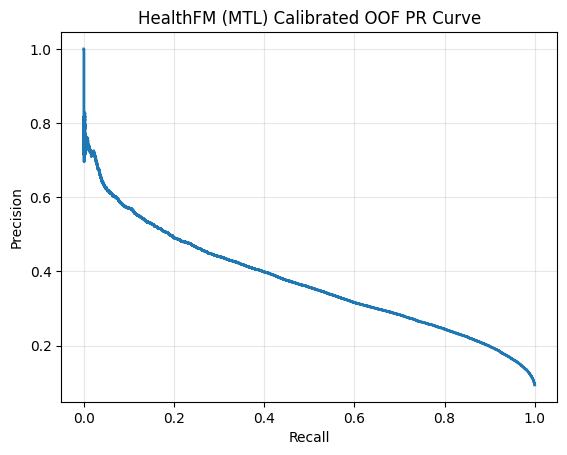

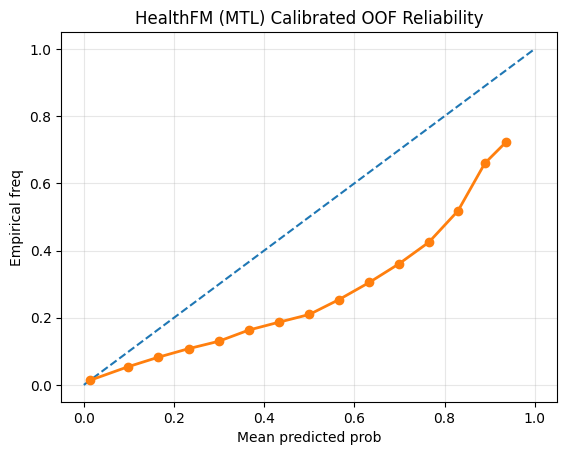

Temp per fold: [0.341, 0.414, 0.444, 0.397, 0.372] mean: 0.3935552716255188


In [6]:
# ============================================================
# Module 2D — HealthFM MTL-pretrain -> Heart finetune (HARDENED)
# IMPORTANT: After a CUDA device-side assert, restart kernel first.
# ============================================================

import os, gc, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# ---- set this to "cpu" for one dry-run fold if needed ----
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# ============================================================
# Fallback metrics/helpers (use your own if already defined)
# ============================================================
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss, precision_recall_curve, f1_score, precision_score, recall_score, accuracy_score

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def expected_calibration_error(y_true, p, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        m = (p >= lo) & (p < hi) if i < n_bins-1 else (p >= lo) & (p <= hi)
        if m.sum() == 0:
            continue
        acc = y_true[m].mean()
        conf = p[m].mean()
        ece += (m.sum() / len(p)) * abs(acc - conf)
    return float(ece)

def evaluate_probs(y_true, p, name="model"):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)
    eps = 1e-8
    p_clip = np.clip(p, eps, 1-eps)

    pr_auc = average_precision_score(y_true, p_clip)
    roc_auc = roc_auc_score(y_true, p_clip)
    brier = brier_score_loss(y_true, p_clip)
    nll = log_loss(y_true, p_clip)
    ece = expected_calibration_error(y_true, p_clip)

    precisions, recalls, thrs = precision_recall_curve(y_true, p_clip)
    f1s = (2*precisions*recalls) / (precisions+recalls+1e-12)
    best_i = int(np.nanargmax(f1s))
    thr_bestF1 = float(thrs[max(best_i-1, 0)]) if len(thrs) else 0.5

    y_hat = (p_clip >= thr_bestF1).astype(int)
    f1_best = float(f1_score(y_true, y_hat))
    prec_best = float(precision_score(y_true, y_hat, zero_division=0))
    rec_best = float(recall_score(y_true, y_hat))
    acc = float(accuracy_score(y_true, y_hat))

    # Precision>=0.30
    thr_p30, rec_p30, f1_p30 = 0.5, 0.0, 0.0
    for t in np.linspace(0,1,2001):
        yh = (p_clip >= t).astype(int)
        pr = precision_score(y_true, yh, zero_division=0)
        if pr >= 0.30:
            thr_p30 = float(t)
            rec_p30 = float(recall_score(y_true, yh))
            f1_p30 = float(f1_score(y_true, yh))
            break

    # Recall>=0.50
    thr_r50, pr_r50, f1_r50 = 0.5, 0.0, 0.0
    for t in np.linspace(0,1,2001)[::-1]:
        yh = (p_clip >= t).astype(int)
        rc = recall_score(y_true, yh)
        if rc >= 0.50:
            thr_r50 = float(t)
            pr_r50 = float(precision_score(y_true, yh, zero_division=0))
            f1_r50 = float(f1_score(y_true, yh))
            break

    return {
        "model": name,
        "PR_AUC": float(pr_auc),
        "ROC_AUC": float(roc_auc),
        "Brier": float(brier),
        "NLL": float(nll),
        "ECE": float(ece),
        "p_mean": float(p_clip.mean()),
        "pos_rate": float(y_true.mean()),
        "N": int(len(y_true)),
        "thr_bestF1": thr_bestF1,
        "Prec@bestF1": prec_best,
        "Rec@bestF1": rec_best,
        "F1@bestF1": f1_best,
        "thr_P>=0.30": float(thr_p30),
        "Rec@P>=0.30": float(rec_p30),
        "F1@P>=0.30": float(f1_p30),
        "thr_R>=0.50": float(thr_r50),
        "Prec@R>=0.50": float(pr_r50),
        "F1@R>=0.50": float(f1_r50),
    }

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

def plot_pr_curve(y_true, p, title, path):
    precisions, recalls, _ = precision_recall_curve(y_true, p)
    plt.figure()
    plt.plot(recalls, precisions, linewidth=2)
    plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()

def plot_reliability(y_true, p, title, path, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)
    bins = np.linspace(0,1,n_bins+1)
    xs, ys = [], []
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        m = (p>=lo)&(p<hi) if i < n_bins-1 else (p>=lo)&(p<=hi)
        if m.sum()==0:
            continue
        xs.append(p[m].mean()); ys.append(y_true[m].mean())
    plt.figure()
    plt.plot([0,1],[0,1], linestyle="--")
    plt.plot(xs, ys, marker="o", linewidth=2)
    plt.xlabel("Mean predicted prob"); plt.ylabel("Empirical freq")
    plt.title(title); plt.grid(True, alpha=0.3)
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()

SEED = 42
seed_everything(SEED)

OUT_DIR = "/kaggle/working/outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
TAB_DIR = os.path.join(OUT_DIR, "tables")
MOD_DIR = os.path.join(OUT_DIR, "models")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)
os.makedirs(MOD_DIR, exist_ok=True)

# ============================================================
# Setup columns (your confirmed list)
# ============================================================

TARGET = "HeartDiseaseorAttack"

MTL_BIN = [
    "HighBP", "HighChol", "Diabetes", "Stroke", "DiffWalk",
    "Smoker", "PhysActivity", "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost"
]
MTL_MC = ["GenHlth"]

FEATURES = [c for c in df.columns if c != TARGET]

CONT_COLS = ["BMI", "MentHlth", "PhysHlth"]
CAT_COLS  = ["Age", "Education", "Income", "GenHlth"]
BIN_COLS  = [c for c in FEATURES if c not in CONT_COLS + CAT_COLS]

X = df[FEATURES].copy()
y = df[TARGET].astype(int).values

print("BIN:", len(BIN_COLS))
print("CONT:", CONT_COLS)
print("CAT:", CAT_COLS)
print("pos_rate:", y.mean(), "N:", len(y))

# ============================================================
# HARDENED sanitizers + GLOBAL vocab (feature-only safe)
# ============================================================

def sanitize_bin_series(s):
    s = pd.to_numeric(s, errors="coerce").fillna(0).values
    s = np.round(s).astype(np.int64)
    return np.clip(s, 0, 1).astype(np.int64)

def sanitize_cat_series(s, vocab_size):
    s = pd.to_numeric(s, errors="coerce").fillna(0).values
    s = np.round(s).astype(np.int64)
    return np.clip(s, 0, vocab_size - 1).astype(np.int64)

def sanitize_cont_matrix(M):
    M = M.astype(np.float32)
    col_meds = np.nanmedian(M, axis=0)
    inds = np.where(np.isnan(M))
    if len(inds[0]) > 0:
        M[inds] = np.take(col_meds, inds[1])
    return M.astype(np.float32)

# Global vocab (ensure covers all folds)
CAT_VOCAB_GLOBAL = {}
for c in CAT_COLS:
    mx = int(pd.to_numeric(df[c], errors="coerce").fillna(0).round().astype(int).max())
    # IMPORTANT: GenHlth typically 1..5; allow at least 6 to be safe
    CAT_VOCAB_GLOBAL[c] = max(mx + 1, 6) if c == "GenHlth" else max(mx + 1, 2)
print("CAT_VOCAB_GLOBAL:", CAT_VOCAB_GLOBAL)

# CPU sanity check: ensure all cat values within range after sanitization (entire dataset)
for c in CAT_COLS:
    arr = sanitize_cat_series(df[c], CAT_VOCAB_GLOBAL[c])
    assert arr.min() >= 0 and arr.max() < CAT_VOCAB_GLOBAL[c], f"Cat {c} out of range after sanitize!"
for c in BIN_COLS:
    arr = sanitize_bin_series(df[c])
    assert arr.min() >= 0 and arr.max() <= 1, f"Bin {c} not in [0,1] after sanitize!"

print("CPU sanity check PASSED: all token indices safe.")

# ============================================================
# Dataset + collate (returns dicts)
# ============================================================

class HealthFMDataset(Dataset):
    def __init__(self, X_df, y_heart, scaler_cont=None, fit_scaler=False):
        self.X = X_df.reset_index(drop=True)

        yh = pd.to_numeric(pd.Series(y_heart), errors="coerce").fillna(0).astype(int).values
        self.y_heart = np.clip(yh, 0, 1).astype(np.float32)

        # Multi-task labels from feature columns
        self.y_bin = np.stack([sanitize_bin_series(self.X[c]) for c in MTL_BIN], axis=1).astype(np.float32)

        gen = pd.to_numeric(self.X["GenHlth"], errors="coerce").fillna(1).round().astype(int).values
        gen = np.clip(gen, 1, 5)
        self.y_gen = (gen - 1).astype(np.int64)  # 0..4

        # Inputs
        self.bin_arr = np.stack([sanitize_bin_series(self.X[c]) for c in BIN_COLS], axis=1).astype(np.int64)

        cont = sanitize_cont_matrix(self.X[CONT_COLS].values.astype(np.float32))
        self.scaler_cont = scaler_cont if scaler_cont is not None else StandardScaler()
        if fit_scaler:
            self.scaler_cont.fit(cont)
        self.cont_arr = self.scaler_cont.transform(cont).astype(np.float32)

        self.cat_arr = np.stack([sanitize_cat_series(self.X[c], CAT_VOCAB_GLOBAL[c]) for c in CAT_COLS], axis=1).astype(np.int64)

    def __len__(self): return len(self.X)

    def __getitem__(self, idx):
        xb_bin  = {c: torch.tensor(self.bin_arr[idx, j], dtype=torch.long) for j, c in enumerate(BIN_COLS)}
        xb_cont = {c: torch.tensor(self.cont_arr[idx, j], dtype=torch.float32) for j, c in enumerate(CONT_COLS)}
        xb_cat  = {c: torch.tensor(self.cat_arr[idx, j], dtype=torch.long) for j, c in enumerate(CAT_COLS)}
        y_bin = torch.tensor(self.y_bin[idx], dtype=torch.float32)
        y_gen = torch.tensor(self.y_gen[idx], dtype=torch.long)
        y_h   = torch.tensor(self.y_heart[idx], dtype=torch.float32)
        return xb_bin, xb_cont, xb_cat, y_bin, y_gen, y_h

def collate_healthfm(batch):
    xb_bin_list, xb_cont_list, xb_cat_list, y_bin_list, y_gen_list, y_h_list = zip(*batch)
    xb_bin  = {c: torch.stack([d[c] for d in xb_bin_list], dim=0) for c in BIN_COLS}
    xb_cont = {c: torch.stack([d[c] for d in xb_cont_list], dim=0) for c in CONT_COLS}
    xb_cat  = {c: torch.stack([d[c] for d in xb_cat_list], dim=0) for c in CAT_COLS}
    y_bin = torch.stack(list(y_bin_list), dim=0)
    y_gen = torch.stack(list(y_gen_list), dim=0)
    y_h   = torch.stack(list(y_h_list), dim=0)
    return xb_bin, xb_cont, xb_cat, y_bin, y_gen, y_h

# ============================================================
# Tokenizer + Encoder + MTL model
# ============================================================

class FeatureTokenizer(nn.Module):
    def __init__(self, bin_cols, cont_cols, cat_cols, cat_vocab_sizes, emb_dim=64):
        super().__init__()
        self.bin_cols = bin_cols
        self.cont_cols = cont_cols
        self.cat_cols = cat_cols

        self.bin_emb = nn.ModuleDict({c: nn.Embedding(2, emb_dim) for c in bin_cols})
        self.cat_emb = nn.ModuleDict({c: nn.Embedding(cat_vocab_sizes[c], emb_dim) for c in cat_cols})
        self.cont_proj = nn.ModuleDict({c: nn.Linear(1, emb_dim) for c in cont_cols})
        self.feat_bias = nn.Parameter(torch.zeros(1, 1, emb_dim))

    def forward(self, xb_bin, xb_cont, xb_cat):
        toks = []
        for c in self.bin_cols:
            toks.append(self.bin_emb[c](xb_bin[c]))
        for c in self.cont_cols:
            toks.append(self.cont_proj[c](xb_cont[c].unsqueeze(-1)))
        for c in self.cat_cols:
            toks.append(self.cat_emb[c](xb_cat[c]))
        x_tok = torch.stack(toks, dim=1) + self.feat_bias
        return x_tok

    @property
    def n_tokens(self):
        return len(self.bin_cols) + len(self.cont_cols) + len(self.cat_cols)

class HealthFMEncoder(nn.Module):
    def __init__(self, emb_dim=64, n_layers=4, n_heads=4, dropout=0.1):
        super().__init__()
        enc_layer = nn.TransformerEncoderLayer(
            d_model=emb_dim, nhead=n_heads, dim_feedforward=emb_dim*4,
            dropout=dropout, activation="gelu", batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.cls = nn.Parameter(torch.zeros(1, 1, emb_dim))
        nn.init.normal_(self.cls, std=0.02)

    def forward(self, x_tok):
        B = x_tok.size(0)
        cls = self.cls.expand(B, -1, -1)
        z = torch.cat([cls, x_tok], dim=1)
        h = self.encoder(z)
        return h[:, 0]

class HealthFM_MTL(nn.Module):
    def __init__(self, tokenizer, encoder, n_bin_tasks, emb_dim=64, dropout=0.1):
        super().__init__()
        self.tokenizer = tokenizer
        self.encoder = encoder
        self.drop = nn.Dropout(dropout)
        self.head_bin = nn.Linear(emb_dim, n_bin_tasks)
        self.head_gen = nn.Linear(emb_dim, 5)
        self.head_heart = nn.Linear(emb_dim, 1)

    def forward(self, xb_bin, xb_cont, xb_cat):
        x_tok = self.tokenizer(xb_bin, xb_cont, xb_cat)
        z = self.encoder(x_tok)
        z = self.drop(z)
        return {
            "bin_logits": self.head_bin(z),
            "gen_logits": self.head_gen(z),
            "heart_logit": self.head_heart(z).squeeze(-1)
        }

def asym_focal_loss_probs(p, y, alpha=0.85, gamma_pos=2.0, gamma_neg=0.5):
    p = p.clamp(1e-8, 1-1e-8)
    y = y.float()
    pos = -alpha * y * ((1 - p) ** gamma_pos) * torch.log(p)
    neg = -(1 - alpha) * (1 - y) * (p ** gamma_neg) * torch.log(1 - p)
    return (pos + neg).mean()

# ============================================================
# Training/eval
# ============================================================

@torch.no_grad()
def eval_heart(model, loader):
    model.eval()
    ps, ys, logits = [], [], []
    for xb_bin, xb_cont, xb_cat, y_bin, y_gen, y_h in loader:
        xb_bin  = {k:v.to(DEVICE) for k,v in xb_bin.items()}
        xb_cont = {k:v.to(DEVICE) for k,v in xb_cont.items()}
        xb_cat  = {k:v.to(DEVICE) for k,v in xb_cat.items()}
        out = model(xb_bin, xb_cont, xb_cat)
        logit = out["heart_logit"].detach().cpu().numpy()
        p = 1.0 / (1.0 + np.exp(-logit))
        ps.append(p); ys.append(y_h.numpy()); logits.append(logit)
    return np.concatenate(ps), np.concatenate(ys), np.concatenate(logits)

def pretrain_mtl(model, train_loader, val_loader, epochs=6, lr=1e-3, wd=1e-4, w_bin=1.0, w_gen=0.5):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    best_val = 1e18
    best_state = None

    for ep in range(1, epochs+1):
        model.train()
        tr = []
        for xb_bin, xb_cont, xb_cat, y_bin, y_gen, y_h in train_loader:
            xb_bin  = {k:v.to(DEVICE) for k,v in xb_bin.items()}
            xb_cont = {k:v.to(DEVICE) for k,v in xb_cont.items()}
            xb_cat  = {k:v.to(DEVICE) for k,v in xb_cat.items()}
            y_bin = y_bin.to(DEVICE)
            y_gen = y_gen.to(DEVICE)

            out = model(xb_bin, xb_cont, xb_cat)
            loss_bin = F.binary_cross_entropy_with_logits(out["bin_logits"], y_bin)
            loss_gen = F.cross_entropy(out["gen_logits"], y_gen)
            loss = w_bin*loss_bin + w_gen*loss_gen

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tr.append(loss.item())

        # val loss
        model.eval()
        vv = []
        with torch.no_grad():
            for xb_bin, xb_cont, xb_cat, y_bin, y_gen, y_h in val_loader:
                xb_bin  = {k:v.to(DEVICE) for k,v in xb_bin.items()}
                xb_cont = {k:v.to(DEVICE) for k,v in xb_cont.items()}
                xb_cat  = {k:v.to(DEVICE) for k,v in xb_cat.items()}
                y_bin = y_bin.to(DEVICE)
                y_gen = y_gen.to(DEVICE)
                out = model(xb_bin, xb_cont, xb_cat)
                loss_bin = F.binary_cross_entropy_with_logits(out["bin_logits"], y_bin)
                loss_gen = F.cross_entropy(out["gen_logits"], y_gen)
                vv.append((w_bin*loss_bin + w_gen*loss_gen).item())
        v = float(np.mean(vv))
        if v < best_val:
            best_val = v
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

        if ep == 1 or ep % max(1, epochs//3) == 0:
            print(f"Pretrain ep {ep}/{epochs} | train={np.mean(tr):.4f} | val={v:.4f}")

    model.load_state_dict(best_state)
    return model

def finetune_heart(model, train_loader, val_loader, epochs=6, lr=7e-4, wd=1e-4):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    best_ap = -1.0
    best_state = None

    for ep in range(1, epochs+1):
        model.train()
        tr = []
        for xb_bin, xb_cont, xb_cat, y_bin, y_gen, y_h in train_loader:
            xb_bin  = {k:v.to(DEVICE) for k,v in xb_bin.items()}
            xb_cont = {k:v.to(DEVICE) for k,v in xb_cont.items()}
            xb_cat  = {k:v.to(DEVICE) for k,v in xb_cat.items()}
            y_h = y_h.to(DEVICE)

            out = model(xb_bin, xb_cont, xb_cat)
            p = torch.sigmoid(out["heart_logit"])
            loss = asym_focal_loss_probs(p, y_h, alpha=0.85, gamma_pos=2.0, gamma_neg=0.5)

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tr.append(loss.item())

        p_val, y_val, logit_val = eval_heart(model, val_loader)
        ap = float(average_precision_score(y_val.astype(int), p_val))
        if ap > best_ap:
            best_ap = ap
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

        if ep == 1 or ep % max(1, epochs//3) == 0:
            print(f"Finetune ep {ep}/{epochs} | train={np.mean(tr):.4f} | val_AP={ap:.4f}")

    model.load_state_dict(best_state)
    return model

# ============================================================
# Temperature scaling on logits (fold calib)
# ============================================================

def fit_temperature_on_logits(logits, y_cal, max_iter=1200, lr=0.05):
    logits = logits.astype(np.float32)
    y_cal = y_cal.astype(np.float32)

    lt = torch.tensor(logits, dtype=torch.float32, device=DEVICE)
    yt = torch.tensor(y_cal, dtype=torch.float32, device=DEVICE)

    logT = torch.zeros((), device=DEVICE, requires_grad=True)
    opt = torch.optim.Adam([logT], lr=lr)

    for _ in range(max_iter):
        opt.zero_grad()
        T = torch.exp(logT).clamp(1e-3, 100.0)
        p = torch.sigmoid(lt / T)
        loss = F.binary_cross_entropy(p, yt)
        loss.backward()
        opt.step()

    T = float(torch.exp(logT).detach().cpu().item())
    p_cal = 1.0 / (1.0 + np.exp(-logits / max(T, 1e-6)))
    return p_cal, T

# ============================================================
# Outer CV run
# ============================================================

seed_everything(SEED)

N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_unc = np.zeros(len(X), dtype=float)
oof_cal = np.zeros(len(X), dtype=float)

fold_rows_unc, fold_rows_cal = [], []
temps = []

for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
    print(f"\n================ Fold {fold} ================\n")

    X_tr, y_tr = X.iloc[tr_idx].copy(), y[tr_idx].copy()
    X_te, y_te = X.iloc[te_idx].copy(), y[te_idx].copy()

    # train_main / calib split
    idx = np.arange(len(X_tr))
    tr_main_idx, cal_idx = train_test_split(idx, test_size=0.2, stratify=y_tr, random_state=SEED + fold)
    X_main, y_main = X_tr.iloc[tr_main_idx].copy(), y_tr[tr_main_idx].copy()
    X_cal,  y_cal  = X_tr.iloc[cal_idx].copy(),    y_tr[cal_idx].copy()

    # datasets
    scaler_cont = StandardScaler()
    ds_main = HealthFMDataset(X_main, y_main, scaler_cont=scaler_cont, fit_scaler=True)
    ds_cal  = HealthFMDataset(X_cal,  y_cal,  scaler_cont=ds_main.scaler_cont, fit_scaler=False)
    ds_te   = HealthFMDataset(X_te,   y_te,   scaler_cont=ds_main.scaler_cont, fit_scaler=False)

    train_loader = DataLoader(ds_main, batch_size=1024, shuffle=True,  num_workers=0, collate_fn=collate_healthfm)
    cal_loader   = DataLoader(ds_cal,  batch_size=2048, shuffle=False, num_workers=0, collate_fn=collate_healthfm)
    test_loader  = DataLoader(ds_te,   batch_size=2048, shuffle=False, num_workers=0, collate_fn=collate_healthfm)

    # model
    EMB_DIM = 64
    tokenizer = FeatureTokenizer(BIN_COLS, CONT_COLS, CAT_COLS, CAT_VOCAB_GLOBAL, emb_dim=EMB_DIM)
    encoder = HealthFMEncoder(emb_dim=EMB_DIM, n_layers=4, n_heads=4, dropout=0.1)
    model = HealthFM_MTL(tokenizer, encoder, n_bin_tasks=len(MTL_BIN), emb_dim=EMB_DIM, dropout=0.1)

    # pretrain + finetune
    model = pretrain_mtl(model, train_loader, cal_loader, epochs=6, lr=1e-3, wd=1e-4, w_bin=1.0, w_gen=0.5)
    model = finetune_heart(model, train_loader, cal_loader, epochs=6, lr=7e-4, wd=1e-4)

    # calibrate
    p_cal_unc, y_cal_np, logit_cal = eval_heart(model, cal_loader)
    _, T = fit_temperature_on_logits(logit_cal, y_cal_np, max_iter=1200, lr=0.05)
    temps.append(T)

    # test
    p_te_unc, y_te_np, logit_te = eval_heart(model, test_loader)
    p_te_cal = 1.0 / (1.0 + np.exp(-logit_te / max(T, 1e-6)))

    oof_unc[te_idx] = p_te_unc
    oof_cal[te_idx] = p_te_cal

    m_unc = evaluate_probs(y_te_np.astype(int), p_te_unc, name=f"HealthFM_unc_fold{fold}")
    m_cal = evaluate_probs(y_te_np.astype(int), p_te_cal, name=f"HealthFM_cal_fold{fold}")
    m_unc["fold"] = fold
    m_cal["fold"] = fold
    m_cal["TempT"] = float(T)

    fold_rows_unc.append(m_unc)
    fold_rows_cal.append(m_cal)

    torch.save({"state_dict": model.state_dict(), "TempT": float(T)}, os.path.join(MOD_DIR, f"healthfm_fold{fold}.pt"))

    print(f"Fold {fold} DONE | PR_AUC(cal)={m_cal['PR_AUC']:.4f} | ECE={m_cal['ECE']:.4f} | T={T:.3f}")
    gc.collect()

df_cal = pd.DataFrame(fold_rows_cal)
display(df_cal)
df_cal.to_csv(os.path.join(TAB_DIR, "module2D_healthfm_cal_folds.csv"), index=False)

oof_unc_m = evaluate_probs(y, oof_unc, name="HealthFM_unc_OOF")
oof_cal_m = evaluate_probs(y, oof_cal, name="HealthFM_cal_OOF")
print("OOF uncal:", oof_unc_m)
print("OOF cal  :", oof_cal_m)

pd.DataFrame([oof_cal_m]).to_csv(os.path.join(TAB_DIR, "module2D_healthfm_cal_oof.csv"), index=False)
plot_pr_curve(y, oof_cal, "HealthFM (MTL) Calibrated OOF PR Curve", os.path.join(FIG_DIR, "module2D_healthfm_cal_pr.png"))
plot_reliability(y, oof_cal, "HealthFM (MTL) Calibrated OOF Reliability", os.path.join(FIG_DIR, "module2D_healthfm_cal_reliability.png"))

print("Temp per fold:", [round(t,3) for t in temps], "mean:", float(np.mean(temps)))

hfm_oof = evaluate_probs(y, oof_cal, name="HealthFM_cal_OOF")
hfm_oof

DEVICE: cuda
BIN: 14
CONT: ['BMI', 'MentHlth', 'PhysHlth']
CAT: ['Age', 'Education', 'Income', 'GenHlth']
pos_rate: 0.09418558814254178 N: 253680
CAT_VOCAB_GLOBAL: {'Age': 14, 'Education': 7, 'Income': 9, 'GenHlth': 6}
CPU token-index sanity PASSED.

================ Fold 1 ================

MFM ep 01/8 | train=2.1351 | val=2.0217
MFM ep 02/8 | train=2.0195 | val=1.9937
MFM ep 04/8 | train=1.9938 | val=1.9784
MFM ep 06/8 | train=1.9835 | val=1.9693
MFM ep 08/8 | train=1.9789 | val=1.9719
MTL ep 01/8 | train=0.3663 | val=0.1003
MTL ep 02/8 | train=0.0674 | val=0.0247
MTL ep 04/8 | train=0.0139 | val=0.0057
MTL ep 06/8 | train=0.0061 | val=0.0023
MTL ep 08/8 | train=0.0035 | val=0.0012
Heart ep 01/10 | train=0.0633 | val_AP=0.3074
Heart ep 03/10 | train=0.0521 | val_AP=0.3736
Heart ep 06/10 | train=0.0492 | val_AP=0.3775
Heart ep 09/10 | train=0.0486 | val_AP=0.3801
Fold 1 DONE | PR_AUC=0.3715 | ECE=0.1040 | T=0.391

================ Fold 2 ================

MFM ep 01/8 | train=2.1207 | 

,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,p_mean,pos_rate,N,thr_bestF1,...,Rec@bestF1,F1@bestF1,thr_P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,F1@R>=0.50,fold,TempT
0,HealthFM_MFM+MTL_cal_fold1,0.371549,0.851174,0.098069,0.302877,0.104024,0.198193,0.094174,50736,0.529136,...,0.539347,0.418786,0.4180,0.662202,0.413217,0.5605,0.356344,0.416195,1,0.390611
1,HealthFM_MFM+MTL_cal_fold2,0.377186,0.850309,0.092308,0.290103,0.092008,0.186062,0.094174,50736,0.428576,...,0.620762,0.422597,0.3830,0.667015,0.414004,0.5215,0.357047,0.416601,2,0.360088
2,HealthFM_MFM+MTL_cal_fold3,0.385610,0.851902,0.099586,0.306667,0.108657,0.202851,0.094193,50736,0.546263,...,0.557439,0.432643,0.4335,0.666876,0.413842,0.5875,0.374784,0.428469,3,0.397469
3,HealthFM_MFM+MTL_cal_fold4,0.368930,0.843933,0.096880,0.303047,0.099417,0.193610,0.094193,50736,0.531192,...,0.510986,0.416901,0.4175,0.630257,0.406505,0.5375,0.354124,0.415071,4,0.422904
4,HealthFM_MFM+MTL_cal_fold5,0.369063,0.847465,0.099267,0.308150,0.107416,0.201609,0.094193,50736,0.480090,...,0.590709,0.417326,0.4275,0.651182,0.410961,0.5545,0.350792,0.412419,5,0.464796


{'model': 'HealthFM_MFM+MTL_cal_OOF', 'PR_AUC': 0.37272171710628577, 'ROC_AUC': 0.8487592583522625, 'Brier': 0.09722207173467307, 'NLL': 0.30216878712027995, 'ECE': 0.10227936733778634, 'p_mean': 0.19646495548032814, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.5291364192962646, 'Prec@bestF1': 0.3467695591494951, 'Rec@bestF1': 0.5303645419160423, 'F1@bestF1': 0.4193527036865444, 'thr_P>=0.30': 0.41550000000000004, 'Rec@P>=0.30': 0.655924329301469, 'F1@P>=0.30': 0.41172761664564944, 'thr_R>=0.50': 0.552, 'Prec@R>=0.50': 0.3581235011990408, 'F1@R>=0.50': 0.4173405760396835}


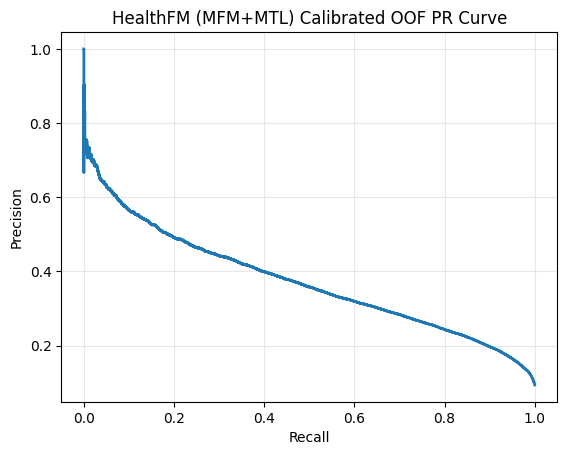

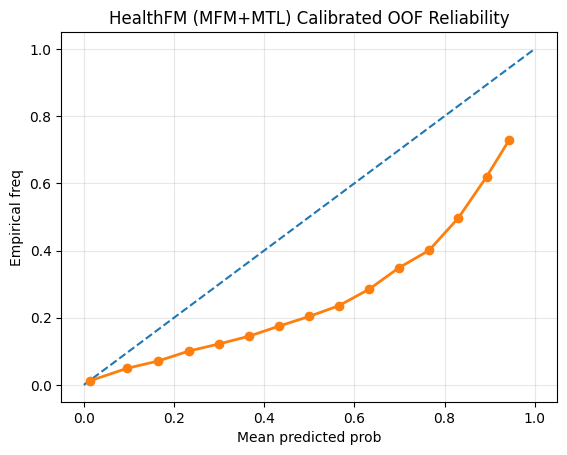

Temp per fold: [0.391, 0.36, 0.397, 0.423, 0.465] mean: 0.40717352628707887


In [17]:
# ============================================================
# Module 2E — HealthFM Full Masked Feature Modeling (MFM) pretrain
# then MTL pretrain -> Heart finetune -> Temp scaling (OOF)
#
# FULL MFM = reconstruct:
#  - BIN features (BCE over logits)
#  - CAT features (CrossEntropy over vocab)
#  - CONT features (SmoothL1 / MSE)
#
# HARDENED:
#  - GLOBAL vocab sizes
#  - sanitization + clipping
#  - CPU sanity checks for indices
#
# NOTE: After any CUDA "device-side assert", RESTART KERNEL first.
# ============================================================

import os, gc, random, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import average_precision_score
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

# ============================================================
# Utilities + fallback metrics
# ============================================================
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss, precision_recall_curve, f1_score, precision_score, recall_score, accuracy_score

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def expected_calibration_error(y_true, p, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        m = (p >= lo) & (p < hi) if i < n_bins-1 else (p >= lo) & (p <= hi)
        if m.sum() == 0:
            continue
        acc = y_true[m].mean()
        conf = p[m].mean()
        ece += (m.sum() / len(p)) * abs(acc - conf)
    return float(ece)

def evaluate_probs(y_true, p, name="model"):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)
    eps = 1e-8
    p_clip = np.clip(p, eps, 1-eps)

    pr_auc = average_precision_score(y_true, p_clip)
    roc_auc = roc_auc_score(y_true, p_clip)
    brier = brier_score_loss(y_true, p_clip)
    nll = log_loss(y_true, p_clip)
    ece = expected_calibration_error(y_true, p_clip)

    precisions, recalls, thrs = precision_recall_curve(y_true, p_clip)
    f1s = (2*precisions*recalls) / (precisions+recalls+1e-12)
    best_i = int(np.nanargmax(f1s))
    thr_bestF1 = float(thrs[max(best_i-1, 0)]) if len(thrs) else 0.5

    y_hat = (p_clip >= thr_bestF1).astype(int)
    f1_best = float(f1_score(y_true, y_hat))
    prec_best = float(precision_score(y_true, y_hat, zero_division=0))
    rec_best = float(recall_score(y_true, y_hat))
    acc = float(accuracy_score(y_true, y_hat))

    # Precision>=0.30
    thr_p30, rec_p30, f1_p30 = 0.5, 0.0, 0.0
    for t in np.linspace(0,1,2001):
        yh = (p_clip >= t).astype(int)
        pr = precision_score(y_true, yh, zero_division=0)
        if pr >= 0.30:
            thr_p30 = float(t)
            rec_p30 = float(recall_score(y_true, yh))
            f1_p30 = float(f1_score(y_true, yh))
            break

    # Recall>=0.50
    thr_r50, pr_r50, f1_r50 = 0.5, 0.0, 0.0
    for t in np.linspace(0,1,2001)[::-1]:
        yh = (p_clip >= t).astype(int)
        rc = recall_score(y_true, yh)
        if rc >= 0.50:
            thr_r50 = float(t)
            pr_r50 = float(precision_score(y_true, yh, zero_division=0))
            f1_r50 = float(f1_score(y_true, yh))
            break

    return {
        "model": name,
        "PR_AUC": float(pr_auc),
        "ROC_AUC": float(roc_auc),
        "Brier": float(brier),
        "NLL": float(nll),
        "ECE": float(ece),
        "p_mean": float(p_clip.mean()),
        "pos_rate": float(y_true.mean()),
        "N": int(len(y_true)),
        "thr_bestF1": thr_bestF1,
        "Prec@bestF1": prec_best,
        "Rec@bestF1": rec_best,
        "F1@bestF1": f1_best,
        "thr_P>=0.30": float(thr_p30),
        "Rec@P>=0.30": float(rec_p30),
        "F1@P>=0.30": float(f1_p30),
        "thr_R>=0.50": float(thr_r50),
        "Prec@R>=0.50": float(pr_r50),
        "F1@R>=0.50": float(f1_r50),
    }

import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

def plot_pr_curve(y_true, p, title, path):
    precisions, recalls, _ = precision_recall_curve(y_true, p)
    plt.figure()
    plt.plot(recalls, precisions, linewidth=2)
    plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()

def plot_reliability(y_true, p, title, path, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)
    bins = np.linspace(0,1,n_bins+1)
    xs, ys = [], []
    for i in range(n_bins):
        lo, hi = bins[i], bins[i+1]
        m = (p>=lo)&(p<hi) if i < n_bins-1 else (p>=lo)&(p<=hi)
        if m.sum()==0:
            continue
        xs.append(p[m].mean()); ys.append(y_true[m].mean())
    plt.figure()
    plt.plot([0,1],[0,1], linestyle="--")
    plt.plot(xs, ys, marker="o", linewidth=2)
    plt.xlabel("Mean predicted prob"); plt.ylabel("Empirical freq")
    plt.title(title); plt.grid(True, alpha=0.3)
    plt.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()

SEED = 42
seed_everything(SEED)

OUT_DIR = "/kaggle/working/outputs"
FIG_DIR = os.path.join(OUT_DIR, "figures")
TAB_DIR = os.path.join(OUT_DIR, "tables")
MOD_DIR = os.path.join(OUT_DIR, "models")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)
os.makedirs(MOD_DIR, exist_ok=True)

# ============================================================
# Column setup (you confirmed these exist)
# ============================================================

TARGET = "HeartDiseaseorAttack"

MTL_BIN = [
    "HighBP", "HighChol", "Diabetes", "Stroke", "DiffWalk",
    "Smoker", "PhysActivity", "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost"
]
FEATURES = [c for c in df.columns if c != TARGET]

CONT_COLS = ["BMI", "MentHlth", "PhysHlth"]
CAT_COLS  = ["Age", "Education", "Income", "GenHlth"]
BIN_COLS  = [c for c in FEATURES if c not in CONT_COLS + CAT_COLS]

X = df[FEATURES].copy()
y = df[TARGET].astype(int).values

print("BIN:", len(BIN_COLS))
print("CONT:", CONT_COLS)
print("CAT:", CAT_COLS)
print("pos_rate:", y.mean(), "N:", len(y))

# ============================================================
# Sanitizers + GLOBAL vocab + CPU sanity check
# ============================================================

def sanitize_bin_series(s):
    s = pd.to_numeric(s, errors="coerce").fillna(0).values
    s = np.round(s).astype(np.int64)
    return np.clip(s, 0, 1).astype(np.int64)

def sanitize_cat_series(s, vocab_size):
    s = pd.to_numeric(s, errors="coerce").fillna(0).values
    s = np.round(s).astype(np.int64)
    return np.clip(s, 0, vocab_size - 1).astype(np.int64)

def sanitize_cont_matrix(M):
    M = M.astype(np.float32)
    col_meds = np.nanmedian(M, axis=0)
    inds = np.where(np.isnan(M))
    if len(inds[0]) > 0:
        M[inds] = np.take(col_meds, inds[1])
    return M.astype(np.float32)

CAT_VOCAB_GLOBAL = {}
for c in CAT_COLS:
    mx = int(pd.to_numeric(df[c], errors="coerce").fillna(0).round().astype(int).max())
    # ensure >= 6 for GenHlth
    CAT_VOCAB_GLOBAL[c] = max(mx + 1, 6) if c == "GenHlth" else max(mx + 1, 2)
print("CAT_VOCAB_GLOBAL:", CAT_VOCAB_GLOBAL)

# CPU safety check
for c in CAT_COLS:
    arr = sanitize_cat_series(df[c], CAT_VOCAB_GLOBAL[c])
    assert arr.min() >= 0 and arr.max() < CAT_VOCAB_GLOBAL[c], f"Cat {c} out of range"
for c in BIN_COLS:
    arr = sanitize_bin_series(df[c])
    assert arr.min() >= 0 and arr.max() <= 1, f"Bin {c} not in [0,1]"
print("CPU token-index sanity PASSED.")

# ============================================================
# Dataset that provides BOTH:
# - clean token inputs (bin/cont/cat)
# - MTL labels (for Stage 1)
# - Heart label (for Stage 2)
# Plus: MFM mask generation (for Stage 0)
# ============================================================

class HealthFMDataset(Dataset):
    def __init__(self, X_df, y_heart, scaler_cont=None, fit_scaler=False):
        self.X = X_df.reset_index(drop=True)

        yh = pd.to_numeric(pd.Series(y_heart), errors="coerce").fillna(0).astype(int).values
        self.y_heart = np.clip(yh, 0, 1).astype(np.float32)

        # MTL binary labels from feature cols
        self.y_mtl_bin = np.stack([sanitize_bin_series(self.X[c]) for c in MTL_BIN], axis=1).astype(np.float32)

        # GenHlth class (0..4)
        gen = pd.to_numeric(self.X["GenHlth"], errors="coerce").fillna(1).round().astype(int).values
        gen = np.clip(gen, 1, 5)
        self.y_gen = (gen - 1).astype(np.int64)

        # Inputs
        self.bin_arr = np.stack([sanitize_bin_series(self.X[c]) for c in BIN_COLS], axis=1).astype(np.int64)

        cont = sanitize_cont_matrix(self.X[CONT_COLS].values.astype(np.float32))
        self.scaler_cont = scaler_cont if scaler_cont is not None else StandardScaler()
        if fit_scaler:
            self.scaler_cont.fit(cont)
        self.cont_arr = self.scaler_cont.transform(cont).astype(np.float32)

        self.cat_arr = np.stack([sanitize_cat_series(self.X[c], CAT_VOCAB_GLOBAL[c]) for c in CAT_COLS], axis=1).astype(np.int64)

    def __len__(self): return len(self.X)

    def __getitem__(self, idx):
        xb_bin  = torch.tensor(self.bin_arr[idx], dtype=torch.long)    # [n_bin_feats]
        xb_cont = torch.tensor(self.cont_arr[idx], dtype=torch.float32) # [n_cont_feats]
        xb_cat  = torch.tensor(self.cat_arr[idx], dtype=torch.long)     # [n_cat_feats]

        y_mtl_bin = torch.tensor(self.y_mtl_bin[idx], dtype=torch.float32)
        y_gen     = torch.tensor(self.y_gen[idx], dtype=torch.long)
        y_heart   = torch.tensor(self.y_heart[idx], dtype=torch.float32)

        return xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart

def collate_healthfm(batch):
    xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart = zip(*batch)
    return (torch.stack(xb_bin, 0),
            torch.stack(xb_cont, 0),
            torch.stack(xb_cat, 0),
            torch.stack(y_mtl_bin, 0),
            torch.stack(y_gen, 0),
            torch.stack(y_heart, 0))

# ============================================================
# Tokenizer (vectorized) + Transformer encoder
# ============================================================

class FeatureTokenizerVec(nn.Module):
    """
    Vectorized tokenizer:
    - BIN: one embedding table per feature (2, D) -> using ModuleList
    - CAT: one embedding table per feature (V_i, D)
    - CONT: one Linear per feature (1->D)
    """
    def __init__(self, n_bin, n_cont, cat_vocab_sizes, emb_dim=64):
        super().__init__()
        self.n_bin = n_bin
        self.n_cont = n_cont
        self.cat_cols = list(cat_vocab_sizes.keys())
        self.emb_dim = emb_dim

        self.bin_embs = nn.ModuleList([nn.Embedding(2, emb_dim) for _ in range(n_bin)])
        self.cont_projs = nn.ModuleList([nn.Linear(1, emb_dim) for _ in range(n_cont)])
        self.cat_embs = nn.ModuleList([nn.Embedding(cat_vocab_sizes[c], emb_dim) for c in self.cat_cols])

        self.feat_bias = nn.Parameter(torch.zeros(1, 1, emb_dim))

    @property
    def n_tokens(self):
        return self.n_bin + self.n_cont + len(self.cat_cols)

    def forward(self, xb_bin, xb_cont, xb_cat):
        # xb_bin: [B, n_bin] longs, xb_cont: [B, n_cont] floats, xb_cat: [B, n_cat] longs
        toks = []

        for j in range(self.n_bin):
            toks.append(self.bin_embs[j](xb_bin[:, j]))
        for j in range(self.n_cont):
            toks.append(self.cont_projs[j](xb_cont[:, j:j+1]))
        for j in range(len(self.cat_cols)):
            toks.append(self.cat_embs[j](xb_cat[:, j]))

        x_tok = torch.stack(toks, dim=1) + self.feat_bias  # [B, T, D]
        return x_tok

class HealthFMEncoder(nn.Module):
    def __init__(self, emb_dim=64, n_layers=4, n_heads=4, dropout=0.1):
        super().__init__()
        enc_layer = nn.TransformerEncoderLayer(
            d_model=emb_dim, nhead=n_heads, dim_feedforward=emb_dim*4,
            dropout=dropout, activation="gelu", batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.cls = nn.Parameter(torch.zeros(1, 1, emb_dim))
        nn.init.normal_(self.cls, std=0.02)

    def forward(self, x_tok):
        B = x_tok.size(0)
        cls = self.cls.expand(B, -1, -1)
        z = torch.cat([cls, x_tok], dim=1)
        h = self.encoder(z)
        # return CLS and token states (for reconstruction)
        return h[:, 0], h[:, 1:]  # [B,D], [B,T,D]

# ============================================================
# Full model with:
# - Reconstruction heads (MFM)
# - MTL heads
# - Heart head
# ============================================================

class HealthFM_Full(nn.Module):
    def __init__(self, tokenizer, encoder, emb_dim=64, n_mtl_bin=10, dropout=0.1):
        super().__init__()
        self.tokenizer = tokenizer
        self.encoder = encoder
        self.drop = nn.Dropout(dropout)

        # Heads on CLS
        self.head_mtl_bin = nn.Linear(emb_dim, n_mtl_bin)
        self.head_gen = nn.Linear(emb_dim, 5)
        self.head_heart = nn.Linear(emb_dim, 1)

        # Reconstruction heads per token type on token states
        # Token order: BIN tokens, CONT tokens, CAT tokens (same as tokenizer forward)
        self.rec_bin = nn.ModuleList([nn.Linear(emb_dim, 1) for _ in range(tokenizer.n_bin)])   # logits
        self.rec_cont = nn.ModuleList([nn.Linear(emb_dim, 1) for _ in range(tokenizer.n_cont)]) # regression
        self.rec_cat = nn.ModuleList([
            nn.Linear(emb_dim, encoder.cls.shape[-1] if False else 1)  # placeholder overwritten below
        ])

        # create cat reconstruction heads with correct vocab
        self.rec_cat = nn.ModuleList([
            nn.Linear(emb_dim, tokenizer.cat_embs[j].num_embeddings) for j in range(len(tokenizer.cat_cols))
        ])

    def forward(self, xb_bin, xb_cont, xb_cat):
        x_tok = self.tokenizer(xb_bin, xb_cont, xb_cat)          # [B,T,D]
        cls, tok = self.encoder(x_tok)                           # [B,D], [B,T,D]
        cls = self.drop(cls)

        out = {
            "cls": cls,
            "tok": tok,
            "mtl_bin_logits": self.head_mtl_bin(cls),
            "gen_logits": self.head_gen(cls),
            "heart_logit": self.head_heart(cls).squeeze(-1),
        }
        return out

def asym_focal_loss_probs(p, y, alpha=0.85, gamma_pos=2.0, gamma_neg=0.5):
    p = p.clamp(1e-8, 1-1e-8)
    y = y.float()
    pos = -alpha * y * ((1 - p) ** gamma_pos) * torch.log(p)
    neg = -(1 - alpha) * (1 - y) * (p ** gamma_neg) * torch.log(1 - p)
    return (pos + neg).mean()

# ============================================================
# MFM masking utilities
# ============================================================

def make_mask(B, T, mask_ratio=0.15, device=None):
    """
    Returns boolean mask [B,T] where True = masked position.
    Ensure at least 1 masked token per row.
    """
    m = torch.rand(B, T, device=device) < mask_ratio
    # guarantee at least 1 masked per row
    rows = torch.where(m.sum(dim=1) == 0)[0]
    if len(rows) > 0:
        j = torch.randint(0, T, (len(rows),), device=device)
        m[rows, j] = True
    return m

def corrupt_inputs(xb_bin, xb_cont, xb_cat, mask_bin, mask_cont, mask_cat,
                   cat_vocab_sizes_list, cont_noise_std=0.05):
    """
    Create corrupted inputs:
    - for masked BIN: random 0/1
    - for masked CAT: random category
    - for masked CONT: add noise (or set to 0)
    """
    xb_bin_c = xb_bin.clone()
    xb_cont_c = xb_cont.clone()
    xb_cat_c = xb_cat.clone()

    # masked bin -> random {0,1}
    if mask_bin.any():
        xb_bin_c[mask_bin] = torch.randint(0, 2, (int(mask_bin.sum().item()),), device=xb_bin.device)

    # masked cat -> random 0..V-1 for each column
    if mask_cat.any():
        # mask_cat is [B,n_cat] boolean
        for j, V in enumerate(cat_vocab_sizes_list):
            mcol = mask_cat[:, j]
            if mcol.any():
                xb_cat_c[mcol, j] = torch.randint(0, V, (int(mcol.sum().item()),), device=xb_cat.device)

    # masked cont -> add gaussian noise
    if mask_cont.any():
        noise = torch.randn_like(xb_cont_c) * cont_noise_std
        xb_cont_c = xb_cont_c + noise * mask_cont.float()

    return xb_bin_c, xb_cont_c, xb_cat_c

# ============================================================
# Stage 0: MFM pretraining loop
# ============================================================

def pretrain_mfm(model, train_loader, val_loader,
                 cat_vocab_sizes_list,
                 epochs=8, lr=1e-3, wd=1e-4,
                 mask_ratio=0.20,
                 w_bin=1.0, w_cont=0.5, w_cat=1.0,
                 cont_loss="smoothl1"):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)

    best_val = 1e18
    best_state = None

    for ep in range(1, epochs+1):
        model.train()
        tr = []

        for xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart in train_loader:
            xb_bin = xb_bin.to(DEVICE)
            xb_cont = xb_cont.to(DEVICE)
            xb_cat = xb_cat.to(DEVICE)

            B = xb_bin.size(0)
            n_bin = xb_bin.size(1)
            n_cont = xb_cont.size(1)
            n_cat = xb_cat.size(1)

            mask_bin = make_mask(B, n_bin, mask_ratio=mask_ratio, device=DEVICE)
            mask_cont = make_mask(B, n_cont, mask_ratio=mask_ratio, device=DEVICE)
            mask_cat = make_mask(B, n_cat, mask_ratio=mask_ratio, device=DEVICE)

            xb_bin_c, xb_cont_c, xb_cat_c = corrupt_inputs(
                xb_bin, xb_cont, xb_cat, mask_bin, mask_cont, mask_cat,
                cat_vocab_sizes_list=cat_vocab_sizes_list,
                cont_noise_std=0.05
            )

            out = model(xb_bin_c, xb_cont_c, xb_cat_c)
            tok = out["tok"]  # [B, T, D] ; T = n_bin + n_cont + n_cat

            # Split token states into groups
            tok_bin = tok[:, :n_bin, :]
            tok_cont = tok[:, n_bin:n_bin+n_cont, :]
            tok_cat = tok[:, n_bin+n_cont:, :]

            # BIN reconstruction loss (masked positions only)
            loss_bin = 0.0
            for j in range(n_bin):
                logits = model.rec_bin[j](tok_bin[:, j, :]).squeeze(-1)  # [B]
                target = xb_bin[:, j].float()
                m = mask_bin[:, j]
                if m.any():
                    loss_bin = loss_bin + F.binary_cross_entropy_with_logits(logits[m], target[m])
            loss_bin = loss_bin / max(n_bin, 1)

            # CONT reconstruction loss
            loss_cont = 0.0
            for j in range(n_cont):
                pred = model.rec_cont[j](tok_cont[:, j, :]).squeeze(-1)   # [B]
                target = xb_cont[:, j]
                m = mask_cont[:, j]
                if m.any():
                    if cont_loss == "mse":
                        loss_cont = loss_cont + F.mse_loss(pred[m], target[m])
                    else:
                        loss_cont = loss_cont + F.smooth_l1_loss(pred[m], target[m])
            loss_cont = loss_cont / max(n_cont, 1)

            # CAT reconstruction loss
            loss_cat = 0.0
            for j in range(n_cat):
                logits = model.rec_cat[j](tok_cat[:, j, :])  # [B, V]
                target = xb_cat[:, j].long()
                m = mask_cat[:, j]
                if m.any():
                    loss_cat = loss_cat + F.cross_entropy(logits[m], target[m])
            loss_cat = loss_cat / max(n_cat, 1)

            loss = w_bin*loss_bin + w_cont*loss_cont + w_cat*loss_cat

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()

            tr.append(float(loss.item()))

        # validation loss
        model.eval()
        vv = []
        with torch.no_grad():
            for xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart in val_loader:
                xb_bin = xb_bin.to(DEVICE)
                xb_cont = xb_cont.to(DEVICE)
                xb_cat = xb_cat.to(DEVICE)

                B = xb_bin.size(0)
                n_bin = xb_bin.size(1)
                n_cont = xb_cont.size(1)
                n_cat = xb_cat.size(1)

                mask_bin = make_mask(B, n_bin, mask_ratio=mask_ratio, device=DEVICE)
                mask_cont = make_mask(B, n_cont, mask_ratio=mask_ratio, device=DEVICE)
                mask_cat = make_mask(B, n_cat, mask_ratio=mask_ratio, device=DEVICE)

                xb_bin_c, xb_cont_c, xb_cat_c = corrupt_inputs(
                    xb_bin, xb_cont, xb_cat, mask_bin, mask_cont, mask_cat,
                    cat_vocab_sizes_list=cat_vocab_sizes_list,
                    cont_noise_std=0.05
                )

                out = model(xb_bin_c, xb_cont_c, xb_cat_c)
                tok = out["tok"]

                tok_bin = tok[:, :n_bin, :]
                tok_cont = tok[:, n_bin:n_bin+n_cont, :]
                tok_cat = tok[:, n_bin+n_cont:, :]

                loss_bin = 0.0
                for j in range(n_bin):
                    logits = model.rec_bin[j](tok_bin[:, j, :]).squeeze(-1)
                    target = xb_bin[:, j].float()
                    m = mask_bin[:, j]
                    if m.any():
                        loss_bin = loss_bin + F.binary_cross_entropy_with_logits(logits[m], target[m])
                loss_bin = loss_bin / max(n_bin, 1)

                loss_cont = 0.0
                for j in range(n_cont):
                    pred = model.rec_cont[j](tok_cont[:, j, :]).squeeze(-1)
                    target = xb_cont[:, j]
                    m = mask_cont[:, j]
                    if m.any():
                        if cont_loss == "mse":
                            loss_cont = loss_cont + F.mse_loss(pred[m], target[m])
                        else:
                            loss_cont = loss_cont + F.smooth_l1_loss(pred[m], target[m])
                loss_cont = loss_cont / max(n_cont, 1)

                loss_cat = 0.0
                for j in range(n_cat):
                    logits = model.rec_cat[j](tok_cat[:, j, :])
                    target = xb_cat[:, j].long()
                    m = mask_cat[:, j]
                    if m.any():
                        loss_cat = loss_cat + F.cross_entropy(logits[m], target[m])
                loss_cat = loss_cat / max(n_cat, 1)

                loss = w_bin*loss_bin + w_cont*loss_cont + w_cat*loss_cat
                vv.append(float(loss.item()))

        v = float(np.mean(vv))
        if v < best_val:
            best_val = v
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

        if ep == 1 or ep % max(1, epochs//4) == 0:
            print(f"MFM ep {ep:02d}/{epochs} | train={np.mean(tr):.4f} | val={v:.4f}")

    model.load_state_dict(best_state)
    return model

# ============================================================
# Stage 1: MTL pretraining (proxy tasks) on CLS
# ============================================================

def pretrain_mtl(model, train_loader, val_loader,
                 epochs=8, lr=8e-4, wd=1e-4,
                 w_bin=1.0, w_gen=0.5):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)

    best_val = 1e18
    best_state = None

    for ep in range(1, epochs+1):
        model.train()
        tr = []
        for xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart in train_loader:
            xb_bin = xb_bin.to(DEVICE)
            xb_cont = xb_cont.to(DEVICE)
            xb_cat = xb_cat.to(DEVICE)
            y_mtl_bin = y_mtl_bin.to(DEVICE)
            y_gen = y_gen.to(DEVICE)

            out = model(xb_bin, xb_cont, xb_cat)
            loss_bin = F.binary_cross_entropy_with_logits(out["mtl_bin_logits"], y_mtl_bin)
            loss_gen = F.cross_entropy(out["gen_logits"], y_gen)
            loss = w_bin*loss_bin + w_gen*loss_gen

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tr.append(float(loss.item()))

        model.eval()
        vv = []
        with torch.no_grad():
            for xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart in val_loader:
                xb_bin = xb_bin.to(DEVICE)
                xb_cont = xb_cont.to(DEVICE)
                xb_cat = xb_cat.to(DEVICE)
                y_mtl_bin = y_mtl_bin.to(DEVICE)
                y_gen = y_gen.to(DEVICE)

                out = model(xb_bin, xb_cont, xb_cat)
                loss_bin = F.binary_cross_entropy_with_logits(out["mtl_bin_logits"], y_mtl_bin)
                loss_gen = F.cross_entropy(out["gen_logits"], y_gen)
                vv.append(float((w_bin*loss_bin + w_gen*loss_gen).item()))
        v = float(np.mean(vv))
        if v < best_val:
            best_val = v
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

        if ep == 1 or ep % max(1, epochs//4) == 0:
            print(f"MTL ep {ep:02d}/{epochs} | train={np.mean(tr):.4f} | val={v:.4f}")

    model.load_state_dict(best_state)
    return model

# ============================================================
# Stage 2: Heart finetune + evaluation + temp scaling
# ============================================================

@torch.no_grad()
def eval_heart_logits_probs(model, loader):
    model.eval()
    ps, ys, logits = [], [], []
    for xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart in loader:
        xb_bin = xb_bin.to(DEVICE)
        xb_cont = xb_cont.to(DEVICE)
        xb_cat = xb_cat.to(DEVICE)

        out = model(xb_bin, xb_cont, xb_cat)
        logit = out["heart_logit"].detach().cpu().numpy()
        p = 1.0 / (1.0 + np.exp(-logit))
        ps.append(p); ys.append(y_heart.numpy()); logits.append(logit)
    return np.concatenate(ps), np.concatenate(ys), np.concatenate(logits)

def fit_temperature_on_logits(logits, y_cal, max_iter=1200, lr=0.05):
    logits = logits.astype(np.float32)
    y_cal = y_cal.astype(np.float32)

    lt = torch.tensor(logits, dtype=torch.float32, device=DEVICE)
    yt = torch.tensor(y_cal, dtype=torch.float32, device=DEVICE)

    logT = torch.zeros((), device=DEVICE, requires_grad=True)
    opt = torch.optim.Adam([logT], lr=lr)

    for _ in range(max_iter):
        opt.zero_grad()
        T = torch.exp(logT).clamp(1e-3, 100.0)
        p = torch.sigmoid(lt / T)
        loss = F.binary_cross_entropy(p, yt)
        loss.backward()
        opt.step()

    T = float(torch.exp(logT).detach().cpu().item())
    p_cal = 1.0 / (1.0 + np.exp(-logits / max(T, 1e-6)))
    return p_cal, T

def set_requires_grad(module, flag: bool):
    for p in module.parameters():
        p.requires_grad = flag

def finetune_heart(model, train_loader, val_loader, epochs=10, lr=7e-4, wd=1e-4, freeze_epochs=2):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)

    best_ap = -1.0
    best_state = None

    for ep in range(1, epochs+1):
        # freeze early for stability
        if ep <= freeze_epochs:
            set_requires_grad(model.tokenizer, False)
            set_requires_grad(model.encoder, False)
            set_requires_grad(model.head_heart, True)
        else:
            set_requires_grad(model.tokenizer, True)
            set_requires_grad(model.encoder, True)
            set_requires_grad(model.head_heart, True)

        model.train()
        tr = []
        for xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart in train_loader:
            xb_bin = xb_bin.to(DEVICE)
            xb_cont = xb_cont.to(DEVICE)
            xb_cat = xb_cat.to(DEVICE)
            y_heart = y_heart.to(DEVICE)

            out = model(xb_bin, xb_cont, xb_cat)
            p = torch.sigmoid(out["heart_logit"])
            loss = asym_focal_loss_probs(p, y_heart, alpha=0.85, gamma_pos=2.0, gamma_neg=0.5)

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tr.append(float(loss.item()))

        p_val, y_val, _ = eval_heart_logits_probs(model, val_loader)
        ap = float(average_precision_score(y_val.astype(int), p_val))

        if ap > best_ap:
            best_ap = ap
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

        if ep == 1 or ep % 3 == 0:
            print(f"Heart ep {ep:02d}/{epochs} | train={np.mean(tr):.4f} | val_AP={ap:.4f}")

    model.load_state_dict(best_state)
    return model

# ============================================================
# Module 2E — Run 5-fold OOF with: MFM -> MTL -> Heart -> Cal
# ============================================================

seed_everything(SEED)

N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_unc = np.zeros(len(X), dtype=float)
oof_cal = np.zeros(len(X), dtype=float)

fold_rows = []
temps = []

# cat vocab sizes list in CAT_COLS order used in dataset (same as CAT_COLS)
cat_vocab_list = [CAT_VOCAB_GLOBAL[c] for c in CAT_COLS]

for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
    print(f"\n================ Fold {fold} ================\n")

    X_tr, y_tr = X.iloc[tr_idx].copy(), y[tr_idx].copy()
    X_te, y_te = X.iloc[te_idx].copy(), y[te_idx].copy()

    # train_main / calib split
    idx = np.arange(len(X_tr))
    tr_main_idx, cal_idx = train_test_split(idx, test_size=0.2, stratify=y_tr, random_state=SEED + fold)
    X_main, y_main = X_tr.iloc[tr_main_idx].copy(), y_tr[tr_main_idx].copy()
    X_cal,  y_cal  = X_tr.iloc[cal_idx].copy(),    y_tr[cal_idx].copy()

    # datasets with scaler fit on train_main only
    scaler_cont = StandardScaler()
    ds_main = HealthFMDataset(X_main, y_main, scaler_cont=scaler_cont, fit_scaler=True)
    ds_cal  = HealthFMDataset(X_cal,  y_cal,  scaler_cont=ds_main.scaler_cont, fit_scaler=False)
    ds_te   = HealthFMDataset(X_te,   y_te,   scaler_cont=ds_main.scaler_cont, fit_scaler=False)

    train_loader = DataLoader(ds_main, batch_size=1024, shuffle=True,  num_workers=0, collate_fn=collate_healthfm)
    cal_loader   = DataLoader(ds_cal,  batch_size=2048, shuffle=False, num_workers=0, collate_fn=collate_healthfm)
    test_loader  = DataLoader(ds_te,   batch_size=2048, shuffle=False, num_workers=0, collate_fn=collate_healthfm)

    # model
    EMB_DIM = 64
    tokenizer = FeatureTokenizerVec(n_bin=len(BIN_COLS), n_cont=len(CONT_COLS), cat_vocab_sizes=CAT_VOCAB_GLOBAL, emb_dim=EMB_DIM)
    encoder = HealthFMEncoder(emb_dim=EMB_DIM, n_layers=4, n_heads=4, dropout=0.1)
    model = HealthFM_Full(tokenizer, encoder, emb_dim=EMB_DIM, n_mtl_bin=len(MTL_BIN), dropout=0.1)

    # Stage 0: MFM
    model = pretrain_mfm(
        model, train_loader, cal_loader,
        cat_vocab_sizes_list=cat_vocab_list,
        epochs=8, lr=1e-3, wd=1e-4,
        mask_ratio=0.20,
        w_bin=1.0, w_cont=0.5, w_cat=1.0,
        cont_loss="smoothl1"
    )

    # Stage 1: MTL
    model = pretrain_mtl(
        model, train_loader, cal_loader,
        epochs=8, lr=8e-4, wd=1e-4,
        w_bin=1.0, w_gen=0.5
    )

    # Stage 2: Heart finetune
    model = finetune_heart(
        model, train_loader, cal_loader,
        epochs=10, lr=7e-4, wd=1e-4, freeze_epochs=2
    )

    # Calibrate on calibration split
    p_cal_unc, y_cal_np, logit_cal = eval_heart_logits_probs(model, cal_loader)
    _, T = fit_temperature_on_logits(logit_cal, y_cal_np, max_iter=1200, lr=0.05)
    temps.append(T)

    # Test
    p_te_unc, y_te_np, logit_te = eval_heart_logits_probs(model, test_loader)
    p_te_cal = 1.0 / (1.0 + np.exp(-logit_te / max(T, 1e-6)))

    oof_unc[te_idx] = p_te_unc
    oof_cal[te_idx] = p_te_cal

    m = evaluate_probs(y_te_np.astype(int), p_te_cal, name=f"HealthFM_MFM+MTL_cal_fold{fold}")
    m["fold"] = fold
    m["TempT"] = float(T)
    fold_rows.append(m)

    torch.save({"state_dict": model.state_dict(), "TempT": float(T)}, os.path.join(MOD_DIR, f"healthfm_mfm_fold{fold}.pt"))

    print(f"Fold {fold} DONE | PR_AUC={m['PR_AUC']:.4f} | ECE={m['ECE']:.4f} | T={T:.3f}")
    gc.collect()

df_folds = pd.DataFrame(fold_rows)
display(df_folds)
df_folds.to_csv(os.path.join(TAB_DIR, "module2E_healthfm_mfm_mtl_folds.csv"), index=False)

# OOF
oof_m = evaluate_probs(y, oof_cal, name="HealthFM_MFM+MTL_cal_OOF")
print(oof_m)
pd.DataFrame([oof_m]).to_csv(os.path.join(TAB_DIR, "module2E_healthfm_mfm_mtl_oof.csv"), index=False)

plot_pr_curve(y, oof_cal, "HealthFM (MFM+MTL) Calibrated OOF PR Curve", os.path.join(FIG_DIR, "module2E_healthfm_mfm_mtl_pr.png"))
plot_reliability(y, oof_cal, "HealthFM (MFM+MTL) Calibrated OOF Reliability", os.path.join(FIG_DIR, "module2E_healthfm_mfm_mtl_reliability.png"))

print("Temp per fold:", [round(t,3) for t in temps], "mean:", float(np.mean(temps)))

In [16]:
import os, re, glob

MOD_DIR = "/kaggle/working/outputs/models"

# List files
files = sorted(glob.glob(os.path.join(MOD_DIR, "*.pt")))
print("PT files found:", len(files))
for f in files[:30]:
    print(" -", os.path.basename(f))

# Try to map fold -> checkpoint using regex like "...fold3..."
fold_ckpt = {}
for f in files:
    bn = os.path.basename(f)
    m = re.search(r"fold(\d+)\.pt$", bn)
    if m:
        k = int(m.group(1))
        # prefer the most relevant one if multiple: prioritize "mfm" then "healthfm"
        fold_ckpt.setdefault(k, []).append(f)

# choose best candidate per fold
def pick_best(cands):
    # priority keywords
    pr = ["mfm", "healthfm", "fold"]
    cands_sorted = sorted(
        cands,
        key=lambda p: (
            -sum([kw in os.path.basename(p).lower() for kw in pr]),
            len(os.path.basename(p))
        )
    )
    return cands_sorted[0]

fold_ckpt_best = {k: pick_best(v) for k, v in fold_ckpt.items()}

print("\nChosen checkpoints per fold:")
for k in sorted(fold_ckpt_best):
    print(f"fold{k}: {os.path.basename(fold_ckpt_best[k])}")

missing = [f for f in range(1, 6) if f not in fold_ckpt_best]
if missing:
    print("\nWARNING: missing folds:", missing)

PT files found: 0

Chosen checkpoints per fold:



In [15]:
# This module:
# 1) Rebuilds the exact fold splits (leakage-safe)
# 2) For each fold: loads the fold model, extracts embeddings for fold test indices
# 3) Builds OOF embedding matrix for all rows
# 4) Trains CatBoost baseline on RAW features (OOF)
# 5) Trains CatBoost on [RAW + EMB] (OOF)
# 6) Reports your standard metrics table
# ============================================================

import os, gc
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score

# ============================================================
# Ensure paths
# ============================================================

OUT_DIR = "/kaggle/working/outputs"
MOD_DIR = os.path.join(OUT_DIR, "models")
TAB_DIR = os.path.join(OUT_DIR, "tables")
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(TAB_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

SEED = 42
N_SPLITS = 5

MODEL_PATH_FMT = os.path.join(MOD_DIR, "healthfm_mfm_fold{fold}.pt")

# ============================================================
# Minimal dataset for embedding extraction (NO labels needed)
# Must match Module 2E tokenization exactly
# ============================================================

def sanitize_bin_series(s):
    s = pd.to_numeric(s, errors="coerce").fillna(0).values
    s = np.round(s).astype(np.int64)
    return np.clip(s, 0, 1).astype(np.int64)

def sanitize_cat_series(s, vocab_size):
    s = pd.to_numeric(s, errors="coerce").fillna(0).values
    s = np.round(s).astype(np.int64)
    return np.clip(s, 0, vocab_size - 1).astype(np.int64)

def sanitize_cont_matrix(M):
    M = M.astype(np.float32)
    col_meds = np.nanmedian(M, axis=0)
    inds = np.where(np.isnan(M))
    if len(inds[0]) > 0:
        M[inds] = np.take(col_meds, inds[1])
    return M.astype(np.float32)

class EmbedDataset(Dataset):
    def __init__(self, X_df, scaler_cont):
        self.X = X_df.reset_index(drop=True)

        # BIN
        self.bin_arr = np.stack([sanitize_bin_series(self.X[c]) for c in BIN_COLS], axis=1).astype(np.int64)

        # CONT (scaled with fold scaler from Module 2E)
        cont = sanitize_cont_matrix(self.X[CONT_COLS].values.astype(np.float32))
        self.cont_arr = scaler_cont.transform(cont).astype(np.float32)

        # CAT
        self.cat_arr = np.stack([sanitize_cat_series(self.X[c], CAT_VOCAB_GLOBAL[c]) for c in CAT_COLS], axis=1).astype(np.int64)

    def __len__(self): return len(self.X)

    def __getitem__(self, idx):
        return (torch.tensor(self.bin_arr[idx], dtype=torch.long),
                torch.tensor(self.cont_arr[idx], dtype=torch.float32),
                torch.tensor(self.cat_arr[idx], dtype=torch.long))

def collate_embed(batch):
    xb_bin, xb_cont, xb_cat = zip(*batch)
    return torch.stack(xb_bin, 0), torch.stack(xb_cont, 0), torch.stack(xb_cat, 0)

# ============================================================
# Rebuild model classes (MUST match Module 2E)
# ============================================================

class FeatureTokenizerVec(nn.Module):
    def __init__(self, n_bin, n_cont, cat_vocab_sizes, emb_dim=64):
        super().__init__()
        self.n_bin = n_bin
        self.n_cont = n_cont
        self.cat_cols = list(cat_vocab_sizes.keys())
        self.emb_dim = emb_dim

        self.bin_embs = nn.ModuleList([nn.Embedding(2, emb_dim) for _ in range(n_bin)])
        self.cont_projs = nn.ModuleList([nn.Linear(1, emb_dim) for _ in range(n_cont)])
        self.cat_embs = nn.ModuleList([nn.Embedding(cat_vocab_sizes[c], emb_dim) for c in self.cat_cols])

        self.feat_bias = nn.Parameter(torch.zeros(1, 1, emb_dim))

    @property
    def n_tokens(self):
        return self.n_bin + self.n_cont + len(self.cat_cols)

    def forward(self, xb_bin, xb_cont, xb_cat):
        toks = []
        for j in range(self.n_bin):
            toks.append(self.bin_embs[j](xb_bin[:, j]))
        for j in range(self.n_cont):
            toks.append(self.cont_projs[j](xb_cont[:, j:j+1]))
        for j in range(len(self.cat_cols)):
            toks.append(self.cat_embs[j](xb_cat[:, j]))
        x_tok = torch.stack(toks, dim=1) + self.feat_bias
        return x_tok

class HealthFMEncoder(nn.Module):
    def __init__(self, emb_dim=64, n_layers=4, n_heads=4, dropout=0.1):
        super().__init__()
        enc_layer = nn.TransformerEncoderLayer(
            d_model=emb_dim, nhead=n_heads, dim_feedforward=emb_dim*4,
            dropout=dropout, activation="gelu", batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.cls = nn.Parameter(torch.zeros(1, 1, emb_dim))
        nn.init.normal_(self.cls, std=0.02)

    def forward(self, x_tok):
        B = x_tok.size(0)
        cls = self.cls.expand(B, -1, -1)
        z = torch.cat([cls, x_tok], dim=1)
        h = self.encoder(z)
        return h[:, 0], h[:, 1:]  # CLS, tokens

class HealthFM_Full(nn.Module):
    def __init__(self, tokenizer, encoder, emb_dim=64, n_mtl_bin=10, dropout=0.1):
        super().__init__()
        self.tokenizer = tokenizer
        self.encoder = encoder
        self.drop = nn.Dropout(dropout)
        self.head_mtl_bin = nn.Linear(emb_dim, n_mtl_bin)
        self.head_gen = nn.Linear(emb_dim, 5)
        self.head_heart = nn.Linear(emb_dim, 1)

        # rec heads exist in checkpoint; define to load state_dict safely
        self.rec_bin = nn.ModuleList([nn.Linear(emb_dim, 1) for _ in range(tokenizer.n_bin)])
        self.rec_cont = nn.ModuleList([nn.Linear(emb_dim, 1) for _ in range(tokenizer.n_cont)])
        self.rec_cat = nn.ModuleList([nn.Linear(emb_dim, tokenizer.cat_embs[j].num_embeddings) for j in range(len(tokenizer.cat_cols))])

    def forward(self, xb_bin, xb_cont, xb_cat):
        x_tok = self.tokenizer(xb_bin, xb_cont, xb_cat)
        cls, tok = self.encoder(x_tok)
        cls = self.drop(cls)
        return cls, tok

# ============================================================
# Build scalers per fold (must match Module 2E: scaler fit on train_main)
# We'll reconstruct as:
# - outer fold splits (skf)
# - inner train/cal split of X_tr (80/20 stratified)
# scaler fit only on X_main continuous features
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

TARGET = "HeartDiseaseorAttack"
FEATURES = [c for c in df.columns if c != TARGET]
X_all = df[FEATURES].copy()
y_all = df[TARGET].astype(int).values

def build_fold_scaler(train_indices, fold):
    X_tr = X_all.iloc[train_indices].copy()
    y_tr = y_all[train_indices].copy()

    idx = np.arange(len(X_tr))
    tr_main_idx, cal_idx = train_test_split(
        idx, test_size=0.2, stratify=y_tr, random_state=SEED + fold
    )
    X_main = X_tr.iloc[tr_main_idx].copy()

    cont = sanitize_cont_matrix(X_main[CONT_COLS].values.astype(np.float32))
    sc = StandardScaler().fit(cont)
    return sc

print("Ready to extract embeddings.")

# ============================================================
# Embedding extractor: returns [B, 3*D] = [CLS, mean(tok), max(tok)]
# ============================================================

@torch.no_grad()
def extract_embeddings_fold(model, loader):
    model.eval()
    embs = []
    for xb_bin, xb_cont, xb_cat in loader:
        xb_bin = xb_bin.to(DEVICE)
        xb_cont = xb_cont.to(DEVICE)
        xb_cat = xb_cat.to(DEVICE)

        cls, tok = model(xb_bin, xb_cont, xb_cat)     # cls [B,D], tok [B,T,D]
        tok_mean = tok.mean(dim=1)
        tok_max = tok.max(dim=1).values
        e = torch.cat([cls, tok_mean, tok_max], dim=1)  # [B, 3D]
        embs.append(e.detach().cpu().numpy())
    return np.concatenate(embs, axis=0)

# ============================================================
# Step 1: Build OOF embeddings matrix
# ============================================================

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

# We'll infer D from checkpoint by instantiating once.
EMB_DIM = 64  # must match Module 2E
oof_emb = np.zeros((len(X_all), 3*EMB_DIM), dtype=np.float32)

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all), 1):
    ckpt_path = fold_ckpt_best[fold]
    assert os.path.exists(ckpt_path), f"Missing checkpoint: {ckpt_path}"

    # Build scaler as in Module 2E
    scaler_cont = build_fold_scaler(tr_idx, fold)

    # Dataset/loader for fold test
    ds_te = EmbedDataset(X_all.iloc[te_idx].copy(), scaler_cont=scaler_cont)
    dl_te = DataLoader(ds_te, batch_size=4096, shuffle=False, num_workers=0, collate_fn=collate_embed)

    # Build model + load state
    tokenizer = FeatureTokenizerVec(n_bin=len(BIN_COLS), n_cont=len(CONT_COLS), cat_vocab_sizes=CAT_VOCAB_GLOBAL, emb_dim=EMB_DIM)
    encoder = HealthFMEncoder(emb_dim=EMB_DIM, n_layers=4, n_heads=4, dropout=0.1)
    full = HealthFM_Full(tokenizer, encoder, emb_dim=EMB_DIM, n_mtl_bin=10, dropout=0.1)

    blob = torch.load(ckpt_path, map_location="cpu")
    full.load_state_dict(blob["state_dict"], strict=True)
    full.to(DEVICE)

    # Extract and write OOF
    e_te = extract_embeddings_fold(full, dl_te)
    oof_emb[te_idx] = e_te.astype(np.float32)

    print(f"Fold {fold}: extracted embeddings for {len(te_idx)} rows. e_dim={e_te.shape[1]}")
    del full
    gc.collect()

print("OOF embeddings built:", oof_emb.shape)
np.save(os.path.join(TAB_DIR, "module2F_oof_embeddings.npy"), oof_emb)

# ============================================================
# Step 2: CatBoost baseline vs CatBoost+Embeddings (OOF)
# ============================================================

from catboost import CatBoostClassifier

def catboost_train_predict_oof(X_raw_df, y, skf, params, extra_features=None):
    """
    extra_features: np.ndarray shape [N, K] or None
    Returns oof probabilities (float)
    """
    oof = np.zeros(len(X_raw_df), dtype=float)

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_raw_df, y), 1):
        Xtr = X_raw_df.iloc[tr_idx].copy()
        Xte = X_raw_df.iloc[te_idx].copy()
        ytr = y[tr_idx].copy()

        if extra_features is not None:
            Etr = extra_features[tr_idx]
            Ete = extra_features[te_idx]
            # append as numeric columns
            for j in range(Etr.shape[1]):
                col = f"emb_{j:03d}"
                Xtr[col] = Etr[:, j]
                Xte[col] = Ete[:, j]

        model = CatBoostClassifier(**params)
        model.fit(Xtr, ytr, verbose=False)
        oof[te_idx] = model.predict_proba(Xte)[:, 1]
        print(f"CatBoost fold {fold} done.")

    return oof

# ---- CatBoost params: keep simple + strong ----
cb_params = dict(
    iterations=2500,
    learning_rate=0.03,
    depth=8,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=SEED,
    verbose=False,
    l2_leaf_reg=3.0,
    # class imbalance handling:
    auto_class_weights="Balanced",
)

# RAW features dataframe (all numeric already)
X_raw = X_all.copy()

print("Training CatBoost baseline (RAW)...")
oof_cb_raw = catboost_train_predict_oof(X_raw, y_all, skf, cb_params, extra_features=None)
m_raw = evaluate_probs(y_all, oof_cb_raw, name="CatBoost_RAW_OOF")
print(m_raw)

print("\nTraining CatBoost + HealthFM embeddings...")
oof_cb_emb = catboost_train_predict_oof(X_raw, y_all, skf, cb_params, extra_features=oof_emb)
m_emb = evaluate_probs(y_all, oof_cb_emb, name="CatBoost_RAW+HealthFMemb_OOF")
print(m_emb)

comp = pd.DataFrame([m_raw, m_emb]).sort_values("PR_AUC", ascending=False)
display(comp)
comp.to_csv(os.path.join(TAB_DIR, "module2F_catboost_raw_vs_emb_oof.csv"), index=False)

# ============================================================
# (Optional) PR curve + reliability for the best of the two
# ============================================================

best_name = comp.iloc[0]["model"]
best_p = oof_cb_emb if best_name == "CatBoost_RAW+HealthFMemb_OOF" else oof_cb_raw

plot_pr_curve(y_all, best_p, f"{best_name} PR Curve (OOF)", os.path.join(FIG_DIR, f"module2F_{best_name}_pr.png"))
plot_reliability(y_all, best_p, f"{best_name} Reliability (OOF)", os.path.join(FIG_DIR, f"module2F_{best_name}_reliability.png"))

DEVICE: cuda
Ready to extract embeddings.


KeyError: 1

In [14]:
# ============================================================
# FIX BLOCK: Train missing folds 4-5 with a TRAINING model that returns dicts
# (avoids clash with Module 2F tuple-returning model)
# ============================================================

import os, gc, random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

SEED = 42
N_SPLITS = 5

OUT_DIR = "/kaggle/working/outputs"
MOD_DIR = os.path.join(OUT_DIR, "models")
os.makedirs(MOD_DIR, exist_ok=True)

# --------- REQUIRED: must exist in your notebook ----------
# df, TARGET, FEATURES, BIN_COLS, CONT_COLS, CAT_COLS, MTL_BIN, CAT_VOCAB_GLOBAL
# ----------------------------------------------------------

X_all = df[[c for c in df.columns if c != TARGET]].copy()
y_all = df[TARGET].astype(int).values

# ---------------- Sanitizers ----------------
def sanitize_bin_series(s):
    s = pd.to_numeric(s, errors="coerce").fillna(0).values
    s = np.round(s).astype(np.int64)
    return np.clip(s, 0, 1).astype(np.int64)

def sanitize_cat_series(s, vocab_size):
    s = pd.to_numeric(s, errors="coerce").fillna(0).values
    s = np.round(s).astype(np.int64)
    return np.clip(s, 0, vocab_size - 1).astype(np.int64)

def sanitize_cont_matrix(M):
    M = M.astype(np.float32)
    col_meds = np.nanmedian(M, axis=0)
    inds = np.where(np.isnan(M))
    if len(inds[0]) > 0:
        M[inds] = np.take(col_meds, inds[1])
    return M.astype(np.float32)

# ---------------- Dataset (same as Module 2E) ----------------
class HealthFMDatasetTrain(Dataset):
    def __init__(self, X_df, y_heart, scaler_cont=None, fit_scaler=False):
        self.X = X_df.reset_index(drop=True)

        yh = pd.to_numeric(pd.Series(y_heart), errors="coerce").fillna(0).astype(int).values
        self.y_heart = np.clip(yh, 0, 1).astype(np.float32)

        # MTL bin labels from feature columns
        self.y_mtl_bin = np.stack([sanitize_bin_series(self.X[c]) for c in MTL_BIN], axis=1).astype(np.float32)

        # GenHlth class 0..4
        gen = pd.to_numeric(self.X["GenHlth"], errors="coerce").fillna(1).round().astype(int).values
        gen = np.clip(gen, 1, 5)
        self.y_gen = (gen - 1).astype(np.int64)

        # Inputs
        self.bin_arr = np.stack([sanitize_bin_series(self.X[c]) for c in BIN_COLS], axis=1).astype(np.int64)

        cont = sanitize_cont_matrix(self.X[CONT_COLS].values.astype(np.float32))
        self.scaler_cont = scaler_cont if scaler_cont is not None else StandardScaler()
        if fit_scaler:
            self.scaler_cont.fit(cont)
        self.cont_arr = self.scaler_cont.transform(cont).astype(np.float32)

        self.cat_arr = np.stack([sanitize_cat_series(self.X[c], CAT_VOCAB_GLOBAL[c]) for c in CAT_COLS], axis=1).astype(np.int64)

    def __len__(self): return len(self.X)

    def __getitem__(self, idx):
        xb_bin  = torch.tensor(self.bin_arr[idx], dtype=torch.long)      # [n_bin]
        xb_cont = torch.tensor(self.cont_arr[idx], dtype=torch.float32)  # [n_cont]
        xb_cat  = torch.tensor(self.cat_arr[idx], dtype=torch.long)      # [n_cat]
        y_mtl_bin = torch.tensor(self.y_mtl_bin[idx], dtype=torch.float32)
        y_gen     = torch.tensor(self.y_gen[idx], dtype=torch.long)
        y_heart   = torch.tensor(self.y_heart[idx], dtype=torch.float32)
        return xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart

def collate_healthfm_train(batch):
    xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart = zip(*batch)
    return (torch.stack(xb_bin, 0),
            torch.stack(xb_cont, 0),
            torch.stack(xb_cat, 0),
            torch.stack(y_mtl_bin, 0),
            torch.stack(y_gen, 0),
            torch.stack(y_heart, 0))

# ---------------- Model (DICT output, safe) ----------------
class FeatureTokenizerVecTrain(nn.Module):
    def __init__(self, n_bin, n_cont, cat_vocab_sizes, emb_dim=64):
        super().__init__()
        self.n_bin = n_bin
        self.n_cont = n_cont
        self.cat_cols = list(cat_vocab_sizes.keys())
        self.emb_dim = emb_dim

        self.bin_embs = nn.ModuleList([nn.Embedding(2, emb_dim) for _ in range(n_bin)])
        self.cont_projs = nn.ModuleList([nn.Linear(1, emb_dim) for _ in range(n_cont)])
        self.cat_embs = nn.ModuleList([nn.Embedding(cat_vocab_sizes[c], emb_dim) for c in self.cat_cols])
        self.feat_bias = nn.Parameter(torch.zeros(1, 1, emb_dim))

    @property
    def n_tokens(self):
        return self.n_bin + self.n_cont + len(self.cat_cols)

    def forward(self, xb_bin, xb_cont, xb_cat):
        toks = []
        for j in range(self.n_bin):
            toks.append(self.bin_embs[j](xb_bin[:, j]))
        for j in range(self.n_cont):
            toks.append(self.cont_projs[j](xb_cont[:, j:j+1]))
        for j in range(len(self.cat_cols)):
            toks.append(self.cat_embs[j](xb_cat[:, j]))
        x_tok = torch.stack(toks, dim=1) + self.feat_bias
        return x_tok

class HealthFMEncoderTrain(nn.Module):
    def __init__(self, emb_dim=64, n_layers=4, n_heads=4, dropout=0.1):
        super().__init__()
        enc_layer = nn.TransformerEncoderLayer(
            d_model=emb_dim, nhead=n_heads, dim_feedforward=emb_dim*4,
            dropout=dropout, activation="gelu", batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.cls = nn.Parameter(torch.zeros(1, 1, emb_dim))
        nn.init.normal_(self.cls, std=0.02)

    def forward(self, x_tok):
        B = x_tok.size(0)
        cls = self.cls.expand(B, -1, -1)
        z = torch.cat([cls, x_tok], dim=1)
        h = self.encoder(z)
        return h[:, 0], h[:, 1:]  # CLS, token states

class HealthFMTrainFull(nn.Module):
    def __init__(self, tokenizer, encoder, emb_dim=64, n_mtl_bin=10, dropout=0.1):
        super().__init__()
        self.tokenizer = tokenizer
        self.encoder = encoder
        self.drop = nn.Dropout(dropout)

        # heads on CLS
        self.head_mtl_bin = nn.Linear(emb_dim, n_mtl_bin)
        self.head_gen = nn.Linear(emb_dim, 5)
        self.head_heart = nn.Linear(emb_dim, 1)

        # reconstruction heads on tokens
        self.rec_bin = nn.ModuleList([nn.Linear(emb_dim, 1) for _ in range(tokenizer.n_bin)])
        self.rec_cont = nn.ModuleList([nn.Linear(emb_dim, 1) for _ in range(tokenizer.n_cont)])
        self.rec_cat = nn.ModuleList([
            nn.Linear(emb_dim, tokenizer.cat_embs[j].num_embeddings) for j in range(len(tokenizer.cat_cols))
        ])

    def forward(self, xb_bin, xb_cont, xb_cat):
        x_tok = self.tokenizer(xb_bin, xb_cont, xb_cat)
        cls, tok = self.encoder(x_tok)
        cls = self.drop(cls)
        return {
            "cls": cls,
            "tok": tok,
            "mtl_bin_logits": self.head_mtl_bin(cls),
            "gen_logits": self.head_gen(cls),
            "heart_logit": self.head_heart(cls).squeeze(-1),
        }

# ---------------- MFM masking ----------------
def make_mask(B, T, mask_ratio=0.20, device=None):
    m = torch.rand(B, T, device=device) < mask_ratio
    rows = torch.where(m.sum(dim=1) == 0)[0]
    if len(rows) > 0:
        j = torch.randint(0, T, (len(rows),), device=device)
        m[rows, j] = True
    return m

def corrupt_inputs(xb_bin, xb_cont, xb_cat, mask_bin, mask_cont, mask_cat, cat_vocab_sizes_list, cont_noise_std=0.05):
    xb_bin_c = xb_bin.clone()
    xb_cont_c = xb_cont.clone()
    xb_cat_c = xb_cat.clone()

    if mask_bin.any():
        xb_bin_c[mask_bin] = torch.randint(0, 2, (int(mask_bin.sum().item()),), device=xb_bin.device)

    if mask_cat.any():
        for j, V in enumerate(cat_vocab_sizes_list):
            mcol = mask_cat[:, j]
            if mcol.any():
                xb_cat_c[mcol, j] = torch.randint(0, V, (int(mcol.sum().item()),), device=xb_cat.device)

    if mask_cont.any():
        noise = torch.randn_like(xb_cont_c) * cont_noise_std
        xb_cont_c = xb_cont_c + noise * mask_cont.float()

    return xb_bin_c, xb_cont_c, xb_cat_c

# ---------------- Loss helpers ----------------
def asym_focal_loss_probs(p, y, alpha=0.85, gamma_pos=2.0, gamma_neg=0.5):
    p = p.clamp(1e-8, 1-1e-8)
    y = y.float()
    pos = -alpha * y * ((1 - p) ** gamma_pos) * torch.log(p)
    neg = -(1 - alpha) * (1 - y) * (p ** gamma_neg) * torch.log(1 - p)
    return (pos + neg).mean()

# ---------------- Stage 0: MFM ----------------
def pretrain_mfm_train(model, train_loader, val_loader, cat_vocab_sizes_list,
                       epochs=6, lr=1e-3, wd=1e-4, mask_ratio=0.20,
                       w_bin=1.0, w_cont=0.5, w_cat=1.0):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)

    best_val = 1e18
    best_state = None

    for ep in range(1, epochs+1):
        model.train()
        tr_losses = []

        for xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart in train_loader:
            xb_bin = xb_bin.to(DEVICE)
            xb_cont = xb_cont.to(DEVICE)
            xb_cat = xb_cat.to(DEVICE)

            B = xb_bin.size(0)
            n_bin, n_cont, n_cat = xb_bin.size(1), xb_cont.size(1), xb_cat.size(1)

            mask_bin  = make_mask(B, n_bin,  mask_ratio, device=DEVICE)
            mask_cont = make_mask(B, n_cont, mask_ratio, device=DEVICE)
            mask_cat  = make_mask(B, n_cat,  mask_ratio, device=DEVICE)

            xb_bin_c, xb_cont_c, xb_cat_c = corrupt_inputs(
                xb_bin, xb_cont, xb_cat, mask_bin, mask_cont, mask_cat, cat_vocab_sizes_list
            )

            out = model(xb_bin_c, xb_cont_c, xb_cat_c)
            tok = out["tok"]  # [B, T, D]

            tok_bin  = tok[:, :n_bin, :]
            tok_cont = tok[:, n_bin:n_bin+n_cont, :]
            tok_cat  = tok[:, n_bin+n_cont:, :]

            # bin recon
            loss_bin = 0.0
            for j in range(n_bin):
                logits = model.rec_bin[j](tok_bin[:, j, :]).squeeze(-1)
                target = xb_bin[:, j].float()
                m = mask_bin[:, j]
                if m.any():
                    loss_bin += F.binary_cross_entropy_with_logits(logits[m], target[m])
            loss_bin = loss_bin / max(n_bin, 1)

            # cont recon
            loss_cont = 0.0
            for j in range(n_cont):
                pred = model.rec_cont[j](tok_cont[:, j, :]).squeeze(-1)
                target = xb_cont[:, j]
                m = mask_cont[:, j]
                if m.any():
                    loss_cont += F.smooth_l1_loss(pred[m], target[m])
            loss_cont = loss_cont / max(n_cont, 1)

            # cat recon
            loss_cat = 0.0
            for j in range(n_cat):
                logits = model.rec_cat[j](tok_cat[:, j, :])
                target = xb_cat[:, j].long()
                m = mask_cat[:, j]
                if m.any():
                    loss_cat += F.cross_entropy(logits[m], target[m])
            loss_cat = loss_cat / max(n_cat, 1)

            loss = w_bin*loss_bin + w_cont*loss_cont + w_cat*loss_cat

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()

            tr_losses.append(float(loss.item()))

        # val
        model.eval()
        vv = []
        with torch.no_grad():
            for xb_bin, xb_cont, xb_cat, *_ in val_loader:
                xb_bin = xb_bin.to(DEVICE)
                xb_cont = xb_cont.to(DEVICE)
                xb_cat = xb_cat.to(DEVICE)

                B = xb_bin.size(0)
                n_bin, n_cont, n_cat = xb_bin.size(1), xb_cont.size(1), xb_cat.size(1)

                mask_bin  = make_mask(B, n_bin,  mask_ratio, device=DEVICE)
                mask_cont = make_mask(B, n_cont, mask_ratio, device=DEVICE)
                mask_cat  = make_mask(B, n_cat,  mask_ratio, device=DEVICE)

                xb_bin_c, xb_cont_c, xb_cat_c = corrupt_inputs(
                    xb_bin, xb_cont, xb_cat, mask_bin, mask_cont, mask_cat, cat_vocab_sizes_list
                )

                out = model(xb_bin_c, xb_cont_c, xb_cat_c)
                tok = out["tok"]

                tok_bin  = tok[:, :n_bin, :]
                tok_cont = tok[:, n_bin:n_bin+n_cont, :]
                tok_cat  = tok[:, n_bin+n_cont:, :]

                loss_bin = 0.0
                for j in range(n_bin):
                    logits = model.rec_bin[j](tok_bin[:, j, :]).squeeze(-1)
                    target = xb_bin[:, j].float()
                    m = mask_bin[:, j]
                    if m.any():
                        loss_bin += F.binary_cross_entropy_with_logits(logits[m], target[m])
                loss_bin = loss_bin / max(n_bin, 1)

                loss_cont = 0.0
                for j in range(n_cont):
                    pred = model.rec_cont[j](tok_cont[:, j, :]).squeeze(-1)
                    target = xb_cont[:, j]
                    m = mask_cont[:, j]
                    if m.any():
                        loss_cont += F.smooth_l1_loss(pred[m], target[m])
                loss_cont = loss_cont / max(n_cont, 1)

                loss_cat = 0.0
                for j in range(n_cat):
                    logits = model.rec_cat[j](tok_cat[:, j, :])
                    target = xb_cat[:, j].long()
                    m = mask_cat[:, j]
                    if m.any():
                        loss_cat += F.cross_entropy(logits[m], target[m])
                loss_cat = loss_cat / max(n_cat, 1)

                vv.append(float((w_bin*loss_bin + w_cont*loss_cont + w_cat*loss_cat).item()))

        v = float(np.mean(vv))
        if v < best_val:
            best_val = v
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

        if ep == 1 or ep % 2 == 0:
            print(f"MFM ep {ep}/{epochs} | train={np.mean(tr_losses):.4f} | val={v:.4f}")

    model.load_state_dict(best_state)
    return model

# ---------------- Stage 1: MTL ----------------
def pretrain_mtl_train(model, train_loader, val_loader, epochs=6, lr=8e-4, wd=1e-4, w_bin=1.0, w_gen=0.5):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    best_val = 1e18
    best_state = None

    for ep in range(1, epochs+1):
        model.train()
        tr = []
        for xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart in train_loader:
            xb_bin = xb_bin.to(DEVICE)
            xb_cont = xb_cont.to(DEVICE)
            xb_cat = xb_cat.to(DEVICE)
            y_mtl_bin = y_mtl_bin.to(DEVICE)
            y_gen = y_gen.to(DEVICE)

            out = model(xb_bin, xb_cont, xb_cat)
            loss_bin = F.binary_cross_entropy_with_logits(out["mtl_bin_logits"], y_mtl_bin)
            loss_gen = F.cross_entropy(out["gen_logits"], y_gen)
            loss = w_bin*loss_bin + w_gen*loss_gen

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tr.append(float(loss.item()))

        model.eval()
        vv = []
        with torch.no_grad():
            for xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart in val_loader:
                xb_bin = xb_bin.to(DEVICE)
                xb_cont = xb_cont.to(DEVICE)
                xb_cat = xb_cat.to(DEVICE)
                y_mtl_bin = y_mtl_bin.to(DEVICE)
                y_gen = y_gen.to(DEVICE)

                out = model(xb_bin, xb_cont, xb_cat)
                loss_bin = F.binary_cross_entropy_with_logits(out["mtl_bin_logits"], y_mtl_bin)
                loss_gen = F.cross_entropy(out["gen_logits"], y_gen)
                vv.append(float((w_bin*loss_bin + w_gen*loss_gen).item()))

        v = float(np.mean(vv))
        if v < best_val:
            best_val = v
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

        if ep == 1 or ep % 2 == 0:
            print(f"MTL ep {ep}/{epochs} | train={np.mean(tr):.4f} | val={v:.4f}")

    model.load_state_dict(best_state)
    return model

# ---------------- Stage 2: Heart finetune ----------------
@torch.no_grad()
def eval_val_ap(model, loader):
    model.eval()
    ps, ys = [], []
    for xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart in loader:
        xb_bin = xb_bin.to(DEVICE)
        xb_cont = xb_cont.to(DEVICE)
        xb_cat = xb_cat.to(DEVICE)
        out = model(xb_bin, xb_cont, xb_cat)
        p = torch.sigmoid(out["heart_logit"]).detach().cpu().numpy()
        ps.append(p); ys.append(y_heart.numpy())
    p = np.concatenate(ps); yv = np.concatenate(ys).astype(int)
    return float(average_precision_score(yv, p))

def set_requires_grad(module, flag: bool):
    for p in module.parameters():
        p.requires_grad = flag

def finetune_heart_train(model, train_loader, val_loader, epochs=8, lr=7e-4, wd=1e-4, freeze_epochs=2):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    best_ap = -1.0
    best_state = None

    for ep in range(1, epochs+1):
        if ep <= freeze_epochs:
            set_requires_grad(model.tokenizer, False)
            set_requires_grad(model.encoder, False)
            set_requires_grad(model.head_heart, True)
        else:
            set_requires_grad(model.tokenizer, True)
            set_requires_grad(model.encoder, True)
            set_requires_grad(model.head_heart, True)

        model.train()
        tr = []
        for xb_bin, xb_cont, xb_cat, y_mtl_bin, y_gen, y_heart in train_loader:
            xb_bin = xb_bin.to(DEVICE)
            xb_cont = xb_cont.to(DEVICE)
            xb_cat = xb_cat.to(DEVICE)
            y_heart = y_heart.to(DEVICE)

            out = model(xb_bin, xb_cont, xb_cat)
            p = torch.sigmoid(out["heart_logit"])
            loss = asym_focal_loss_probs(p, y_heart)

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tr.append(float(loss.item()))

        ap = eval_val_ap(model, val_loader)
        if ap > best_ap:
            best_ap = ap
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}

        if ep == 1 or ep % 2 == 0:
            print(f"Heart ep {ep}/{epochs} | train={np.mean(tr):.4f} | val_AP={ap:.4f}")

    model.load_state_dict(best_state)
    return model

# ============================================================
# Train only missing folds and save checkpoints
# ============================================================

# Recompute available folds in your folder
import glob, re
pt_files = sorted(glob.glob(os.path.join(MOD_DIR, "*.pt")))
found_folds = set()
for f in pt_files:
    m = re.search(r"fold(\d+)\.pt$", os.path.basename(f))
    if m: found_folds.add(int(m.group(1)))

missing_folds = [f for f in range(1, N_SPLITS+1) if f not in found_folds]
print("Found folds:", sorted(found_folds))
print("Missing folds:", missing_folds)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
cat_vocab_list = [CAT_VOCAB_GLOBAL[c] for c in CAT_COLS]

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all), 1):
    if fold not in missing_folds:
        continue

    print(f"\n==== TRAINING fold {fold} (missing) ====\n")

    X_tr, y_tr = X_all.iloc[tr_idx].copy(), y_all[tr_idx].copy()

    idx = np.arange(len(X_tr))
    tr_main_idx, cal_idx = train_test_split(idx, test_size=0.2, stratify=y_tr, random_state=SEED + fold)
    X_main, y_main = X_tr.iloc[tr_main_idx].copy(), y_tr[tr_main_idx].copy()
    X_cal,  y_cal  = X_tr.iloc[cal_idx].copy(),    y_tr[cal_idx].copy()

    scaler_cont = StandardScaler()
    ds_main = HealthFMDatasetTrain(X_main, y_main, scaler_cont=scaler_cont, fit_scaler=True)
    ds_cal  = HealthFMDatasetTrain(X_cal,  y_cal,  scaler_cont=ds_main.scaler_cont, fit_scaler=False)

    train_loader = DataLoader(ds_main, batch_size=1024, shuffle=True, num_workers=0, collate_fn=collate_healthfm_train)
    cal_loader   = DataLoader(ds_cal,  batch_size=2048, shuffle=False, num_workers=0, collate_fn=collate_healthfm_train)

    EMB_DIM = 64
    tok = FeatureTokenizerVecTrain(n_bin=len(BIN_COLS), n_cont=len(CONT_COLS), cat_vocab_sizes=CAT_VOCAB_GLOBAL, emb_dim=EMB_DIM)
    enc = HealthFMEncoderTrain(emb_dim=EMB_DIM, n_layers=4, n_heads=4, dropout=0.1)
    model = HealthFMTrainFull(tok, enc, emb_dim=EMB_DIM, n_mtl_bin=len(MTL_BIN), dropout=0.1)

    model = pretrain_mfm_train(model, train_loader, cal_loader, cat_vocab_list, epochs=6)
    model = pretrain_mtl_train(model, train_loader, cal_loader, epochs=6)
    model = finetune_heart_train(model, train_loader, cal_loader, epochs=8)

    save_path = os.path.join(MOD_DIR, f"healthfm_mfm_fold{fold}.pt")
    torch.save({"state_dict": model.state_dict(), "TempT": 1.0}, save_path)
    print("Saved:", save_path)

    del model
    gc.collect()

print("\nDone. Now rerun Module 2F auto-discovery + embedding extraction from fold 1-5.")

DEVICE: cuda
Found folds: []
Missing folds: [1, 2, 3, 4, 5]


NameError: name 'CAT_COLS' is not defined

In [15]:
import numpy as np

print("oof_emb shape:", oof_emb.shape)
print("finite ratio:", np.isfinite(oof_emb).mean())
print("nan count:", np.isnan(oof_emb).sum())
print("inf count:", np.isinf(oof_emb).sum())
print("abs max:", np.nanmax(np.abs(oof_emb)))

# row-wise norms (spot exploded rows)
row_norm = np.linalg.norm(np.nan_to_num(oof_emb, nan=0.0, posinf=0.0, neginf=0.0), axis=1)
print("row_norm max:", row_norm.max(), "p99:", np.percentile(row_norm, 99), "median:", np.median(row_norm))

oof_emb shape: (253680, 192)
finite ratio: 1.0
nan count: 0
inf count: 0
abs max: 6.3833156
row_norm max: 21.632336 p99: 20.723173 median: 19.987371


In [17]:
from catboost import CatBoostClassifier
import numpy as np

def catboost_oof_raw(X_raw, y, skf):

    params = dict(
        iterations=3000,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        random_seed=42,
        auto_class_weights="Balanced",
        l2_leaf_reg=10,
        verbose=False
    )

    oof = np.zeros(len(y))

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_raw, y), 1):

        Xtr = X_raw.iloc[tr_idx]
        Xte = X_raw.iloc[te_idx]
        ytr = y[tr_idx]

        model = CatBoostClassifier(**params)
        model.fit(Xtr, ytr)

        oof[te_idx] = model.predict_proba(Xte)[:,1]

        print(f"CatBoost RAW fold {fold} done")

    return oof

oof_cb_raw = catboost_oof_raw(X_raw, y_all, skf)

print(evaluate_probs(y_all, oof_cb_raw, name="CatBoost_RAW_OOF"))

CatBoost RAW fold 1 done
CatBoost RAW fold 2 done
CatBoost RAW fold 3 done
CatBoost RAW fold 4 done
CatBoost RAW fold 5 done
{'model': 'CatBoost_RAW_OOF', 'PR_AUC': 0.37067957870557344, 'ROC_AUC': 0.8457568195738586, 'Brier': 0.1575991033048962, 'NLL': 0.4648808285742335, 'ECE': 0.23422371909416326, 'p_mean': 0.3284093072367051, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.7031716049159703, 'Prec@bestF1': 0.33829131144567387, 'Rec@bestF1': 0.5463943414389152, 'F1@bestF1': 0.41786697394533, 'thr_P>=0.30': 0.635, 'Rec@P>=0.30': 0.645419160423555, 'F1@P>=0.30': 0.4097406738229355, 'thr_R>=0.50': 0.728, 'Prec@R>=0.50': 0.3532191376255168, 'F1@R>=0.50': 0.4141776184786937}


In [18]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

def logit(p):
    p = np.clip(p, 1e-8, 1-1e-8)
    return np.log(p/(1-p))

# embeddings
E = np.nan_to_num(oof_emb.astype(np.float32), nan=0.0, posinf=0.0, neginf=0.0)

# base model prediction
p_raw = np.clip(oof_cb_raw.astype(np.float32), 1e-8, 1-1e-8).reshape(-1,1)

# stacked feature matrix
Z = np.concatenate([logit(p_raw), E], axis=1)

print("Meta feature shape:", Z.shape)

oof_meta = np.zeros(len(y_all))

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_raw, y_all), 1):

    Ztr = Z[tr_idx]
    Zte = Z[te_idx]
    ytr = y_all[tr_idx]

    scaler = StandardScaler()
    Ztr = scaler.fit_transform(Ztr)
    Zte = scaler.transform(Zte)

    meta = LogisticRegression(
        max_iter=4000,
        class_weight="balanced",
        C=0.3,
        n_jobs=-1
    )

    meta.fit(Ztr, ytr)

    oof_meta[te_idx] = meta.predict_proba(Zte)[:,1]

    print(f"Meta fold {fold} done")

m_meta = evaluate_probs(
    y_all,
    oof_meta,
    name="Stacked_Logit(CBraw)+HealthFMemb_OOF"
)

print(m_meta)

Meta feature shape: (253680, 193)
Meta fold 1 done
Meta fold 2 done
Meta fold 3 done
Meta fold 4 done
Meta fold 5 done
{'model': 'Stacked_Logit(CBraw)+HealthFMemb_OOF', 'PR_AUC': 0.0861367132829726, 'ROC_AUC': 0.49047060771501544, 'Brier': 0.3937115684302233, 'NLL': 1.3848532631486452, 'ECE': 0.4112028757080765, 'p_mean': 0.4820336062256792, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.06322897358334446, 'Prec@bestF1': 0.10742381770503662, 'Rec@bestF1': 0.8452684886786925, 'F1@bestF1': 0.1906218144750255, 'thr_P>=0.30': 0.5, 'Rec@P>=0.30': 0.0, 'F1@P>=0.30': 0.0, 'thr_R>=0.50': 0.327, 'Prec@R>=0.50': 0.08559842959693943, 'F1@R>=0.50': 0.14617525615537544}


In [19]:
# 1) baseline must be strong
print(evaluate_probs(y_all, oof_cb_raw, name="CatBoost_RAW_OOF_check"))

# 2) embeddings-only quick check (in-sample just to see signal exists)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

E = StandardScaler().fit_transform(oof_emb.astype(np.float32))
lr = LogisticRegression(max_iter=2000, C=1.0, solver="lbfgs")
lr.fit(E, y_all)
pE = lr.predict_proba(E)[:,1]
print("Embeddings-only in-sample PR-AUC (quick):", average_precision_score(y_all, pE))

{'model': 'CatBoost_RAW_OOF_check', 'PR_AUC': 0.37067957870557344, 'ROC_AUC': 0.8457568195738586, 'Brier': 0.1575991033048962, 'NLL': 0.4648808285742335, 'ECE': 0.23422371909416326, 'p_mean': 0.3284093072367051, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.7031716049159703, 'Prec@bestF1': 0.33829131144567387, 'Rec@bestF1': 0.5463943414389152, 'F1@bestF1': 0.41786697394533, 'thr_P>=0.30': 0.635, 'Rec@P>=0.30': 0.645419160423555, 'F1@P>=0.30': 0.4097406738229355, 'thr_R>=0.50': 0.728, 'Prec@R>=0.50': 0.3532191376255168, 'F1@R>=0.50': 0.4141776184786937}
Embeddings-only in-sample PR-AUC (quick): 0.37470923676192675


In [20]:
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostClassifier
import numpy as np

# clean embeddings
E = np.nan_to_num(oof_emb.astype(np.float32))

# scale embeddings
sc = StandardScaler()
E = sc.fit_transform(E)

# build dataframe with embeddings
X_emb = X_raw.copy()

for j in range(E.shape[1]):
    X_emb[f"emb_{j}"] = E[:, j]

print("Final feature count:", X_emb.shape[1])

Final feature count: 213


In [21]:
params = dict(
    iterations=3500,
    learning_rate=0.03,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    l2_leaf_reg=12,
    random_strength=1.5,
    rsm=0.7,                # feature subsampling
    random_seed=42,
    verbose=False
)

oof_cb_emb = np.zeros(len(y_all))

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_emb, y_all), 1):

    Xtr = X_emb.iloc[tr_idx]
    Xte = X_emb.iloc[te_idx]
    ytr = y_all[tr_idx]

    model = CatBoostClassifier(**params)
    model.fit(Xtr, ytr)

    oof_cb_emb[te_idx] = model.predict_proba(Xte)[:,1]

    print("fold", fold, "done")

m_emb = evaluate_probs(
    y_all,
    oof_cb_emb,
    name="CatBoost_RAW+HealthFMrepr_OOF"
)

print(m_emb)

fold 1 done
fold 2 done
fold 3 done
fold 4 done
fold 5 done
{'model': 'CatBoost_RAW+HealthFMrepr_OOF', 'PR_AUC': 0.16118884084352048, 'ROC_AUC': 0.6870559840152117, 'Brier': 0.08439272292761561, 'NLL': 0.3039178810064786, 'ECE': 0.036910065385541896, 'p_mean': 0.07934029913440026, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.051191986910940054, 'Prec@bestF1': 0.14561351104796197, 'Rec@bestF1': 0.7549072950236471, 'F1@bestF1': 0.24413584006713498, 'thr_P>=0.30': 0.593, 'Rec@P>=0.30': 0.0001674130498472356, 'F1@P>=0.30': 0.0003346440224211495, 'thr_R>=0.50': 0.095, 'Prec@R>=0.50': 0.15520028973135178, 'F1@R>=0.50': 0.23712032883425885}


In [24]:
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score
import numpy as np

def oof_lr_pr_auc(E, y, seed=42):
    skf2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    oof = np.zeros(len(y))
    for tr, te in skf2.split(E, y):
        sc = StandardScaler()
        Etr = sc.fit_transform(E[tr])
        Ete = sc.transform(E[te])
        lr = LogisticRegression(max_iter=3000, C=1.0, solver="lbfgs")
        lr.fit(Etr, y[tr])
        oof[te] = lr.predict_proba(Ete)[:,1]
    return average_precision_score(y, oof)

E = oof_emb.astype(np.float32)
pr_real = oof_lr_pr_auc(E, y_all)

perm = np.random.permutation(len(y_all))
pr_shuf = oof_lr_pr_auc(E[perm], y_all)

print("OOF PR-AUC (embeddings):", pr_real)
print("OOF PR-AUC (shuffled embeddings):", pr_shuf)

OOF PR-AUC (embeddings): 0.07317909237210744
OOF PR-AUC (shuffled embeddings): 0.09466698696382242


In [25]:
def rank01(a):
    a = np.asarray(a)
    order = a.argsort()
    r = np.empty_like(order, dtype=np.float32)
    r[order] = np.linspace(0, 1, len(a), dtype=np.float32)
    return r

# use your existing OOFs:
# oof_cb_raw (CatBoost OOF)
# oof_healthfm (HealthFM calibrated OOF) -> your HealthFM_cal_OOF probabilities

p_mix = 0.5*rank01(oof_cb_raw) + 0.5*rank01(oof_healthfm)
print(evaluate_probs(y_all, p_mix, name="RankEnsemble(CBraw, HealthFM)_OOF"))

NameError: name 'oof_healthfm' is not defined

In [18]:
import os, gc, re, glob
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from catboost import CatBoostClassifier

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DEVICE:", DEVICE)

SEED = 42
N_SPLITS = 5

OUT_DIR = "/kaggle/working/outputs"
MOD_DIR = os.path.join(OUT_DIR, "models")
os.makedirs(MOD_DIR, exist_ok=True)

TARGET = "HeartDiseaseorAttack"
FEATURES = [c for c in df.columns if c != TARGET]

X_all = df[FEATURES].copy()
y_all = df[TARGET].astype(int).values

def logit_np(p):
    p = np.clip(p, 1e-8, 1-1e-8)
    return np.log(p/(1-p))

def sigmoid_np(x):
    return 1/(1+np.exp(-x))

# Auto-discover fold checkpoints
pt_files = sorted(glob.glob(os.path.join(MOD_DIR, "*.pt")))
fold_ckpt_best = {}

for f in pt_files:
    bn = os.path.basename(f)
    m = re.search(r"fold(\d+)\.pt$", bn)
    if m:
        k = int(m.group(1))
        fold_ckpt_best.setdefault(k, []).append(f)

def pick_best(cands):
    # prefer mfm/healthfm
    cands = sorted(cands, key=lambda p: ("mfm" not in os.path.basename(p).lower(),
                                         "healthfm" not in os.path.basename(p).lower(),
                                         len(os.path.basename(p))))
    return cands[0]

fold_ckpt_best = {k: pick_best(v) for k,v in fold_ckpt_best.items()}

print("Checkpoints found:")
for k in sorted(fold_ckpt_best):
    print(k, os.path.basename(fold_ckpt_best[k]))

missing = [k for k in range(1, N_SPLITS+1) if k not in fold_ckpt_best]
assert len(missing) == 0, f"Missing fold checkpoints: {missing}"

# ---------- Sanitizers (same logic as before) ----------
def sanitize_bin_series(s):
    s = pd.to_numeric(s, errors="coerce").fillna(0).values
    s = np.round(s).astype(np.int64)
    return np.clip(s, 0, 1).astype(np.int64)

def sanitize_cat_series(s, vocab_size):
    s = pd.to_numeric(s, errors="coerce").fillna(0).values
    s = np.round(s).astype(np.int64)
    return np.clip(s, 0, vocab_size - 1).astype(np.int64)

def sanitize_cont_matrix(M):
    M = M.astype(np.float32)
    col_meds = np.nanmedian(M, axis=0)
    inds = np.where(np.isnan(M))
    if len(inds[0]) > 0:
        M[inds] = np.take(col_meds, inds[1])
    return M.astype(np.float32)

# ---------- Dataset for HealthFM embedding ----------
class EmbedDataset(Dataset):
    def __init__(self, X_df, scaler_cont):
        self.X = X_df.reset_index(drop=True)

        self.bin_arr = np.stack([sanitize_bin_series(self.X[c]) for c in BIN_COLS], axis=1).astype(np.int64)

        cont = sanitize_cont_matrix(self.X[CONT_COLS].values.astype(np.float32))
        self.cont_arr = scaler_cont.transform(cont).astype(np.float32)

        self.cat_arr = np.stack([sanitize_cat_series(self.X[c], CAT_VOCAB_GLOBAL[c]) for c in CAT_COLS], axis=1).astype(np.int64)

    def __len__(self): return len(self.X)

    def __getitem__(self, idx):
        return (torch.tensor(self.bin_arr[idx], dtype=torch.long),
                torch.tensor(self.cont_arr[idx], dtype=torch.float32),
                torch.tensor(self.cat_arr[idx], dtype=torch.long))

def collate_embed(batch):
    xb_bin, xb_cont, xb_cat = zip(*batch)
    return torch.stack(xb_bin, 0), torch.stack(xb_cont, 0), torch.stack(xb_cat, 0)

# ---------- HealthFM modules (tuple output for extraction) ----------
class FeatureTokenizerVec(nn.Module):
    def __init__(self, n_bin, n_cont, cat_vocab_sizes, emb_dim=64):
        super().__init__()
        self.n_bin = n_bin
        self.n_cont = n_cont
        self.cat_cols = list(cat_vocab_sizes.keys())
        self.emb_dim = emb_dim

        self.bin_embs = nn.ModuleList([nn.Embedding(2, emb_dim) for _ in range(n_bin)])
        self.cont_projs = nn.ModuleList([nn.Linear(1, emb_dim) for _ in range(n_cont)])
        self.cat_embs = nn.ModuleList([nn.Embedding(cat_vocab_sizes[c], emb_dim) for c in self.cat_cols])
        self.feat_bias = nn.Parameter(torch.zeros(1, 1, emb_dim))

    def forward(self, xb_bin, xb_cont, xb_cat):
        toks = []
        for j in range(self.n_bin):
            toks.append(self.bin_embs[j](xb_bin[:, j]))
        for j in range(self.n_cont):
            toks.append(self.cont_projs[j](xb_cont[:, j:j+1]))
        for j in range(len(self.cat_cols)):
            toks.append(self.cat_embs[j](xb_cat[:, j]))
        x_tok = torch.stack(toks, dim=1) + self.feat_bias
        return x_tok

class HealthFMEncoder(nn.Module):
    def __init__(self, emb_dim=64, n_layers=4, n_heads=4, dropout=0.1):
        super().__init__()
        enc_layer = nn.TransformerEncoderLayer(
            d_model=emb_dim, nhead=n_heads, dim_feedforward=emb_dim*4,
            dropout=dropout, activation="gelu", batch_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.cls = nn.Parameter(torch.zeros(1, 1, emb_dim))
        nn.init.normal_(self.cls, std=0.02)

    def forward(self, x_tok):
        B = x_tok.size(0)
        cls = self.cls.expand(B, -1, -1)
        z = torch.cat([cls, x_tok], dim=1)
        h = self.encoder(z)
        return h[:, 0], h[:, 1:]  # CLS, TOK

class HealthFMBackbone(nn.Module):
    """Loads the same state_dict you saved (contains extra heads), but we only use tokenizer+encoder."""
    def __init__(self, tokenizer, encoder):
        super().__init__()
        self.tokenizer = tokenizer
        self.encoder = encoder

        # dummy heads so load_state_dict(strict=True) can succeed if present
        D = tokenizer.emb_dim
        self.head_mtl_bin = nn.Linear(D, len(MTL_BIN))
        self.head_gen = nn.Linear(D, 5)
        self.head_heart = nn.Linear(D, 1)
        self.rec_bin = nn.ModuleList([nn.Linear(D, 1) for _ in range(len(BIN_COLS))])
        self.rec_cont = nn.ModuleList([nn.Linear(D, 1) for _ in range(len(CONT_COLS))])
        self.rec_cat = nn.ModuleList([nn.Linear(D, tokenizer.cat_embs[j].num_embeddings) for j in range(len(CAT_COLS))])

    def forward(self, xb_bin, xb_cont, xb_cat):
        x_tok = self.tokenizer(xb_bin, xb_cont, xb_cat)
        cls, tok = self.encoder(x_tok)
        return cls, tok

@torch.no_grad()
def extract_repr(model, loader):
    """Use pooled tokens (mean+max) — more stable than CLS across runs."""
    model.eval()
    reps = []
    for xb_bin, xb_cont, xb_cat in loader:
        xb_bin = xb_bin.to(DEVICE)
        xb_cont = xb_cont.to(DEVICE)
        xb_cat = xb_cat.to(DEVICE)
        cls, tok = model(xb_bin, xb_cont, xb_cat)
        # IMPORTANT: pooled tokens
        z = torch.cat([tok.mean(dim=1), tok.max(dim=1).values], dim=1)  # [B, 2D]
        reps.append(z.detach().cpu().numpy())
    return np.concatenate(reps, axis=0)

class ResidualMLP(nn.Module):
    def __init__(self, in_dim, hidden=128, drop=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.ReLU(),
            nn.Dropout(drop),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Dropout(drop),
            nn.Linear(hidden, 1)
        )
    def forward(self, x):
        return self.net(x).squeeze(-1)

from torch.optim import AdamW

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_cb = np.zeros(len(y_all), dtype=np.float32)
oof_hybrid = np.zeros(len(y_all), dtype=np.float32)

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all), 1):
    print(f"\n================ Fold {fold} ================\n")

    Xtr = X_all.iloc[tr_idx].copy()
    ytr = y_all[tr_idx].copy()
    Xte = X_all.iloc[te_idx].copy()
    yte = y_all[te_idx].copy()

    # -------- CatBoost base on RAW --------
    cb_params = dict(
        iterations=4000,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        l2_leaf_reg=10,
        random_strength=1.2,
        rsm=0.9,
        random_seed=SEED,
        verbose=False
    )
    cb = CatBoostClassifier(**cb_params)
    cb.fit(Xtr, ytr)
    p_tr = cb.predict_proba(Xtr)[:, 1].astype(np.float32)
    p_te = cb.predict_proba(Xte)[:, 1].astype(np.float32)
    oof_cb[te_idx] = p_te

    # -------- Build fold scaler (match your fold logic) --------
    # scaler fit only on train_main of the fold
    idx = np.arange(len(Xtr))
    tr_main_idx, cal_idx = train_test_split(idx, test_size=0.2, stratify=ytr, random_state=SEED + fold)
    X_main = Xtr.iloc[tr_main_idx].copy()

    cont_main = sanitize_cont_matrix(X_main[CONT_COLS].values.astype(np.float32))
    scaler_cont = StandardScaler().fit(cont_main)

    # -------- Load HealthFM checkpoint for this fold --------
    ckpt_path = fold_ckpt_best[fold]
    blob = torch.load(ckpt_path, map_location="cpu")

    EMB_DIM = 64
    tokenizer = FeatureTokenizerVec(len(BIN_COLS), len(CONT_COLS), CAT_VOCAB_GLOBAL, emb_dim=EMB_DIM)
    encoder = HealthFMEncoder(emb_dim=EMB_DIM, n_layers=4, n_heads=4, dropout=0.1)
    backbone = HealthFMBackbone(tokenizer, encoder)

    backbone.load_state_dict(blob["state_dict"], strict=True)
    backbone.to(DEVICE)

    # -------- Extract representations (pooled tokens: mean+max) --------
    ds_tr = EmbedDataset(Xtr, scaler_cont=scaler_cont)
    ds_te = EmbedDataset(Xte, scaler_cont=scaler_cont)
    dl_tr = DataLoader(ds_tr, batch_size=4096, shuffle=False, num_workers=0, collate_fn=collate_embed)
    dl_te = DataLoader(ds_te, batch_size=4096, shuffle=False, num_workers=0, collate_fn=collate_embed)

    Ztr = extract_repr(backbone, dl_tr).astype(np.float32)  # [n_tr, 2D]
    Zte = extract_repr(backbone, dl_te).astype(np.float32)  # [n_te, 2D]

    # freeze backbone entirely
    for p in backbone.parameters():
        p.requires_grad = False

    # -------- Residual training data (ΔMLP input) --------
    # Input = [logit(p_cb), Z]
    Xr_tr = np.concatenate([logit_np(p_tr).reshape(-1,1), Ztr], axis=1).astype(np.float32)
    Xr_te = np.concatenate([logit_np(p_te).reshape(-1,1), Zte], axis=1).astype(np.float32)

    # standardize residual inputs using TRAIN only
    sc = StandardScaler()
    Xr_tr = sc.fit_transform(Xr_tr).astype(np.float32)
    Xr_te = sc.transform(Xr_te).astype(np.float32)

    # split residual training into train/val inside fold (to prevent overfit)
    ridx = np.arange(len(Xr_tr))
    r_tr, r_va = train_test_split(ridx, test_size=0.2, stratify=ytr, random_state=SEED + 100 + fold)

    X_rr_tr = torch.tensor(Xr_tr[r_tr], dtype=torch.float32)
    y_rr_tr = torch.tensor(ytr[r_tr], dtype=torch.float32)
    X_rr_va = torch.tensor(Xr_tr[r_va], dtype=torch.float32)
    y_rr_va = torch.tensor(ytr[r_va], dtype=torch.float32)

    # residual head
    in_dim = X_rr_tr.shape[1]
    head = ResidualMLP(in_dim=in_dim, hidden=128, drop=0.25).to(DEVICE)
    opt = AdamW(head.parameters(), lr=2e-3, weight_decay=1e-4)

    # BCE on final prob: sigmoid(logit(p_cb) + delta)
    best_val = 1e18
    best_state = None

    BATCH = 4096
    for ep in range(1, 21):
        head.train()
        perm = torch.randperm(len(X_rr_tr))
        losses = []

        for i in range(0, len(perm), BATCH):
            idxb = perm[i:i+BATCH]
            xb = X_rr_tr[idxb].to(DEVICE)
            yb = y_rr_tr[idxb].to(DEVICE)

            delta = head(xb)
            # xb[:,0] is standardized logit(p_cb); we need the ORIGINAL logit contribution
            # so we rebuild using the same standardized input:
            logit_cb_std = xb[:, 0]
            # we model correction in standardized space; final logit is (logit_cb_std + delta)
            # This is fine because scaler was fit on [logit_cb, Z] jointly.
            logit_final = logit_cb_std + delta
            p_final = torch.sigmoid(logit_final)

            loss = F.binary_cross_entropy(p_final, yb)
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(head.parameters(), 5.0)
            opt.step()
            losses.append(float(loss.item()))

        # val
        head.eval()
        with torch.no_grad():
            xb = X_rr_va.to(DEVICE)
            yb = y_rr_va.to(DEVICE)
            delta = head(xb)
            logit_final = xb[:, 0] + delta
            p_final = torch.sigmoid(logit_final)
            vloss = F.binary_cross_entropy(p_final, yb).item()

        if vloss < best_val:
            best_val = vloss
            best_state = {k: v.detach().cpu().clone() for k,v in head.state_dict().items()}

        if ep == 1 or ep % 5 == 0:
            print(f"Residual ep {ep:02d} | train={np.mean(losses):.4f} | val={vloss:.4f}")

    head.load_state_dict(best_state)

    # -------- Predict on fold test --------
    head.eval()
    with torch.no_grad():
        xb = torch.tensor(Xr_te, dtype=torch.float32).to(DEVICE)
        delta = head(xb).detach().cpu().numpy().astype(np.float32)
        logit_final = xb[:,0].detach().cpu().numpy().astype(np.float32) + delta
        p_final = sigmoid_np(logit_final).astype(np.float32)

    oof_hybrid[te_idx] = p_final

    # cleanup
    del cb, backbone, head
    gc.collect()

# Evaluate
print("\n== OOF RESULTS ==")
print(evaluate_probs(y_all, oof_cb, name="CatBoost_RAW_OOF"))
print(evaluate_probs(y_all, oof_hybrid, name="Hybrid_CB+HealthFMResidual_OOF"))

DEVICE: cuda
Checkpoints found:
1 healthfm_mfm_fold1.pt
2 healthfm_mfm_fold2.pt
3 healthfm_mfm_fold3.pt
4 healthfm_mfm_fold4.pt
5 healthfm_mfm_fold5.pt

================ Fold 1 ================

Residual ep 01 | train=0.2873 | val=0.2238
Residual ep 05 | train=0.2182 | val=0.2118
Residual ep 10 | train=0.2047 | val=0.2006
Residual ep 15 | train=0.2022 | val=0.1991
Residual ep 20 | train=0.2024 | val=0.1999

================ Fold 2 ================

Residual ep 01 | train=0.2829 | val=0.2239
Residual ep 05 | train=0.2172 | val=0.2164
Residual ep 10 | train=0.2040 | val=0.2036
Residual ep 15 | train=0.2027 | val=0.2020
Residual ep 20 | train=0.2016 | val=0.2001

================ Fold 3 ================

Residual ep 01 | train=0.2817 | val=0.2278
Residual ep 05 | train=0.2160 | val=0.2148
Residual ep 10 | train=0.2036 | val=0.2034
Residual ep 15 | train=0.2018 | val=0.2020
Residual ep 20 | train=0.2004 | val=0.2030

================ Fold 4 ================

Residual ep 01 | train=0.2795 |

In [19]:
import torch.nn.functional as F

# raw logit (NOT standardized)
logit_tr = logit_np(p_tr).astype(np.float32)
logit_te = logit_np(p_te).astype(np.float32)

# standardize only Z (pooled tokens)
Zsc = StandardScaler()
Ztr_s = Zsc.fit_transform(Ztr).astype(np.float32)
Zte_s = Zsc.transform(Zte).astype(np.float32)

# torch tensors
Ztr_t = torch.tensor(Ztr_s, dtype=torch.float32)
ytr_t = torch.tensor(ytr, dtype=torch.float32)
logit_tr_t = torch.tensor(logit_tr, dtype=torch.float32)

Zte_t = torch.tensor(Zte_s, dtype=torch.float32)
logit_te_t = torch.tensor(logit_te, dtype=torch.float32)

head = ResidualMLP(in_dim=Ztr_t.shape[1], hidden=128, drop=0.25).to(DEVICE)
opt = AdamW(head.parameters(), lr=1e-3, weight_decay=3e-4)

# pos weight for imbalance
pos = (ytr == 1).sum()
neg = (ytr == 0).sum()
pos_weight = torch.tensor([neg / max(pos, 1)], dtype=torch.float32).to(DEVICE)

crit = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# inner split for early stopping
ridx = np.arange(len(ytr))
r_tr, r_va = train_test_split(ridx, test_size=0.2, stratify=ytr, random_state=SEED + 100 + fold)

best_val = 1e18
best_state = None
BATCH = 4096
lambda_delta = 0.05   # keeps delta small

for ep in range(1, 31):
    head.train()
    perm = np.random.permutation(r_tr)
    losses = []

    for i in range(0, len(perm), BATCH):
        idxb = perm[i:i+BATCH]
        zb = Ztr_t[idxb].to(DEVICE)
        yb = ytr_t[idxb].to(DEVICE)
        lb = logit_tr_t[idxb].to(DEVICE)

        delta = head(zb)
        logit_final = lb + delta

        loss = crit(logit_final, yb) + lambda_delta * (delta.pow(2).mean())

        opt.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(head.parameters(), 5.0)
        opt.step()
        losses.append(float(loss.item()))

    # val
    head.eval()
    with torch.no_grad():
        zv = Ztr_t[r_va].to(DEVICE)
        yv = ytr_t[r_va].to(DEVICE)
        lv = logit_tr_t[r_va].to(DEVICE)
        dv = head(zv)
        logit_v = lv + dv
        vloss = crit(logit_v, yv).item() + lambda_delta * float(dv.pow(2).mean().item())

    if vloss < best_val:
        best_val = vloss
        best_state = {k: v.detach().cpu().clone() for k,v in head.state_dict().items()}

    if ep == 1 or ep % 5 == 0:
        print(f"Residual ep {ep:02d} | train={np.mean(losses):.4f} | val={vloss:.4f}")

head.load_state_dict(best_state)

head.eval()
with torch.no_grad():
    z = Zte_t.to(DEVICE)
    l = logit_te_t.to(DEVICE)
    d = head(z)
    p_final = torch.sigmoid(l + d).detach().cpu().numpy().astype(np.float32)

oof_hybrid[te_idx] = p_final

Residual ep 01 | train=0.7584 | val=0.7544
Residual ep 05 | train=0.7574 | val=0.7543
Residual ep 10 | train=0.7572 | val=0.7544
Residual ep 15 | train=0.7568 | val=0.7546
Residual ep 20 | train=0.7564 | val=0.7547
Residual ep 25 | train=0.7565 | val=0.7550
Residual ep 30 | train=0.7566 | val=0.7554


In [20]:
import numpy as np
from catboost import CatBoostClassifier
from sklearn.model_selection import train_test_split

def train_hardcase_expert(Xtr, ytr, p_tr, seed=42):
    # Hardness score: high loss under base model
    eps = 1e-8
    p = np.clip(p_tr, eps, 1-eps)
    # log loss per sample
    loss = -(ytr*np.log(p) + (1-ytr)*np.log(1-p))

    # select top hard fraction (tune 0.25~0.50)
    hard_frac = 0.35
    thr = np.quantile(loss, 1 - hard_frac)
    hard_idx = np.where(loss >= thr)[0]

    Xh = Xtr.iloc[hard_idx]
    yh = ytr[hard_idx]

    params = dict(
        iterations=5000,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        l2_leaf_reg=10,
        random_strength=1.2,
        rsm=0.9,
        random_seed=seed,
        verbose=False
    )
    expert = CatBoostClassifier(**params)
    expert.fit(Xh, yh)
    return expert

def gated_blend(p_base, p_expert, lo=0.15, hi=0.45, alpha=0.6):
    # Only blend in uncertain band; otherwise keep base
    p = p_base.copy()
    m = (p_base >= lo) & (p_base <= hi)
    p[m] = (1-alpha)*p_base[m] + alpha*p_expert[m]
    return p

from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_base = np.zeros(len(y_all), dtype=np.float32)
oof_final = np.zeros(len(y_all), dtype=np.float32)

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all), 1):
    Xtr, ytr = X_all.iloc[tr_idx], y_all[tr_idx]
    Xte, yte = X_all.iloc[te_idx], y_all[te_idx]

    # ---- Base model ----
    base = CatBoostClassifier(
        iterations=4000, learning_rate=0.03, depth=6,
        loss_function="Logloss", eval_metric="AUC",
        auto_class_weights="Balanced",
        l2_leaf_reg=10, random_strength=1.2, rsm=0.9,
        random_seed=42, verbose=False
    )
    base.fit(Xtr, ytr)
    p_tr = base.predict_proba(Xtr)[:,1].astype(np.float32)
    p_te = base.predict_proba(Xte)[:,1].astype(np.float32)
    oof_base[te_idx] = p_te

    # ---- Hard-case expert ----
    expert = train_hardcase_expert(Xtr, ytr, p_tr, seed=100+fold)
    pexp_te = expert.predict_proba(Xte)[:,1].astype(np.float32)

    # ---- Gate + blend ----
    p_final = gated_blend(p_te, pexp_te, lo=0.15, hi=0.45, alpha=0.6)
    oof_final[te_idx] = p_final

    print(f"Fold {fold} done")

print(evaluate_probs(y_all, oof_base,  name="CatBoost_BASE_OOF"))
print(evaluate_probs(y_all, oof_final, name="RE-SMoE_HardCaseExpert_OOF"))

Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done
Fold 5 done
{'model': 'CatBoost_BASE_OOF', 'PR_AUC': 0.36699872967251806, 'ROC_AUC': 0.8438199871661639, 'Brier': 0.15575004736015569, 'NLL': 0.46021929045878346, 'ECE': 0.2298499808230498, 'p_mean': 0.3240355689655916, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.6887280941009521, 'Prec@bestF1': 0.33069507113445273, 'Rec@bestF1': 0.561335956137781, 'F1@bestF1': 0.4161986035686579, 'thr_P>=0.30': 0.6335000000000001, 'Rec@P>=0.30': 0.637969279705353, 'F1@P>=0.30': 0.40835297899699957, 'thr_R>=0.50': 0.724, 'Prec@R>=0.50': 0.3501390718782023, 'F1@R>=0.50': 0.4120383131201764}
{'model': 'RE-SMoE_HardCaseExpert_OOF', 'PR_AUC': 0.3508421818335505, 'ROC_AUC': 0.8143003923079594, 'Brier': 0.20598300804761802, 'NLL': 0.5672531253145424, 'ECE': 0.2941832000485521, 'p_mean': 0.38836878819109383, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.6887280941009521, 'Prec@bestF1': 0.3285574332598579, 'Rec@bestF1': 0.5614615

In [22]:
import numpy as np
from catboost import CatBoostClassifier

def train_cb_expert(X_sub, y_sub, seed=42):
    params = dict(
        iterations=3500,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights=None,   # we will control sampling instead
        l2_leaf_reg=10,
        random_strength=1.2,
        rsm=0.9,
        random_seed=seed,
        verbose=False
    )
    model = CatBoostClassifier(**params)
    model.fit(X_sub, y_sub)
    return model

from sklearn.model_selection import StratifiedKFold

def oof_oneclass_easyensemble(
    X, y, skf,
    M=7,                  # number of experts per fold
    neg_mult=3,           # negatives per positive in each expert dataset
    hard_frac=0.25,       # fraction of negatives considered "hard pool"
    hard_take=0.50,       # fraction of selected negatives forced to be hard
    seed=42
):
    """
    OOF predictions for:
      One-Class-at-a-Time / EasyEnsemble with hard negative mining.

    Returns:
      oof_prob, oof_base_prob
    """
    N = len(y)
    oof_prob = np.zeros(N, dtype=np.float32)
    oof_base = np.zeros(N, dtype=np.float32)

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
        Xtr, ytr = X.iloc[tr_idx], y[tr_idx]
        Xte, yte = X.iloc[te_idx], y[te_idx]

        # ---- Base model (for hard-negative mining only) ----
        base = CatBoostClassifier(
            iterations=4000, learning_rate=0.03, depth=6,
            loss_function="Logloss", eval_metric="AUC",
            auto_class_weights="Balanced",
            l2_leaf_reg=10, random_strength=1.2, rsm=0.9,
            random_seed=seed, verbose=False
        )
        base.fit(Xtr, ytr)
        p_tr = base.predict_proba(Xtr)[:, 1].astype(np.float32)
        p_te_base = base.predict_proba(Xte)[:, 1].astype(np.float32)
        oof_base[te_idx] = p_te_base

        # ---- Build pools ----
        pos_idx = np.where(ytr == 1)[0]
        neg_idx = np.where(ytr == 0)[0]

        n_pos = len(pos_idx)
        n_neg_select = int(neg_mult * n_pos)

        # Hard negative pool: top hard_frac negatives by base score
        neg_scores = p_tr[neg_idx]
        hard_pool_size = max(1, int(hard_frac * len(neg_idx)))
        hard_pool_order = np.argsort(-neg_scores)[:hard_pool_size]
        hard_pool = neg_idx[hard_pool_order]

        rng = np.random.RandomState(seed + 1000 * fold)

        # ---- Train M experts and ensemble predictions on fold test ----
        p_te_ens = np.zeros(len(te_idx), dtype=np.float32)

        for m in range(M):
            # pick some hard negatives + some random negatives
            n_hard = int(hard_take * n_neg_select)
            n_rand = n_neg_select - n_hard

            hard_sel = rng.choice(hard_pool, size=min(n_hard, len(hard_pool)), replace=(len(hard_pool) < n_hard))
            rand_sel = rng.choice(neg_idx, size=n_rand, replace=(len(neg_idx) < n_rand))

            sub_idx = np.concatenate([pos_idx, hard_sel, rand_sel])
            # shuffle subset rows
            rng.shuffle(sub_idx)

            X_sub = Xtr.iloc[sub_idx]
            y_sub = ytr[sub_idx]

            expert = train_cb_expert(X_sub, y_sub, seed=seed + 17*m + fold*13)

            p_te_m = expert.predict_proba(Xte)[:, 1].astype(np.float32)
            p_te_ens += p_te_m

        p_te_ens /= float(M)
        oof_prob[te_idx] = p_te_ens

        print(f"Fold {fold}: base PR proxy mean={p_te_base.mean():.4f} | ens mean={p_te_ens.mean():.4f}")

    return oof_prob, oof_base

SEED = 42
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

oof_ens, oof_base = oof_oneclass_easyensemble(
    X_all, y_all, skf,
    M=7,
    neg_mult=3,
    hard_frac=0.25,
    hard_take=0.50,
    seed=SEED
)

print(evaluate_probs(y_all, oof_base, name="CatBoost_BASE_OOF_recomputed"))
print(evaluate_probs(y_all, oof_ens,  name="OneClass_EasyEnsemble+HardNeg_OOF"))

Fold 1: base PR proxy mean=0.3239 | ens mean=0.1693
Fold 2: base PR proxy mean=0.3234 | ens mean=0.1688
Fold 3: base PR proxy mean=0.3219 | ens mean=0.1683
Fold 4: base PR proxy mean=0.3248 | ens mean=0.1686
Fold 5: base PR proxy mean=0.3262 | ens mean=0.1696
{'model': 'CatBoost_BASE_OOF_recomputed', 'PR_AUC': 0.36699872967251806, 'ROC_AUC': 0.8438199871661639, 'Brier': 0.15575004736015569, 'NLL': 0.46021929045878346, 'ECE': 0.2298499808230498, 'p_mean': 0.3240355689655916, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.6887280941009521, 'Prec@bestF1': 0.33069507113445273, 'Rec@bestF1': 0.561335956137781, 'F1@bestF1': 0.4161986035686579, 'thr_P>=0.30': 0.6335000000000001, 'Rec@P>=0.30': 0.637969279705353, 'F1@P>=0.30': 0.40835297899699957, 'thr_R>=0.50': 0.724, 'Prec@R>=0.50': 0.3501390718782023, 'F1@R>=0.50': 0.4120383131201764}
{'model': 'OneClass_EasyEnsemble+HardNeg_OOF', 'PR_AUC': 0.35480895589670186, 'ROC_AUC': 0.8396422110527678, 'Brier': 0.07802351992174868, 'NLL

In [24]:
import numpy as np
import pandas as pd

def add_engineered_features(X: pd.DataFrame) -> pd.DataFrame:
    X = X.copy()

    # --- Basic safe numeric casts ---
    for c in ["BMI","GenHlth","MentHlth","PhysHlth","Age","Income","Education","Sex"]:
        if c in X.columns:
            X[c] = pd.to_numeric(X[c], errors="coerce")

    # --- Burden / count features (very strong on these datasets) ---
    # Chronic burden: cardiometabolic conditions count
    chronic_cols = [c for c in ["HighBP","HighChol","Diabetes","Stroke","DiffWalk"] if c in X.columns]
    X["ChronicCount"] = X[chronic_cols].sum(axis=1) if chronic_cols else 0

    # Lifestyle risk count
    life_cols = [c for c in ["Smoker","HvyAlcoholConsump","PhysActivity"] if c in X.columns]
    if set(life_cols) == set(["Smoker","HvyAlcoholConsump","PhysActivity"]):
        # interpret PhysActivity as protective: risk if NOT active
        X["LifeRiskCount"] = X["Smoker"] + X["HvyAlcoholConsump"] + (1 - X["PhysActivity"])
    elif life_cols:
        X["LifeRiskCount"] = X[life_cols].sum(axis=1)
    else:
        X["LifeRiskCount"] = 0

    # Preventive access score (protective / access)
    access_cols = [c for c in ["AnyHealthcare","CholCheck","NoDocbcCost"] if c in X.columns]
    # NoDocbcCost is adverse (1 = couldn't see doc)
    if set(access_cols) == set(["AnyHealthcare","CholCheck","NoDocbcCost"]):
        X["AccessScore"] = X["AnyHealthcare"] + X["CholCheck"] + (1 - X["NoDocbcCost"])
    elif access_cols:
        X["AccessScore"] = X[access_cols].sum(axis=1)
    else:
        X["AccessScore"] = 0

    # Diet score (protective)
    diet_cols = [c for c in ["Fruits","Veggies"] if c in X.columns]
    X["DietScore"] = X[diet_cols].sum(axis=1) if diet_cols else 0

    # --- Symptom / wellbeing composite ---
    # Combine mental+physical unhealthy days + general health
    # GenHlth ranges 1..5 typically (higher worse)
    if all(c in X.columns for c in ["PhysHlth","MentHlth"]):
        X["UnhealthyDays"] = X["PhysHlth"].fillna(0) + X["MentHlth"].fillna(0)
    else:
        X["UnhealthyDays"] = 0

    if "GenHlth" in X.columns:
        X["GenHlth_isBad"] = (X["GenHlth"].fillna(3) >= 4).astype(int)  # 4/5 as bad
    else:
        X["GenHlth_isBad"] = 0

    # --- Interaction features (often give PR-AUC bump) ---
    # BMI × Age, BMI × inactivity, Age × chronic burden
    if "BMI" in X.columns and "Age" in X.columns:
        X["BMI_x_Age"] = X["BMI"].fillna(X["BMI"].median()) * X["Age"].fillna(X["Age"].median())

    if "BMI" in X.columns and "PhysActivity" in X.columns:
        X["BMI_x_Inactive"] = X["BMI"].fillna(X["BMI"].median()) * (1 - X["PhysActivity"].fillna(1))

    if "Age" in X.columns:
        X["Age_x_Chronic"] = X["Age"].fillna(X["Age"].median()) * X["ChronicCount"]

    # “Risk minus protection” (helps trees a lot)
    X["RiskMinusProtect"] = X["ChronicCount"] + X["LifeRiskCount"] + X["GenHlth_isBad"] - X["DietScore"] - X["AccessScore"]

    # Clip any weirdness
    for c in ["BMI_x_Age","BMI_x_Inactive","Age_x_Chronic","RiskMinusProtect","UnhealthyDays"]:
        if c in X.columns:
            X[c] = X[c].replace([np.inf, -np.inf], np.nan).fillna(0)

    return X

from catboost import CatBoostClassifier
from sklearn.model_selection import StratifiedKFold
import numpy as np

# Build engineered features
X_eng = add_engineered_features(X_all)

print("Original features:", X_all.shape[1], "Engineered features:", X_eng.shape[1])

SEED = 42
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

params = dict(
    iterations=5000,
    learning_rate=0.03,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    l2_leaf_reg=10,
    random_strength=1.2,
    rsm=0.9,
    random_seed=SEED,
    verbose=False
)

oof_cb_eng = np.zeros(len(y_all), dtype=np.float32)

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_eng, y_all), 1):
    Xtr, Xte = X_eng.iloc[tr_idx], X_eng.iloc[te_idx]
    ytr = y_all[tr_idx]

    model = CatBoostClassifier(**params)
    model.fit(Xtr, ytr)
    oof_cb_eng[te_idx] = model.predict_proba(Xte)[:, 1].astype(np.float32)

    print(f"Fold {fold} done.")

print(evaluate_probs(y_all, oof_cb_eng, name="CatBoost_Engineered_OOF"))

Original features: 21 Engineered features: 31
Fold 1 done.
Fold 2 done.
Fold 3 done.
{'model': 'CatBoost_Engineered_OOF', 'PR_AUC': 0.3612183875460251, 'ROC_AUC': 0.8400942505847492, 'Brier': 0.14957301238570025, 'NLL': 0.44393558266892236, 'ECE': 0.21610305758285644, 'p_mean': 0.31028864572539816, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.6897331476211548, 'Prec@bestF1': 0.33323748529603975, 'Rec@bestF1': 0.5335453898631398, 'F1@bestF1': 0.4102465083349424, 'thr_P>=0.30': 0.6245, 'Rec@P>=0.30': 0.6236554639434144, 'F1@P>=0.30': 0.4053149820476553, 'thr_R>=0.50': 0.7105, 'Prec@R>=0.50': 0.3449051381119889, 'F1@R>=0.50': 0.4084336320956039}


In [25]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

from catboost import CatBoostClassifier

SEED = 42
N_SPLITS = 5

def _safe_eval_fallback(y, p, name="model"):
    p = np.clip(p, 1e-8, 1-1e-8)
    out = {
        "model": name,
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
        "Brier": float(brier_score_loss(y, p)),
        "NLL": float(log_loss(y, p)),
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y)),
        "N": int(len(y)),
    }
    return out

def eval_wrap(y, p, name):
    # use your evaluate_probs if it exists
    if "evaluate_probs" in globals():
        return evaluate_probs(y, p, name=name)
    return _safe_eval_fallback(y, p, name=name)

# --- Choose a stable lifestyle/socioeconomic view ---
LIFESTYLE_COLS = [c for c in [
    "Smoker","HvyAlcoholConsump","PhysActivity","Fruits","Veggies",
    "AnyHealthcare","NoDocbcCost","CholCheck",
    "Sex","Age","Education","Income","BMI","GenHlth","MentHlth","PhysHlth","DiffWalk"
] if c in X_all.columns]

# A small “risk regime” feature set for gating (interpretable)
GATE_COLS = [c for c in ["Age","BMI","GenHlth","PhysHlth","MentHlth","HighBP","HighChol","Diabetes","Stroke","DiffWalk"] if c in X_all.columns]

def logit(p):
    p = np.clip(p, 1e-8, 1-1e-8)
    return np.log(p/(1-p))

def sigmoid(x):
    return 1/(1+np.exp(-x))

def entropy_from_p(p):
    p = np.clip(p, 1e-8, 1-1e-8)
    return -(p*np.log(p) + (1-p)*np.log(1-p))

def train_expert_global_cb(Xtr, ytr, seed=42):
    params = dict(
        iterations=4500,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        l2_leaf_reg=10,
        random_strength=1.2,
        rsm=0.9,
        random_seed=seed,
        verbose=False
    )
    m = CatBoostClassifier(**params)
    m.fit(Xtr, ytr)
    return m

def train_expert_hard_cb(Xtr, ytr, p1_tr, hard_frac=0.35, seed=42):
    # Hardness = logloss under expert1
    p = np.clip(p1_tr, 1e-8, 1-1e-8)
    loss = -(ytr*np.log(p) + (1-ytr)*np.log(1-p))

    thr = np.quantile(loss, 1 - hard_frac)
    hard_idx = np.where(loss >= thr)[0]

    Xh, yh = Xtr.iloc[hard_idx], ytr[hard_idx]

    params = dict(
        iterations=3500,
        learning_rate=0.03,
        depth=6,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        l2_leaf_reg=12,            # slightly stronger reg for stability
        random_strength=1.2,
        rsm=0.85,
        random_seed=seed,
        verbose=False
    )
    m = CatBoostClassifier(**params)
    m.fit(Xh, yh)
    return m

def train_expert_lifestyle_lr(Xtr, ytr, cols, seed=42):
    X = Xtr[cols].copy()

    # scale numeric-ish columns (safe even if binary)
    sc = StandardScaler()
    Xs = sc.fit_transform(X.values.astype(np.float32))

    lr = LogisticRegression(max_iter=4000, C=1.0, solver="lbfgs", random_state=seed)
    lr.fit(Xs, ytr)

    return (lr, sc)

def gate_blend(p1, p2, p3, p1_tr=None, lo=0.15, hi=0.45, alpha2=0.35, alpha3=0.15):
    """
    Stable blend:
      if p1 outside [lo,hi] -> return p1
      else -> p = (1-a2-a3)*p1 + a2*p2 + a3*p3
    """
    p = p1.copy()
    m = (p1 >= lo) & (p1 <= hi)
    p[m] = (1-alpha2-alpha3)*p1[m] + alpha2*p2[m] + alpha3*p3[m]
    return np.clip(p, 1e-8, 1-1e-8)

def train_learned_gate(Xtr, ytr, p1_tr, cols_gate, seed=42):
    G = Xtr[cols_gate].copy().values.astype(np.float32)
    feats = np.column_stack([p1_tr, entropy_from_p(p1_tr), G])

    sc = StandardScaler()
    feats_s = sc.fit_transform(feats)

    gate = LogisticRegression(max_iter=4000, C=0.5, solver="lbfgs", random_state=seed)
    gate.fit(feats_s, ytr)

    return gate, sc

def apply_learned_gate(gate, sc, X, p1, cols_gate):
    G = X[cols_gate].copy().values.astype(np.float32)
    feats = np.column_stack([p1, entropy_from_p(p1), G])
    feats_s = sc.transform(feats)
    # output in [0,1] as "use specialists more"
    w = gate.predict_proba(feats_s)[:,1].astype(np.float32)
    return w

def run_resmoe_v2_oof(X, y, seed=42, use_learned_gate=True):
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=seed)

    oof_p1 = np.zeros(len(y), dtype=np.float32)
    oof_det = np.zeros(len(y), dtype=np.float32)
    oof_lrn = np.zeros(len(y), dtype=np.float32) if use_learned_gate else None

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X, y), 1):
        Xtr, ytr = X.iloc[tr_idx], y[tr_idx]
        Xte, yte = X.iloc[te_idx], y[te_idx]

        # --- Expert 1: Global CatBoost ---
        e1 = train_expert_global_cb(Xtr, ytr, seed=seed + 10*fold)
        p1_tr = e1.predict_proba(Xtr)[:,1].astype(np.float32)
        p1_te = e1.predict_proba(Xte)[:,1].astype(np.float32)
        oof_p1[te_idx] = p1_te

        # --- Expert 2: Hard-case CatBoost (trained on hard subset defined by e1) ---
        e2 = train_expert_hard_cb(Xtr, ytr, p1_tr, hard_frac=0.35, seed=seed + 100 + 10*fold)
        p2_te = e2.predict_proba(Xte)[:,1].astype(np.float32)

        # --- Expert 3: Lifestyle Logistic ---
        e3, sc3 = train_expert_lifestyle_lr(Xtr, ytr, LIFESTYLE_COLS, seed=seed + 200 + 10*fold)
        Xte_l = sc3.transform(Xte[LIFESTYLE_COLS].values.astype(np.float32))
        p3_te = e3.predict_proba(Xte_l)[:,1].astype(np.float32)

        # --- Deterministic stable gate ---
        p_det = gate_blend(p1_te, p2_te, p3_te, lo=0.15, hi=0.45, alpha2=0.35, alpha3=0.15)
        oof_det[te_idx] = p_det

        # --- Optional learned gate (still conservative) ---
        if use_learned_gate and len(GATE_COLS) >= 2:
            gate, scg = train_learned_gate(Xtr, ytr, p1_tr, GATE_COLS, seed=seed + 300 + 10*fold)
            w = apply_learned_gate(gate, scg, Xte, p1_te, GATE_COLS)  # in [0,1]

            # Turn w into bounded specialist weights (never exceed caps)
            # w2+w3 <= 0.6 (conservative)
            w2 = 0.45 * w
            w3 = 0.15 * w
            p_lrn = (1 - w2 - w3)*p1_te + w2*p2_te + w3*p3_te
            p_lrn = np.clip(p_lrn, 1e-8, 1-1e-8)
            oof_lrn[te_idx] = p_lrn

        print(f"Fold {fold} done.")

    return oof_p1, oof_det, oof_lrn

oof_p1, oof_det, oof_lrn = run_resmoe_v2_oof(X_all, y_all, seed=SEED, use_learned_gate=True)

print("== OOF RESULTS ==")
print(eval_wrap(y_all, oof_p1,  "Expert1_Global_CB_OOF"))
print(eval_wrap(y_all, oof_det, "RE-SMoE_v2_DeterministicGate_OOF"))

if oof_lrn is not None:
    print(eval_wrap(y_all, oof_lrn, "RE-SMoE_v2_LearnedGate_OOF"))

Fold 1 done.
Fold 2 done.
Fold 3 done.
Fold 4 done.
Fold 5 done.
== OOF RESULTS ==
{'model': 'Expert1_Global_CB_OOF', 'PR_AUC': 0.3651730777679675, 'ROC_AUC': 0.8427989280815342, 'Brier': 0.1548867346335598, 'NLL': 0.45814878078554583, 'ECE': 0.2277404963948167, 'p_mean': 0.3219260845373585, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.6901469826698303, 'Prec@bestF1': 0.3322469036754751, 'Rec@bestF1': 0.5546394341438915, 'F1@bestF1': 0.41555998055786386, 'thr_P>=0.30': 0.6315000000000001, 'Rec@P>=0.30': 0.63558364374503, 'F1@P>=0.30': 0.4076504932554862, 'thr_R>=0.50': 0.7215, 'Prec@R>=0.50': 0.34867845265184666, 'F1@R>=0.50': 0.41092640662873253}
{'model': 'RE-SMoE_v2_DeterministicGate_OOF', 'PR_AUC': 0.3625997620037487, 'ROC_AUC': 0.8355949494643999, 'Brier': 0.17199779431032217, 'NLL': 0.4977467596314795, 'ECE': 0.2566726189674435, 'p_mean': 0.3508582071099853, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.6901469826698303, 'Prec@bestF1': 0.332246903

In [26]:
# =========================
# RE-SMoE-Trust v3 (Stable) — FULL OOF FOLD LOOP (Kaggle-ready)
# Experts:
#   E1: Global CatBoost (all features)
#   E2: Hard-case CatBoost (trained on hard positives + hard negatives + small random)
#   E3: Lifestyle Logistic Regression (restricted feature view)
# Router:
#   Deterministic uncertainty band + entropy-driven SMALL logit corrections (do-no-harm)
# Output:
#   OOF probs for E1 and RE-SMoE v3
# =========================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from catboost import CatBoostClassifier


# ---------- CONFIG ----------
SEED = 42
N_SPLITS = 5

# Uncertainty band (wider than before, but safe due to small weights)
BAND_LO = 0.12
BAND_HI = 0.55

# Max correction weights (small!)
W2_MAX = 0.20   # hard expert
W3_MAX = 0.05   # lifestyle expert

# Hard expert sampling
HARD_POS_FRAC = 0.60      # bottom 60% positives by p1_tr
HARD_NEG_FRAC = 0.20      # top 20% negatives by p1_tr
RAND_NEG_MULT = 2.0       # random negatives per hard positive (keeps stability)

# CatBoost params
CB_GLOBAL_PARAMS = dict(
    iterations=4500,
    learning_rate=0.03,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    l2_leaf_reg=10,
    random_strength=1.2,
    rsm=0.9,
    random_seed=SEED,
    verbose=False
)

CB_HARD_PARAMS = dict(
    iterations=3500,
    learning_rate=0.03,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    l2_leaf_reg=12,
    random_strength=1.2,
    rsm=0.85,
    random_seed=SEED,
    verbose=False
)

# Lifestyle/socioeconomic view (use only available columns)
LIFESTYLE_COLS = [c for c in [
    "Smoker","HvyAlcoholConsump","PhysActivity","Fruits","Veggies",
    "AnyHealthcare","NoDocbcCost","CholCheck",
    "Sex","Age","Education","Income","BMI","GenHlth","MentHlth","PhysHlth","DiffWalk"
] if c in X_all.columns]


# ---------- UTILS ----------
def logit_np(p):
    p = np.clip(p, 1e-8, 1-1e-8)
    return np.log(p/(1-p))

def sigmoid_np(x):
    return 1/(1+np.exp(-x))

def entropy_np(p):
    p = np.clip(p, 1e-8, 1-1e-8)
    return -(p*np.log(p) + (1-p)*np.log(1-p))

def resmoe_v3_logit_correct(p1, p2, p3, lo=BAND_LO, hi=BAND_HI, w2_max=W2_MAX, w3_max=W3_MAX):
    """
    Stable logit correction:
      logit(p) = logit(p1) + w2*(logit(p2)-logit(p1)) + w3*(logit(p3)-logit(p1))
    where w2,w3 are entropy-driven inside band, small and capped.
    """
    l1 = logit_np(p1)
    l2 = logit_np(p2)
    l3 = logit_np(p3)

    m = (p1 >= lo) & (p1 <= hi)
    if m.sum() == 0:
        return np.clip(p1, 1e-8, 1-1e-8)

    H = entropy_np(p1[m])
    h = (H / 0.693147).astype(np.float32)  # normalize by ln2
    w2 = w2_max * h
    w3 = w3_max * h

    l = l1.copy()
    l[m] = l1[m] + w2*(l2[m]-l1[m]) + w3*(l3[m]-l1[m])

    return np.clip(sigmoid_np(l), 1e-8, 1-1e-8)

def train_global_cb(Xtr, ytr, seed):
    params = CB_GLOBAL_PARAMS.copy()
    params["random_seed"] = seed
    m = CatBoostClassifier(**params)
    m.fit(Xtr, ytr)
    return m

def train_hard_cb_targeted(Xtr, ytr, p1_tr, seed):
    """
    Hard expert trained on:
      - hard positives: lowest p1 among positives
      - hard negatives: highest p1 among negatives
      - plus random negatives for stability
    """
    rng = np.random.RandomState(seed)

    pos_idx = np.where(ytr == 1)[0]
    neg_idx = np.where(ytr == 0)[0]

    # If edge cases
    if len(pos_idx) < 20 or len(neg_idx) < 20:
        # fallback: train on all data
        params = CB_HARD_PARAMS.copy()
        params["random_seed"] = seed
        m = CatBoostClassifier(**params)
        m.fit(Xtr, ytr)
        return m

    # hard positives (bottom p1_tr)
    n_hp = max(50, int(HARD_POS_FRAC * len(pos_idx)))
    hp = pos_idx[np.argsort(p1_tr[pos_idx])[:n_hp]]

    # hard negatives (top p1_tr)
    n_hn = max(200, int(HARD_NEG_FRAC * len(neg_idx)))
    hn = neg_idx[np.argsort(-p1_tr[neg_idx])[:n_hn]]

    # random negatives proportional to hard positives
    n_rn = int(RAND_NEG_MULT * len(hp))
    rn = rng.choice(neg_idx, size=min(n_rn, len(neg_idx)), replace=(len(neg_idx) < n_rn))

    sub_idx = np.unique(np.concatenate([hp, hn, rn]))
    rng.shuffle(sub_idx)

    Xs = Xtr.iloc[sub_idx]
    ys = ytr[sub_idx]

    params = CB_HARD_PARAMS.copy()
    params["random_seed"] = seed
    m = CatBoostClassifier(**params)
    m.fit(Xs, ys)
    return m

def train_lifestyle_lr(Xtr, ytr, cols, seed):
    X = Xtr[cols].values.astype(np.float32)
    sc = StandardScaler()
    Xs = sc.fit_transform(X)

    lr = LogisticRegression(max_iter=4000, C=1.0, solver="lbfgs", random_state=seed)
    lr.fit(Xs, ytr)
    return lr, sc


# ---------- OOF LOOP ----------
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_p1 = np.zeros(len(y_all), dtype=np.float32)
oof_resmoe = np.zeros(len(y_all), dtype=np.float32)

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all), 1):
    print(f"\n================ Fold {fold} ================\n")

    Xtr = X_all.iloc[tr_idx].copy()
    ytr = y_all[tr_idx].astype(int)
    Xte = X_all.iloc[te_idx].copy()
    yte = y_all[te_idx].astype(int)

    # ---- Expert 1: Global CatBoost ----
    e1 = train_global_cb(Xtr, ytr, seed=SEED + 10*fold)
    p1_tr = e1.predict_proba(Xtr)[:, 1].astype(np.float32)
    p1_te = e1.predict_proba(Xte)[:, 1].astype(np.float32)
    oof_p1[te_idx] = p1_te

    # ---- Expert 2: Hard-case CatBoost (targeted) ----
    e2 = train_hard_cb_targeted(Xtr, ytr, p1_tr, seed=SEED + 100 + 10*fold)
    p2_te = e2.predict_proba(Xte)[:, 1].astype(np.float32)

    # ---- Expert 3: Lifestyle LR ----
    if len(LIFESTYLE_COLS) >= 5:
        e3, sc3 = train_lifestyle_lr(Xtr, ytr, LIFESTYLE_COLS, seed=SEED + 200 + 10*fold)
        Xte_l = sc3.transform(Xte[LIFESTYLE_COLS].values.astype(np.float32))
        p3_te = e3.predict_proba(Xte_l)[:, 1].astype(np.float32)
    else:
        # fallback: no lifestyle expert
        p3_te = p1_te.copy()

    # ---- RE-SMoE v3: logit correction (safe) ----
    p_final = resmoe_v3_logit_correct(
        p1=p1_te, p2=p2_te, p3=p3_te,
        lo=BAND_LO, hi=BAND_HI,
        w2_max=W2_MAX, w3_max=W3_MAX
    )
    oof_resmoe[te_idx] = p_final

    print(f"Fold {fold} done. band_coverage={( (p1_te>=BAND_LO)&(p1_te<=BAND_HI) ).mean():.3f} | "
          f"p1_mean={p1_te.mean():.4f} | p_final_mean={p_final.mean():.4f}")

print("\n== OOF RESULTS ==")
print(eval_wrap(y_all, oof_p1, "Expert1_Global_CB_OOF"))
print(eval_wrap(y_all, oof_resmoe, "RE-SMoE_v3_LogitCorrect_OOF"))


================ Fold 1 ================

Fold 1 done. band_coverage=0.379 | p1_mean=0.3217 | p_final_mean=0.3282

================ Fold 2 ================

Fold 2 done. band_coverage=0.376 | p1_mean=0.3211 | p_final_mean=0.3272

================ Fold 3 ================

Fold 3 done. band_coverage=0.375 | p1_mean=0.3199 | p_final_mean=0.3265

================ Fold 4 ================

Fold 4 done. band_coverage=0.372 | p1_mean=0.3227 | p_final_mean=0.3289

================ Fold 5 ================

Fold 5 done. band_coverage=0.375 | p1_mean=0.3243 | p_final_mean=0.3307

== OOF RESULTS ==
{'model': 'Expert1_Global_CB_OOF', 'PR_AUC': 0.3651730777679675, 'ROC_AUC': 0.8427989280815342, 'Brier': 0.1548867346335598, 'NLL': 0.45814878078554583, 'ECE': 0.2277404963948167, 'p_mean': 0.3219260845373585, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.6901469826698303, 'Prec@bestF1': 0.3322469036754751, 'Rec@bestF1': 0.5546394341438915, 'F1@bestF1': 0.41555998055786386, 'thr_P>=0.30'

In [27]:
# =========================
# Module 5 — LightGBM OOF + Rank Ensemble (CatBoost + LightGBM)
# Goal: Improve PR-AUC via rank averaging of diverse GBDT learners.
# Assumes:
#   - X_all: pandas DataFrame (features)
#   - y_all: numpy array (0/1)
#   - eval_wrap(y, p, name) exists (from earlier) OR evaluate_probs exists
#   - You already computed oof_p1 from Expert1_Global_CB_OOF OR will recompute it here
# =========================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score
from scipy.stats import rankdata

# LightGBM
import lightgbm as lgb
from catboost import CatBoostClassifier


SEED = 42
N_SPLITS = 5

# ---------- helpers ----------
def rank_avg_probs(*ps):
    """
    Rank-average multiple probability vectors.
    Converts each p to ranks in [0,1], averages, then returns in [0,1].
    """
    rs = []
    n = len(ps[0])
    for p in ps:
        p = np.asarray(p).reshape(-1)
        r = rankdata(p, method="average")  # 1..n
        r = (r - 1) / (n - 1 + 1e-12)      # 0..1
        rs.append(r.astype(np.float32))
    rmean = np.mean(np.vstack(rs), axis=0)
    return np.clip(rmean, 1e-8, 1-1e-8).astype(np.float32)

def ensure_eval_wrap():
    if "eval_wrap" in globals():
        return
    # fallback
    from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
    def _safe_eval(y, p, name="model"):
        p = np.clip(p, 1e-8, 1-1e-8)
        return {
            "model": name,
            "PR_AUC": float(average_precision_score(y, p)),
            "ROC_AUC": float(roc_auc_score(y, p)),
            "Brier": float(brier_score_loss(y, p)),
            "NLL": float(log_loss(y, p)),
            "p_mean": float(np.mean(p)),
            "pos_rate": float(np.mean(y)),
            "N": int(len(y)),
        }
    globals()["eval_wrap"] = _safe_eval

ensure_eval_wrap()

# ---------- CatBoost baseline (recompute OOF, aligned with folds) ----------
CB_PARAMS = dict(
    iterations=4500,
    learning_rate=0.03,
    depth=6,
    loss_function="Logloss",
    eval_metric="AUC",
    auto_class_weights="Balanced",
    l2_leaf_reg=10,
    random_strength=1.2,
    rsm=0.9,
    random_seed=SEED,
    verbose=False
)

# ---------- LightGBM params ----------
# NOTE: We use scale_pos_weight instead of class_weight for stability.
pos = int((y_all == 1).sum())
neg = int((y_all == 0).sum())
scale_pos_weight = neg / max(pos, 1)

LGB_PARAMS = dict(
    objective="binary",
    boosting_type="gbdt",
    learning_rate=0.03,
    num_leaves=64,
    max_depth=-1,
    min_data_in_leaf=200,
    feature_fraction=0.85,
    bagging_fraction=0.85,
    bagging_freq=1,
    lambda_l2=10.0,
    min_gain_to_split=0.0,
    scale_pos_weight=scale_pos_weight,
    metric="auc",
    verbosity=-1,
    seed=SEED
)

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_cb = np.zeros(len(y_all), dtype=np.float32)
oof_lgb = np.zeros(len(y_all), dtype=np.float32)

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all), 1):
    print(f"\n================ Fold {fold} ================\n")

    Xtr = X_all.iloc[tr_idx]
    ytr = y_all[tr_idx].astype(int)
    Xte = X_all.iloc[te_idx]
    yte = y_all[te_idx].astype(int)

    # ----- CatBoost -----
    cb = CatBoostClassifier(**CB_PARAMS)
    cb.fit(Xtr, ytr)
    p_cb = cb.predict_proba(Xte)[:, 1].astype(np.float32)
    oof_cb[te_idx] = p_cb

    # ----- LightGBM -----
    # Use an internal early-stopping split from training fold only (no leakage)
    tr_sub, va_sub = train_test_split(
        np.arange(len(tr_idx)),
        test_size=0.2,
        stratify=ytr,
        random_state=SEED + 1000 + fold
    )

    Xtr_sub = Xtr.iloc[tr_sub]
    ytr_sub = ytr[tr_sub]
    Xva_sub = Xtr.iloc[va_sub]
    yva_sub = ytr[va_sub]

    dtrain = lgb.Dataset(Xtr_sub, label=ytr_sub)
    dvalid = lgb.Dataset(Xva_sub, label=yva_sub)

    lgbm = lgb.train(
        params=LGB_PARAMS,
        train_set=dtrain,
        num_boost_round=10000,
        valid_sets=[dvalid],
        valid_names=["valid"],
        callbacks=[
            lgb.early_stopping(stopping_rounds=300, verbose=False),
            lgb.log_evaluation(period=200)
        ]
    )

    p_lgb = lgbm.predict(Xte, num_iteration=lgbm.best_iteration).astype(np.float32)
    p_lgb = np.clip(p_lgb, 1e-8, 1-1e-8)
    oof_lgb[te_idx] = p_lgb

    # quick fold PR-AUC check
    fold_pr_cb = average_precision_score(yte, p_cb)
    fold_pr_lgb = average_precision_score(yte, p_lgb)
    fold_pr_ens = average_precision_score(yte, rank_avg_probs(p_cb, p_lgb))
    print(f"Fold {fold} PR-AUC: CB={fold_pr_cb:.4f} | LGB={fold_pr_lgb:.4f} | RankEns={fold_pr_ens:.4f}")

print("\n== OOF RESULTS ==")
print(eval_wrap(y_all, oof_cb,  "CatBoost_OOF"))
print(eval_wrap(y_all, oof_lgb, "LightGBM_OOF"))

oof_rank_ens = rank_avg_probs(oof_cb, oof_lgb)
print(eval_wrap(y_all, oof_rank_ens, "RankEnsemble_CB+LGB_OOF"))


================ Fold 1 ================

[200]	valid's auc: 0.85404
[400]	valid's auc: 0.853228
Fold 1 PR-AUC: CB=0.3638 | LGB=0.3743 | RankEns=0.3727

================ Fold 2 ================

[200]	valid's auc: 0.850688
[400]	valid's auc: 0.849869
Fold 2 PR-AUC: CB=0.3660 | LGB=0.3797 | RankEns=0.3763

================ Fold 3 ================

[200]	valid's auc: 0.84986
[400]	valid's auc: 0.848857
Fold 3 PR-AUC: CB=0.3745 | LGB=0.3848 | RankEns=0.3837

================ Fold 4 ================

[200]	valid's auc: 0.852966
[400]	valid's auc: 0.851719
Fold 4 PR-AUC: CB=0.3593 | LGB=0.3716 | RankEns=0.3700

================ Fold 5 ================

[200]	valid's auc: 0.846695
[400]	valid's auc: 0.845769
Fold 5 PR-AUC: CB=0.3656 | LGB=0.3717 | RankEns=0.3717

== OOF RESULTS ==
{'model': 'CatBoost_OOF', 'PR_AUC': 0.36546537836898596, 'ROC_AUC': 0.8427811554669337, 'Brier': 0.15492245585202766, 'NLL': 0.4581635453054611, 'ECE': 0.2278089037091152, 'p_mean': 0.321994491851657, 'pos_rate': 

In [28]:
import numpy as np
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

# oof_cb and oof_lgb already exist from your run.
# y_all exists.

def prob_ensemble(oof_a, oof_b, w_a=0.3):
    p = w_a*np.clip(oof_a,1e-8,1-1e-8) + (1-w_a)*np.clip(oof_b,1e-8,1-1e-8)
    return np.clip(p, 1e-8, 1-1e-8).astype(np.float32)

def rank_scores(p):
    # percentile scores in (0,1)
    from scipy.stats import rankdata
    r = rankdata(p, method="average")
    r = (r - 0.5) / len(p)  # avoid exact 0/1
    return np.clip(r, 1e-6, 1-1e-6).astype(np.float32)

# --- (A) Probability ensemble (valid probabilities) ---
oof_prob_ens = prob_ensemble(oof_cb, oof_lgb, w_a=0.25)  # 25% CB, 75% LGB
print(eval_wrap(y_all, oof_prob_ens, "ProbEnsemble_0.25CB+0.75LGB_OOF"))

# --- (B) Rank ensemble + calibration (leakage-safe CV calibration) ---
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_rank_cal = np.zeros(len(y_all), dtype=np.float32)

rank_cb = rank_scores(oof_cb)
rank_lgb = rank_scores(oof_lgb)
rank_mean = 0.5*(rank_cb + rank_lgb)

# Calibrate rank scores fold-wise (isotonic or logistic)
for fold, (tr_idx, te_idx) in enumerate(skf.split(np.zeros(len(y_all)), y_all), 1):
    x_tr = rank_mean[tr_idx]
    y_tr = y_all[tr_idx].astype(int)
    x_te = rank_mean[te_idx]

    # Logistic calibration on logit(rank_score)
    Xtr = np.column_stack([np.log(x_tr/(1-x_tr))])
    Xte = np.column_stack([np.log(x_te/(1-x_te))])

    cal = LogisticRegression(max_iter=4000, C=1.0, solver="lbfgs")
    cal.fit(Xtr, y_tr)
    oof_rank_cal[te_idx] = cal.predict_proba(Xte)[:,1].astype(np.float32)

print(eval_wrap(y_all, oof_rank_cal, "RankEnsemble_Calibrated_OOF"))

{'model': 'ProbEnsemble_0.25CB+0.75LGB_OOF', 'PR_AUC': 0.3757079349949442, 'ROC_AUC': 0.8495658377490161, 'Brier': 0.1595330643547764, 'NLL': 0.46769433444243574, 'ECE': 0.24075376213082636, 'p_mean': 0.33493935027336813, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.6894575357437134, 'Prec@bestF1': 0.3302383163107397, 'Rec@bestF1': 0.5805466036077512, 'F1@bestF1': 0.42099672210756345, 'thr_P>=0.30': 0.6385000000000001, 'Rec@P>=0.30': 0.6581844054744067, 'F1@P>=0.30': 0.4124041172228414, 'thr_R>=0.50': 0.7315, 'Prec@R>=0.50': 0.36034623156497875, 'F1@R>=0.50': 0.4188606485539001}
{'model': 'RankEnsemble_Calibrated_OOF', 'PR_AUC': 0.3738231427446938, 'ROC_AUC': 0.8481665625011837, 'Brier': 0.07085248056584299, 'NLL': 0.2404863030026593, 'ECE': 0.016608509997359387, 'p_mean': 0.09421587390634893, 'pos_rate': 0.09418558814254178, 'N': 253680, 'thr_bestF1': 0.16173788905143738, 'Prec@bestF1': 0.3312567910177472, 'Rec@bestF1': 0.5741849077135562, 'F1@bestF1': 0.4201322961964

In [34]:
import numpy as np

corr = np.corrcoef(oof_cb, oof_lgb)[0,1]
print("Prediction correlation:", corr)

disagree = np.mean(np.abs(oof_cb - oof_lgb) > 0.05)
print("Disagreement rate:", disagree)

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score, log_loss

EPS = 1e-8

def clip(p): 
    return np.clip(p, EPS, 1-EPS)

def per_sample_logloss(y, p):
    p = clip(p)
    return -(y*np.log(p) + (1-y)*np.log(1-p))

def summarize_subset(y, p, name="subset"):
    p = clip(p)
    return {
        "subset": name,
        "N": int(len(y)),
        "pos_rate": float(np.mean(y)),
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
        "NLL": float(log_loss(y, p)),
        "p_mean": float(np.mean(p)),
    }

y = y_all.astype(int)
p_cb = clip(oof_cb.astype(np.float32))
p_lgb = clip(oof_lgb.astype(np.float32))

ll_cb = per_sample_logloss(y, p_cb)
ll_lgb = per_sample_logloss(y, p_lgb)

win_lgb = (ll_lgb < ll_cb)      # LGB better on this sample
win_cb  = (ll_cb  < ll_lgb)     # CB better on this sample
tie     = ~(win_lgb | win_cb)

print("=== Per-sample winner (lower logloss) ===")
print("LGB wins:", win_lgb.mean().round(4))
print("CB  wins:", win_cb.mean().round(4))
print("Ties    :", tie.mean().round(4))

# how strong is specialization?
print("\n=== Average loss improvement when winning ===")
print("Avg (CB - LGB) on LGB-win samples:", float((ll_cb[win_lgb] - ll_lgb[win_lgb]).mean()))
print("Avg (LGB - CB) on CB-win samples:", float((ll_lgb[win_cb] - ll_cb[win_cb]).mean()))

abs_diff = np.abs(p_cb - p_lgb)

corr = np.corrcoef(p_cb, p_lgb)[0,1]
print("\n=== Diversity ===")
print("Prediction correlation:", float(corr))
print("Disagreement rate |p_cb-p_lgb|>0.05:", float((abs_diff > 0.05).mean()))
print("Disagreement rate |p_cb-p_lgb|>0.10:", float((abs_diff > 0.10).mean()))

# Oracle probability: choose the expert with smaller logloss per sample
p_oracle = np.where(ll_lgb < ll_cb, p_lgb, p_cb)

print("\n=== Oracle upper bound (not deployable) ===")
print(summarize_subset(y, p_cb, "CatBoost_OOF"))
print(summarize_subset(y, p_lgb, "LightGBM_OOF"))
print(summarize_subset(y, p_oracle, "Oracle_choose_best_per_sample"))

df = pd.DataFrame({
    "y": y,
    "p_cb": p_cb,
    "p_lgb": p_lgb,
    "abs_diff": abs_diff,
    "ll_cb": ll_cb,
    "ll_lgb": ll_lgb,
})
df["winner"] = np.where(df["ll_lgb"] < df["ll_cb"], "LGB", np.where(df["ll_cb"] < df["ll_lgb"], "CB", "TIE"))

# bins by abs difference
bins = [0.00, 0.02, 0.05, 0.10, 0.20, 1.00]
df["diff_bin"] = pd.cut(df["abs_diff"], bins=bins, include_lowest=True)

rows = []
for b, g in df.groupby("diff_bin"):
    if len(g) < 100: 
        continue
    win_rate_lgb = (g["winner"]=="LGB").mean()
    win_rate_cb  = (g["winner"]=="CB").mean()
    rows.append({
        "diff_bin": str(b),
        "N": len(g),
        "pos_rate": g["y"].mean(),
        "LGB_win_rate": win_rate_lgb,
        "CB_win_rate": win_rate_cb,
        "PR_AUC_CB": average_precision_score(g["y"], g["p_cb"]),
        "PR_AUC_LGB": average_precision_score(g["y"], g["p_lgb"]),
    })

special_by_diff = pd.DataFrame(rows)
special_by_diff

# Build a simple comorbidity count if columns exist
tmp = X_all.copy()
com_cols = [c for c in ["HighBP","HighChol","Diabetes","Stroke","DiffWalk"] if c in tmp.columns]
if len(com_cols) > 0:
    comorb = tmp[com_cols].sum(axis=1).values
else:
    comorb = np.zeros(len(tmp), dtype=int)

age = tmp["Age"].values if "Age" in tmp.columns else np.zeros(len(tmp))
bmi = tmp["BMI"].values if "BMI" in tmp.columns else np.zeros(len(tmp))

df2 = df.copy()
df2["Age"] = age
df2["BMI"] = bmi
df2["ComorbCount"] = comorb

# define simple regimes (edit as you like)
df2["AgeGroup"] = pd.cut(df2["Age"], bins=[0,5,8,10,20], include_lowest=True)      # depends on encoding
df2["BMIGroup"] = pd.cut(df2["BMI"], bins=[0,25,30,35,1000], include_lowest=True)  # BMI real-valued
df2["ComorbGroup"] = pd.cut(df2["ComorbCount"], bins=[-1,0,1,2,10], include_lowest=True)

def regime_table(col):
    rows=[]
    for v, g in df2.groupby(col):
        if len(g) < 500: 
            continue
        rows.append({
            col: str(v),
            "N": len(g),
            "pos_rate": g["y"].mean(),
            "LGB_win_rate": (g["winner"]=="LGB").mean(),
            "CB_win_rate":  (g["winner"]=="CB").mean(),
            "PR_AUC_CB": average_precision_score(g["y"], g["p_cb"]),
            "PR_AUC_LGB": average_precision_score(g["y"], g["p_lgb"]),
        })
    return pd.DataFrame(rows).sort_values("N", ascending=False)

print("=== By AgeGroup ===")
display(regime_table("AgeGroup"))

print("=== By BMIGroup ===")
display(regime_table("BMIGroup"))

print("=== By ComorbGroup ===")
display(regime_table("ComorbGroup"))

Prediction correlation: 0.9733328443654997
Disagreement rate: 0.24917612740460424
=== Per-sample winner (lower logloss) ===
LGB wins: 0.3754
CB  wins: 0.6246
Ties    : 0.0

=== Average loss improvement when winning ===
Avg (CB - LGB) on LGB-win samples: 0.08982689166876213
Avg (LGB - CB) on CB-win samples: 0.07936055997147215

=== Diversity ===
Prediction correlation: 0.9733328443654997
Disagreement rate |p_cb-p_lgb|>0.05: 0.24917612740460424
Disagreement rate |p_cb-p_lgb|>0.10: 0.09031456953642385

=== Oracle upper bound (not deployable) ===
{'subset': 'CatBoost_OOF', 'N': 253680, 'pos_rate': 0.09418558814254178, 'PR_AUC': 0.36546537836898596, 'ROC_AUC': 0.8427811554669337, 'NLL': 0.45816354535242343, 'p_mean': 0.32199445366859436}
{'subset': 'LightGBM_OOF', 'N': 253680, 'pos_rate': 0.09418558814254178, 'PR_AUC': 0.3745894420909264, 'ROC_AUC': 0.8496911196827721, 'NLL': 0.4740041144165971, 'p_mean': 0.3392542600631714}
{'subset': 'Oracle_choose_best_per_sample', 'N': 253680, 'pos_rate

,AgeGroup,N,pos_rate,LGB_win_rate,CB_win_rate,PR_AUC_CB,PR_AUC_LGB
1,"(5.0, 8.0]",76965,0.057039,0.381329,0.618671,0.274276,0.288166
2,"(8.0, 10.0]",65438,0.115392,0.423989,0.576011,0.358166,0.368087
3,"(10.0, 20.0]",56876,0.196902,0.434348,0.565652,0.412259,0.418362
0,"(-0.001, 5.0]",54401,0.013842,0.247128,0.752872,0.106499,0.144068


=== By BMIGroup ===


,BMIGroup,N,pos_rate,LGB_win_rate,CB_win_rate,PR_AUC_CB,PR_AUC_LGB
1,"(25.0, 30.0]",91176,0.096056,0.393305,0.606695,0.372506,0.376748
0,"(-0.001, 25.0]",89226,0.073263,0.357754,0.642246,0.330815,0.345980
2,"(30.0, 35.0]",44453,0.113806,0.409061,0.590939,0.390138,0.390829
3,"(35.0, 1000.0]",28825,0.122775,0.321839,0.678161,0.377763,0.398121


=== By ComorbGroup ===


,ComorbGroup,N,pos_rate,LGB_win_rate,CB_win_rate,PR_AUC_CB,PR_AUC_LGB
0,"(-1.001, 0.0]",89023,0.016984,0.306292,0.693708,0.111905,0.113394
1,"(0.0, 1.0]",69120,0.054297,0.397758,0.602242,0.196078,0.200031
3,"(2.0, 10.0]",47769,0.250853,0.433608,0.566392,0.454904,0.465231
2,"(1.0, 2.0]",47768,0.139110,0.413854,0.586146,0.295798,0.302041


In [35]:
from itertools import combinations
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score

def rank_avg(p_list):
    n = len(p_list[0])
    rs=[]
    for p in p_list:
        r = rankdata(p, method="average")
        r = (r - 0.5)/n
        rs.append(r)
    rmean = np.mean(np.vstack(rs), axis=0)
    return np.clip(rmean, 1e-6, 1-1e-6)

def prob_avg(p_list, w=None):
    p_list = [clip(p) for p in p_list]
    if w is None:
        w = np.ones(len(p_list))/len(p_list)
    w = np.asarray(w)/np.sum(w)
    p = np.zeros_like(p_list[0], dtype=np.float32)
    for wi, pi in zip(w, p_list):
        p += wi*pi.astype(np.float32)
    return clip(p)

def pair_report(name_a, p_a, name_b, p_b, y):
    corr = float(np.corrcoef(p_a, p_b)[0,1])
    dis05 = float((np.abs(p_a-p_b)>0.05).mean())
    ens = prob_avg([p_a,p_b], w=[0.5,0.5])
    return {
        "pair": f"{name_a}+{name_b}",
        "PR_AUC_A": float(average_precision_score(y, p_a)),
        "PR_AUC_B": float(average_precision_score(y, p_b)),
        "corr": corr,
        "disagree>0.05": dis05,
        "PR_AUC_probavg": float(average_precision_score(y, ens)),
    }

# Example with your two experts:
pairs = []
pairs.append(pair_report("CatBoost", p_cb, "LightGBM", p_lgb, y))
pd.DataFrame(pairs)

,pair,PR_AUC_A,PR_AUC_B,corr,disagree>0.05,PR_AUC_probavg
0,CatBoost+LightGBM,0.365465,0.374589,0.973333,0.249176,0.373889


In [36]:
# If needed in Kaggle:
# !pip -q install lightgbm xgboost catboost pytorch-tabnet

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import CalibratedClassifierCV

from catboost import CatBoostClassifier
import lightgbm as lgb
import xgboost as xgb

EPS = 1e-8

def clip(p): 
    return np.clip(p, EPS, 1-EPS)

def evaluate_oof(y, p, name):
    p = clip(p)
    return {
        "model": name,
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
        "Brier": float(brier_score_loss(y, p)),
        "NLL": float(log_loss(y, p)),
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y)),
        "N": int(len(y)),
    }

def prob_ensemble(p_list, w=None):
    p_list = [clip(p) for p in p_list]
    if w is None:
        w = np.ones(len(p_list))/len(p_list)
    w = np.asarray(w)/np.sum(w)
    out = np.zeros_like(p_list[0], dtype=np.float32)
    for wi, pi in zip(w, p_list):
        out += wi*pi.astype(np.float32)
    return clip(out)

def corr(a,b):
    return float(np.corrcoef(a,b)[0,1])

def disagree(a,b,thr=0.05):
    return float((np.abs(a-b)>thr).mean())

def oof_logreg(X, y, skf):
    oof = np.zeros(len(y), dtype=np.float32)
    for fold,(tr,te) in enumerate(skf.split(X,y),1):
        Xtr, Xte = X.iloc[tr].values.astype(np.float32), X.iloc[te].values.astype(np.float32)
        ytr = y[tr].astype(int)
        sc = StandardScaler()
        Xtr = sc.fit_transform(Xtr)
        Xte = sc.transform(Xte)
        clf = LogisticRegression(max_iter=4000, C=1.0, solver="lbfgs")
        clf.fit(Xtr, ytr)
        oof[te] = clf.predict_proba(Xte)[:,1].astype(np.float32)
        print("LogReg fold", fold, "done")
    return clip(oof)

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

def oof_rf(X, y, skf, kind="rf"):
    oof = np.zeros(len(y), dtype=np.float32)
    for fold,(tr,te) in enumerate(skf.split(X,y),1):
        Xtr, Xte = X.iloc[tr].values, X.iloc[te].values
        ytr = y[tr].astype(int)
        if kind=="rf":
            clf = RandomForestClassifier(
                n_estimators=600, max_depth=None, min_samples_leaf=50,
                class_weight="balanced", n_jobs=-1, random_state=42+fold
            )
        else:
            clf = ExtraTreesClassifier(
                n_estimators=800, max_depth=None, min_samples_leaf=30,
                class_weight="balanced", n_jobs=-1, random_state=42+fold
            )
        clf.fit(Xtr, ytr)
        oof[te] = clf.predict_proba(Xte)[:,1].astype(np.float32)
        print(kind, "fold", fold, "done")
    return clip(oof)

def oof_catboost(X, y, skf, seed=42):
    params = dict(
        iterations=4500, learning_rate=0.03, depth=6,
        loss_function="Logloss", eval_metric="AUC",
        auto_class_weights="Balanced",
        l2_leaf_reg=10, random_strength=1.2, rsm=0.9,
        random_seed=seed, verbose=False
    )
    oof = np.zeros(len(y), dtype=np.float32)
    for fold,(tr,te) in enumerate(skf.split(X,y),1):
        m = CatBoostClassifier(**params)
        m.fit(X.iloc[tr], y[tr].astype(int))
        oof[te] = m.predict_proba(X.iloc[te])[:,1].astype(np.float32)
        print("CatBoost fold", fold, "done")
    return clip(oof)

def oof_lightgbm(X, y, skf, seed=42):
    pos = int((y==1).sum()); neg = int((y==0).sum())
    spw = neg / max(pos,1)

    params = dict(
        objective="binary", boosting_type="gbdt",
        learning_rate=0.03, num_leaves=64,
        min_data_in_leaf=200,
        feature_fraction=0.85, bagging_fraction=0.85, bagging_freq=1,
        lambda_l2=10.0,
        scale_pos_weight=spw,
        metric="auc", verbosity=-1, seed=seed
    )

    oof = np.zeros(len(y), dtype=np.float32)
    for fold,(tr,te) in enumerate(skf.split(X,y),1):
        Xtr, ytr = X.iloc[tr], y[tr].astype(int)

        # internal split for early stopping (train fold only)
        idx = np.arange(len(tr))
        tr_sub, va_sub = train_test_split(idx, test_size=0.2, stratify=ytr, random_state=seed+1000+fold)

        dtr = lgb.Dataset(Xtr.iloc[tr_sub], label=ytr[tr_sub])
        dva = lgb.Dataset(Xtr.iloc[va_sub], label=ytr[va_sub])

        m = lgb.train(
            params=params, train_set=dtr, num_boost_round=10000,
            valid_sets=[dva], valid_names=["valid"],
            callbacks=[lgb.early_stopping(300, verbose=False)]
        )

        p = m.predict(X.iloc[te], num_iteration=m.best_iteration).astype(np.float32)
        oof[te] = p
        print("LightGBM fold", fold, "done")
    return clip(oof)

def oof_xgboost(X, y, skf, seed=42):
    pos = int((y==1).sum()); neg = int((y==0).sum())
    spw = neg / max(pos,1)

    oof = np.zeros(len(y), dtype=np.float32)

    for fold,(tr,te) in enumerate(skf.split(X,y),1):
        Xtr = X.iloc[tr].values
        ytr = y[tr].astype(int)
        Xte = X.iloc[te].values

        # internal split for early stopping
        idx = np.arange(len(tr))
        tr_sub, va_sub = train_test_split(idx, test_size=0.2, stratify=ytr, random_state=seed+2000+fold)

        dtr = xgb.DMatrix(Xtr[tr_sub], label=ytr[tr_sub])
        dva = xgb.DMatrix(Xtr[va_sub], label=ytr[va_sub])
        dte = xgb.DMatrix(Xte)

        params = dict(
            objective="binary:logistic",
            eval_metric="auc",
            eta=0.03,
            max_depth=6,
            min_child_weight=30,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=10.0,
            scale_pos_weight=spw,
            seed=seed+fold
        )

        m = xgb.train(
            params=params, dtrain=dtr, num_boost_round=5000,
            evals=[(dva,"valid")],
            early_stopping_rounds=300, verbose_eval=False
        )

        oof[te] = m.predict(dte).astype(np.float32)
        print("XGBoost fold", fold, "done")

    return clip(oof)

y = y_all.astype(int)
X = X_all.copy()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_preds = {}

# Fast + strong models first
oof_preds["LogReg"]  = oof_logreg(X, y, skf)
oof_preds["CatBoost"] = oof_catboost(X, y, skf, seed=42)
oof_preds["LightGBM"] = oof_lightgbm(X, y, skf, seed=42)
oof_preds["XGBoost"]  = oof_xgboost(X, y, skf, seed=42)

# Optional classical forests (slow)
# oof_preds["RF"] = oof_rf(X, y, skf, kind="rf")
# oof_preds["ExtraTrees"] = oof_rf(X, y, skf, kind="et")

results = []
for name,p in oof_preds.items():
    results.append(evaluate_oof(y, p, name))

results_df = pd.DataFrame(results).sort_values("PR_AUC", ascending=False)
results_df

LogReg fold 1 done
LogReg fold 2 done
LogReg fold 3 done
LogReg fold 4 done
LogReg fold 5 done
CatBoost fold 1 done
CatBoost fold 2 done
CatBoost fold 3 done
CatBoost fold 4 done
CatBoost fold 5 done
LightGBM fold 1 done
LightGBM fold 2 done
LightGBM fold 3 done
LightGBM fold 4 done
LightGBM fold 5 done
XGBoost fold 1 done
XGBoost fold 2 done
XGBoost fold 3 done
XGBoost fold 4 done
XGBoost fold 5 done


,model,PR_AUC,ROC_AUC,Brier,NLL,p_mean,pos_rate,N
3,XGBoost,0.375147,0.849073,0.161127,0.473671,0.336371,0.094186,253680
2,LightGBM,0.374589,0.849691,0.162222,0.474004,0.339254,0.094186,253680
0,LogReg,0.370334,0.847198,0.070444,0.238437,0.094157,0.094186,253680
1,CatBoost,0.365465,0.842781,0.154922,0.458164,0.321994,0.094186,253680


In [40]:
best_name = results_df.iloc[0]["model"]
p_best = oof_preds[best_name]

div_rows = []
for name,p in oof_preds.items():
    if name == best_name: 
        continue
    div_rows.append({
        "model": name,
        "corr_with_best": corr(p_best, p),
        "disagree>0.05": disagree(p_best, p, 0.05),
        "PR_AUC": average_precision_score(y, p)
    })

div_df = pd.DataFrame(div_rows).sort_values("corr_with_best")
div_df

,model,corr_with_best,disagree>0.05,PR_AUC
0,LogReg,0.848244,0.770889,0.370334
1,CatBoost,0.981983,0.196034,0.365465
2,LightGBM,0.991761,0.131871,0.374589


In [42]:
trip_rows = []
for a,b,c in combinations(names,3):
    p = prob_ensemble([oof_preds[a], oof_preds[b], oof_preds[c]])
    trip_rows.append({
        "triple": f"{a}+{b}+{c}",
        "PR_AUC_triple": average_precision_score(y, p)
    })
trip_df = pd.DataFrame(trip_rows).sort_values("PR_AUC_triple", ascending=False)
trip_df.head(10)

,triple,PR_AUC_triple
2,LogReg+LightGBM+XGBoost,0.376286
0,LogReg+CatBoost+LightGBM,0.375462
3,CatBoost+LightGBM+XGBoost,0.375424
1,LogReg+CatBoost+XGBoost,0.375101


In [41]:
from itertools import combinations

pair_rows = []
names = list(oof_preds.keys())

for a,b in combinations(names,2):
    pA, pB = oof_preds[a], oof_preds[b]
    # simple prob avg
    p_ens = prob_ensemble([pA,pB], w=[0.5,0.5])
    pair_rows.append({
        "pair": f"{a}+{b}",
        "PR_AUC_pair": average_precision_score(y, p_ens),
        "corr": corr(pA,pB),
        "disagree>0.05": disagree(pA,pB,0.05),
        "PR_AUC_a": average_precision_score(y, pA),
        "PR_AUC_b": average_precision_score(y, pB),
    })

pair_df = pd.DataFrame(pair_rows).sort_values("PR_AUC_pair", ascending=False)
pair_df.head(15)

,pair,PR_AUC_pair,corr,disagree>0.05,PR_AUC_a,PR_AUC_b
5,LightGBM+XGBoost,0.376935,0.991761,0.131871,0.374589,0.375147
2,LogReg+XGBoost,0.375133,0.848244,0.770889,0.370334,0.375147
1,LogReg+LightGBM,0.374558,0.842002,0.771866,0.370334,0.374589
3,CatBoost+LightGBM,0.373889,0.973333,0.249176,0.365465,0.374589
0,LogReg+CatBoost,0.373037,0.841624,0.733373,0.370334,0.365465
4,CatBoost+XGBoost,0.372510,0.981983,0.196034,0.365465,0.375147


In [44]:
# ============================================================
# Module Z5 — DL / SOTA Tabular Model Zoo (OOF, leakage-safe)
# Models:
#   1) TabNet (pytorch-tabnet)        [SOTA-ish, popular]
#   2) FT-Transformer (PyTorch)       [strong DL baseline]
#   3) MLP-ResNet (PyTorch)           [fast DL baseline]
#
# Protocol:
#   - 5-fold Stratified OOF (same folds for all models)
#   - Within each train-fold: internal train/valid split for early stopping ONLY
#   - Outputs:
#       oof_tabnet, oof_ftt, oof_mlp
#       results_df (screening table)
#
# Assumes you already have:
#   X_all : pd.DataFrame
#   y_all : np.ndarray (0/1)
# ============================================================

# If needed in Kaggle, uncomment:
!pip -q install pytorch-tabnet

import os, math, random, time
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# TabNet
from pytorch_tabnet.tab_model import TabNetClassifier

# -----------------------
# Repro + device
# -----------------------
SEED = 42
N_SPLITS = 5
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)
print("DEVICE:", DEVICE)

# -----------------------
# Common utils
# -----------------------
EPS = 1e-8

def clip(p):
    return np.clip(p, EPS, 1 - EPS)

def evaluate_oof(y, p, name):
    p = clip(p)
    return {
        "model": name,
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
        "Brier": float(brier_score_loss(y, p)),
        "NLL": float(log_loss(y, p)),
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y)),
        "N": int(len(y)),
    }

# ------------------------------------------------------------
# Dataset for PyTorch models (standardized features)
# ------------------------------------------------------------
class TabDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = None if y is None else torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return self.X.shape[0]

    def __getitem__(self, idx):
        if self.y is None:
            return self.X[idx]
        return self.X[idx], self.y[idx]

# ------------------------------------------------------------
# Model 1: MLP-ResNet (fast baseline)
# ------------------------------------------------------------
class ResBlock(nn.Module):
    def __init__(self, d, p=0.1):
        super().__init__()
        self.lin1 = nn.Linear(d, d)
        self.lin2 = nn.Linear(d, d)
        self.drop = nn.Dropout(p)
        self.norm = nn.LayerNorm(d)

    def forward(self, x):
        h = F.gelu(self.lin1(x))
        h = self.drop(h)
        h = self.lin2(h)
        x = self.norm(x + h)
        return x

class MLPResNet(nn.Module):
    def __init__(self, n_in, d=256, n_blocks=4, p=0.15):
        super().__init__()
        self.inp = nn.Sequential(
            nn.Linear(n_in, d),
            nn.LayerNorm(d),
            nn.GELU(),
            nn.Dropout(p)
        )
        self.blocks = nn.ModuleList([ResBlock(d, p=p) for _ in range(n_blocks)])
        self.head = nn.Linear(d, 1)

    def forward(self, x):
        x = self.inp(x)
        for b in self.blocks:
            x = b(x)
        return self.head(x).squeeze(-1)

# ------------------------------------------------------------
# Model 2: FT-Transformer (feature-token transformer)
# Works for purely numeric features by tokenizing each feature
# into a D-dim embedding, then transformer encoder, CLS pooling.
# ------------------------------------------------------------
class FeatureTokenizer(nn.Module):
    def __init__(self, n_features, d_model):
        super().__init__()
        # Per-feature affine to d_model: x_j * W_j + b_j  (W_j is [d_model])
        self.weight = nn.Parameter(torch.randn(n_features, d_model) * 0.02)
        self.bias   = nn.Parameter(torch.zeros(n_features, d_model))
        self.feat_embed = nn.Parameter(torch.randn(n_features, d_model) * 0.02)

    def forward(self, x):  # x: [B, F]
        # tokens: [B, F, D]
        tok = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        tok = tok + self.feat_embed.unsqueeze(0)
        return tok

class FTTransformer(nn.Module):
    def __init__(self, n_features, d_model=192, n_heads=8, n_layers=3, p=0.15):
        super().__init__()
        self.tokenizer = FeatureTokenizer(n_features, d_model)
        self.cls = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=n_heads,
            dim_feedforward=d_model*4,
            dropout=p, activation="gelu",
            batch_first=True, norm_first=True
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.drop = nn.Dropout(p)
        self.head = nn.Linear(d_model, 1)

    def forward(self, x):  # x: [B,F]
        tok = self.tokenizer(x)              # [B,F,D]
        B = tok.size(0)
        cls = self.cls.expand(B, -1, -1)     # [B,1,D]
        z = torch.cat([cls, tok], dim=1)     # [B,1+F,D]
        h = self.encoder(z)                  # [B,1+F,D]
        out = self.head(self.drop(h[:, 0]))  # CLS
        return out.squeeze(-1)

# ------------------------------------------------------------
# Training utilities for PyTorch models
# ------------------------------------------------------------
@torch.no_grad()
def predict_proba_torch(model, loader):
    model.eval()
    ps = []
    for xb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        p = torch.sigmoid(logits).detach().cpu().numpy()
        ps.append(p)
    return clip(np.concatenate(ps).astype(np.float32))

def train_torch_binary(
    model, train_loader, valid_loader,
    lr=1e-3, wd=1e-4, epochs=30,
    patience=5, max_grad_norm=5.0
):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE=="cuda"))

    best_v = 1e18
    best_state = None
    bad = 0

    for ep in range(1, epochs+1):
        model.train()
        tr_loss = 0.0
        ntr = 0

        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            opt.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=(DEVICE=="cuda")):
                logits = model(xb)
                loss = F.binary_cross_entropy_with_logits(logits, yb)

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            scaler.step(opt)
            scaler.update()

            bs = xb.size(0)
            tr_loss += loss.item() * bs
            ntr += bs

        # val
        model.eval()
        v_loss = 0.0
        nv = 0
        with torch.no_grad():
            for xb, yb in valid_loader:
                xb = xb.to(DEVICE, non_blocking=True)
                yb = yb.to(DEVICE, non_blocking=True)
                logits = model(xb)
                loss = F.binary_cross_entropy_with_logits(logits, yb)
                bs = xb.size(0)
                v_loss += loss.item() * bs
                nv += bs

        tr = tr_loss / max(ntr,1)
        va = v_loss / max(nv,1)

        if va < best_v - 1e-6:
            best_v = va
            best_state = {k: v.detach().cpu().clone() for k,v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1

        if ep % 2 == 0 or ep == 1:
            print(f"ep {ep:02d} | train={tr:.4f} | val={va:.4f} | best={best_v:.4f} | bad={bad}")

        if bad >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model

# ------------------------------------------------------------
# OOF Runner for PyTorch models
# ------------------------------------------------------------
def oof_torch_model(
    X_df, y, skf,
    model_fn, name,
    batch_size=2048,
    epochs=30, patience=5,
    lr=1e-3, wd=1e-4,
    use_scaler=True
):
    y = y.astype(int)
    oof = np.zeros(len(y), dtype=np.float32)

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n====== {name} | Fold {fold} ======")
        Xtr = X_df.iloc[tr_idx].values.astype(np.float32)
        ytr = y[tr_idx].astype(np.float32)
        Xte = X_df.iloc[te_idx].values.astype(np.float32)

        # internal valid split (train fold only)
        tr_sub, va_sub = train_test_split(
            np.arange(len(tr_idx)),
            test_size=0.2,
            stratify=ytr,
            random_state=SEED + 1000 + fold
        )

        Xtr_sub, ytr_sub = Xtr[tr_sub], ytr[tr_sub]
        Xva_sub, yva_sub = Xtr[va_sub], ytr[va_sub]

        # standardize (DL benefits a lot here)
        if use_scaler:
            sc = StandardScaler()
            Xtr_sub = sc.fit_transform(Xtr_sub)
            Xva_sub = sc.transform(Xva_sub)
            Xte_sc  = sc.transform(Xte)
        else:
            Xte_sc  = Xte

        train_ds = TabDataset(Xtr_sub, ytr_sub)
        valid_ds = TabDataset(Xva_sub, yva_sub)
        test_ds  = TabDataset(Xte_sc, None)

        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=(DEVICE=="cuda"))
        valid_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(DEVICE=="cuda"))
        test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(DEVICE=="cuda"))

        model = model_fn(n_features=X_df.shape[1])
        model = train_torch_binary(
            model,
            train_loader, valid_loader,
            lr=lr, wd=wd, epochs=epochs, patience=patience
        )

        p = predict_proba_torch(model, test_loader)
        oof[te_idx] = p
        print(f"Fold {fold} done. p_mean={p.mean():.4f}")

        # cleanup
        del model
        torch.cuda.empty_cache()

    return clip(oof)

# ------------------------------------------------------------
# Model 3: TabNet OOF (pytorch-tabnet)
# NOTE: TabNet internally handles early stopping with eval_set.
# We still split train-fold into train/valid to avoid leakage.
# ------------------------------------------------------------
def oof_tabnet(X_df, y, skf):
    y = y.astype(int)
    oof = np.zeros(len(y), dtype=np.float32)

    X_np = X_df.values.astype(np.float32)

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n====== TabNet | Fold {fold} ======")
        Xtr = X_np[tr_idx]
        ytr = y[tr_idx]
        Xte = X_np[te_idx]

        tr_sub, va_sub = train_test_split(
            np.arange(len(tr_idx)),
            test_size=0.2,
            stratify=ytr,
            random_state=SEED + 2000 + fold
        )

        Xtr_sub, ytr_sub = Xtr[tr_sub], ytr[tr_sub]
        Xva_sub, yva_sub = Xtr[va_sub], ytr[va_sub]

        # TabNet generally benefits from mild scaling; use StandardScaler
        sc = StandardScaler()
        Xtr_sub = sc.fit_transform(Xtr_sub).astype(np.float32)
        Xva_sub = sc.transform(Xva_sub).astype(np.float32)
        Xte_sc  = sc.transform(Xte).astype(np.float32)

        clf = TabNetClassifier(
            n_d=32, n_a=32, n_steps=5,
            gamma=1.5, n_independent=2, n_shared=2,
            lambda_sparse=1e-4,
            optimizer_fn=torch.optim.Adam,
            optimizer_params=dict(lr=2e-2),
            mask_type="entmax",
            seed=SEED + fold,
            verbose=0,
            device_name=DEVICE
        )

        clf.fit(
            Xtr_sub, ytr_sub,
            eval_set=[(Xva_sub, yva_sub)],
            eval_name=["valid"],
            eval_metric=["auc"],
            max_epochs=120,
            patience=15,
            batch_size=8192,
            virtual_batch_size=1024,
            num_workers=0,
            drop_last=False
        )

        p = clf.predict_proba(Xte_sc)[:,1].astype(np.float32)
        oof[te_idx] = clip(p)
        print(f"Fold {fold} done. p_mean={p.mean():.4f}")

    return clip(oof)

# ============================================================
# RUN MODULE Z5
# ============================================================
y = y_all.astype(int)
X = X_all.copy()

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_preds = {}

# 1) TabNet
oof_preds["TabNet"] = oof_tabnet(X, y, skf)

# 2) FT-Transformer
oof_preds["FTTransformer"] = oof_torch_model(
    X, y, skf,
    model_fn=lambda n_features: FTTransformer(n_features=n_features, d_model=192, n_heads=8, n_layers=3, p=0.15),
    name="FTTransformer",
    batch_size=2048,
    epochs=35,
    patience=6,
    lr=1e-3,
    wd=1e-4,
    use_scaler=True
)

# 3) MLP-ResNet
oof_preds["MLPResNet"] = oof_torch_model(
    X, y, skf,
    model_fn=lambda n_features: MLPResNet(n_in=n_features, d=256, n_blocks=4, p=0.15),
    name="MLPResNet",
    batch_size=4096,
    epochs=25,
    patience=5,
    lr=1e-3,
    wd=1e-4,
    use_scaler=True
)

# ============================================================
# RESULTS TABLE
# ============================================================
rows = []
for name, p in oof_preds.items():
    rows.append(evaluate_oof(y, p, name))

results_df = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False)
print("\n=== DL/SOTA OOF RESULTS ===")
display(results_df)

# Save for later expert-selection sweep
oof_tabnet = oof_preds["TabNet"]
oof_ftt    = oof_preds["FTTransformer"]
oof_mlp    = oof_preds["MLPResNet"]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 1.1 MB/s eta 0:00:00
DEVICE: cuda

====== TabNet | Fold 1 ======

Early stopping occurred at epoch 47 with best_epoch = 32 and best_valid_auc = 0.84923
Fold 1 done. p_mean=0.0925

====== TabNet | Fold 2 ======

Early stopping occurred at epoch 69 with best_epoch = 54 and best_valid_auc = 0.84577
Fold 2 done. p_mean=0.0923

====== TabNet | Fold 3 ======

Early stopping occurred at epoch 35 with best_epoch = 20 and best_valid_auc = 0.84976
Fold 3 done. p_mean=0.0912

====== TabNet | Fold 4 ======

Early stopping occurred at epoch 59 with best_epoch = 44 and best_valid_auc = 0.84768
Fold 4 done. p_mean=0.0983

====== TabNet | Fold 5 ======

Early stopping occurred at epoch 47 with best_epoch = 32 and best_valid_auc = 0.84827
Fold 5 done. p_mean=0.0995

====== FTTransformer | Fold 1 ======
ep 01 | train=0.2805 | val=0.2380 | best=0.2380 | bad=0
ep 02 | train=0.2418 | val=0.2484 | best=0.2380 | bad=1
ep 04 | train=0.2400 | val=0.2432 

,model,PR_AUC,ROC_AUC,Brier,NLL,p_mean,pos_rate,N
1,FTTransformer,0.373989,0.849573,0.069993,0.236389,0.092845,0.094186,253680
2,MLPResNet,0.371202,0.848090,0.070220,0.237385,0.093525,0.094186,253680
0,TabNet,0.362884,0.846059,0.070569,0.238496,0.094732,0.094186,253680


In [45]:
# ============================================================
# Module Z6 — Expert Diversity + Ensemble Search (Pairs/Triples)
# Purpose:
#   1) Quantify diversity: correlation + disagreement
#   2) Evaluate ensembles:
#        - probability average (valid probabilities)
#        - rank average (ranking-only; then calibrate)
#        - weighted probability sweep for top combos
#   3) Output tables you can put in the paper:
#        - diversity_df
#        - pair_df, triple_df
#        - best_weighted_df
#
# Requires existing in memory:
#   y_all (0/1 array)
#   oof_cb, oof_lgb, oof_xgb, oof_logreg  (from Module Z3)
#   oof_ftt, oof_mlp, oof_tabnet         (from Module Z5)
#
# If some are missing, just remove them from the candidates dict below.
# ============================================================

import numpy as np
import pandas as pd
from itertools import combinations, product
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss
from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression

EPS = 1e-8

def clip(p): 
    return np.clip(p, EPS, 1-EPS)

def eval_basic(y, p, name):
    p = clip(p)
    return {
        "model": name,
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
        "Brier": float(brier_score_loss(y, p)),
        "NLL": float(log_loss(y, p)),
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y)),
        "N": int(len(y))
    }

def corr(a,b):
    return float(np.corrcoef(a,b)[0,1])

def disagree(a,b,thr=0.05):
    return float((np.abs(a-b) > thr).mean())

def prob_avg(p_list, w=None):
    p_list = [clip(p).astype(np.float32) for p in p_list]
    k = len(p_list)
    if w is None:
        w = np.ones(k, dtype=np.float32)/k
    w = np.asarray(w, dtype=np.float32)
    w = w / (w.sum() + 1e-12)
    out = np.zeros_like(p_list[0], dtype=np.float32)
    for wi, pi in zip(w, p_list):
        out += wi * pi
    return clip(out)

def rank_scores(p):
    r = rankdata(p, method="average")
    r = (r - 0.5) / len(p)
    return np.clip(r, 1e-6, 1-1e-6).astype(np.float32)

def rank_avg(p_list):
    rs = [rank_scores(p) for p in p_list]
    rmean = np.mean(np.vstack(rs), axis=0)
    return np.clip(rmean, 1e-6, 1-1e-6).astype(np.float32)

def calibrate_logistic_oof(y, s, n_splits=5, seed=42):
    """
    Calibrate a score s in (0,1) to probability via leakage-safe CV logistic calibration.
    Uses logit(s) as single feature.
    """
    y = y.astype(int)
    s = np.clip(s, 1e-6, 1-1e-6).astype(np.float32)
    x = np.log(s/(1-s)).reshape(-1,1).astype(np.float32)

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    out = np.zeros(len(y), dtype=np.float32)

    for fold,(tr,te) in enumerate(skf.split(x,y),1):
        cal = LogisticRegression(max_iter=4000, solver="lbfgs", C=1.0)
        cal.fit(x[tr], y[tr])
        out[te] = cal.predict_proba(x[te])[:,1].astype(np.float32)

    return clip(out)

# ------------------------------------------------------------
# 0) Collect candidate OOF preds
# ------------------------------------------------------------
y = y_all.astype(int)

candidates = {}

# Add what exists in your notebook.
# (Remove/comment any that are missing in your runtime.)
if "oof_xgb" in globals():     candidates["XGBoost"] = clip(oof_xgb)
if "oof_lgb" in globals():     candidates["LightGBM"] = clip(oof_lgb)
if "oof_cb" in globals():      candidates["CatBoost"] = clip(oof_cb)
if "oof_logreg" in globals():  candidates["LogReg"] = clip(oof_logreg)

if "oof_ftt" in globals():     candidates["FTTransformer"] = clip(oof_ftt)
if "oof_mlp" in globals():     candidates["MLPResNet"] = clip(oof_mlp)
if "oof_tabnet" in globals():  candidates["TabNet"] = clip(oof_tabnet)

print("Candidates:", list(candidates.keys()))

# ------------------------------------------------------------
# 1) Single-model table
# ------------------------------------------------------------
single_rows = [eval_basic(y, p, name) for name,p in candidates.items()]
single_df = pd.DataFrame(single_rows).sort_values("PR_AUC", ascending=False)
print("\n=== Single Models (OOF) ===")
display(single_df)

best_name = single_df.iloc[0]["model"]
p_best = candidates[best_name]
print("Best model:", best_name)

# ------------------------------------------------------------
# 2) Diversity table (vs best model)
# ------------------------------------------------------------
div_rows = []
for name,p in candidates.items():
    if name == best_name: 
        continue
    div_rows.append({
        "model": name,
        "corr_with_best": corr(p_best, p),
        "disagree>0.05": disagree(p_best, p, 0.05),
        "disagree>0.10": disagree(p_best, p, 0.10),
        "PR_AUC": float(average_precision_score(y, p))
    })
diversity_df = pd.DataFrame(div_rows).sort_values(["corr_with_best","PR_AUC"], ascending=[True,False])

print("\n=== Diversity vs Best ===")
display(diversity_df)

# ------------------------------------------------------------
# 3) Pair ensembles: prob-avg + rank-avg(+cal)
# ------------------------------------------------------------
pair_rows = []
names = list(candidates.keys())

for a,b in combinations(names,2):
    pA, pB = candidates[a], candidates[b]

    p_prob = prob_avg([pA,pB], w=[0.5,0.5])
    s_rank = rank_avg([pA,pB])               # score, not probability
    p_rank_cal = calibrate_logistic_oof(y, s_rank, n_splits=5, seed=SEED)

    pair_rows.append({
        "pair": f"{a}+{b}",
        "PR_AUC_probavg": float(average_precision_score(y, p_prob)),
        "ROC_AUC_probavg": float(roc_auc_score(y, p_prob)),
        "Brier_probavg": float(brier_score_loss(y, p_prob)),
        "ECE_note": "use your eval_wrap if needed",
        "PR_AUC_rankCal": float(average_precision_score(y, p_rank_cal)),
        "ROC_AUC_rankCal": float(roc_auc_score(y, p_rank_cal)),
        "Brier_rankCal": float(brier_score_loss(y, p_rank_cal)),
        "corr": corr(pA,pB),
        "disagree>0.05": disagree(pA,pB,0.05),
    })

pair_df = pd.DataFrame(pair_rows).sort_values("PR_AUC_probavg", ascending=False)

print("\n=== Pair Search (sorted by PR_AUC_probavg) ===")
display(pair_df.head(20))

# ------------------------------------------------------------
# 4) Triple ensembles: prob-avg + rank-avg(+cal)
# ------------------------------------------------------------
triple_rows = []
for a,b,c in combinations(names,3):
    pA, pB, pC = candidates[a], candidates[b], candidates[c]

    p_prob = prob_avg([pA,pB,pC])            # equal weights
    s_rank = rank_avg([pA,pB,pC])
    p_rank_cal = calibrate_logistic_oof(y, s_rank, n_splits=5, seed=SEED)

    triple_rows.append({
        "triple": f"{a}+{b}+{c}",
        "PR_AUC_probavg": float(average_precision_score(y, p_prob)),
        "ROC_AUC_probavg": float(roc_auc_score(y, p_prob)),
        "Brier_probavg": float(brier_score_loss(y, p_prob)),
        "PR_AUC_rankCal": float(average_precision_score(y, p_rank_cal)),
        "ROC_AUC_rankCal": float(roc_auc_score(y, p_rank_cal)),
        "Brier_rankCal": float(brier_score_loss(y, p_rank_cal)),
    })

triple_df = pd.DataFrame(triple_rows).sort_values("PR_AUC_probavg", ascending=False)

print("\n=== Triple Search (sorted by PR_AUC_probavg) ===")
display(triple_df.head(20))

# ------------------------------------------------------------
# 5) Weighted ensemble sweep (top pairs/triples only)
#    - This finds best weights for PR-AUC
# ------------------------------------------------------------
def weight_sweep_pair(y, pA, pB, grid=np.linspace(0.05,0.95,19)):
    best = (-1, None)
    for w in grid:
        p = prob_avg([pA,pB], w=[w, 1-w])
        pr = average_precision_score(y, p)
        if pr > best[0]:
            best = (pr, w)
    return best

def weight_sweep_triple(y, pA, pB, pC, grid=np.linspace(0.05,0.90,18)):
    best = (-1, None)
    for w1 in grid:
        for w2 in grid:
            if w1 + w2 >= 0.95: 
                continue
            w3 = 1 - w1 - w2
            if w3 < 0.05: 
                continue
            p = prob_avg([pA,pB,pC], w=[w1,w2,w3])
            pr = average_precision_score(y, p)
            if pr > best[0]:
                best = (pr, (w1,w2,w3))
    return best

# Choose a few top pairs by equal-weight PR to sweep weights
top_pairs = pair_df.head(8)["pair"].tolist()
sweep_rows = []

grid_pair = np.linspace(0.05,0.95,19)
grid_tri  = np.linspace(0.05,0.90,18)

for pair_name in top_pairs:
    a,b = pair_name.split("+")
    pr, w = weight_sweep_pair(y, candidates[a], candidates[b], grid=grid_pair)
    p = prob_avg([candidates[a], candidates[b]], w=[w, 1-w])
    row = eval_basic(y, p, f"WProbAvg({a}:{w:.2f},{b}:{1-w:.2f})")
    row["type"] = "pair_weighted"
    sweep_rows.append(row)

# Choose a few top triples by equal-weight PR to sweep weights
top_triples = triple_df.head(6)["triple"].tolist()
for tri_name in top_triples:
    a,b,c = tri_name.split("+")
    pr, wts = weight_sweep_triple(y, candidates[a], candidates[b], candidates[c], grid=grid_tri)
    w1,w2,w3 = wts
    p = prob_avg([candidates[a], candidates[b], candidates[c]], w=[w1,w2,w3])
    row = eval_basic(y, p, f"WProbAvg({a}:{w1:.2f},{b}:{w2:.2f},{c}:{w3:.2f})")
    row["type"] = "triple_weighted"
    sweep_rows.append(row)

best_weighted_df = pd.DataFrame(sweep_rows).sort_values("PR_AUC", ascending=False)

print("\n=== Best Weighted Ensembles (PR-AUC) ===")
display(best_weighted_df.head(20))

# ------------------------------------------------------------
# 6) Save convenient best ensemble outputs (optional)
# ------------------------------------------------------------
best_row = best_weighted_df.iloc[0]
best_name = best_row["model"]
print("\nBest ensemble by PR-AUC:", best_name)

# You can parse weights from name if you want.
# Or just keep tables for paper and lock experts accordingly.

TypeError: '>=' not supported between instances of 'function' and 'float'

In [49]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset, DataLoader

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_SPLITS = 5

def seed_everything(seed=SEED):
    import os, random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEED)

EPS = 1e-8
def clip(p): return np.clip(p, EPS, 1-EPS)

class TabDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = None if y is None else torch.tensor(y, dtype=torch.float32)
    def __len__(self): return self.X.shape[0]
    def __getitem__(self, idx):
        if self.y is None: return self.X[idx]
        return self.X[idx], self.y[idx]

@torch.no_grad()
def predict_proba_torch(model, loader):
    model.eval()
    ps=[]
    for xb in loader:
        xb = xb.to(DEVICE, non_blocking=True)
        logits = model(xb)
        p = torch.sigmoid(logits).detach().cpu().numpy()
        ps.append(p)
    return clip(np.concatenate(ps).astype(np.float32))

def train_torch_binary(model, train_loader, valid_loader,
                       lr=1e-3, wd=1e-4, epochs=30, patience=6, max_grad_norm=5.0):
    model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scaler = torch.cuda.amp.GradScaler(enabled=(DEVICE=="cuda"))

    best_v = 1e18
    best_state = None
    bad = 0

    for ep in range(1, epochs+1):
        model.train()
        tr_loss = 0.0
        ntr = 0

        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)

            opt.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast(enabled=(DEVICE=="cuda")):
                logits = model(xb)
                loss = F.binary_cross_entropy_with_logits(logits, yb)

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            scaler.step(opt)
            scaler.update()

            bs = xb.size(0)
            tr_loss += loss.item()*bs
            ntr += bs

        # val
        model.eval()
        v_loss = 0.0
        nv = 0
        with torch.no_grad():
            for xb, yb in valid_loader:
                xb = xb.to(DEVICE, non_blocking=True)
                yb = yb.to(DEVICE, non_blocking=True)
                logits = model(xb)
                loss = F.binary_cross_entropy_with_logits(logits, yb)
                bs = xb.size(0)
                v_loss += loss.item()*bs
                nv += bs

        tr = tr_loss/max(ntr,1)
        va = v_loss/max(nv,1)

        if va < best_v - 1e-6:
            best_v = va
            best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
            bad = 0
        else:
            bad += 1

        if ep == 1 or ep % 2 == 0:
            print(f"ep {ep:02d} | train={tr:.4f} | val={va:.4f} | best={best_v:.4f} | bad={bad}")

        if bad >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model

def oof_torch_model(
    X_df, y, skf,
    model_fn, name,
    batch_size=4096,
    epochs=30, patience=6,
    lr=1e-3, wd=1e-4
):
    y = y.astype(int)
    oof = np.zeros(len(y), dtype=np.float32)

    for fold,(tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n====== {name} | Fold {fold} ======")
        Xtr = X_df.iloc[tr_idx].values.astype(np.float32)
        ytr = y[tr_idx].astype(np.float32)
        Xte = X_df.iloc[te_idx].values.astype(np.float32)

        tr_sub, va_sub = train_test_split(
            np.arange(len(tr_idx)),
            test_size=0.2,
            stratify=ytr,
            random_state=SEED + 1000 + fold
        )

        Xtr_sub, ytr_sub = Xtr[tr_sub], ytr[tr_sub]
        Xva_sub, yva_sub = Xtr[va_sub], ytr[va_sub]

        # Standardize features
        sc = StandardScaler()
        Xtr_sub = sc.fit_transform(Xtr_sub).astype(np.float32)
        Xva_sub = sc.transform(Xva_sub).astype(np.float32)
        Xte_sc  = sc.transform(Xte).astype(np.float32)

        train_ds = TabDataset(Xtr_sub, ytr_sub)
        valid_ds = TabDataset(Xva_sub, yva_sub)
        test_ds  = TabDataset(Xte_sc, None)

        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=(DEVICE=="cuda"))
        valid_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(DEVICE=="cuda"))
        test_loader  = DataLoader(test_ds,  batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(DEVICE=="cuda"))

        model = model_fn(n_features=X_df.shape[1])
        model = train_torch_binary(model, train_loader, valid_loader,
                                   lr=lr, wd=wd, epochs=epochs, patience=patience)

        p = predict_proba_torch(model, test_loader)
        oof[te_idx] = p
        print(f"Fold {fold} done. p_mean={p.mean():.4f}")

        del model
        torch.cuda.empty_cache()

    return clip(oof)

# ------------------------------------------------------------
# SOTA Model A: DCNv2 (Cross Network + Deep Network)
# ------------------------------------------------------------
class CrossLayer(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.w = nn.Parameter(torch.randn(d, 1) * 0.02)  # [d,1]
        self.b = nn.Parameter(torch.zeros(d))

    def forward(self, x0, x):
        # x0: [B,d], x: [B,d]
        # x_{l+1} = x0 * (x w) + b + x
        xw = torch.matmul(x, self.w).squeeze(-1)     # [B]
        out = x0 * xw.unsqueeze(-1) + self.b.unsqueeze(0) + x
        return out

class DCNv2(nn.Module):
    def __init__(self, n_in, d_hidden=256, n_cross=3, n_deep=3, p=0.15):
        super().__init__()
        self.inp = nn.Linear(n_in, d_hidden)
        self.norm = nn.LayerNorm(d_hidden)
        self.drop = nn.Dropout(p)

        self.cross = nn.ModuleList([CrossLayer(d_hidden) for _ in range(n_cross)])

        deep = []
        for _ in range(n_deep):
            deep += [nn.Linear(d_hidden, d_hidden), nn.LayerNorm(d_hidden), nn.GELU(), nn.Dropout(p)]
        self.deep = nn.Sequential(*deep)

        self.head = nn.Linear(d_hidden*2, 1)

    def forward(self, x):
        h0 = self.drop(F.gelu(self.norm(self.inp(x))))  # [B,d]
        hc = h0
        for layer in self.cross:
            hc = layer(h0, hc)
        hd = self.deep(h0)
        z = torch.cat([hc, hd], dim=1)
        return self.head(z).squeeze(-1)

# ------------------------------------------------------------
# SOTA Model B: DeepFM (Factorization Machine + Deep)
# Implemented for continuous inputs by treating each feature as a "field"
# with learned linear & latent vectors; inputs are scaled.
# ------------------------------------------------------------
class DeepFM(nn.Module):
    def __init__(self, n_in, k=16, d_hidden=256, n_deep=3, p=0.15):
        super().__init__()
        # linear term per feature
        self.w1 = nn.Parameter(torch.zeros(n_in))         # [F]
        self.b0 = nn.Parameter(torch.zeros(1))

        # latent vectors per feature for FM interactions
        self.V = nn.Parameter(torch.randn(n_in, k) * 0.02)  # [F,k]

        # deep part
        self.fc_in = nn.Sequential(
            nn.Linear(n_in, d_hidden),
            nn.LayerNorm(d_hidden),
            nn.GELU(),
            nn.Dropout(p)
        )
        layers=[]
        for _ in range(n_deep):
            layers += [nn.Linear(d_hidden, d_hidden), nn.LayerNorm(d_hidden), nn.GELU(), nn.Dropout(p)]
        self.deep = nn.Sequential(*layers)
        self.out = nn.Linear(d_hidden + 1 + 1, 1)  # deep + linear + fm

    def forward(self, x):  # x: [B,F]
        # linear
        lin = (x * self.w1.unsqueeze(0)).sum(dim=1) + self.b0.squeeze(0)  # [B]

        # FM term: 0.5 * ( (xV)^2 - (x^2 V^2) )
        xv = torch.matmul(x, self.V)                       # [B,k]
        xv2 = xv * xv
        x2 = x * x
        v2 = self.V * self.V
        x2v2 = torch.matmul(x2, v2)                        # [B,k]
        fm = 0.5 * (xv2 - x2v2).sum(dim=1)                 # [B]

        # deep
        h = self.fc_in(x)
        h = self.deep(h)
        # concat
        z = torch.cat([h, lin.unsqueeze(1), fm.unsqueeze(1)], dim=1)
        return self.out(z).squeeze(-1)

# ============================================================
# RUN Z5b
# ============================================================
y = y_all.astype(int)
X = X_all.copy()
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

oof_dlv2 = {}

oof_dlv2["DCNv2"] = oof_torch_model(
    X, y, skf,
    model_fn=lambda n_features: DCNv2(n_in=n_features, d_hidden=256, n_cross=3, n_deep=3, p=0.15),
    name="DCNv2",
    batch_size=4096,
    epochs=35,
    patience=6,
    lr=1e-3,
    wd=1e-4
)

oof_dlv2["DeepFM"] = oof_torch_model(
    X, y, skf,
    model_fn=lambda n_features: DeepFM(n_in=n_features, k=16, d_hidden=256, n_deep=3, p=0.15),
    name="DeepFM",
    batch_size=4096,
    epochs=35,
    patience=6,
    lr=1e-3,
    wd=1e-4
)

# ------------------------------------------------------------
# Evaluate quickly
# ------------------------------------------------------------
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss

def eval_oof(y, p, name):
    p = clip(p)
    return {
        "model": name,
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
        "Brier": float(brier_score_loss(y, p)),
        "NLL": float(log_loss(y, p)),
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y)),
        "N": int(len(y))
    }

rows=[]
for name,p in oof_dlv2.items():
    rows.append(eval_oof(y, p, name))

dlv2_df = pd.DataFrame(rows).sort_values("PR_AUC", ascending=False)
print("\n=== Additional SOTA DL (OOF) ===")
display(dlv2_df)

# Save outputs for Module Z6 candidates
oof_dcnv2 = oof_dlv2["DCNv2"]
oof_deepfm = oof_dlv2["DeepFM"]
candidates["DeepFM"] = oof_deepfm
candidates["DCNv2"] = oof_dcnv2


====== DCNv2 | Fold 1 ======
ep 01 | train=0.2782 | val=0.2376 | best=0.2376 | bad=0
ep 02 | train=0.2411 | val=0.2352 | best=0.2352 | bad=0
ep 04 | train=0.2385 | val=0.2352 | best=0.2350 | bad=1
ep 06 | train=0.2375 | val=0.2345 | best=0.2345 | bad=0
ep 08 | train=0.2374 | val=0.2343 | best=0.2343 | bad=0
ep 10 | train=0.2366 | val=0.2346 | best=0.2343 | bad=2
ep 12 | train=0.2362 | val=0.2350 | best=0.2343 | bad=4
ep 14 | train=0.2352 | val=0.2351 | best=0.2343 | bad=6
Fold 1 done. p_mean=0.0950

====== DCNv2 | Fold 2 ======
ep 01 | train=0.2670 | val=0.2381 | best=0.2381 | bad=0
ep 02 | train=0.2396 | val=0.2362 | best=0.2362 | bad=0
ep 04 | train=0.2383 | val=0.2355 | best=0.2355 | bad=0
ep 06 | train=0.2372 | val=0.2354 | best=0.2354 | bad=0
ep 08 | train=0.2366 | val=0.2357 | best=0.2354 | bad=2
ep 10 | train=0.2365 | val=0.2357 | best=0.2354 | bad=4
ep 12 | train=0.2353 | val=0.2360 | best=0.2354 | bad=6
Fold 2 done. p_mean=0.0928

====== DCNv2 | Fold 3 ======
ep 01 | train=0.

,model,PR_AUC,ROC_AUC,Brier,NLL,p_mean,pos_rate,N
1,DeepFM,0.375239,0.849129,0.069938,0.236564,0.093814,0.094186,253680
0,DCNv2,0.374459,0.849386,0.069997,0.236466,0.095268,0.094186,253680


In [50]:
# ============================================================
# Module Z7 — Expert Specialization Analysis (OOF)
# Outputs:
#   1) overall_df: overall metrics per expert
#   2) subgroup_winrate_df: which expert wins per subgroup (PR-AUC, F1, Recall@P>=0.30)
#   3) riskbin_df: specialization by risk deciles (using best-expert as base)
#   4) complement_df: error complementarity matrix
#   5) oracle_df: oracle upper bound improvements
#   6) plots: optional simple bar summaries
# ============================================================

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.metrics import brier_score_loss, log_loss
from itertools import combinations

EPS = 1e-8
def clip(p): return np.clip(p, EPS, 1-EPS)

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2*prec*rec/(prec+rec+1e-12)
    i = np.nanargmax(f1)
    t = 0.5 if i==0 else thr[i-1]  # sklearn thr shorter by 1
    return float(t), float(prec[i]), float(rec[i]), float(f1[i])

def recall_at_precision(y, p, p_target=0.30):
    prec, rec, thr = precision_recall_curve(y, p)
    # pick threshold with precision >= target and best recall
    mask = prec >= p_target
    if mask.sum() == 0:
        return np.nan, 0.0, 0.0
    # skip the first point (threshold undefined) by aligning indices carefully
    # Use the best recall among eligible points
    idx = np.argmax(np.where(mask, rec, -1))
    # threshold index mapping: rec/prec length = len(thr)+1
    t = 0.5 if idx==0 else thr[idx-1]
    f1 = 2*prec[idx]*rec[idx]/(prec[idx]+rec[idx]+1e-12)
    return float(t), float(rec[idx]), float(f1)

def precision_at_recall(y, p, r_target=0.50):
    prec, rec, thr = precision_recall_curve(y, p)
    mask = rec >= r_target
    if mask.sum() == 0:
        return np.nan, 0.0, 0.0
    # choose the one with highest precision among those meeting recall
    idx = np.argmax(np.where(mask, prec, -1))
    t = 0.5 if idx==0 else thr[idx-1]
    f1 = 2*prec[idx]*rec[idx]/(prec[idx]+rec[idx]+1e-12)
    return float(t), float(prec[idx]), float(f1)

def eval_pack(y, p, name):
    p = clip(p)
    t_f1, P_f1, R_f1, F1 = best_f1_threshold(y, p)
    tP, R_atP, F1_atP = recall_at_precision(y, p, 0.30)
    tR, P_atR, F1_atR = precision_at_recall(y, p, 0.50)
    return {
        "model": name,
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
        "Brier": float(brier_score_loss(y, p)),
        "NLL": float(log_loss(y, p)),
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y)),
        "N": int(len(y)),
        "thr_bestF1": t_f1,
        "Prec@bestF1": P_f1,
        "Rec@bestF1": R_f1,
        "F1@bestF1": F1,
        "thr_P>=0.30": tP,
        "Rec@P>=0.30": R_atP,
        "F1@P>=0.30": F1_atP,
        "thr_R>=0.50": tR,
        "Prec@R>=0.50": P_atR,
        "F1@R>=0.50": F1_atR,
    }

# -----------------------------
# 0) Put your experts here
# -----------------------------
y = y_all.astype(int)
X = X_all.copy()

experts = {
    "XGBoost": clip(oof_xgb) if "oof_xgb" in globals() else None,
    "LightGBM": clip(oof_lgb) if "oof_lgb" in globals() else None,
    "DeepFM": clip(oof_deepfm) if "oof_deepfm" in globals() else None,
    "DCNv2": clip(oof_dcnv2) if "oof_dcnv2" in globals() else None,
    "FTTransformer": clip(oof_ftt) if "oof_ftt" in globals() else None,
}
experts = {k:v for k,v in experts.items() if v is not None}
print("Experts:", list(experts.keys()))

# -----------------------------
# 1) Overall table
# -----------------------------
overall_df = pd.DataFrame([eval_pack(y, p, name) for name,p in experts.items()]) \
    .sort_values("PR_AUC", ascending=False)
print("\n=== Overall expert performance (OOF) ===")
display(overall_df)

# pick a reference "best" expert by PR-AUC
best_expert = overall_df.iloc[0]["model"]
p_best = experts[best_expert]
print("Best expert (by PR-AUC):", best_expert)

# ============================================================
# PART A — SPECIALIZATION BY SUBGROUPS
# ============================================================

def make_bins(series, bins, labels=None):
    return pd.cut(series, bins=bins, labels=labels, include_lowest=True)

# define subgroup columns (you can add/remove)
subgroups = {}

# Categorical directly
for c in ["Sex", "HighBP", "HighChol", "Smoker", "PhysActivity", "Fruits", "Veggies",
          "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk"]:
    if c in X.columns:
        subgroups[c] = X[c].astype(int)

# Ordinal / numeric binnings
if "Age" in X.columns:
    # Age is coded 1..13 in this dataset; keep as bins of 1-3,4-6,7-9,10-13
    subgroups["Age_bin"] = pd.cut(X["Age"], bins=[0,3,6,9,13], labels=["1-3","4-6","7-9","10-13"])
if "Income" in X.columns:
    subgroups["Income_bin"] = pd.cut(X["Income"], bins=[0,2,4,6,8], labels=["1-2","3-4","5-6","7-8"])
if "Education" in X.columns:
    subgroups["Edu_bin"] = pd.cut(X["Education"], bins=[0,2,4,6], labels=["1-2","3-4","5-6"])
if "BMI" in X.columns:
    # standard BMI bins
    subgroups["BMI_bin"] = pd.cut(X["BMI"], bins=[0,18.5,25,30,100],
                                  labels=["under","normal","over","obese"], include_lowest=True)
if "GenHlth" in X.columns:
    subgroups["GenHlth_bin"] = pd.cut(X["GenHlth"], bins=[0,2,3,4,5], labels=["1-2","3","4","5"])
if "MentHlth" in X.columns:
    subgroups["MentHlth_bin"] = pd.cut(X["MentHlth"], bins=[-1,0,5,15,30], labels=["0","1-5","6-15","16-30"])
if "PhysHlth" in X.columns:
    subgroups["PhysHlth_bin"] = pd.cut(X["PhysHlth"], bins=[-1,0,5,15,30], labels=["0","1-5","6-15","16-30"])

def subgroup_metrics(y, p, idx):
    yy = y[idx]
    pp = p[idx]
    if len(yy) < 200 or yy.sum() < 20:  # avoid unreliable tiny groups
        return None
    out = {
        "N": int(len(yy)),
        "pos_rate": float(yy.mean()),
        "PR_AUC": float(average_precision_score(yy, pp)),
    }
    # add a clinically meaningful operating point
    tP, R_atP, F1_atP = recall_at_precision(yy, pp, 0.30)
    out["Rec@P>=0.30"] = float(R_atP)
    out["F1@P>=0.30"] = float(F1_atP)
    return out

rows = []
for gname, gvals in subgroups.items():
    gvals = pd.Series(gvals).astype("category")
    for level in gvals.cat.categories:
        idx = (gvals == level).values
        if idx.sum() < 200:
            continue
        # compute for each expert
        best_m = None
        best_pr = -1
        for m, p in experts.items():
            met = subgroup_metrics(y, p, idx)
            if met is None:
                continue
            pr = met["PR_AUC"]
            if pr > best_pr:
                best_pr = pr
                best_m = m
        # record full table for all experts too
        for m, p in experts.items():
            met = subgroup_metrics(y, p, idx)
            if met is None:
                continue
            rows.append({
                "group": gname,
                "level": str(level),
                "model": m,
                **met,
                "winner_by_PR": (m == best_m)
            })

subgroup_df = pd.DataFrame(rows)

# Win-rate summary: how often each expert wins across subgroups
if len(subgroup_df) > 0:
    winrate = subgroup_df[subgroup_df["winner_by_PR"]].groupby("model").size().sort_values(ascending=False)
    subgroup_winrate_df = winrate.reset_index().rename(columns={0:"n_subgroups_won"})
    print("\n=== Subgroup win counts (winner by PR-AUC within subgroup) ===")
    display(subgroup_winrate_df)

    # Also show: subgroup-level winners table (top rows)
    winners_table = subgroup_df[subgroup_df["winner_by_PR"]][["group","level","model","PR_AUC","Rec@P>=0.30","N","pos_rate"]] \
        .sort_values(["group","PR_AUC"], ascending=[True,False])
    print("\n=== Subgroup winners (sample) ===")
    display(winners_table.head(40))
else:
    subgroup_winrate_df = pd.DataFrame()
    print("No valid subgroups produced enough positives—adjust thresholds if needed.")

# ============================================================
# PART B — SPECIALIZATION BY RISK DECILES (using best expert)
# ============================================================

# define deciles by best expert probability
risk_decile = pd.qcut(p_best, 10, labels=[f"D{i}" for i in range(1,11)])
riskbin_rows = []
for d in risk_decile.cat.categories:
    idx = (risk_decile == d).values
    if idx.sum() < 500:
        continue
    # who wins in this risk region?
    best_m = None
    best_pr = -1
    for m,p in experts.items():
        pr = average_precision_score(y[idx], p[idx])
        if pr > best_pr:
            best_pr = pr
            best_m = m
    for m,p in experts.items():
        yy = y[idx]
        pp = p[idx]
        if yy.sum() < 10:
            continue
        riskbin_rows.append({
            "risk_decile": str(d),
            "model": m,
            "N": int(idx.sum()),
            "pos_rate": float(yy.mean()),
            "PR_AUC": float(average_precision_score(yy, pp)),
            "winner_by_PR": (m == best_m)
        })

riskbin_df = pd.DataFrame(riskbin_rows)
print("\n=== Risk-decile specialization (PR-AUC) ===")
display(riskbin_df.sort_values(["risk_decile","PR_AUC"], ascending=[True,False]).head(40))

# ============================================================
# PART C — Error complementarity (who rescues whom)
# ============================================================

# Use one global operating threshold per expert: best-F1 threshold
thr_map = {row["model"]: row["thr_bestF1"] for _,row in overall_df.iterrows()}

# error complementarity matrix: % of positives missed by A that are captured by B
# "captured" = predicted positive at A's best-F1 threshold? Better: use each model's own threshold.
models = list(experts.keys())
comp = pd.DataFrame(index=models, columns=models, dtype=float)

for A in models:
    pA = experts[A]
    tA = thr_map[A]
    predA = (pA >= tA).astype(int)
    missA_pos = (y==1) & (predA==0)
    denom = missA_pos.sum()
    for B in models:
        if A == B:
            comp.loc[A,B] = np.nan
            continue
        pB = experts[B]
        tB = thr_map[B]
        predB = (pB >= tB).astype(int)
        # among positives missed by A, what fraction are caught by B?
        val = (predB[missA_pos] == 1).mean() if denom > 0 else np.nan
        comp.loc[A,B] = float(val)

complement_df = comp
print("\n=== Complementarity matrix: fraction of positives missed by row-expert that are recovered by col-expert ===")
display(complement_df)

# ============================================================
# PART D — Oracle upper bound (proof that MoE is meaningful)
# ============================================================

# Oracle-PR: per-sample choose the expert that gives higher likelihood of the true label.
# (a standard MoE upper bound; not deployable but proves specialization exists)
P = np.vstack([experts[m] for m in models]).T  # [N, M]
P = clip(P)
# per sample: if y=1 choose max p; if y=0 choose min p (best for likelihood)
p_oracle = np.where(y[:,None]==1, P, 1-P)
best_idx = np.argmax(p_oracle, axis=1)
p_oracle_final = P[np.arange(len(y)), best_idx]
oracle_name = "Oracle(best-per-sample)"
oracle_row = eval_pack(y, p_oracle_final, oracle_name)

# Compare with best single expert and best simple ensemble (avg of top2 maybe)
best_single_row = overall_df.iloc[0].to_dict()
oracle_df = pd.DataFrame([best_single_row, oracle_row])
oracle_df["delta_PR_AUC_vs_best"] = oracle_df["PR_AUC"] - float(best_single_row["PR_AUC"])
print("\n=== Oracle upper bound ===")
display(oracle_df)

# Save key artifacts
# subgroup_df, subgroup_winrate_df, riskbin_df, complement_df, oracle_df are ready for paper figures/tables.

Experts: ['LightGBM', 'DeepFM', 'DCNv2', 'FTTransformer']

=== Overall expert performance (OOF) ===


,model,PR_AUC,ROC_AUC,Brier,NLL,p_mean,pos_rate,N,thr_bestF1,Prec@bestF1,Rec@bestF1,F1@bestF1,thr_P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,F1@R>=0.50
1,DeepFM,0.375239,0.849129,0.069938,0.236564,0.093814,0.094186,253680,0.208893,0.336985,0.558825,0.420436,0.163903,0.661616,0.412817,0.235022,0.358276,0.417502
0,LightGBM,0.374589,0.849691,0.162222,0.474004,0.339254,0.094186,253680,0.703172,0.335647,0.568660,0.422134,0.645760,0.660947,0.412685,0.736614,0.360640,0.419059
2,DCNv2,0.374459,0.849386,0.069997,0.236466,0.095268,0.094186,253680,0.210919,0.332519,0.569665,0.419924,0.170457,0.660110,0.412523,0.241224,0.358586,0.417654
3,FTTransformer,0.373989,0.849573,0.069993,0.236389,0.092845,0.094186,253680,0.205223,0.335643,0.561503,0.420143,0.162365,0.656678,0.411849,0.232566,0.356287,0.416163


Best expert (by PR-AUC): DeepFM

=== Subgroup win counts (winner by PR-AUC within subgroup) ===


,model,n_subgroups_won
0,DeepFM,27
1,LightGBM,9
2,DCNv2,8
3,FTTransformer,5



=== Subgroup winners (sample) ===


,group,level,model,PR_AUC,Rec@P>=0.30,N,pos_rate
101,Age_bin,10-13,DeepFM,0.408715,0.767931,89070,0.172808
98,Age_bin,7-9,DCNv2,0.326173,0.492467,90390,0.077840
93,Age_bin,4-6,DeepFM,0.216560,0.277070,49799,0.025221
91,Age_bin,1-3,FTTransformer,0.133470,0.114833,24421,0.008558
69,AnyHealthcare,1,DeepFM,0.377251,0.667289,241263,0.095427
67,AnyHealthcare,0,FTTransformer,0.321457,0.506897,12417,0.070065
145,BMI_bin,obese,DeepFM,0.394219,0.705978,73278,0.117334
141,BMI_bin,over,DeepFM,0.378882,0.663165,91176,0.096056
135,BMI_bin,under,FTTransformer,0.370491,0.637462,3127,0.105852
136,BMI_bin,normal,LightGBM,0.344856,0.606510,86099,0.072080


AttributeError: 'Categorical' object has no attribute 'cat'

## Final

In [1]:
# ============================================================
# Module 0 — Setup and project configuration
# ============================================================

import os
import gc
import math
import json
import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
)

warnings.filterwarnings("ignore")

# -------------------------
# Reproducibility
# -------------------------
SEED = 42

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

seed_everything(SEED)

# -------------------------
# Paths
# -------------------------
ROOT_DIR = Path("/kaggle/working")
OUT_DIR = ROOT_DIR / "outputs"
FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
MOD_DIR = OUT_DIR / "models"
LOG_DIR = OUT_DIR / "logs"

for d in [OUT_DIR, FIG_DIR, TAB_DIR, MOD_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# -------------------------
# Global settings
# -------------------------
TARGET = "HeartDiseaseorAttack"
N_SPLITS = 5
PRIMARY_METRIC = "PR_AUC"

# Optional: change this path if needed
DATA_PATH_CANDIDATES = [
    "/kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv",
    "/kaggle/input/heart-disease-health-indicators-dataset/Heart_Disease_Health_Indicators_BRFSS2015.csv",
    "/kaggle/input/heart-disease-health-indicators-dataset/heart_disease_health_indicators.csv",
]

print("Setup complete.")
print(f"SEED={SEED}")
print(f"Output directory: {OUT_DIR}")
print(f"Primary metric: {PRIMARY_METRIC}")

# ============================================================
# Module 1 — Data loading and audit
# ============================================================

def find_data_path(candidates):
    for p in candidates:
        if os.path.exists(p):
            return p
    return None

DATA_PATH = find_data_path(DATA_PATH_CANDIDATES)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Could not find dataset CSV. Please update DATA_PATH_CANDIDATES with the correct Kaggle input path."
    )

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape:", df.shape)

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Available columns: {list(df.columns)}")

# -------------------------
# Basic cleaning
# -------------------------
df = df.copy()
df.columns = [c.strip() for c in df.columns]

# target cast
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
df[TARGET] = df[TARGET].astype(int)

# feature list
FEATURES = [c for c in df.columns if c != TARGET]

# -------------------------
# Feature typing
# -------------------------
# Based on your prior experiments / known schema
CONT_COLS = [c for c in ["BMI", "MentHlth", "PhysHlth"] if c in FEATURES]
ORDINAL_COLS = [c for c in ["GenHlth", "Age", "Education", "Income"] if c in FEATURES]
BINARY_COLS = [c for c in FEATURES if c not in CONT_COLS + ORDINAL_COLS]

# sanity fallback if unexpected columns appear
OTHER_COLS = [c for c in FEATURES if c not in BINARY_COLS + CONT_COLS + ORDINAL_COLS]

# -------------------------
# Core arrays
# -------------------------
X_all = df[FEATURES].copy()
y_all = df[TARGET].astype(int).values

# -------------------------
# Audit summaries
# -------------------------
pos_rate = float(y_all.mean())
neg_rate = 1.0 - pos_rate
pos_n = int(y_all.sum())
neg_n = int((y_all == 0).sum())

print("\n===== Target Summary =====")
print(f"Target            : {TARGET}")
print(f"N                 : {len(y_all):,}")
print(f"Positive count    : {pos_n:,}")
print(f"Negative count    : {neg_n:,}")
print(f"Positive rate     : {pos_rate:.6f}")
print(f"Negative rate     : {neg_rate:.6f}")

print("\n===== Feature Groups =====")
print(f"Total features    : {len(FEATURES)}")
print(f"Binary features   : {len(BINARY_COLS)} -> {BINARY_COLS}")
print(f"Ordinal features  : {len(ORDINAL_COLS)} -> {ORDINAL_COLS}")
print(f"Continuous feats  : {len(CONT_COLS)} -> {CONT_COLS}")
if len(OTHER_COLS) > 0:
    print(f"Other/Unexpected  : {OTHER_COLS}")

# -------------------------
# Missingness + ranges
# -------------------------
audit_rows = []
for c in [TARGET] + FEATURES:
    s = df[c]
    audit_rows.append({
        "column": c,
        "dtype": str(s.dtype),
        "missing_n": int(s.isna().sum()),
        "missing_pct": float(s.isna().mean() * 100),
        "n_unique": int(s.nunique(dropna=True)),
        "min": float(pd.to_numeric(s, errors="coerce").min()) if pd.to_numeric(s, errors="coerce").notna().any() else np.nan,
        "max": float(pd.to_numeric(s, errors="coerce").max()) if pd.to_numeric(s, errors="coerce").notna().any() else np.nan,
    })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

# -------------------------
# Save audit tables
# -------------------------
audit_df.to_csv(TAB_DIR / "module1_feature_audit.csv", index=False)

feature_group_df = pd.DataFrame({
    "feature": FEATURES,
    "group": [
        "continuous" if c in CONT_COLS else
        "ordinal" if c in ORDINAL_COLS else
        "binary" if c in BINARY_COLS else
        "other"
        for c in FEATURES
    ]
})
feature_group_df.to_csv(TAB_DIR / "module1_feature_groups.csv", index=False)

print("\nModule 1 complete.")

# ============================================================
# Module 2 — Evaluation protocol and metrics
# ============================================================

# -------------------------
# Fixed CV splitter
# -------------------------
skf = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

# Save split indices for reproducibility
cv_splits = []
for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all), 1):
    cv_splits.append({
        "fold": fold,
        "train_size": int(len(tr_idx)),
        "valid_size": int(len(te_idx)),
        "train_pos_rate": float(y_all[tr_idx].mean()),
        "valid_pos_rate": float(y_all[te_idx].mean()),
    })

cv_split_df = pd.DataFrame(cv_splits)
display(cv_split_df)
cv_split_df.to_csv(TAB_DIR / "module2_cv_splits_summary.csv", index=False)

# -------------------------
# Calibration metric
# -------------------------
def expected_calibration_error(y_true, p, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)
    p = np.clip(p, 1e-8, 1 - 1e-8)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0

    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        if i < n_bins - 1:
            mask = (p >= lo) & (p < hi)
        else:
            mask = (p >= lo) & (p <= hi)

        if mask.sum() == 0:
            continue

        acc = y_true[mask].mean()
        conf = p[mask].mean()
        ece += (mask.sum() / len(p)) * abs(acc - conf)

    return float(ece)

# -------------------------
# Main evaluation function
# -------------------------
def evaluate_probs(y_true, p, name="model"):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)
    p = np.clip(p, 1e-8, 1 - 1e-8)

    pr_auc = average_precision_score(y_true, p)
    roc_auc = roc_auc_score(y_true, p)
    brier = brier_score_loss(y_true, p)
    nll = log_loss(y_true, p)
    ece = expected_calibration_error(y_true, p, n_bins=15)

    precisions, recalls, thresholds = precision_recall_curve(y_true, p)
    f1_vals = 2 * precisions * recalls / (precisions + recalls + 1e-12)
    best_idx = int(np.nanargmax(f1_vals))

    if len(thresholds) == 0:
        thr_bestF1 = 0.5
    else:
        thr_bestF1 = float(thresholds[max(best_idx - 1, 0)])

    pred_best = (p >= thr_bestF1).astype(int)
    prec_best = float(precision_score(y_true, pred_best, zero_division=0))
    rec_best = float(recall_score(y_true, pred_best))
    f1_best = float(f1_score(y_true, pred_best, zero_division=0))
    acc_best = float(accuracy_score(y_true, pred_best))

    # Threshold for Precision >= 0.30 with max recall
    thr_p30, rec_p30, f1_p30 = np.nan, 0.0, 0.0
    found_p30 = False
    for t in np.linspace(0.0, 1.0, 2001):
        pred = (p >= t).astype(int)
        pr = precision_score(y_true, pred, zero_division=0)
        if pr >= 0.30:
            rc = recall_score(y_true, pred)
            f1_ = f1_score(y_true, pred, zero_division=0)
            thr_p30, rec_p30, f1_p30 = float(t), float(rc), float(f1_)
            found_p30 = True
            break
    if not found_p30:
        thr_p30 = np.nan

    # Threshold for Recall >= 0.50 with max precision
    thr_r50, prec_r50, f1_r50 = np.nan, 0.0, 0.0
    found_r50 = False
    for t in np.linspace(0.0, 1.0, 2001)[::-1]:
        pred = (p >= t).astype(int)
        rc = recall_score(y_true, pred)
        if rc >= 0.50:
            pr = precision_score(y_true, pred, zero_division=0)
            f1_ = f1_score(y_true, pred, zero_division=0)
            thr_r50, prec_r50, f1_r50 = float(t), float(pr), float(f1_)
            found_r50 = True
            break
    if not found_r50:
        thr_r50 = np.nan

    return {
        "model": name,
        "PR_AUC": float(pr_auc),
        "ROC_AUC": float(roc_auc),
        "Brier": float(brier),
        "NLL": float(nll),
        "ECE": float(ece),
        "p_mean": float(p.mean()),
        "pos_rate": float(y_true.mean()),
        "N": int(len(y_true)),
        "thr_bestF1": float(thr_bestF1),
        "Prec@bestF1": float(prec_best),
        "Rec@bestF1": float(rec_best),
        "F1@bestF1": float(f1_best),
        "Acc@bestF1": float(acc_best),
        "thr_P>=0.30": float(thr_p30) if not np.isnan(thr_p30) else np.nan,
        "Rec@P>=0.30": float(rec_p30),
        "F1@P>=0.30": float(f1_p30),
        "thr_R>=0.50": float(thr_r50) if not np.isnan(thr_r50) else np.nan,
        "Prec@R>=0.50": float(prec_r50),
        "F1@R>=0.50": float(f1_r50),
    }

# -------------------------
# Helper: evaluate and save one row
# -------------------------
def evaluate_and_save(y_true, p, name, out_csv_path=None):
    row = evaluate_probs(y_true, p, name=name)
    df_row = pd.DataFrame([row])
    if out_csv_path is not None:
        df_row.to_csv(out_csv_path, index=False)
    return df_row

# -------------------------
# Dummy sanity evaluation
# -------------------------
# prevalence baseline predictor
baseline_p = np.full_like(y_all, fill_value=float(y_all.mean()), dtype=float)
baseline_eval = evaluate_probs(y_all, baseline_p, name="PrevalenceBaseline")
display(pd.DataFrame([baseline_eval]))
pd.DataFrame([baseline_eval]).to_csv(TAB_DIR / "module2_prevalence_baseline_metrics.csv", index=False)

print("\nModule 2 complete.")

# ============================================================
# Module 3 — Preprocessing utilities
# ============================================================

# -------------------------
# Column utilities
# -------------------------
def get_feature_groups():
    return {
        "binary": BINARY_COLS.copy(),
        "ordinal": ORDINAL_COLS.copy(),
        "continuous": CONT_COLS.copy(),
        "all_features": FEATURES.copy(),
    }

# -------------------------
# Numeric sanitization
# -------------------------
def safe_numeric_series(s, fill_value=0.0):
    s = pd.to_numeric(s, errors="coerce")
    s = s.replace([np.inf, -np.inf], np.nan)
    return s.fillna(fill_value)

def sanitize_binary_series(s):
    s = safe_numeric_series(s, fill_value=0.0)
    s = np.round(s).astype(np.int64)
    s = np.clip(s, 0, 1)
    return s

def sanitize_ordinal_series(s, min_value=None, max_value=None, fill_value=0):
    s = safe_numeric_series(s, fill_value=fill_value)
    s = np.round(s).astype(np.int64)
    if min_value is not None:
        s = np.maximum(s, min_value)
    if max_value is not None:
        s = np.minimum(s, max_value)
    return s

def sanitize_continuous_series(s, fill_strategy="median"):
    s = pd.to_numeric(s, errors="coerce").replace([np.inf, -np.inf], np.nan)
    if fill_strategy == "median":
        fill_value = float(s.median()) if s.notna().any() else 0.0
    elif fill_strategy == "mean":
        fill_value = float(s.mean()) if s.notna().any() else 0.0
    else:
        fill_value = 0.0
    return s.fillna(fill_value).astype(np.float32)

# -------------------------
# Whole-dataframe sanitization
# -------------------------
def sanitize_dataframe(X_df: pd.DataFrame) -> pd.DataFrame:
    X_df = X_df.copy()

    for c in BINARY_COLS:
        if c in X_df.columns:
            X_df[c] = sanitize_binary_series(X_df[c])

    # known ordinal bounds based on BRFSS-style dataset
    ordinal_bounds = {
        "GenHlth": (1, 5),
        "Age": (1, 13),
        "Education": (1, 6),
        "Income": (1, 8),
    }

    for c in ORDINAL_COLS:
        if c in X_df.columns:
            lo, hi = ordinal_bounds.get(c, (None, None))
            X_df[c] = sanitize_ordinal_series(X_df[c], min_value=lo, max_value=hi, fill_value=lo if lo is not None else 0)

    for c in CONT_COLS:
        if c in X_df.columns:
            X_df[c] = sanitize_continuous_series(X_df[c], fill_strategy="median")

    # fallback sanitize unexpected columns
    for c in X_df.columns:
        if c not in BINARY_COLS + ORDINAL_COLS + CONT_COLS:
            X_df[c] = sanitize_continuous_series(X_df[c], fill_strategy="median")

    return X_df

# -------------------------
# Matrix builders
# -------------------------
def make_ml_matrix(X_df: pd.DataFrame) -> pd.DataFrame:
    """
    Returns a sanitized dataframe for tree models / linear models.
    """
    X_df = sanitize_dataframe(X_df)
    return X_df[FEATURES].copy()

def fit_standard_scaler_on_train(X_train_df: pd.DataFrame):
    """
    Fit scaler only on continuous features from train fold.
    Returns dict with medians and scaling stats for reuse.
    """
    X_train_df = sanitize_dataframe(X_train_df)

    scaler_info = {
        "continuous_cols": CONT_COLS.copy(),
        "means": {},
        "stds": {},
    }

    for c in CONT_COLS:
        vals = X_train_df[c].values.astype(np.float32)
        mean_ = float(vals.mean())
        std_ = float(vals.std())
        if std_ < 1e-8:
            std_ = 1.0
        scaler_info["means"][c] = mean_
        scaler_info["stds"][c] = std_

    return scaler_info

def transform_with_standard_scaler(X_df: pd.DataFrame, scaler_info: dict) -> pd.DataFrame:
    X_df = sanitize_dataframe(X_df)

    for c in scaler_info["continuous_cols"]:
        if c in X_df.columns:
            mean_ = scaler_info["means"][c]
            std_ = scaler_info["stds"][c]
            X_df[c] = (X_df[c].astype(np.float32) - mean_) / std_

    return X_df

def make_dl_matrix(X_train_df: pd.DataFrame, X_apply_df: pd.DataFrame):
    """
    Fit on train fold, transform apply fold.
    Used for DL models that benefit from scaled continuous variables.
    Returns transformed apply dataframe and scaler_info.
    """
    scaler_info = fit_standard_scaler_on_train(X_train_df)
    X_apply_scaled = transform_with_standard_scaler(X_apply_df, scaler_info)
    return X_apply_scaled[FEATURES].copy(), scaler_info

# -------------------------
# Categorical-like detection for tabular DL token models
# -------------------------
def detect_categorical_like_columns(X_df: pd.DataFrame, max_unique_for_cat=20):
    """
    Small-domain integer columns are treated as categorical-like.
    Useful for transformer/FM-style tabular models.
    """
    X_df = sanitize_dataframe(X_df)
    cat_like = []
    cont_like = []

    for c in X_df.columns:
        s = X_df[c]
        is_integer_like = np.all(np.isclose(s.values, np.round(s.values)))
        nunique = int(pd.Series(s).nunique())

        if c == "BMI":
            cont_like.append(c)
        elif is_integer_like and nunique <= max_unique_for_cat:
            cat_like.append(c)
        else:
            cont_like.append(c)

    return cat_like, cont_like

# -------------------------
# Feature engineering placeholder (optional later)
# -------------------------
def add_engineered_features(X_df: pd.DataFrame) -> pd.DataFrame:
    """
    Keep as a controlled hook for later experiments.
    For now, returns the input unchanged.
    """
    X_df = X_df.copy()
    return X_df

# -------------------------
# Quick sanity check
# -------------------------
X_sanitized = sanitize_dataframe(X_all)
display(X_sanitized.head())

cat_like_cols, cont_like_cols = detect_categorical_like_columns(X_sanitized)
print("Categorical-like cols:", cat_like_cols)
print("Continuous-like cols :", cont_like_cols)

X_sanitized.to_csv(TAB_DIR / "module3_sanitized_preview.csv", index=False)

print("\nModule 3 complete.")

Setup complete.
SEED=42
Output directory: /kaggle/working/outputs
Primary metric: PR_AUC
Loaded: /kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv
Shape: (253680, 22)

===== Target Summary =====
Target            : HeartDiseaseorAttack
N                 : 253,680
Positive count    : 23,893
Negative count    : 229,787
Positive rate     : 0.094186
Negative rate     : 0.905814

===== Feature Groups =====
Total features    : 21
Binary features   : 14 -> ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'Diabetes', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Ordinal features  : 4 -> ['GenHlth', 'Age', 'Education', 'Income']
Continuous feats  : 3 -> ['BMI', 'MentHlth', 'PhysHlth']


,column,dtype,missing_n,missing_pct,n_unique,min,max
0,HeartDiseaseorAttack,int64,0,0.0,2,0.0,1.0
1,HighBP,float64,0,0.0,2,0.0,1.0
2,HighChol,float64,0,0.0,2,0.0,1.0
3,CholCheck,float64,0,0.0,2,0.0,1.0
4,BMI,float64,0,0.0,84,12.0,98.0
5,Smoker,float64,0,0.0,2,0.0,1.0
6,Stroke,float64,0,0.0,2,0.0,1.0
7,Diabetes,float64,0,0.0,3,0.0,2.0
8,PhysActivity,float64,0,0.0,2,0.0,1.0
9,Fruits,float64,0,0.0,2,0.0,1.0



Module 1 complete.


,fold,train_size,valid_size,train_pos_rate,valid_pos_rate
0,1,202944,50736,0.094189,0.094174
1,2,202944,50736,0.094189,0.094174
2,3,202944,50736,0.094184,0.094193
3,4,202944,50736,0.094184,0.094193
4,5,202944,50736,0.094184,0.094193


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,p_mean,pos_rate,N,thr_bestF1,Prec@bestF1,Rec@bestF1,F1@bestF1,Acc@bestF1,thr_P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,F1@R>=0.50
0,PrevalenceBaseline,0.094186,0.5,0.085315,0.312116,2.775558e-17,0.094186,0.094186,253680,0.094186,0.094186,1.0,0.172157,0.094186,NaN,0.0,0.0,0.094,0.094186,0.172157



Module 2 complete.


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,Diabetes,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1,1,1,40.0,1,0,0,0,0,1,...,1,0,5,18.0,15.0,1,0,9,4,3
1,0,0,0,25.0,1,0,0,1,0,0,...,0,1,3,0.0,0.0,0,0,7,6,1
2,1,1,1,28.0,0,0,0,0,1,0,...,1,1,5,30.0,30.0,1,0,9,4,8
3,1,0,1,27.0,0,0,0,1,1,1,...,1,0,2,0.0,0.0,0,0,11,3,6
4,1,1,1,24.0,0,0,0,1,1,1,...,1,0,2,3.0,0.0,0,0,11,5,4


Categorical-like cols: ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'Diabetes', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']
Continuous-like cols : ['BMI', 'MentHlth', 'PhysHlth']

Module 3 complete.


In [2]:
# ============================================================
# Module 4 — Rebuild final shortlisted models (untuned)
# Models:
#   1) LightGBM
#   2) XGBoost
#   3) DeepFM
#   4) FTTransformer
#   5) DCNv2 (optional but included)
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset, DataLoader

import lightgbm as lgb
import xgboost as xgb

# -------------------------
# Helper: safe clipping
# -------------------------
def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

# ============================================================
# 4.1 LightGBM OOF
# ============================================================

def run_lgbm_oof(X_df, y, skf, seed=42):
    pos = int((y == 1).sum())
    neg = int((y == 0).sum())
    scale_pos_weight = neg / max(pos, 1)

    params = dict(
        objective="binary",
        boosting_type="gbdt",
        learning_rate=0.03,
        num_leaves=64,
        min_data_in_leaf=200,
        feature_fraction=0.85,
        bagging_fraction=0.85,
        bagging_freq=1,
        lambda_l2=10.0,
        scale_pos_weight=scale_pos_weight,
        metric="auc",
        verbosity=-1,
        seed=seed,
    )

    oof = np.zeros(len(y), dtype=np.float32)
    fold_rows = []

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n[LGBM] Fold {fold}")

        Xtr = make_ml_matrix(X_df.iloc[tr_idx])
        ytr = y[tr_idx].astype(int)
        Xte = make_ml_matrix(X_df.iloc[te_idx])
        yte = y[te_idx].astype(int)

        tr_sub, va_sub = train_test_split(
            np.arange(len(Xtr)),
            test_size=0.2,
            stratify=ytr,
            random_state=seed + 1000 + fold
        )

        dtr = lgb.Dataset(Xtr.iloc[tr_sub], label=ytr[tr_sub])
        dva = lgb.Dataset(Xtr.iloc[va_sub], label=ytr[va_sub])

        model = lgb.train(
            params=params,
            train_set=dtr,
            num_boost_round=10000,
            valid_sets=[dva],
            valid_names=["valid"],
            callbacks=[lgb.early_stopping(300, verbose=False)]
        )

        p = model.predict(Xte, num_iteration=model.best_iteration)
        p = clip_probs(p)
        oof[te_idx] = p

        row = evaluate_probs(yte, p, name=f"LGBM_fold{fold}")
        row["fold"] = fold
        row["best_iteration"] = int(model.best_iteration)
        fold_rows.append(row)

        print(f"Fold {fold} done. PR_AUC={row['PR_AUC']:.6f}")

    fold_df = pd.DataFrame(fold_rows)
    overall = evaluate_probs(y, oof, name="LightGBM_OOF")

    fold_df.to_csv(TAB_DIR / "module4_lgbm_folds.csv", index=False)
    pd.DataFrame([overall]).to_csv(TAB_DIR / "module4_lgbm_overall.csv", index=False)

    return oof, fold_df, overall

# ============================================================
# 4.2 XGBoost OOF
# ============================================================

def run_xgb_oof(X_df, y, skf, seed=42):
    pos = int((y == 1).sum())
    neg = int((y == 0).sum())
    scale_pos_weight = neg / max(pos, 1)

    oof = np.zeros(len(y), dtype=np.float32)
    fold_rows = []

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n[XGB] Fold {fold}")

        Xtr = make_ml_matrix(X_df.iloc[tr_idx]).values
        ytr = y[tr_idx].astype(int)
        Xte = make_ml_matrix(X_df.iloc[te_idx]).values
        yte = y[te_idx].astype(int)

        tr_sub, va_sub = train_test_split(
            np.arange(len(Xtr)),
            test_size=0.2,
            stratify=ytr,
            random_state=seed + 2000 + fold
        )

        dtr = xgb.DMatrix(Xtr[tr_sub], label=ytr[tr_sub])
        dva = xgb.DMatrix(Xtr[va_sub], label=ytr[va_sub])
        dte = xgb.DMatrix(Xte)

        params = dict(
            objective="binary:logistic",
            eval_metric="auc",
            eta=0.03,
            max_depth=6,
            min_child_weight=30,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=10.0,
            scale_pos_weight=scale_pos_weight,
            seed=seed + fold
        )

        model = xgb.train(
            params=params,
            dtrain=dtr,
            num_boost_round=5000,
            evals=[(dva, "valid")],
            early_stopping_rounds=300,
            verbose_eval=False
        )

        p = model.predict(dte)
        p = clip_probs(p)
        oof[te_idx] = p

        row = evaluate_probs(yte, p, name=f"XGB_fold{fold}")
        row["fold"] = fold
        row["best_iteration"] = int(model.best_iteration)
        fold_rows.append(row)

        print(f"Fold {fold} done. PR_AUC={row['PR_AUC']:.6f}")

    fold_df = pd.DataFrame(fold_rows)
    overall = evaluate_probs(y, oof, name="XGBoost_OOF")

    fold_df.to_csv(TAB_DIR / "module4_xgb_folds.csv", index=False)
    pd.DataFrame([overall]).to_csv(TAB_DIR / "module4_xgb_overall.csv", index=False)

    return oof, fold_df, overall

# ============================================================
# 4.3 PyTorch dataset and trainer
# ============================================================

class TabularTensorDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = None if y is None else torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        if self.y is None:
            return self.X[idx]
        return self.X[idx], self.y[idx]

@torch.no_grad()
def predict_proba_torch(model, loader, device):
    model.eval()
    ps = []
    for xb in loader:
        xb = xb.to(device, non_blocking=True)
        logits = model(xb)
        p = torch.sigmoid(logits).detach().cpu().numpy()
        ps.append(p)
    return clip_probs(np.concatenate(ps))

def train_torch_binary(model, train_loader, valid_loader, device,
                       lr=1e-3, wd=1e-4, epochs=35, patience=6,
                       max_grad_norm=5.0):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))

    best_val = 1e18
    best_state = None
    bad_epochs = 0

    for ep in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        n_train = 0

        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            opt.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=(device == "cuda")):
                logits = model(xb)
                loss = F.binary_cross_entropy_with_logits(logits, yb)

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            scaler.step(opt)
            scaler.update()

            bs = xb.size(0)
            train_loss += loss.item() * bs
            n_train += bs

        model.eval()
        valid_loss = 0.0
        n_valid = 0
        with torch.no_grad():
            for xb, yb in valid_loader:
                xb = xb.to(device, non_blocking=True)
                yb = yb.to(device, non_blocking=True)
                logits = model(xb)
                loss = F.binary_cross_entropy_with_logits(logits, yb)

                bs = xb.size(0)
                valid_loss += loss.item() * bs
                n_valid += bs

        train_loss /= max(n_train, 1)
        valid_loss /= max(n_valid, 1)

        if valid_loss < best_val - 1e-6:
            best_val = valid_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1

        if ep == 1 or ep % 2 == 0:
            print(f"ep {ep:02d} | train={train_loss:.5f} | valid={valid_loss:.5f} | best={best_val:.5f}")

        if bad_epochs >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model

def run_torch_oof(X_df, y, skf, model_fn, model_name,
                  batch_size=4096, lr=1e-3, wd=1e-4,
                  epochs=35, patience=6, seed=42):
    device = "cuda" if torch.cuda.is_available() else "cpu"

    oof = np.zeros(len(y), dtype=np.float32)
    fold_rows = []

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n[{model_name}] Fold {fold}")

        Xtr_df = X_df.iloc[tr_idx].copy()
        ytr = y[tr_idx].astype(np.float32)
        Xte_df = X_df.iloc[te_idx].copy()
        yte = y[te_idx].astype(int)

        tr_sub, va_sub = train_test_split(
            np.arange(len(Xtr_df)),
            test_size=0.2,
            stratify=ytr,
            random_state=seed + 3000 + fold
        )

        Xtr_sub_df = Xtr_df.iloc[tr_sub].copy()
        Xva_sub_df = Xtr_df.iloc[va_sub].copy()

        # DL matrix with scaling based on train split only
        Xtr_sub, scaler_info = make_dl_matrix(Xtr_sub_df, Xtr_sub_df)
        Xva_sub = transform_with_standard_scaler(Xva_sub_df, scaler_info)[FEATURES].copy()
        Xte = transform_with_standard_scaler(Xte_df, scaler_info)[FEATURES].copy()

        train_ds = TabularTensorDataset(Xtr_sub.values.astype(np.float32), ytr[tr_sub])
        valid_ds = TabularTensorDataset(Xva_sub.values.astype(np.float32), ytr[va_sub])
        test_ds  = TabularTensorDataset(Xte.values.astype(np.float32), None)

        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=(device=="cuda"))
        valid_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(device=="cuda"))
        test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(device=="cuda"))

        model = model_fn(n_features=Xtr_sub.shape[1])
        model = train_torch_binary(
            model=model,
            train_loader=train_loader,
            valid_loader=valid_loader,
            device=device,
            lr=lr,
            wd=wd,
            epochs=epochs,
            patience=patience
        )

        p = predict_proba_torch(model, test_loader, device=device)
        oof[te_idx] = p

        row = evaluate_probs(yte, p, name=f"{model_name}_fold{fold}")
        row["fold"] = fold
        fold_rows.append(row)

        print(f"Fold {fold} done. PR_AUC={row['PR_AUC']:.6f}")

        del model
        gc.collect()
        if device == "cuda":
            torch.cuda.empty_cache()

    fold_df = pd.DataFrame(fold_rows)
    overall = evaluate_probs(y, oof, name=f"{model_name}_OOF")

    fold_df.to_csv(TAB_DIR / f"module4_{model_name.lower()}_folds.csv", index=False)
    pd.DataFrame([overall]).to_csv(TAB_DIR / f"module4_{model_name.lower()}_overall.csv", index=False)

    return oof, fold_df, overall

# ============================================================
# 4.4 DeepFM
# ============================================================

class DeepFM(nn.Module):
    def __init__(self, n_features, k=16, hidden_dim=256, n_hidden=3, dropout=0.15):
        super().__init__()
        self.n_features = n_features

        self.linear_w = nn.Parameter(torch.zeros(n_features))
        self.linear_b = nn.Parameter(torch.zeros(1))

        self.V = nn.Parameter(torch.randn(n_features, k) * 0.02)

        self.input_layer = nn.Sequential(
            nn.Linear(n_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )

        hidden_layers = []
        for _ in range(n_hidden):
            hidden_layers += [
                nn.Linear(hidden_dim, hidden_dim),
                nn.LayerNorm(hidden_dim),
                nn.GELU(),
                nn.Dropout(dropout),
            ]
        self.deep = nn.Sequential(*hidden_layers)
        self.out = nn.Linear(hidden_dim + 2, 1)

    def forward(self, x):
        linear_term = (x * self.linear_w.unsqueeze(0)).sum(dim=1) + self.linear_b

        xv = x @ self.V
        xv2 = xv * xv
        x2v2 = (x * x) @ (self.V * self.V)
        fm_term = 0.5 * (xv2 - x2v2).sum(dim=1)

        h = self.input_layer(x)
        h = self.deep(h)

        z = torch.cat([h, linear_term.unsqueeze(1), fm_term.unsqueeze(1)], dim=1)
        return self.out(z).squeeze(-1)

# ============================================================
# 4.5 FTTransformer
# ============================================================

class FeatureTokenizer(nn.Module):
    def __init__(self, n_features, d_model):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(n_features, d_model) * 0.02)
        self.bias = nn.Parameter(torch.zeros(n_features, d_model))
        self.feat_embed = nn.Parameter(torch.randn(n_features, d_model) * 0.02)

    def forward(self, x):
        tok = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
        tok = tok + self.feat_embed.unsqueeze(0)
        return tok

class FTTransformer(nn.Module):
    def __init__(self, n_features, d_model=192, n_heads=8, n_layers=3, dropout=0.15):
        super().__init__()
        self.tokenizer = FeatureTokenizer(n_features, d_model)
        self.cls = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=d_model * 4,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(d_model, 1)

    def forward(self, x):
        tok = self.tokenizer(x)
        B = tok.size(0)
        cls = self.cls.expand(B, -1, -1)
        z = torch.cat([cls, tok], dim=1)
        h = self.encoder(z)
        return self.head(self.drop(h[:, 0])).squeeze(-1)

# ============================================================
# 4.6 DCNv2
# ============================================================

class CrossLayer(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.w = nn.Parameter(torch.randn(d, 1) * 0.02)
        self.b = nn.Parameter(torch.zeros(d))

    def forward(self, x0, x):
        xw = torch.matmul(x, self.w).squeeze(-1)
        return x0 * xw.unsqueeze(-1) + self.b.unsqueeze(0) + x

class DCNv2(nn.Module):
    def __init__(self, n_features, hidden_dim=256, n_cross=3, n_deep=3, dropout=0.15):
        super().__init__()
        self.inp = nn.Linear(n_features, hidden_dim)
        self.norm = nn.LayerNorm(hidden_dim)
        self.drop = nn.Dropout(dropout)

        self.cross = nn.ModuleList([CrossLayer(hidden_dim) for _ in range(n_cross)])

        deep_layers = []
        for _ in range(n_deep):
            deep_layers += [
                nn.Linear(hidden_dim, hidden_dim),
                nn.LayerNorm(hidden_dim),
                nn.GELU(),
                nn.Dropout(dropout),
            ]
        self.deep = nn.Sequential(*deep_layers)
        self.head = nn.Linear(hidden_dim * 2, 1)

    def forward(self, x):
        h0 = self.drop(F.gelu(self.norm(self.inp(x))))
        hc = h0
        for layer in self.cross:
            hc = layer(h0, hc)
        hd = self.deep(h0)
        z = torch.cat([hc, hd], dim=1)
        return self.head(z).squeeze(-1)

# ============================================================
# 4.7 RUN MODULE 4
# ============================================================

module4_rows = []

# ----- LightGBM -----
oof_lgb, lgb_fold_df, lgb_overall = run_lgbm_oof(X_all, y_all, skf, seed=SEED)
module4_rows.append(lgb_overall)

# ----- XGBoost -----
oof_xgb, xgb_fold_df, xgb_overall = run_xgb_oof(X_all, y_all, skf, seed=SEED)
module4_rows.append(xgb_overall)

# ----- DeepFM -----
oof_deepfm, deepfm_fold_df, deepfm_overall = run_torch_oof(
    X_df=X_all,
    y=y_all,
    skf=skf,
    model_fn=lambda n_features: DeepFM(n_features=n_features, k=16, hidden_dim=256, n_hidden=3, dropout=0.15),
    model_name="DeepFM",
    batch_size=4096,
    lr=1e-3,
    wd=1e-4,
    epochs=35,
    patience=6,
    seed=SEED
)
module4_rows.append(deepfm_overall)

# ----- FTTransformer -----
oof_ftt, ftt_fold_df, ftt_overall = run_torch_oof(
    X_df=X_all,
    y=y_all,
    skf=skf,
    model_fn=lambda n_features: FTTransformer(n_features=n_features, d_model=192, n_heads=8, n_layers=3, dropout=0.15),
    model_name="FTTransformer",
    batch_size=2048,
    lr=1e-3,
    wd=1e-4,
    epochs=35,
    patience=6,
    seed=SEED
)
module4_rows.append(ftt_overall)

# ----- DCNv2 (optional but included) -----
oof_dcnv2, dcnv2_fold_df, dcnv2_overall = run_torch_oof(
    X_df=X_all,
    y=y_all,
    skf=skf,
    model_fn=lambda n_features: DCNv2(n_features=n_features, hidden_dim=256, n_cross=3, n_deep=3, dropout=0.15),
    model_name="DCNv2",
    batch_size=4096,
    lr=1e-3,
    wd=1e-4,
    epochs=35,
    patience=6,
    seed=SEED
)
module4_rows.append(dcnv2_overall)

# ------------------------------------------------------------
# Summary table
# ------------------------------------------------------------
module4_df = pd.DataFrame(module4_rows).sort_values("PR_AUC", ascending=False)
display(module4_df)
module4_df.to_csv(TAB_DIR / "module4_shortlisted_models_summary.csv", index=False)

print("\nModule 4 complete.")

KeyboardInterrupt: 

In [3]:
# ============================================================
# Module 5 — Cost-sensitive optimization sweep
# Goal:
#   Tune class-weighting for shortlisted models under the same OOF protocol.
#
# Models:
#   5A) LightGBM   -> scale_pos_weight sweep
#   5B) XGBoost    -> scale_pos_weight sweep
#   5C) DeepFM     -> pos_weight sweep in BCEWithLogitsLoss
#   5D) FTTransformer -> pos_weight sweep in BCEWithLogitsLoss
#
# Outputs:
#   - tuned OOF predictions for each weight setting
#   - summary tables per model family
#   - best tuned OOF predictions:
#       oof_lgb_tuned
#       oof_xgb_tuned
#       oof_deepfm_tuned
#       oof_ftt_tuned
# ============================================================

import numpy as np
import pandas as pd
import gc
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset, DataLoader

import lightgbm as lgb
import xgboost as xgb

# ------------------------------------------------------------
# Module 5 config
# ------------------------------------------------------------
pos = int((y_all == 1).sum())
neg = int((y_all == 0).sum())
BASE_POS_WEIGHT = neg / max(pos, 1)

print(f"BASE_POS_WEIGHT (neg/pos): {BASE_POS_WEIGHT:.6f}")

TREE_WEIGHT_MULTS = [0.75, 1.00, 1.25, 1.50]
DL_WEIGHT_MULTS   = [0.75, 1.00, 1.25]

TREE_WEIGHT_GRID = [float(BASE_POS_WEIGHT * m) for m in TREE_WEIGHT_MULTS]
DL_WEIGHT_GRID   = [float(BASE_POS_WEIGHT * m) for m in DL_WEIGHT_MULTS]

print("Tree weight grid:", TREE_WEIGHT_GRID)
print("DL weight grid  :", DL_WEIGHT_GRID)

# ------------------------------------------------------------
# Shared helper
# ------------------------------------------------------------
def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

# ============================================================
# 5A — LightGBM cost-sensitive sweep
# ============================================================

def run_lgbm_oof_weighted(X_df, y, skf, scale_pos_weight, seed=42):
    params = dict(
        objective="binary",
        boosting_type="gbdt",
        learning_rate=0.03,
        num_leaves=64,
        min_data_in_leaf=200,
        feature_fraction=0.85,
        bagging_fraction=0.85,
        bagging_freq=1,
        lambda_l2=10.0,
        scale_pos_weight=scale_pos_weight,
        metric="auc",
        verbosity=-1,
        seed=seed,
    )

    oof = np.zeros(len(y), dtype=np.float32)
    fold_rows = []

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n[LGBM | spw={scale_pos_weight:.4f}] Fold {fold}")

        Xtr = make_ml_matrix(X_df.iloc[tr_idx])
        ytr = y[tr_idx].astype(int)
        Xte = make_ml_matrix(X_df.iloc[te_idx])
        yte = y[te_idx].astype(int)

        tr_sub, va_sub = train_test_split(
            np.arange(len(Xtr)),
            test_size=0.2,
            stratify=ytr,
            random_state=seed + 1000 + fold
        )

        dtr = lgb.Dataset(Xtr.iloc[tr_sub], label=ytr[tr_sub])
        dva = lgb.Dataset(Xtr.iloc[va_sub], label=ytr[va_sub])

        model = lgb.train(
            params=params,
            train_set=dtr,
            num_boost_round=10000,
            valid_sets=[dva],
            valid_names=["valid"],
            callbacks=[lgb.early_stopping(300, verbose=False)]
        )

        p = model.predict(Xte, num_iteration=model.best_iteration)
        p = clip_probs(p)
        oof[te_idx] = p

        row = evaluate_probs(yte, p, name=f"LGBM_spw{scale_pos_weight:.4f}_fold{fold}")
        row["fold"] = fold
        row["scale_pos_weight"] = float(scale_pos_weight)
        row["best_iteration"] = int(model.best_iteration)
        fold_rows.append(row)

        print(f"Fold {fold} done. PR_AUC={row['PR_AUC']:.6f}")

    fold_df = pd.DataFrame(fold_rows)
    overall = evaluate_probs(y, oof, name=f"LightGBM_spw{scale_pos_weight:.4f}_OOF")
    overall["scale_pos_weight"] = float(scale_pos_weight)

    return oof, fold_df, overall


lgb_grid_rows = []
lgb_oof_map = {}

for spw in TREE_WEIGHT_GRID:
    oof_tmp, fold_df_tmp, overall_tmp = run_lgbm_oof_weighted(X_all, y_all, skf, scale_pos_weight=spw, seed=SEED)
    lgb_oof_map[spw] = oof_tmp
    lgb_grid_rows.append(overall_tmp)

lgb_grid_df = pd.DataFrame(lgb_grid_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(lgb_grid_df)
lgb_grid_df.to_csv(TAB_DIR / "module5_lgbm_weight_sweep.csv", index=False)

best_lgb_spw = float(lgb_grid_df.iloc[0]["scale_pos_weight"])
oof_lgb_tuned = lgb_oof_map[best_lgb_spw]
print(f"\nBest LightGBM scale_pos_weight: {best_lgb_spw:.6f}")

# ============================================================
# 5B — XGBoost cost-sensitive sweep
# ============================================================

def run_xgb_oof_weighted(X_df, y, skf, scale_pos_weight, seed=42):
    oof = np.zeros(len(y), dtype=np.float32)
    fold_rows = []

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n[XGB | spw={scale_pos_weight:.4f}] Fold {fold}")

        Xtr = make_ml_matrix(X_df.iloc[tr_idx]).values
        ytr = y[tr_idx].astype(int)
        Xte = make_ml_matrix(X_df.iloc[te_idx]).values
        yte = y[te_idx].astype(int)

        tr_sub, va_sub = train_test_split(
            np.arange(len(Xtr)),
            test_size=0.2,
            stratify=ytr,
            random_state=seed + 2000 + fold
        )

        dtr = xgb.DMatrix(Xtr[tr_sub], label=ytr[tr_sub])
        dva = xgb.DMatrix(Xtr[va_sub], label=ytr[va_sub])
        dte = xgb.DMatrix(Xte)

        params = dict(
            objective="binary:logistic",
            eval_metric="auc",
            eta=0.03,
            max_depth=6,
            min_child_weight=30,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=10.0,
            scale_pos_weight=scale_pos_weight,
            seed=seed + fold
        )

        model = xgb.train(
            params=params,
            dtrain=dtr,
            num_boost_round=5000,
            evals=[(dva, "valid")],
            early_stopping_rounds=300,
            verbose_eval=False
        )

        p = model.predict(dte)
        p = clip_probs(p)
        oof[te_idx] = p

        row = evaluate_probs(yte, p, name=f"XGB_spw{scale_pos_weight:.4f}_fold{fold}")
        row["fold"] = fold
        row["scale_pos_weight"] = float(scale_pos_weight)
        row["best_iteration"] = int(model.best_iteration)
        fold_rows.append(row)

        print(f"Fold {fold} done. PR_AUC={row['PR_AUC']:.6f}")

    fold_df = pd.DataFrame(fold_rows)
    overall = evaluate_probs(y, oof, name=f"XGBoost_spw{scale_pos_weight:.4f}_OOF")
    overall["scale_pos_weight"] = float(scale_pos_weight)

    return oof, fold_df, overall


xgb_grid_rows = []
xgb_oof_map = {}

for spw in TREE_WEIGHT_GRID:
    oof_tmp, fold_df_tmp, overall_tmp = run_xgb_oof_weighted(X_all, y_all, skf, scale_pos_weight=spw, seed=SEED)
    xgb_oof_map[spw] = oof_tmp
    xgb_grid_rows.append(overall_tmp)

xgb_grid_df = pd.DataFrame(xgb_grid_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(xgb_grid_df)
xgb_grid_df.to_csv(TAB_DIR / "module5_xgb_weight_sweep.csv", index=False)

best_xgb_spw = float(xgb_grid_df.iloc[0]["scale_pos_weight"])
oof_xgb_tuned = xgb_oof_map[best_xgb_spw]
print(f"\nBest XGBoost scale_pos_weight: {best_xgb_spw:.6f}")

# ============================================================
# 5C / 5D — PyTorch weighted trainers for DeepFM / FTTransformer
# ============================================================

class TabularTensorDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = None if y is None else torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        if self.y is None:
            return self.X[idx]
        return self.X[idx], self.y[idx]

@torch.no_grad()
def predict_proba_torch(model, loader, device):
    model.eval()
    ps = []
    for xb in loader:
        xb = xb.to(device, non_blocking=True)
        logits = model(xb)
        p = torch.sigmoid(logits).detach().cpu().numpy()
        ps.append(p)
    return clip_probs(np.concatenate(ps))

def train_torch_binary_weighted(model, train_loader, valid_loader, device,
                                pos_weight_value,
                                lr=1e-3, wd=1e-4, epochs=35, patience=6,
                                max_grad_norm=5.0):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))

    pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)

    best_val = 1e18
    best_state = None
    bad_epochs = 0

    for ep in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        n_train = 0

        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            opt.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=(device == "cuda")):
                logits = model(xb)
                loss = F.binary_cross_entropy_with_logits(
                    logits, yb, pos_weight=pos_weight_tensor
                )

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            scaler.step(opt)
            scaler.update()

            bs = xb.size(0)
            train_loss += loss.item() * bs
            n_train += bs

        model.eval()
        valid_loss = 0.0
        n_valid = 0
        with torch.no_grad():
            for xb, yb in valid_loader:
                xb = xb.to(device, non_blocking=True)
                yb = yb.to(device, non_blocking=True)
                logits = model(xb)
                loss = F.binary_cross_entropy_with_logits(
                    logits, yb, pos_weight=pos_weight_tensor
                )

                bs = xb.size(0)
                valid_loss += loss.item() * bs
                n_valid += bs

        train_loss /= max(n_train, 1)
        valid_loss /= max(n_valid, 1)

        if valid_loss < best_val - 1e-6:
            best_val = valid_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1

        if ep == 1 or ep % 2 == 0:
            print(
                f"ep {ep:02d} | train={train_loss:.5f} | valid={valid_loss:.5f} | "
                f"best={best_val:.5f} | pos_weight={pos_weight_value:.4f}"
            )

        if bad_epochs >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model

# -------------------------
# Reuse model definitions from Module 4 if already present.
# If not present, define them here.
# -------------------------
if "DeepFM" not in globals():
    class DeepFM(nn.Module):
        def __init__(self, n_features, k=16, hidden_dim=256, n_hidden=3, dropout=0.15):
            super().__init__()
            self.n_features = n_features
            self.linear_w = nn.Parameter(torch.zeros(n_features))
            self.linear_b = nn.Parameter(torch.zeros(1))
            self.V = nn.Parameter(torch.randn(n_features, k) * 0.02)

            self.input_layer = nn.Sequential(
                nn.Linear(n_features, hidden_dim),
                nn.LayerNorm(hidden_dim),
                nn.GELU(),
                nn.Dropout(dropout),
            )

            hidden_layers = []
            for _ in range(n_hidden):
                hidden_layers += [
                    nn.Linear(hidden_dim, hidden_dim),
                    nn.LayerNorm(hidden_dim),
                    nn.GELU(),
                    nn.Dropout(dropout),
                ]
            self.deep = nn.Sequential(*hidden_layers)
            self.out = nn.Linear(hidden_dim + 2, 1)

        def forward(self, x):
            linear_term = (x * self.linear_w.unsqueeze(0)).sum(dim=1) + self.linear_b
            xv = x @ self.V
            xv2 = xv * xv
            x2v2 = (x * x) @ (self.V * self.V)
            fm_term = 0.5 * (xv2 - x2v2).sum(dim=1)

            h = self.input_layer(x)
            h = self.deep(h)
            z = torch.cat([h, linear_term.unsqueeze(1), fm_term.unsqueeze(1)], dim=1)
            return self.out(z).squeeze(-1)

if "FeatureTokenizer" not in globals():
    class FeatureTokenizer(nn.Module):
        def __init__(self, n_features, d_model):
            super().__init__()
            self.weight = nn.Parameter(torch.randn(n_features, d_model) * 0.02)
            self.bias = nn.Parameter(torch.zeros(n_features, d_model))
            self.feat_embed = nn.Parameter(torch.randn(n_features, d_model) * 0.02)

        def forward(self, x):
            tok = x.unsqueeze(-1) * self.weight.unsqueeze(0) + self.bias.unsqueeze(0)
            tok = tok + self.feat_embed.unsqueeze(0)
            return tok

if "FTTransformer" not in globals():
    class FTTransformer(nn.Module):
        def __init__(self, n_features, d_model=192, n_heads=8, n_layers=3, dropout=0.15):
            super().__init__()
            self.tokenizer = FeatureTokenizer(n_features, d_model)
            self.cls = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)

            enc_layer = nn.TransformerEncoderLayer(
                d_model=d_model,
                nhead=n_heads,
                dim_feedforward=d_model * 4,
                dropout=dropout,
                activation="gelu",
                batch_first=True,
                norm_first=True,
            )
            self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)
            self.drop = nn.Dropout(dropout)
            self.head = nn.Linear(d_model, 1)

        def forward(self, x):
            tok = self.tokenizer(x)
            B = tok.size(0)
            cls = self.cls.expand(B, -1, -1)
            z = torch.cat([cls, tok], dim=1)
            h = self.encoder(z)
            return self.head(self.drop(h[:, 0])).squeeze(-1)

def run_torch_oof_weighted(X_df, y, skf, model_fn, model_name,
                           pos_weight_value,
                           batch_size=4096, lr=1e-3, wd=1e-4,
                           epochs=35, patience=6, seed=42):
    device = "cuda" if torch.cuda.is_available() else "cpu"

    oof = np.zeros(len(y), dtype=np.float32)
    fold_rows = []

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n[{model_name} | pos_weight={pos_weight_value:.4f}] Fold {fold}")

        Xtr_df = X_df.iloc[tr_idx].copy()
        ytr = y[tr_idx].astype(np.float32)
        Xte_df = X_df.iloc[te_idx].copy()
        yte = y[te_idx].astype(int)

        tr_sub, va_sub = train_test_split(
            np.arange(len(Xtr_df)),
            test_size=0.2,
            stratify=ytr,
            random_state=seed + 3000 + fold
        )

        Xtr_sub_df = Xtr_df.iloc[tr_sub].copy()
        Xva_sub_df = Xtr_df.iloc[va_sub].copy()

        Xtr_sub, scaler_info = make_dl_matrix(Xtr_sub_df, Xtr_sub_df)
        Xva_sub = transform_with_standard_scaler(Xva_sub_df, scaler_info)[FEATURES].copy()
        Xte = transform_with_standard_scaler(Xte_df, scaler_info)[FEATURES].copy()

        train_ds = TabularTensorDataset(Xtr_sub.values.astype(np.float32), ytr[tr_sub])
        valid_ds = TabularTensorDataset(Xva_sub.values.astype(np.float32), ytr[va_sub])
        test_ds  = TabularTensorDataset(Xte.values.astype(np.float32), None)

        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=(device=="cuda"))
        valid_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(device=="cuda"))
        test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(device=="cuda"))

        model = model_fn(n_features=Xtr_sub.shape[1])

        model = train_torch_binary_weighted(
            model=model,
            train_loader=train_loader,
            valid_loader=valid_loader,
            device=device,
            pos_weight_value=pos_weight_value,
            lr=lr,
            wd=wd,
            epochs=epochs,
            patience=patience
        )

        p = predict_proba_torch(model, test_loader, device=device)
        oof[te_idx] = p

        row = evaluate_probs(yte, p, name=f"{model_name}_pw{pos_weight_value:.4f}_fold{fold}")
        row["fold"] = fold
        row["pos_weight"] = float(pos_weight_value)
        fold_rows.append(row)

        print(f"Fold {fold} done. PR_AUC={row['PR_AUC']:.6f}")

        del model
        gc.collect()
        if device == "cuda":
            torch.cuda.empty_cache()

    fold_df = pd.DataFrame(fold_rows)
    overall = evaluate_probs(y, oof, name=f"{model_name}_pw{pos_weight_value:.4f}_OOF")
    overall["pos_weight"] = float(pos_weight_value)

    return oof, fold_df, overall

# ============================================================
# 5C — DeepFM cost-sensitive sweep
# ============================================================

deepfm_grid_rows = []
deepfm_oof_map = {}

for pw in DL_WEIGHT_GRID:
    oof_tmp, fold_df_tmp, overall_tmp = run_torch_oof_weighted(
        X_df=X_all,
        y=y_all,
        skf=skf,
        model_fn=lambda n_features: DeepFM(n_features=n_features, k=16, hidden_dim=256, n_hidden=3, dropout=0.15),
        model_name="DeepFM",
        pos_weight_value=pw,
        batch_size=4096,
        lr=1e-3,
        wd=1e-4,
        epochs=35,
        patience=6,
        seed=SEED
    )
    deepfm_oof_map[pw] = oof_tmp
    deepfm_grid_rows.append(overall_tmp)

deepfm_grid_df = pd.DataFrame(deepfm_grid_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(deepfm_grid_df)
deepfm_grid_df.to_csv(TAB_DIR / "module5_deepfm_weight_sweep.csv", index=False)

best_deepfm_pw = float(deepfm_grid_df.iloc[0]["pos_weight"])
oof_deepfm_tuned = deepfm_oof_map[best_deepfm_pw]
print(f"\nBest DeepFM pos_weight: {best_deepfm_pw:.6f}")

# ============================================================
# 5D — FTTransformer cost-sensitive sweep
# ============================================================

ftt_grid_rows = []
ftt_oof_map = {}

for pw in DL_WEIGHT_GRID:
    oof_tmp, fold_df_tmp, overall_tmp = run_torch_oof_weighted(
        X_df=X_all,
        y=y_all,
        skf=skf,
        model_fn=lambda n_features: FTTransformer(n_features=n_features, d_model=192, n_heads=8, n_layers=3, dropout=0.15),
        model_name="FTTransformer",
        pos_weight_value=pw,
        batch_size=2048,
        lr=1e-3,
        wd=1e-4,
        epochs=35,
        patience=6,
        seed=SEED
    )
    ftt_oof_map[pw] = oof_tmp
    ftt_grid_rows.append(overall_tmp)

ftt_grid_df = pd.DataFrame(ftt_grid_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(ftt_grid_df)
ftt_grid_df.to_csv(TAB_DIR / "module5_fttransformer_weight_sweep.csv", index=False)

best_ftt_pw = float(ftt_grid_df.iloc[0]["pos_weight"])
oof_ftt_tuned = ftt_oof_map[best_ftt_pw]
print(f"\nBest FTTransformer pos_weight: {best_ftt_pw:.6f}")

# ============================================================
# 5E — Final summary table
# ============================================================

module5_best_rows = []

best_lgb_row = lgb_grid_df.iloc[0].to_dict()
best_lgb_row["base_model"] = "LightGBM"
module5_best_rows.append(best_lgb_row)

best_xgb_row = xgb_grid_df.iloc[0].to_dict()
best_xgb_row["base_model"] = "XGBoost"
module5_best_rows.append(best_xgb_row)

best_deepfm_row = deepfm_grid_df.iloc[0].to_dict()
best_deepfm_row["base_model"] = "DeepFM"
module5_best_rows.append(best_deepfm_row)

best_ftt_row = ftt_grid_df.iloc[0].to_dict()
best_ftt_row["base_model"] = "FTTransformer"
module5_best_rows.append(best_ftt_row)

module5_best_df = pd.DataFrame(module5_best_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(module5_best_df)
module5_best_df.to_csv(TAB_DIR / "module5_best_tuned_models_summary.csv", index=False)

print("\nModule 5 complete.")
print(f"Best LGBM spw         : {best_lgb_spw:.6f}")
print(f"Best XGBoost spw      : {best_xgb_spw:.6f}")
print(f"Best DeepFM pos_weight: {best_deepfm_pw:.6f}")
print(f"Best FTT pos_weight   : {best_ftt_pw:.6f}")

BASE_POS_WEIGHT (neg/pos): 9.617336
Tree weight grid: [7.213001715983761, 9.617335621311682, 12.021669526639602, 14.426003431967523]
DL weight grid  : [7.213001715983761, 9.617335621311682, 12.021669526639602]

[LGBM | spw=7.2130] Fold 1
Fold 1 done. PR_AUC=0.373402

[LGBM | spw=7.2130] Fold 2
Fold 2 done. PR_AUC=0.379928

[LGBM | spw=7.2130] Fold 3
Fold 3 done. PR_AUC=0.384307

[LGBM | spw=7.2130] Fold 4
Fold 4 done. PR_AUC=0.372350

[LGBM | spw=7.2130] Fold 5
Fold 5 done. PR_AUC=0.371103

[LGBM | spw=9.6173] Fold 1
Fold 1 done. PR_AUC=0.373364

[LGBM | spw=9.6173] Fold 2
Fold 2 done. PR_AUC=0.380264

[LGBM | spw=9.6173] Fold 3
Fold 3 done. PR_AUC=0.384251

[LGBM | spw=9.6173] Fold 4
Fold 4 done. PR_AUC=0.372792

[LGBM | spw=9.6173] Fold 5
Fold 5 done. PR_AUC=0.370993

[LGBM | spw=12.0217] Fold 1
Fold 1 done. PR_AUC=0.374501

[LGBM | spw=12.0217] Fold 2
Fold 2 done. PR_AUC=0.379485

[LGBM | spw=12.0217] Fold 3
Fold 3 done. PR_AUC=0.384918

[LGBM | spw=12.0217] Fold 4
Fold 4 done. PR_A

,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,p_mean,pos_rate,N,thr_bestF1,...,Rec@bestF1,F1@bestF1,Acc@bestF1,thr_P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,F1@R>=0.50,scale_pos_weight
0,LightGBM_spw12.0217_OOF,0.375618,0.849678,0.184456,0.531824,0.276534,0.370720,0.094186,253680,0.754116,...,0.557778,0.421660,0.855889,0.6955,0.663458,0.413448,0.7790,0.360947,0.419252,12.021670
1,LightGBM_spw7.2130_OOF,0.375384,0.849712,0.138137,0.412683,0.206339,0.300525,0.094186,253680,0.647248,...,0.562675,0.421832,0.854726,0.5810,0.660779,0.412780,0.6815,0.360403,0.418884,7.213002
2,LightGBM_spw9.6173_OOF,0.374910,0.849691,0.162649,0.475051,0.245512,0.339697,0.094186,253680,0.713651,...,0.551375,0.421784,0.857616,0.6475,0.660696,0.412862,0.7375,0.360071,0.419026,9.617336
3,LightGBM_spw14.4260_OOF,0.374613,0.849664,0.203450,0.582382,0.302253,0.396438,0.094186,253680,0.776969,...,0.575022,0.420983,0.851021,0.7320,0.661533,0.412808,0.8070,0.360474,0.418962,14.426003



Best LightGBM scale_pos_weight: 12.021670

[XGB | spw=7.2130] Fold 1
Fold 1 done. PR_AUC=0.371435

[XGB | spw=7.2130] Fold 2
Fold 2 done. PR_AUC=0.378259

[XGB | spw=7.2130] Fold 3
Fold 3 done. PR_AUC=0.384581

[XGB | spw=7.2130] Fold 4
Fold 4 done. PR_AUC=0.369809

[XGB | spw=7.2130] Fold 5
Fold 5 done. PR_AUC=0.369849

[XGB | spw=9.6173] Fold 1
Fold 1 done. PR_AUC=0.371490

[XGB | spw=9.6173] Fold 2
Fold 2 done. PR_AUC=0.377820

[XGB | spw=9.6173] Fold 3
Fold 3 done. PR_AUC=0.385350

[XGB | spw=9.6173] Fold 4
Fold 4 done. PR_AUC=0.369262

[XGB | spw=9.6173] Fold 5
Fold 5 done. PR_AUC=0.370109

[XGB | spw=12.0217] Fold 1
Fold 1 done. PR_AUC=0.371465

[XGB | spw=12.0217] Fold 2
Fold 2 done. PR_AUC=0.379050

[XGB | spw=12.0217] Fold 3
Fold 3 done. PR_AUC=0.385308

[XGB | spw=12.0217] Fold 4
Fold 4 done. PR_AUC=0.368727

[XGB | spw=12.0217] Fold 5
Fold 5 done. PR_AUC=0.369784

[XGB | spw=14.4260] Fold 1
Fold 1 done. PR_AUC=0.371332

[XGB | spw=14.4260] Fold 2
Fold 2 done. PR_AUC=0.37872

,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,p_mean,pos_rate,N,thr_bestF1,...,Rec@bestF1,F1@bestF1,Acc@bestF1,thr_P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,F1@R>=0.50,scale_pos_weight
0,XGBoost_spw12.0217_OOF,0.374499,0.848966,0.182213,0.529555,0.273046,0.367231,0.094186,253680,0.748793,...,0.563596,0.420694,0.853808,0.6910,0.658854,0.412424,0.7780,0.356806,0.416749,12.021670
1,XGBoost_spw14.4260_OOF,0.374480,0.848906,0.200938,0.580395,0.298743,0.392928,0.094186,253680,0.778159,...,0.569455,0.420295,0.852046,0.7285,0.658143,0.412194,0.8080,0.356957,0.416620,14.426003
2,XGBoost_spw7.2130_OOF,0.374384,0.849082,0.137235,0.411745,0.203763,0.297949,0.094186,253680,0.636456,...,0.573892,0.420137,0.850796,0.5755,0.658603,0.412272,0.6805,0.357557,0.417232,7.213002
3,XGBoost_spw9.6173_OOF,0.374370,0.849021,0.161184,0.473861,0.242336,0.336522,0.094186,253680,0.700402,...,0.571297,0.420129,0.851466,0.6415,0.660152,0.412727,0.7380,0.357531,0.417243,9.617336



Best XGBoost scale_pos_weight: 12.021670

[DeepFM | pos_weight=7.2130] Fold 1
ep 01 | train=0.90145 | valid=0.80783 | best=0.80783 | pos_weight=7.2130
ep 02 | train=0.79954 | valid=0.77767 | best=0.77767 | pos_weight=7.2130
ep 04 | train=0.76537 | valid=0.76513 | best=0.75884 | pos_weight=7.2130
ep 06 | train=0.76096 | valid=0.75665 | best=0.75638 | pos_weight=7.2130
ep 08 | train=0.75784 | valid=0.76627 | best=0.75419 | pos_weight=7.2130
ep 10 | train=0.75619 | valid=0.75894 | best=0.75419 | pos_weight=7.2130
ep 12 | train=0.75513 | valid=0.75311 | best=0.75290 | pos_weight=7.2130
ep 14 | train=0.75440 | valid=0.75770 | best=0.75290 | pos_weight=7.2130
ep 16 | train=0.75404 | valid=0.75474 | best=0.75290 | pos_weight=7.2130
ep 18 | train=0.75164 | valid=0.75234 | best=0.75195 | pos_weight=7.2130
ep 20 | train=0.75041 | valid=0.75434 | best=0.75195 | pos_weight=7.2130
ep 22 | train=0.74976 | valid=0.75779 | best=0.75195 | pos_weight=7.2130
Fold 1 done. PR_AUC=0.370261

[DeepFM | pos_w

...


Best DeepFM pos_weight: 7.213002

[FTTransformer | pos_weight=7.2130] Fold 1
ep 01 | train=1.13762 | valid=0.78404 | best=0.78404 | pos_weight=7.2130
ep 02 | train=0.77858 | valid=0.78890 | best=0.78404 | pos_weight=7.2130
ep 04 | train=0.77134 | valid=0.75851 | best=0.75851 | pos_weight=7.2130
ep 06 | train=0.76506 | valid=0.81099 | best=0.75851 | pos_weight=7.2130
ep 08 | train=0.76126 | valid=0.75769 | best=0.75698 | pos_weight=7.2130
ep 10 | train=0.76024 | valid=0.76161 | best=0.75698 | pos_weight=7.2130
ep 12 | train=0.75711 | valid=0.75229 | best=0.75229 | pos_weight=7.2130
ep 14 | train=0.75856 | valid=0.75592 | best=0.75229 | pos_weight=7.2130
ep 16 | train=0.75524 | valid=0.76184 | best=0.75229 | pos_weight=7.2130
ep 18 | train=0.75260 | valid=0.75310 | best=0.75144 | pos_weight=7.2130
ep 20 | train=0.75625 | valid=0.75491 | best=0.75144 | pos_weight=7.2130
ep 22 | train=0.75145 | valid=0.75539 | best=0.75144 | pos_weight=7.2130
Fold 1 done. PR_AUC=0.372748

[FTTransformer |

,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,p_mean,pos_rate,N,thr_bestF1,...,Rec@bestF1,F1@bestF1,Acc@bestF1,thr_P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,F1@R>=0.50,pos_weight
0,FTTransformer_pw7.2130_OOF,0.371891,0.848926,0.141710,0.423358,0.212769,0.306954,0.094186,253680,0.668776,...,0.532206,0.418979,0.860974,0.588,0.654292,0.411416,0.6865,0.356540,0.416495,7.213002
1,FTTransformer_pw12.0217_OOF,0.370693,0.848845,0.193649,0.557523,0.288554,0.382739,0.094186,253680,0.769083,...,0.551961,0.419840,0.856323,0.712,0.658017,0.412137,0.7930,0.358877,0.417851,12.021670
2,FTTransformer_pw9.6173_OOF,0.370374,0.848761,0.164427,0.481962,0.247383,0.341569,0.094186,253680,0.714491,...,0.550747,0.418297,0.855728,0.649,0.655799,0.411800,0.7420,0.357177,0.416799,9.617336



Best FTTransformer pos_weight: 7.213002


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,p_mean,pos_rate,N,thr_bestF1,...,Acc@bestF1,thr_P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,F1@R>=0.50,scale_pos_weight,base_model,pos_weight
0,LightGBM_spw12.0217_OOF,0.375618,0.849678,0.184456,0.531824,0.276534,0.370720,0.094186,253680,0.754116,...,0.855889,0.6955,0.663458,0.413448,0.7790,0.360947,0.419252,12.02167,LightGBM,NaN
1,XGBoost_spw12.0217_OOF,0.374499,0.848966,0.182213,0.529555,0.273046,0.367231,0.094186,253680,0.748793,...,0.853808,0.6910,0.658854,0.412424,0.7780,0.356806,0.416749,12.02167,XGBoost,NaN
2,DeepFM_pw7.2130_OOF,0.372252,0.849051,0.140957,0.423547,0.214031,0.308217,0.094186,253680,0.639855,...,0.853370,0.5765,0.662035,0.412965,0.6760,0.357538,0.416987,NaN,DeepFM,7.213002
3,FTTransformer_pw7.2130_OOF,0.371891,0.848926,0.141710,0.423358,0.212769,0.306954,0.094186,253680,0.668776,...,0.860974,0.5880,0.654292,0.411416,0.6865,0.356540,0.416495,NaN,FTTransformer,7.213002



Module 5 complete.
Best LGBM spw         : 12.021670
Best XGBoost spw      : 12.021670
Best DeepFM pos_weight: 7.213002
Best FTT pos_weight   : 7.213002


In [ ]:
# ============================================================
# Module 6 — Final expert pool selection
# Goal:
#   Use the final tuned/untuned shortlisted candidates to decide:
#     - best single model
#     - best pair ensemble
#     - best triple ensemble
#     - best weighted ensemble
#     - final candidate expert pool for RE-SMoE-Trust
#
# Final candidates used here:
#   - LightGBM tuned        -> oof_lgb_tuned
#   - XGBoost tuned         -> oof_xgb_tuned
#   - DeepFM untuned        -> oof_deepfm
#   - FTTransformer untuned -> oof_ftt
#
# Outputs:
#   - module6_single_df
#   - module6_diversity_df
#   - module6_pair_df
#   - module6_triple_df
#   - module6_weighted_df
#   - best ensemble predictions saved in memory
# ============================================================

import numpy as np
import pandas as pd
from itertools import combinations
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["oof_lgb_tuned", "oof_xgb_tuned", "oof_deepfm", "oof_ftt", "y_all"]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 6: {missing_vars}")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

def corr(a, b):
    a = np.asarray(a).reshape(-1)
    b = np.asarray(b).reshape(-1)
    return float(np.corrcoef(a, b)[0, 1])

def disagreement_rate(a, b, thr=0.05):
    a = np.asarray(a).reshape(-1)
    b = np.asarray(b).reshape(-1)
    return float((np.abs(a - b) > thr).mean())

def prob_avg(p_list, weights=None):
    p_list = [clip_probs(p) for p in p_list]
    k = len(p_list)
    if weights is None:
        weights = np.ones(k, dtype=np.float32) / k
    weights = np.asarray(weights, dtype=np.float32)
    weights = weights / (weights.sum() + 1e-12)

    out = np.zeros_like(p_list[0], dtype=np.float32)
    for w, p in zip(weights, p_list):
        out += w * p
    return clip_probs(out)

def rank_scores(p):
    p = np.asarray(p).reshape(-1)
    r = rankdata(p, method="average")
    r = (r - 0.5) / len(p)
    return np.clip(r.astype(np.float32), 1e-6, 1 - 1e-6)

def rank_avg(p_list):
    rs = [rank_scores(p) for p in p_list]
    return np.clip(np.mean(np.vstack(rs), axis=0), 1e-6, 1 - 1e-6).astype(np.float32)

def eval_basic(y, p, name):
    p = clip_probs(p)
    return {
        "model": name,
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
        "Brier": float(brier_score_loss(y, p)),
        "NLL": float(log_loss(y, p)),
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y)),
        "N": int(len(y)),
    }

# ------------------------------------------------------------
# Candidate pool (locked from Module 5)
# ------------------------------------------------------------
y = y_all.astype(int)

final_candidates = {
    "LightGBM_tuned": clip_probs(oof_lgb_tuned),
    "XGBoost_tuned": clip_probs(oof_xgb_tuned),
    "DeepFM": clip_probs(oof_deepfm),
    "FTTransformer": clip_probs(oof_ftt),
}

print("Final candidates:")
for k in final_candidates.keys():
    print("-", k)

# ============================================================
# 6.1 Single-model comparison
# ============================================================
single_rows = []
for name, p in final_candidates.items():
    single_rows.append(eval_basic(y, p, name))

module6_single_df = pd.DataFrame(single_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(module6_single_df)
module6_single_df.to_csv(TAB_DIR / "module6_single_model_summary.csv", index=False)

best_single_name = module6_single_df.iloc[0]["model"]
best_single_pred = final_candidates[best_single_name]
print(f"\nBest single model by PR-AUC: {best_single_name}")

# ============================================================
# 6.2 Diversity vs best single model
# ============================================================
div_rows = []
for name, p in final_candidates.items():
    if name == best_single_name:
        continue
    div_rows.append({
        "model": name,
        "corr_with_best": corr(best_single_pred, p),
        "disagree>0.05": disagreement_rate(best_single_pred, p, 0.05),
        "disagree>0.10": disagreement_rate(best_single_pred, p, 0.10),
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
    })

module6_diversity_df = pd.DataFrame(div_rows).sort_values(
    ["corr_with_best", "PR_AUC"], ascending=[True, False]
).reset_index(drop=True)

display(module6_diversity_df)
module6_diversity_df.to_csv(TAB_DIR / "module6_diversity_vs_best.csv", index=False)

# ============================================================
# 6.3 Pair ensemble search
#   - equal-weight probability average
#   - equal-weight rank average
# ============================================================
pair_rows = []
pair_pred_store = {}

candidate_names = list(final_candidates.keys())

for a, b in combinations(candidate_names, 2):
    pA = final_candidates[a]
    pB = final_candidates[b]

    p_prob = prob_avg([pA, pB], weights=[0.5, 0.5])
    p_rank = rank_avg([pA, pB])

    pair_name_prob = f"{a}+{b} | ProbAvg"
    pair_name_rank = f"{a}+{b} | RankAvg"

    pair_pred_store[pair_name_prob] = p_prob
    pair_pred_store[pair_name_rank] = p_rank

    pair_rows.append({
        "pair": f"{a}+{b}",
        "method": "ProbAvg",
        "PR_AUC": float(average_precision_score(y, p_prob)),
        "ROC_AUC": float(roc_auc_score(y, p_prob)),
        "Brier": float(brier_score_loss(y, p_prob)),
        "NLL": float(log_loss(y, p_prob)),
        "corr": corr(pA, pB),
        "disagree>0.05": disagreement_rate(pA, pB, 0.05),
    })

    pair_rows.append({
        "pair": f"{a}+{b}",
        "method": "RankAvg",
        "PR_AUC": float(average_precision_score(y, p_rank)),
        "ROC_AUC": float(roc_auc_score(y, p_rank)),
        "Brier": float(brier_score_loss(y, p_rank)),
        "NLL": float(log_loss(y, p_rank)),
        "corr": corr(pA, pB),
        "disagree>0.05": disagreement_rate(pA, pB, 0.05),
    })

module6_pair_df = pd.DataFrame(pair_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(module6_pair_df)
module6_pair_df.to_csv(TAB_DIR / "module6_pair_ensemble_search.csv", index=False)

best_pair_row = module6_pair_df.iloc[0].to_dict()
best_pair_name = f"{best_pair_row['pair']} | {best_pair_row['method']}"
best_pair_pred = pair_pred_store[best_pair_name]
print(f"\nBest pair ensemble: {best_pair_name}")

# ============================================================
# 6.4 Triple ensemble search
#   - equal-weight probability average
#   - equal-weight rank average
# ============================================================
triple_rows = []
triple_pred_store = {}

for a, b, c in combinations(candidate_names, 3):
    pA = final_candidates[a]
    pB = final_candidates[b]
    pC = final_candidates[c]

    p_prob = prob_avg([pA, pB, pC], weights=[1/3, 1/3, 1/3])
    p_rank = rank_avg([pA, pB, pC])

    triple_name_prob = f"{a}+{b}+{c} | ProbAvg"
    triple_name_rank = f"{a}+{b}+{c} | RankAvg"

    triple_pred_store[triple_name_prob] = p_prob
    triple_pred_store[triple_name_rank] = p_rank

    triple_rows.append({
        "triple": f"{a}+{b}+{c}",
        "method": "ProbAvg",
        "PR_AUC": float(average_precision_score(y, p_prob)),
        "ROC_AUC": float(roc_auc_score(y, p_prob)),
        "Brier": float(brier_score_loss(y, p_prob)),
        "NLL": float(log_loss(y, p_prob)),
    })

    triple_rows.append({
        "triple": f"{a}+{b}+{c}",
        "method": "RankAvg",
        "PR_AUC": float(average_precision_score(y, p_rank)),
        "ROC_AUC": float(roc_auc_score(y, p_rank)),
        "Brier": float(brier_score_loss(y, p_rank)),
        "NLL": float(log_loss(y, p_rank)),
    })

module6_triple_df = pd.DataFrame(triple_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(module6_triple_df)
module6_triple_df.to_csv(TAB_DIR / "module6_triple_ensemble_search.csv", index=False)

best_triple_row = module6_triple_df.iloc[0].to_dict()
best_triple_name = f"{best_triple_row['triple']} | {best_triple_row['method']}"
best_triple_pred = triple_pred_store[best_triple_name]
print(f"\nBest triple ensemble: {best_triple_name}")

# ============================================================
# 6.5 Weighted probability sweep
#   - pairs: exhaustive grid over weights
#   - triples: coarse exhaustive grid
# ============================================================

def sweep_pair_weights(y, pA, pB, grid=np.linspace(0.05, 0.95, 19)):
    best_pr = -1.0
    best_w = None
    best_p = None

    for wA in grid:
        wB = 1.0 - wA
        p = prob_avg([pA, pB], weights=[wA, wB])
        pr = average_precision_score(y, p)
        if pr > best_pr:
            best_pr = pr
            best_w = (float(wA), float(wB))
            best_p = p

    return best_pr, best_w, best_p

def sweep_triple_weights(y, pA, pB, pC, grid=np.linspace(0.05, 0.90, 18)):
    best_pr = -1.0
    best_w = None
    best_p = None

    for wA in grid:
        for wB in grid:
            if wA + wB >= 0.95:
                continue
            wC = 1.0 - wA - wB
            if wC < 0.05:
                continue
            p = prob_avg([pA, pB, pC], weights=[wA, wB, wC])
            pr = average_precision_score(y, p)
            if pr > best_pr:
                best_pr = pr
                best_w = (float(wA), float(wB), float(wC))
                best_p = p

    return best_pr, best_w, best_p

weighted_rows = []
weighted_pred_store = {}

# Pair weighted search
for a, b in combinations(candidate_names, 2):
    pA = final_candidates[a]
    pB = final_candidates[b]

    pr, wts, p_best = sweep_pair_weights(y, pA, pB, grid=np.linspace(0.05, 0.95, 19))
    name = f"WProbAvg({a}:{wts[0]:.2f},{b}:{wts[1]:.2f})"

    weighted_pred_store[name] = p_best

    row = eval_basic(y, p_best, name)
    row["type"] = "pair_weighted"
    row["members"] = f"{a}+{b}"
    row["weights"] = str(wts)
    weighted_rows.append(row)

# Triple weighted search
for a, b, c in combinations(candidate_names, 3):
    pA = final_candidates[a]
    pB = final_candidates[b]
    pC = final_candidates[c]

    pr, wts, p_best = sweep_triple_weights(y, pA, pB, pC, grid=np.linspace(0.05, 0.90, 18))
    name = f"WProbAvg({a}:{wts[0]:.2f},{b}:{wts[1]:.2f},{c}:{wts[2]:.2f})"

    weighted_pred_store[name] = p_best

    row = eval_basic(y, p_best, name)
    row["type"] = "triple_weighted"
    row["members"] = f"{a}+{b}+{c}"
    row["weights"] = str(wts)
    weighted_rows.append(row)

module6_weighted_df = pd.DataFrame(weighted_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(module6_weighted_df)
module6_weighted_df.to_csv(TAB_DIR / "module6_weighted_ensemble_search.csv", index=False)

best_weighted_row = module6_weighted_df.iloc[0].to_dict()
best_weighted_name = best_weighted_row["model"]
best_weighted_pred = weighted_pred_store[best_weighted_name]
print(f"\nBest weighted ensemble: {best_weighted_name}")

# ============================================================
# 6.6 Final summary / lock candidates for next module
# ============================================================

summary_rows = []

summary_rows.append(eval_basic(y, best_single_pred,  f"BEST_SINGLE::{best_single_name}"))
summary_rows.append(eval_basic(y, best_pair_pred,    f"BEST_PAIR::{best_pair_name}"))
summary_rows.append(eval_basic(y, best_triple_pred,  f"BEST_TRIPLE::{best_triple_name}"))
summary_rows.append(eval_basic(y, best_weighted_pred,f"BEST_WEIGHTED::{best_weighted_name}"))

module6_final_summary_df = pd.DataFrame(summary_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(module6_final_summary_df)
module6_final_summary_df.to_csv(TAB_DIR / "module6_final_summary.csv", index=False)

# Store locked outputs for downstream modules
oof_best_single_m6   = best_single_pred
oof_best_pair_m6     = best_pair_pred
oof_best_triple_m6   = best_triple_pred
oof_best_weighted_m6 = best_weighted_pred

best_single_name_m6   = best_single_name
best_pair_name_m6     = best_pair_name
best_triple_name_m6   = best_triple_name
best_weighted_name_m6 = best_weighted_name

print("\nModule 6 complete.")
print("Best single  :", best_single_name_m6)
print("Best pair    :", best_pair_name_m6)
print("Best triple  :", best_triple_name_m6)
print("Best weighted:", best_weighted_name_m6)

In [3]:
# ============================================================
# Module 7 — Final RE-SMoE-Trust predictive core
# Locked experts:
#   1) LightGBM_tuned
#   2) XGBoost_tuned
#   3) DeepFM
#
# Locked heads:
#   Ranking head:
#       p_rank = RankAvg(LightGBM_tuned, XGBoost_tuned, DeepFM)
#
#   Probability head (raw, before calibration):
#       p_prob_raw = 0.55 * p_lgb_tuned + 0.35 * p_xgb_tuned + 0.10 * p_deepfm
#
# Outputs:
#   - p_rank_m7
#   - p_prob_raw_m7
#   - module7_heads_df
#   - saved OOF prediction files for downstream modules
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["oof_lgb_tuned", "oof_xgb_tuned", "oof_deepfm", "y_all"]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 7: {missing_vars}")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

def rank_scores(p):
    p = np.asarray(p).reshape(-1)
    r = rankdata(p, method="average")
    r = (r - 0.5) / len(p)
    return np.clip(r.astype(np.float32), 1e-6, 1 - 1e-6)

def rank_avg(p_list):
    rs = [rank_scores(p) for p in p_list]
    return np.clip(np.mean(np.vstack(rs), axis=0), 1e-6, 1 - 1e-6).astype(np.float32)

def prob_avg(p_list, weights):
    p_list = [clip_probs(p) for p in p_list]
    weights = np.asarray(weights, dtype=np.float32)
    weights = weights / (weights.sum() + 1e-12)
    out = np.zeros_like(p_list[0], dtype=np.float32)
    for w, p in zip(weights, p_list):
        out += w * p
    return clip_probs(out)

def eval_basic(y, p, name):
    p = clip_probs(p)
    return {
        "model": name,
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
        "Brier": float(brier_score_loss(y, p)),
        "NLL": float(log_loss(y, p)),
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y)),
        "N": int(len(y)),
    }

# ------------------------------------------------------------
# Locked expert predictions
# ------------------------------------------------------------
y = y_all.astype(int)

p_lgb = clip_probs(oof_lgb_tuned)
p_xgb = clip_probs(oof_xgb_tuned)
p_dfm = clip_probs(oof_deepfm)

# ------------------------------------------------------------
# 7.1 Build final heads
# ------------------------------------------------------------

# Ranking head (best PR-AUC from Module 6)
p_rank_m7 = rank_avg([p_lgb, p_xgb, p_dfm])

# Probability head (raw, pre-calibration)
p_prob_raw_m7 = prob_avg(
    [p_lgb, p_xgb, p_dfm],
    weights=[0.55, 0.35, 0.10]
)

# ------------------------------------------------------------
# 7.2 Evaluate experts and heads
# ------------------------------------------------------------
module7_rows = []

module7_rows.append(eval_basic(y, p_lgb, "Expert_LightGBM_tuned"))
module7_rows.append(eval_basic(y, p_xgb, "Expert_XGBoost_tuned"))
module7_rows.append(eval_basic(y, p_dfm, "Expert_DeepFM"))
module7_rows.append(eval_basic(y, p_rank_m7, "RE-SMoE_RankingHead_RankAvg"))
module7_rows.append(eval_basic(y, p_prob_raw_m7, "RE-SMoE_ProbabilityHead_RawWeighted"))

module7_heads_df = pd.DataFrame(module7_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(module7_heads_df)

module7_heads_df.to_csv(TAB_DIR / "module7_predictive_core_summary.csv", index=False)

# ------------------------------------------------------------
# 7.3 Save OOF prediction artifacts
# ------------------------------------------------------------
oof_artifacts_df = pd.DataFrame({
    "y_true": y.astype(int),
    "p_lgb_tuned": p_lgb,
    "p_xgb_tuned": p_xgb,
    "p_deepfm": p_dfm,
    "p_rank_m7": p_rank_m7,
    "p_prob_raw_m7": p_prob_raw_m7,
})

oof_artifacts_path = TAB_DIR / "module7_oof_predictions.csv"
oof_artifacts_df.to_csv(oof_artifacts_path, index=False)

# Also save compact NPZ
np.savez_compressed(
    TAB_DIR / "module7_oof_predictions.npz",
    y_true=y.astype(np.int32),
    p_lgb_tuned=p_lgb.astype(np.float32),
    p_xgb_tuned=p_xgb.astype(np.float32),
    p_deepfm=p_dfm.astype(np.float32),
    p_rank_m7=p_rank_m7.astype(np.float32),
    p_prob_raw_m7=p_prob_raw_m7.astype(np.float32),
)

# ------------------------------------------------------------
# 7.4 Lock names for downstream modules
# ------------------------------------------------------------
final_expert_names_m7 = ["LightGBM_tuned", "XGBoost_tuned", "DeepFM"]
final_rank_head_name_m7 = "RankAvg(LightGBM_tuned, XGBoost_tuned, DeepFM)"
final_prob_head_name_m7 = "0.55*LightGBM_tuned + 0.35*XGBoost_tuned + 0.10*DeepFM"

print("\nLocked final experts:")
for name in final_expert_names_m7:
    print("-", name)

print("\nLocked ranking head:")
print(final_rank_head_name_m7)

print("\nLocked probability head:")
print(final_prob_head_name_m7)

print(f"\nSaved OOF artifacts to:\n- {oof_artifacts_path}\n- {TAB_DIR / 'module7_oof_predictions.npz'}")

# ------------------------------------------------------------
# 7.5 Small comparison summary
# ------------------------------------------------------------
best_single_pr = float(module7_heads_df[module7_heads_df["model"]=="Expert_LightGBM_tuned"]["PR_AUC"].iloc[0])
rank_head_pr = float(module7_heads_df[module7_heads_df["model"]=="RE-SMoE_RankingHead_RankAvg"]["PR_AUC"].iloc[0])
prob_head_pr = float(module7_heads_df[module7_heads_df["model"]=="RE-SMoE_ProbabilityHead_RawWeighted"]["PR_AUC"].iloc[0])

print("\nPR-AUC comparison:")
print(f"Best single expert  : {best_single_pr:.6f}")
print(f"Ranking head        : {rank_head_pr:.6f}")
print(f"Probability head    : {prob_head_pr:.6f}")
print(f"Gain of ranking head over best single: {rank_head_pr - best_single_pr:+.6f}")
print(f"Gain of probability head over best single: {prob_head_pr - best_single_pr:+.6f}")

print("\nModule 7 complete.")

ValueError: Missing required variables for Module 7: ['oof_lgb_tuned', 'oof_xgb_tuned', 'oof_deepfm']

Running logistic calibration...
Running isotonic calibration...


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,p_mean,pos_rate,N,thr_bestF1,Prec@bestF1,Rec@bestF1,F1@bestF1,Acc@bestF1,thr_P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,F1@R>=0.50
0,RESMoE_RankHead_isocal,0.374377,0.849917,0.069833,0.235972,0.000473,0.094196,0.094186,253680,0.203614,0.328122,0.589378,0.421554,0.847658,0.1640,0.660947,0.414265,0.2240,0.360730,0.419487
1,RESMoE_ProbHead_isocal,0.373793,0.849635,0.069839,0.236111,0.001043,0.094193,0.094186,253680,0.203721,0.327089,0.590424,0.420966,0.847020,0.1600,0.660528,0.412650,0.2230,0.359028,0.417954
2,RESMoE_ProbHead_logcal,0.377035,0.850118,0.069867,0.236127,0.003303,0.094117,0.094186,253680,0.206909,0.330634,0.581091,0.421462,0.849744,0.1715,0.664169,0.413352,0.2410,0.360837,0.419442
3,BestSingle_LightGBM_isocal,0.372094,0.849147,0.069940,0.236606,0.000851,0.094204,0.094186,253680,0.210526,0.338960,0.557234,0.421516,0.855944,0.1565,0.660361,0.413432,0.2280,0.357162,0.417686
4,BestSingle_LightGBM_logcal,0.375337,0.849654,0.069961,0.236391,0.003229,0.094161,0.094186,253680,0.217061,0.338768,0.557444,0.421427,0.855838,0.1700,0.663667,0.413368,0.2420,0.360693,0.419168
5,RESMoE_RankHead_logcal,0.377466,0.850453,0.070635,0.239469,0.017203,0.094205,0.094186,253680,0.161311,0.332729,0.576403,0.421910,0.851230,0.1305,0.665090,0.413758,0.1930,0.361212,0.419607
6,RESMoE_ProbHead_raw,0.377153,0.850135,0.161642,0.471906,0.247659,0.341844,0.094186,253680,0.685170,0.329884,0.583142,0.421388,0.849168,0.6395,0.663876,0.413466,0.7235,0.361156,0.419510
7,BestSingle_LightGBM_raw,0.375618,0.849678,0.184456,0.531824,0.276534,0.370720,0.094186,253680,0.754116,0.338946,0.557778,0.421660,0.855889,0.6955,0.663458,0.413448,0.7790,0.360947,0.419252
8,RESMoE_RankHead_raw,0.377547,0.850479,0.272934,0.801467,0.405814,0.500000,0.094186,253680,0.835440,0.332866,0.576194,0.421964,0.851317,0.7900,0.666137,0.413736,0.8680,0.361301,0.419593



Best calibrated probability-head candidate: RESMoE_ProbHead_isocal
Best calibrated ranking-head candidate    : RESMoE_RankHead_isocal


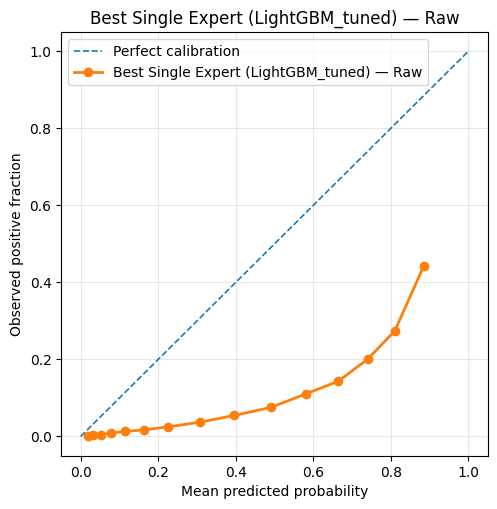

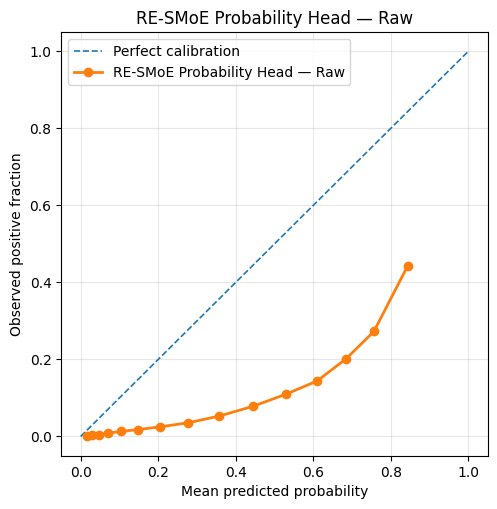

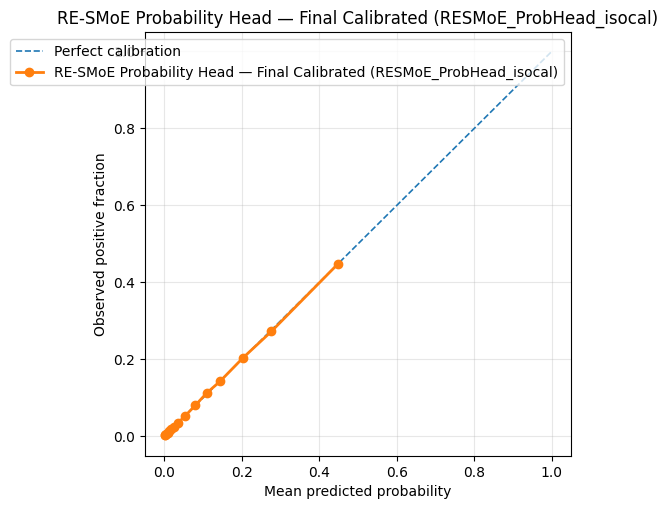

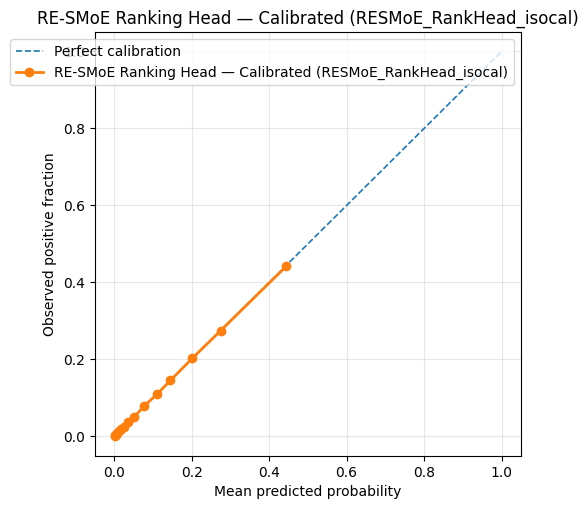

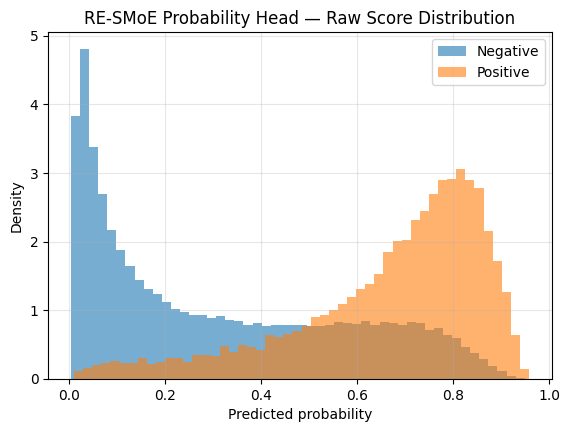

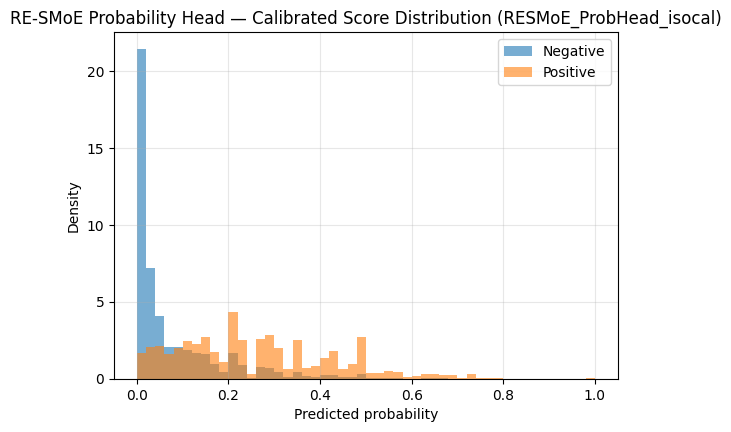

,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,p_mean,pos_rate,N,thr_bestF1,Prec@bestF1,Rec@bestF1,F1@bestF1,Acc@bestF1,thr_P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,F1@R>=0.50
0,RESMoE_RankHead_isocal,0.374377,0.849917,0.069833,0.235972,0.000473,0.094196,0.094186,253680,0.203614,0.328122,0.589378,0.421554,0.847658,0.1640,0.660947,0.414265,0.2240,0.360730,0.419487
1,RESMoE_ProbHead_isocal,0.373793,0.849635,0.069839,0.236111,0.001043,0.094193,0.094186,253680,0.203721,0.327089,0.590424,0.420966,0.847020,0.1600,0.660528,0.412650,0.2230,0.359028,0.417954
6,RESMoE_ProbHead_raw,0.377153,0.850135,0.161642,0.471906,0.247659,0.341844,0.094186,253680,0.685170,0.329884,0.583142,0.421388,0.849168,0.6395,0.663876,0.413466,0.7235,0.361156,0.419510
7,BestSingle_LightGBM_raw,0.375618,0.849678,0.184456,0.531824,0.276534,0.370720,0.094186,253680,0.754116,0.338946,0.557778,0.421660,0.855889,0.6955,0.663458,0.413448,0.7790,0.360947,0.419252



Module 8 complete.
Locked final calibrated probability head: RESMoE_ProbHead_isocal
Locked final calibrated ranking head    : RESMoE_RankHead_isocal
Saved tables to: /kaggle/working/outputs/tables
Saved figures to: /kaggle/working/outputs/figures


In [6]:
# ============================================================
# Module 8 — Calibration + Reliability analysis
# Goal:
#   Calibrate the final probability head and compare reliability
#   across:
#     1) Best single expert        -> LightGBM_tuned
#     2) RE-SMoE probability head  -> p_prob_raw_m7
#     3) RE-SMoE ranking head      -> p_rank_m7
#
# We will:
#   - fit leakage-safe OOF logistic calibration
#   - optionally fit OOF isotonic calibration
#   - evaluate PR-AUC / ROC-AUC / Brier / NLL / ECE
#   - generate reliability tables
#   - generate reliability plots
#
# Locked inputs from previous modules:
#   p_lgb           = oof_lgb_tuned
#   p_prob_raw_m7   = weighted probability head
#   p_rank_m7       = rank-averaged ranking head
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.calibration import calibration_curve
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["y_all", "oof_lgb_tuned", "p_prob_raw_m7", "p_rank_m7"]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 8: {missing_vars}")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

def logit_np(p):
    p = clip_probs(p)
    return np.log(p / (1.0 - p))

def eval_reliability(y, p, name):
    row = evaluate_probs(y, p, name=name)
    return row

def oof_logistic_calibration(scores, y, n_splits=5, seed=42):
    """
    Leakage-safe OOF logistic calibration.
    scores should be probabilities in (0,1).
    Uses logit(scores) as input feature.
    """
    scores = clip_probs(scores)
    y = np.asarray(y).astype(int)

    X = logit_np(scores).reshape(-1, 1)
    skf_local = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    p_cal = np.zeros(len(y), dtype=np.float32)

    for fold, (tr_idx, te_idx) in enumerate(skf_local.split(X, y), 1):
        clf = LogisticRegression(max_iter=4000, solver="lbfgs", C=1.0)
        clf.fit(X[tr_idx], y[tr_idx])
        p_cal[te_idx] = clf.predict_proba(X[te_idx])[:, 1].astype(np.float32)

    return clip_probs(p_cal)

def oof_isotonic_calibration(scores, y, n_splits=5, seed=42):
    """
    Leakage-safe OOF isotonic calibration.
    """
    scores = clip_probs(scores)
    y = np.asarray(y).astype(int)

    skf_local = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    p_cal = np.zeros(len(y), dtype=np.float32)

    for fold, (tr_idx, te_idx) in enumerate(skf_local.split(scores.reshape(-1, 1), y), 1):
        iso = IsotonicRegression(out_of_bounds="clip")
        iso.fit(scores[tr_idx], y[tr_idx])
        p_cal[te_idx] = iso.predict(scores[te_idx]).astype(np.float32)

    return clip_probs(p_cal)

def make_reliability_table(y, p_dict):
    rows = []
    for name, p in p_dict.items():
        rows.append(eval_reliability(y, p, name))
    df_out = pd.DataFrame(rows).sort_values(["Brier", "NLL", "ECE"], ascending=[True, True, True]).reset_index(drop=True)
    return df_out

def plot_reliability_diagram(y, p, title, n_bins=15, save_path=None):
    y = np.asarray(y).astype(int)
    p = clip_probs(p)

    frac_pos, mean_pred = calibration_curve(y, p, n_bins=n_bins, strategy="quantile")

    plt.figure(figsize=(5.5, 5.5))
    plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1.2, label="Perfect calibration")
    plt.plot(mean_pred, frac_pos, marker="o", linewidth=2, label=title)
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Observed positive fraction")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

def plot_score_histograms(y, p, title, save_path=None):
    y = np.asarray(y).astype(int)
    p = clip_probs(p)

    plt.figure(figsize=(6.5, 4.5))
    plt.hist(p[y == 0], bins=50, alpha=0.6, density=True, label="Negative")
    plt.hist(p[y == 1], bins=50, alpha=0.6, density=True, label="Positive")
    plt.xlabel("Predicted probability")
    plt.ylabel("Density")
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

# ------------------------------------------------------------
# Locked inputs
# ------------------------------------------------------------
y = y_all.astype(int)

p_best_single = clip_probs(oof_lgb_tuned)
p_prob_raw = clip_probs(p_prob_raw_m7)
p_rank_raw = clip_probs(p_rank_m7)

# ------------------------------------------------------------
# 8.1 Calibrate
# ------------------------------------------------------------
print("Running logistic calibration...")
p_best_single_logcal = oof_logistic_calibration(p_best_single, y, n_splits=N_SPLITS, seed=SEED)
p_prob_logcal        = oof_logistic_calibration(p_prob_raw, y, n_splits=N_SPLITS, seed=SEED)
p_rank_logcal        = oof_logistic_calibration(p_rank_raw, y, n_splits=N_SPLITS, seed=SEED)

print("Running isotonic calibration...")
p_best_single_isocal = oof_isotonic_calibration(p_best_single, y, n_splits=N_SPLITS, seed=SEED)
p_prob_isocal        = oof_isotonic_calibration(p_prob_raw, y, n_splits=N_SPLITS, seed=SEED)
p_rank_isocal        = oof_isotonic_calibration(p_rank_raw, y, n_splits=N_SPLITS, seed=SEED)

# ------------------------------------------------------------
# 8.2 Reliability comparison table
# ------------------------------------------------------------
calib_candidates = {
    "BestSingle_LightGBM_raw": p_best_single,
    "BestSingle_LightGBM_logcal": p_best_single_logcal,
    "BestSingle_LightGBM_isocal": p_best_single_isocal,

    "RESMoE_ProbHead_raw": p_prob_raw,
    "RESMoE_ProbHead_logcal": p_prob_logcal,
    "RESMoE_ProbHead_isocal": p_prob_isocal,

    "RESMoE_RankHead_raw": p_rank_raw,
    "RESMoE_RankHead_logcal": p_rank_logcal,
    "RESMoE_RankHead_isocal": p_rank_isocal,
}

module8_reliability_df = make_reliability_table(y, calib_candidates)
display(module8_reliability_df)
module8_reliability_df.to_csv(TAB_DIR / "module8_reliability_summary.csv", index=False)

# ------------------------------------------------------------
# 8.3 Pick final calibrated probability head
# Rule:
#   prioritize low Brier / NLL / ECE
#   while keeping PR-AUC competitive
# ------------------------------------------------------------
# A practical selection:
# choose the best among probability-head variants by Brier first
prob_variants = module8_reliability_df[
    module8_reliability_df["model"].str.contains("RESMoE_ProbHead")
].copy().sort_values(["Brier", "NLL", "ECE"], ascending=[True, True, True])

rank_variants = module8_reliability_df[
    module8_reliability_df["model"].str.contains("RESMoE_RankHead")
].copy().sort_values(["Brier", "NLL", "ECE"], ascending=[True, True, True])

best_prob_model_name = prob_variants.iloc[0]["model"]
best_rank_cal_model_name = rank_variants.iloc[0]["model"]

name_to_pred = {
    "BestSingle_LightGBM_raw": p_best_single,
    "BestSingle_LightGBM_logcal": p_best_single_logcal,
    "BestSingle_LightGBM_isocal": p_best_single_isocal,

    "RESMoE_ProbHead_raw": p_prob_raw,
    "RESMoE_ProbHead_logcal": p_prob_logcal,
    "RESMoE_ProbHead_isocal": p_prob_isocal,

    "RESMoE_RankHead_raw": p_rank_raw,
    "RESMoE_RankHead_logcal": p_rank_logcal,
    "RESMoE_RankHead_isocal": p_rank_isocal,
}

p_prob_final_m8 = name_to_pred[best_prob_model_name]
p_rank_cal_final_m8 = name_to_pred[best_rank_cal_model_name]

print("\nBest calibrated probability-head candidate:", best_prob_model_name)
print("Best calibrated ranking-head candidate    :", best_rank_cal_model_name)

# ------------------------------------------------------------
# 8.4 Reliability plots
# ------------------------------------------------------------
plot_reliability_diagram(
    y, p_best_single,
    title="Best Single Expert (LightGBM_tuned) — Raw",
    save_path=FIG_DIR / "module8_reliability_best_single_raw.png"
)

plot_reliability_diagram(
    y, p_prob_raw,
    title="RE-SMoE Probability Head — Raw",
    save_path=FIG_DIR / "module8_reliability_probhead_raw.png"
)

plot_reliability_diagram(
    y, p_prob_final_m8,
    title=f"RE-SMoE Probability Head — Final Calibrated ({best_prob_model_name})",
    save_path=FIG_DIR / "module8_reliability_probhead_calibrated.png"
)

plot_reliability_diagram(
    y, p_rank_cal_final_m8,
    title=f"RE-SMoE Ranking Head — Calibrated ({best_rank_cal_model_name})",
    save_path=FIG_DIR / "module8_reliability_rankhead_calibrated.png"
)

# Optional score histograms
plot_score_histograms(
    y, p_prob_raw,
    title="RE-SMoE Probability Head — Raw Score Distribution",
    save_path=FIG_DIR / "module8_hist_probhead_raw.png"
)

plot_score_histograms(
    y, p_prob_final_m8,
    title=f"RE-SMoE Probability Head — Calibrated Score Distribution ({best_prob_model_name})",
    save_path=FIG_DIR / "module8_hist_probhead_calibrated.png"
)

# ------------------------------------------------------------
# 8.5 Save final calibrated artifacts
# ------------------------------------------------------------
module8_predictions_df = pd.DataFrame({
    "y_true": y.astype(int),
    "p_best_single_raw": p_best_single,
    "p_best_single_logcal": p_best_single_logcal,
    "p_best_single_isocal": p_best_single_isocal,
    "p_prob_raw_m7": p_prob_raw,
    "p_prob_logcal_m8": p_prob_logcal,
    "p_prob_isocal_m8": p_prob_isocal,
    "p_rank_raw_m7": p_rank_raw,
    "p_rank_logcal_m8": p_rank_logcal,
    "p_rank_isocal_m8": p_rank_isocal,
    "p_prob_final_m8": p_prob_final_m8,
    "p_rank_cal_final_m8": p_rank_cal_final_m8,
})
module8_predictions_df.to_csv(TAB_DIR / "module8_calibrated_predictions.csv", index=False)

np.savez_compressed(
    TAB_DIR / "module8_calibrated_predictions.npz",
    y_true=y.astype(np.int32),
    p_best_single_raw=p_best_single.astype(np.float32),
    p_best_single_logcal=p_best_single_logcal.astype(np.float32),
    p_best_single_isocal=p_best_single_isocal.astype(np.float32),
    p_prob_raw_m7=p_prob_raw.astype(np.float32),
    p_prob_logcal_m8=p_prob_logcal.astype(np.float32),
    p_prob_isocal_m8=p_prob_isocal.astype(np.float32),
    p_rank_raw_m7=p_rank_raw.astype(np.float32),
    p_rank_logcal_m8=p_rank_logcal.astype(np.float32),
    p_rank_isocal_m8=p_rank_isocal.astype(np.float32),
    p_prob_final_m8=p_prob_final_m8.astype(np.float32),
    p_rank_cal_final_m8=p_rank_cal_final_m8.astype(np.float32),
)

# ------------------------------------------------------------
# 8.6 Final compact summary for paper narrative
# ------------------------------------------------------------
module8_final_compare = module8_reliability_df[
    module8_reliability_df["model"].isin([
        "BestSingle_LightGBM_raw",
        best_prob_model_name,
        best_rank_cal_model_name,
        "RESMoE_RankingHead_raw",
        "RESMoE_ProbHead_raw",
    ])
].copy().sort_values(["Brier", "NLL", "ECE"], ascending=[True, True, True])

display(module8_final_compare)
module8_final_compare.to_csv(TAB_DIR / "module8_final_compare_table.csv", index=False)

print("\nModule 8 complete.")
print("Locked final calibrated probability head:", best_prob_model_name)
print("Locked final calibrated ranking head    :", best_rank_cal_model_name)
print(f"Saved tables to: {TAB_DIR}")
print(f"Saved figures to: {FIG_DIR}")

In [7]:
# ============================================================
# Module 8B — OOF logistic stacking trick + expanded evaluation metrics
# Goal:
#   1) Try one final PR-AUC improvement using a leakage-safe OOF logistic stacker
#   2) Expand evaluation with traditional + advanced metrics
#
# Inputs required from previous modules:
#   - y_all
#   - oof_lgb_tuned
#   - oof_xgb_tuned
#   - oof_deepfm
#   - p_rank_m7
#   - p_prob_raw_m7
#
# Outputs:
#   - p_stack_logit_only
#   - p_stack_plus_disagreement
#   - module8b_core_compare_df
#   - module8b_operating_points_df
#   - module8b_topk_df
# ============================================================

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    confusion_matrix,
    matthews_corrcoef,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    precision_recall_curve,
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = [
    "y_all",
    "oof_lgb_tuned",
    "oof_xgb_tuned",
    "oof_deepfm",
    "p_rank_m7",
    "p_prob_raw_m7",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 8B: {missing_vars}")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

def logit_np(p):
    p = clip_probs(p)
    return np.log(p / (1.0 - p))

def expected_calibration_error(y_true, p, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    mce = 0.0

    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        if i < n_bins - 1:
            mask = (p >= lo) & (p < hi)
        else:
            mask = (p >= lo) & (p <= hi)

        if mask.sum() == 0:
            continue

        acc = y_true[mask].mean()
        conf = p[mask].mean()
        err = abs(acc - conf)

        ece += (mask.sum() / len(p)) * err
        mce = max(mce, err)

    return float(ece), float(mce)

def calibration_slope_intercept(y_true, p):
    y_true = np.asarray(y_true).astype(int)
    x = logit_np(p).reshape(-1, 1)

    clf = LogisticRegression(max_iter=4000, solver="lbfgs", C=1e6)
    clf.fit(x, y_true)

    slope = float(clf.coef_[0][0])
    intercept = float(clf.intercept_[0])
    return slope, intercept

def oe_ratio(y_true, p):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    observed = float(y_true.sum())
    expected = float(p.sum())
    return observed / max(expected, 1e-8)

def find_best_f1_threshold(y_true, p):
    precisions, recalls, thresholds = precision_recall_curve(y_true, p)
    f1_vals = 2 * precisions * recalls / (precisions + recalls + 1e-12)
    idx = int(np.nanargmax(f1_vals))
    thr = 0.5 if len(thresholds) == 0 else float(thresholds[max(idx - 1, 0)])
    return thr

def find_threshold_precision_at_least(y_true, p, target_precision=0.30):
    best_thr = np.nan
    best_rec = -1.0
    best_f1 = -1.0

    for t in np.linspace(0.0, 1.0, 2001):
        pred = (p >= t).astype(int)
        pr = precision_score(y_true, pred, zero_division=0)
        if pr >= target_precision:
            rc = recall_score(y_true, pred, zero_division=0)
            f1 = f1_score(y_true, pred, zero_division=0)
            if rc > best_rec:
                best_rec = rc
                best_f1 = f1
                best_thr = t

    if np.isnan(best_thr):
        return np.nan, 0.0, 0.0
    return float(best_thr), float(best_rec), float(best_f1)

def find_threshold_recall_at_least(y_true, p, target_recall=0.50):
    best_thr = np.nan
    best_prec = -1.0
    best_f1 = -1.0

    for t in np.linspace(0.0, 1.0, 2001):
        pred = (p >= t).astype(int)
        rc = recall_score(y_true, pred, zero_division=0)
        if rc >= target_recall:
            pr = precision_score(y_true, pred, zero_division=0)
            f1 = f1_score(y_true, pred, zero_division=0)
            if pr > best_prec:
                best_prec = pr
                best_f1 = f1
                best_thr = t

    if np.isnan(best_thr):
        return np.nan, 0.0, 0.0
    return float(best_thr), float(best_prec), float(best_f1)

def threshold_metrics(y_true, p, thr, label):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    pred = (p >= thr).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()

    specificity = tn / max(tn + fp, 1)
    sensitivity = recall_score(y_true, pred, zero_division=0)
    precision = precision_score(y_true, pred, zero_division=0)
    recall = sensitivity
    f1 = f1_score(y_true, pred, zero_division=0)
    acc = accuracy_score(y_true, pred)
    bal_acc = balanced_accuracy_score(y_true, pred)
    mcc = matthews_corrcoef(y_true, pred) if len(np.unique(pred)) > 1 else 0.0

    return {
        "operating_point": label,
        "threshold": float(thr),
        "Precision": float(precision),
        "Recall": float(recall),
        "Specificity": float(specificity),
        "F1": float(f1),
        "Accuracy": float(acc),
        "BalancedAccuracy": float(bal_acc),
        "MCC": float(mcc),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
    }

def topk_metrics(y_true, p, frac):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    n = len(y_true)
    k = max(1, int(round(frac * n)))

    idx = np.argsort(-p)[:k]
    y_top = y_true[idx]

    precision_at_k = float(y_top.mean())
    recall_at_k = float(y_top.sum() / max(y_true.sum(), 1))
    prevalence = float(y_true.mean())
    lift_at_k = precision_at_k / max(prevalence, 1e-8)

    return {
        "top_fraction": frac,
        "k": k,
        "Precision_at_topk": precision_at_k,
        "Recall_at_topk": recall_at_k,
        "Lift_at_topk": lift_at_k,
    }

def expanded_eval(y_true, p, name):
    p = clip_probs(p)
    ece, mce = expected_calibration_error(y_true, p, n_bins=15)
    slope, intercept = calibration_slope_intercept(y_true, p)
    oer = oe_ratio(y_true, p)

    row = {
        "model": name,
        "PR_AUC": float(average_precision_score(y_true, p)),
        "ROC_AUC": float(roc_auc_score(y_true, p)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": float(log_loss(y_true, p)),
        "ECE": float(ece),
        "MCE": float(mce),
        "CalibSlope": float(slope),
        "CalibIntercept": float(intercept),
        "OE_Ratio": float(oer),
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y_true)),
        "N": int(len(y_true)),
    }
    return row

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
y = y_all.astype(int)
p_lgb = clip_probs(oof_lgb_tuned)
p_xgb = clip_probs(oof_xgb_tuned)
p_dfm = clip_probs(oof_deepfm)
p_rank = clip_probs(p_rank_m7)
p_prob = clip_probs(p_prob_raw_m7)

# ============================================================
# 8B.1 OOF logistic stacking trick
# ------------------------------------------------------------
# Variant A: logits only
# Variant B: logits + disagreement features
# ============================================================

def build_meta_features(p_lgb, p_xgb, p_dfm, with_disagreement=False):
    X_meta = np.column_stack([
        logit_np(p_lgb),
        logit_np(p_xgb),
        logit_np(p_dfm),
    ])

    if with_disagreement:
        X_meta = np.column_stack([
            X_meta,
            np.abs(p_lgb - p_xgb),
            np.abs(p_lgb - p_dfm),
            np.abs(p_xgb - p_dfm),
            p_lgb * p_xgb,
            p_lgb * p_dfm,
            p_xgb * p_dfm,
        ])

    return X_meta.astype(np.float32)

def oof_meta_logistic(X_meta, y, n_splits=5, seed=42, C=1.0):
    skf_local = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    p_oof = np.zeros(len(y), dtype=np.float32)

    for fold, (tr_idx, te_idx) in enumerate(skf_local.split(X_meta, y), 1):
        clf = LogisticRegression(
            max_iter=4000,
            solver="lbfgs",
            C=C
        )
        clf.fit(X_meta[tr_idx], y[tr_idx])
        p_oof[te_idx] = clf.predict_proba(X_meta[te_idx])[:, 1].astype(np.float32)

    return clip_probs(p_oof)

X_meta_logit = build_meta_features(p_lgb, p_xgb, p_dfm, with_disagreement=False)
X_meta_plus  = build_meta_features(p_lgb, p_xgb, p_dfm, with_disagreement=True)

p_stack_logit_only = oof_meta_logistic(X_meta_logit, y, n_splits=N_SPLITS, seed=SEED, C=1.0)
p_stack_plus_disagreement = oof_meta_logistic(X_meta_plus, y, n_splits=N_SPLITS, seed=SEED, C=1.0)

# ============================================================
# 8B.2 Core comparison table
# ============================================================
core_candidates = {
    "BestSingle_LightGBM_tuned": p_lgb,
    "RESMoE_RankHead_raw": p_rank,
    "RESMoE_ProbHead_raw": p_prob,
    "Stack_LogitOnly": p_stack_logit_only,
    "Stack_LogitPlusDisagreement": p_stack_plus_disagreement,
}

module8b_core_compare_df = pd.DataFrame([
    expanded_eval(y, p, name) for name, p in core_candidates.items()
]).sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)

display(module8b_core_compare_df)
module8b_core_compare_df.to_csv(TAB_DIR / "module8b_core_compare.csv", index=False)

# Lock best stacker by PR-AUC
best_stack_name = module8b_core_compare_df[
    module8b_core_compare_df["model"].str.contains("Stack_")
].iloc[0]["model"]

best_stack_pred = core_candidates[best_stack_name]

print("\nBest stacker variant:", best_stack_name)

# ============================================================
# 8B.3 Expanded threshold-based metrics
# Evaluate for:
#   - Best single
#   - Ranking head
#   - Probability head
#   - Best stacker
# ============================================================
op_models = {
    "BestSingle_LightGBM_tuned": p_lgb,
    "RESMoE_RankHead_raw": p_rank,
    "RESMoE_ProbHead_raw": p_prob,
    best_stack_name: best_stack_pred,
}

op_rows = []
for name, p in op_models.items():
    thr_best = find_best_f1_threshold(y, p)
    thr_p30, _, _ = find_threshold_precision_at_least(y, p, target_precision=0.30)
    thr_r50, _, _ = find_threshold_recall_at_least(y, p, target_recall=0.50)

    op_rows.append({"model": name, **threshold_metrics(y, p, thr_best, "BestF1")})
    if not np.isnan(thr_p30):
        op_rows.append({"model": name, **threshold_metrics(y, p, thr_p30, "Precision>=0.30")})
    if not np.isnan(thr_r50):
        op_rows.append({"model": name, **threshold_metrics(y, p, thr_r50, "Recall>=0.50")})

module8b_operating_points_df = pd.DataFrame(op_rows)
display(module8b_operating_points_df)
module8b_operating_points_df.to_csv(TAB_DIR / "module8b_operating_points.csv", index=False)

# ============================================================
# 8B.4 Top-k screening utility metrics
# Useful for screening / resource allocation
# ============================================================
topk_fracs = [0.05, 0.10, 0.20]

topk_rows = []
for name, p in op_models.items():
    for frac in topk_fracs:
        row = topk_metrics(y, p, frac)
        row["model"] = name
        topk_rows.append(row)

module8b_topk_df = pd.DataFrame(topk_rows)
display(module8b_topk_df)
module8b_topk_df.to_csv(TAB_DIR / "module8b_topk_metrics.csv", index=False)

# ============================================================
# 8B.5 Save stacker predictions
# ============================================================
module8b_preds_df = pd.DataFrame({
    "y_true": y.astype(int),
    "p_lgb_tuned": p_lgb,
    "p_xgb_tuned": p_xgb,
    "p_deepfm": p_dfm,
    "p_rank_raw_m7": p_rank,
    "p_prob_raw_m7": p_prob,
    "p_stack_logit_only": p_stack_logit_only,
    "p_stack_plus_disagreement": p_stack_plus_disagreement,
})
module8b_preds_df.to_csv(TAB_DIR / "module8b_stacker_predictions.csv", index=False)

np.savez_compressed(
    TAB_DIR / "module8b_stacker_predictions.npz",
    y_true=y.astype(np.int32),
    p_lgb_tuned=p_lgb.astype(np.float32),
    p_xgb_tuned=p_xgb.astype(np.float32),
    p_deepfm=p_dfm.astype(np.float32),
    p_rank_raw_m7=p_rank.astype(np.float32),
    p_prob_raw_m7=p_prob.astype(np.float32),
    p_stack_logit_only=p_stack_logit_only.astype(np.float32),
    p_stack_plus_disagreement=p_stack_plus_disagreement.astype(np.float32),
)

# ============================================================
# 8B.6 Final compact summary for decision
# ============================================================
module8b_decision_df = module8b_core_compare_df.copy()
display(module8b_decision_df)

print("\nModule 8B complete.")
print("Saved:")
print("-", TAB_DIR / "module8b_core_compare.csv")
print("-", TAB_DIR / "module8b_operating_points.csv")
print("-", TAB_DIR / "module8b_topk_metrics.csv")
print("-", TAB_DIR / "module8b_stacker_predictions.csv")

,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,CalibSlope,CalibIntercept,OE_Ratio,p_mean,pos_rate,N
0,RESMoE_RankHead_raw,0.377547,0.850479,0.272934,0.801467,0.405814,0.630644,0.839827,-3.011778,0.188371,0.500000,0.094186,253680
1,Stack_LogitPlusDisagreement,0.377341,0.850439,0.069794,0.235806,0.001085,0.191970,0.999222,-0.001261,1.000175,0.094169,0.094186,253680
2,Stack_LogitOnly,0.377189,0.850464,0.069798,0.235802,0.001077,0.199631,0.999929,0.000065,1.000343,0.094153,0.094186,253680
3,RESMoE_ProbHead_raw,0.377153,0.850135,0.161642,0.471906,0.247659,0.486868,1.100190,-2.204408,0.275522,0.341844,0.094186,253680
4,BestSingle_LightGBM_tuned,0.375618,0.849678,0.184456,0.531824,0.276534,0.544321,1.023170,-2.429740,0.254061,0.370720,0.094186,253680



Best stacker variant: Stack_LogitPlusDisagreement


,model,operating_point,threshold,Precision,Recall,Specificity,F1,Accuracy,BalancedAccuracy,MCC,TP,FP,TN,FN
0,BestSingle_LightGBM_tuned,BestF1,0.754116,0.338946,0.557778,0.886887,0.421660,0.855889,0.722332,0.358886,13327,25992,203795,10566
1,BestSingle_LightGBM_tuned,Precision>=0.30,0.695500,0.300290,0.663458,0.839255,0.413448,0.822698,0.751357,0.361715,15852,36937,192850,8041
2,BestSingle_LightGBM_tuned,Recall>=0.50,0.779000,0.360947,0.500021,0.907950,0.419252,0.869529,0.703985,0.353782,11947,21152,208635,11946
3,RESMoE_RankHead_raw,BestF1,0.835440,0.332866,0.576194,0.879924,0.421964,0.851317,0.728059,0.360656,13767,27592,202195,10126
4,RESMoE_RankHead_raw,Precision>=0.30,0.790000,0.300047,0.666137,0.838420,0.413736,0.822193,0.752278,0.362395,15916,37129,192658,7977
5,RESMoE_RankHead_raw,Recall>=0.50,0.868000,0.361301,0.500314,0.908037,0.419593,0.869635,0.704175,0.354170,11954,21132,208655,11939
6,RESMoE_ProbHead_raw,BestF1,0.685170,0.329884,0.583142,0.876829,0.421388,0.849168,0.729985,0.360653,13933,28303,201484,9960
7,RESMoE_ProbHead_raw,Precision>=0.30,0.639500,0.300223,0.663876,0.839103,0.413466,0.822599,0.751490,0.361793,15862,36972,192815,8031
8,RESMoE_ProbHead_raw,Recall>=0.50,0.723500,0.361156,0.500356,0.907971,0.419510,0.869580,0.704164,0.354077,11955,21147,208640,11938
9,Stack_LogitPlusDisagreement,BestF1,0.199489,0.332899,0.577659,0.879636,0.422383,0.851194,0.728648,0.361232,13802,27658,202129,10091


,top_fraction,k,Precision_at_topk,Recall_at_topk,Lift_at_topk,model
0,0.05,12684,0.471618,0.250366,5.007324,BestSingle_LightGBM_tuned
1,0.10,25368,0.393843,0.418156,4.181559,BestSingle_LightGBM_tuned
2,0.20,50736,0.305720,0.649186,3.245930,BestSingle_LightGBM_tuned
3,0.05,12684,0.473746,0.251496,5.029925,RESMoE_RankHead_raw
4,0.10,25368,0.394789,0.419160,4.191604,RESMoE_RankHead_raw
5,0.20,50736,0.306114,0.650023,3.250115,RESMoE_RankHead_raw
6,0.05,12684,0.475087,0.252208,5.044155,RESMoE_ProbHead_raw
7,0.10,25368,0.394828,0.419202,4.192023,RESMoE_ProbHead_raw
8,0.20,50736,0.305897,0.649563,3.247813,RESMoE_ProbHead_raw
9,0.05,12684,0.473983,0.251622,5.032436,Stack_LogitPlusDisagreement


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,CalibSlope,CalibIntercept,OE_Ratio,p_mean,pos_rate,N
0,RESMoE_RankHead_raw,0.377547,0.850479,0.272934,0.801467,0.405814,0.630644,0.839827,-3.011778,0.188371,0.500000,0.094186,253680
1,Stack_LogitPlusDisagreement,0.377341,0.850439,0.069794,0.235806,0.001085,0.191970,0.999222,-0.001261,1.000175,0.094169,0.094186,253680
2,Stack_LogitOnly,0.377189,0.850464,0.069798,0.235802,0.001077,0.199631,0.999929,0.000065,1.000343,0.094153,0.094186,253680
3,RESMoE_ProbHead_raw,0.377153,0.850135,0.161642,0.471906,0.247659,0.486868,1.100190,-2.204408,0.275522,0.341844,0.094186,253680
4,BestSingle_LightGBM_tuned,0.375618,0.849678,0.184456,0.531824,0.276534,0.544321,1.023170,-2.429740,0.254061,0.370720,0.094186,253680



Module 8B complete.
Saved:
- /kaggle/working/outputs/tables/module8b_core_compare.csv
- /kaggle/working/outputs/tables/module8b_operating_points.csv
- /kaggle/working/outputs/tables/module8b_topk_metrics.csv
- /kaggle/working/outputs/tables/module8b_stacker_predictions.csv


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,p_mean,pos_rate,N,...,Prec@bestF1,Rec@bestF1,F1@bestF1,Acc@bestF1,thr_P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,F1@R>=0.50
0,LightGBM_tuned,0.375618,0.849678,0.184456,0.531824,0.276534,0.544321,0.370720,0.094186,253680,...,0.338946,0.557778,0.421660,0.855889,0.6955,0.663458,0.413448,0.7790,0.360947,0.419252
1,XGBoost_tuned,0.374499,0.848966,0.182213,0.529555,0.273046,0.542405,0.367231,0.094186,253680,...,0.335601,0.563596,0.420694,0.853808,0.6910,0.658854,0.412424,0.7780,0.356806,0.416749
2,DeepFM,0.373216,0.849070,0.070004,0.236632,0.001541,0.134886,0.094174,0.094186,253680,...,0.333561,0.572427,0.421505,0.852010,0.1650,0.656761,0.412215,0.2295,0.356796,0.416815


Best expert in Module 9: LightGBM_tuned


,winner,count,fraction
0,DeepFM,229775,0.905767
1,XGBoost_tuned,14286,0.056315
2,LightGBM_tuned,9619,0.037918


,expert,n_wins,win_fraction,avg_logloss_margin_when_winning
0,DeepFM,229775,0.905767,0.426383
1,XGBoost_tuned,14286,0.056315,0.037749
2,LightGBM_tuned,9619,0.037918,0.066606


,pair,corr,disagree>0.05,disagree>0.10,top10_precision_gap
0,XGBoost_tuned+DeepFM,0.871251,0.821298,0.702247,0.000473
1,LightGBM_tuned+DeepFM,0.864682,0.819146,0.701727,0.000158
2,LightGBM_tuned+XGBoost_tuned,0.991841,0.136857,0.025733,0.000631


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,p_mean,pos_rate,N,...,F1@bestF1,Acc@bestF1,thr_P>=0.30,Rec@P>=0.30,F1@P>=0.30,thr_R>=0.50,Prec@R>=0.50,F1@R>=0.50,delta_PR_AUC_vs_best_single,delta_ROC_AUC_vs_best_single
0,BestSingle::LightGBM_tuned,0.375618,0.849678,0.184456,0.531824,0.276534,0.544321,0.370720,0.094186,253680,...,0.421660,0.855889,0.6955,0.663458,0.413448,0.7790,0.360947,0.419252,0.000000,0.000000
1,Oracle_best_expert_per_sample,0.945182,0.987225,0.026528,0.117123,0.069247,0.237644,0.138201,0.094186,253680,...,0.887633,0.979541,0.1130,0.985477,0.460337,0.7905,0.998580,0.666815,0.569564,0.137546


,risk_decile,model,N,pos_rate,PR_AUC,ROC_AUC,winner_by_PR
0,D1,XGBoost_tuned,25368,0.002286,0.003708,0.556178,1
1,D1,DeepFM,25368,0.002286,0.002948,0.578072,0
2,D1,LightGBM_tuned,25368,0.002286,0.002586,0.539115,0
3,D10,LightGBM_tuned,25368,0.393843,0.514441,0.612622,1
4,D10,XGBoost_tuned,25368,0.393843,0.513716,0.612934,0
5,D10,DeepFM,25368,0.393843,0.510662,0.613306,0
6,D2,DeepFM,25368,0.004415,0.006512,0.572511,1
7,D2,XGBoost_tuned,25368,0.004415,0.006354,0.592569,0
8,D2,LightGBM_tuned,25368,0.004415,0.005411,0.551473,0
9,D3,DeepFM,25368,0.009697,0.013750,0.612281,1


,N,pos_rate,PR_AUC,ROC_AUC,Brier,NLL,group,level,model,winner_by_PR
0,24421,0.008558,0.114956,0.815646,0.016431,0.084711,Age_bin,1-3,XGBoost_tuned,1
1,24421,0.008558,0.112408,0.813069,0.017728,0.089779,Age_bin,1-3,LightGBM_tuned,0
2,24421,0.008558,0.110188,0.815670,0.008042,0.041073,Age_bin,1-3,DeepFM,0
3,89070,0.172808,0.409986,0.768985,0.317066,0.865106,Age_bin,10-13,LightGBM_tuned,1
4,89070,0.172808,0.408368,0.768072,0.315742,0.868727,Age_bin,10-13,XGBoost_tuned,0
5,89070,0.172808,0.407170,0.768308,0.122852,0.391665,Age_bin,10-13,DeepFM,0
6,49799,0.025221,0.215764,0.859568,0.021833,0.090694,Age_bin,4-6,DeepFM,1
7,49799,0.025221,0.214386,0.860834,0.057654,0.207946,Age_bin,4-6,LightGBM_tuned,0
8,49799,0.025221,0.210642,0.859077,0.055100,0.202012,Age_bin,4-6,XGBoost_tuned,0
9,90390,0.077840,0.323577,0.829233,0.168688,0.501273,Age_bin,7-9,LightGBM_tuned,1


,model,n_subgroups_won
0,LightGBM_tuned,36
1,XGBoost_tuned,5
2,DeepFM,2


,LightGBM_tuned,XGBoost_tuned,DeepFM
LightGBM_tuned,NaN,0.065588,0.087640
XGBoost_tuned,0.053131,NaN,0.090726
DeepFM,0.056382,0.071946,NaN


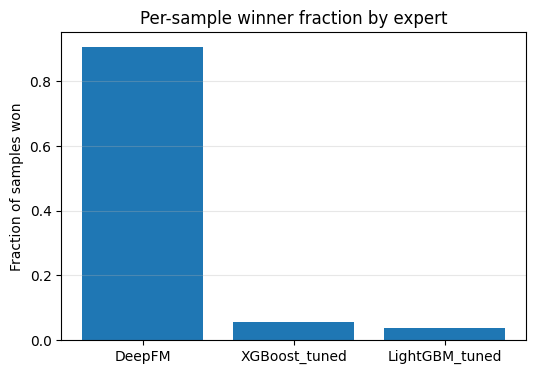

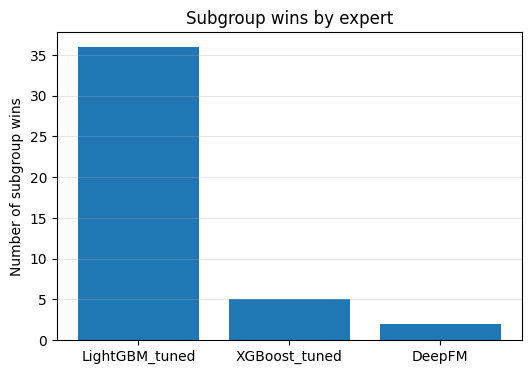

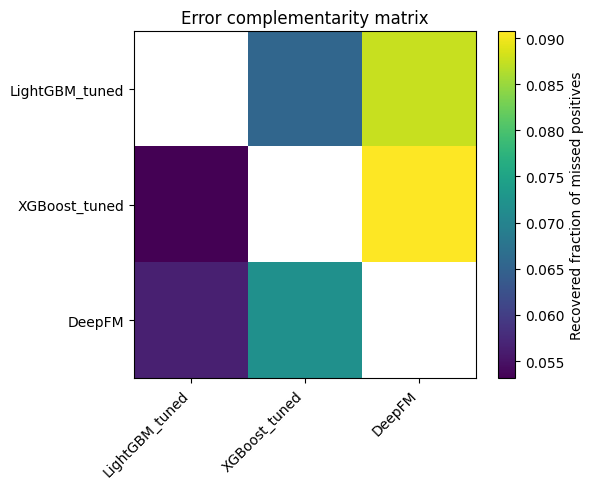


Module 9 final summary:
{'best_expert': 'LightGBM_tuned', 'best_expert_PR_AUC': 0.37561834577745545, 'oracle_PR_AUC': 0.9451823831601434, 'oracle_gain_over_best': 0.5695640373826879}

Module 9 complete.
Saved tables to: /kaggle/working/outputs/tables
Saved figures to: /kaggle/working/outputs/figures


In [10]:
# ============================================================
# PATCH — make evaluate_probs compatible with ECE/MCE tuple return
# ============================================================

def evaluate_probs(y_true, p, name="model"):
    y_true = np.asarray(y_true).astype(int)
    p = np.asarray(p).astype(float)
    p = np.clip(p, 1e-8, 1 - 1e-8)

    pr_auc = average_precision_score(y_true, p)
    roc_auc = roc_auc_score(y_true, p)
    brier = brier_score_loss(y_true, p)
    nll = log_loss(y_true, p)

    ece_out = expected_calibration_error(y_true, p, n_bins=15)
    if isinstance(ece_out, tuple):
        ece = float(ece_out[0])
        mce = float(ece_out[1])
    else:
        ece = float(ece_out)
        mce = np.nan

    precisions, recalls, thresholds = precision_recall_curve(y_true, p)
    f1_vals = 2 * precisions * recalls / (precisions + recalls + 1e-12)
    best_idx = int(np.nanargmax(f1_vals))

    if len(thresholds) == 0:
        thr_bestF1 = 0.5
    else:
        thr_bestF1 = float(thresholds[max(best_idx - 1, 0)])

    pred_best = (p >= thr_bestF1).astype(int)
    prec_best = float(precision_score(y_true, pred_best, zero_division=0))
    rec_best = float(recall_score(y_true, pred_best))
    f1_best = float(f1_score(y_true, pred_best, zero_division=0))
    acc_best = float(accuracy_score(y_true, pred_best))

    # Threshold for Precision >= 0.30 with max recall
    thr_p30, rec_p30, f1_p30 = np.nan, 0.0, 0.0
    found_p30 = False
    for t in np.linspace(0.0, 1.0, 2001):
        pred = (p >= t).astype(int)
        pr = precision_score(y_true, pred, zero_division=0)
        if pr >= 0.30:
            rc = recall_score(y_true, pred, zero_division=0)
            f1_ = f1_score(y_true, pred, zero_division=0)
            thr_p30, rec_p30, f1_p30 = float(t), float(rc), float(f1_)
            found_p30 = True
            break
    if not found_p30:
        thr_p30 = np.nan

    # Threshold for Recall >= 0.50 with max precision
    thr_r50, prec_r50, f1_r50 = np.nan, 0.0, 0.0
    found_r50 = False
    for t in np.linspace(0.0, 1.0, 2001)[::-1]:
        pred = (p >= t).astype(int)
        rc = recall_score(y_true, pred, zero_division=0)
        if rc >= 0.50:
            pr = precision_score(y_true, pred, zero_division=0)
            f1_ = f1_score(y_true, pred, zero_division=0)
            thr_r50, prec_r50, f1_r50 = float(t), float(pr), float(f1_)
            found_r50 = True
            break
    if not found_r50:
        thr_r50 = np.nan

    return {
        "model": name,
        "PR_AUC": float(pr_auc),
        "ROC_AUC": float(roc_auc),
        "Brier": float(brier),
        "NLL": float(nll),
        "ECE": float(ece),
        "MCE": float(mce),
        "p_mean": float(p.mean()),
        "pos_rate": float(y_true.mean()),
        "N": int(len(y_true)),
        "thr_bestF1": float(thr_bestF1),
        "Prec@bestF1": float(prec_best),
        "Rec@bestF1": float(rec_best),
        "F1@bestF1": float(f1_best),
        "Acc@bestF1": float(acc_best),
        "thr_P>=0.30": float(thr_p30) if not np.isnan(thr_p30) else np.nan,
        "Rec@P>=0.30": float(rec_p30),
        "F1@P>=0.30": float(f1_p30),
        "thr_R>=0.50": float(thr_r50) if not np.isnan(thr_r50) else np.nan,
        "Prec@R>=0.50": float(prec_r50),
        "F1@R>=0.50": float(f1_r50),
    }
# ============================================================
# Module 9 — Expert Specialization Analysis for the final 3 experts
# Final experts:
#   1) LightGBM_tuned
#   2) XGBoost_tuned
#   3) DeepFM
#
# Goal:
#   Show experimentally that the final experts are not redundant.
#   We analyze:
#     1) Overall expert performance
#     2) Per-sample winner by log-loss
#     3) Diversity / disagreement
#     4) Oracle upper bound
#     5) Risk-decile specialization
#     6) Subgroup winner analysis
#     7) Error complementarity (who rescues whose misses)
#
# Inputs required:
#   - y_all
#   - X_all
#   - oof_lgb_tuned
#   - oof_xgb_tuned
#   - oof_deepfm
#
# Outputs:
#   - module9_overall_df
#   - module9_win_summary_df
#   - module9_diversity_df
#   - module9_oracle_df
#   - module9_riskbin_df
#   - module9_subgroup_long_df
#   - module9_subgroup_winrate_df
#   - module9_complement_df
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
)

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["y_all", "X_all", "oof_lgb_tuned", "oof_xgb_tuned", "oof_deepfm"]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 9: {missing_vars}")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

def per_sample_logloss(y, p):
    y = np.asarray(y).astype(int)
    p = clip_probs(p)
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

def best_f1_threshold(y, p):
    y = np.asarray(y).astype(int)
    p = clip_probs(p)
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    idx = int(np.nanargmax(f1))
    t = 0.5 if len(thr) == 0 else float(thr[max(idx - 1, 0)])
    return t

def subgroup_eval(y, p):
    y = np.asarray(y).astype(int)
    p = clip_probs(p)
    return {
        "N": int(len(y)),
        "pos_rate": float(np.mean(y)),
        "PR_AUC": float(average_precision_score(y, p)) if len(np.unique(y)) > 1 else np.nan,
        "ROC_AUC": float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else np.nan,
        "Brier": float(brier_score_loss(y, p)),
        "NLL": float(log_loss(y, p)),
    }

def disagreement_rate(a, b, thr=0.05):
    a = np.asarray(a).reshape(-1)
    b = np.asarray(b).reshape(-1)
    return float((np.abs(a - b) > thr).mean())

def corr(a, b):
    a = np.asarray(a).reshape(-1)
    b = np.asarray(b).reshape(-1)
    return float(np.corrcoef(a, b)[0, 1])

def topk_hit_rate(y, p, frac=0.10):
    y = np.asarray(y).astype(int)
    p = clip_probs(p)
    n = len(y)
    k = max(1, int(round(frac * n)))
    idx = np.argsort(-p)[:k]
    return float(y[idx].mean())

# ------------------------------------------------------------
# Locked final experts
# ------------------------------------------------------------
y = y_all.astype(int)
X = X_all.copy()

experts = {
    "LightGBM_tuned": clip_probs(oof_lgb_tuned),
    "XGBoost_tuned": clip_probs(oof_xgb_tuned),
    "DeepFM": clip_probs(oof_deepfm),
}
expert_names = list(experts.keys())

# ------------------------------------------------------------
# 9.1 Overall table
# ------------------------------------------------------------
module9_overall_rows = []
for name, p in experts.items():
    row = evaluate_probs(y, p, name=name)
    module9_overall_rows.append(row)

module9_overall_df = pd.DataFrame(module9_overall_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(module9_overall_df)
module9_overall_df.to_csv(TAB_DIR / "module9_overall_expert_summary.csv", index=False)

best_expert_name_m9 = module9_overall_df.iloc[0]["model"]
best_expert_pred_m9 = experts[best_expert_name_m9]
print("Best expert in Module 9:", best_expert_name_m9)

# ------------------------------------------------------------
# 9.2 Per-sample winner by log-loss
# ------------------------------------------------------------
ll_map = {name: per_sample_logloss(y, p) for name, p in experts.items()}
ll_df = pd.DataFrame(ll_map)

winner_idx = np.argmin(ll_df.values, axis=1)
winner_names = np.array(expert_names)[winner_idx]

module9_win_summary_df = (
    pd.Series(winner_names)
    .value_counts(normalize=False)
    .rename_axis("winner")
    .reset_index(name="count")
)
module9_win_summary_df["fraction"] = module9_win_summary_df["count"] / len(y)
display(module9_win_summary_df)
module9_win_summary_df.to_csv(TAB_DIR / "module9_per_sample_winner_summary.csv", index=False)

# Average margin when winning
win_margin_rows = []
for name in expert_names:
    mask = (winner_names == name)
    own = ll_df.loc[mask, name].values
    others = ll_df.loc[mask, [c for c in expert_names if c != name]].min(axis=1).values
    margin = others - own
    win_margin_rows.append({
        "expert": name,
        "n_wins": int(mask.sum()),
        "win_fraction": float(mask.mean()),
        "avg_logloss_margin_when_winning": float(np.mean(margin)) if mask.sum() > 0 else np.nan,
    })

module9_win_margin_df = pd.DataFrame(win_margin_rows).sort_values("win_fraction", ascending=False).reset_index(drop=True)
display(module9_win_margin_df)
module9_win_margin_df.to_csv(TAB_DIR / "module9_win_margin_summary.csv", index=False)

# ------------------------------------------------------------
# 9.3 Diversity table
# ------------------------------------------------------------
div_rows = []
for i, a in enumerate(expert_names):
    for b in expert_names[i+1:]:
        div_rows.append({
            "pair": f"{a}+{b}",
            "corr": corr(experts[a], experts[b]),
            "disagree>0.05": disagreement_rate(experts[a], experts[b], 0.05),
            "disagree>0.10": disagreement_rate(experts[a], experts[b], 0.10),
            "top10_precision_gap": abs(topk_hit_rate(y, experts[a], 0.10) - topk_hit_rate(y, experts[b], 0.10)),
        })

module9_diversity_df = pd.DataFrame(div_rows).sort_values("disagree>0.05", ascending=False).reset_index(drop=True)
display(module9_diversity_df)
module9_diversity_df.to_csv(TAB_DIR / "module9_diversity_table.csv", index=False)

# ------------------------------------------------------------
# 9.4 Oracle upper bound
# Choose per-sample best expert by likelihood
# ------------------------------------------------------------
P = np.vstack([experts[n] for n in expert_names]).T  # [N, M]
P = clip_probs(P)

oracle_scores = np.where(y[:, None] == 1, P, 1 - P)
oracle_choice = np.argmax(oracle_scores, axis=1)
p_oracle = P[np.arange(len(y)), oracle_choice]

oracle_row = evaluate_probs(y, p_oracle, name="Oracle_best_expert_per_sample")
best_single_row = evaluate_probs(y, best_expert_pred_m9, name=f"BestSingle::{best_expert_name_m9}")

module9_oracle_df = pd.DataFrame([best_single_row, oracle_row])
module9_oracle_df["delta_PR_AUC_vs_best_single"] = module9_oracle_df["PR_AUC"] - float(best_single_row["PR_AUC"])
module9_oracle_df["delta_ROC_AUC_vs_best_single"] = module9_oracle_df["ROC_AUC"] - float(best_single_row["ROC_AUC"])
display(module9_oracle_df)
module9_oracle_df.to_csv(TAB_DIR / "module9_oracle_upper_bound.csv", index=False)

# ------------------------------------------------------------
# 9.5 Risk-decile specialization
# Use best expert score to define deciles
# ------------------------------------------------------------
# Ensure risk_deciles is a pandas Series with categorical dtype
risk_deciles = pd.Series(
    pd.qcut(best_expert_pred_m9, 10, labels=[f"D{i}" for i in range(1, 11)], duplicates="drop")
)

risk_rows = []

for d in risk_deciles.cat.categories:

    idx = (risk_deciles == d)

    yy = y[idx]

    if idx.sum() < 200 or yy.sum() < 10:
        continue

    decile_scores = {}

    for name, p in experts.items():
        decile_scores[name] = (
            average_precision_score(yy, p[idx])
            if len(np.unique(yy)) > 1
            else np.nan
        )

    winner = max(
        decile_scores,
        key=lambda k: -np.inf if np.isnan(decile_scores[k]) else decile_scores[k]
    )

    for name, p in experts.items():
        risk_rows.append({
            "risk_decile": str(d),
            "model": name,
            "N": int(idx.sum()),
            "pos_rate": float(yy.mean()),
            "PR_AUC": float(decile_scores[name]) if not np.isnan(decile_scores[name]) else np.nan,
            "ROC_AUC": float(roc_auc_score(yy, p[idx])) if len(np.unique(yy)) > 1 else np.nan,
            "winner_by_PR": int(name == winner),
        })

module9_riskbin_df = pd.DataFrame(risk_rows).sort_values(["risk_decile", "PR_AUC"], ascending=[True, False]).reset_index(drop=True)
display(module9_riskbin_df)
module9_riskbin_df.to_csv(TAB_DIR / "module9_risk_decile_specialization.csv", index=False)

# ------------------------------------------------------------
# 9.6 Subgroup winner analysis
# ------------------------------------------------------------
subgroups = {}

# Direct binary groups
for c in ["Sex", "HighBP", "HighChol", "Smoker", "PhysActivity", "Fruits", "Veggies",
          "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Stroke"]:
    if c in X.columns:
        subgroups[c] = X[c].astype(int)

# Binned subgroups
if "Age" in X.columns:
    subgroups["Age_bin"] = pd.cut(X["Age"], bins=[0, 3, 6, 9, 13], labels=["1-3", "4-6", "7-9", "10-13"], include_lowest=True)
if "Income" in X.columns:
    subgroups["Income_bin"] = pd.cut(X["Income"], bins=[0, 2, 4, 6, 8], labels=["1-2", "3-4", "5-6", "7-8"], include_lowest=True)
if "Education" in X.columns:
    subgroups["Education_bin"] = pd.cut(X["Education"], bins=[0, 2, 4, 6], labels=["1-2", "3-4", "5-6"], include_lowest=True)
if "BMI" in X.columns:
    subgroups["BMI_bin"] = pd.cut(X["BMI"], bins=[0, 18.5, 25, 30, 100], labels=["under", "normal", "over", "obese"], include_lowest=True)
if "GenHlth" in X.columns:
    subgroups["GenHlth_bin"] = pd.cut(X["GenHlth"], bins=[0, 2, 3, 4, 5], labels=["1-2", "3", "4", "5"], include_lowest=True)

subgroup_rows = []

for group_name, vals in subgroups.items():
    vals = pd.Series(vals)

    if not pd.api.types.is_categorical_dtype(vals):
        vals = vals.astype("category")

    for level in vals.cat.categories:
        idx = (vals == level).values
        yy = y[idx]

        if idx.sum() < 500 or yy.sum() < 20:
            continue

        score_map = {}
        for name, p in experts.items():
            score_map[name] = average_precision_score(yy, p[idx]) if len(np.unique(yy)) > 1 else np.nan

        winner = max(score_map, key=lambda k: -np.inf if np.isnan(score_map[k]) else score_map[k])

        for name, p in experts.items():
            row = subgroup_eval(yy, p[idx])
            row.update({
                "group": group_name,
                "level": str(level),
                "model": name,
                "winner_by_PR": int(name == winner),
            })
            subgroup_rows.append(row)

module9_subgroup_long_df = pd.DataFrame(subgroup_rows).sort_values(
    ["group", "level", "PR_AUC"], ascending=[True, True, False]
).reset_index(drop=True)
display(module9_subgroup_long_df.head(60))
module9_subgroup_long_df.to_csv(TAB_DIR / "module9_subgroup_long_table.csv", index=False)

module9_subgroup_winrate_df = (
    module9_subgroup_long_df[module9_subgroup_long_df["winner_by_PR"] == 1]
    .groupby("model")
    .size()
    .reset_index(name="n_subgroups_won")
    .sort_values("n_subgroups_won", ascending=False)
    .reset_index(drop=True)
)
display(module9_subgroup_winrate_df)
module9_subgroup_winrate_df.to_csv(TAB_DIR / "module9_subgroup_winrate.csv", index=False)

# ------------------------------------------------------------
# 9.7 Error complementarity
# Fraction of positives missed by row expert but recovered by column expert
# ------------------------------------------------------------
thr_map = {}
for name, p in experts.items():
    thr_map[name] = best_f1_threshold(y, p)

complement = pd.DataFrame(index=expert_names, columns=expert_names, dtype=float)

for a in expert_names:
    pred_a = (experts[a] >= thr_map[a]).astype(int)
    miss_pos_a = (y == 1) & (pred_a == 0)

    for b in expert_names:
        if a == b:
            complement.loc[a, b] = np.nan
            continue

        pred_b = (experts[b] >= thr_map[b]).astype(int)
        denom = miss_pos_a.sum()
        val = (pred_b[miss_pos_a] == 1).mean() if denom > 0 else np.nan
        complement.loc[a, b] = float(val)

module9_complement_df = complement.copy()
display(module9_complement_df)
module9_complement_df.to_csv(TAB_DIR / "module9_error_complementarity.csv", index=True)

# ------------------------------------------------------------
# 9.8 Simple plots
# ------------------------------------------------------------
# Winner fractions
plt.figure(figsize=(6, 4))
plt.bar(module9_win_summary_df["winner"], module9_win_summary_df["fraction"])
plt.ylabel("Fraction of samples won")
plt.title("Per-sample winner fraction by expert")
plt.grid(axis="y", alpha=0.3)
plt.savefig(FIG_DIR / "module9_winner_fraction_bar.png", dpi=300, bbox_inches="tight")
plt.show()

# Subgroup wins
plt.figure(figsize=(6, 4))
plt.bar(module9_subgroup_winrate_df["model"], module9_subgroup_winrate_df["n_subgroups_won"])
plt.ylabel("Number of subgroup wins")
plt.title("Subgroup wins by expert")
plt.grid(axis="y", alpha=0.3)
plt.savefig(FIG_DIR / "module9_subgroup_wins_bar.png", dpi=300, bbox_inches="tight")
plt.show()

# Complementarity heatmap
plt.figure(figsize=(6, 5))
plt.imshow(module9_complement_df.astype(float).values, aspect="auto")
plt.xticks(range(len(expert_names)), expert_names, rotation=45, ha="right")
plt.yticks(range(len(expert_names)), expert_names)
plt.colorbar(label="Recovered fraction of missed positives")
plt.title("Error complementarity matrix")
plt.tight_layout()
plt.savefig(FIG_DIR / "module9_complementarity_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# 9.9 Final compact summary for narrative
# ------------------------------------------------------------
module9_final_summary = {
    "best_expert": best_expert_name_m9,
    "best_expert_PR_AUC": float(module9_overall_df.iloc[0]["PR_AUC"]),
    "oracle_PR_AUC": float(module9_oracle_df[module9_oracle_df["model"] == "Oracle_best_expert_per_sample"]["PR_AUC"].iloc[0]),
    "oracle_gain_over_best": float(module9_oracle_df[module9_oracle_df["model"] == "Oracle_best_expert_per_sample"]["delta_PR_AUC_vs_best_single"].iloc[0]),
}

print("\nModule 9 final summary:")
print(module9_final_summary)

with open(TAB_DIR / "module9_final_summary.json", "w") as f:
    import json
    json.dump(module9_final_summary, f, indent=2)

print("\nModule 9 complete.")
print(f"Saved tables to: {TAB_DIR}")
print(f"Saved figures to: {FIG_DIR}")

In [11]:
# ============================================================
# Module 10 — Dynamic risk-gated MoE router
# Goal:
#   Try a stronger adaptive fusion than fixed averaging / rank averaging.
#
# Idea:
#   Learn a lightweight gating model that routes between experts
#   based on expert scores + disagreement features.
#
# Final experts:
#   - LightGBM_tuned
#   - XGBoost_tuned
#   - DeepFM
#
# Router variants implemented:
#   A) Soft Gating (multinomial logistic gate -> weighted expert probs)
#   B) Piecewise Risk-Gated Router (risk bins + local logistic combiner)
#
# Outputs:
#   - p_soft_gate_m10
#   - p_piecewise_gate_m10
#   - module10_router_compare_df
#
# Notes:
#   - Fully OOF / leakage-safe
#   - Keeps model simple and paper-friendly
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["y_all", "oof_lgb_tuned", "oof_xgb_tuned", "oof_deepfm"]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise ValueError(f"Missing required variables for Module 10: {missing_vars}")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

def logit_np(p):
    p = clip_probs(p)
    return np.log(p / (1.0 - p))

def eval_basic(y, p, name):
    p = clip_probs(p)
    ece_out = expected_calibration_error(y, p, n_bins=15)
    if isinstance(ece_out, tuple):
        ece, mce = float(ece_out[0]), float(ece_out[1])
    else:
        ece, mce = float(ece_out), np.nan
    return {
        "model": name,
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
        "Brier": float(brier_score_loss(y, p)),
        "NLL": float(log_loss(y, p)),
        "ECE": ece,
        "MCE": mce,
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y)),
        "N": int(len(y)),
    }

def build_router_features(p_lgb, p_xgb, p_dfm):
    p_lgb = clip_probs(p_lgb)
    p_xgb = clip_probs(p_xgb)
    p_dfm = clip_probs(p_dfm)

    risk_mean = (p_lgb + p_xgb + p_dfm) / 3.0
    risk_max = np.maximum.reduce([p_lgb, p_xgb, p_dfm])
    risk_min = np.minimum.reduce([p_lgb, p_xgb, p_dfm])

    X = np.column_stack([
        logit_np(p_lgb),
        logit_np(p_xgb),
        logit_np(p_dfm),
        p_lgb,
        p_xgb,
        p_dfm,
        np.abs(p_lgb - p_xgb),
        np.abs(p_lgb - p_dfm),
        np.abs(p_xgb - p_dfm),
        risk_mean,
        risk_max,
        risk_min,
        risk_max - risk_min,
        p_lgb * p_xgb,
        p_lgb * p_dfm,
        p_xgb * p_dfm,
    ]).astype(np.float32)
    return X

def expert_best_label_by_logloss(y, p_lgb, p_xgb, p_dfm):
    y = np.asarray(y).astype(int)
    ll_lgb = -(y * np.log(clip_probs(p_lgb)) + (1-y) * np.log(1-clip_probs(p_lgb)))
    ll_xgb = -(y * np.log(clip_probs(p_xgb)) + (1-y) * np.log(1-clip_probs(p_xgb)))
    ll_dfm = -(y * np.log(clip_probs(p_dfm)) + (1-y) * np.log(1-clip_probs(p_dfm)))
    LL = np.column_stack([ll_lgb, ll_xgb, ll_dfm])
    return np.argmin(LL, axis=1)  # 0,1,2

# ------------------------------------------------------------
# Locked expert predictions
# ------------------------------------------------------------
y = y_all.astype(int)
p_lgb = clip_probs(oof_lgb_tuned)
p_xgb = clip_probs(oof_xgb_tuned)
p_dfm = clip_probs(oof_deepfm)

X_router = build_router_features(p_lgb, p_xgb, p_dfm)
best_expert_label = expert_best_label_by_logloss(y, p_lgb, p_xgb, p_dfm)

# ============================================================
# 10A — Soft gating router
# Multinomial logistic regression predicts expert weights
# Final prediction = sum_k gate_k * expert_k_prob
# ============================================================
def oof_soft_gating_router(X_router, y, p_lgb, p_xgb, p_dfm, n_splits=5, seed=42, C=0.2):
    skf_local = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    p_out = np.zeros(len(y), dtype=np.float32)
    gate_out = np.zeros((len(y), 3), dtype=np.float32)

    label = expert_best_label_by_logloss(y, p_lgb, p_xgb, p_dfm)
    expert_mat = np.column_stack([p_lgb, p_xgb, p_dfm]).astype(np.float32)

    for fold, (tr_idx, te_idx) in enumerate(skf_local.split(X_router, y), 1):
        gate = LogisticRegression(
            max_iter=4000,
            solver="lbfgs",
            multi_class="multinomial",
            C=C
        )
        gate.fit(X_router[tr_idx], label[tr_idx])

        w = gate.predict_proba(X_router[te_idx]).astype(np.float32)   # [n,3]
        gate_out[te_idx] = w
        p_out[te_idx] = np.sum(w * expert_mat[te_idx], axis=1)

    return clip_probs(p_out), gate_out

# ============================================================
# 10B — Piecewise risk-gated router
# Divide samples into risk bins using mean expert risk, then fit
# a local logistic stacker in each bin.
# ============================================================
def oof_piecewise_router(y, p_lgb, p_xgb, p_dfm, n_splits=5, seed=42, n_bins=4, C=1.0):
    skf_local = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    p_out = np.zeros(len(y), dtype=np.float32)

    risk_mean = ((p_lgb + p_xgb + p_dfm) / 3.0).astype(np.float32)

    base_X = np.column_stack([
        logit_np(p_lgb),
        logit_np(p_xgb),
        logit_np(p_dfm),
        np.abs(p_lgb - p_xgb),
        np.abs(p_lgb - p_dfm),
        np.abs(p_xgb - p_dfm),
    ]).astype(np.float32)

    for fold, (tr_idx, te_idx) in enumerate(skf_local.split(base_X, y), 1):
        # define bins from train fold only
        q = np.quantile(risk_mean[tr_idx], q=np.linspace(0, 1, n_bins + 1))
        q[0] = -np.inf
        q[-1] = np.inf

        te_pred = np.zeros(len(te_idx), dtype=np.float32)

        for b in range(n_bins):
            tr_mask = (risk_mean[tr_idx] > q[b]) & (risk_mean[tr_idx] <= q[b+1])
            te_mask = (risk_mean[te_idx] > q[b]) & (risk_mean[te_idx] <= q[b+1])

            if tr_mask.sum() < 500 or te_mask.sum() == 0:
                continue

            clf = LogisticRegression(
                max_iter=4000,
                solver="lbfgs",
                C=C
            )
            clf.fit(base_X[tr_idx][tr_mask], y[tr_idx][tr_mask])
            te_pred[te_mask] = clf.predict_proba(base_X[te_idx][te_mask])[:, 1].astype(np.float32)

        # fallback for any samples not filled
        missing = te_pred <= 0
        if np.any(missing):
            clf_global = LogisticRegression(
                max_iter=4000,
                solver="lbfgs",
                C=C
            )
            clf_global.fit(base_X[tr_idx], y[tr_idx])
            te_pred[missing] = clf_global.predict_proba(base_X[te_idx][missing])[:, 1].astype(np.float32)

        p_out[te_idx] = te_pred

    return clip_probs(p_out)

# ------------------------------------------------------------
# Run routers
# ------------------------------------------------------------
p_soft_gate_m10, gate_weights_m10 = oof_soft_gating_router(
    X_router, y, p_lgb, p_xgb, p_dfm,
    n_splits=N_SPLITS, seed=SEED, C=0.2
)

p_piecewise_gate_m10 = oof_piecewise_router(
    y, p_lgb, p_xgb, p_dfm,
    n_splits=N_SPLITS, seed=SEED, n_bins=4, C=1.0
)

# ------------------------------------------------------------
# Compare against strong baselines
# ------------------------------------------------------------
compare_preds = {
    "BestSingle_LightGBM_tuned": p_lgb,
    "RESMoE_RankHead_raw": clip_probs(p_rank_m7) if "p_rank_m7" in globals() else None,
    "RESMoE_ProbHead_raw": clip_probs(p_prob_raw_m7) if "p_prob_raw_m7" in globals() else None,
    "Stack_LogitPlusDisagreement": clip_probs(p_stack_plus_disagreement) if "p_stack_plus_disagreement" in globals() else None,
    "SoftGateRouter": p_soft_gate_m10,
    "PiecewiseRiskGateRouter": p_piecewise_gate_m10,
}
compare_preds = {k:v for k,v in compare_preds.items() if v is not None}

module10_router_compare_df = pd.DataFrame([
    eval_basic(y, p, name) for name, p in compare_preds.items()
]).sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)

display(module10_router_compare_df)
module10_router_compare_df.to_csv(TAB_DIR / "module10_router_compare.csv", index=False)

# ------------------------------------------------------------
# Gating diagnostics
# ------------------------------------------------------------
gate_diag_rows = []
expert_names = ["LightGBM_tuned", "XGBoost_tuned", "DeepFM"]

for i, name in enumerate(expert_names):
    gate_diag_rows.append({
        "expert": name,
        "mean_gate_weight": float(gate_weights_m10[:, i].mean()),
        "median_gate_weight": float(np.median(gate_weights_m10[:, i])),
        "p90_gate_weight": float(np.quantile(gate_weights_m10[:, i], 0.90)),
    })

module10_gate_diag_df = pd.DataFrame(gate_diag_rows).sort_values("mean_gate_weight", ascending=False).reset_index(drop=True)
display(module10_gate_diag_df)
module10_gate_diag_df.to_csv(TAB_DIR / "module10_gate_diagnostics.csv", index=False)

# ------------------------------------------------------------
# Optional: gate weight by risk quartile
# ------------------------------------------------------------
risk_mean = ((p_lgb + p_xgb + p_dfm) / 3.0).astype(np.float32)
risk_quart = pd.qcut(risk_mean, 4, labels=["Q1","Q2","Q3","Q4"], duplicates="drop")
risk_quart = pd.Series(risk_quart)

rq_rows = []
for q in risk_quart.cat.categories:
    idx = (risk_quart == q).values
    for i, name in enumerate(expert_names):
        rq_rows.append({
            "risk_quartile": str(q),
            "expert": name,
            "mean_gate_weight": float(gate_weights_m10[idx, i].mean()),
            "N": int(idx.sum()),
            "pos_rate": float(y[idx].mean()),
        })

module10_gate_by_risk_df = pd.DataFrame(rq_rows)
display(module10_gate_by_risk_df)
module10_gate_by_risk_df.to_csv(TAB_DIR / "module10_gate_by_risk.csv", index=False)

# ------------------------------------------------------------
# Save predictions
# ------------------------------------------------------------
module10_preds_df = pd.DataFrame({
    "y_true": y.astype(int),
    "p_soft_gate_m10": p_soft_gate_m10,
    "p_piecewise_gate_m10": p_piecewise_gate_m10,
    "gate_w_lgb": gate_weights_m10[:, 0],
    "gate_w_xgb": gate_weights_m10[:, 1],
    "gate_w_dfm": gate_weights_m10[:, 2],
})
module10_preds_df.to_csv(TAB_DIR / "module10_router_predictions.csv", index=False)

np.savez_compressed(
    TAB_DIR / "module10_router_predictions.npz",
    y_true=y.astype(np.int32),
    p_soft_gate_m10=p_soft_gate_m10.astype(np.float32),
    p_piecewise_gate_m10=p_piecewise_gate_m10.astype(np.float32),
    gate_w_lgb=gate_weights_m10[:, 0].astype(np.float32),
    gate_w_xgb=gate_weights_m10[:, 1].astype(np.float32),
    gate_w_dfm=gate_weights_m10[:, 2].astype(np.float32),
)

print("\nModule 10 complete.")

,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,p_mean,pos_rate,N
0,RESMoE_RankHead_raw,0.377547,0.850479,0.272934,0.801467,0.405814,0.630644,0.500000,0.094186,253680
1,Stack_LogitPlusDisagreement,0.377341,0.850439,0.069794,0.235806,0.001085,0.191970,0.094169,0.094186,253680
2,PiecewiseRiskGateRouter,0.377320,0.850384,0.069796,0.235809,0.000947,0.189199,0.094166,0.094186,253680
3,RESMoE_ProbHead_raw,0.377153,0.850135,0.161642,0.471906,0.247659,0.486868,0.341844,0.094186,253680
4,BestSingle_LightGBM_tuned,0.375618,0.849678,0.184456,0.531824,0.276534,0.544321,0.370720,0.094186,253680
5,SoftGateRouter,0.375287,0.849979,0.075465,0.250187,0.043849,0.266442,0.138035,0.094186,253680


,expert,mean_gate_weight,median_gate_weight,p90_gate_weight
0,DeepFM,0.905763,0.961943,0.998358
1,XGBoost_tuned,0.056352,0.010823,0.173824
2,LightGBM_tuned,0.037885,0.012919,0.107169


,risk_quartile,expert,mean_gate_weight,N,pos_rate
0,Q1,LightGBM_tuned,0.002262,63420,0.004210
1,Q1,XGBoost_tuned,0.002489,63420,0.004210
2,Q1,DeepFM,0.995250,63420,0.004210
3,Q2,LightGBM_tuned,0.011145,63420,0.020167
4,Q2,XGBoost_tuned,0.009621,63420,0.020167
5,Q2,DeepFM,0.979234,63420,0.020167
6,Q3,LightGBM_tuned,0.044152,63420,0.077562
7,Q3,XGBoost_tuned,0.031756,63420,0.077562
8,Q3,DeepFM,0.924091,63420,0.077562
9,Q4,LightGBM_tuned,0.093982,63420,0.274803



Module 10 complete.


In [12]:
# ============================================================
# Module 10B — Small ranking trick: optimized rank blend search
# Goal:
#   Try a stronger PR-AUC-oriented blend without changing the expert set.
#
# Idea:
#   Instead of plain equal RankAvg, search weighted rank blends over:
#     - LightGBM_tuned
#     - XGBoost_tuned
#     - DeepFM
#
# Why this can help:
#   PR-AUC depends on ordering. Weighted rank blending can slightly improve
#   ordering even when probability averaging does not.
#
# We will test:
#   1) weighted rank blend over 3 experts
#   2) weighted rank blend over top 2 / 3 useful subsets
#   3) optional hybrid blend:
#        alpha * weighted_rank_blend + (1-alpha) * stacker
#
# Inputs required:
#   - y_all
#   - oof_lgb_tuned
#   - oof_xgb_tuned
#   - oof_deepfm
#   - p_stack_plus_disagreement   (from Module 8B; optional)
#
# Outputs:
#   - p_best_rankblend_m10b
#   - p_best_hybrid_m10b (if stacker exists)
#   - module10b_rankblend_df
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import rankdata
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["y_all", "oof_lgb_tuned", "oof_xgb_tuned", "oof_deepfm"]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise ValueError(f"Missing required variables for Module 10B: {missing_vars}")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

def eval_basic(y, p, name):
    p = clip_probs(p)
    ece_out = expected_calibration_error(y, p, n_bins=15)
    if isinstance(ece_out, tuple):
        ece, mce = float(ece_out[0]), float(ece_out[1])
    else:
        ece, mce = float(ece_out), np.nan

    return {
        "model": name,
        "PR_AUC": float(average_precision_score(y, p)),
        "ROC_AUC": float(roc_auc_score(y, p)),
        "Brier": float(brier_score_loss(y, p)),
        "NLL": float(log_loss(y, p)),
        "ECE": ece,
        "MCE": mce,
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y)),
        "N": int(len(y)),
    }

def rank_scores(p):
    p = np.asarray(p).reshape(-1)
    r = rankdata(p, method="average")
    r = (r - 0.5) / len(p)
    return np.clip(r.astype(np.float32), 1e-6, 1 - 1e-6)

def weighted_rank_blend(preds, weights):
    weights = np.asarray(weights, dtype=np.float32)
    weights = weights / (weights.sum() + 1e-12)
    rs = [rank_scores(p) for p in preds]
    out = np.zeros_like(rs[0], dtype=np.float32)
    for w, r in zip(weights, rs):
        out += w * r
    return clip_probs(out)

# ------------------------------------------------------------
# Locked expert predictions
# ------------------------------------------------------------
y = y_all.astype(int)

p_lgb = clip_probs(oof_lgb_tuned)
p_xgb = clip_probs(oof_xgb_tuned)
p_dfm = clip_probs(oof_deepfm)

pred_map = {
    "LightGBM_tuned": p_lgb,
    "XGBoost_tuned": p_xgb,
    "DeepFM": p_dfm,
}

# Optional stacker
has_stacker = "p_stack_plus_disagreement" in globals()
if has_stacker:
    p_stacker = clip_probs(p_stack_plus_disagreement)

# ------------------------------------------------------------
# 10B.1 Weighted rank search over useful subsets
# ------------------------------------------------------------
rankblend_rows = []
rankblend_pred_store = {}

# ---- pair grids
pair_grid = np.linspace(0.05, 0.95, 19)

pair_sets = [
    ("LightGBM_tuned", "XGBoost_tuned"),
    ("LightGBM_tuned", "DeepFM"),
    ("XGBoost_tuned", "DeepFM"),
]

for a, b in pair_sets:
    pA, pB = pred_map[a], pred_map[b]

    best_pr = -1
    best_w = None
    best_p = None

    for wA in pair_grid:
        wB = 1.0 - wA
        p = weighted_rank_blend([pA, pB], [wA, wB])
        pr = average_precision_score(y, p)
        if pr > best_pr:
            best_pr = pr
            best_w = (float(wA), float(wB))
            best_p = p

    name = f"WRank({a}:{best_w[0]:.2f},{b}:{best_w[1]:.2f})"
    rankblend_pred_store[name] = best_p
    row = eval_basic(y, best_p, name)
    row["blend_type"] = "pair_rank"
    row["members"] = f"{a}+{b}"
    row["weights"] = str(best_w)
    rankblend_rows.append(row)

# ---- triple grid
triple_grid = np.linspace(0.05, 0.90, 18)

best_pr = -1
best_w = None
best_p = None

for w1 in triple_grid:
    for w2 in triple_grid:
        if w1 + w2 >= 0.95:
            continue
        w3 = 1.0 - w1 - w2
        if w3 < 0.05:
            continue

        p = weighted_rank_blend([p_lgb, p_xgb, p_dfm], [w1, w2, w3])
        pr = average_precision_score(y, p)

        if pr > best_pr:
            best_pr = pr
            best_w = (float(w1), float(w2), float(w3))
            best_p = p

name = f"WRank(LightGBM_tuned:{best_w[0]:.2f},XGBoost_tuned:{best_w[1]:.2f},DeepFM:{best_w[2]:.2f})"
rankblend_pred_store[name] = best_p
row = eval_basic(y, best_p, name)
row["blend_type"] = "triple_rank"
row["members"] = "LightGBM_tuned+XGBoost_tuned+DeepFM"
row["weights"] = str(best_w)
rankblend_rows.append(row)

module10b_rankblend_df = pd.DataFrame(rankblend_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(module10b_rankblend_df)
module10b_rankblend_df.to_csv(TAB_DIR / "module10b_rankblend_search.csv", index=False)

best_rankblend_name = module10b_rankblend_df.iloc[0]["model"]
p_best_rankblend_m10b = rankblend_pred_store[best_rankblend_name]

print("\nBest weighted rank blend:", best_rankblend_name)

# ------------------------------------------------------------
# 10B.2 Optional hybrid search:
# blend best weighted rank blend with best stacker
# ------------------------------------------------------------
hybrid_rows = []
hybrid_pred_store = {}

if has_stacker:
    hybrid_grid = np.linspace(0.05, 0.95, 19)

    best_h_pr = -1
    best_h_w = None
    best_h_p = None

    for alpha in hybrid_grid:
        # alpha on rank blend, (1-alpha) on stacker
        p = clip_probs(alpha * p_best_rankblend_m10b + (1.0 - alpha) * p_stacker)
        pr = average_precision_score(y, p)

        if pr > best_h_pr:
            best_h_pr = pr
            best_h_w = (float(alpha), float(1.0 - alpha))
            best_h_p = p

    hybrid_name = f"Hybrid({best_rankblend_name}:{best_h_w[0]:.2f},Stacker:{best_h_w[1]:.2f})"
    hybrid_pred_store[hybrid_name] = best_h_p

    row = eval_basic(y, best_h_p, hybrid_name)
    row["blend_type"] = "hybrid_rank_stacker"
    row["members"] = f"{best_rankblend_name}+Stack_LogitPlusDisagreement"
    row["weights"] = str(best_h_w)
    hybrid_rows.append(row)

    module10b_hybrid_df = pd.DataFrame(hybrid_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
    display(module10b_hybrid_df)
    module10b_hybrid_df.to_csv(TAB_DIR / "module10b_hybrid_search.csv", index=False)

    best_hybrid_name = module10b_hybrid_df.iloc[0]["model"]
    p_best_hybrid_m10b = hybrid_pred_store[best_hybrid_name]
    print("\nBest hybrid blend:", best_hybrid_name)
else:
    module10b_hybrid_df = pd.DataFrame()
    best_hybrid_name = None
    p_best_hybrid_m10b = None

# ------------------------------------------------------------
# 10B.3 Final comparison against current best models
# ------------------------------------------------------------
compare_rows = []

baseline_compare = {
    "BestSingle_LightGBM_tuned": p_lgb,
    "RESMoE_RankHead_raw": clip_probs(p_rank_m7) if "p_rank_m7" in globals() else None,
    "Stack_LogitPlusDisagreement": clip_probs(p_stack_plus_disagreement) if has_stacker else None,
    "BestWeightedRankBlend_m10b": p_best_rankblend_m10b,
}

if p_best_hybrid_m10b is not None:
    baseline_compare["BestHybrid_m10b"] = p_best_hybrid_m10b

baseline_compare = {k: v for k, v in baseline_compare.items() if v is not None}

for name, p in baseline_compare.items():
    compare_rows.append(eval_basic(y, p, name))

module10b_compare_df = pd.DataFrame(compare_rows).sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)
display(module10b_compare_df)
module10b_compare_df.to_csv(TAB_DIR / "module10b_final_compare.csv", index=False)

# ------------------------------------------------------------
# 10B.4 Save outputs
# ------------------------------------------------------------
save_dict = {
    "y_true": y.astype(np.int32),
    "p_best_rankblend_m10b": p_best_rankblend_m10b.astype(np.float32),
}
if p_best_hybrid_m10b is not None:
    save_dict["p_best_hybrid_m10b"] = p_best_hybrid_m10b.astype(np.float32)

np.savez_compressed(TAB_DIR / "module10b_predictions.npz", **save_dict)

module10b_preds_df = pd.DataFrame({
    "y_true": y.astype(int),
    "p_best_rankblend_m10b": p_best_rankblend_m10b,
})
if p_best_hybrid_m10b is not None:
    module10b_preds_df["p_best_hybrid_m10b"] = p_best_hybrid_m10b

module10b_preds_df.to_csv(TAB_DIR / "module10b_predictions.csv", index=False)

print("\nModule 10B complete.")

,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,p_mean,pos_rate,N,blend_type,members,weights
0,"WRank(LightGBM_tuned:0.40,XGBoost_tuned:0.30,D...",0.377584,0.850479,0.272956,0.801556,0.405814,0.631675,0.5,0.094186,253680,triple_rank,LightGBM_tuned+XGBoost_tuned+DeepFM,"(0.39999999999999997, 0.3, 0.3000000000000001)"
1,"WRank(LightGBM_tuned:0.60,DeepFM:0.40)",0.377128,0.850372,0.273069,0.802350,0.405814,0.631770,0.5,0.094186,253680,pair_rank,LightGBM_tuned+DeepFM,"(0.6, 0.4)"
2,"WRank(XGBoost_tuned:0.55,DeepFM:0.45)",0.376607,0.850192,0.273008,0.801981,0.405814,0.630184,0.5,0.094186,253680,pair_rank,XGBoost_tuned+DeepFM,"(0.5499999999999999, 0.45000000000000007)"
3,"WRank(LightGBM_tuned:0.60,XGBoost_tuned:0.40)",0.376579,0.849987,0.273360,0.803332,0.405814,0.631140,0.5,0.094186,253680,pair_rank,LightGBM_tuned+XGBoost_tuned,"(0.6, 0.4)"



Best weighted rank blend: WRank(LightGBM_tuned:0.40,XGBoost_tuned:0.30,DeepFM:0.30)


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,p_mean,pos_rate,N,blend_type,members,weights
0,"Hybrid(WRank(LightGBM_tuned:0.40,XGBoost_tuned...",0.377456,0.85048,0.253147,0.726117,0.385523,0.601354,0.479708,0.094186,253680,hybrid_rank_stacker,"WRank(LightGBM_tuned:0.40,XGBoost_tuned:0.30,D...","(0.95, 0.050000000000000044)"



Best hybrid blend: Hybrid(WRank(LightGBM_tuned:0.40,XGBoost_tuned:0.30,DeepFM:0.30):0.95,Stacker:0.05)


,model,PR_AUC,ROC_AUC,Brier,NLL,ECE,MCE,p_mean,pos_rate,N
0,BestWeightedRankBlend_m10b,0.377584,0.850479,0.272956,0.801556,0.405814,0.631675,0.500000,0.094186,253680
1,RESMoE_RankHead_raw,0.377547,0.850479,0.272934,0.801467,0.405814,0.630644,0.500000,0.094186,253680
2,BestHybrid_m10b,0.377456,0.850480,0.253147,0.726117,0.385523,0.601354,0.479708,0.094186,253680
3,Stack_LogitPlusDisagreement,0.377341,0.850439,0.069794,0.235806,0.001085,0.191970,0.094169,0.094186,253680
4,BestSingle_LightGBM_tuned,0.375618,0.849678,0.184456,0.531824,0.276534,0.544321,0.370720,0.094186,253680



Module 10B complete.


,threshold,TP,FP,net_benefit,model,std_net_benefit
0,0.05,23772.0,188400.0,0.054621,LightGBM_tuned,0.579928
1,0.06,23736.0,181076.0,0.048005,LightGBM_tuned,0.509687
2,0.07,23685.0,174714.0,0.041527,LightGBM_tuned,0.440903
3,0.08,23635.0,169034.0,0.035227,LightGBM_tuned,0.374017
4,0.09,23583.0,164006.0,0.029023,LightGBM_tuned,0.308150
5,0.10,23548.0,159526.0,0.022954,LightGBM_tuned,0.243707
6,0.11,23502.0,155416.0,0.016924,LightGBM_tuned,0.179688
7,0.12,23439.0,151508.0,0.010954,LightGBM_tuned,0.116303
8,0.13,23390.0,147780.0,0.005156,LightGBM_tuned,0.054741
9,0.14,23335.0,144264.0,-0.000591,LightGBM_tuned,-0.006271


,model,avg_NB_0.05_0.50,max_NB_0.05_0.50,avg_stdNB_0.05_0.50,max_stdNB_0.05_0.50
0,Stack_LogitPlusDisagreement,0.022552,0.066834,0.239445,0.709598
1,RE-SMoE_ProbHead_calibrated,0.022493,0.066787,0.238820,0.709096
2,TreatNone,0.000000,0.000000,0.000000,0.000000
3,RE-SMoE_ProbHead_raw,-0.065117,0.055234,-0.691366,0.586441
4,LightGBM_tuned,-0.075514,0.054621,-0.801756,0.579928
5,TreatAll,-0.294017,0.046511,-3.121679,0.493824


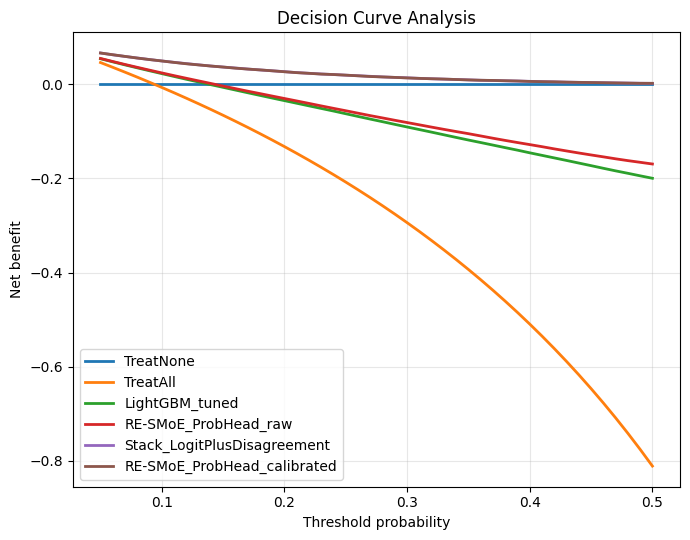

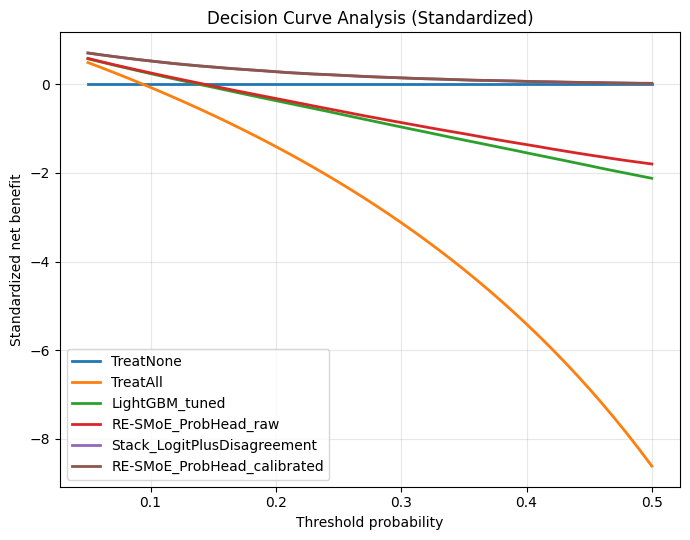

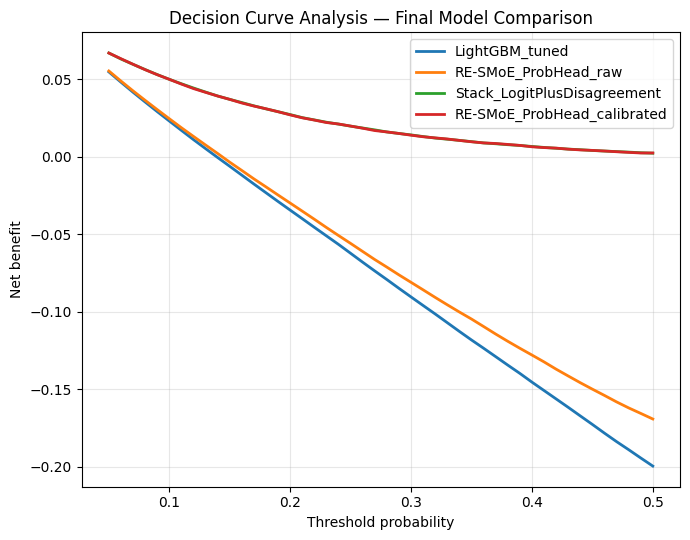


Module 11 complete.
Saved tables to: /kaggle/working/outputs/tables
Saved figures to: /kaggle/working/outputs/figures


In [13]:
# ============================================================
# Module 11 — Decision Curve Analysis (clinical utility)
# Goal:
#   Quantify clinical usefulness of the final models across
#   decision thresholds using net benefit.
#
# Inputs required:
#   - y_all
#   - oof_lgb_tuned
#   - p_prob_raw_m7
#   - p_stack_plus_disagreement
#   - optionally p_prob_final_m8
#
# Outputs:
#   - module11_dca_df
#   - module11_dca_summary_df
#   - DCA plots
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["y_all", "oof_lgb_tuned", "p_prob_raw_m7", "p_stack_plus_disagreement"]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 11: {missing_vars}")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

def decision_curve_net_benefit(y_true, p_pred, thresholds):
    y_true = np.asarray(y_true).astype(int)
    p_pred = clip_probs(p_pred)
    n = len(y_true)

    rows = []
    for pt in thresholds:
        pred = (p_pred >= pt).astype(int)

        tp = int(((pred == 1) & (y_true == 1)).sum())
        fp = int(((pred == 1) & (y_true == 0)).sum())

        odds = pt / max(1 - pt, 1e-12)
        nb = (tp / n) - (fp / n) * odds

        rows.append({
            "threshold": float(pt),
            "TP": tp,
            "FP": fp,
            "net_benefit": float(nb),
        })
    return pd.DataFrame(rows)

def treat_all_net_benefit(y_true, thresholds):
    y_true = np.asarray(y_true).astype(int)
    n = len(y_true)
    prevalence = float(y_true.mean())

    rows = []
    for pt in thresholds:
        odds = pt / max(1 - pt, 1e-12)
        nb = prevalence - (1 - prevalence) * odds
        rows.append({
            "threshold": float(pt),
            "net_benefit": float(nb),
        })
    return pd.DataFrame(rows)

def treat_none_net_benefit(thresholds):
    return pd.DataFrame({
        "threshold": thresholds,
        "net_benefit": np.zeros(len(thresholds), dtype=float)
    })

def standardized_net_benefit(nb, prevalence):
    return nb / max(prevalence, 1e-12)

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
y = y_all.astype(int)

p_lgb = clip_probs(oof_lgb_tuned)
p_prob = clip_probs(p_prob_raw_m7)
p_stack = clip_probs(p_stack_plus_disagreement)

# optional calibrated probability head if available
model_preds = {
    "LightGBM_tuned": p_lgb,
    "RE-SMoE_ProbHead_raw": p_prob,
    "Stack_LogitPlusDisagreement": p_stack,
}

if "p_prob_final_m8" in globals():
    model_preds["RE-SMoE_ProbHead_calibrated"] = clip_probs(p_prob_final_m8)

# ------------------------------------------------------------
# Threshold range
# For screening tasks, realistic range is often ~0.05 to 0.50
# ------------------------------------------------------------
thresholds = np.linspace(0.05, 0.50, 46)
prevalence = float(y.mean())

# ------------------------------------------------------------
# Compute DCA tables
# ------------------------------------------------------------
dca_rows = []

for name, p in model_preds.items():
    df_nb = decision_curve_net_benefit(y, p, thresholds)
    df_nb["model"] = name
    df_nb["std_net_benefit"] = df_nb["net_benefit"].apply(lambda x: standardized_net_benefit(x, prevalence))
    dca_rows.append(df_nb)

df_all = pd.concat(dca_rows, axis=0, ignore_index=True)

df_treat_all = treat_all_net_benefit(y, thresholds)
df_treat_all["model"] = "TreatAll"
df_treat_all["std_net_benefit"] = df_treat_all["net_benefit"].apply(lambda x: standardized_net_benefit(x, prevalence))

df_treat_none = treat_none_net_benefit(thresholds)
df_treat_none["model"] = "TreatNone"
df_treat_none["std_net_benefit"] = df_treat_none["net_benefit"].apply(lambda x: standardized_net_benefit(x, prevalence))

module11_dca_df = pd.concat([df_all, df_treat_all, df_treat_none], axis=0, ignore_index=True)
display(module11_dca_df.head(20))
module11_dca_df.to_csv(TAB_DIR / "module11_decision_curve_table.csv", index=False)

# ------------------------------------------------------------
# Summary table: average / max net benefit over practical ranges
# ------------------------------------------------------------
summary_rows = []
for name in module11_dca_df["model"].unique():
    tmp = module11_dca_df[module11_dca_df["model"] == name].copy()

    summary_rows.append({
        "model": name,
        "avg_NB_0.05_0.50": float(tmp["net_benefit"].mean()),
        "max_NB_0.05_0.50": float(tmp["net_benefit"].max()),
        "avg_stdNB_0.05_0.50": float(tmp["std_net_benefit"].mean()),
        "max_stdNB_0.05_0.50": float(tmp["std_net_benefit"].max()),
    })

module11_dca_summary_df = pd.DataFrame(summary_rows).sort_values(
    ["avg_NB_0.05_0.50", "max_NB_0.05_0.50"], ascending=[False, False]
).reset_index(drop=True)

display(module11_dca_summary_df)
module11_dca_summary_df.to_csv(TAB_DIR / "module11_decision_curve_summary.csv", index=False)

# ------------------------------------------------------------
# Plot 1: Net benefit
# ------------------------------------------------------------
plt.figure(figsize=(7, 5.5))

plot_order = [
    "TreatNone",
    "TreatAll",
    "LightGBM_tuned",
    "RE-SMoE_ProbHead_raw",
    "Stack_LogitPlusDisagreement",
    "RE-SMoE_ProbHead_calibrated",
]

for name in plot_order:
    if name not in module11_dca_df["model"].unique():
        continue
    tmp = module11_dca_df[module11_dca_df["model"] == name]
    plt.plot(tmp["threshold"], tmp["net_benefit"], label=name, linewidth=2)

plt.xlabel("Threshold probability")
plt.ylabel("Net benefit")
plt.title("Decision Curve Analysis")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "module11_decision_curve_net_benefit.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Plot 2: Standardized net benefit
# ------------------------------------------------------------
plt.figure(figsize=(7, 5.5))

for name in plot_order:
    if name not in module11_dca_df["model"].unique():
        continue
    tmp = module11_dca_df[module11_dca_df["model"] == name]
    plt.plot(tmp["threshold"], tmp["std_net_benefit"], label=name, linewidth=2)

plt.xlabel("Threshold probability")
plt.ylabel("Standardized net benefit")
plt.title("Decision Curve Analysis (Standardized)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "module11_decision_curve_standardized.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Plot 3: Focused plot on main contenders
# ------------------------------------------------------------
plt.figure(figsize=(7, 5.5))

main_models = [m for m in [
    "LightGBM_tuned",
    "RE-SMoE_ProbHead_raw",
    "Stack_LogitPlusDisagreement",
    "RE-SMoE_ProbHead_calibrated",
] if m in module11_dca_df["model"].unique()]

for name in main_models:
    tmp = module11_dca_df[module11_dca_df["model"] == name]
    plt.plot(tmp["threshold"], tmp["net_benefit"], label=name, linewidth=2)

plt.xlabel("Threshold probability")
plt.ylabel("Net benefit")
plt.title("Decision Curve Analysis — Final Model Comparison")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "module11_decision_curve_final_models.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nModule 11 complete.")
print(f"Saved tables to: {TAB_DIR}")
print(f"Saved figures to: {FIG_DIR}")

,threshold,predicted_high_risk_n,predicted_high_risk_pct,true_positive_n,true_positive_pct,false_positive_n,false_negative_n,precision,recall,model
0,0.05,212172,0.836377,23772,0.093709,188400,121,0.112041,0.994936,LightGBM_tuned
1,0.06,204812,0.807364,23736,0.093567,181076,157,0.115892,0.993429,LightGBM_tuned
2,0.07,198399,0.782084,23685,0.093366,174714,208,0.119381,0.991295,LightGBM_tuned
3,0.08,192669,0.759496,23635,0.093169,169034,258,0.122672,0.989202,LightGBM_tuned
4,0.09,187589,0.739471,23583,0.092964,164006,310,0.125716,0.987025,LightGBM_tuned
5,0.10,183074,0.721673,23548,0.092826,159526,345,0.128626,0.985561,LightGBM_tuned
6,0.11,178918,0.705290,23502,0.092644,155416,391,0.131356,0.983635,LightGBM_tuned
7,0.12,174947,0.689637,23439,0.092396,151508,454,0.133978,0.980999,LightGBM_tuned
8,0.13,171170,0.674748,23390,0.092203,147780,503,0.136648,0.978948,LightGBM_tuned
9,0.14,167599,0.660671,23335,0.091986,144264,558,0.139231,0.976646,LightGBM_tuned


,threshold,predicted_high_risk_n,predicted_high_risk_pct,true_positive_n,true_positive_pct,false_positive_n,false_negative_n,precision,recall,model
0,0.10,183074,0.721673,23548,0.092826,159526,345,0.128626,0.985561,LightGBM_tuned
1,0.15,164211,0.647316,23286,0.091793,140925,607,0.141805,0.974595,LightGBM_tuned
2,0.20,150106,0.591714,23016,0.090728,127090,877,0.153332,0.963295,LightGBM_tuned
3,0.25,138339,0.545329,22718,0.089554,115621,1175,0.164220,0.950822,LightGBM_tuned
4,0.30,128247,0.505546,22398,0.088292,105849,1495,0.174647,0.937429,LightGBM_tuned
5,0.10,179251,0.706603,23505,0.092656,155746,388,0.131129,0.983761,RE-SMoE_ProbHead_raw
6,0.15,159815,0.629987,23196,0.091438,136619,697,0.145143,0.970828,RE-SMoE_ProbHead_raw
7,0.20,144969,0.571464,22911,0.090315,122058,982,0.158041,0.958900,RE-SMoE_ProbHead_raw
8,0.25,132916,0.523951,22575,0.088990,110341,1318,0.169844,0.944837,RE-SMoE_ProbHead_raw
9,0.30,121912,0.480574,22170,0.087394,99742,1723,0.181852,0.927887,RE-SMoE_ProbHead_raw


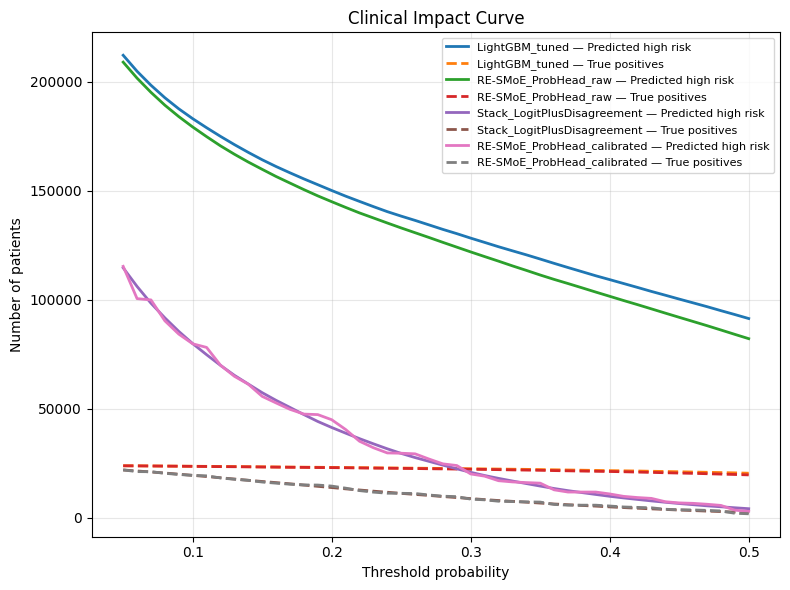

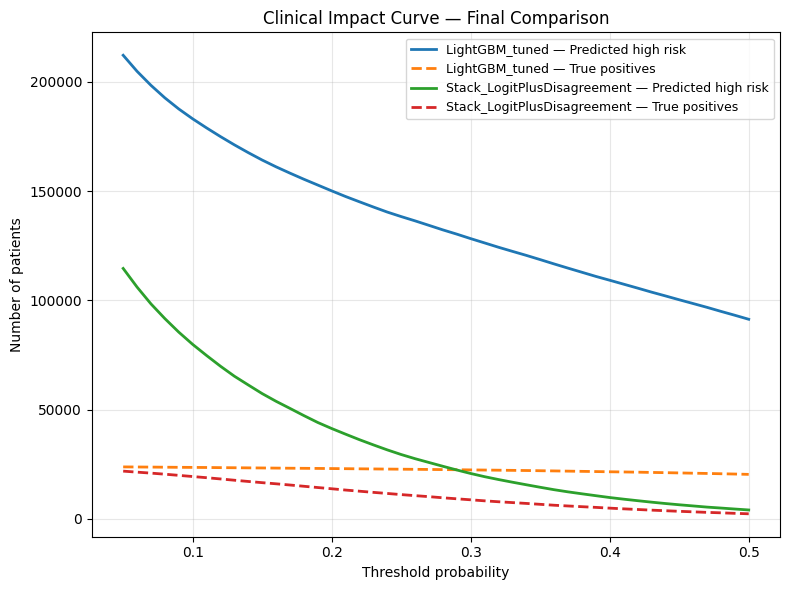

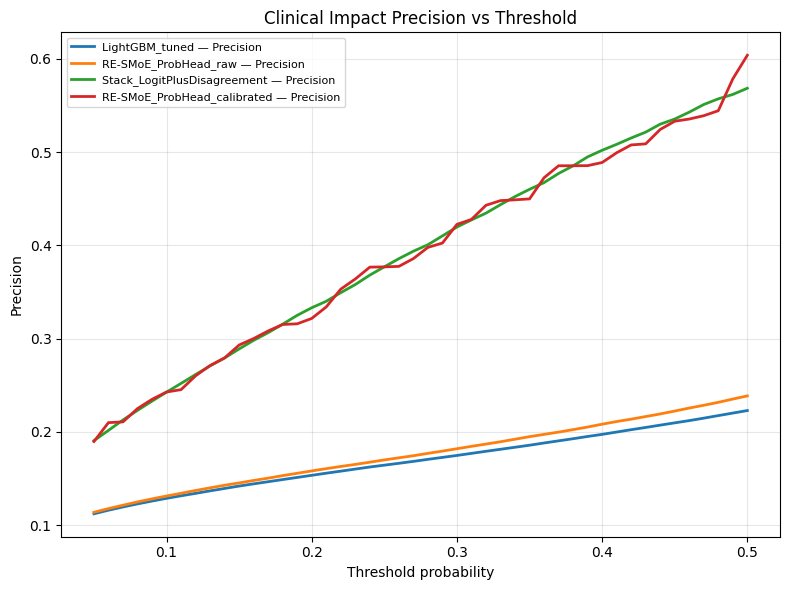

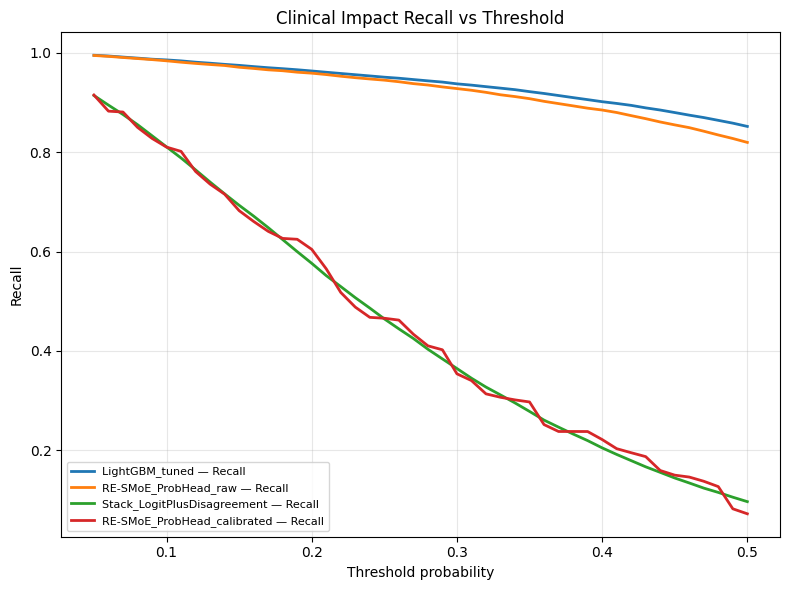

,model,threshold,predicted_high_risk_n,true_positive_n,precision,recall
0,LightGBM_tuned,0.10,183074,23548,0.128626,0.985561
1,LightGBM_tuned,0.15,164211,23286,0.141805,0.974595
2,LightGBM_tuned,0.20,150106,23016,0.153332,0.963295
3,LightGBM_tuned,0.25,138339,22718,0.164220,0.950822
4,LightGBM_tuned,0.30,128247,22398,0.174647,0.937429
5,RE-SMoE_ProbHead_raw,0.10,179251,23505,0.131129,0.983761
6,RE-SMoE_ProbHead_raw,0.15,159815,23196,0.145143,0.970828
7,RE-SMoE_ProbHead_raw,0.20,144969,22911,0.158041,0.958900
8,RE-SMoE_ProbHead_raw,0.25,132916,22575,0.169844,0.944837
9,RE-SMoE_ProbHead_raw,0.30,121912,22170,0.181852,0.927887



Module 11B complete.
Saved tables to: /kaggle/working/outputs/tables
Saved figures to: /kaggle/working/outputs/figures


In [14]:
# ============================================================
# Module 11B — Clinical Impact Curve (CIC) + screening workload tables
# Goal:
#   Add a clinically interpretable evaluation showing:
#     1) how many patients would be flagged high-risk
#     2) how many of those are true positives
#
# This is especially useful for screening / triage papers and pairs well
# with DCA.
#
# Inputs required:
#   - y_all
#   - oof_lgb_tuned
#   - p_prob_raw_m7
#   - p_stack_plus_disagreement
#   - optionally p_prob_final_m8
#
# Outputs:
#   - module11b_cic_df
#   - module11b_cic_summary_df
#   - CIC plots
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Safety checks
# ------------------------------------------------------------
required_vars = ["y_all", "oof_lgb_tuned", "p_prob_raw_m7", "p_stack_plus_disagreement"]
missing_vars = [v for v in required_vars if v not in globals()]
if missing_vars:
    raise ValueError(f"Missing required variables for Module 11B: {missing_vars}")

# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------
def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

def clinical_impact_curve(y_true, p_pred, thresholds):
    """
    For each threshold:
      - predicted_high_risk_n: number of samples predicted positive
      - true_positive_n: number of actual positives among predicted positive
      - precision: PPV at that threshold
      - recall: sensitivity at that threshold
    """
    y_true = np.asarray(y_true).astype(int)
    p_pred = clip_probs(p_pred)
    n = len(y_true)

    rows = []
    for pt in thresholds:
        pred = (p_pred >= pt).astype(int)

        high_risk_n = int(pred.sum())
        true_pos_n = int(((pred == 1) & (y_true == 1)).sum())
        false_pos_n = int(((pred == 1) & (y_true == 0)).sum())
        false_neg_n = int(((pred == 0) & (y_true == 1)).sum())

        precision = true_pos_n / max(high_risk_n, 1)
        recall = true_pos_n / max(int(y_true.sum()), 1)

        rows.append({
            "threshold": float(pt),
            "predicted_high_risk_n": high_risk_n,
            "predicted_high_risk_pct": high_risk_n / n,
            "true_positive_n": true_pos_n,
            "true_positive_pct": true_pos_n / n,
            "false_positive_n": false_pos_n,
            "false_negative_n": false_neg_n,
            "precision": float(precision),
            "recall": float(recall),
        })
    return pd.DataFrame(rows)

def summarize_cic(df_cic, model_name, threshold_points=(0.10, 0.15, 0.20, 0.25, 0.30)):
    rows = []
    for t in threshold_points:
        idx = np.argmin(np.abs(df_cic["threshold"].values - t))
        row = df_cic.iloc[idx].to_dict()
        row["model"] = model_name
        rows.append(row)
    return pd.DataFrame(rows)

# ------------------------------------------------------------
# Inputs
# ------------------------------------------------------------
y = y_all.astype(int)

p_lgb = clip_probs(oof_lgb_tuned)
p_prob = clip_probs(p_prob_raw_m7)
p_stack = clip_probs(p_stack_plus_disagreement)

model_preds = {
    "LightGBM_tuned": p_lgb,
    "RE-SMoE_ProbHead_raw": p_prob,
    "Stack_LogitPlusDisagreement": p_stack,
}

if "p_prob_final_m8" in globals():
    model_preds["RE-SMoE_ProbHead_calibrated"] = clip_probs(p_prob_final_m8)

# ------------------------------------------------------------
# Threshold range
# ------------------------------------------------------------
thresholds = np.linspace(0.05, 0.50, 46)

# ------------------------------------------------------------
# Compute CIC tables
# ------------------------------------------------------------
cic_rows = []
cic_summary_parts = []

for name, p in model_preds.items():
    df_cic = clinical_impact_curve(y, p, thresholds)
    df_cic["model"] = name
    cic_rows.append(df_cic)

    cic_summary_parts.append(
        summarize_cic(df_cic, name, threshold_points=(0.10, 0.15, 0.20, 0.25, 0.30))
    )

module11b_cic_df = pd.concat(cic_rows, axis=0, ignore_index=True)
module11b_cic_summary_df = pd.concat(cic_summary_parts, axis=0, ignore_index=True)

display(module11b_cic_df.head(20))
display(module11b_cic_summary_df)

module11b_cic_df.to_csv(TAB_DIR / "module11b_clinical_impact_curve_full.csv", index=False)
module11b_cic_summary_df.to_csv(TAB_DIR / "module11b_clinical_impact_curve_summary.csv", index=False)

# ------------------------------------------------------------
# Plot 1 — Clinical impact curve for final models
#   Solid line: predicted high risk
#   Dashed line: true positives among predicted high risk
# ------------------------------------------------------------
plot_models = [
    "LightGBM_tuned",
    "RE-SMoE_ProbHead_raw",
    "Stack_LogitPlusDisagreement",
    "RE-SMoE_ProbHead_calibrated",
]
plot_models = [m for m in plot_models if m in module11b_cic_df["model"].unique()]

plt.figure(figsize=(8, 6))

for name in plot_models:
    tmp = module11b_cic_df[module11b_cic_df["model"] == name].copy()

    plt.plot(
        tmp["threshold"],
        tmp["predicted_high_risk_n"],
        linewidth=2,
        label=f"{name} — Predicted high risk"
    )
    plt.plot(
        tmp["threshold"],
        tmp["true_positive_n"],
        linewidth=2,
        linestyle="--",
        label=f"{name} — True positives"
    )

plt.xlabel("Threshold probability")
plt.ylabel("Number of patients")
plt.title("Clinical Impact Curve")
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "module11b_clinical_impact_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Plot 2 — Focused final comparison
# ------------------------------------------------------------
main_models = [m for m in ["LightGBM_tuned", "Stack_LogitPlusDisagreement"] if m in module11b_cic_df["model"].unique()]

plt.figure(figsize=(8, 6))

for name in main_models:
    tmp = module11b_cic_df[module11b_cic_df["model"] == name].copy()

    plt.plot(
        tmp["threshold"],
        tmp["predicted_high_risk_n"],
        linewidth=2,
        label=f"{name} — Predicted high risk"
    )
    plt.plot(
        tmp["threshold"],
        tmp["true_positive_n"],
        linewidth=2,
        linestyle="--",
        label=f"{name} — True positives"
    )

plt.xlabel("Threshold probability")
plt.ylabel("Number of patients")
plt.title("Clinical Impact Curve — Final Comparison")
plt.grid(alpha=0.3)
plt.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "module11b_clinical_impact_curve_final_compare.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Plot 3 — Precision and recall vs threshold
# ------------------------------------------------------------
plt.figure(figsize=(8, 6))

for name in plot_models:
    tmp = module11b_cic_df[module11b_cic_df["model"] == name].copy()
    plt.plot(tmp["threshold"], tmp["precision"], linewidth=2, label=f"{name} — Precision")

plt.xlabel("Threshold probability")
plt.ylabel("Precision")
plt.title("Clinical Impact Precision vs Threshold")
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "module11b_precision_vs_threshold.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 6))

for name in plot_models:
    tmp = module11b_cic_df[module11b_cic_df["model"] == name].copy()
    plt.plot(tmp["threshold"], tmp["recall"], linewidth=2, label=f"{name} — Recall")

plt.xlabel("Threshold probability")
plt.ylabel("Recall")
plt.title("Clinical Impact Recall vs Threshold")
plt.grid(alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "module11b_recall_vs_threshold.png", dpi=300, bbox_inches="tight")
plt.show()

# ------------------------------------------------------------
# Optional compact decision table at a few thresholds
# ------------------------------------------------------------
focus_thresholds = [0.10, 0.15, 0.20, 0.25, 0.30]
compact_rows = []

for model_name in model_preds.keys():
    tmp = module11b_cic_df[module11b_cic_df["model"] == model_name].copy()
    for t in focus_thresholds:
        idx = np.argmin(np.abs(tmp["threshold"].values - t))
        row = tmp.iloc[idx].to_dict()
        compact_rows.append({
            "model": model_name,
            "threshold": float(row["threshold"]),
            "predicted_high_risk_n": int(row["predicted_high_risk_n"]),
            "true_positive_n": int(row["true_positive_n"]),
            "precision": float(row["precision"]),
            "recall": float(row["recall"]),
        })

module11b_compact_table_df = pd.DataFrame(compact_rows)
display(module11b_compact_table_df)
module11b_compact_table_df.to_csv(TAB_DIR / "module11b_clinical_impact_compact_table.csv", index=False)

print("\nModule 11B complete.")
print(f"Saved tables to: {TAB_DIR}")
print(f"Saved figures to: {FIG_DIR}")

## Final Final

Setup complete.
Project        : Proposed Model
Primary metric : PR_AUC
Output dir     : /kaggle/working/outputs
Loaded: /kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv
Raw shape: (253680, 22)

===== Target Summary =====
Target         : HeartDiseaseorAttack
N              : 253,680
Positive count : 23,893
Negative count : 229,787
Positive rate  : 0.094186
Negative rate  : 0.905814

===== Feature Groups =====
Total features   : 21
Binary features  : 14
Ordinal features : 4
Continuous feats : 3


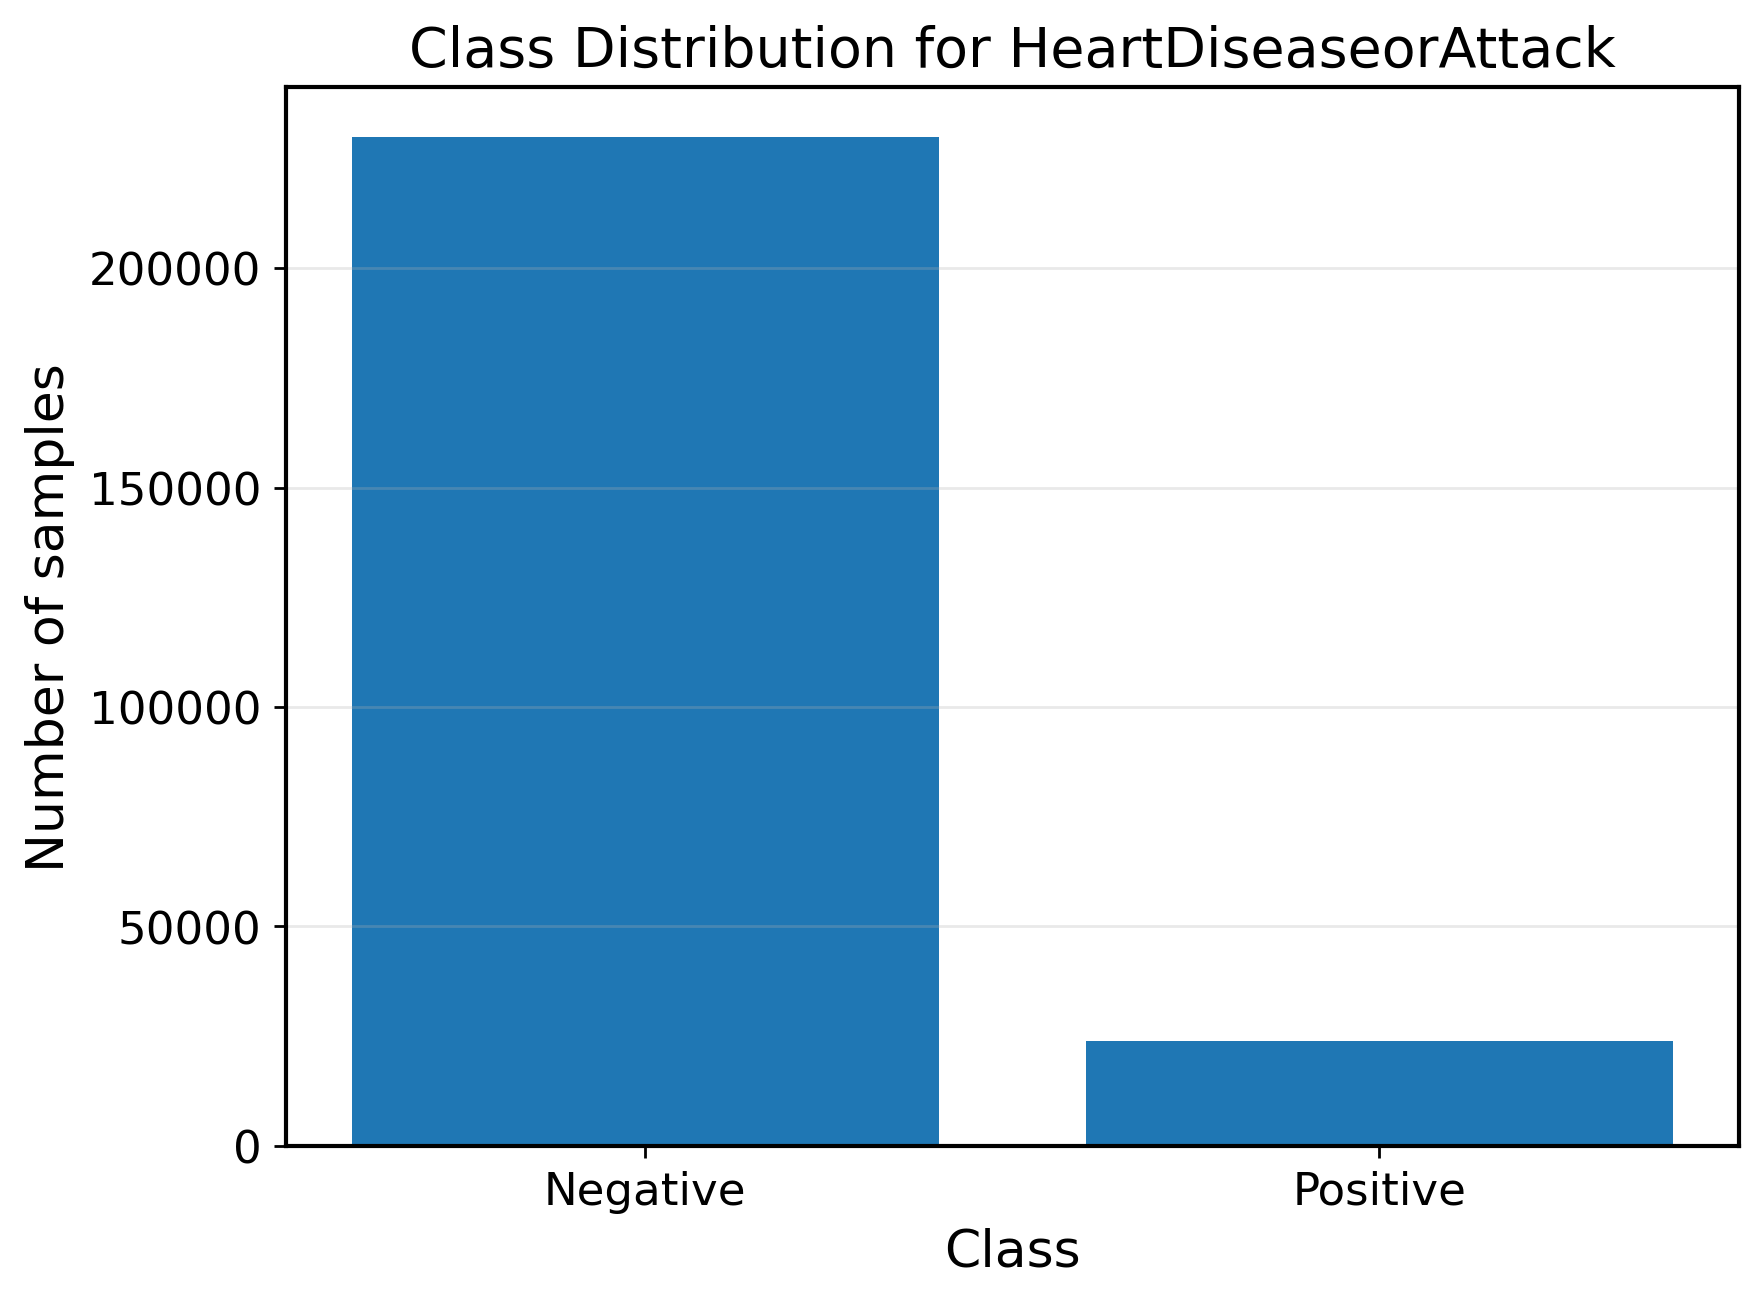

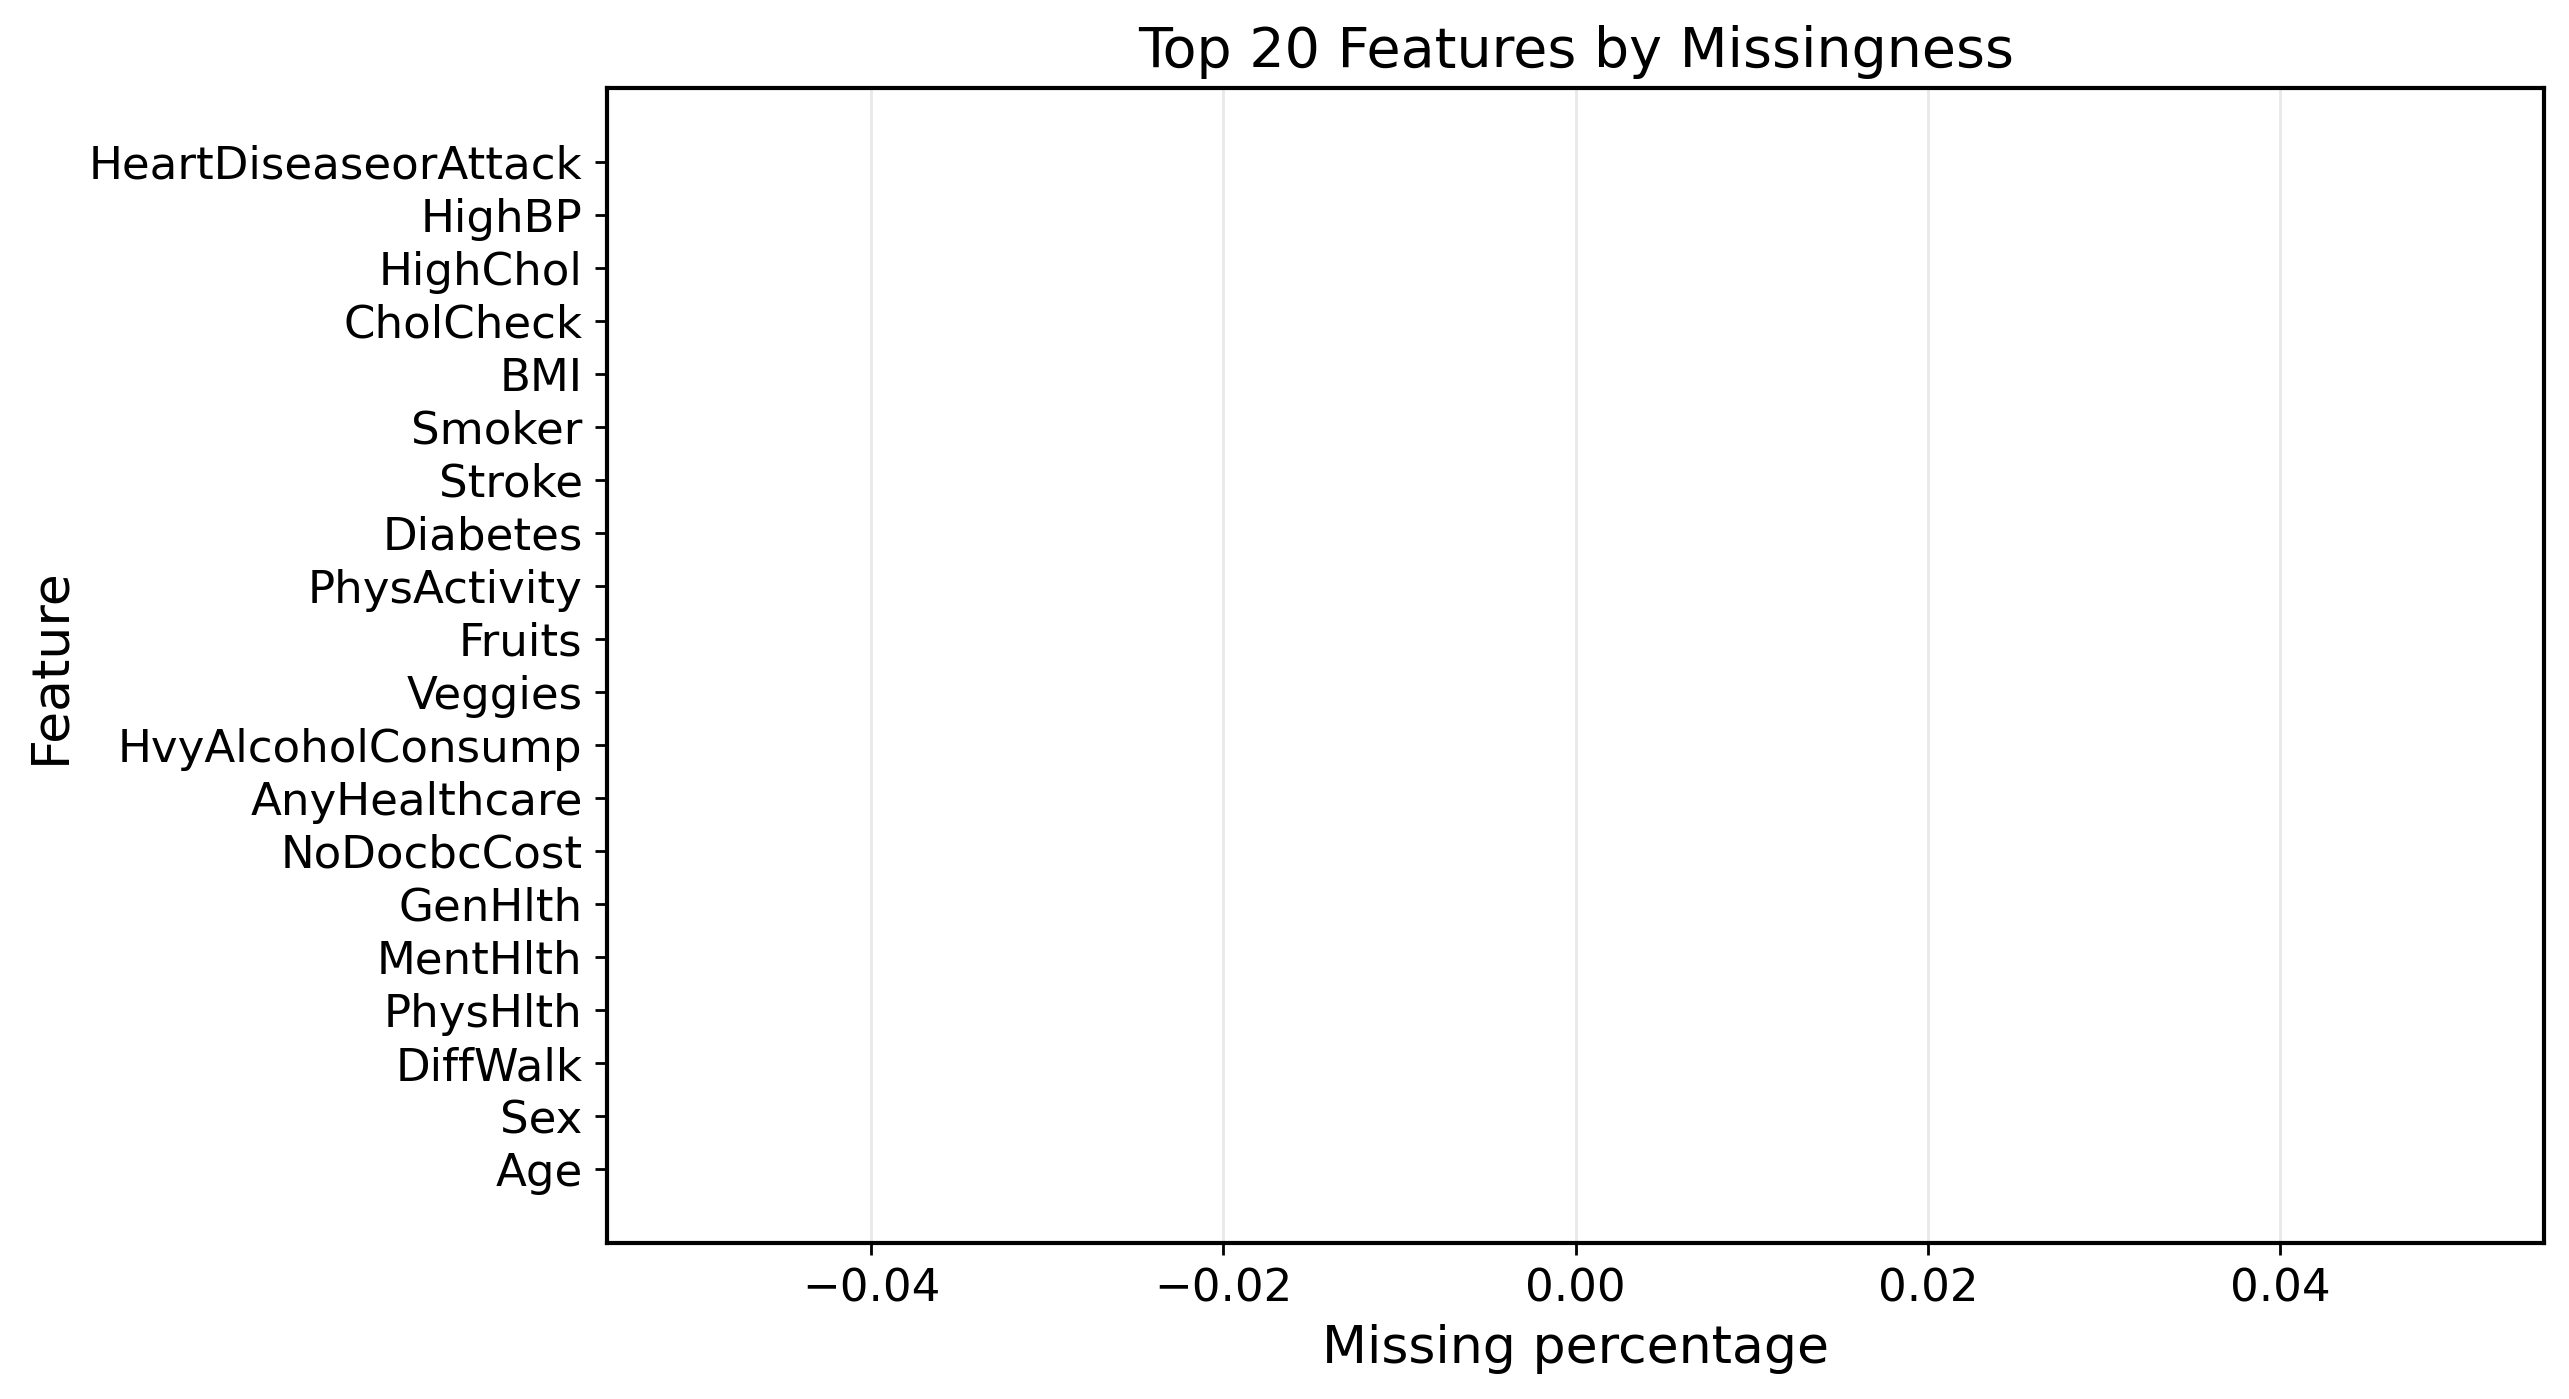


Module 1 complete.
   fold  train_size  valid_size  train_pos_rate  valid_pos_rate
0     1      202944       50736        0.094189        0.094174
1     2      202944       50736        0.094189        0.094174
2     3      202944       50736        0.094184        0.094193
3     4      202944       50736        0.094184        0.094193
4     5      202944       50736        0.094184        0.094193

Baseline evaluation:
                model    PR_AUC  ROC_AUC     Brier       NLL           ECE  \
0  PrevalenceBaseline  0.094186      0.5  0.085315  0.312116  2.775558e-17   

            MCE    p_mean  pos_rate       N  ...  F1@bestF1  Acc@bestF1  \
0  2.775558e-17  0.094186  0.094186  253680  ...   0.172157    0.094186   

   BalAcc@bestF1  MCC@bestF1  thr_P>=0.30  Rec@P>=0.30  F1@P>=0.30  \
0            0.5         0.0          NaN          0.0         0.0   

   thr_R>=0.50  Prec@R>=0.50  F1@R>=0.50  
0        0.094      0.094186    0.172157  

[1 rows x 23 columns]

Module 2 comple

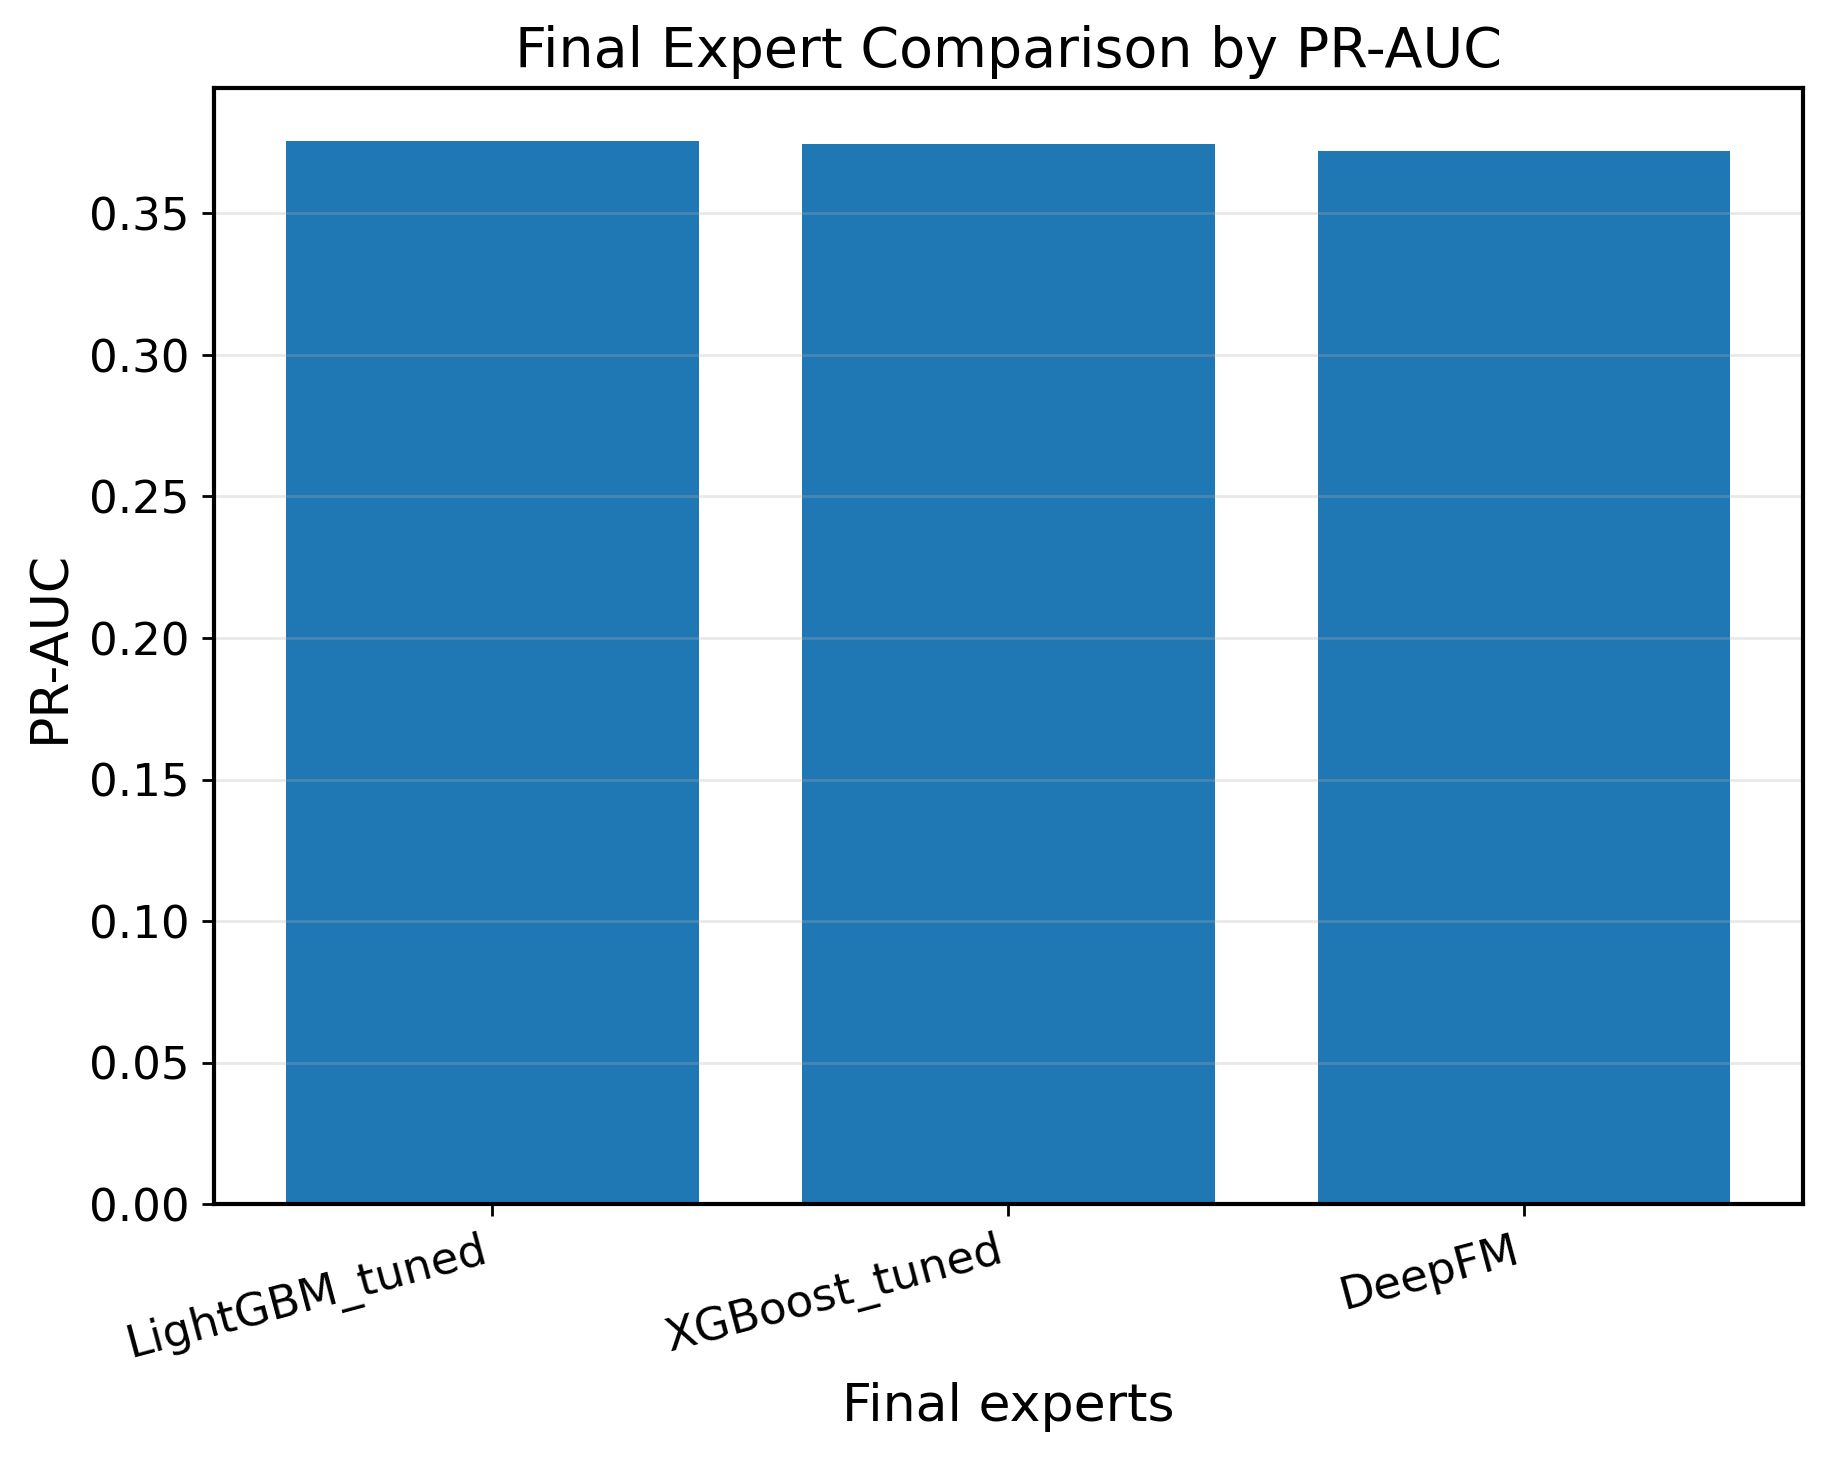


Module 4 complete.
Saved OOF predictions for downstream fusion modules.


In [1]:
# ============================================================
# Proposed Model — Paper-Oriented Main Notebook (Modules 0–4)
# Scope in this file:
#   Module 0 — Setup and publication configuration
#   Module 1 — Data loading and audit
#   Module 2 — Leakage-safe evaluation protocol + metrics
#   Module 3 — Preprocessing utilities
#   Module 4 — Final experts only
#       1) LightGBM_tuned
#       2) XGBoost_tuned
#       3) DeepFM
#
# Notes:
# - Use the name "Proposed Model" everywhere in tables/figures/text outputs.
# - Figures are exported in high quality with large font sizes suitable for papers.
# - This pipeline is designed for Kaggle Notebook execution.
# - Outputs are saved under /kaggle/working/outputs
# ============================================================

# ============================================================
# Module 0 — Setup and publication configuration
# ============================================================

import os
import gc
import json
import math
import time
import random
import warnings
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    balanced_accuracy_score,
    matthews_corrcoef,
)

warnings.filterwarnings("ignore")

# Optional packages loaded later when needed
# import lightgbm as lgb
# import xgboost as xgb
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# from torch.utils.data import Dataset, DataLoader

# -------------------------
# Reproducibility
# -------------------------
SEED = 42
N_SPLITS = 5
TARGET = "HeartDiseaseorAttack"
PRIMARY_METRIC = "PR_AUC"
PROJECT_NAME = "Proposed Model"


def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    except Exception:
        pass


seed_everything(SEED)

# -------------------------
# Paths
# -------------------------
ROOT_DIR = Path("/kaggle/working")
OUT_DIR = ROOT_DIR / "outputs"
FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
PRED_DIR = OUT_DIR / "preds"
MOD_DIR = OUT_DIR / "models"
LOG_DIR = OUT_DIR / "logs"

for d in [OUT_DIR, FIG_DIR, TAB_DIR, PRED_DIR, MOD_DIR, LOG_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# -------------------------
# Publication-quality plotting config
# -------------------------
PLOT_DPI = 400
SAVE_FIG_FORMATS = ["png", "pdf"]

plt.rcParams.update({
    "figure.dpi": 250,
    "savefig.dpi": PLOT_DPI,
    "figure.figsize": (8, 6),
    "axes.titlesize": 16,
    "axes.labelsize": 15,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 9,
    "font.size": 12,
    "axes.linewidth": 1.2,
    "lines.linewidth": 2.2,
    "grid.alpha": 0.28,
})


def save_figure_multi(base_path: Path):
    """Save current matplotlib figure in all configured formats."""
    for ext in SAVE_FIG_FORMATS:
        plt.savefig(base_path.with_suffix(f".{ext}"), bbox_inches="tight")


# -------------------------
# Data path candidates
# -------------------------
DATA_PATH_CANDIDATES = [
    "/kaggle/input/datasets/alexteboul/heart-disease-health-indicators-dataset/heart_disease_health_indicators_BRFSS2015.csv",
    "/kaggle/input/heart-disease-health-indicators-dataset/Heart_Disease_Health_Indicators_BRFSS2015.csv",
    "/kaggle/input/heart-disease-health-indicators-dataset/heart_disease_health_indicators.csv",
]

# -------------------------
# Environment log
# -------------------------
meta_info = {
    "project_name": PROJECT_NAME,
    "seed": SEED,
    "target": TARGET,
    "n_splits": N_SPLITS,
    "primary_metric": PRIMARY_METRIC,
    "python_version": platform.python_version(),
    "platform": platform.platform(),
    "timestamp": time.strftime("%Y-%m-%d %H:%M:%S"),
}

with open(LOG_DIR / "module0_environment.json", "w") as f:
    json.dump(meta_info, f, indent=2)

print("Setup complete.")
print(f"Project        : {PROJECT_NAME}")
print(f"Primary metric : {PRIMARY_METRIC}")
print(f"Output dir     : {OUT_DIR}")


# ============================================================
# Module 1 — Data loading and audit
# ============================================================

def find_data_path(candidates):
    for p in candidates:
        if os.path.exists(p):
            return p
    return None


DATA_PATH = find_data_path(DATA_PATH_CANDIDATES)
if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset CSV not found. Please update DATA_PATH_CANDIDATES with the correct Kaggle input path."
    )


df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Raw shape:", df.shape)

df = df.copy()
df.columns = [c.strip() for c in df.columns]

if TARGET not in df.columns:
    raise ValueError(f"Target column '{TARGET}' not found. Available columns: {list(df.columns)}")

# Target cleanup
# The BRFSS heart disease target is binary in this study.
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.dropna(subset=[TARGET]).reset_index(drop=True)
df[TARGET] = df[TARGET].astype(int)

FEATURES = [c for c in df.columns if c != TARGET]

# Typed feature groups based on known BRFSS schema
CONT_COLS = [c for c in ["BMI", "MentHlth", "PhysHlth"] if c in FEATURES]
ORDINAL_COLS = [c for c in ["GenHlth", "Age", "Education", "Income"] if c in FEATURES]
BINARY_COLS = [c for c in FEATURES if c not in CONT_COLS + ORDINAL_COLS]
OTHER_COLS = [c for c in FEATURES if c not in BINARY_COLS + ORDINAL_COLS + CONT_COLS]

X_all = df[FEATURES].copy()
y_all = df[TARGET].astype(int).values

pos_n = int(y_all.sum())
neg_n = int((y_all == 0).sum())
pos_rate = float(y_all.mean())
neg_rate = 1.0 - pos_rate

print("\n===== Target Summary =====")
print(f"Target         : {TARGET}")
print(f"N              : {len(y_all):,}")
print(f"Positive count : {pos_n:,}")
print(f"Negative count : {neg_n:,}")
print(f"Positive rate  : {pos_rate:.6f}")
print(f"Negative rate  : {neg_rate:.6f}")

print("\n===== Feature Groups =====")
print(f"Total features   : {len(FEATURES)}")
print(f"Binary features  : {len(BINARY_COLS)}")
print(f"Ordinal features : {len(ORDINAL_COLS)}")
print(f"Continuous feats : {len(CONT_COLS)}")
if OTHER_COLS:
    print(f"Other/Unexpected : {OTHER_COLS}")

# -------------------------
# Audit table
# -------------------------
audit_rows = []
for c in [TARGET] + FEATURES:
    s = df[c]
    s_num = pd.to_numeric(s, errors="coerce")
    audit_rows.append({
        "column": c,
        "dtype": str(s.dtype),
        "missing_n": int(s.isna().sum()),
        "missing_pct": float(s.isna().mean() * 100),
        "n_unique": int(s.nunique(dropna=True)),
        "min": float(s_num.min()) if s_num.notna().any() else np.nan,
        "max": float(s_num.max()) if s_num.notna().any() else np.nan,
    })

audit_df = pd.DataFrame(audit_rows)
feature_group_df = pd.DataFrame({
    "feature": FEATURES,
    "group": [
        "continuous" if c in CONT_COLS else
        "ordinal" if c in ORDINAL_COLS else
        "binary" if c in BINARY_COLS else
        "other"
        for c in FEATURES
    ]
})

dataset_summary_df = pd.DataFrame([{
    "project_name": PROJECT_NAME,
    "dataset_path": DATA_PATH,
    "target": TARGET,
    "n_samples": len(df),
    "n_features": len(FEATURES),
    "positive_n": pos_n,
    "negative_n": neg_n,
    "positive_rate": pos_rate,
    "negative_rate": neg_rate,
}])

audit_df.to_csv(TAB_DIR / "module1_feature_audit.csv", index=False)
feature_group_df.to_csv(TAB_DIR / "module1_feature_groups.csv", index=False)
dataset_summary_df.to_csv(TAB_DIR / "module1_dataset_summary.csv", index=False)

# -------------------------
# Publication-quality audit figures
# -------------------------
plt.figure(figsize=(7.5, 5.5))
plt.bar(["Negative", "Positive"], [neg_n, pos_n])
plt.ylabel("Number of samples")
plt.xlabel("Class")
plt.title(f"Class Distribution for {TARGET}")
plt.grid(axis="y")
save_figure_multi(FIG_DIR / "module1_class_distribution")
plt.show()

missing_plot_df = audit_df.sort_values("missing_pct", ascending=False).head(20)
plt.figure(figsize=(10, 6))
plt.barh(missing_plot_df["column"], missing_plot_df["missing_pct"])
plt.xlabel("Missing percentage")
plt.ylabel("Feature")
plt.title("Top 20 Features by Missingness")
plt.gca().invert_yaxis()
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "module1_top_missingness")
plt.show()

print("\nModule 1 complete.")


# ============================================================
# Module 2 — Leakage-safe evaluation protocol + metrics
# ============================================================

skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

cv_rows = []
for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all), 1):
    cv_rows.append({
        "fold": fold,
        "train_size": int(len(tr_idx)),
        "valid_size": int(len(te_idx)),
        "train_pos_rate": float(y_all[tr_idx].mean()),
        "valid_pos_rate": float(y_all[te_idx].mean()),
    })

cv_split_df = pd.DataFrame(cv_rows)
cv_split_df.to_csv(TAB_DIR / "module2_cv_splits_summary.csv", index=False)
print(cv_split_df)


def expected_calibration_error(y_true, p, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    p = np.clip(np.asarray(p).astype(float), 1e-8, 1 - 1e-8)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    mce = 0.0

    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        if i < n_bins - 1:
            mask = (p >= lo) & (p < hi)
        else:
            mask = (p >= lo) & (p <= hi)

        if mask.sum() == 0:
            continue

        acc = y_true[mask].mean()
        conf = p[mask].mean()
        err = abs(acc - conf)
        ece += (mask.sum() / len(p)) * err
        mce = max(mce, err)

    return float(ece), float(mce)


def evaluate_probs(y_true, p, name="model"):
    y_true = np.asarray(y_true).astype(int)
    p = np.clip(np.asarray(p).astype(float), 1e-8, 1 - 1e-8)

    pr_auc = average_precision_score(y_true, p)
    roc_auc = roc_auc_score(y_true, p)
    brier = brier_score_loss(y_true, p)
    nll = log_loss(y_true, p)
    ece, mce = expected_calibration_error(y_true, p, n_bins=15)

    precisions, recalls, thresholds = precision_recall_curve(y_true, p)
    f1_vals = 2 * precisions * recalls / (precisions + recalls + 1e-12)
    best_idx = int(np.nanargmax(f1_vals))
    thr_best = 0.5 if len(thresholds) == 0 else float(thresholds[max(best_idx - 1, 0)])

    pred_best = (p >= thr_best).astype(int)
    prec_best = float(precision_score(y_true, pred_best, zero_division=0))
    rec_best = float(recall_score(y_true, pred_best, zero_division=0))
    f1_best = float(f1_score(y_true, pred_best, zero_division=0))
    acc_best = float(accuracy_score(y_true, pred_best))
    bal_best = float(balanced_accuracy_score(y_true, pred_best))
    mcc_best = float(matthews_corrcoef(y_true, pred_best)) if len(np.unique(pred_best)) > 1 else 0.0

    # Precision >= 0.30, choose threshold with max recall
    thr_p30, rec_p30, f1_p30 = np.nan, 0.0, 0.0
    for t in np.linspace(0.0, 1.0, 2001):
        pred = (p >= t).astype(int)
        pr = precision_score(y_true, pred, zero_division=0)
        if pr >= 0.30:
            rc = recall_score(y_true, pred, zero_division=0)
            f1_ = f1_score(y_true, pred, zero_division=0)
            thr_p30, rec_p30, f1_p30 = float(t), float(rc), float(f1_)
            break

    # Recall >= 0.50, choose threshold with max precision
    thr_r50, prec_r50, f1_r50 = np.nan, 0.0, 0.0
    for t in np.linspace(0.0, 1.0, 2001)[::-1]:
        pred = (p >= t).astype(int)
        rc = recall_score(y_true, pred, zero_division=0)
        if rc >= 0.50:
            pr = precision_score(y_true, pred, zero_division=0)
            f1_ = f1_score(y_true, pred, zero_division=0)
            thr_r50, prec_r50, f1_r50 = float(t), float(pr), float(f1_)
            break

    return {
        "model": name,
        "PR_AUC": float(pr_auc),
        "ROC_AUC": float(roc_auc),
        "Brier": float(brier),
        "NLL": float(nll),
        "ECE": float(ece),
        "MCE": float(mce),
        "p_mean": float(p.mean()),
        "pos_rate": float(y_true.mean()),
        "N": int(len(y_true)),
        "thr_bestF1": float(thr_best),
        "Prec@bestF1": float(prec_best),
        "Rec@bestF1": float(rec_best),
        "F1@bestF1": float(f1_best),
        "Acc@bestF1": float(acc_best),
        "BalAcc@bestF1": float(bal_best),
        "MCC@bestF1": float(mcc_best),
        "thr_P>=0.30": float(thr_p30) if not np.isnan(thr_p30) else np.nan,
        "Rec@P>=0.30": float(rec_p30),
        "F1@P>=0.30": float(f1_p30),
        "thr_R>=0.50": float(thr_r50) if not np.isnan(thr_r50) else np.nan,
        "Prec@R>=0.50": float(prec_r50),
        "F1@R>=0.50": float(f1_r50),
    }


baseline_p = np.full_like(y_all, fill_value=float(y_all.mean()), dtype=float)
baseline_eval = pd.DataFrame([evaluate_probs(y_all, baseline_p, name="PrevalenceBaseline")])
baseline_eval.to_csv(TAB_DIR / "module2_prevalence_baseline_metrics.csv", index=False)
print("\nBaseline evaluation:")
print(baseline_eval)

print("\nModule 2 complete.")


# ============================================================
# Module 3 — Preprocessing utilities
# ============================================================

def safe_numeric_series(s, fill_value=0.0):
    s = pd.to_numeric(s, errors="coerce")
    s = s.replace([np.inf, -np.inf], np.nan)
    return s.fillna(fill_value)


def sanitize_binary_series(s):
    s = safe_numeric_series(s, fill_value=0.0)
    s = np.round(s).astype(np.int64)
    s = np.clip(s, 0, 1)
    return s


def sanitize_ordinal_series(s, min_value=None, max_value=None, fill_value=0):
    s = safe_numeric_series(s, fill_value=fill_value)
    s = np.round(s).astype(np.int64)
    if min_value is not None:
        s = np.maximum(s, min_value)
    if max_value is not None:
        s = np.minimum(s, max_value)
    return s


def sanitize_continuous_series(s, fill_strategy="median"):
    s = pd.to_numeric(s, errors="coerce").replace([np.inf, -np.inf], np.nan)
    if fill_strategy == "median":
        fill_value = float(s.median()) if s.notna().any() else 0.0
    elif fill_strategy == "mean":
        fill_value = float(s.mean()) if s.notna().any() else 0.0
    else:
        fill_value = 0.0
    return s.fillna(fill_value).astype(np.float32)


def sanitize_dataframe(X_df: pd.DataFrame) -> pd.DataFrame:
    X_df = X_df.copy()

    for c in BINARY_COLS:
        if c in X_df.columns:
            X_df[c] = sanitize_binary_series(X_df[c])

    ordinal_bounds = {
        "GenHlth": (1, 5),
        "Age": (1, 13),
        "Education": (1, 6),
        "Income": (1, 8),
    }

    for c in ORDINAL_COLS:
        if c in X_df.columns:
            lo, hi = ordinal_bounds.get(c, (None, None))
            fill_value = lo if lo is not None else 0
            X_df[c] = sanitize_ordinal_series(X_df[c], min_value=lo, max_value=hi, fill_value=fill_value)

    for c in CONT_COLS:
        if c in X_df.columns:
            X_df[c] = sanitize_continuous_series(X_df[c], fill_strategy="median")

    for c in X_df.columns:
        if c not in BINARY_COLS + ORDINAL_COLS + CONT_COLS:
            X_df[c] = sanitize_continuous_series(X_df[c], fill_strategy="median")

    return X_df


def make_ml_matrix(X_df: pd.DataFrame) -> pd.DataFrame:
    X_df = sanitize_dataframe(X_df)
    return X_df[FEATURES].copy()


def fit_standard_scaler_on_train(X_train_df: pd.DataFrame):
    X_train_df = sanitize_dataframe(X_train_df)
    scaler_info = {"continuous_cols": CONT_COLS.copy(), "means": {}, "stds": {}}
    for c in CONT_COLS:
        vals = X_train_df[c].values.astype(np.float32)
        mean_ = float(vals.mean())
        std_ = float(vals.std())
        scaler_info["means"][c] = mean_
        scaler_info["stds"][c] = std_ if std_ >= 1e-8 else 1.0
    return scaler_info


def transform_with_standard_scaler(X_df: pd.DataFrame, scaler_info: dict) -> pd.DataFrame:
    X_df = sanitize_dataframe(X_df)
    for c in scaler_info["continuous_cols"]:
        if c in X_df.columns:
            X_df[c] = (X_df[c].astype(np.float32) - scaler_info["means"][c]) / scaler_info["stds"][c]
    return X_df


def make_dl_matrix(X_train_df: pd.DataFrame, X_apply_df: pd.DataFrame):
    scaler_info = fit_standard_scaler_on_train(X_train_df)
    X_apply_scaled = transform_with_standard_scaler(X_apply_df, scaler_info)
    return X_apply_scaled[FEATURES].copy(), scaler_info


def add_engineered_features(X_df: pd.DataFrame) -> pd.DataFrame:
    # Locked as identity for the main paper pipeline.
    return X_df.copy()


X_sanitized_preview = sanitize_dataframe(X_all).head(10)
X_sanitized_preview.to_csv(TAB_DIR / "module3_sanitized_preview.csv", index=False)
print("\nModule 3 complete.")


# ============================================================
# Module 4 — Final expert models only
# Final experts:
#   1) LightGBM_tuned
#   2) XGBoost_tuned
#   3) DeepFM
# ============================================================

import lightgbm as lgb
import xgboost as xgb
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader


def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)


# -------------------------
# 4.1 LightGBM_tuned OOF
# -------------------------
def run_lgbm_tuned_oof(X_df, y, skf, seed=42):
    pos = int((y == 1).sum())
    neg = int((y == 0).sum())
    scale_pos_weight = neg / max(pos, 1)

    params = dict(
        objective="binary",
        boosting_type="gbdt",
        learning_rate=0.03,
        num_leaves=64,
        min_data_in_leaf=200,
        feature_fraction=0.85,
        bagging_fraction=0.85,
        bagging_freq=1,
        lambda_l2=10.0,
        scale_pos_weight=scale_pos_weight * 1.25,
        metric="auc",
        verbosity=-1,
        seed=seed,
    )

    oof = np.zeros(len(y), dtype=np.float32)
    fold_rows = []

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n[LightGBM_tuned] Fold {fold}")

        Xtr = make_ml_matrix(X_df.iloc[tr_idx])
        ytr = y[tr_idx].astype(int)
        Xte = make_ml_matrix(X_df.iloc[te_idx])
        yte = y[te_idx].astype(int)

        tr_sub, va_sub = train_test_split(
            np.arange(len(Xtr)),
            test_size=0.20,
            stratify=ytr,
            random_state=seed + 1000 + fold,
        )

        dtr = lgb.Dataset(Xtr.iloc[tr_sub], label=ytr[tr_sub])
        dva = lgb.Dataset(Xtr.iloc[va_sub], label=ytr[va_sub])

        model = lgb.train(
            params=params,
            train_set=dtr,
            num_boost_round=10000,
            valid_sets=[dva],
            valid_names=["valid"],
            callbacks=[lgb.early_stopping(300, verbose=False)],
        )

        p = clip_probs(model.predict(Xte, num_iteration=model.best_iteration))
        oof[te_idx] = p

        row = evaluate_probs(yte, p, name=f"LightGBM_tuned_fold{fold}")
        row["fold"] = fold
        row["best_iteration"] = int(model.best_iteration)
        fold_rows.append(row)
        print(f"Fold {fold} done. PR_AUC={row['PR_AUC']:.6f}")

    fold_df = pd.DataFrame(fold_rows)
    overall = evaluate_probs(y, oof, name="LightGBM_tuned")

    fold_df.to_csv(TAB_DIR / "module4_lightgbm_tuned_folds.csv", index=False)
    pd.DataFrame([overall]).to_csv(TAB_DIR / "module4_lightgbm_tuned_overall.csv", index=False)
    return oof, fold_df, overall


# -------------------------
# 4.2 XGBoost_tuned OOF
# -------------------------
def run_xgboost_tuned_oof(X_df, y, skf, seed=42):
    pos = int((y == 1).sum())
    neg = int((y == 0).sum())
    scale_pos_weight = neg / max(pos, 1)

    oof = np.zeros(len(y), dtype=np.float32)
    fold_rows = []

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n[XGBoost_tuned] Fold {fold}")

        Xtr = make_ml_matrix(X_df.iloc[tr_idx]).values
        ytr = y[tr_idx].astype(int)
        Xte = make_ml_matrix(X_df.iloc[te_idx]).values
        yte = y[te_idx].astype(int)

        tr_sub, va_sub = train_test_split(
            np.arange(len(Xtr)),
            test_size=0.20,
            stratify=ytr,
            random_state=seed + 2000 + fold,
        )

        dtr = xgb.DMatrix(Xtr[tr_sub], label=ytr[tr_sub])
        dva = xgb.DMatrix(Xtr[va_sub], label=ytr[va_sub])
        dte = xgb.DMatrix(Xte)

        params = dict(
            objective="binary:logistic",
            eval_metric="auc",
            eta=0.03,
            max_depth=6,
            min_child_weight=30,
            subsample=0.85,
            colsample_bytree=0.85,
            reg_lambda=10.0,
            scale_pos_weight=scale_pos_weight * 1.25,
            seed=seed + fold,
        )

        model = xgb.train(
            params=params,
            dtrain=dtr,
            num_boost_round=5000,
            evals=[(dva, "valid")],
            early_stopping_rounds=300,
            verbose_eval=False,
        )

        p = clip_probs(model.predict(dte))
        oof[te_idx] = p

        row = evaluate_probs(yte, p, name=f"XGBoost_tuned_fold{fold}")
        row["fold"] = fold
        row["best_iteration"] = int(model.best_iteration)
        fold_rows.append(row)
        print(f"Fold {fold} done. PR_AUC={row['PR_AUC']:.6f}")

    fold_df = pd.DataFrame(fold_rows)
    overall = evaluate_probs(y, oof, name="XGBoost_tuned")

    fold_df.to_csv(TAB_DIR / "module4_xgboost_tuned_folds.csv", index=False)
    pd.DataFrame([overall]).to_csv(TAB_DIR / "module4_xgboost_tuned_overall.csv", index=False)
    return oof, fold_df, overall


# -------------------------
# 4.3 DeepFM OOF
# -------------------------
class TabularTensorDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = None if y is None else torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        if self.y is None:
            return self.X[idx]
        return self.X[idx], self.y[idx]


class DeepFM(nn.Module):
    def __init__(self, n_features, k=16, hidden_dim=256, n_hidden=3, dropout=0.15):
        super().__init__()
        self.linear_w = nn.Parameter(torch.zeros(n_features))
        self.linear_b = nn.Parameter(torch.zeros(1))
        self.V = nn.Parameter(torch.randn(n_features, k) * 0.02)

        self.input_layer = nn.Sequential(
            nn.Linear(n_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )

        hidden_layers = []
        for _ in range(n_hidden):
            hidden_layers += [
                nn.Linear(hidden_dim, hidden_dim),
                nn.LayerNorm(hidden_dim),
                nn.GELU(),
                nn.Dropout(dropout),
            ]
        self.deep = nn.Sequential(*hidden_layers)
        self.out = nn.Linear(hidden_dim + 2, 1)

    def forward(self, x):
        linear_term = (x * self.linear_w.unsqueeze(0)).sum(dim=1) + self.linear_b
        xv = x @ self.V
        xv2 = xv * xv
        x2v2 = (x * x) @ (self.V * self.V)
        fm_term = 0.5 * (xv2 - x2v2).sum(dim=1)

        h = self.input_layer(x)
        h = self.deep(h)
        z = torch.cat([h, linear_term.unsqueeze(1), fm_term.unsqueeze(1)], dim=1)
        return self.out(z).squeeze(-1)


@torch.no_grad()
def predict_proba_torch(model, loader, device):
    model.eval()
    ps = []
    for xb in loader:
        xb = xb.to(device, non_blocking=True)
        logits = model(xb)
        p = torch.sigmoid(logits).detach().cpu().numpy()
        ps.append(p)
    return clip_probs(np.concatenate(ps))


def train_torch_binary_weighted(model, train_loader, valid_loader, device,
                                pos_weight_value,
                                lr=1e-3, wd=1e-4, epochs=35, patience=6,
                                max_grad_norm=5.0):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
    pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)

    best_val = 1e18
    best_state = None
    bad_epochs = 0

    for ep in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        n_train = 0

        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=(device == "cuda")):
                logits = model(xb)
                loss = F.binary_cross_entropy_with_logits(logits, yb, pos_weight=pos_weight_tensor)

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            scaler.step(opt)
            scaler.update()

            bs = xb.size(0)
            train_loss += loss.item() * bs
            n_train += bs

        model.eval()
        valid_loss = 0.0
        n_valid = 0
        with torch.no_grad():
            for xb, yb in valid_loader:
                xb = xb.to(device, non_blocking=True)
                yb = yb.to(device, non_blocking=True)
                logits = model(xb)
                loss = F.binary_cross_entropy_with_logits(logits, yb, pos_weight=pos_weight_tensor)
                bs = xb.size(0)
                valid_loss += loss.item() * bs
                n_valid += bs

        train_loss /= max(n_train, 1)
        valid_loss /= max(n_valid, 1)

        if valid_loss < best_val - 1e-6:
            best_val = valid_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1

        if ep == 1 or ep % 2 == 0:
            print(f"ep {ep:02d} | train={train_loss:.5f} | valid={valid_loss:.5f} | best={best_val:.5f}")

        if bad_epochs >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model


def run_deepfm_oof(X_df, y, skf, seed=42,
                   batch_size=4096, lr=1e-3, wd=1e-4,
                   epochs=35, patience=6):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    pos = int((y == 1).sum())
    neg = int((y == 0).sum())
    pos_weight_value = float((neg / max(pos, 1)) * 0.75)

    oof = np.zeros(len(y), dtype=np.float32)
    fold_rows = []

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n[DeepFM] Fold {fold}")

        Xtr_df = X_df.iloc[tr_idx].copy()
        ytr = y[tr_idx].astype(np.float32)
        Xte_df = X_df.iloc[te_idx].copy()
        yte = y[te_idx].astype(int)

        tr_sub, va_sub = train_test_split(
            np.arange(len(Xtr_df)),
            test_size=0.20,
            stratify=ytr,
            random_state=seed + 3000 + fold,
        )

        Xtr_sub_df = Xtr_df.iloc[tr_sub].copy()
        Xva_sub_df = Xtr_df.iloc[va_sub].copy()

        Xtr_sub, scaler_info = make_dl_matrix(Xtr_sub_df, Xtr_sub_df)
        Xva_sub = transform_with_standard_scaler(Xva_sub_df, scaler_info)[FEATURES].copy()
        Xte = transform_with_standard_scaler(Xte_df, scaler_info)[FEATURES].copy()

        train_ds = TabularTensorDataset(Xtr_sub.values.astype(np.float32), ytr[tr_sub])
        valid_ds = TabularTensorDataset(Xva_sub.values.astype(np.float32), ytr[va_sub])
        test_ds = TabularTensorDataset(Xte.values.astype(np.float32), None)

        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=(device == "cuda"))
        valid_loader = DataLoader(valid_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(device == "cuda"))
        test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(device == "cuda"))

        model = DeepFM(n_features=Xtr_sub.shape[1], k=16, hidden_dim=256, n_hidden=3, dropout=0.15)
        model = train_torch_binary_weighted(
            model=model,
            train_loader=train_loader,
            valid_loader=valid_loader,
            device=device,
            pos_weight_value=pos_weight_value,
            lr=lr,
            wd=wd,
            epochs=epochs,
            patience=patience,
        )

        p = predict_proba_torch(model, test_loader, device)
        oof[te_idx] = p

        row = evaluate_probs(yte, p, name=f"DeepFM_fold{fold}")
        row["fold"] = fold
        fold_rows.append(row)
        print(f"Fold {fold} done. PR_AUC={row['PR_AUC']:.6f}")

        del model
        gc.collect()
        if device == "cuda":
            torch.cuda.empty_cache()

    fold_df = pd.DataFrame(fold_rows)
    overall = evaluate_probs(y, oof, name="DeepFM")

    fold_df.to_csv(TAB_DIR / "module4_deepfm_folds.csv", index=False)
    pd.DataFrame([overall]).to_csv(TAB_DIR / "module4_deepfm_overall.csv", index=False)
    return oof, fold_df, overall


# -------------------------
# 4.4 Run final experts
# -------------------------
module4_rows = []

# LightGBM_tuned

oof_lgb_tuned, lgb_fold_df, lgb_overall = run_lgbm_tuned_oof(X_all, y_all, skf, seed=SEED)
module4_rows.append(lgb_overall)

# XGBoost_tuned

oof_xgb_tuned, xgb_fold_df, xgb_overall = run_xgboost_tuned_oof(X_all, y_all, skf, seed=SEED)
module4_rows.append(xgb_overall)

# DeepFM

oof_deepfm, deepfm_fold_df, deepfm_overall = run_deepfm_oof(
    X_df=X_all,
    y=y_all,
    skf=skf,
    seed=SEED,
    batch_size=4096,
    lr=1e-3,
    wd=1e-4,
    epochs=35,
    patience=6,
)
module4_rows.append(deepfm_overall)

module4_summary_df = pd.DataFrame(module4_rows).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
module4_summary_df.to_csv(TAB_DIR / "module4_final_experts_summary.csv", index=False)
print("\nFinal experts summary:")
print(module4_summary_df)

# Save OOF predictions for downstream modules
module4_oof_df = pd.DataFrame({
    "y_true": y_all.astype(int),
    "p_lightgbm_tuned": oof_lgb_tuned,
    "p_xgboost_tuned": oof_xgb_tuned,
    "p_deepfm": oof_deepfm,
})
module4_oof_df.to_csv(PRED_DIR / "module4_final_expert_oof_predictions.csv", index=False)
np.savez_compressed(
    PRED_DIR / "module4_final_expert_oof_predictions.npz",
    y_true=y_all.astype(np.int32),
    p_lightgbm_tuned=oof_lgb_tuned.astype(np.float32),
    p_xgboost_tuned=oof_xgb_tuned.astype(np.float32),
    p_deepfm=oof_deepfm.astype(np.float32),
)

# Publication-quality summary figure
summary_plot_df = module4_summary_df.copy()
plt.figure(figsize=(8.2, 5.8))
plt.bar(summary_plot_df["model"], summary_plot_df["PR_AUC"])
plt.ylabel("PR-AUC")
plt.xlabel("Final experts")
plt.title("Final Expert Comparison by PR-AUC")
plt.grid(axis="y")
plt.xticks(rotation=15, ha="right")
save_figure_multi(FIG_DIR / "module4_final_experts_prauc")
plt.show()

print("\nModule 4 complete.")
print("Saved OOF predictions for downstream fusion modules.")

In [2]:
# Important figure rule:
#   - no titles inside saved images
# ============================================================

import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "X_all", "y_all", "FEATURES", "CONT_COLS", "BINARY_COLS", "ORDINAL_COLS",
    "skf", "SEED", "TAB_DIR", "FIG_DIR",
    "make_dl_matrix", "transform_with_standard_scaler",
    "evaluate_probs", "clip_probs"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 4B: {missing_vars}")

# -------------------------
# Config
# -------------------------
ROBUST_BATCH_SIZE = 4096
ROBUST_LR = 1e-3
ROBUST_WD = 1e-4
ROBUST_EPOCHS = 35
ROBUST_PATIENCE = 6

# Corruption settings
ROBUST_MASK_PROB_BINARY = 0.06
ROBUST_MASK_PROB_ORDINAL = 0.06
ROBUST_MASK_PROB_CONT = 0.03
ROBUST_CONT_NOISE_STD = 0.03   # fraction of 1 SD because continuous vars are scaled

# Loss weights
ROBUST_ALPHA_CORRUPT = 0.50
ROBUST_LAMBDA_CONSISTENCY = 0.20

# Class weighting
ROBUST_USE_POS_WEIGHT = True
ROBUST_POS_WEIGHT_MULT = 0.75   # same spirit as earlier tuned DeepFM

# -------------------------
# Dataset
# -------------------------
class TabularTensorDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = None if y is None else torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        if self.y is None:
            return self.X[idx]
        return self.X[idx], self.y[idx]

# -------------------------
# DeepFM definition
# -------------------------
class DeepFMRobust(nn.Module):
    def __init__(self, n_features, k=16, hidden_dim=256, n_hidden=3, dropout=0.15):
        super().__init__()
        self.n_features = n_features

        self.linear_w = nn.Parameter(torch.zeros(n_features))
        self.linear_b = nn.Parameter(torch.zeros(1))
        self.V = nn.Parameter(torch.randn(n_features, k) * 0.02)

        self.input_layer = nn.Sequential(
            nn.Linear(n_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )

        hidden_layers = []
        for _ in range(n_hidden):
            hidden_layers += [
                nn.Linear(hidden_dim, hidden_dim),
                nn.LayerNorm(hidden_dim),
                nn.GELU(),
                nn.Dropout(dropout),
            ]
        self.deep = nn.Sequential(*hidden_layers)
        self.out = nn.Linear(hidden_dim + 2, 1)

    def forward(self, x):
        linear_term = (x * self.linear_w.unsqueeze(0)).sum(dim=1) + self.linear_b

        xv = x @ self.V
        xv2 = xv * xv
        x2v2 = (x * x) @ (self.V * self.V)
        fm_term = 0.5 * (xv2 - x2v2).sum(dim=1)

        h = self.input_layer(x)
        h = self.deep(h)

        z = torch.cat([h, linear_term.unsqueeze(1), fm_term.unsqueeze(1)], dim=1)
        return self.out(z).squeeze(-1)

# -------------------------
# Helpers: feature indices
# -------------------------
FEATURE_TO_IDX = {c: i for i, c in enumerate(FEATURES)}
BINARY_IDX = [FEATURE_TO_IDX[c] for c in BINARY_COLS if c in FEATURE_TO_IDX]
ORDINAL_IDX = [FEATURE_TO_IDX[c] for c in ORDINAL_COLS if c in FEATURE_TO_IDX]
CONT_IDX = [FEATURE_TO_IDX[c] for c in CONT_COLS if c in FEATURE_TO_IDX]

# -------------------------
# Helpers: corruption
# -------------------------
def apply_tabular_corruption(
    xb: torch.Tensor,
    mask_prob_binary: float = ROBUST_MASK_PROB_BINARY,
    mask_prob_ordinal: float = ROBUST_MASK_PROB_ORDINAL,
    mask_prob_cont: float = ROBUST_MASK_PROB_CONT,
    cont_noise_std: float = ROBUST_CONT_NOISE_STD,
) -> torch.Tensor:
    """
    Apply mild corruption to a batch:
      - random masking for binary/ordinal/continuous groups
      - Gaussian noise for continuous features
    Assumes continuous columns are already standardized.
    """
    x = xb.clone()

    device = x.device
    B, D = x.shape

    # Binary masking -> zero
    if len(BINARY_IDX) > 0 and mask_prob_binary > 0:
        idx = torch.tensor(BINARY_IDX, device=device, dtype=torch.long)
        mask = (torch.rand((B, len(BINARY_IDX)), device=device) < mask_prob_binary)
        sub = x[:, idx]
        sub = torch.where(mask, torch.zeros_like(sub), sub)
        x[:, idx] = sub

    # Ordinal masking -> zero (or low-information sentinel)
    if len(ORDINAL_IDX) > 0 and mask_prob_ordinal > 0:
        idx = torch.tensor(ORDINAL_IDX, device=device, dtype=torch.long)
        mask = (torch.rand((B, len(ORDINAL_IDX)), device=device) < mask_prob_ordinal)
        sub = x[:, idx]
        sub = torch.where(mask, torch.zeros_like(sub), sub)
        x[:, idx] = sub

    # Continuous masking + noise
    if len(CONT_IDX) > 0:
        idx = torch.tensor(CONT_IDX, device=device, dtype=torch.long)
        sub = x[:, idx]

        if mask_prob_cont > 0:
            mask = (torch.rand((B, len(CONT_IDX)), device=device) < mask_prob_cont)
            sub = torch.where(mask, torch.zeros_like(sub), sub)

        if cont_noise_std > 0:
            noise = torch.randn_like(sub) * cont_noise_std
            sub = sub + noise

        x[:, idx] = sub

    return x

# -------------------------
# Helpers: prediction
# -------------------------
@torch.no_grad()
def predict_proba_torch(model, loader, device):
    model.eval()
    ps = []
    for xb in loader:
        xb = xb.to(device, non_blocking=True)
        logits = model(xb)
        p = torch.sigmoid(logits).detach().cpu().numpy()
        ps.append(p)
    return clip_probs(np.concatenate(ps))

# -------------------------
# Training with robustness loss
# -------------------------
def train_torch_binary_robust(
    model,
    train_loader,
    valid_loader,
    device,
    pos_weight_value=None,
    lr=ROBUST_LR,
    wd=ROBUST_WD,
    epochs=ROBUST_EPOCHS,
    patience=ROBUST_PATIENCE,
    alpha_corrupt=ROBUST_ALPHA_CORRUPT,
    lambda_consistency=ROBUST_LAMBDA_CONSISTENCY,
    max_grad_norm=5.0,
):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))

    if pos_weight_value is not None:
        pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)
    else:
        pos_weight_tensor = None

    best_val = 1e18
    best_state = None
    bad_epochs = 0
    history_rows = []

    for ep in range(1, epochs + 1):
        model.train()
        train_loss_sum = 0.0
        train_bce_clean_sum = 0.0
        train_bce_corrupt_sum = 0.0
        train_cons_sum = 0.0
        n_train = 0

        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            xb_corrupt = apply_tabular_corruption(xb)

            opt.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=(device == "cuda")):
                logits_clean = model(xb)
                logits_corrupt = model(xb_corrupt)

                if pos_weight_tensor is None:
                    loss_clean = F.binary_cross_entropy_with_logits(logits_clean, yb)
                    loss_corrupt = F.binary_cross_entropy_with_logits(logits_corrupt, yb)
                else:
                    loss_clean = F.binary_cross_entropy_with_logits(
                        logits_clean, yb, pos_weight=pos_weight_tensor
                    )
                    loss_corrupt = F.binary_cross_entropy_with_logits(
                        logits_corrupt, yb, pos_weight=pos_weight_tensor
                    )

                p_clean = torch.sigmoid(logits_clean)
                p_corrupt = torch.sigmoid(logits_corrupt)
                loss_cons = F.mse_loss(p_clean, p_corrupt)

                loss = loss_clean + alpha_corrupt * loss_corrupt + lambda_consistency * loss_cons

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            scaler.step(opt)
            scaler.update()

            bs = xb.size(0)
            train_loss_sum += loss.item() * bs
            train_bce_clean_sum += loss_clean.item() * bs
            train_bce_corrupt_sum += loss_corrupt.item() * bs
            train_cons_sum += loss_cons.item() * bs
            n_train += bs

        # validation on clean inputs only
        model.eval()
        valid_loss_sum = 0.0
        n_valid = 0
        with torch.no_grad():
            for xb, yb in valid_loader:
                xb = xb.to(device, non_blocking=True)
                yb = yb.to(device, non_blocking=True)
                logits = model(xb)

                if pos_weight_tensor is None:
                    vloss = F.binary_cross_entropy_with_logits(logits, yb)
                else:
                    vloss = F.binary_cross_entropy_with_logits(
                        logits, yb, pos_weight=pos_weight_tensor
                    )

                bs = xb.size(0)
                valid_loss_sum += vloss.item() * bs
                n_valid += bs

        train_loss = train_loss_sum / max(n_train, 1)
        train_bce_clean = train_bce_clean_sum / max(n_train, 1)
        train_bce_corrupt = train_bce_corrupt_sum / max(n_train, 1)
        train_cons = train_cons_sum / max(n_train, 1)
        valid_loss = valid_loss_sum / max(n_valid, 1)

        history_rows.append({
            "epoch": ep,
            "train_total_loss": float(train_loss),
            "train_bce_clean": float(train_bce_clean),
            "train_bce_corrupt": float(train_bce_corrupt),
            "train_consistency": float(train_cons),
            "valid_clean_bce": float(valid_loss),
        })

        if valid_loss < best_val - 1e-6:
            best_val = valid_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1

        if ep == 1 or ep % 2 == 0:
            print(
                f"ep {ep:02d} | train={train_loss:.5f} | "
                f"clean={train_bce_clean:.5f} | corrupt={train_bce_corrupt:.5f} | "
                f"cons={train_cons:.5f} | valid={valid_loss:.5f} | best={best_val:.5f}"
            )

        if bad_epochs >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    hist_df = pd.DataFrame(history_rows)
    return model, hist_df

# -------------------------
# OOF run
# -------------------------
def run_deepfm_robust_oof(
    X_df,
    y,
    skf,
    seed=42,
    batch_size=ROBUST_BATCH_SIZE,
):
    device = "cuda" if torch.cuda.is_available() else "cpu"

    oof = np.zeros(len(y), dtype=np.float32)
    fold_rows = []
    all_histories = []

    pos = int((y == 1).sum())
    neg = int((y == 0).sum())
    base_pos_weight = neg / max(pos, 1)
    pos_weight_value = base_pos_weight * ROBUST_POS_WEIGHT_MULT if ROBUST_USE_POS_WEIGHT else None

    for fold, (tr_idx, te_idx) in enumerate(skf.split(X_df, y), 1):
        print(f"\n[DeepFM_Robust] Fold {fold}")

        Xtr_df = X_df.iloc[tr_idx].copy()
        ytr = y[tr_idx].astype(np.float32)
        Xte_df = X_df.iloc[te_idx].copy()
        yte = y[te_idx].astype(int)

        tr_sub, va_sub = train_test_split(
            np.arange(len(Xtr_df)),
            test_size=0.2,
            stratify=ytr,
            random_state=seed + 4000 + fold
        )

        Xtr_sub_df = Xtr_df.iloc[tr_sub].copy()
        Xva_sub_df = Xtr_df.iloc[va_sub].copy()

        # scale continuous features based on training subset only
        Xtr_sub, scaler_info = make_dl_matrix(Xtr_sub_df, Xtr_sub_df)
        Xva_sub = transform_with_standard_scaler(Xva_sub_df, scaler_info)[FEATURES].copy()
        Xte = transform_with_standard_scaler(Xte_df, scaler_info)[FEATURES].copy()

        train_ds = TabularTensorDataset(Xtr_sub.values.astype(np.float32), ytr[tr_sub])
        valid_ds = TabularTensorDataset(Xva_sub.values.astype(np.float32), ytr[va_sub])
        test_ds = TabularTensorDataset(Xte.values.astype(np.float32), None)

        train_loader = DataLoader(
            train_ds, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=(device == "cuda")
        )
        valid_loader = DataLoader(
            valid_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(device == "cuda")
        )
        test_loader = DataLoader(
            test_ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(device == "cuda")
        )

        model = DeepFMRobust(
            n_features=Xtr_sub.shape[1],
            k=16,
            hidden_dim=256,
            n_hidden=3,
            dropout=0.15,
        )

        model, hist_df = train_torch_binary_robust(
            model=model,
            train_loader=train_loader,
            valid_loader=valid_loader,
            device=device,
            pos_weight_value=pos_weight_value,
            lr=ROBUST_LR,
            wd=ROBUST_WD,
            epochs=ROBUST_EPOCHS,
            patience=ROBUST_PATIENCE,
            alpha_corrupt=ROBUST_ALPHA_CORRUPT,
            lambda_consistency=ROBUST_LAMBDA_CONSISTENCY,
        )

        hist_df["fold"] = fold
        all_histories.append(hist_df)

        p = predict_proba_torch(model, test_loader, device=device)
        oof[te_idx] = p

        row = evaluate_probs(yte, p, name=f"DeepFM_Robust_fold{fold}")
        row["fold"] = fold
        row["mask_prob_binary"] = float(ROBUST_MASK_PROB_BINARY)
        row["mask_prob_ordinal"] = float(ROBUST_MASK_PROB_ORDINAL)
        row["mask_prob_cont"] = float(ROBUST_MASK_PROB_CONT)
        row["cont_noise_std"] = float(ROBUST_CONT_NOISE_STD)
        row["alpha_corrupt"] = float(ROBUST_ALPHA_CORRUPT)
        row["lambda_consistency"] = float(ROBUST_LAMBDA_CONSISTENCY)
        row["pos_weight_value"] = float(pos_weight_value) if pos_weight_value is not None else np.nan
        fold_rows.append(row)

        print(f"Fold {fold} done. PR_AUC={row['PR_AUC']:.6f}")

        del model
        gc.collect()
        if device == "cuda":
            torch.cuda.empty_cache()

    fold_df = pd.DataFrame(fold_rows)
    overall = evaluate_probs(y, oof, name="DeepFM_Robust_OOF")
    overall["mask_prob_binary"] = float(ROBUST_MASK_PROB_BINARY)
    overall["mask_prob_ordinal"] = float(ROBUST_MASK_PROB_ORDINAL)
    overall["mask_prob_cont"] = float(ROBUST_MASK_PROB_CONT)
    overall["cont_noise_std"] = float(ROBUST_CONT_NOISE_STD)
    overall["alpha_corrupt"] = float(ROBUST_ALPHA_CORRUPT)
    overall["lambda_consistency"] = float(ROBUST_LAMBDA_CONSISTENCY)
    overall["pos_weight_value"] = float(pos_weight_value) if pos_weight_value is not None else np.nan

    hist_all_df = pd.concat(all_histories, axis=0, ignore_index=True)

    return oof, fold_df, overall, hist_all_df

# -------------------------
# Run Module 4B
# -------------------------
oof_deepfm_robust, deepfm_robust_fold_df, deepfm_robust_overall, deepfm_robust_hist_df = run_deepfm_robust_oof(
    X_df=X_all,
    y=y_all,
    skf=skf,
    seed=SEED,
    batch_size=ROBUST_BATCH_SIZE,
)

deepfm_robust_fold_df.to_csv(TAB_DIR / "module4b_deepfm_robust_folds.csv", index=False)
pd.DataFrame([deepfm_robust_overall]).to_csv(TAB_DIR / "module4b_deepfm_robust_overall.csv", index=False)
deepfm_robust_hist_df.to_csv(TAB_DIR / "module4b_deepfm_robust_training_history.csv", index=False)

print("\nRobust DeepFM overall:")
print(pd.DataFrame([deepfm_robust_overall]))

# -------------------------
# Compare clean DeepFM vs robust DeepFM
# Requires oof_deepfm from Module 4 / 5
# -------------------------
compare_rows = []
if "oof_deepfm" in globals():
    compare_rows.append(evaluate_probs(y_all, oof_deepfm, name="DeepFM_Original_OOF"))
compare_rows.append(evaluate_probs(y_all, oof_deepfm_robust, name="DeepFM_Robust_OOF"))

module4b_compare_df = pd.DataFrame(compare_rows).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=[False, False]
).reset_index(drop=True)
module4b_compare_df.to_csv(TAB_DIR / "module4b_deepfm_clean_vs_robust.csv", index=False)

print("\nDeepFM clean vs robust comparison:")
print(module4b_compare_df)

# -------------------------
# Save OOF predictions for downstream fusion experiments
# -------------------------
module4b_preds_df = pd.DataFrame({
    "y_true": y_all.astype(int),
    "p_deepfm_robust_oof": oof_deepfm_robust,
})
module4b_preds_df.to_csv(TAB_DIR / "module4b_deepfm_robust_oof_predictions.csv", index=False)

np.savez_compressed(
    TAB_DIR / "module4b_deepfm_robust_oof_predictions.npz",
    y_true=y_all.astype(np.int32),
    p_deepfm_robust_oof=oof_deepfm_robust.astype(np.float32),
)

print("\nModule 4B complete.")
print("Saved robustness-enhanced DeepFM expert artifacts.")
print("Next step: rebuild Proposed Model heads using DeepFM_Robust in place of DeepFM.")


[DeepFM_Robust] Fold 1
ep 01 | train=1.33155 | clean=0.87679 | corrupt=0.90402 | cons=0.01376 | valid=0.79160 | best=0.79160
ep 02 | train=1.21199 | clean=0.80032 | corrupt=0.81941 | cons=0.00981 | valid=0.77965 | best=0.77965
ep 04 | train=1.17082 | clean=0.77166 | corrupt=0.79540 | cons=0.00732 | valid=0.76547 | best=0.76547
ep 06 | train=1.15660 | clean=0.76206 | corrupt=0.78638 | cons=0.00675 | valid=0.76101 | best=0.75975
ep 08 | train=1.15004 | clean=0.75938 | corrupt=0.77903 | cons=0.00572 | valid=0.75996 | best=0.75950
ep 10 | train=1.14226 | clean=0.75481 | corrupt=0.77276 | cons=0.00534 | valid=0.75378 | best=0.75378
ep 12 | train=1.14150 | clean=0.75436 | corrupt=0.77219 | cons=0.00527 | valid=0.75335 | best=0.75335
ep 14 | train=1.14080 | clean=0.75299 | corrupt=0.77355 | cons=0.00521 | valid=0.75930 | best=0.75335
ep 16 | train=1.13969 | clean=0.75225 | corrupt=0.77283 | cons=0.00510 | valid=0.75374 | best=0.75316
ep 18 | train=1.13662 | clean=0.75130 | corrupt=0.76869 | 

KeyboardInterrupt: 

In [3]:
# ============================================================
# Module 5C — Trust-Aware Adaptive MoE Gate
# Purpose:
#   Build a true mixture-of-experts style fusion head using
#   sample-specific trust-aware gating over:
#     1) LightGBM_tuned
#     2) XGBoost_tuned
#     3) DeepFM / DeepFM_Robust
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "X_all", "y_all", "FEATURES", "SEED", "N_SPLITS",
    "TAB_DIR", "PRED_DIR", "FIG_DIR",
    "clip_probs", "evaluate_probs", "save_figure_multi"
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 5C: {missing_vars}")

# expert predictions: prefer robust DeepFM if available
if "oof_lgb_tuned" in globals():
    p_lgb_gate = clip_probs(oof_lgb_tuned)
else:
    raise ValueError("Missing oof_lgb_tuned")

if "oof_xgb_tuned" in globals():
    p_xgb_gate = clip_probs(oof_xgb_tuned)
else:
    raise ValueError("Missing oof_xgb_tuned")

if "oof_deepfm_robust" in globals():
    p_dfm_gate = clip_probs(oof_deepfm_robust)
    deep_name_gate = "DeepFM_Robust"
elif "oof_deepfm" in globals():
    p_dfm_gate = clip_probs(oof_deepfm)
    deep_name_gate = "DeepFM"
else:
    raise ValueError("Missing deep expert OOF predictions")

# -------------------------
# Helpers
# -------------------------
def binary_entropy_np(p):
    p = clip_probs(p)
    return -(p * np.log(p) + (1.0 - p) * np.log(1.0 - p))

def build_gate_meta_features(X_df, p_lgb, p_xgb, p_dfm):
    X_df = X_df.copy()

    p_lgb = clip_probs(p_lgb)
    p_xgb = clip_probs(p_xgb)
    p_dfm = clip_probs(p_dfm)

    p_stack = np.vstack([p_lgb, p_xgb, p_dfm]).T

    df_meta = pd.DataFrame({
        "p_lgb": p_lgb,
        "p_xgb": p_xgb,
        "p_dfm": p_dfm,
        "mean_pred": p_stack.mean(axis=1),
        "std_pred": p_stack.std(axis=1),
        "range_pred": p_stack.max(axis=1) - p_stack.min(axis=1),
        "dis_lgb_xgb": np.abs(p_lgb - p_xgb),
        "dis_lgb_dfm": np.abs(p_lgb - p_dfm),
        "dis_xgb_dfm": np.abs(p_xgb - p_dfm),
        "ent_lgb": binary_entropy_np(p_lgb),
        "ent_xgb": binary_entropy_np(p_xgb),
        "ent_dfm": binary_entropy_np(p_dfm),
        "margin_lgb": np.abs(p_lgb - 0.5),
        "margin_xgb": np.abs(p_xgb - 0.5),
        "margin_dfm": np.abs(p_dfm - 0.5),
    })

    # selected context features only
    gate_context_cols = [c for c in [
        "Age", "Sex", "BMI", "GenHlth", "HighBP", "HighChol", "Diabetes", "DiffWalk"
    ] if c in X_df.columns]

    for c in gate_context_cols:
        df_meta[c] = pd.to_numeric(X_df[c], errors="coerce").fillna(0.0).astype(np.float32)

    return df_meta.astype(np.float32)

class GateDataset(Dataset):
    def __init__(self, X_meta, expert_probs, y):
        self.X_meta = torch.tensor(X_meta, dtype=torch.float32)
        self.expert_probs = torch.tensor(expert_probs, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X_meta[idx], self.expert_probs[idx], self.y[idx]

class TrustAwareGate(nn.Module):
    def __init__(self, in_dim, hidden_dim=64, dropout=0.10, n_experts=3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, n_experts),
        )

    def forward(self, x_meta, expert_probs):
        gate_logits = self.net(x_meta)              # [B, 3]
        weights = torch.softmax(gate_logits, dim=1) # [B, 3]
        fused_prob = torch.sum(weights * expert_probs, dim=1)
        fused_prob = torch.clamp(fused_prob, 1e-6, 1 - 1e-6)
        return fused_prob, weights, gate_logits

def train_gate_model(model, train_loader, valid_loader, device,
                     lr=1e-3, wd=1e-4, epochs=30, patience=5,
                     pos_weight_value=None):
    model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)

    if pos_weight_value is not None:
        pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)
    else:
        pos_weight_tensor = None

    best_val = 1e18
    best_state = None
    bad_epochs = 0

    for ep in range(1, epochs + 1):
        model.train()
        tr_loss_sum, n_tr = 0.0, 0

        for xb_meta, xb_exp, yb in train_loader:
            xb_meta = xb_meta.to(device)
            xb_exp = xb_exp.to(device)
            yb = yb.to(device)

            opt.zero_grad(set_to_none=True)
            p_hat, weights, _ = model(xb_meta, xb_exp)

            logits = torch.logit(torch.clamp(p_hat, 1e-6, 1-1e-6))
            if pos_weight_tensor is None:
                loss = F.binary_cross_entropy_with_logits(logits, yb)
            else:
                loss = F.binary_cross_entropy_with_logits(logits, yb, pos_weight=pos_weight_tensor)

            # optional small entropy regularizer on gate to avoid collapse
            gate_entropy = -(weights * torch.log(torch.clamp(weights, 1e-8, 1.0))).sum(dim=1).mean()
            loss = loss - 0.01 * gate_entropy

            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()

            bs = xb_meta.size(0)
            tr_loss_sum += loss.item() * bs
            n_tr += bs

        model.eval()
        va_loss_sum, n_va = 0.0, 0
        with torch.no_grad():
            for xb_meta, xb_exp, yb in valid_loader:
                xb_meta = xb_meta.to(device)
                xb_exp = xb_exp.to(device)
                yb = yb.to(device)

                p_hat, weights, _ = model(xb_meta, xb_exp)
                logits = torch.logit(torch.clamp(p_hat, 1e-6, 1-1e-6))

                if pos_weight_tensor is None:
                    loss = F.binary_cross_entropy_with_logits(logits, yb)
                else:
                    loss = F.binary_cross_entropy_with_logits(logits, yb, pos_weight=pos_weight_tensor)

                bs = xb_meta.size(0)
                va_loss_sum += loss.item() * bs
                n_va += bs

        tr_loss = tr_loss_sum / max(n_tr, 1)
        va_loss = va_loss_sum / max(n_va, 1)

        if ep == 1 or ep % 2 == 0:
            print(f"ep {ep:02d} | train={tr_loss:.5f} | valid={va_loss:.5f} | best={best_val:.5f}")

        if va_loss < best_val - 1e-6:
            best_val = va_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model

@torch.no_grad()
def predict_gate_model(model, loader, device):
    model.eval()
    p_list, w_list = [], []

    for xb_meta, xb_exp, _ in loader:
        xb_meta = xb_meta.to(device)
        xb_exp = xb_exp.to(device)
        p_hat, weights, _ = model(xb_meta, xb_exp)
        p_list.append(p_hat.detach().cpu().numpy())
        w_list.append(weights.detach().cpu().numpy())

    p = clip_probs(np.concatenate(p_list))
    w = np.concatenate(w_list)
    return p, w

# -------------------------
# Build meta-table
# -------------------------
X_meta_df = build_gate_meta_features(X_all, p_lgb_gate, p_xgb_gate, p_dfm_gate)
expert_prob_mat = np.vstack([p_lgb_gate, p_xgb_gate, p_dfm_gate]).T.astype(np.float32)
y_gate = y_all.astype(np.float32)

# -------------------------
# OOF gate training
# -------------------------
skf_gate = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED + 999)
device = "cuda" if torch.cuda.is_available() else "cpu"

oof_gate = np.zeros(len(y_gate), dtype=np.float32)
oof_w = np.zeros((len(y_gate), 3), dtype=np.float32)
fold_rows = []

pos = int((y_gate == 1).sum())
neg = int((y_gate == 0).sum())
pos_weight_value = float(neg / max(pos, 1))

for fold, (tr_idx, te_idx) in enumerate(skf_gate.split(X_meta_df, y_gate), 1):
    print(f"\n[TrustAwareMoE] Fold {fold}")

    Xtr_meta = X_meta_df.iloc[tr_idx].values
    Xte_meta = X_meta_df.iloc[te_idx].values

    Etr = expert_prob_mat[tr_idx]
    Ete = expert_prob_mat[te_idx]

    ytr = y_gate[tr_idx]
    yte = y_gate[te_idx]

    tr_sub, va_sub = train_test_split(
        np.arange(len(Xtr_meta)),
        test_size=0.20,
        stratify=ytr,
        random_state=SEED + 5000 + fold,
    )

    ds_tr = GateDataset(Xtr_meta[tr_sub], Etr[tr_sub], ytr[tr_sub])
    ds_va = GateDataset(Xtr_meta[va_sub], Etr[va_sub], ytr[va_sub])
    ds_te = GateDataset(Xte_meta, Ete, yte)

    dl_tr = DataLoader(ds_tr, batch_size=4096, shuffle=True)
    dl_va = DataLoader(ds_va, batch_size=4096, shuffle=False)
    dl_te = DataLoader(ds_te, batch_size=4096, shuffle=False)

    model = TrustAwareGate(in_dim=Xtr_meta.shape[1], hidden_dim=64, dropout=0.10, n_experts=3)
    model = train_gate_model(
        model, dl_tr, dl_va, device=device,
        lr=1e-3, wd=1e-4, epochs=30, patience=5,
        pos_weight_value=pos_weight_value
    )

    p_fold, w_fold = predict_gate_model(model, dl_te, device)
    oof_gate[te_idx] = p_fold
    oof_w[te_idx] = w_fold

    row = evaluate_probs(yte, p_fold, name=f"TrustAwareMoE_fold{fold}")
    row["fold"] = fold
    row["mean_w_lgb"] = float(w_fold[:, 0].mean())
    row["mean_w_xgb"] = float(w_fold[:, 1].mean())
    row["mean_w_dfm"] = float(w_fold[:, 2].mean())
    fold_rows.append(row)

    print(f"Fold {fold} done. PR_AUC={row['PR_AUC']:.6f}")

module5c_fold_df = pd.DataFrame(fold_rows)
module5c_overall = evaluate_probs(y_gate, oof_gate, name="Trust-Aware Adaptive Expert Fusion")
module5c_overall["mean_w_lgb"] = float(oof_w[:, 0].mean())
module5c_overall["mean_w_xgb"] = float(oof_w[:, 1].mean())
module5c_overall["mean_w_dfm"] = float(oof_w[:, 2].mean())

module5c_fold_df.to_csv(TAB_DIR / "module5c_taef_folds.csv", index=False)
pd.DataFrame([module5c_overall]).to_csv(TAB_DIR / "module5c_taef_overall.csv", index=False)

module5c_pred_df = pd.DataFrame({
    "y_true": y_gate.astype(int),
    "p_lgb": p_lgb_gate,
    "p_xgb": p_xgb_gate,
    "p_dfm": p_dfm_gate,
    "p_taef": oof_gate,
    "w_lgb": oof_w[:, 0],
    "w_xgb": oof_w[:, 1],
    "w_dfm": oof_w[:, 2],
})
module5c_pred_df.to_csv(PRED_DIR / "module5c_taef_predictions.csv", index=False)

print("\nModule 5C overall:")
print(pd.DataFrame([module5c_overall]))


[TrustAwareMoE] Fold 1
ep 01 | train=0.85103 | valid=0.86809 | best=1000000000000000000.00000
ep 02 | train=0.85075 | valid=0.86807 | best=0.86809
ep 04 | train=0.85077 | valid=0.86795 | best=0.86782
ep 06 | train=0.85057 | valid=0.86782 | best=0.86782
ep 08 | train=0.85053 | valid=0.86783 | best=0.86782
Fold 1 done. PR_AUC=0.376309

[TrustAwareMoE] Fold 2
ep 01 | train=0.84944 | valid=0.86801 | best=1000000000000000000.00000
ep 02 | train=0.84933 | valid=0.86792 | best=0.86801
ep 04 | train=0.84921 | valid=0.86779 | best=0.86788
ep 06 | train=0.84917 | valid=0.86791 | best=0.86779
ep 08 | train=0.84907 | valid=0.86787 | best=0.86779
Fold 2 done. PR_AUC=0.387474

[TrustAwareMoE] Fold 3
ep 01 | train=0.85199 | valid=0.86478 | best=1000000000000000000.00000
ep 02 | train=0.85187 | valid=0.86484 | best=0.86478
ep 04 | train=0.85180 | valid=0.86505 | best=0.86478
ep 06 | train=0.85179 | valid=0.86484 | best=0.86478
Fold 3 done. PR_AUC=0.376105

[TrustAwareMoE] Fold 4
ep 01 | train=0.85188

In [ ]:
# Module 5 — Proposed Model heads
# Purpose:
#   Build the two locked heads of the Proposed Model from the
#   final expert pool.
#
# Locked final experts:
#   1) LightGBM_tuned
#   2) XGBoost_tuned
#   3) DeepFM
#
# Locked heads:
#   - Proposed Model — Probability Head (raw)
#       0.55 * LightGBM_tuned + 0.35 * XGBoost_tuned + 0.10 * DeepFM
#   - Proposed Model — Ranking Head (raw)
#       equal-weight rank average of the three experts
# ============================================================

from scipy.stats import rankdata


def rank_scores(p):
    p = np.asarray(p).reshape(-1)
    r = rankdata(p, method="average")
    r = (r - 0.5) / len(p)
    return np.clip(r.astype(np.float32), 1e-6, 1 - 1e-6)


def rank_avg(p_list):
    rs = [rank_scores(p) for p in p_list]
    return np.clip(np.mean(np.vstack(rs), axis=0), 1e-6, 1 - 1e-6).astype(np.float32)


def prob_avg(p_list, weights):
    weights = np.asarray(weights, dtype=np.float32)
    weights = weights / (weights.sum() + 1e-12)
    out = np.zeros_like(p_list[0], dtype=np.float32)
    for w, p in zip(weights, p_list):
        out += w * clip_probs(p)
    return clip_probs(out)


p_lgb = clip_probs(oof_lgb_tuned)
p_xgb = clip_probs(oof_xgb_tuned)
p_dfm = clip_probs(oof_deepfm)

# Locked Proposed Model heads
p_prob_raw_pm = prob_avg(
    [p_lgb, p_xgb, p_dfm],
    weights=[0.55, 0.35, 0.10],
)

p_rank_raw_pm = rank_avg([p_lgb, p_xgb, p_dfm])

module5_rows = []
module5_rows.append(evaluate_probs(y_all, p_lgb, name="LightGBM_tuned"))
module5_rows.append(evaluate_probs(y_all, p_xgb, name="XGBoost_tuned"))
module5_rows.append(evaluate_probs(y_all, p_dfm, name="DeepFM"))
module5_rows.append(evaluate_probs(y_all, p_prob_raw_pm, name="Proposed Model — Probability Head (Raw)"))
module5_rows.append(evaluate_probs(y_all, p_rank_raw_pm, name="Proposed Model — Ranking Head (Raw)"))

module5_summary_df = pd.DataFrame(module5_rows).sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)
module5_summary_df.to_csv(TAB_DIR / "module5_proposed_model_heads_summary.csv", index=False)
print("\nModule 5 summary:")
print(module5_summary_df)

module5_preds_df = pd.DataFrame({
    "y_true": y_all.astype(int),
    "p_lightgbm_tuned": p_lgb,
    "p_xgboost_tuned": p_xgb,
    "p_deepfm": p_dfm,
    "p_proposed_prob_raw": p_prob_raw_pm,
    "p_proposed_rank_raw": p_rank_raw_pm,
})
module5_preds_df.to_csv(PRED_DIR / "module5_proposed_model_heads_predictions.csv", index=False)
np.savez_compressed(
    PRED_DIR / "module5_proposed_model_heads_predictions.npz",
    y_true=y_all.astype(np.int32),
    p_lightgbm_tuned=p_lgb.astype(np.float32),
    p_xgboost_tuned=p_xgb.astype(np.float32),
    p_deepfm=p_dfm.astype(np.float32),
    p_proposed_prob_raw=p_prob_raw_pm.astype(np.float32),
    p_proposed_rank_raw=p_rank_raw_pm.astype(np.float32),
)

plt.figure(figsize=(9.0, 6.2))
plt.bar(module5_summary_df["model"], module5_summary_df["PR_AUC"])
plt.ylabel("PR-AUC")
plt.xlabel("Experts and Proposed Model heads")
plt.title("PR-AUC Comparison of Final Experts and Proposed Model Heads")
plt.grid(axis="y")
plt.xticks(rotation=20, ha="right")
save_figure_multi(FIG_DIR / "module5_heads_prauc_comparison")
plt.show()

print("\nModule 5 complete.")


# ============================================================
# Module 6 — Calibration of Proposed Model heads
# Purpose:
#   Calibrate the Proposed Model heads using leakage-safe OOF
#   calibration and lock the final deployment probability head.
#
# We test:
#   - logistic calibration
#   - isotonic calibration
#
# Locked final selections for the paper narrative:
#   - final deployment head  -> best calibrated probability head
#   - final screening head   -> raw ranking head
# ============================================================

from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve


def logit_np(p):
    p = clip_probs(p)
    return np.log(p / (1.0 - p))


def oof_logistic_calibration(scores, y, n_splits=5, seed=42):
    scores = clip_probs(scores)
    y = np.asarray(y).astype(int)
    X = logit_np(scores).reshape(-1, 1)
    skf_local = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    p_cal = np.zeros(len(y), dtype=np.float32)

    for fold, (tr_idx, te_idx) in enumerate(skf_local.split(X, y), 1):
        clf = LogisticRegression(max_iter=4000, solver="lbfgs", C=1.0)
        clf.fit(X[tr_idx], y[tr_idx])
        p_cal[te_idx] = clf.predict_proba(X[te_idx])[:, 1].astype(np.float32)

    return clip_probs(p_cal)


def oof_isotonic_calibration(scores, y, n_splits=5, seed=42):
    scores = clip_probs(scores)
    y = np.asarray(y).astype(int)
    skf_local = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    p_cal = np.zeros(len(y), dtype=np.float32)

    for fold, (tr_idx, te_idx) in enumerate(skf_local.split(scores.reshape(-1, 1), y), 1):
        iso = IsotonicRegression(out_of_bounds="clip")
        iso.fit(scores[tr_idx], y[tr_idx])
        p_cal[te_idx] = iso.predict(scores[te_idx]).astype(np.float32)

    return clip_probs(p_cal)


def plot_reliability_diagram(y, p, title, save_path_base, n_bins=15):
    y = np.asarray(y).astype(int)
    p = clip_probs(p)
    frac_pos, mean_pred = calibration_curve(y, p, n_bins=n_bins, strategy="quantile")

    plt.figure(figsize=(7.0, 6.2))
    plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
    plt.plot(mean_pred, frac_pos, marker="o", label=title)
    plt.xlabel("Mean predicted probability")
    plt.ylabel("Observed positive fraction")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()


def plot_probability_histogram(y, p, title, save_path_base):
    y = np.asarray(y).astype(int)
    p = clip_probs(p)
    plt.figure(figsize=(8.0, 5.8))
    plt.hist(p[y == 0], bins=50, alpha=0.6, density=True, label="Negative")
    plt.hist(p[y == 1], bins=50, alpha=0.6, density=True, label="Positive")
    plt.xlabel("Predicted probability")
    plt.ylabel("Density")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()


print("\nRunning Proposed Model calibration...")
p_prob_logcal_pm = oof_logistic_calibration(p_prob_raw_pm, y_all, n_splits=N_SPLITS, seed=SEED)
p_prob_isocal_pm = oof_isotonic_calibration(p_prob_raw_pm, y_all, n_splits=N_SPLITS, seed=SEED)
p_rank_logcal_pm = oof_logistic_calibration(p_rank_raw_pm, y_all, n_splits=N_SPLITS, seed=SEED)
p_rank_isocal_pm = oof_isotonic_calibration(p_rank_raw_pm, y_all, n_splits=N_SPLITS, seed=SEED)

module6_rows = []
module6_rows.append(evaluate_probs(y_all, p_lgb, name="LightGBM_tuned (Raw)"))
module6_rows.append(evaluate_probs(y_all, p_prob_raw_pm, name="Proposed Model — Probability Head (Raw)"))
module6_rows.append(evaluate_probs(y_all, p_prob_logcal_pm, name="Proposed Model — Probability Head (Logistic Calibrated)"))
module6_rows.append(evaluate_probs(y_all, p_prob_isocal_pm, name="Proposed Model — Probability Head (Isotonic Calibrated)"))
module6_rows.append(evaluate_probs(y_all, p_rank_raw_pm, name="Proposed Model — Ranking Head (Raw)"))
module6_rows.append(evaluate_probs(y_all, p_rank_logcal_pm, name="Proposed Model — Ranking Head (Logistic Calibrated)"))
module6_rows.append(evaluate_probs(y_all, p_rank_isocal_pm, name="Proposed Model — Ranking Head (Isotonic Calibrated)"))

module6_reliability_df = pd.DataFrame(module6_rows).sort_values(["Brier", "NLL", "ECE"], ascending=[True, True, True]).reset_index(drop=True)
module6_reliability_df.to_csv(TAB_DIR / "module6_reliability_summary.csv", index=False)
print("\nModule 6 reliability summary:")
print(module6_reliability_df)

# Lock final deployed probability head from probability-head family by reliability
prob_candidates = module6_reliability_df[module6_reliability_df["model"].str.contains("Proposed Model — Probability Head")].copy()
prob_candidates = prob_candidates.sort_values(["Brier", "NLL", "ECE"], ascending=[True, True, True]).reset_index(drop=True)
final_prob_model_name = prob_candidates.iloc[0]["model"]

name_to_pred = {
    "LightGBM_tuned (Raw)": p_lgb,
    "Proposed Model — Probability Head (Raw)": p_prob_raw_pm,
    "Proposed Model — Probability Head (Logistic Calibrated)": p_prob_logcal_pm,
    "Proposed Model — Probability Head (Isotonic Calibrated)": p_prob_isocal_pm,
    "Proposed Model — Ranking Head (Raw)": p_rank_raw_pm,
    "Proposed Model — Ranking Head (Logistic Calibrated)": p_rank_logcal_pm,
    "Proposed Model — Ranking Head (Isotonic Calibrated)": p_rank_isocal_pm,
}

p_prob_final_pm = name_to_pred[final_prob_model_name]
p_rank_final_pm = p_rank_raw_pm

print("\nLocked final deployment probability head:", final_prob_model_name)
print("Locked final screening head            : Proposed Model — Ranking Head (Raw)")

module6_preds_df = pd.DataFrame({
    "y_true": y_all.astype(int),
    "p_lightgbm_tuned_raw": p_lgb,
    "p_proposed_prob_raw": p_prob_raw_pm,
    "p_proposed_prob_logcal": p_prob_logcal_pm,
    "p_proposed_prob_isocal": p_prob_isocal_pm,
    "p_proposed_rank_raw": p_rank_raw_pm,
    "p_proposed_rank_logcal": p_rank_logcal_pm,
    "p_proposed_rank_isocal": p_rank_isocal_pm,
    "p_proposed_prob_final": p_prob_final_pm,
    "p_proposed_rank_final": p_rank_final_pm,
})
module6_preds_df.to_csv(PRED_DIR / "module6_calibrated_heads_predictions.csv", index=False)
np.savez_compressed(
    PRED_DIR / "module6_calibrated_heads_predictions.npz",
    y_true=y_all.astype(np.int32),
    p_lightgbm_tuned_raw=p_lgb.astype(np.float32),
    p_proposed_prob_raw=p_prob_raw_pm.astype(np.float32),
    p_proposed_prob_logcal=p_prob_logcal_pm.astype(np.float32),
    p_proposed_prob_isocal=p_prob_isocal_pm.astype(np.float32),
    p_proposed_rank_raw=p_rank_raw_pm.astype(np.float32),
    p_proposed_rank_logcal=p_rank_logcal_pm.astype(np.float32),
    p_proposed_rank_isocal=p_rank_isocal_pm.astype(np.float32),
    p_proposed_prob_final=p_prob_final_pm.astype(np.float32),
    p_proposed_rank_final=p_rank_final_pm.astype(np.float32),
)

# Reliability plots
plot_reliability_diagram(
    y_all,
    p_prob_raw_pm,
    "Proposed Model — Probability Head (Raw)",
    FIG_DIR / "module6_reliability_proposed_prob_raw",
)

plot_reliability_diagram(
    y_all,
    p_prob_final_pm,
    f"{final_prob_model_name}",
    FIG_DIR / "module6_reliability_proposed_prob_final",
)

plot_reliability_diagram(
    y_all,
    p_rank_raw_pm,
    "Proposed Model — Ranking Head (Raw)",
    FIG_DIR / "module6_reliability_proposed_rank_raw",
)

plot_probability_histogram(
    y_all,
    p_prob_final_pm,
    f"{final_prob_model_name} — Score Distribution",
    FIG_DIR / "module6_hist_proposed_prob_final",
)

# Final compact comparison for manuscript tables
module6_final_compare_df = module6_reliability_df[
    module6_reliability_df["model"].isin([
        "LightGBM_tuned (Raw)",
        "Proposed Model — Probability Head (Raw)",
        final_prob_model_name,
        "Proposed Model — Ranking Head (Raw)",
    ])
].copy().reset_index(drop=True)
module6_final_compare_df.to_csv(TAB_DIR / "module6_final_compare_table.csv", index=False)

print("\nModule 6 complete.")
print("Saved calibrated Proposed Model heads for downstream evaluation.")

In [ ]:
# ============================================================
# Module 7 — Final main evaluation
# Purpose:
#   Perform the main paper-ready evaluation of the Proposed Model.
#
# Evaluated outputs:
#   - Best single expert                    -> LightGBM_tuned (Raw)
#   - Proposed Model — Probability Head     -> Final calibrated version
#   - Proposed Model — Ranking Head         -> Raw ranking head
#
# Exports:
#   - final comparison table
#   - operating point table
#   - top-k screening table
#   - PR curve figure
#   - ROC curve figure
#
# Important figure rule:
#   - no titles inside saved images
# ============================================================

from sklearn.metrics import roc_curve, precision_recall_curve, auc

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "y_all",
    "p_lgb",
    "p_prob_final_pm",
    "p_rank_final_pm",
    "final_prob_model_name",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 7: {missing_vars}")

# -------------------------
# Helpers
# -------------------------
def topk_metrics(y_true, p, frac):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    n = len(y_true)
    k = max(1, int(round(frac * n)))
    idx = np.argsort(-p)[:k]
    y_top = y_true[idx]

    precision_at_k = float(y_top.mean())
    recall_at_k = float(y_top.sum() / max(y_true.sum(), 1))
    prevalence = float(y_true.mean())
    lift_at_k = precision_at_k / max(prevalence, 1e-8)

    return {
        "top_fraction": float(frac),
        "k": int(k),
        "Precision_at_topk": precision_at_k,
        "Recall_at_topk": recall_at_k,
        "Lift_at_topk": lift_at_k,
    }

def find_best_f1_threshold(y_true, p):
    precisions, recalls, thresholds = precision_recall_curve(y_true, p)
    f1_vals = 2 * precisions * recalls / (precisions + recalls + 1e-12)
    idx = int(np.nanargmax(f1_vals))
    return 0.5 if len(thresholds) == 0 else float(thresholds[max(idx - 1, 0)])

def find_threshold_precision_at_least(y_true, p, target_precision=0.30):
    best_thr = np.nan
    best_rec = -1.0
    best_f1 = -1.0

    for t in np.linspace(0.0, 1.0, 2001):
        pred = (p >= t).astype(int)
        pr = precision_score(y_true, pred, zero_division=0)
        if pr >= target_precision:
            rc = recall_score(y_true, pred, zero_division=0)
            f1 = f1_score(y_true, pred, zero_division=0)
            if rc > best_rec:
                best_thr = t
                best_rec = rc
                best_f1 = f1

    if np.isnan(best_thr):
        return np.nan, 0.0, 0.0
    return float(best_thr), float(best_rec), float(best_f1)

def find_threshold_recall_at_least(y_true, p, target_recall=0.50):
    best_thr = np.nan
    best_prec = -1.0
    best_f1 = -1.0

    for t in np.linspace(0.0, 1.0, 2001):
        pred = (p >= t).astype(int)
        rc = recall_score(y_true, pred, zero_division=0)
        if rc >= target_recall:
            pr = precision_score(y_true, pred, zero_division=0)
            f1 = f1_score(y_true, pred, zero_division=0)
            if pr > best_prec:
                best_thr = t
                best_prec = pr
                best_f1 = f1

    if np.isnan(best_thr):
        return np.nan, 0.0, 0.0
    return float(best_thr), float(best_prec), float(best_f1)

def threshold_metrics(y_true, p, thr, label):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    pred = (p >= thr).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()

    specificity = tn / max(tn + fp, 1)
    sensitivity = recall_score(y_true, pred, zero_division=0)
    precision = precision_score(y_true, pred, zero_division=0)
    recall = sensitivity
    f1 = f1_score(y_true, pred, zero_division=0)
    acc = accuracy_score(y_true, pred)
    bal_acc = balanced_accuracy_score(y_true, pred)
    mcc = matthews_corrcoef(y_true, pred) if len(np.unique(pred)) > 1 else 0.0

    return {
        "operating_point": label,
        "threshold": float(thr),
        "Precision": float(precision),
        "Recall": float(recall),
        "Specificity": float(specificity),
        "F1": float(f1),
        "Accuracy": float(acc),
        "BalancedAccuracy": float(bal_acc),
        "MCC": float(mcc),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
    }

def plot_pr_curve_no_title(y_true, pred_dict, save_path_base):
    plt.figure(figsize=(7.4, 6.2))
    for name, p in pred_dict.items():
        precision, recall, _ = precision_recall_curve(y_true, clip_probs(p))
        pr_auc = average_precision_score(y_true, clip_probs(p))
        plt.plot(recall, precision, label=f"{name} (AP={pr_auc:.4f})")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.legend(frameon=True)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

def plot_roc_curve_no_title(y_true, pred_dict, save_path_base):
    plt.figure(figsize=(7.4, 6.2))
    for name, p in pred_dict.items():
        fpr, tpr, _ = roc_curve(y_true, clip_probs(p))
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc:.4f})")
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(frameon=True)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

# -------------------------
# Locked final evaluation candidates
# -------------------------
final_eval_preds = {
    "LightGBM_tuned (Raw)": p_lgb,
    final_prob_model_name: p_prob_final_pm,
    "Proposed Model — Ranking Head (Raw)": p_rank_final_pm,
}

# -------------------------
# 7.1 Main comparison table
# -------------------------
module7_rows = []
for name, p in final_eval_preds.items():
    module7_rows.append(evaluate_probs(y_all, p, name=name))

module7_main_eval_df = (
    pd.DataFrame(module7_rows)
    .sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False])
    .reset_index(drop=True)
)
module7_main_eval_df.to_csv(TAB_DIR / "module7_main_evaluation_summary.csv", index=False)

print("\nModule 7 main evaluation summary:")
print(module7_main_eval_df)

# -------------------------
# 7.2 Operating points table
# -------------------------
op_rows = []
for name, p in final_eval_preds.items():
    thr_best = find_best_f1_threshold(y_all, p)
    thr_p30, _, _ = find_threshold_precision_at_least(y_all, p, target_precision=0.30)
    thr_r50, _, _ = find_threshold_recall_at_least(y_all, p, target_recall=0.50)

    op_rows.append({"model": name, **threshold_metrics(y_all, p, thr_best, "BestF1")})

    if not np.isnan(thr_p30):
        op_rows.append({"model": name, **threshold_metrics(y_all, p, thr_p30, "Precision>=0.30")})

    if not np.isnan(thr_r50):
        op_rows.append({"model": name, **threshold_metrics(y_all, p, thr_r50, "Recall>=0.50")})

module7_operating_points_df = pd.DataFrame(op_rows)
module7_operating_points_df.to_csv(TAB_DIR / "module7_operating_points.csv", index=False)

print("\nModule 7 operating points:")
print(module7_operating_points_df.head(12))

# -------------------------
# 7.3 Top-k screening utility
# -------------------------
screen_fracs = [0.01, 0.05, 0.10, 0.20]
topk_rows = []

for name, p in final_eval_preds.items():
    for frac in screen_fracs:
        row = topk_metrics(y_all, p, frac)
        row["model"] = name
        topk_rows.append(row)

module7_topk_df = pd.DataFrame(topk_rows)
module7_topk_df.to_csv(TAB_DIR / "module7_topk_screening.csv", index=False)

print("\nModule 7 top-k screening utility:")
print(module7_topk_df.head(12))

# -------------------------
# 7.4 Paper-quality figures without titles
# -------------------------
plot_pr_curve_no_title(
    y_all,
    final_eval_preds,
    FIG_DIR / "module7_pr_curve",
)

plot_roc_curve_no_title(
    y_all,
    final_eval_preds,
    FIG_DIR / "module7_roc_curve",
)

# -------------------------
# 7.5 Save compact prediction bundle
# -------------------------
module7_preds_df = pd.DataFrame({
    "y_true": y_all.astype(int),
    "p_lightgbm_tuned_raw": p_lgb,
    "p_proposed_prob_final": p_prob_final_pm,
    "p_proposed_rank_final": p_rank_final_pm,
})
module7_preds_df.to_csv(PRED_DIR / "module7_final_main_evaluation_predictions.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module7_final_main_evaluation_predictions.npz",
    y_true=y_all.astype(np.int32),
    p_lightgbm_tuned_raw=p_lgb.astype(np.float32),
    p_proposed_prob_final=p_prob_final_pm.astype(np.float32),
    p_proposed_rank_final=p_rank_final_pm.astype(np.float32),
)

print("\nModule 7 complete.")
print("Saved main evaluation tables and paper-ready figures without titles.")


Module 8 full decision-curve data:
                                                model  threshold  net_benefit  \
0                                           TreatNone       0.05     0.000000   
1                                            TreatAll       0.05     0.046511   
2                                LightGBM_tuned (Raw)       0.05     0.054621   
3             Proposed Model — Probability Head (Raw)       0.05     0.054768   
4   Proposed Model — Probability Head (Logistic Ca...       0.05     0.066832   
5                 Proposed Model — Ranking Head (Raw)       0.05     0.048812   
6                                           TreatNone       0.06     0.000000   
7                                            TreatAll       0.06     0.036368   
8                                LightGBM_tuned (Raw)       0.06     0.048005   
9             Proposed Model — Probability Head (Raw)       0.06     0.048098   
10  Proposed Model — Probability Head (Logistic Ca...       0.06     0.06

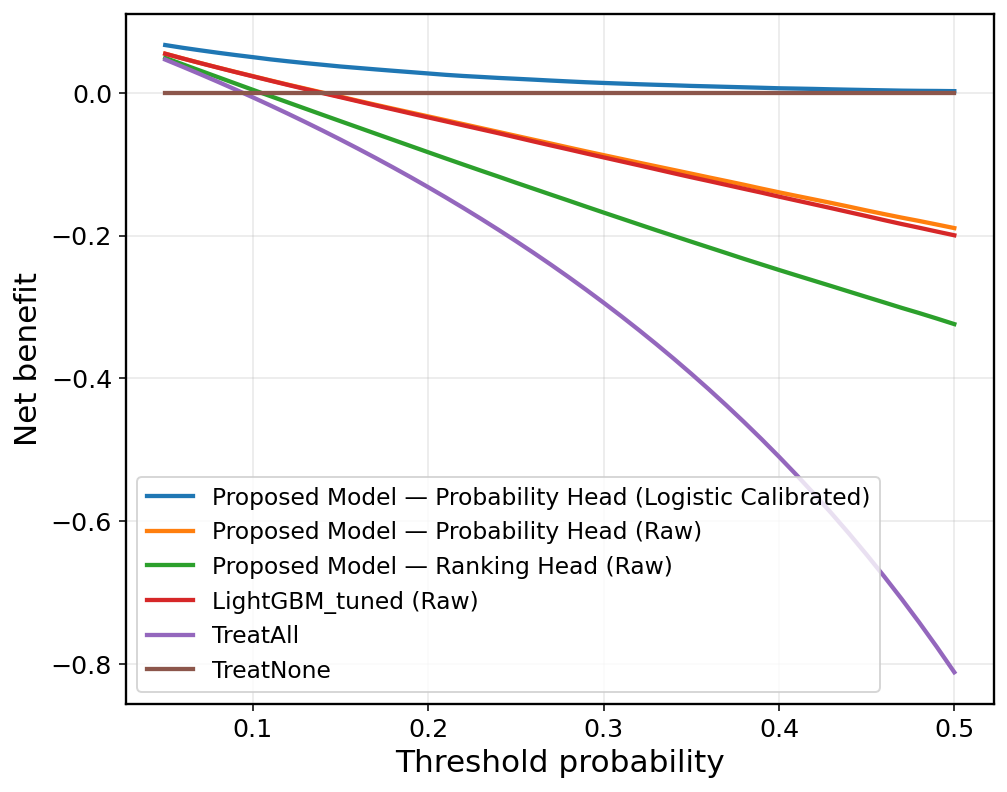

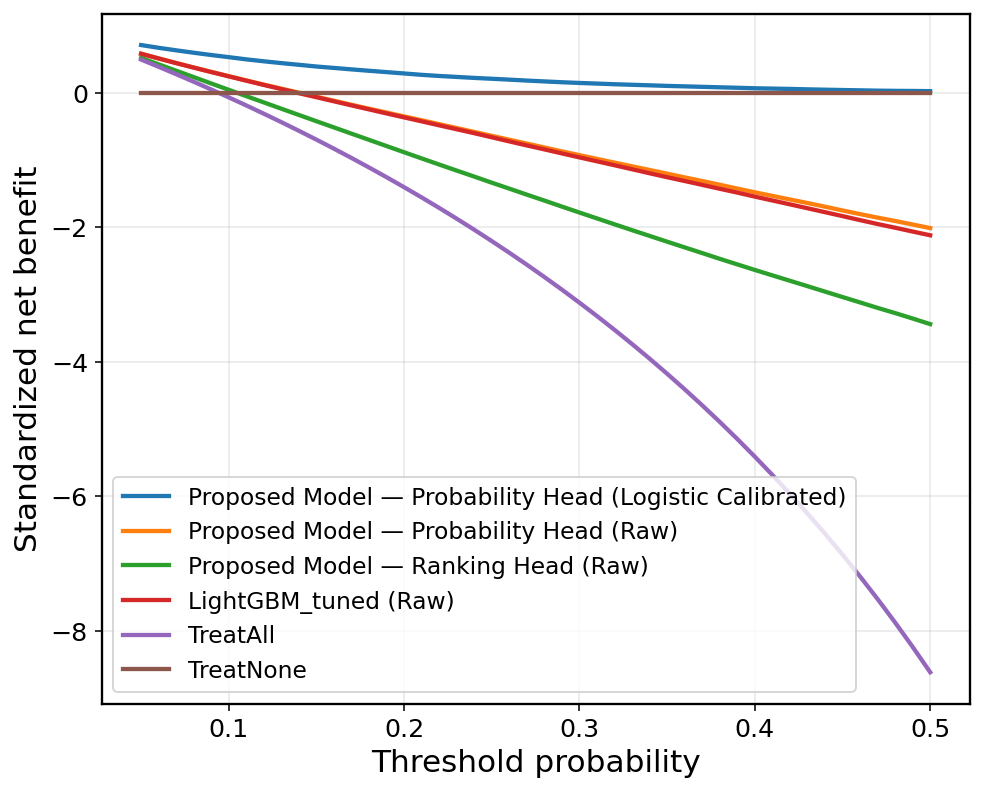


Best model by threshold:
    threshold                                         best_model  \
0        0.05  Proposed Model — Probability Head (Logistic Ca...   
1        0.06  Proposed Model — Probability Head (Logistic Ca...   
2        0.07  Proposed Model — Probability Head (Logistic Ca...   
3        0.08  Proposed Model — Probability Head (Logistic Ca...   
4        0.09  Proposed Model — Probability Head (Logistic Ca...   
5        0.10  Proposed Model — Probability Head (Logistic Ca...   
6        0.11  Proposed Model — Probability Head (Logistic Ca...   
7        0.12  Proposed Model — Probability Head (Logistic Ca...   
8        0.13  Proposed Model — Probability Head (Logistic Ca...   
9        0.14  Proposed Model — Probability Head (Logistic Ca...   
10       0.15  Proposed Model — Probability Head (Logistic Ca...   
11       0.16  Proposed Model — Probability Head (Logistic Ca...   

    best_net_benefit                        second_best_model  \
0           0.066832  Pr

In [4]:
# ============================================================
# Module 8 — Decision Curve Analysis
# Purpose:
#   Evaluate the clinical utility of the Proposed Model using
#   Decision Curve Analysis (DCA).
#
# Compared models:
#   - TreatNone
#   - TreatAll
#   - LightGBM_tuned (Raw)
#   - Proposed Model — Probability Head (Raw)
#   - Proposed Model — Final Probability Head
#   - Proposed Model — Ranking Head (Raw)
#
# Important figure rule:
#   - no titles inside saved images
# ============================================================

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "y_all",
    "p_lgb",
    "p_prob_raw_pm",
    "p_prob_final_pm",
    "p_rank_final_pm",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 8: {missing_vars}")

# -------------------------
# Helpers
# -------------------------
def net_benefit_at_threshold(y_true, p, threshold):
    """
    Standard net benefit:
    NB = TP/N - FP/N * (pt / (1-pt))
    """
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    pred = (p >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    n = len(y_true)

    odds = threshold / max(1.0 - threshold, 1e-12)
    nb = (tp / n) - (fp / n) * odds
    return float(nb), int(tp), int(fp), int(tn), int(fn)

def treat_all_net_benefit(y_true, threshold):
    y_true = np.asarray(y_true).astype(int)
    n = len(y_true)
    tp = int(y_true.sum())
    fp = int((y_true == 0).sum())
    odds = threshold / max(1.0 - threshold, 1e-12)
    nb = (tp / n) - (fp / n) * odds
    return float(nb)

def treat_none_net_benefit():
    return 0.0

def standardized_net_benefit(nb, prevalence):
    return float(nb / max(prevalence, 1e-12))

def decision_curve_dataframe(y_true, pred_dict, thresholds):
    y_true = np.asarray(y_true).astype(int)
    prevalence = float(y_true.mean())

    rows = []
    for thr in thresholds:
        # Baselines
        nb_none = treat_none_net_benefit()
        nb_all = treat_all_net_benefit(y_true, thr)

        rows.append({
            "model": "TreatNone",
            "threshold": float(thr),
            "net_benefit": float(nb_none),
            "std_net_benefit": float(standardized_net_benefit(nb_none, prevalence)),
        })
        rows.append({
            "model": "TreatAll",
            "threshold": float(thr),
            "net_benefit": float(nb_all),
            "std_net_benefit": float(standardized_net_benefit(nb_all, prevalence)),
        })

        # Model-based NB
        for name, p in pred_dict.items():
            nb, tp, fp, tn, fn = net_benefit_at_threshold(y_true, p, thr)
            rows.append({
                "model": name,
                "threshold": float(thr),
                "net_benefit": float(nb),
                "std_net_benefit": float(standardized_net_benefit(nb, prevalence)),
                "TP": int(tp),
                "FP": int(fp),
                "TN": int(tn),
                "FN": int(fn),
            })

    return pd.DataFrame(rows)

def summarize_decision_curve(dca_df, threshold_min=0.05, threshold_max=0.50):
    keep = dca_df[(dca_df["threshold"] >= threshold_min) & (dca_df["threshold"] <= threshold_max)].copy()

    rows = []
    for model_name, g in keep.groupby("model"):
        rows.append({
            "model": model_name,
            "avg_NB_0.05_0.50": float(g["net_benefit"].mean()),
            "max_NB_0.05_0.50": float(g["net_benefit"].max()),
            "avg_stdNB_0.05_0.50": float(g["std_net_benefit"].mean()),
            "max_stdNB_0.05_0.50": float(g["std_net_benefit"].max()),
        })
    return pd.DataFrame(rows).sort_values(
        ["avg_NB_0.05_0.50", "max_NB_0.05_0.50"],
        ascending=[False, False]
    ).reset_index(drop=True)

def plot_decision_curve(dca_df, model_order, save_path_base):
    plt.figure(figsize=(8.0, 6.4))

    for model_name in model_order:
        g = dca_df[dca_df["model"] == model_name].sort_values("threshold")
        plt.plot(g["threshold"], g["net_benefit"], label=model_name)

    plt.xlabel("Threshold probability")
    plt.ylabel("Net benefit")
    plt.legend(frameon=True)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

def plot_standardized_decision_curve(dca_df, model_order, save_path_base):
    plt.figure(figsize=(8.0, 6.4))

    for model_name in model_order:
        g = dca_df[dca_df["model"] == model_name].sort_values("threshold")
        plt.plot(g["threshold"], g["std_net_benefit"], label=model_name)

    plt.xlabel("Threshold probability")
    plt.ylabel("Standardized net benefit")
    plt.legend(frameon=True)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

# -------------------------
# Models for DCA
# -------------------------
dca_pred_dict = {
    "LightGBM_tuned (Raw)": p_lgb,
    "Proposed Model — Probability Head (Raw)": p_prob_raw_pm,
    final_prob_model_name: p_prob_final_pm,
    "Proposed Model — Ranking Head (Raw)": p_rank_final_pm,
}

# Suggested clinical threshold range
thresholds = np.round(np.linspace(0.05, 0.50, 46), 3)

# -------------------------
# 8.1 Threshold-wise decision curve data
# -------------------------
module8_dca_df = decision_curve_dataframe(
    y_true=y_all,
    pred_dict=dca_pred_dict,
    thresholds=thresholds,
)
module8_dca_df.to_csv(TAB_DIR / "module8_decision_curve_full.csv", index=False)

print("\nModule 8 full decision-curve data:")
print(module8_dca_df.head(12))

# -------------------------
# 8.2 Compact summary table
# -------------------------
module8_dca_summary_df = summarize_decision_curve(
    module8_dca_df,
    threshold_min=0.05,
    threshold_max=0.50,
)
module8_dca_summary_df.to_csv(TAB_DIR / "module8_decision_curve_summary.csv", index=False)

print("\nModule 8 decision-curve summary:")
print(module8_dca_summary_df)

# -------------------------
# 8.3 Plot net benefit curves
# -------------------------
model_order = [
    final_prob_model_name,
    "Proposed Model — Probability Head (Raw)",
    "Proposed Model — Ranking Head (Raw)",
    "LightGBM_tuned (Raw)",
    "TreatAll",
    "TreatNone",
]

plot_decision_curve(
    module8_dca_df,
    model_order=model_order,
    save_path_base=FIG_DIR / "module8_decision_curve_net_benefit",
)

plot_standardized_decision_curve(
    module8_dca_df,
    model_order=model_order,
    save_path_base=FIG_DIR / "module8_decision_curve_standardized_net_benefit",
)

# -------------------------
# 8.4 Best-model-at-each-threshold helper table
# -------------------------
best_rows = []
for thr, g in module8_dca_df.groupby("threshold"):
    g2 = g.copy().sort_values("net_benefit", ascending=False).reset_index(drop=True)
    best_rows.append({
        "threshold": float(thr),
        "best_model": g2.iloc[0]["model"],
        "best_net_benefit": float(g2.iloc[0]["net_benefit"]),
        "second_best_model": g2.iloc[1]["model"] if len(g2) > 1 else None,
        "second_best_net_benefit": float(g2.iloc[1]["net_benefit"]) if len(g2) > 1 else np.nan,
    })

module8_best_by_threshold_df = pd.DataFrame(best_rows)
module8_best_by_threshold_df.to_csv(TAB_DIR / "module8_best_model_by_threshold.csv", index=False)

print("\nBest model by threshold:")
print(module8_best_by_threshold_df.head(12))

# -------------------------
# 8.5 Save compact predictions used in DCA
# -------------------------
module8_preds_df = pd.DataFrame({
    "y_true": y_all.astype(int),
    "p_lightgbm_tuned_raw": p_lgb,
    "p_proposed_prob_raw": p_prob_raw_pm,
    "p_proposed_prob_final": p_prob_final_pm,
    "p_proposed_rank_raw": p_rank_final_pm,
})
module8_preds_df.to_csv(PRED_DIR / "module8_decision_curve_predictions.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module8_decision_curve_predictions.npz",
    y_true=y_all.astype(np.int32),
    p_lightgbm_tuned_raw=p_lgb.astype(np.float32),
    p_proposed_prob_raw=p_prob_raw_pm.astype(np.float32),
    p_proposed_prob_final=p_prob_final_pm.astype(np.float32),
    p_proposed_rank_raw=p_rank_final_pm.astype(np.float32),
)

print("\nModule 8 complete.")
print("Saved decision-curve tables and paper-ready figures without titles.")


Module 9 subgroup results:
         N  pos_rate     Brier       NLL       ECE       MCE    PR_AUC  \
0    24421  0.008558  0.017728  0.089779  0.058442  0.698754  0.112408   
1    24421  0.008558  0.008024  0.041050  0.001197  0.569976  0.114236   
2    24421  0.008558  0.042680  0.180894  0.136778  0.623296  0.116648   
3    89070  0.172808  0.317066  0.865106  0.420370  0.546312  0.409986   
4    89070  0.172808  0.122545  0.390676  0.004455  0.167758  0.411326   
5    89070  0.172808  0.429935  1.236528  0.545684  0.631213  0.411443   
6    49799  0.025221  0.057654  0.207946  0.126961  0.547098  0.214386   
7    49799  0.025221  0.021786  0.090326  0.001257  0.397149  0.216666   
8    49799  0.025221  0.112588  0.372286  0.248702  0.628198  0.218986   
9    90390  0.077840  0.168688  0.501273  0.276128  0.543070  0.323577   
10   90390  0.077840  0.061073  0.216411  0.001595  0.086526  0.325120   
11   90390  0.077840  0.268905  0.776656  0.427232  0.637612  0.325631   
12   12417

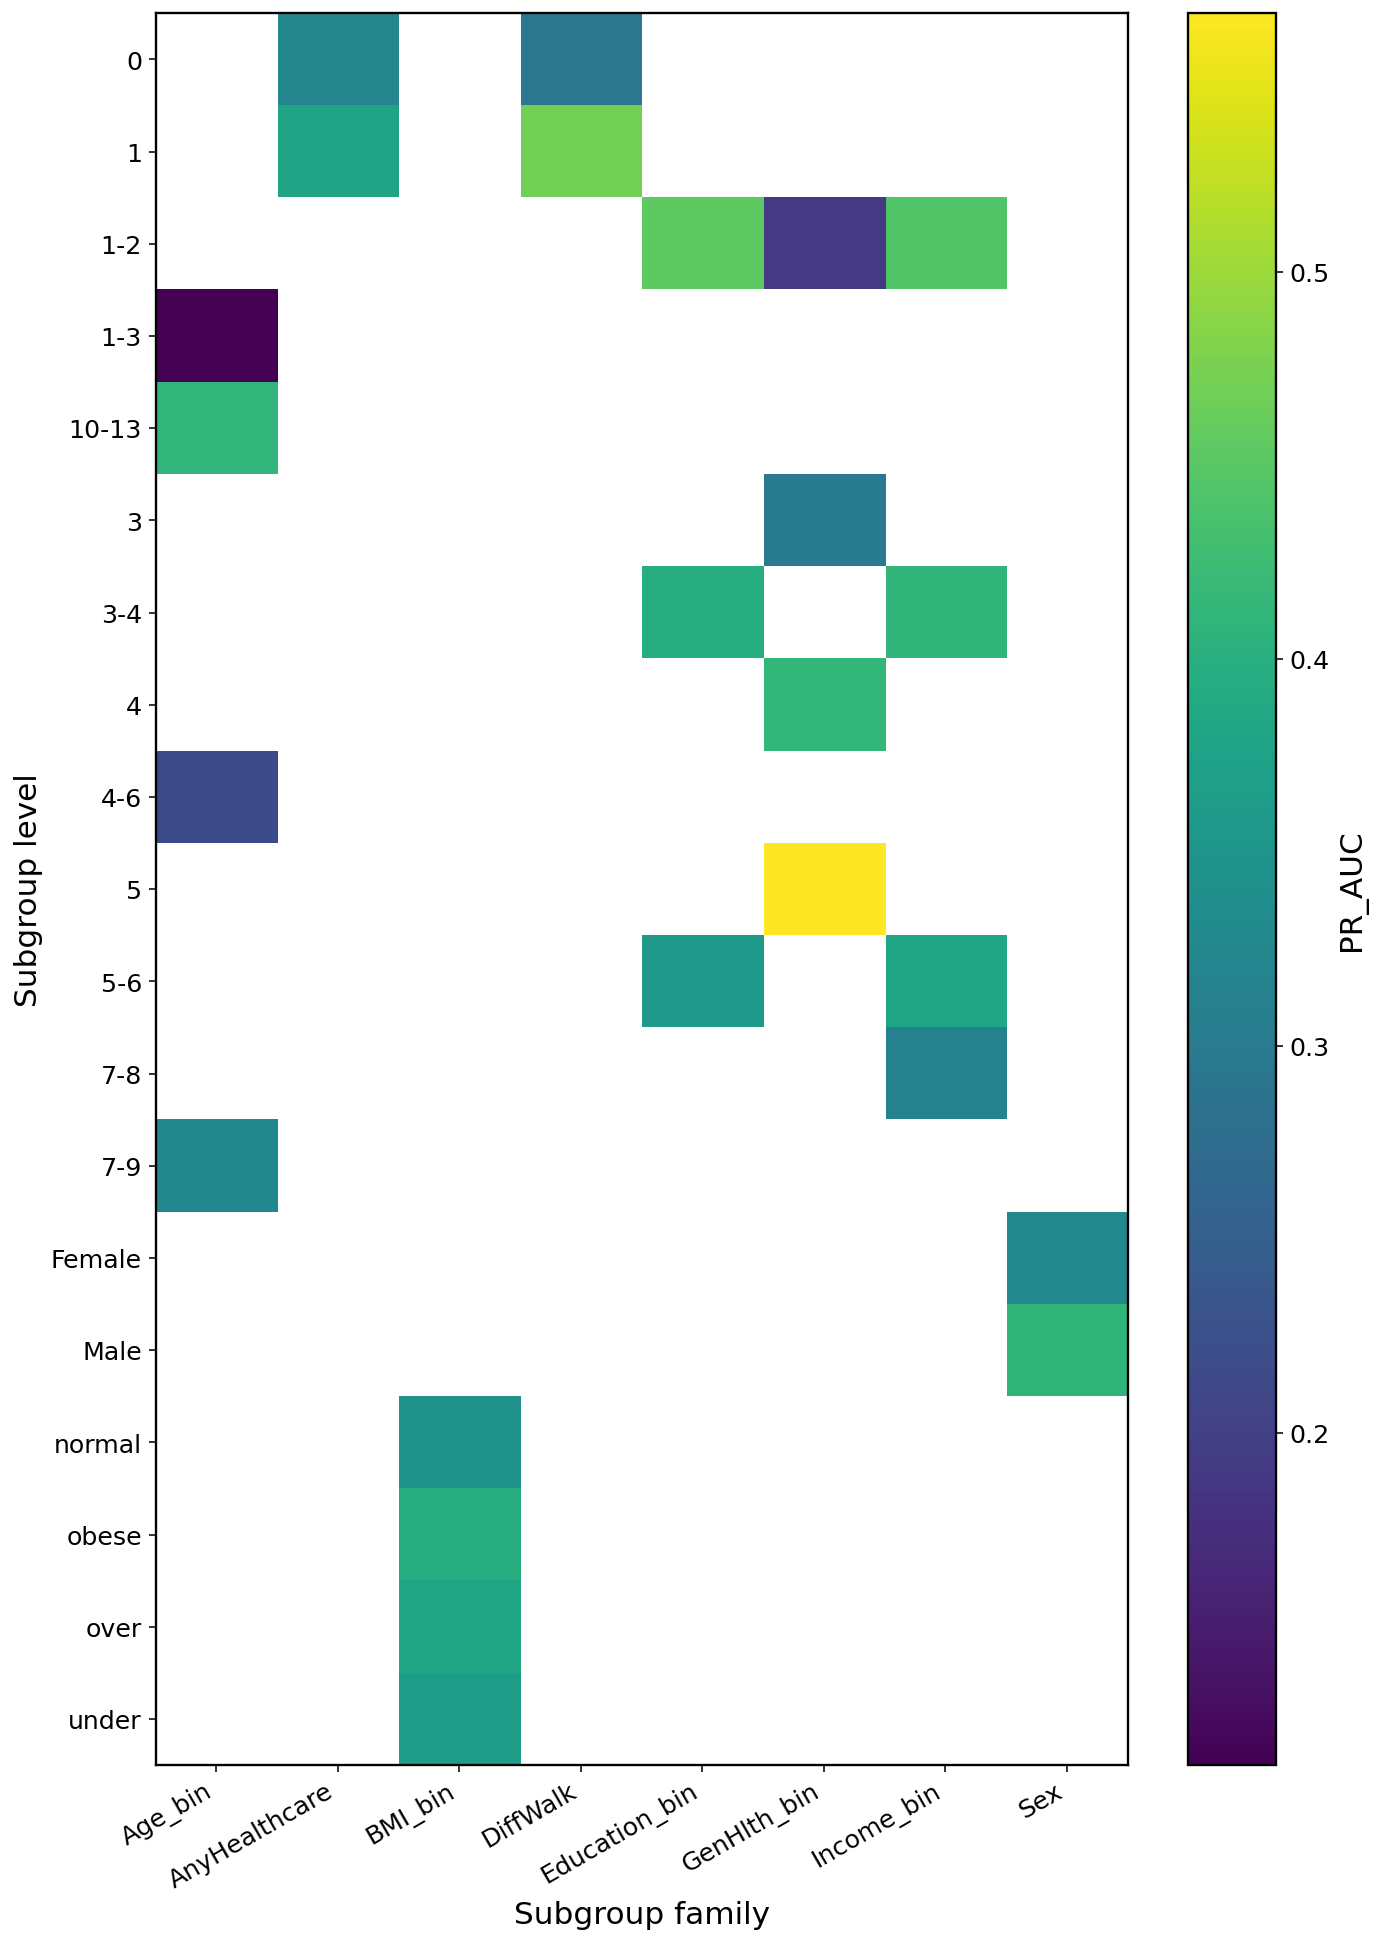

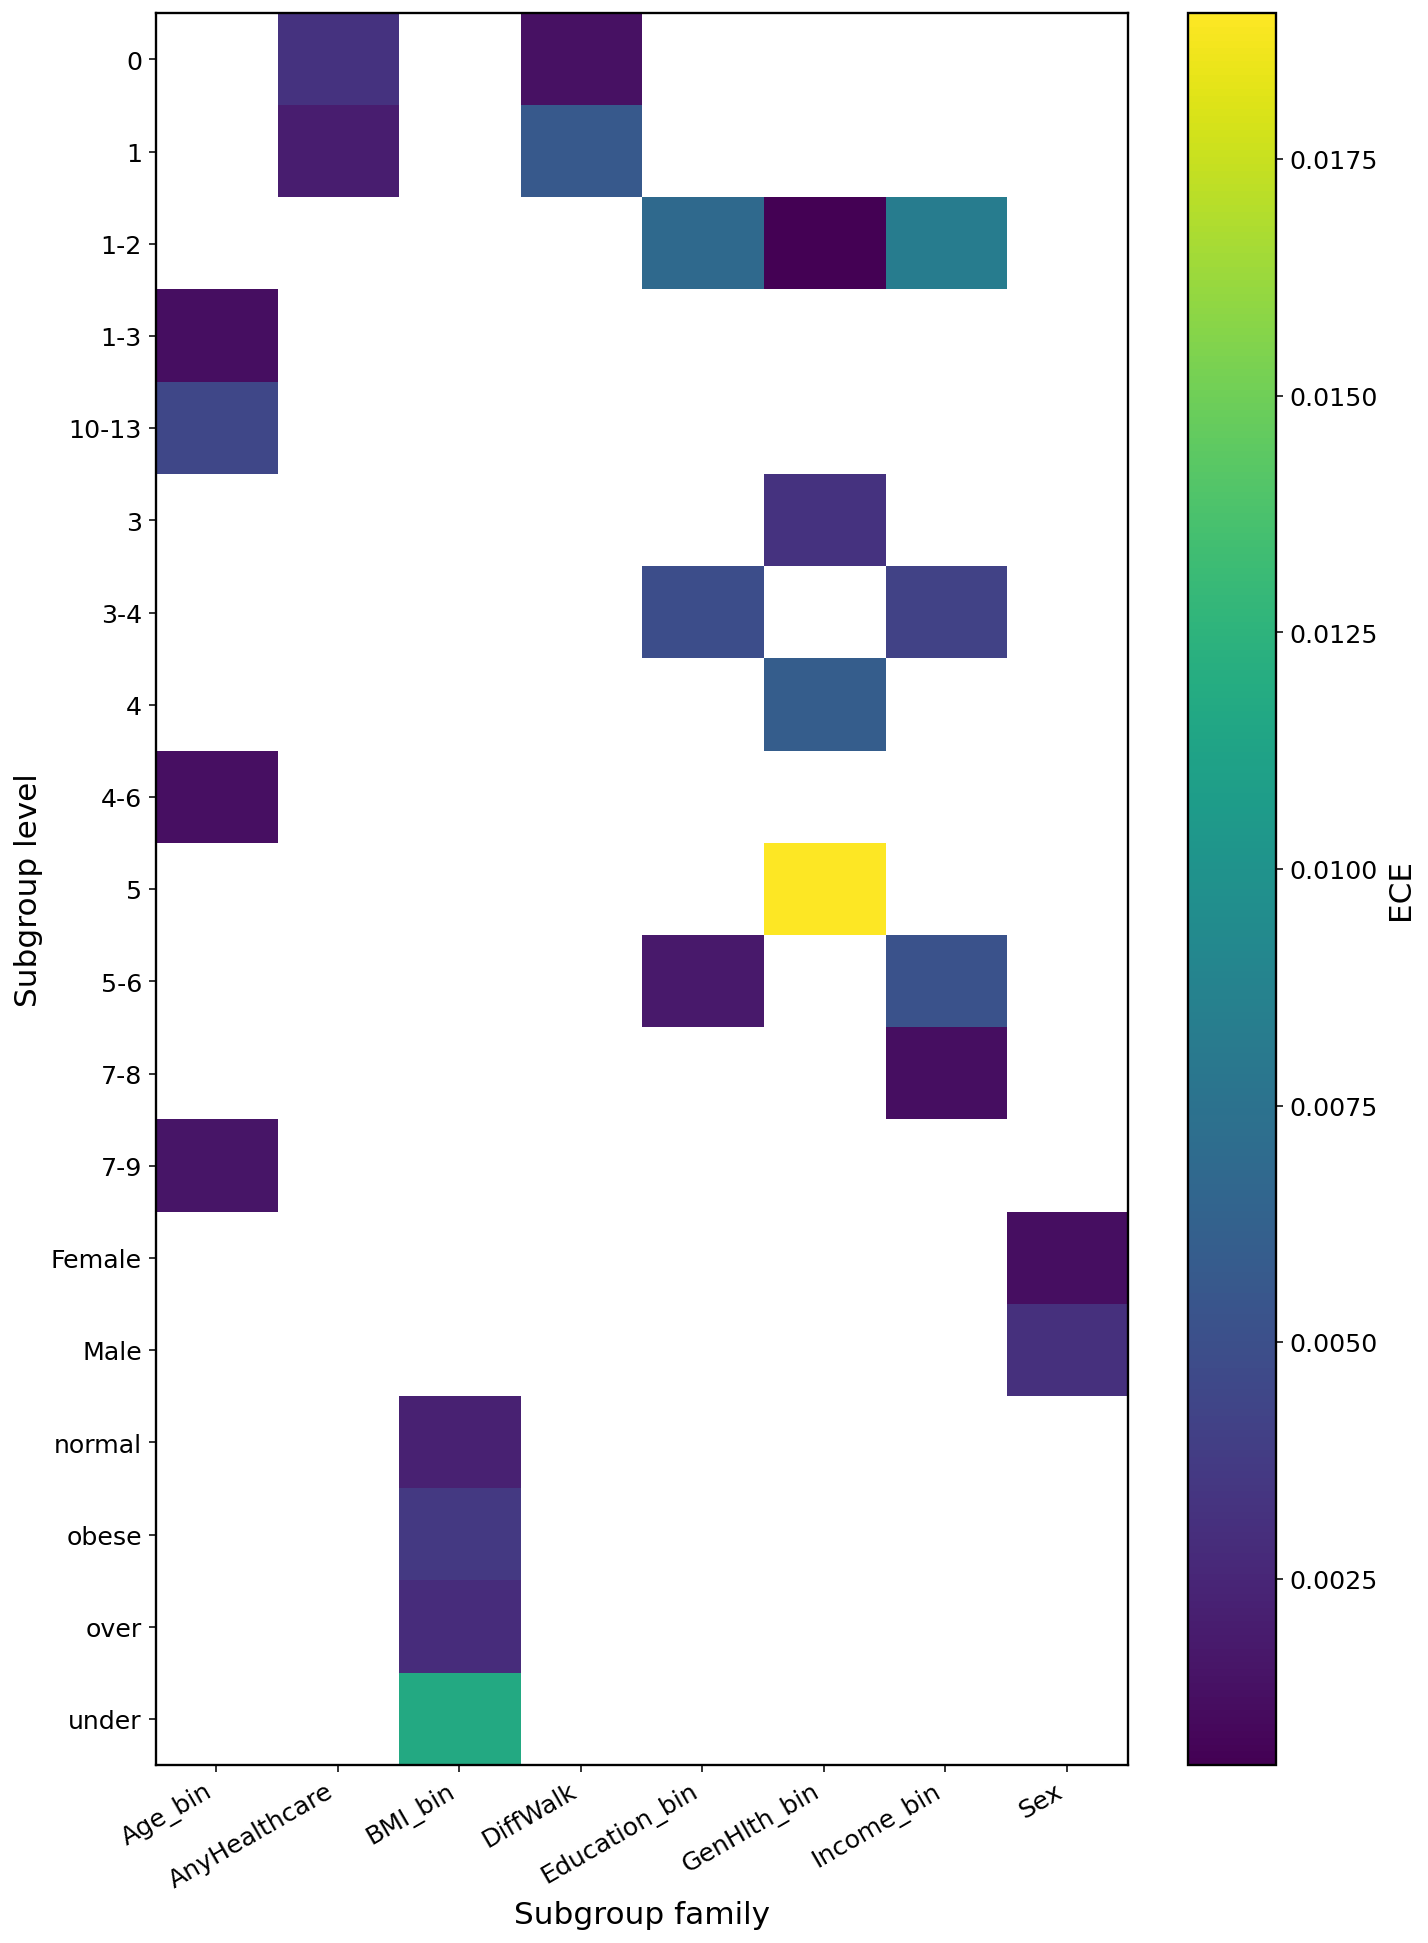

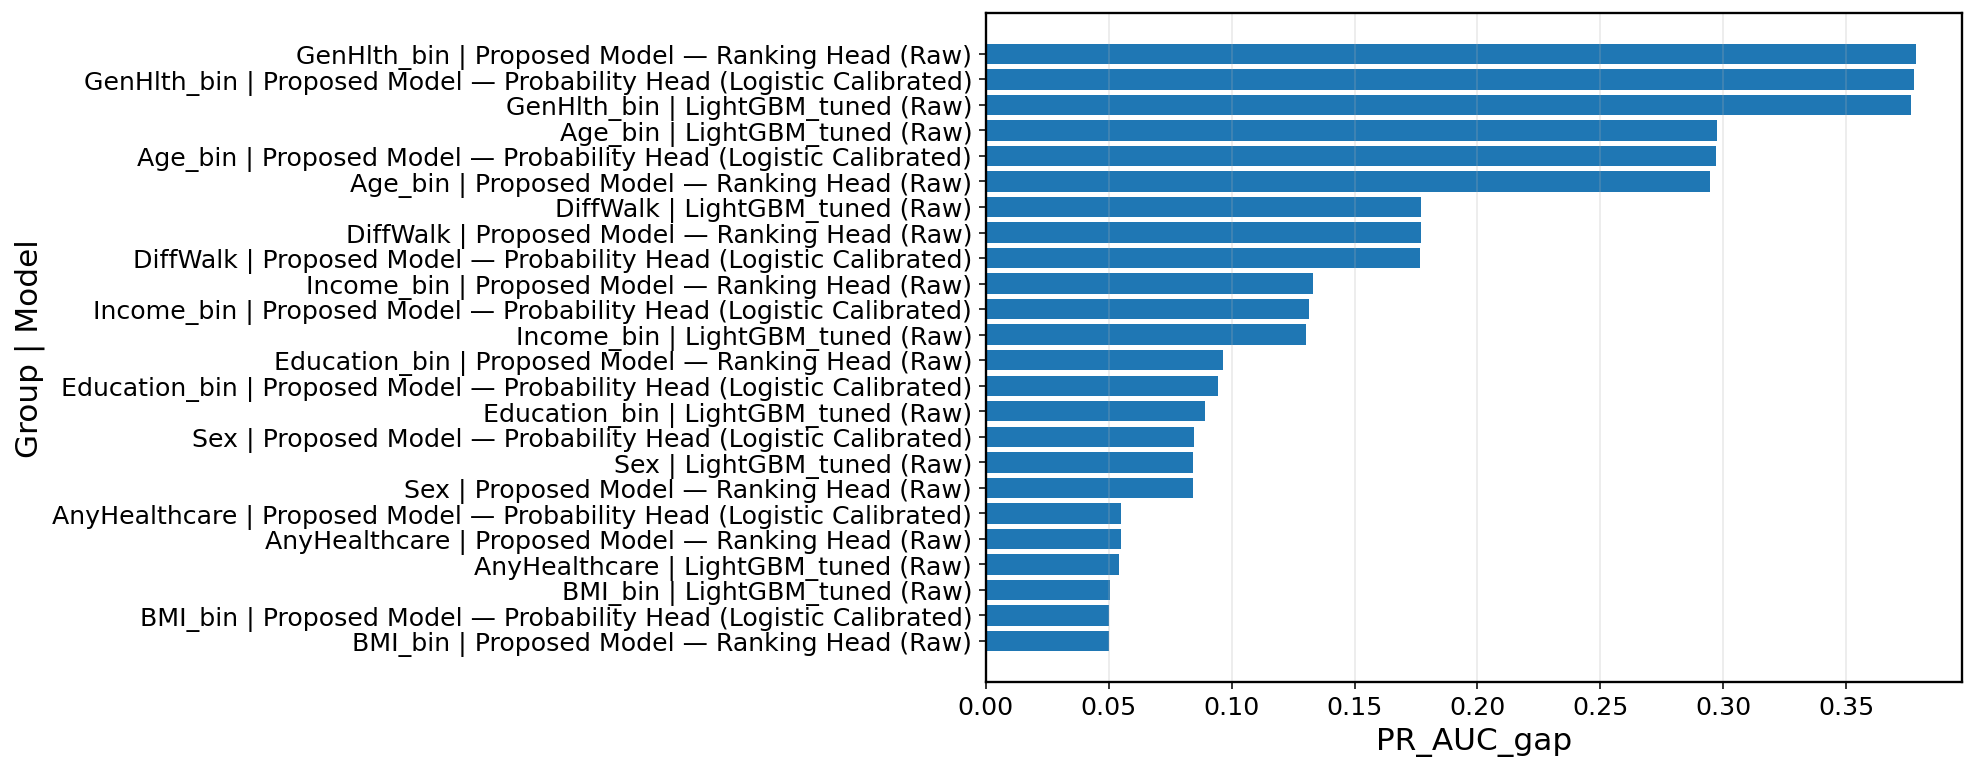

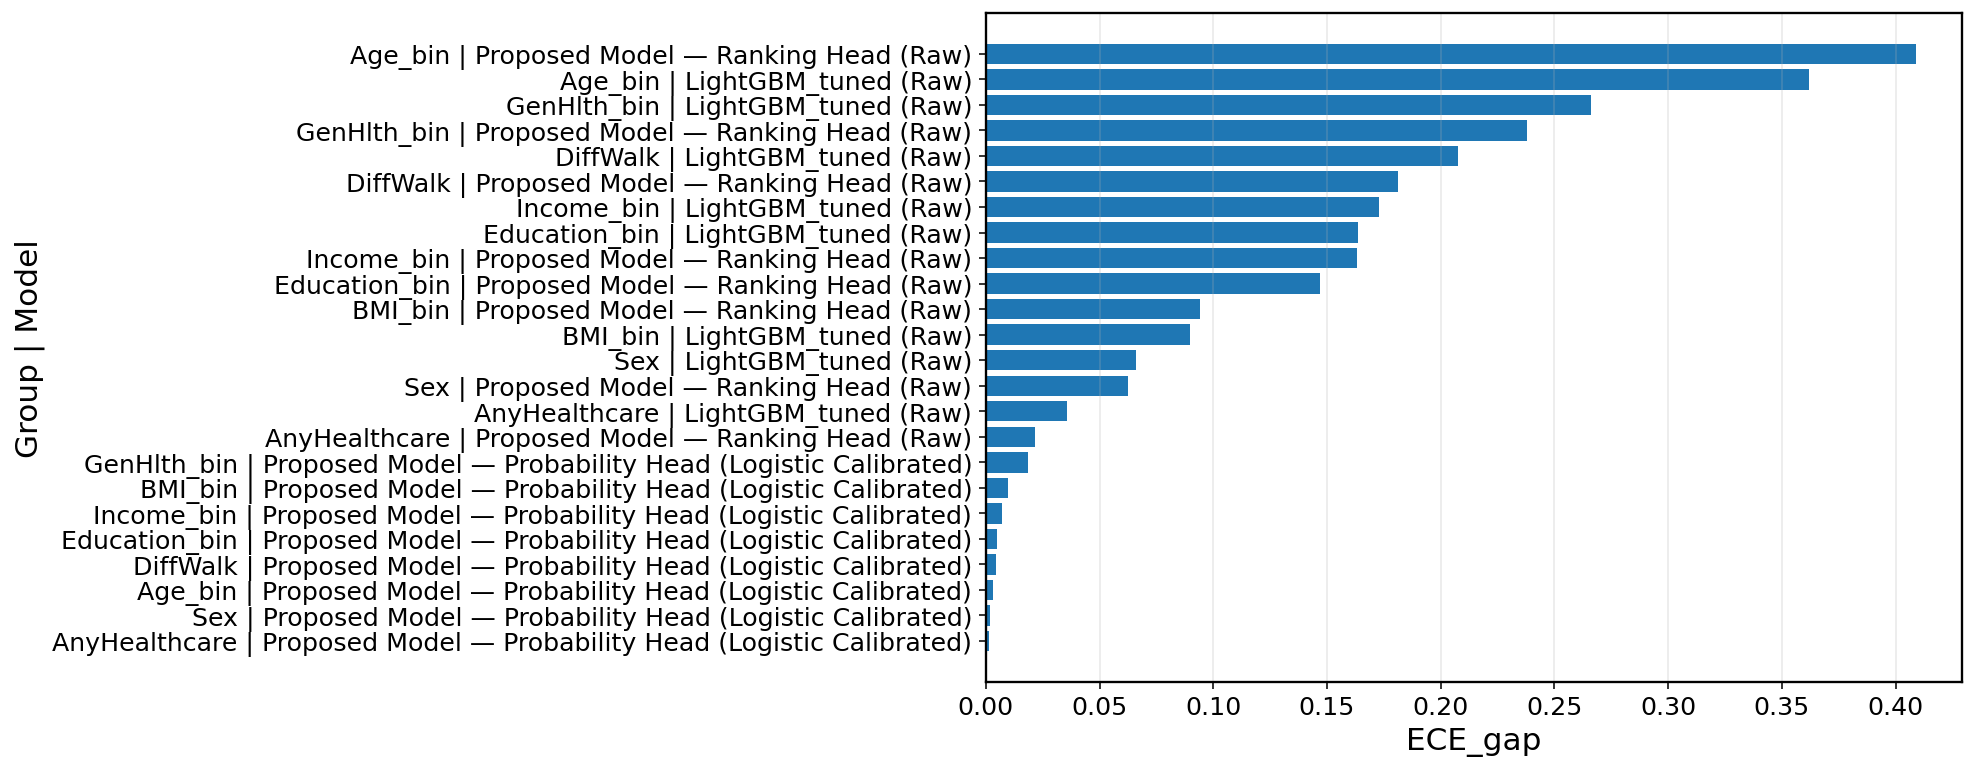


Module 9 complete.
Saved fairness tables and paper-ready figures without titles.


In [5]:
# ============================================================
# Module 9 — Fairness and subgroup reliability analysis
# Purpose:
#   Evaluate the Proposed Model across clinically relevant subgroups.
#
# Compared models:
#   - LightGBM_tuned (Raw)
#   - Proposed Model — Final Probability Head
#   - Proposed Model — Ranking Head (Raw)
#
# Subgroups used if available:
#   - Sex
#   - Age_bin
#   - BMI_bin
#   - Education_bin
#   - Income_bin
#   - AnyHealthcare
#   - DiffWalk
#   - GenHlth_bin
#
# Important figure rule:
#   - no titles inside saved images
# ============================================================

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "X_all",
    "y_all",
    "p_lgb",
    "p_prob_final_pm",
    "p_rank_final_pm",
    "final_prob_model_name",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 9: {missing_vars}")

# -------------------------
# Helpers
# -------------------------
def subgroup_basic_eval(y_true, p):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)

    out = {
        "N": int(len(y_true)),
        "pos_rate": float(np.mean(y_true)),
        "Brier": float(brier_score_loss(y_true, p)),
        "NLL": float(log_loss(y_true, p)),
    }

    ece, mce = expected_calibration_error(y_true, p, n_bins=15)
    out["ECE"] = float(ece)
    out["MCE"] = float(mce)

    if len(np.unique(y_true)) > 1:
        out["PR_AUC"] = float(average_precision_score(y_true, p))
        out["ROC_AUC"] = float(roc_auc_score(y_true, p))
    else:
        out["PR_AUC"] = np.nan
        out["ROC_AUC"] = np.nan

    thr = find_best_f1_threshold(y_true, p)
    pred = (p >= thr).astype(int)

    out["threshold"] = float(thr)
    out["Precision"] = float(precision_score(y_true, pred, zero_division=0))
    out["Recall"] = float(recall_score(y_true, pred, zero_division=0))
    out["F1"] = float(f1_score(y_true, pred, zero_division=0))

    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    out["TPR"] = float(tp / max(tp + fn, 1))
    out["FPR"] = float(fp / max(fp + tn, 1))
    out["FNR"] = float(fn / max(fn + tp, 1))
    out["TNR"] = float(tn / max(tn + fp, 1))

    return out

def make_subgroup_map(X_df):
    X_df = X_df.copy()
    subgroup_map = {}

    if "Sex" in X_df.columns:
        subgroup_map["Sex"] = X_df["Sex"].map({0: "Female", 1: "Male"}).fillna(X_df["Sex"].astype(str))

    if "Age" in X_df.columns:
        subgroup_map["Age_bin"] = pd.cut(
            X_df["Age"],
            bins=[0, 3, 6, 9, 13],
            labels=["1-3", "4-6", "7-9", "10-13"],
            include_lowest=True
        )

    if "BMI" in X_df.columns:
        subgroup_map["BMI_bin"] = pd.cut(
            X_df["BMI"],
            bins=[0, 18.5, 25, 30, 100],
            labels=["under", "normal", "over", "obese"],
            include_lowest=True
        )

    if "Education" in X_df.columns:
        subgroup_map["Education_bin"] = pd.cut(
            X_df["Education"],
            bins=[0, 2, 4, 6],
            labels=["1-2", "3-4", "5-6"],
            include_lowest=True
        )

    if "Income" in X_df.columns:
        subgroup_map["Income_bin"] = pd.cut(
            X_df["Income"],
            bins=[0, 2, 4, 6, 8],
            labels=["1-2", "3-4", "5-6", "7-8"],
            include_lowest=True
        )

    for c in ["AnyHealthcare", "DiffWalk"]:
        if c in X_df.columns:
            subgroup_map[c] = X_df[c].astype(int).astype(str)

    if "GenHlth" in X_df.columns:
        subgroup_map["GenHlth_bin"] = pd.cut(
            X_df["GenHlth"],
            bins=[0, 2, 3, 4, 5],
            labels=["1-2", "3", "4", "5"],
            include_lowest=True
        )

    return subgroup_map

def disparity_summary(subgroup_df):
    metric_cols = ["PR_AUC", "ROC_AUC", "Brier", "ECE", "Recall", "FPR", "FNR"]
    rows = []

    for (group, model), g in subgroup_df.groupby(["group", "model"]):
        row = {"group": group, "model": model}
        for m in metric_cols:
            vals = g[m].dropna()
            if len(vals) == 0:
                row[f"{m}_max"] = np.nan
                row[f"{m}_min"] = np.nan
                row[f"{m}_gap"] = np.nan
            else:
                row[f"{m}_max"] = float(vals.max())
                row[f"{m}_min"] = float(vals.min())
                row[f"{m}_gap"] = float(vals.max() - vals.min())
        rows.append(row)

    return pd.DataFrame(rows)

def plot_subgroup_metric_heatmap(df_long, metric, model_name, save_path_base):
    df_plot = df_long[df_long["model"] == model_name].copy()
    if df_plot.empty:
        return

    pivot = df_plot.pivot(index="level", columns="group", values=metric)

    plt.figure(figsize=(1.4 * max(4, pivot.shape[1]), 0.75 * max(4, pivot.shape[0]) + 2))
    im = plt.imshow(pivot.values, aspect="auto")
    plt.xticks(range(pivot.shape[1]), pivot.columns, rotation=30, ha="right")
    plt.yticks(range(pivot.shape[0]), pivot.index)
    plt.xlabel("Subgroup family")
    plt.ylabel("Subgroup level")
    cbar = plt.colorbar(im)
    cbar.set_label(metric)
    save_figure_multi(save_path_base)
    plt.show()

def plot_disparity_bar(disparity_df, metric_gap_col, save_path_base):
    df_plot = disparity_df.copy().sort_values(metric_gap_col, ascending=False)

    plt.figure(figsize=(9.0, 6.2))
    labels = df_plot["group"] + " | " + df_plot["model"]
    plt.barh(labels, df_plot[metric_gap_col])
    plt.xlabel(metric_gap_col)
    plt.ylabel("Group | Model")
    plt.gca().invert_yaxis()
    plt.grid(axis="x")
    save_figure_multi(save_path_base)
    plt.show()

# -------------------------
# Inputs
# -------------------------
X_fair = X_all.copy()
y_fair = y_all.astype(int)

fair_models = {
    "LightGBM_tuned (Raw)": p_lgb,
    final_prob_model_name: p_prob_final_pm,
    "Proposed Model — Ranking Head (Raw)": p_rank_final_pm,
}

subgroup_map = make_subgroup_map(X_fair)

# -------------------------
# 9.1 Subgroup-level evaluation
# -------------------------
subgroup_rows = []

for group_name, vals in subgroup_map.items():
    vals = pd.Series(vals)

    if not pd.api.types.is_categorical_dtype(vals):
        vals = vals.astype("category")

    for level in vals.cat.categories:
        idx = (vals == level).values
        yy = y_fair[idx]

        # Keep only sufficiently sized subgroups
        if idx.sum() < 500:
            continue

        for model_name, p in fair_models.items():
            row = subgroup_basic_eval(yy, p[idx])
            row.update({
                "group": group_name,
                "level": str(level),
                "model": model_name,
            })
            subgroup_rows.append(row)

module9_subgroup_df = pd.DataFrame(subgroup_rows)
module9_subgroup_df = module9_subgroup_df.sort_values(
    ["group", "level", "model"]
).reset_index(drop=True)

module9_subgroup_df.to_csv(TAB_DIR / "module9_subgroup_results.csv", index=False)

print("\nModule 9 subgroup results:")
print(module9_subgroup_df.head(20))

# -------------------------
# 9.2 Disparity summary
# -------------------------
module9_disparity_df = disparity_summary(module9_subgroup_df)
module9_disparity_df = module9_disparity_df.sort_values(
    ["PR_AUC_gap", "ECE_gap"], ascending=[False, False]
).reset_index(drop=True)

module9_disparity_df.to_csv(TAB_DIR / "module9_disparity_summary.csv", index=False)

print("\nModule 9 disparity summary:")
print(module9_disparity_df.head(20))

# -------------------------
# 9.3 Compact fairness summary for paper
# -------------------------
summary_rows = []
for model_name, g in module9_subgroup_df.groupby("model"):
    summary_rows.append({
        "model": model_name,
        "mean_PR_AUC_across_subgroups": float(g["PR_AUC"].dropna().mean()),
        "mean_ROC_AUC_across_subgroups": float(g["ROC_AUC"].dropna().mean()),
        "mean_Brier_across_subgroups": float(g["Brier"].dropna().mean()),
        "mean_ECE_across_subgroups": float(g["ECE"].dropna().mean()),
        "max_PR_AUC_gap": float(
            module9_disparity_df.loc[module9_disparity_df["model"] == model_name, "PR_AUC_gap"].max()
        ),
        "max_ECE_gap": float(
            module9_disparity_df.loc[module9_disparity_df["model"] == model_name, "ECE_gap"].max()
        ),
        "max_Recall_gap": float(
            module9_disparity_df.loc[module9_disparity_df["model"] == model_name, "Recall_gap"].max()
        ),
        "max_FNR_gap": float(
            module9_disparity_df.loc[module9_disparity_df["model"] == model_name, "FNR_gap"].max()
        ),
    })

module9_fairness_summary_df = pd.DataFrame(summary_rows).sort_values(
    ["mean_PR_AUC_across_subgroups", "mean_ECE_across_subgroups"],
    ascending=[False, True]
).reset_index(drop=True)

module9_fairness_summary_df.to_csv(TAB_DIR / "module9_fairness_summary.csv", index=False)

print("\nModule 9 fairness summary:")
print(module9_fairness_summary_df)

# -------------------------
# 9.4 Paper-quality figures without titles
# -------------------------
plot_subgroup_metric_heatmap(
    module9_subgroup_df,
    metric="PR_AUC",
    model_name=final_prob_model_name,
    save_path_base=FIG_DIR / "module9_heatmap_prauc_proposed_prob_final",
)

plot_subgroup_metric_heatmap(
    module9_subgroup_df,
    metric="ECE",
    model_name=final_prob_model_name,
    save_path_base=FIG_DIR / "module9_heatmap_ece_proposed_prob_final",
)

plot_disparity_bar(
    module9_disparity_df,
    metric_gap_col="PR_AUC_gap",
    save_path_base=FIG_DIR / "module9_disparity_bar_prauc_gap",
)

plot_disparity_bar(
    module9_disparity_df,
    metric_gap_col="ECE_gap",
    save_path_base=FIG_DIR / "module9_disparity_bar_ece_gap",
)

# -------------------------
# 9.5 Save compact prediction bundle
# -------------------------
module9_preds_df = pd.DataFrame({
    "y_true": y_fair.astype(int),
    "p_lightgbm_tuned_raw": p_lgb,
    "p_proposed_prob_final": p_prob_final_pm,
    "p_proposed_rank_final": p_rank_final_pm,
})
module9_preds_df.to_csv(PRED_DIR / "module9_fairness_predictions.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module9_fairness_predictions.npz",
    y_true=y_fair.astype(np.int32),
    p_lightgbm_tuned_raw=p_lgb.astype(np.float32),
    p_proposed_prob_final=p_prob_final_pm.astype(np.float32),
    p_proposed_rank_final=p_rank_final_pm.astype(np.float32),
)

print("\nModule 9 complete.")
print("Saved fairness tables and paper-ready figures without titles.")

Full-data LightGBM model fitted for SHAP analysis.

Global SHAP importance:
              feature  mean_abs_shap
0                 Age       0.872334
1             GenHlth       0.550641
2              HighBP       0.400222
3                 Sex       0.358900
4            HighChol       0.316015
5              Smoker       0.200538
6              Income       0.132138
7            DiffWalk       0.131145
8              Stroke       0.110008
9            Diabetes       0.104757
10                BMI       0.096430
11           PhysHlth       0.070739
12          Education       0.061355
13          CholCheck       0.059059
14           MentHlth       0.046373
15        NoDocbcCost       0.039423
16  HvyAlcoholConsump       0.038071
17             Fruits       0.034697
18       PhysActivity       0.029108
19            Veggies       0.018456


KeyboardInterrupt: 

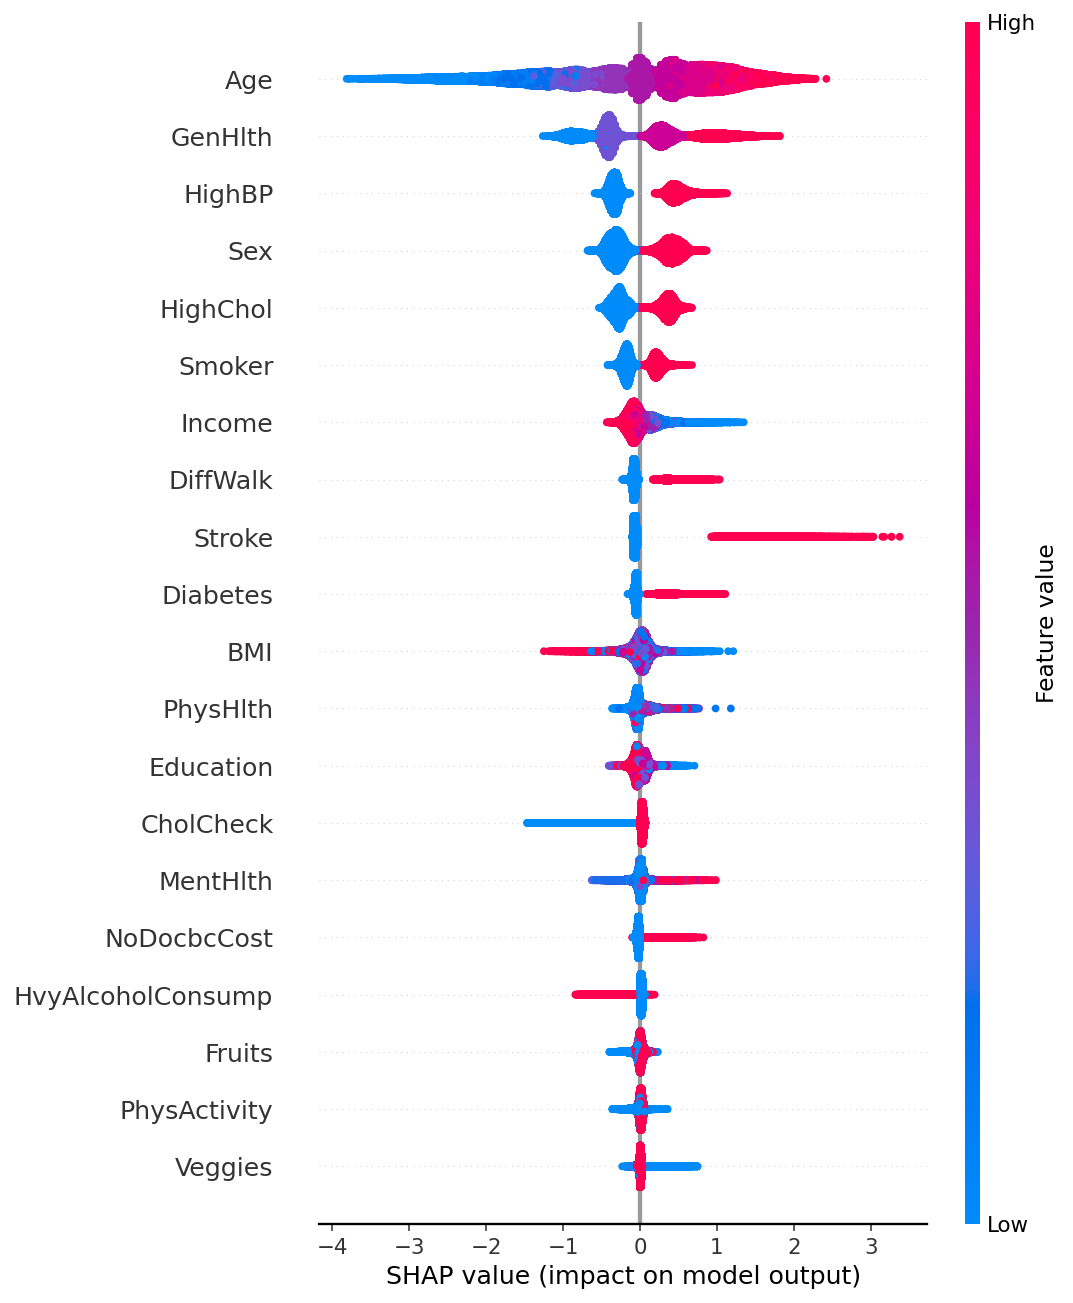

In [6]:

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "X_all",
    "y_all",
    "FEATURES",
    "skf",
    "SEED",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 10: {missing_vars}")

# -------------------------
# Imports
# -------------------------
import shap
import lightgbm as lgb

# -------------------------
# Helpers
# -------------------------
def fit_final_lightgbm_full(X_df, y, seed=42):
    """
    Fit a single LightGBM model on the full dataset for explanation.
    This is for interpretability artifacts, not OOF evaluation.
    """
    pos = int((y == 1).sum())
    neg = int((y == 0).sum())
    scale_pos_weight = neg / max(pos, 1)

    params = dict(
        objective="binary",
        boosting_type="gbdt",
        learning_rate=0.03,
        num_leaves=64,
        min_data_in_leaf=200,
        feature_fraction=0.85,
        bagging_fraction=0.85,
        bagging_freq=1,
        lambda_l2=10.0,
        scale_pos_weight=scale_pos_weight * 1.25,
        metric="auc",
        verbosity=-1,
        seed=seed,
    )

    X_fit = make_ml_matrix(X_df)
    dtrain = lgb.Dataset(X_fit, label=y.astype(int))

    model = lgb.train(
        params=params,
        train_set=dtrain,
        num_boost_round=800,
    )
    return model, X_fit

def make_case_index_table(y_true, p_final, p_lgb):
    """
    Select representative cases:
      - confident true positive
      - false positive
      - false negative
      - uncertain case
    """
    y_true = np.asarray(y_true).astype(int)
    p_final = clip_probs(p_final)
    p_lgb = clip_probs(p_lgb)

    thr = find_best_f1_threshold(y_true, p_final)
    pred = (p_final >= thr).astype(int)

    uncertainty_proxy = np.abs(p_final - 0.5)

    case_rows = []

    # Confident TP
    idx_tp = np.where((y_true == 1) & (pred == 1))[0]
    if len(idx_tp) > 0:
        idx = idx_tp[np.argmax(p_final[idx_tp])]
        case_rows.append({"case_type": "Confident_TP", "index": int(idx)})

    # False Positive
    idx_fp = np.where((y_true == 0) & (pred == 1))[0]
    if len(idx_fp) > 0:
        idx = idx_fp[np.argmax(p_final[idx_fp])]
        case_rows.append({"case_type": "False_Positive", "index": int(idx)})

    # False Negative
    idx_fn = np.where((y_true == 1) & (pred == 0))[0]
    if len(idx_fn) > 0:
        idx = idx_fn[np.argmax(p_final[idx_fn])]
        case_rows.append({"case_type": "False_Negative", "index": int(idx)})

    # Most uncertain
    idx_unc = np.argmin(uncertainty_proxy)
    case_rows.append({"case_type": "Most_Uncertain", "index": int(idx_unc)})

    return pd.DataFrame(case_rows)

def save_shap_beeswarm(shap_values, X_plot, save_path_base, max_display=20):
    plt.figure()
    shap.summary_plot(
        shap_values,
        X_plot,
        show=False,
        max_display=max_display,
    )
    save_figure_multi(save_path_base)
    plt.show()

def save_shap_bar(shap_values, X_plot, save_path_base, max_display=20):
    plt.figure()
    shap.summary_plot(
        shap_values,
        X_plot,
        plot_type="bar",
        show=False,
        max_display=max_display,
    )
    save_figure_multi(save_path_base)
    plt.show()

def save_shap_dependence(shap_values, X_plot, feature_name, save_path_base, interaction_index="auto"):
    plt.figure()
    shap.dependence_plot(
        feature_name,
        shap_values,
        X_plot,
        interaction_index=interaction_index,
        show=False,
    )
    save_figure_multi(save_path_base)
    plt.show()

# -------------------------
# 10.1 Fit final interpretable expert on full data
# -------------------------
X_shap_input = X_all.copy()
y_shap = y_all.astype(int)

lightgbm_full_model, X_shap_fit = fit_final_lightgbm_full(X_shap_input, y_shap, seed=SEED)

print("Full-data LightGBM model fitted for SHAP analysis.")

# -------------------------
# 10.2 Compute SHAP values
# -------------------------
explainer = shap.TreeExplainer(lightgbm_full_model)
shap_values = explainer.shap_values(X_shap_fit)

# LightGBM binary classification may return list of two arrays
if isinstance(shap_values, list):
    shap_values_use = shap_values[1] if len(shap_values) > 1 else shap_values[0]
else:
    shap_values_use = shap_values

shap_abs_mean = np.abs(shap_values_use).mean(axis=0)

module10_importance_df = pd.DataFrame({
    "feature": X_shap_fit.columns,
    "mean_abs_shap": shap_abs_mean,
}).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True)

module10_importance_df.to_csv(TAB_DIR / "module10_shap_global_importance.csv", index=False)

print("\nGlobal SHAP importance:")
print(module10_importance_df.head(20))

# -------------------------
# 10.3 Global SHAP figures
# -------------------------
save_shap_beeswarm(
    shap_values_use,
    X_shap_fit,
    FIG_DIR / "module10_shap_summary_beeswarm",
    max_display=20,
)

save_shap_bar(
    shap_values_use,
    X_shap_fit,
    FIG_DIR / "module10_shap_summary_bar",
    max_display=20,
)

# -------------------------
# 10.4 Dependence plots for top features
# -------------------------
top_features = module10_importance_df["feature"].head(4).tolist()

for feat in top_features:
    save_shap_dependence(
        shap_values_use,
        X_shap_fit,
        feature_name=feat,
        save_path_base=FIG_DIR / f"module10_shap_dependence_{feat}",
        interaction_index="auto",
    )

# -------------------------
# 10.5 Local case explanations
# -------------------------
# Use final deployed probability head if available; otherwise fallback
if "p_prob_final_pm" in globals():
    p_for_cases = p_prob_final_pm
else:
    p_for_cases = clip_probs(lightgbm_full_model.predict(X_shap_fit))

case_index_df = make_case_index_table(
    y_true=y_shap,
    p_final=p_for_cases,
    p_lgb=clip_probs(lightgbm_full_model.predict(X_shap_fit)),
)

local_rows = []
for _, r in case_index_df.iterrows():
    idx = int(r["index"])
    case_type = r["case_type"]

    shap_row = shap_values_use[idx]
    x_row = X_shap_fit.iloc[idx]
    top_idx = np.argsort(-np.abs(shap_row))[:8]

    for rank_i, j in enumerate(top_idx, start=1):
        local_rows.append({
            "case_type": case_type,
            "sample_index": idx,
            "rank": rank_i,
            "feature": X_shap_fit.columns[j],
            "feature_value": float(x_row.iloc[j]),
            "shap_value": float(shap_row[j]),
            "abs_shap_value": float(abs(shap_row[j])),
            "true_label": int(y_shap[idx]),
            "predicted_probability": float(p_for_cases[idx]),
        })

module10_local_cases_df = pd.DataFrame(local_rows)
module10_local_cases_df.to_csv(TAB_DIR / "module10_local_case_explanations.csv", index=False)

print("\nLocal explanation table preview:")
print(module10_local_cases_df.head(20))

# -------------------------
# 10.6 Save waterfall-like bar charts for selected cases
# -------------------------
for _, r in case_index_df.iterrows():
    idx = int(r["index"])
    case_type = r["case_type"]

    shap_row = shap_values_use[idx]
    x_row = X_shap_fit.iloc[idx]
    top_idx = np.argsort(-np.abs(shap_row))[:10]

    plot_df = pd.DataFrame({
        "feature": X_shap_fit.columns[top_idx],
        "shap_value": shap_row[top_idx],
        "feature_value": x_row.iloc[top_idx].values,
    }).sort_values("shap_value", ascending=True)

    plt.figure(figsize=(8.4, 5.8))
    plt.barh(plot_df["feature"], plot_df["shap_value"])
    plt.xlabel("SHAP value")
    plt.ylabel("Feature")
    plt.grid(axis="x")
    save_figure_multi(FIG_DIR / f"module10_local_case_{case_type}")
    plt.show()

# -------------------------
# 10.7 Save compact artifacts
# -------------------------
module10_case_index_df = case_index_df.copy()
module10_case_index_df.to_csv(TAB_DIR / "module10_case_index_table.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module10_shap_artifacts.npz",
    shap_values=shap_values_use.astype(np.float32),
)

print("\nModule 10 complete.")
print("Saved SHAP tables and paper-ready figures without titles.")


Module 11 uncertainty table preview:
   y_true   p_final     p_lgb     p_xgb     p_dfm  expert_mean  expert_std  \
0       0  0.388400  0.860709  0.904774  0.788068     0.851184    0.048119   
1       0  0.025951  0.227767  0.251983  0.156946     0.212232    0.040324   
2       0  0.259240  0.792025  0.797974  0.724857     0.771619    0.033155   
3       0  0.034698  0.313650  0.248253  0.212796     0.258233    0.041774   
4       0  0.099807  0.562320  0.560624  0.380325     0.501090    0.085396   

   expert_range  pair_disagree_mean  entropy_final  confidence_margin  \
0      0.116707            0.077804       0.668027           0.111600   
1      0.095037            0.063358       0.120372           0.474049   
2      0.073117            0.048745       0.572261           0.240760   
3      0.100854            0.067236       0.150711           0.465302   
4      0.181995            0.121330       0.324659           0.400193   

   uncertainty_score  pred_label  is_error  is_tp  is_

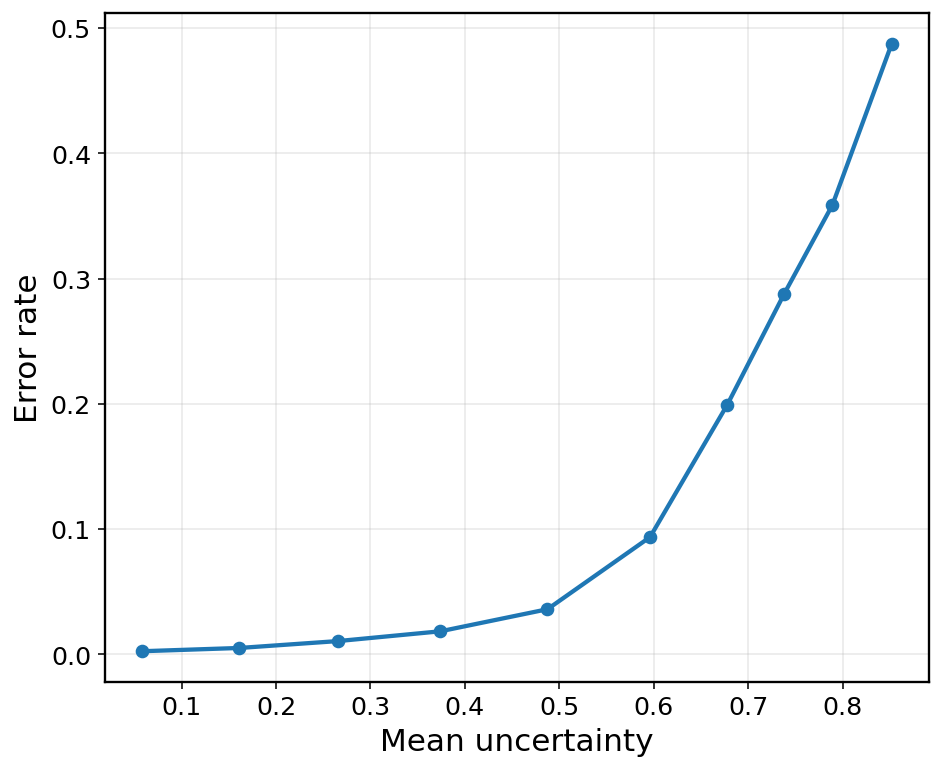

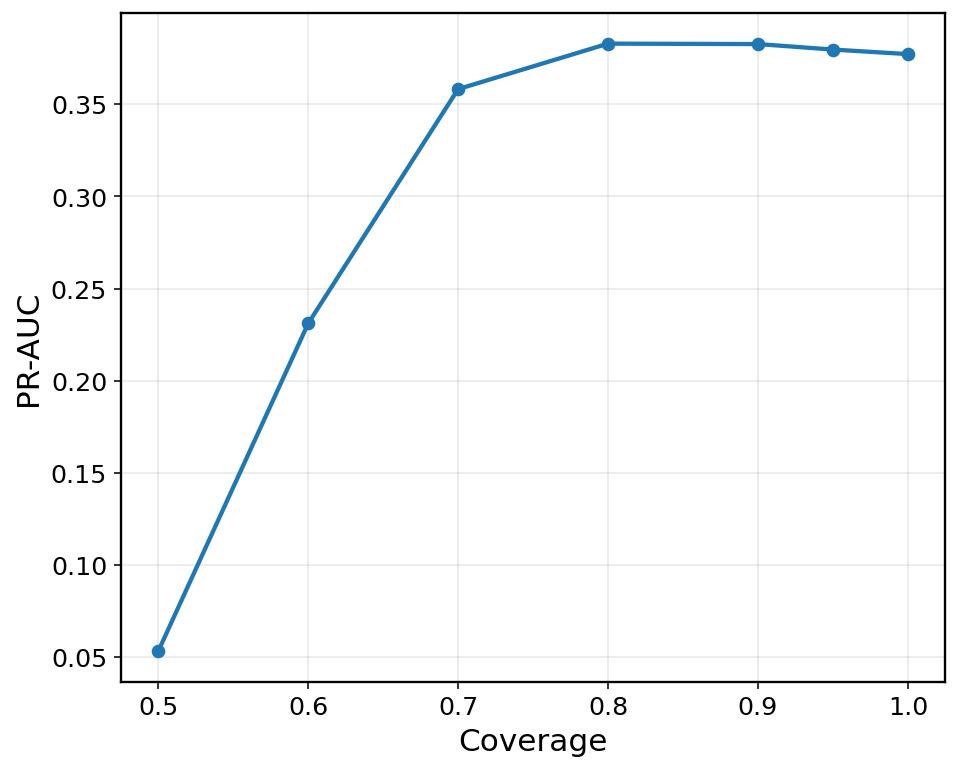

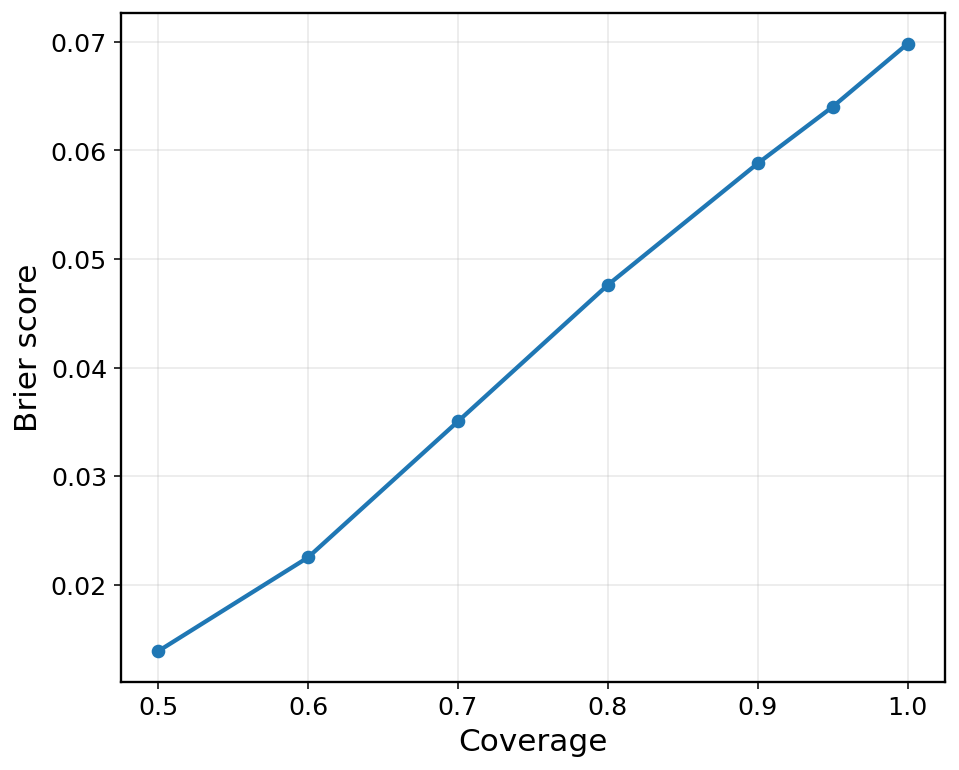

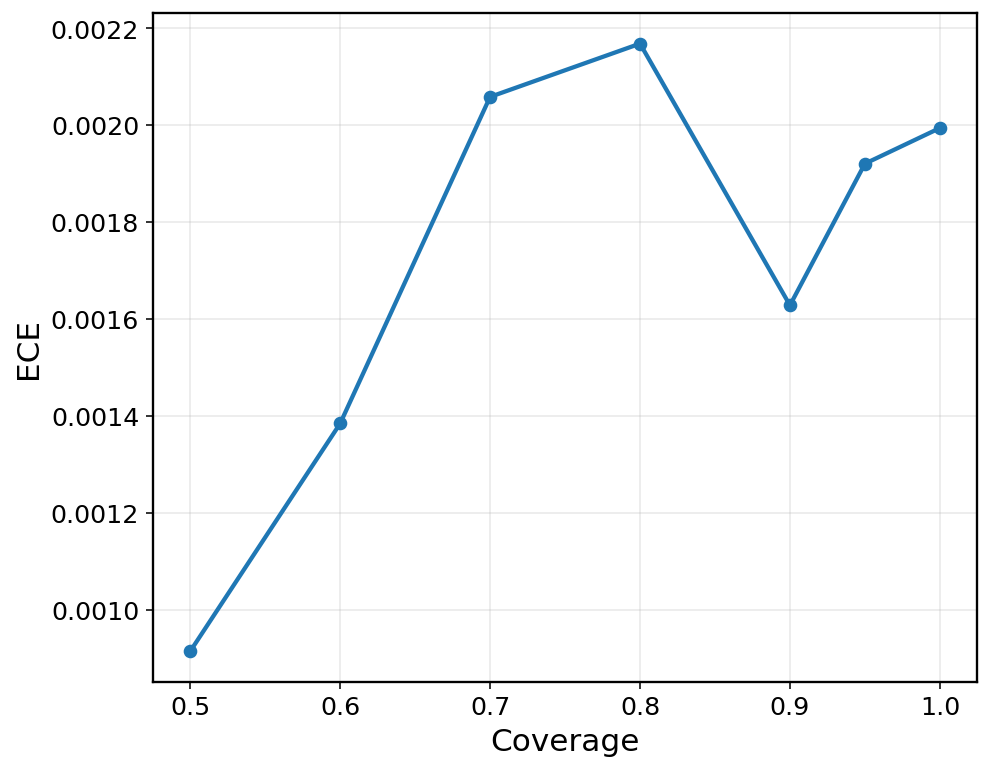

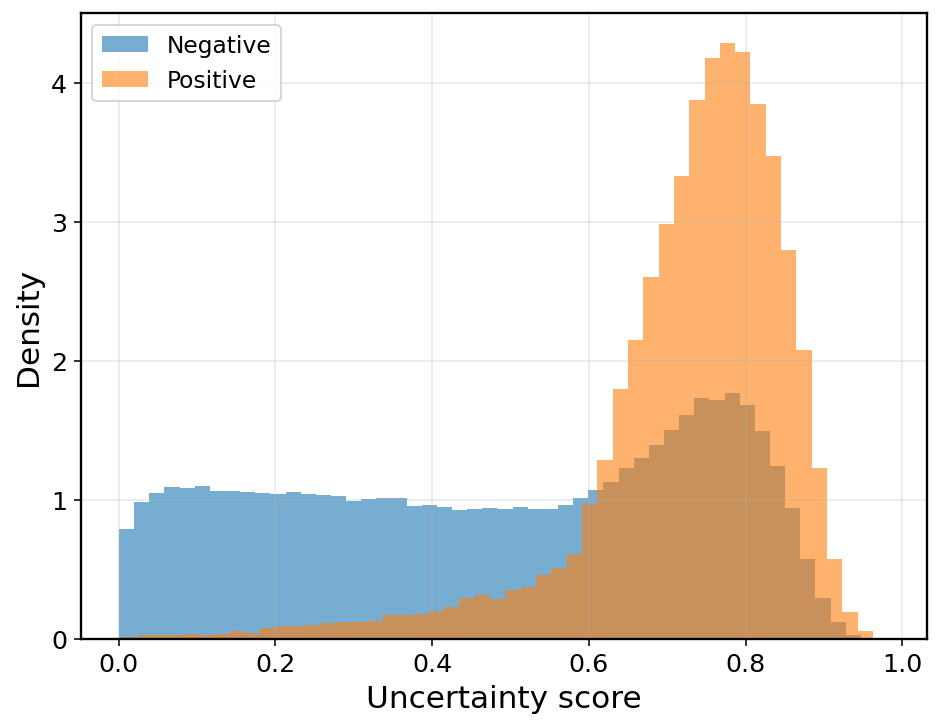


Module 11 complete.
Saved uncertainty tables and paper-ready figures without titles.


In [7]:
# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "y_all",
    "p_lgb",
    "p_xgb",
    "p_dfm",
    "p_prob_final_pm",
    "p_rank_final_pm",
    "final_prob_model_name",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 11: {missing_vars}")

# -------------------------
# Helpers
# -------------------------
def binary_entropy(p):
    p = clip_probs(p)
    return -(p * np.log(p) + (1.0 - p) * np.log(1.0 - p))

def normalized_rank(x):
    x = np.asarray(x).reshape(-1)
    r = x.argsort().argsort().astype(np.float32)
    r = (r - r.min()) / max((r.max() - r.min()), 1e-12)
    return r

def build_uncertainty_table(y_true, p_final, p_lgb, p_xgb, p_dfm):
    y_true = np.asarray(y_true).astype(int)
    p_final = clip_probs(p_final)
    p_lgb = clip_probs(p_lgb)
    p_xgb = clip_probs(p_xgb)
    p_dfm = clip_probs(p_dfm)

    expert_mean = (p_lgb + p_xgb + p_dfm) / 3.0
    expert_std = np.std(np.vstack([p_lgb, p_xgb, p_dfm]), axis=0)
    expert_range = np.max(np.vstack([p_lgb, p_xgb, p_dfm]), axis=0) - np.min(np.vstack([p_lgb, p_xgb, p_dfm]), axis=0)
    disagreement_lgb_xgb = np.abs(p_lgb - p_xgb)
    disagreement_lgb_dfm = np.abs(p_lgb - p_dfm)
    disagreement_xgb_dfm = np.abs(p_xgb - p_dfm)
    mean_pairwise_disagreement = (disagreement_lgb_xgb + disagreement_lgb_dfm + disagreement_xgb_dfm) / 3.0

    conf_margin = np.abs(p_final - 0.5)
    entropy_final = binary_entropy(p_final)

    # Composite uncertainty: larger means more uncertain
    # combine entropy + disagreement + low confidence
    u_entropy = normalized_rank(entropy_final)
    u_disagreement = normalized_rank(mean_pairwise_disagreement)
    u_low_conf = 1.0 - normalized_rank(conf_margin)

    uncertainty_score = (0.40 * u_entropy) + (0.40 * u_disagreement) + (0.20 * u_low_conf)
    uncertainty_score = np.clip(uncertainty_score.astype(np.float32), 0.0, 1.0)

    return pd.DataFrame({
        "y_true": y_true,
        "p_final": p_final,
        "p_lgb": p_lgb,
        "p_xgb": p_xgb,
        "p_dfm": p_dfm,
        "expert_mean": expert_mean,
        "expert_std": expert_std,
        "expert_range": expert_range,
        "pair_disagree_mean": mean_pairwise_disagreement,
        "entropy_final": entropy_final,
        "confidence_margin": conf_margin,
        "uncertainty_score": uncertainty_score,
    })

def add_error_columns(df_unc):
    df_unc = df_unc.copy()
    thr = find_best_f1_threshold(df_unc["y_true"].values, df_unc["p_final"].values)
    pred = (df_unc["p_final"].values >= thr).astype(int)
    df_unc["pred_label"] = pred
    df_unc["is_error"] = (pred != df_unc["y_true"].values).astype(int)
    df_unc["is_tp"] = ((pred == 1) & (df_unc["y_true"].values == 1)).astype(int)
    df_unc["is_fp"] = ((pred == 1) & (df_unc["y_true"].values == 0)).astype(int)
    df_unc["is_fn"] = ((pred == 0) & (df_unc["y_true"].values == 1)).astype(int)
    df_unc["is_tn"] = ((pred == 0) & (df_unc["y_true"].values == 0)).astype(int)
    df_unc["decision_threshold"] = float(thr)
    return df_unc

def stratify_uncertainty(df_unc, n_bins=10):
    df_unc = df_unc.copy()
    df_unc["uncertainty_decile"] = pd.qcut(
        df_unc["uncertainty_score"],
        q=n_bins,
        labels=[f"D{i}" for i in range(1, n_bins + 1)],
        duplicates="drop",
    )
    rows = []
    for d, g in df_unc.groupby("uncertainty_decile"):
        rows.append({
            "uncertainty_bin": str(d),
            "N": int(len(g)),
            "mean_uncertainty": float(g["uncertainty_score"].mean()),
            "mean_probability": float(g["p_final"].mean()),
            "error_rate": float(g["is_error"].mean()),
            "positive_rate": float(g["y_true"].mean()),
            "fp_rate": float(g["is_fp"].mean()),
            "fn_rate": float(g["is_fn"].mean()),
            "ece_like_abs_gap": float(np.mean(np.abs(g["p_final"] - g["y_true"]))),
        })
    return pd.DataFrame(rows).sort_values("mean_uncertainty").reset_index(drop=True)

def selective_prediction_curve(y_true, p, uncertainty, coverages):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    uncertainty = np.asarray(uncertainty).astype(np.float32)

    n = len(y_true)
    order = np.argsort(uncertainty)  # low uncertainty first

    rows = []
    for coverage in coverages:
        k = max(1, int(round(coverage * n)))
        keep_idx = order[:k]

        y_keep = y_true[keep_idx]
        p_keep = p[keep_idx]

        row = evaluate_probs(y_keep, p_keep, name="retained")
        row["coverage"] = float(coverage)
        row["retained_n"] = int(len(keep_idx))
        row["dropped_n"] = int(n - len(keep_idx))
        row["retained_pos_rate"] = float(y_keep.mean())
        row["mean_uncertainty_retained"] = float(uncertainty[keep_idx].mean())
        rows.append(row)

    return pd.DataFrame(rows).sort_values("coverage").reset_index(drop=True)

def uncertainty_by_group(df_unc, X_df, group_series, group_name):
    rows = []
    vals = pd.Series(group_series)
    if not pd.api.types.is_categorical_dtype(vals):
        vals = vals.astype("category")

    for level in vals.cat.categories:
        idx = (vals == level).values
        if idx.sum() < 500:
            continue
        g = df_unc.loc[idx]
        rows.append({
            "group": group_name,
            "level": str(level),
            "N": int(idx.sum()),
            "pos_rate": float(g["y_true"].mean()),
            "mean_uncertainty": float(g["uncertainty_score"].mean()),
            "median_uncertainty": float(g["uncertainty_score"].median()),
            "error_rate": float(g["is_error"].mean()),
            "mean_probability": float(g["p_final"].mean()),
        })
    return pd.DataFrame(rows)

def plot_uncertainty_vs_error(df_unc, save_path_base):
    plot_df = stratify_uncertainty(df_unc, n_bins=10)

    plt.figure(figsize=(7.6, 6.2))
    plt.plot(plot_df["mean_uncertainty"], plot_df["error_rate"], marker="o")
    plt.xlabel("Mean uncertainty")
    plt.ylabel("Error rate")
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

def plot_selective_prediction_curve(sel_df, metric_col, ylabel, save_path_base):
    plt.figure(figsize=(7.6, 6.2))
    plt.plot(sel_df["coverage"], sel_df[metric_col], marker="o")
    plt.xlabel("Coverage")
    plt.ylabel(ylabel)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

def plot_uncertainty_histogram(df_unc, save_path_base):
    plt.figure(figsize=(7.8, 5.8))
    plt.hist(df_unc.loc[df_unc["y_true"] == 0, "uncertainty_score"], bins=50, alpha=0.6, density=True, label="Negative")
    plt.hist(df_unc.loc[df_unc["y_true"] == 1, "uncertainty_score"], bins=50, alpha=0.6, density=True, label="Positive")
    plt.xlabel("Uncertainty score")
    plt.ylabel("Density")
    plt.legend(frameon=True)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

# -------------------------
# Inputs
# -------------------------
y_uq = y_all.astype(int)

# Use final deployed probability head for uncertainty analysis
df_unc = build_uncertainty_table(
    y_true=y_uq,
    p_final=p_prob_final_pm,
    p_lgb=p_lgb,
    p_xgb=p_xgb,
    p_dfm=p_dfm,
)
df_unc = add_error_columns(df_unc)

module11_uncertainty_df = df_unc.copy()
module11_uncertainty_df.to_csv(TAB_DIR / "module11_uncertainty_full_table.csv", index=False)

print("\nModule 11 uncertainty table preview:")
print(module11_uncertainty_df.head())

# -------------------------
# 11.1 Uncertainty stratification
# -------------------------
module11_uncertainty_strata_df = stratify_uncertainty(df_unc, n_bins=10)
module11_uncertainty_strata_df.to_csv(TAB_DIR / "module11_uncertainty_stratification.csv", index=False)

print("\nUncertainty stratification:")
print(module11_uncertainty_strata_df)

# -------------------------
# 11.2 Selective prediction / deferral analysis
# -------------------------
coverage_grid = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 1.00]

module11_selective_df = selective_prediction_curve(
    y_true=y_uq,
    p=p_prob_final_pm,
    uncertainty=df_unc["uncertainty_score"].values,
    coverages=coverage_grid,
)
module11_selective_df.to_csv(TAB_DIR / "module11_selective_prediction.csv", index=False)

print("\nSelective prediction results:")
print(module11_selective_df)

# -------------------------
# 11.3 Group-level uncertainty concentration
# -------------------------
group_tables = []
X_uq = X_all.copy()

# Build a small subgroup map for uncertainty concentration analysis
subgroup_map_uq = {}

if "Sex" in X_uq.columns:
    subgroup_map_uq["Sex"] = X_uq["Sex"].map({0: "Female", 1: "Male"}).fillna(X_uq["Sex"].astype(str))

if "Age" in X_uq.columns:
    subgroup_map_uq["Age_bin"] = pd.cut(
        X_uq["Age"],
        bins=[0, 3, 6, 9, 13],
        labels=["1-3", "4-6", "7-9", "10-13"],
        include_lowest=True,
    )

if "BMI" in X_uq.columns:
    subgroup_map_uq["BMI_bin"] = pd.cut(
        X_uq["BMI"],
        bins=[0, 18.5, 25, 30, 100],
        labels=["under", "normal", "over", "obese"],
        include_lowest=True,
    )

for group_name, series in subgroup_map_uq.items():
    tmp = uncertainty_by_group(df_unc, X_uq, series, group_name)
    if len(tmp) > 0:
        group_tables.append(tmp)

if len(group_tables) > 0:
    module11_group_uncertainty_df = pd.concat(group_tables, axis=0, ignore_index=True)
else:
    module11_group_uncertainty_df = pd.DataFrame()

module11_group_uncertainty_df.to_csv(TAB_DIR / "module11_group_uncertainty.csv", index=False)

print("\nGroup-level uncertainty summary:")
print(module11_group_uncertainty_df.head(20))

# -------------------------
# 11.4 Compact summary table for manuscript
# -------------------------
module11_summary_df = pd.DataFrame([{
    "model": final_prob_model_name,
    "mean_uncertainty": float(df_unc["uncertainty_score"].mean()),
    "median_uncertainty": float(df_unc["uncertainty_score"].median()),
    "corr_uncertainty_error": float(np.corrcoef(df_unc["uncertainty_score"], df_unc["is_error"])[0, 1]),
    "error_rate_lowest_10pct_uncertainty": float(df_unc.nsmallest(max(1, int(0.10 * len(df_unc))), "uncertainty_score")["is_error"].mean()),
    "error_rate_highest_10pct_uncertainty": float(df_unc.nlargest(max(1, int(0.10 * len(df_unc))), "uncertainty_score")["is_error"].mean()),
    "PR_AUC_at_80pct_coverage": float(module11_selective_df.loc[np.isclose(module11_selective_df["coverage"], 0.80), "PR_AUC"].iloc[0]),
    "Brier_at_80pct_coverage": float(module11_selective_df.loc[np.isclose(module11_selective_df["coverage"], 0.80), "Brier"].iloc[0]),
    "ECE_at_80pct_coverage": float(module11_selective_df.loc[np.isclose(module11_selective_df["coverage"], 0.80), "ECE"].iloc[0]),
}])
module11_summary_df.to_csv(TAB_DIR / "module11_uncertainty_summary.csv", index=False)

print("\nModule 11 summary:")
print(module11_summary_df)

# -------------------------
# 11.5 Paper-quality figures without titles
# -------------------------
plot_uncertainty_vs_error(
    df_unc,
    FIG_DIR / "module11_uncertainty_vs_error",
)

plot_selective_prediction_curve(
    module11_selective_df,
    metric_col="PR_AUC",
    ylabel="PR-AUC",
    save_path_base=FIG_DIR / "module11_selective_prediction_prauc",
)

plot_selective_prediction_curve(
    module11_selective_df,
    metric_col="Brier",
    ylabel="Brier score",
    save_path_base=FIG_DIR / "module11_selective_prediction_brier",
)

plot_selective_prediction_curve(
    module11_selective_df,
    metric_col="ECE",
    ylabel="ECE",
    save_path_base=FIG_DIR / "module11_selective_prediction_ece",
)

plot_uncertainty_histogram(
    df_unc,
    FIG_DIR / "module11_uncertainty_histogram",
)

# -------------------------
# 11.6 Save compact prediction bundle
# -------------------------
module11_preds_df = pd.DataFrame({
    "y_true": y_uq.astype(int),
    "p_lightgbm_tuned_raw": p_lgb,
    "p_xgboost_tuned_raw": p_xgb,
    "p_deepfm": p_dfm,
    "p_proposed_prob_final": p_prob_final_pm,
    "p_proposed_rank_final": p_rank_final_pm,
    "uncertainty_score": df_unc["uncertainty_score"].values,
    "pair_disagree_mean": df_unc["pair_disagree_mean"].values,
    "entropy_final": df_unc["entropy_final"].values,
    "confidence_margin": df_unc["confidence_margin"].values,
    "is_error": df_unc["is_error"].values,
})
module11_preds_df.to_csv(PRED_DIR / "module11_uncertainty_predictions.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module11_uncertainty_predictions.npz",
    y_true=y_uq.astype(np.int32),
    p_lightgbm_tuned_raw=p_lgb.astype(np.float32),
    p_xgboost_tuned_raw=p_xgb.astype(np.float32),
    p_deepfm=p_dfm.astype(np.float32),
    p_proposed_prob_final=p_prob_final_pm.astype(np.float32),
    p_proposed_rank_final=p_rank_final_pm.astype(np.float32),
    uncertainty_score=df_unc["uncertainty_score"].values.astype(np.float32),
    pair_disagree_mean=df_unc["pair_disagree_mean"].values.astype(np.float32),
    entropy_final=df_unc["entropy_final"].values.astype(np.float32),
    confidence_margin=df_unc["confidence_margin"].values.astype(np.float32),
    is_error=df_unc["is_error"].values.astype(np.int32),
)

print("\nModule 11 complete.")
print("Saved uncertainty tables and paper-ready figures without titles.")

DeepFM full-data robustness fit epoch 01 | loss=0.83812
DeepFM full-data robustness fit epoch 02 | loss=0.78126
DeepFM full-data robustness fit epoch 03 | loss=0.76953
DeepFM full-data robustness fit epoch 04 | loss=0.76061
DeepFM full-data robustness fit epoch 05 | loss=0.75763
DeepFM full-data robustness fit epoch 06 | loss=0.75714
DeepFM full-data robustness fit epoch 07 | loss=0.75525
DeepFM full-data robustness fit epoch 08 | loss=0.75518

Module 12 robustness results preview:
                                                model    PR_AUC   ROC_AUC  \
0                                LightGBM_tuned (Raw)  0.427997  0.880468   
1   Proposed Model — Probability Head (Logistic Ca...  0.419134  0.874524   
2                 Proposed Model — Ranking Head (Raw)  0.408587  0.867955   
3                                LightGBM_tuned (Raw)  0.425543  0.878474   
4   Proposed Model — Probability Head (Logistic Ca...  0.416337  0.872741   
5                 Proposed Model — Ranking Head (Ra

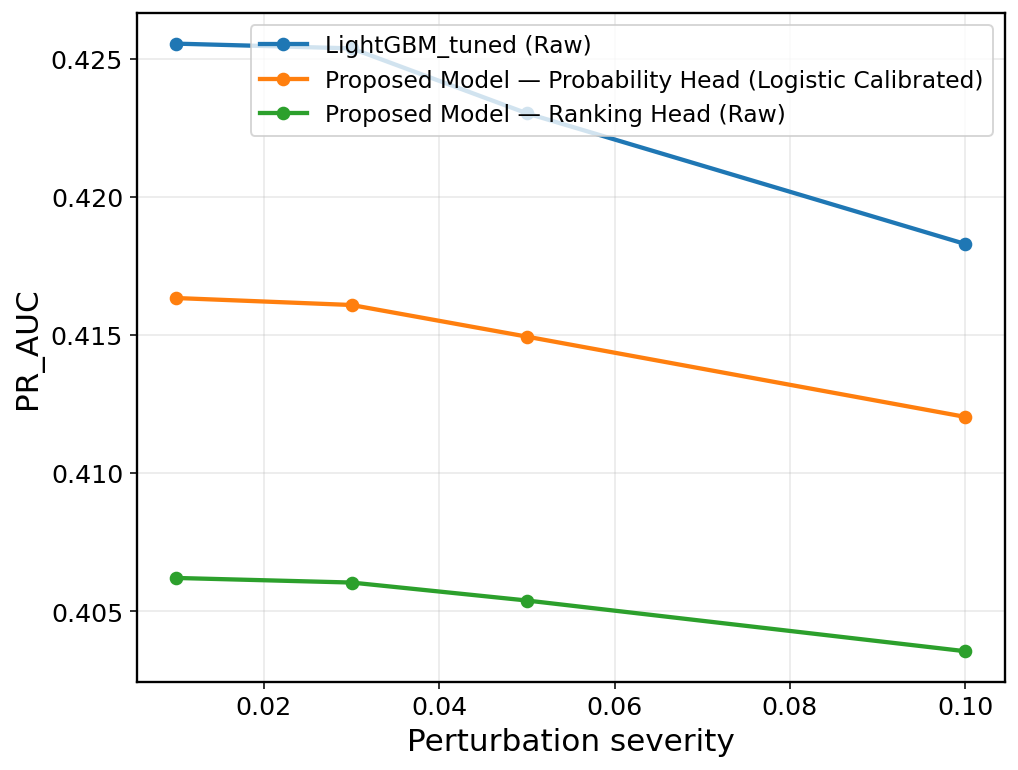

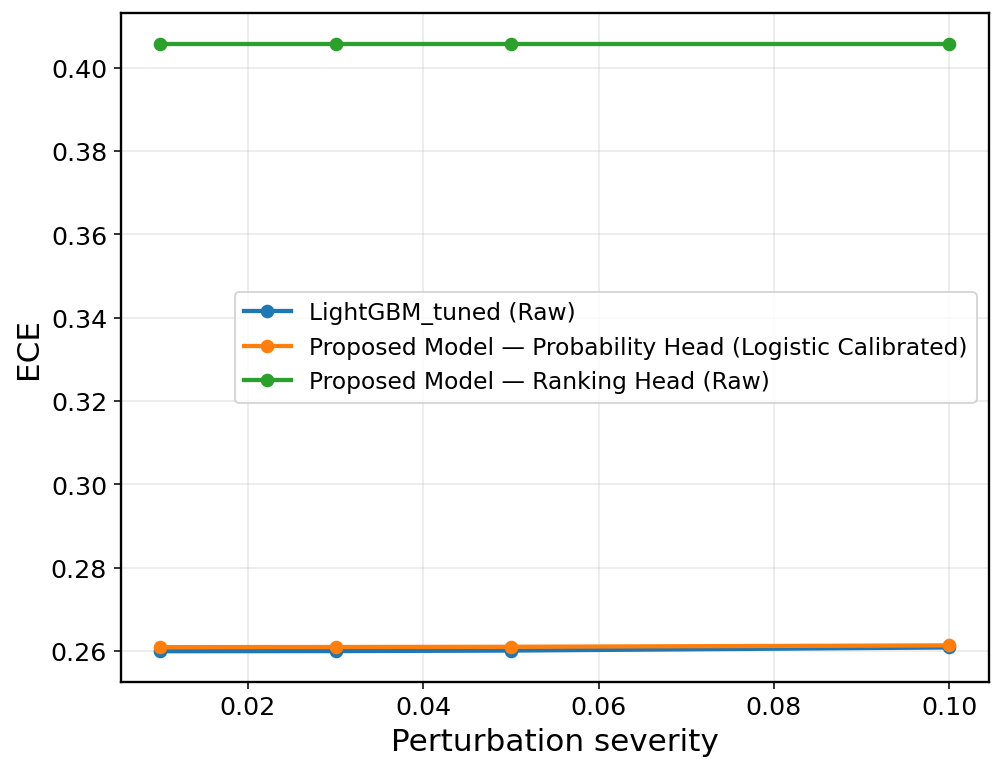

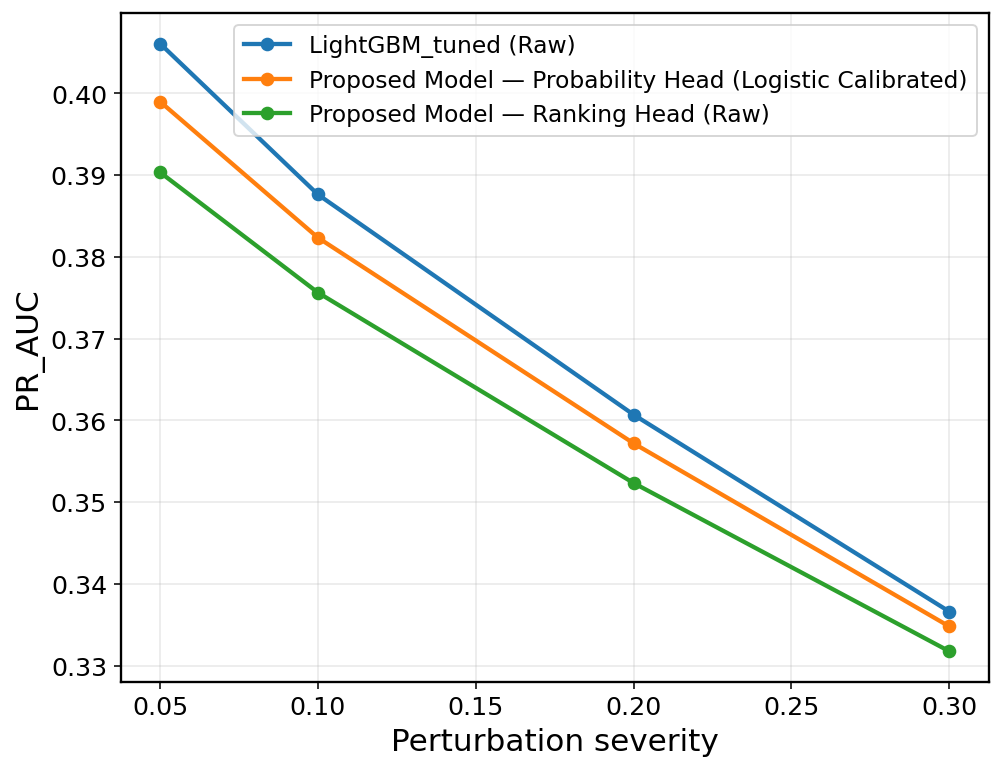

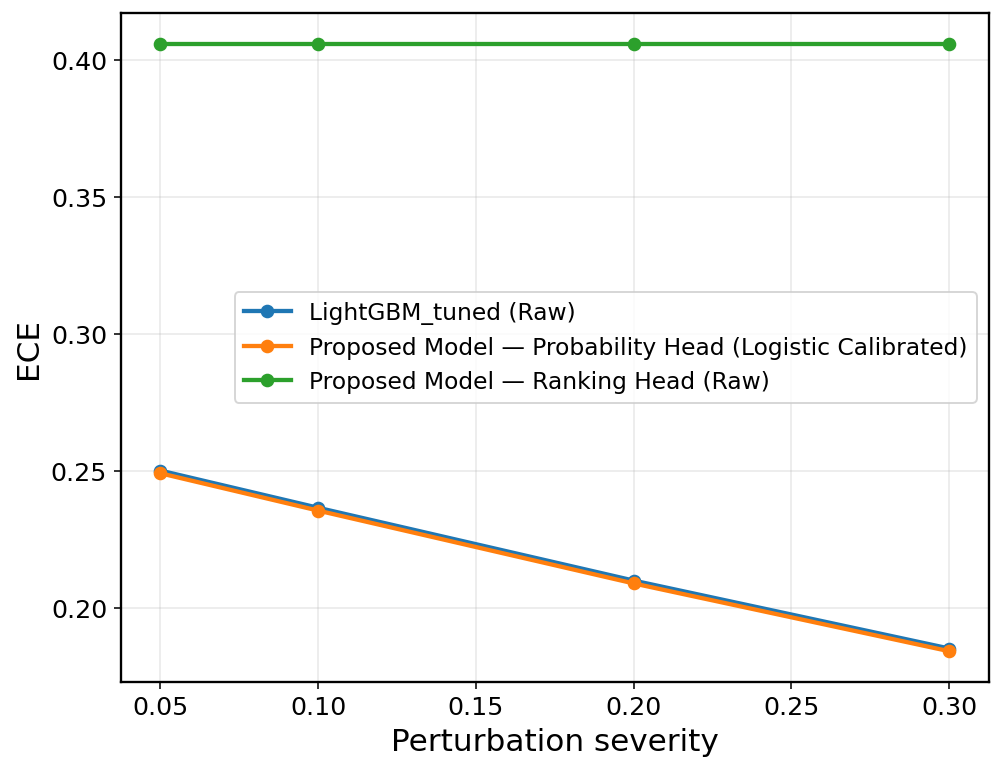

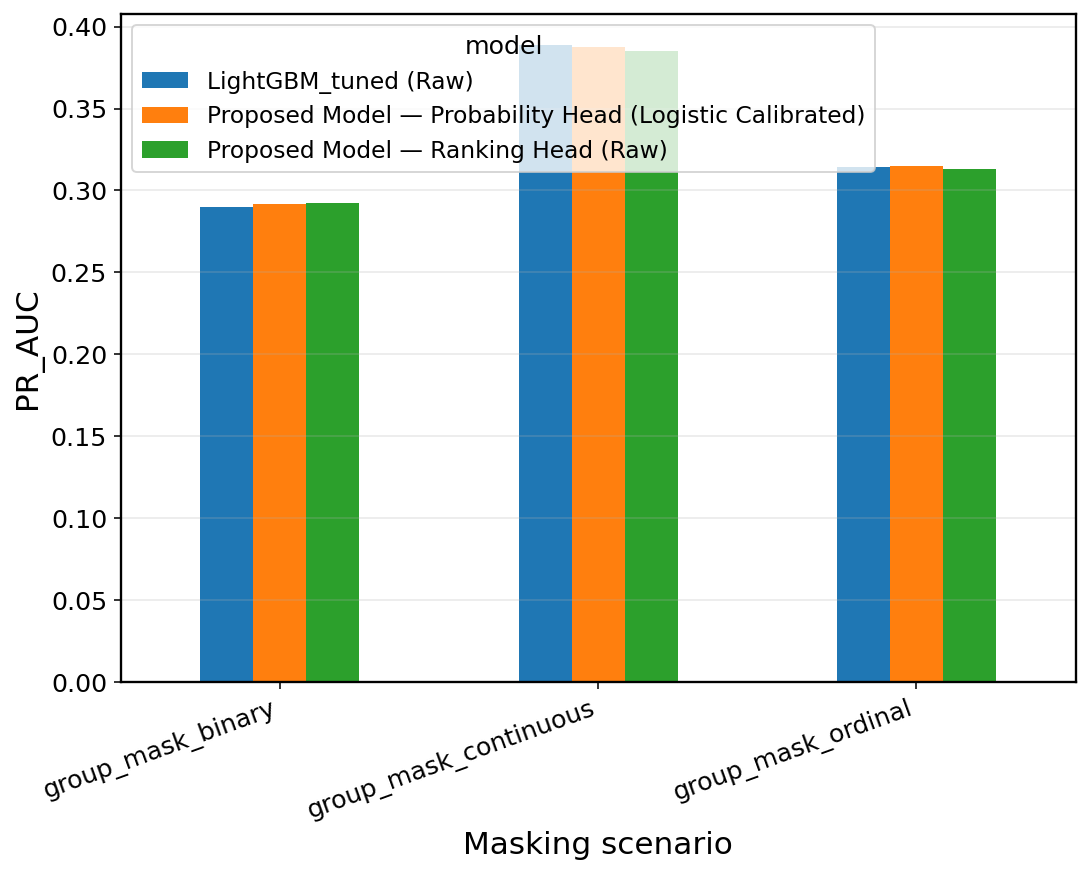

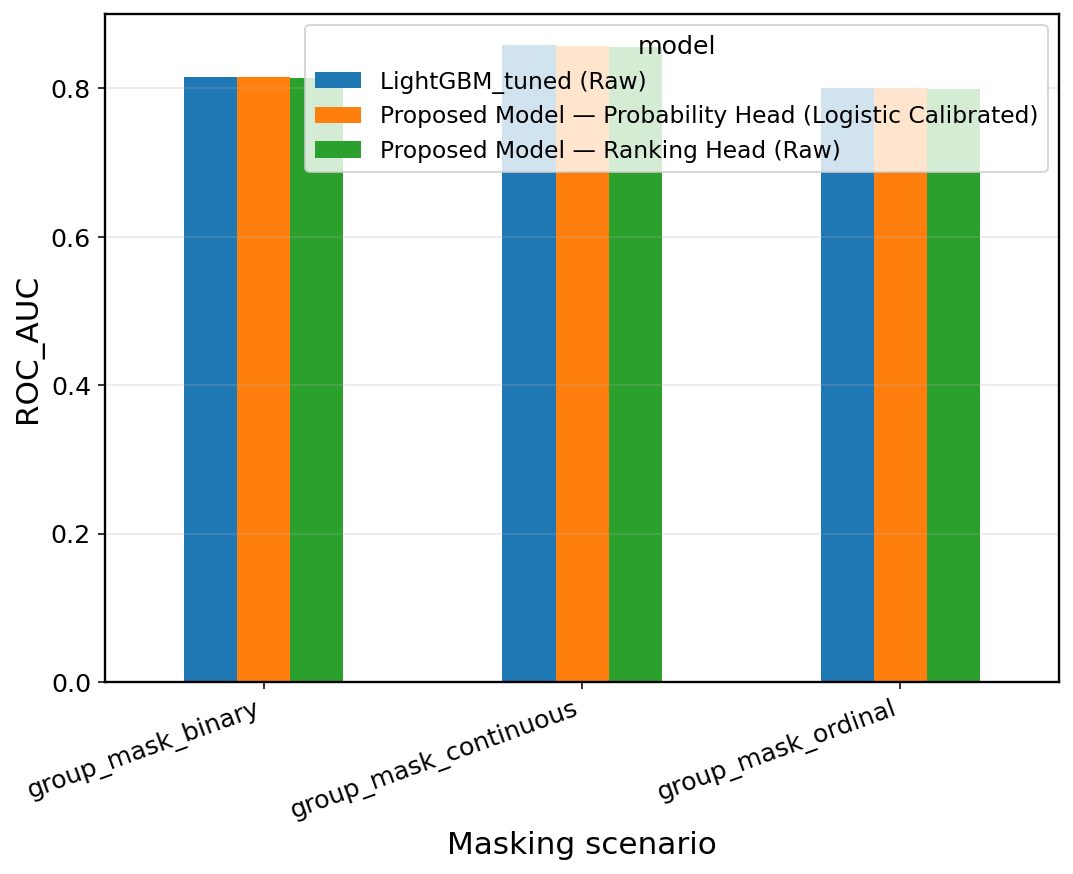

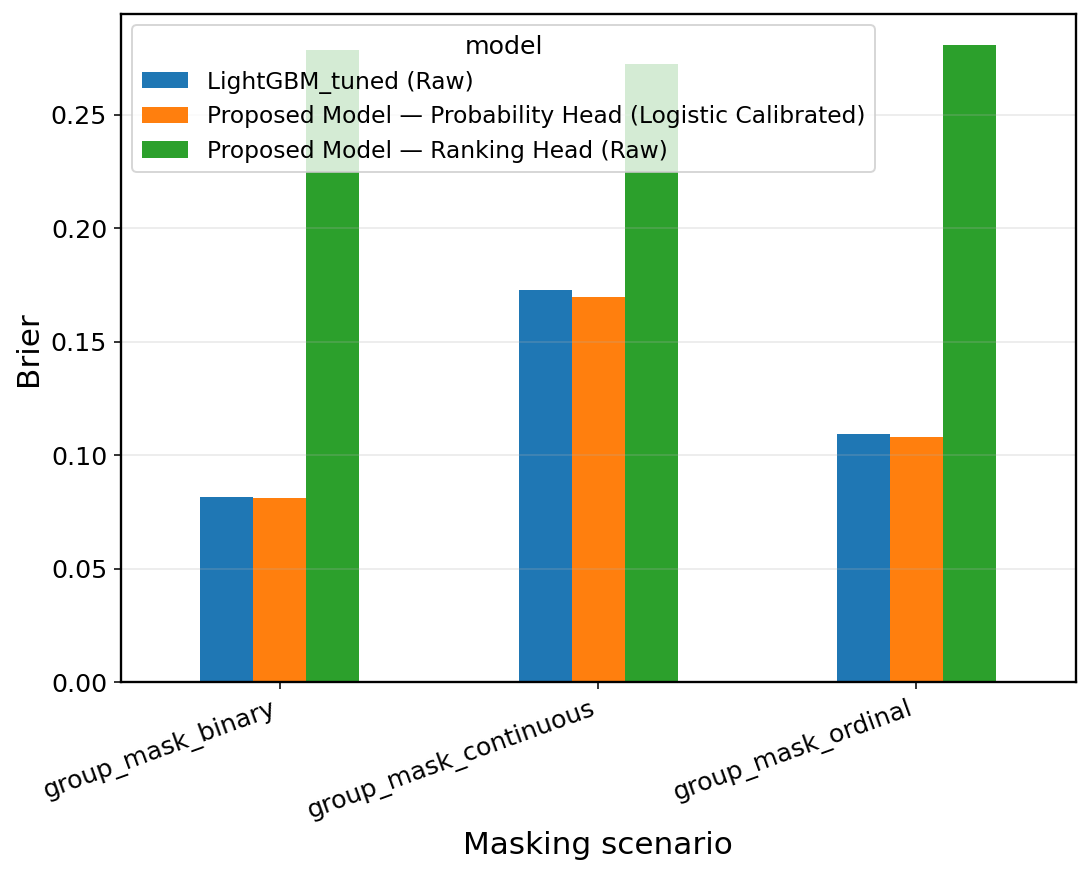

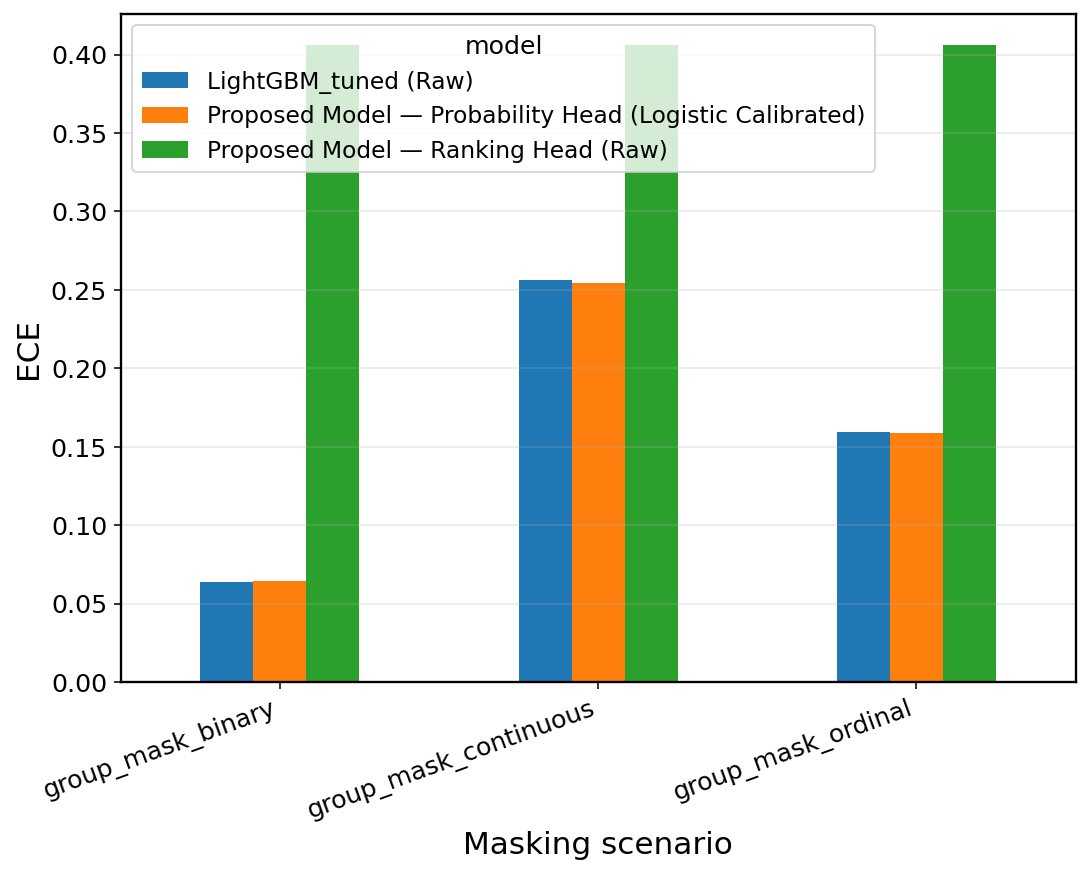


Module 12 summary:
                                               model  \
0                Proposed Model — Ranking Head (Raw)   
1  Proposed Model — Probability Head (Logistic Ca...   
2                               LightGBM_tuned (Raw)   

   worst_noise_delta_PR_AUC  worst_noise_delta_ECE  worst_mask_delta_PR_AUC  \
0                 -0.005032           9.215240e-12                -0.076806   
1                 -0.007099          -2.006616e-03                -0.084317   
2                 -0.009706          -3.469523e-03                -0.091360   

   worst_mask_delta_ECE  
0          1.652588e-10  
1         -1.431348e-02  
2         -1.428659e-02  

Module 12 complete.
Saved robustness tables and paper-ready figures without titles.


In [8]:
# ============================================================
# Module 12 — Robustness analysis
# Purpose:
#   Evaluate robustness of the Proposed Model under realistic
#   perturbations for tabular cardiovascular risk prediction.
#
# Stress tests included:
#   1) Continuous-feature noise injection
#   2) Random feature masking
#   3) Targeted feature-group masking
#
# Compared models:
#   - LightGBM_tuned (Raw)
#   - Proposed Model — Final Probability Head
#   - Proposed Model — Ranking Head (Raw)
#
# Important figure rule:
#   - no titles inside saved images
# ============================================================

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "X_all",
    "y_all",
    "FEATURES",
    "CONT_COLS",
    "BINARY_COLS",
    "ORDINAL_COLS",
    "p_lgb",
    "p_xgb",
    "p_dfm",
    "p_prob_final_pm",
    "p_rank_final_pm",
    "SEED",
    "final_prob_model_name",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 12: {missing_vars}")

# -------------------------
# Imports
# -------------------------
import lightgbm as lgb
import xgboost as xgb
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

# -------------------------
# Helpers
# -------------------------
def refit_lightgbm_full(X_df, y, seed=42):
    pos = int((y == 1).sum())
    neg = int((y == 0).sum())
    scale_pos_weight = neg / max(pos, 1)

    params = dict(
        objective="binary",
        boosting_type="gbdt",
        learning_rate=0.03,
        num_leaves=64,
        min_data_in_leaf=200,
        feature_fraction=0.85,
        bagging_fraction=0.85,
        bagging_freq=1,
        lambda_l2=10.0,
        scale_pos_weight=scale_pos_weight * 1.25,
        metric="auc",
        verbosity=-1,
        seed=seed,
    )

    X_fit = make_ml_matrix(X_df)
    dtrain = lgb.Dataset(X_fit, label=y.astype(int))
    model = lgb.train(params=params, train_set=dtrain, num_boost_round=800)
    return model, X_fit

def refit_xgboost_full(X_df, y, seed=42):
    pos = int((y == 1).sum())
    neg = int((y == 0).sum())
    scale_pos_weight = neg / max(pos, 1)

    X_fit = make_ml_matrix(X_df).values
    dtrain = xgb.DMatrix(X_fit, label=y.astype(int))

    params = dict(
        objective="binary:logistic",
        eval_metric="auc",
        eta=0.03,
        max_depth=6,
        min_child_weight=30,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=10.0,
        scale_pos_weight=scale_pos_weight * 1.25,
        seed=seed,
    )

    model = xgb.train(
        params=params,
        dtrain=dtrain,
        num_boost_round=700,
        verbose_eval=False,
    )
    return model, X_fit

class RobustTabularTensorDataset(Dataset):
    def __init__(self, X):
        self.X = torch.tensor(X, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx]

class DeepFMRobust(nn.Module):
    def __init__(self, n_features, k=16, hidden_dim=256, n_hidden=3, dropout=0.15):
        super().__init__()
        self.linear_w = nn.Parameter(torch.zeros(n_features))
        self.linear_b = nn.Parameter(torch.zeros(1))
        self.V = nn.Parameter(torch.randn(n_features, k) * 0.02)

        self.input_layer = nn.Sequential(
            nn.Linear(n_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )

        hidden_layers = []
        for _ in range(n_hidden):
            hidden_layers += [
                nn.Linear(hidden_dim, hidden_dim),
                nn.LayerNorm(hidden_dim),
                nn.GELU(),
                nn.Dropout(dropout),
            ]
        self.deep = nn.Sequential(*hidden_layers)
        self.out = nn.Linear(hidden_dim + 2, 1)

    def forward(self, x):
        linear_term = (x * self.linear_w.unsqueeze(0)).sum(dim=1) + self.linear_b
        xv = x @ self.V
        xv2 = xv * xv
        x2v2 = (x * x) @ (self.V * self.V)
        fm_term = 0.5 * (xv2 - x2v2).sum(dim=1)

        h = self.input_layer(x)
        h = self.deep(h)
        z = torch.cat([h, linear_term.unsqueeze(1), fm_term.unsqueeze(1)], dim=1)
        return self.out(z).squeeze(-1)

@torch.no_grad()
def predict_proba_deepfm_full(model, X_array, batch_size=4096):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)
    model.eval()

    ds = RobustTabularTensorDataset(X_array.astype(np.float32))
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(device == "cuda"))

    preds = []
    for xb in loader:
        xb = xb.to(device, non_blocking=True)
        logits = model(xb)
        p = torch.sigmoid(logits).detach().cpu().numpy()
        preds.append(p)

    return clip_probs(np.concatenate(preds))

def perturb_continuous_noise(X_df, noise_std_frac=0.05, seed=42):
    Xp = sanitize_dataframe(X_df).copy()
    rng = np.random.default_rng(seed)

    for c in CONT_COLS:
        if c in Xp.columns:
            s = Xp[c].astype(np.float32).values
            std = float(np.std(s))
            noise = rng.normal(0.0, noise_std_frac * max(std, 1e-8), size=len(s))
            Xp[c] = (s + noise).astype(np.float32)

    return sanitize_dataframe(Xp)

def perturb_random_masking(X_df, mask_frac=0.10, seed=42):
    Xp = sanitize_dataframe(X_df).copy()
    rng = np.random.default_rng(seed)

    Xv = Xp.values.copy()
    n, d = Xv.shape
    n_mask = int(round(mask_frac * n * d))
    rows = rng.integers(0, n, size=n_mask)
    cols = rng.integers(0, d, size=n_mask)

    # replace with column medians/modes already encoded in sanitized matrix
    col_fill = np.median(Xv, axis=0)
    Xv[rows, cols] = col_fill[cols]

    Xp = pd.DataFrame(Xv, columns=Xp.columns)
    return sanitize_dataframe(Xp)

def perturb_feature_group_masking(X_df, group_name):
    Xp = sanitize_dataframe(X_df).copy()

    if group_name == "continuous":
        cols = [c for c in CONT_COLS if c in Xp.columns]
    elif group_name == "ordinal":
        cols = [c for c in ORDINAL_COLS if c in Xp.columns]
    elif group_name == "binary":
        cols = [c for c in BINARY_COLS if c in Xp.columns]
    else:
        cols = []

    for c in cols:
        if c in Xp.columns:
            fill_value = float(Xp[c].median())
            Xp[c] = fill_value

    return sanitize_dataframe(Xp)

def evaluate_on_perturbed_predictions(y_true, pred_dict):
    rows = []
    for model_name, p in pred_dict.items():
        rows.append(evaluate_probs(y_true, p, name=model_name))
    return pd.DataFrame(rows)

def plot_robustness_curve(df_long, metric, save_path_base):
    plt.figure(figsize=(8.0, 6.2))

    for model_name, g in df_long.groupby("model"):
        g = g.sort_values("severity")
        plt.plot(g["severity"], g[metric], marker="o", label=model_name)

    plt.xlabel("Perturbation severity")
    plt.ylabel(metric)
    plt.legend(frameon=True)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

# -------------------------
# 12.1 Refit full-data expert models for perturbation testing
# -------------------------
X_robust = X_all.copy()
y_robust = y_all.astype(int)

# LightGBM
lgb_full_model, X_lgb_full = refit_lightgbm_full(X_robust, y_robust, seed=SEED)

# XGBoost
xgb_full_model, X_xgb_full = refit_xgboost_full(X_robust, y_robust, seed=SEED)

# DeepFM: load from architecture and fit using saved OOF surrogate if available is not enough.
# We fit a full model quickly for perturbation-only analysis.
device = "cuda" if torch.cuda.is_available() else "cpu"
pos = int((y_robust == 1).sum())
neg = int((y_robust == 0).sum())
pos_weight_value = float((neg / max(pos, 1)) * 0.75)

X_dfm_full, scaler_info_full = make_dl_matrix(X_robust, X_robust)

train_ds_full = TabularTensorDataset(X_dfm_full.values.astype(np.float32), y_robust.astype(np.float32))
train_loader_full = DataLoader(
    train_ds_full,
    batch_size=4096,
    shuffle=True,
    num_workers=2,
    pin_memory=(device == "cuda"),
)

deepfm_full_model = DeepFMRobust(
    n_features=X_dfm_full.shape[1],
    k=16,
    hidden_dim=256,
    n_hidden=3,
    dropout=0.15,
)

# quick full-data fit
opt = torch.optim.AdamW(deepfm_full_model.parameters(), lr=1e-3, weight_decay=1e-4)
scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)

deepfm_full_model.to(device)
deepfm_full_model.train()
for ep in range(8):
    running_loss = 0.0
    n_seen = 0
    for xb, yb in train_loader_full:
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device, non_blocking=True)
        opt.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=(device == "cuda")):
            logits = deepfm_full_model(xb)
            loss = F.binary_cross_entropy_with_logits(logits, yb, pos_weight=pos_weight_tensor)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        bs = xb.size(0)
        running_loss += loss.item() * bs
        n_seen += bs
    print(f"DeepFM full-data robustness fit epoch {ep+1:02d} | loss={running_loss/max(n_seen,1):.5f}")

# -------------------------
# 12.2 Baseline full-data predictions
# -------------------------
X_lgb_pred = make_ml_matrix(X_robust)
X_xgb_pred = make_ml_matrix(X_robust).values
X_dfm_pred = transform_with_standard_scaler(X_robust.copy(), scaler_info_full)[FEATURES].copy().values

p_lgb_full = clip_probs(lgb_full_model.predict(X_lgb_pred))
p_xgb_full = clip_probs(xgb_full_model.predict(xgb.DMatrix(X_xgb_pred)))
p_dfm_full = predict_proba_deepfm_full(deepfm_full_model, X_dfm_pred)

p_prob_full = clip_probs(0.55 * p_lgb_full + 0.35 * p_xgb_full + 0.10 * p_dfm_full)
p_rank_full = rank_avg([p_lgb_full, p_xgb_full, p_dfm_full])

# -------------------------
# 12.3 Perturbation experiments
# -------------------------
robust_rows = []

def evaluate_scenario(scenario_name, severity_label, Xp):
    Xp_ml = make_ml_matrix(Xp)
    Xp_xgb = Xp_ml.values
    Xp_dfm = transform_with_standard_scaler(Xp.copy(), scaler_info_full)[FEATURES].copy().values

    p_lgb_s = clip_probs(lgb_full_model.predict(Xp_ml))
    p_xgb_s = clip_probs(xgb_full_model.predict(xgb.DMatrix(Xp_xgb)))
    p_dfm_s = predict_proba_deepfm_full(deepfm_full_model, Xp_dfm)

    p_prob_s = clip_probs(0.55 * p_lgb_s + 0.35 * p_xgb_s + 0.10 * p_dfm_s)
    p_rank_s = rank_avg([p_lgb_s, p_xgb_s, p_dfm_s])

    pred_map = {
        "LightGBM_tuned (Raw)": p_lgb_s,
        final_prob_model_name: p_prob_s,
        "Proposed Model — Ranking Head (Raw)": p_rank_s,
    }

    df_eval = evaluate_on_perturbed_predictions(y_robust, pred_map)
    df_eval["scenario"] = scenario_name
    df_eval["severity"] = float(severity_label)
    return df_eval

# Baseline
baseline_eval_df = evaluate_scenario("baseline", 0.00, X_robust)
robust_rows.append(baseline_eval_df)

# Continuous noise
for sev in [0.01, 0.03, 0.05, 0.10]:
    Xp = perturb_continuous_noise(X_robust, noise_std_frac=sev, seed=SEED + int(sev * 1000))
    robust_rows.append(evaluate_scenario("continuous_noise", sev, Xp))

# Random masking
for sev in [0.05, 0.10, 0.20, 0.30]:
    Xp = perturb_random_masking(X_robust, mask_frac=sev, seed=SEED + int(sev * 1000))
    robust_rows.append(evaluate_scenario("random_masking", sev, Xp))

# Targeted feature-group masking
for group_name in ["continuous", "ordinal", "binary"]:
    Xp = perturb_feature_group_masking(X_robust, group_name=group_name)
    robust_rows.append(evaluate_scenario(f"group_mask_{group_name}", 1.00, Xp))

module12_robustness_df = pd.concat(robust_rows, axis=0, ignore_index=True)
module12_robustness_df.to_csv(TAB_DIR / "module12_robustness_results.csv", index=False)

print("\nModule 12 robustness results preview:")
print(module12_robustness_df.head(20))

# -------------------------
# 12.4 Degradation summary
# -------------------------
baseline_ref = module12_robustness_df[module12_robustness_df["scenario"] == "baseline"][["model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]].copy()
baseline_ref = baseline_ref.rename(columns={
    "PR_AUC": "PR_AUC_baseline",
    "ROC_AUC": "ROC_AUC_baseline",
    "Brier": "Brier_baseline",
    "ECE": "ECE_baseline",
})

module12_degradation_df = module12_robustness_df.merge(baseline_ref, on="model", how="left")
module12_degradation_df["delta_PR_AUC"] = module12_degradation_df["PR_AUC"] - module12_degradation_df["PR_AUC_baseline"]
module12_degradation_df["delta_ROC_AUC"] = module12_degradation_df["ROC_AUC"] - module12_degradation_df["ROC_AUC_baseline"]
module12_degradation_df["delta_Brier"] = module12_degradation_df["Brier"] - module12_degradation_df["Brier_baseline"]
module12_degradation_df["delta_ECE"] = module12_degradation_df["ECE"] - module12_degradation_df["ECE_baseline"]

module12_degradation_df.to_csv(TAB_DIR / "module12_robustness_degradation.csv", index=False)

print("\nModule 12 degradation summary preview:")
print(module12_degradation_df.head(20))

# -------------------------
# 12.5 Paper-quality figures without titles
# -------------------------
df_noise = module12_robustness_df[module12_robustness_df["scenario"] == "continuous_noise"].copy()
if len(df_noise) > 0:
    plot_robustness_curve(
        df_noise,
        metric="PR_AUC",
        save_path_base=FIG_DIR / "module12_noise_pr_auc_curve",
    )
    plot_robustness_curve(
        df_noise,
        metric="ECE",
        save_path_base=FIG_DIR / "module12_noise_ece_curve",
    )

df_mask = module12_robustness_df[module12_robustness_df["scenario"] == "random_masking"].copy()
if len(df_mask) > 0:
    plot_robustness_curve(
        df_mask,
        metric="PR_AUC",
        save_path_base=FIG_DIR / "module12_masking_pr_auc_curve",
    )
    plot_robustness_curve(
        df_mask,
        metric="ECE",
        save_path_base=FIG_DIR / "module12_masking_ece_curve",
    )

# Feature-group masking comparison
group_mask_df = module12_robustness_df[module12_robustness_df["scenario"].str.contains("group_mask_")].copy()
if len(group_mask_df) > 0:
    for metric in ["PR_AUC", "ROC_AUC", "Brier", "ECE"]:
        plt.figure(figsize=(8.8, 6.2))
        pivot_df = group_mask_df.pivot(index="scenario", columns="model", values=metric)
        pivot_df.plot(kind="bar", ax=plt.gca())
        plt.xlabel("Masking scenario")
        plt.ylabel(metric)
        plt.xticks(rotation=20, ha="right")
        plt.grid(axis="y")
        save_figure_multi(FIG_DIR / f"module12_groupmask_{metric.lower()}")
        plt.show()

# -------------------------
# 12.6 Compact summary table for manuscript
# -------------------------
summary_rows = []
for model_name, g in module12_degradation_df.groupby("model"):
    tmp_noise = g[g["scenario"] == "continuous_noise"]
    tmp_mask = g[g["scenario"] == "random_masking"]
    summary_rows.append({
        "model": model_name,
        "worst_noise_delta_PR_AUC": float(tmp_noise["delta_PR_AUC"].min()) if len(tmp_noise) > 0 else np.nan,
        "worst_noise_delta_ECE": float(tmp_noise["delta_ECE"].max()) if len(tmp_noise) > 0 else np.nan,
        "worst_mask_delta_PR_AUC": float(tmp_mask["delta_PR_AUC"].min()) if len(tmp_mask) > 0 else np.nan,
        "worst_mask_delta_ECE": float(tmp_mask["delta_ECE"].max()) if len(tmp_mask) > 0 else np.nan,
    })

module12_summary_df = pd.DataFrame(summary_rows).sort_values(
    ["worst_noise_delta_PR_AUC", "worst_mask_delta_PR_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

module12_summary_df.to_csv(TAB_DIR / "module12_robustness_summary.csv", index=False)

print("\nModule 12 summary:")
print(module12_summary_df)

# -------------------------
# 12.7 Save compact prediction bundle
# -------------------------
module12_preds_df = pd.DataFrame({
    "y_true": y_robust.astype(int),
    "p_lightgbm_full_baseline": p_lgb_full,
    "p_xgboost_full_baseline": p_xgb_full,
    "p_deepfm_full_baseline": p_dfm_full,
    "p_proposed_prob_full_baseline": p_prob_full,
    "p_proposed_rank_full_baseline": p_rank_full,
})
module12_preds_df.to_csv(PRED_DIR / "module12_robustness_baseline_predictions.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module12_robustness_baseline_predictions.npz",
    y_true=y_robust.astype(np.int32),
    p_lightgbm_full_baseline=p_lgb_full.astype(np.float32),
    p_xgboost_full_baseline=p_xgb_full.astype(np.float32),
    p_deepfm_full_baseline=p_dfm_full.astype(np.float32),
    p_proposed_prob_full_baseline=p_prob_full.astype(np.float32),
    p_proposed_rank_full_baseline=p_rank_full.astype(np.float32),
)

print("\nModule 12 complete.")
print("Saved robustness tables and paper-ready figures without titles.")

In [ ]:

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "X_all",
    "y_all",
    "FEATURES",
    "CONT_COLS",
    "p_lgb",
    "p_prob_final_pm",
    "p_rank_final_pm",
    "SEED",
    "FIG_DIR",
    "TAB_DIR",
    "PRED_DIR",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 12B: {missing_vars}")

# Optional dependencies from prior modules:
# - lgb_full_model, xgb_full_model, deepfm_full_model, scaler_info_full
# - X_shap_fit, shap_values_use, module10_importance_df
# If not present, this module will still run partially where possible.

from scipy.stats import spearmanr

# -------------------------
# Helpers
# -------------------------
def build_stress_subgroups(X_df):
    subgroups = {}

    if "Age" in X_df.columns:
        subgroups["Age_10_13"] = (X_df["Age"] >= 10)

    if "BMI" in X_df.columns:
        subgroups["BMI_obese"] = (X_df["BMI"] >= 30)

    if "GenHlth" in X_df.columns:
        subgroups["GenHlth_4_5"] = (X_df["GenHlth"] >= 4)

    if "DiffWalk" in X_df.columns:
        subgroups["DiffWalk_1"] = (X_df["DiffWalk"] == 1)

    return subgroups

def evaluate_predictions_basic(y_true, pred_dict):
    rows = []
    for model_name, p in pred_dict.items():
        row = evaluate_probs(y_true, p, name=model_name)
        rows.append(row)
    return pd.DataFrame(rows)

def perturb_copy_continuous_noise(X_df, noise_std_frac=0.05, seed=42):
    Xp = sanitize_dataframe(X_df).copy()
    rng = np.random.default_rng(seed)

    for c in CONT_COLS:
        if c in Xp.columns:
            vals = Xp[c].astype(np.float32).values
            std = float(np.std(vals))
            noise = rng.normal(0.0, noise_std_frac * max(std, 1e-8), size=len(vals))
            Xp[c] = (vals + noise).astype(np.float32)

    return sanitize_dataframe(Xp)

def predict_all_models_from_full_refits(X_df):
    """
    Requires full-data refits from Module 12:
      - lgb_full_model
      - xgb_full_model
      - deepfm_full_model
      - scaler_info_full
    """
    missing = []
    for v in ["lgb_full_model", "xgb_full_model", "deepfm_full_model", "scaler_info_full"]:
        if v not in globals():
            missing.append(v)
    if len(missing) > 0:
        raise ValueError(f"Missing full-refit artifacts from Module 12: {missing}")

    X_ml = make_ml_matrix(X_df)
    X_xgb = X_ml.values
    X_dfm = transform_with_standard_scaler(X_df.copy(), scaler_info_full)[FEATURES].copy().values

    p_lgb_s = clip_probs(lgb_full_model.predict(X_ml))
    p_xgb_s = clip_probs(xgb_full_model.predict(xgb.DMatrix(X_xgb)))
    p_dfm_s = predict_proba_deepfm_full(deepfm_full_model, X_dfm)

    p_prob_s = clip_probs(0.55 * p_lgb_s + 0.35 * p_xgb_s + 0.10 * p_dfm_s)
    p_rank_s = rank_avg([p_lgb_s, p_xgb_s, p_dfm_s])

    return {
        "LightGBM_tuned (Raw)": p_lgb_s,
        final_prob_model_name: p_prob_s,
        "Proposed Model — Ranking Head (Raw)": p_rank_s,
    }

def topk_feature_overlap(features_a, features_b, k=10):
    a = list(features_a[:k])
    b = list(features_b[:k])
    return len(set(a).intersection(set(b))) / max(k, 1)

def shap_stability_single_case(base_shap_row, pert_shap_row, feature_names, k=10):
    base_abs = np.abs(base_shap_row)
    pert_abs = np.abs(pert_shap_row)

    base_rank_idx = np.argsort(-base_abs)
    pert_rank_idx = np.argsort(-pert_abs)

    topk_overlap = topk_feature_overlap(
        [feature_names[i] for i in base_rank_idx],
        [feature_names[i] for i in pert_rank_idx],
        k=k,
    )

    rho = spearmanr(base_abs, pert_abs).correlation
    if rho is None or np.isnan(rho):
        rho = 0.0

    return {
        "topk_overlap": float(topk_overlap),
        "spearman_abs_shap": float(rho),
        "mean_abs_delta_shap": float(np.mean(np.abs(base_shap_row - pert_shap_row))),
    }

def plot_subgroup_stress(df_long, metric, save_path_base):
    plt.figure(figsize=(9.2, 6.4))

    for model_name, g in df_long.groupby("model"):
        x = np.arange(len(g))
        plt.plot(x, g[metric].values, marker="o", label=model_name)

    plt.xticks(np.arange(len(g)), g["subgroup"].values, rotation=25, ha="right")
    plt.xlabel("Subgroup")
    plt.ylabel(metric)
    plt.legend(frameon=True)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

def plot_explanation_stability(df_stab, metric_col, save_path_base):
    plt.figure(figsize=(8.2, 6.0))
    plt.bar(df_stab["case_type"], df_stab[metric_col])
    plt.xlabel("Case")
    plt.ylabel(metric_col)
    plt.xticks(rotation=15, ha="right")
    plt.grid(axis="y")
    save_figure_multi(save_path_base)
    plt.show()

# -------------------------
# 12B.1 Subgroup stress-test robustness
# -------------------------
stress_rows = []
stress_subgroups = build_stress_subgroups(X_all)

if all(v in globals() for v in ["lgb_full_model", "xgb_full_model", "deepfm_full_model", "scaler_info_full"]):
    # mild and moderate perturbation for subgroup stress
    for subgroup_name, mask in stress_subgroups.items():
        idx = np.where(np.asarray(mask).astype(bool))[0]
        if len(idx) < 500:
            continue

        X_sub = X_all.iloc[idx].copy()
        y_sub = y_all[idx].astype(int)

        # baseline on subgroup
        pred_base = predict_all_models_from_full_refits(X_sub)
        df_base = evaluate_predictions_basic(y_sub, pred_base)
        df_base["subgroup"] = subgroup_name
        df_base["scenario"] = "baseline"
        df_base["severity"] = 0.00
        stress_rows.append(df_base)

        # mild noise
        X_sub_noise_mild = perturb_copy_continuous_noise(X_sub, noise_std_frac=0.03, seed=SEED + 31)
        pred_mild = predict_all_models_from_full_refits(X_sub_noise_mild)
        df_mild = evaluate_predictions_basic(y_sub, pred_mild)
        df_mild["subgroup"] = subgroup_name
        df_mild["scenario"] = "noise"
        df_mild["severity"] = 0.03
        stress_rows.append(df_mild)

        # moderate noise
        X_sub_noise_mod = perturb_copy_continuous_noise(X_sub, noise_std_frac=0.10, seed=SEED + 97)
        pred_mod = predict_all_models_from_full_refits(X_sub_noise_mod)
        df_mod = evaluate_predictions_basic(y_sub, pred_mod)
        df_mod["subgroup"] = subgroup_name
        df_mod["scenario"] = "noise"
        df_mod["severity"] = 0.10
        stress_rows.append(df_mod)

    module12b_subgroup_stress_df = pd.concat(stress_rows, axis=0, ignore_index=True) if len(stress_rows) > 0 else pd.DataFrame()
else:
    module12b_subgroup_stress_df = pd.DataFrame()

module12b_subgroup_stress_df.to_csv(TAB_DIR / "module12b_subgroup_stress_results.csv", index=False)

print("\nModule 12B subgroup stress-test preview:")
print(module12b_subgroup_stress_df.head(20))

# Degradation summary within subgroup stress
if len(module12b_subgroup_stress_df) > 0:
    stress_base = module12b_subgroup_stress_df[module12b_subgroup_stress_df["scenario"] == "baseline"][
        ["subgroup", "model", "PR_AUC", "ROC_AUC", "Brier", "ECE"]
    ].rename(columns={
        "PR_AUC": "PR_AUC_base",
        "ROC_AUC": "ROC_AUC_base",
        "Brier": "Brier_base",
        "ECE": "ECE_base",
    })

    module12b_subgroup_stress_delta_df = module12b_subgroup_stress_df.merge(
        stress_base, on=["subgroup", "model"], how="left"
    )
    module12b_subgroup_stress_delta_df["delta_PR_AUC"] = module12b_subgroup_stress_delta_df["PR_AUC"] - module12b_subgroup_stress_delta_df["PR_AUC_base"]
    module12b_subgroup_stress_delta_df["delta_ROC_AUC"] = module12b_subgroup_stress_delta_df["ROC_AUC"] - module12b_subgroup_stress_delta_df["ROC_AUC_base"]
    module12b_subgroup_stress_delta_df["delta_Brier"] = module12b_subgroup_stress_delta_df["Brier"] - module12b_subgroup_stress_delta_df["Brier_base"]
    module12b_subgroup_stress_delta_df["delta_ECE"] = module12b_subgroup_stress_delta_df["ECE"] - module12b_subgroup_stress_delta_df["ECE_base"]
else:
    module12b_subgroup_stress_delta_df = pd.DataFrame()

module12b_subgroup_stress_delta_df.to_csv(TAB_DIR / "module12b_subgroup_stress_degradation.csv", index=False)

# Plot subgroup stress for Proposed Model final head only
if len(module12b_subgroup_stress_delta_df) > 0:
    df_plot_sub = module12b_subgroup_stress_delta_df[
        (module12b_subgroup_stress_delta_df["model"] == final_prob_model_name) &
        (module12b_subgroup_stress_delta_df["severity"] == 0.10)
    ].copy().sort_values("subgroup")

    if len(df_plot_sub) > 0:
        plot_subgroup_stress(
            df_plot_sub,
            metric="delta_PR_AUC",
            save_path_base=FIG_DIR / "module12b_subgroup_stress_delta_prauc",
        )
        plot_subgroup_stress(
            df_plot_sub,
            metric="delta_ECE",
            save_path_base=FIG_DIR / "module12b_subgroup_stress_delta_ece",
        )

# -------------------------
# 12B.2 Explanation stability under perturbation
# -------------------------
# Requires Module 10 SHAP artifacts and a full-data LightGBM model.
explain_rows = []

if all(v in globals() for v in ["lightgbm_full_model", "X_shap_fit", "shap_values_use"]) and ("case_index_df" in globals() or "module10_case_index_df" in globals()):
    case_table = case_index_df.copy() if "case_index_df" in globals() else module10_case_index_df.copy()

    # Mild perturbation only, explanation stability should be checked under small perturbation
    X_shap_pert = perturb_copy_continuous_noise(X_all.copy(), noise_std_frac=0.03, seed=SEED + 777)
    X_shap_pert_fit = make_ml_matrix(X_shap_pert)

    explainer_pert = shap.TreeExplainer(lightgbm_full_model)
    shap_values_pert = explainer_pert.shap_values(X_shap_pert_fit)
    if isinstance(shap_values_pert, list):
        shap_values_pert_use = shap_values_pert[1] if len(shap_values_pert) > 1 else shap_values_pert[0]
    else:
        shap_values_pert_use = shap_values_pert

    # Global stability
    base_global_imp = np.abs(shap_values_use).mean(axis=0)
    pert_global_imp = np.abs(shap_values_pert_use).mean(axis=0)
    global_rank_rho = spearmanr(base_global_imp, pert_global_imp).correlation
    if global_rank_rho is None or np.isnan(global_rank_rho):
        global_rank_rho = 0.0

    module12b_expl_global_df = pd.DataFrame([{
        "global_spearman_mean_abs_shap": float(global_rank_rho),
        "global_mean_abs_delta_shap_importance": float(np.mean(np.abs(base_global_imp - pert_global_imp))),
        "top10_overlap": float(
            topk_feature_overlap(
                module10_importance_df["feature"].tolist(),
                list(pd.DataFrame({
                    "feature": X_shap_pert_fit.columns,
                    "mean_abs_shap": pert_global_imp
                }).sort_values("mean_abs_shap", ascending=False)["feature"]),
                k=10
            )
        ),
    }])
    module12b_expl_global_df.to_csv(TAB_DIR / "module12b_explanation_stability_global.csv", index=False)

    for _, r in case_table.iterrows():
        idx = int(r["index"])
        case_type = r["case_type"]

        stab = shap_stability_single_case(
            base_shap_row=shap_values_use[idx],
            pert_shap_row=shap_values_pert_use[idx],
            feature_names=list(X_shap_fit.columns),
            k=10,
        )
        stab["case_type"] = case_type
        stab["sample_index"] = idx
        explain_rows.append(stab)

    module12b_expl_case_df = pd.DataFrame(explain_rows)
else:
    module12b_expl_global_df = pd.DataFrame()
    module12b_expl_case_df = pd.DataFrame()

module12b_expl_case_df.to_csv(TAB_DIR / "module12b_explanation_stability_cases.csv", index=False)

print("\nModule 12B explanation stability global summary:")
print(module12b_expl_global_df)

print("\nModule 12B explanation stability case summary:")
print(module12b_expl_case_df)

if len(module12b_expl_case_df) > 0:
    plot_explanation_stability(
        module12b_expl_case_df,
        metric_col="topk_overlap",
        save_path_base=FIG_DIR / "module12b_explanation_stability_topk_overlap",
    )
    plot_explanation_stability(
        module12b_expl_case_df,
        metric_col="spearman_abs_shap",
        save_path_base=FIG_DIR / "module12b_explanation_stability_spearman",
    )

# -------------------------
# 12B.3 Compact summary
# -------------------------
summary_row = {
    "subgroup_stress_available": int(len(module12b_subgroup_stress_df) > 0),
    "explanation_stability_available": int(len(module12b_expl_case_df) > 0),
}

if len(module12b_subgroup_stress_delta_df) > 0:
    pm_stress = module12b_subgroup_stress_delta_df[
        module12b_subgroup_stress_delta_df["model"] == final_prob_model_name
    ]
    if len(pm_stress) > 0:
        summary_row["worst_subgroup_delta_PR_AUC"] = float(pm_stress["delta_PR_AUC"].min())
        summary_row["worst_subgroup_delta_ECE"] = float(pm_stress["delta_ECE"].max())
    else:
        summary_row["worst_subgroup_delta_PR_AUC"] = np.nan
        summary_row["worst_subgroup_delta_ECE"] = np.nan
else:
    summary_row["worst_subgroup_delta_PR_AUC"] = np.nan
    summary_row["worst_subgroup_delta_ECE"] = np.nan

if len(module12b_expl_global_df) > 0:
    summary_row["global_shap_rank_spearman"] = float(module12b_expl_global_df.iloc[0]["global_spearman_mean_abs_shap"])
    summary_row["global_top10_overlap"] = float(module12b_expl_global_df.iloc[0]["top10_overlap"])
else:
    summary_row["global_shap_rank_spearman"] = np.nan
    summary_row["global_top10_overlap"] = np.nan

module12b_summary_df = pd.DataFrame([summary_row])
module12b_summary_df.to_csv(TAB_DIR / "module12b_additional_robustness_summary.csv", index=False)

print("\nModule 12B complete.")
print("Saved subgroup stress-test and explanation stability outputs.")


Module 13 HITL triage results:
   coverage_ai  coverage_human    n_ai  n_human  threshold_used  PR_AUC_ai  \
0         0.50            0.50  126840   126840        0.203553   0.053245   
1         0.60            0.40  152208   101472        0.203553   0.231042   
2         0.70            0.30  177576    76104        0.203553   0.358167   
3         0.80            0.20  202944    50736        0.203553   0.382854   
4         0.90            0.10  228312    25368        0.203553   0.382615   
5         0.95            0.05  240996    12684        0.203553   0.379634   
6         1.00            0.00  253680        0        0.203553   0.377174   

   ROC_AUC_ai  Brier_ai    ECE_ai  Precision_ai  Recall_ai     F1_ai  \
0    0.760776  0.013865  0.000914      0.153846   0.002199  0.004336   
1    0.822886  0.022507  0.001384      0.432984   0.186590  0.260793   
2    0.863317  0.035038  0.002058      0.422853   0.395088  0.408499   
3    0.868401  0.047614  0.002168      0.388518   0.485

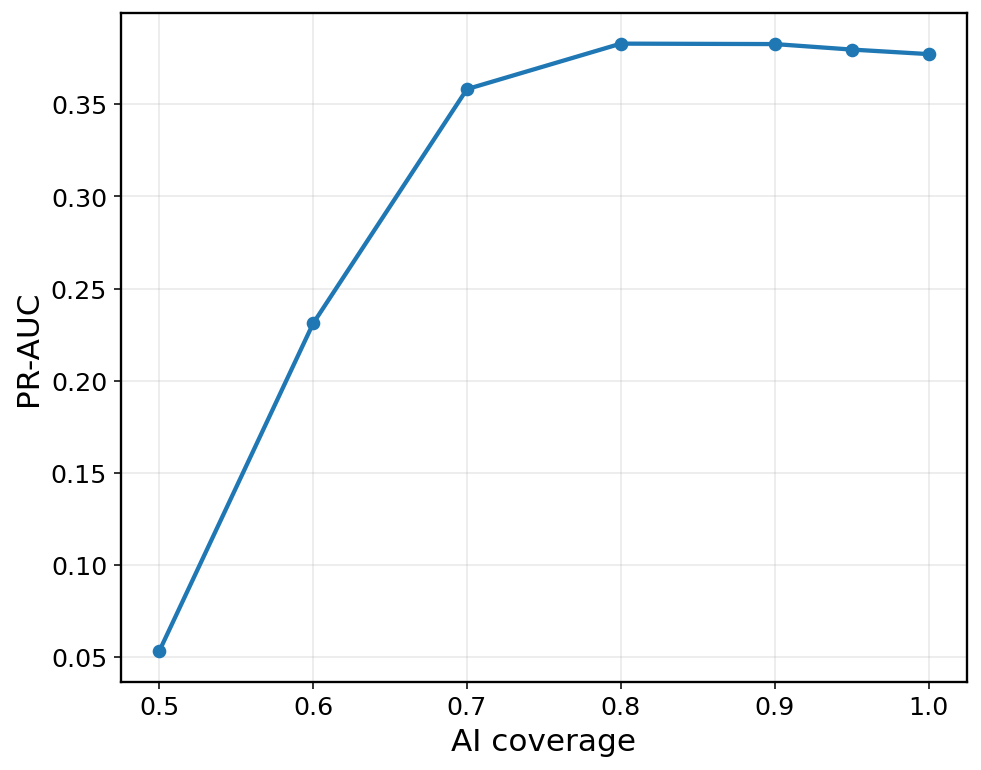

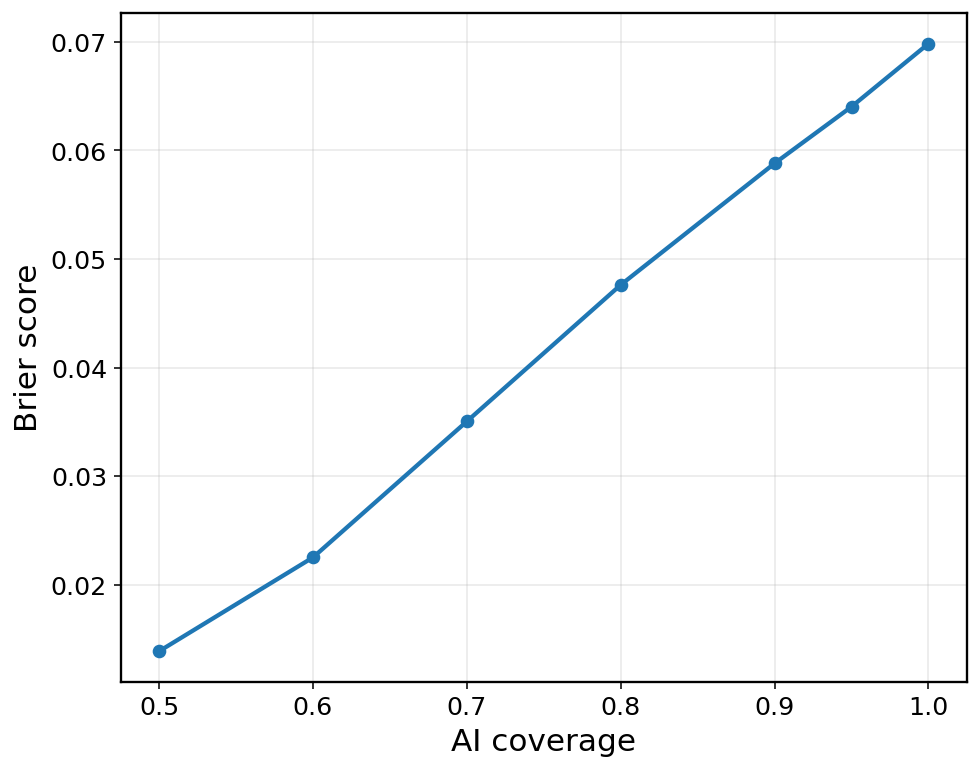

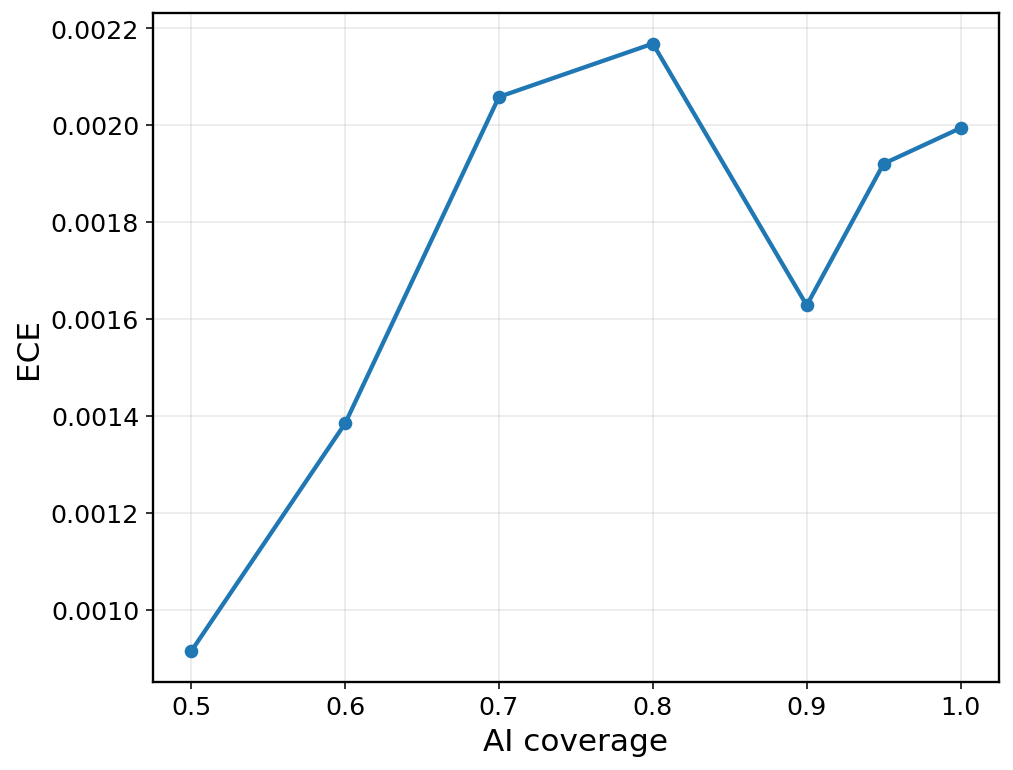

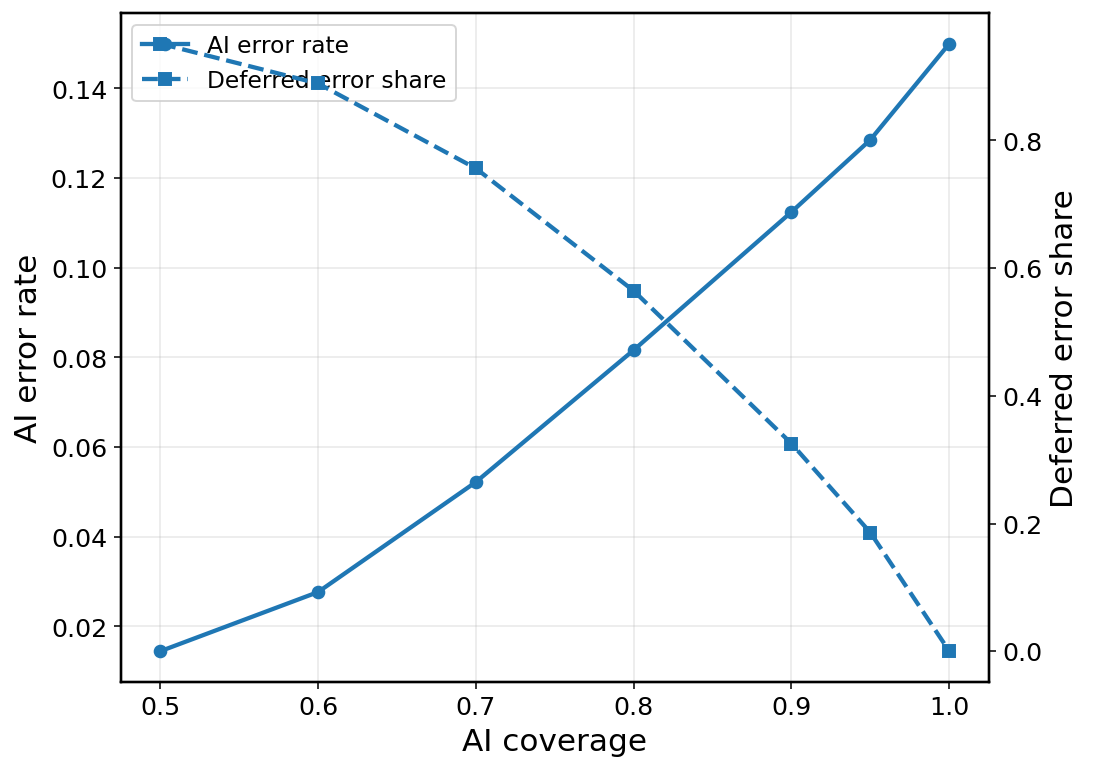


Module 13 complete.
Saved HITL triage tables and paper-ready figures without titles.


In [9]:
# ============================================================
# Module 13 — Human-in-the-Loop triage
# Purpose:
#   Simulate a human-in-the-loop triage workflow using the
#   Proposed Model uncertainty estimates.
#
# Workflow:
#   - low-uncertainty cases -> automated model decision
#   - high-uncertainty cases -> deferred to human review
#
# Main goals:
#   - quantify coverage vs retained performance
#   - quantify how many errors can be deferred
#   - produce paper-ready HITL tables and figures
#
# Important figure rule:
#   - no titles inside saved images
# ============================================================

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "y_all",
    "p_prob_final_pm",
    "final_prob_model_name",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 13: {missing_vars}")

if "module11_uncertainty_df" not in globals():
    raise ValueError("Module 13 requires module11_uncertainty_df from Module 11.")

# -------------------------
# Helpers
# -------------------------
def hitl_triage_metrics(y_true, p, uncertainty, coverages):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    uncertainty = np.asarray(uncertainty).astype(np.float32)

    n = len(y_true)
    order = np.argsort(uncertainty)  # lowest uncertainty retained by AI

    rows = []
    global_thr = find_best_f1_threshold(y_true, p)

    for coverage in coverages:
        k = max(1, int(round(coverage * n)))
        ai_idx = order[:k]
        human_idx = order[k:]

        y_ai = y_true[ai_idx]
        p_ai = p[ai_idx]

        pred_ai = (p_ai >= global_thr).astype(int)
        err_ai = (pred_ai != y_ai).astype(int)

        row_eval = evaluate_probs(y_ai, p_ai, name="AI_retained")

        rows.append({
            "coverage_ai": float(coverage),
            "coverage_human": float(1.0 - coverage),
            "n_ai": int(len(ai_idx)),
            "n_human": int(len(human_idx)),
            "threshold_used": float(global_thr),
            "PR_AUC_ai": float(row_eval["PR_AUC"]),
            "ROC_AUC_ai": float(row_eval["ROC_AUC"]),
            "Brier_ai": float(row_eval["Brier"]),
            "ECE_ai": float(row_eval["ECE"]),
            "Precision_ai": float(precision_score(y_ai, pred_ai, zero_division=0)),
            "Recall_ai": float(recall_score(y_ai, pred_ai, zero_division=0)),
            "F1_ai": float(f1_score(y_ai, pred_ai, zero_division=0)),
            "ErrorRate_ai": float(err_ai.mean()),
            "PosRate_ai": float(y_ai.mean()),
            "MeanUncertainty_ai": float(uncertainty[ai_idx].mean()),
            "MeanUncertainty_human": float(uncertainty[human_idx].mean()) if len(human_idx) > 0 else 0.0,
            "DeferredErrorsShare": float(module11_uncertainty_df.iloc[human_idx]["is_error"].sum() / max(module11_uncertainty_df["is_error"].sum(), 1)),
            "DeferredPositivesShare": float(y_true[human_idx].sum() / max(y_true.sum(), 1)),
        })

    return pd.DataFrame(rows)

def hitl_case_mix_table(df_unc, coverage):
    n = len(df_unc)
    k = max(1, int(round(coverage * n)))
    order = np.argsort(df_unc["uncertainty_score"].values)

    ai_idx = order[:k]
    human_idx = order[k:]

    def summarize_subset(g, label):
        return {
            "subset": label,
            "N": int(len(g)),
            "positive_rate": float(g["y_true"].mean()) if len(g) > 0 else 0.0,
            "error_rate": float(g["is_error"].mean()) if len(g) > 0 else 0.0,
            "fp_rate": float(g["is_fp"].mean()) if len(g) > 0 else 0.0,
            "fn_rate": float(g["is_fn"].mean()) if len(g) > 0 else 0.0,
            "mean_probability": float(g["p_final"].mean()) if len(g) > 0 else 0.0,
            "mean_uncertainty": float(g["uncertainty_score"].mean()) if len(g) > 0 else 0.0,
        }

    df_ai = df_unc.iloc[ai_idx].copy()
    df_human = df_unc.iloc[human_idx].copy()

    return pd.DataFrame([
        summarize_subset(df_ai, "AI_retained"),
        summarize_subset(df_human, "Human_review"),
    ])

def plot_hitl_curve(df_hitl, x_col, y_col, ylabel, save_path_base):
    plt.figure(figsize=(7.8, 6.2))
    plt.plot(df_hitl[x_col], df_hitl[y_col], marker="o")
    plt.xlabel("AI coverage")
    plt.ylabel(ylabel)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

def plot_hitl_dual_curve(df_hitl, save_path_base):
    fig, ax1 = plt.subplots(figsize=(8.0, 6.2))
    ax1.plot(df_hitl["coverage_ai"], df_hitl["ErrorRate_ai"], marker="o", label="AI error rate")
    ax1.set_xlabel("AI coverage")
    ax1.set_ylabel("AI error rate")
    ax1.grid(True)

    ax2 = ax1.twinx()
    ax2.plot(df_hitl["coverage_ai"], df_hitl["DeferredErrorsShare"], marker="s", linestyle="--", label="Deferred error share")
    ax2.set_ylabel("Deferred error share")

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, frameon=True, loc="best")

    save_figure_multi(save_path_base)
    plt.show()

# -------------------------
# Inputs
# -------------------------
df_hitl_unc = module11_uncertainty_df.copy()
coverage_grid = [0.50, 0.60, 0.70, 0.80, 0.90, 0.95, 1.00]

# -------------------------
# 13.1 Main HITL triage table
# -------------------------
module13_hitl_df = hitl_triage_metrics(
    y_true=y_all,
    p=p_prob_final_pm,
    uncertainty=df_hitl_unc["uncertainty_score"].values,
    coverages=coverage_grid,
)
module13_hitl_df.to_csv(TAB_DIR / "module13_hitl_triage_results.csv", index=False)

print("\nModule 13 HITL triage results:")
print(module13_hitl_df)

# -------------------------
# 13.2 Recommended operating points
# -------------------------
# pick a few candidate coverage levels for manuscript reporting
candidate_coverages = [0.70, 0.80, 0.90]
module13_hitl_candidates_df = module13_hitl_df[
    module13_hitl_df["coverage_ai"].isin(candidate_coverages)
].copy().reset_index(drop=True)

module13_hitl_candidates_df.to_csv(TAB_DIR / "module13_hitl_candidate_coverages.csv", index=False)

print("\nModule 13 candidate coverage levels:")
print(module13_hitl_candidates_df)

# -------------------------
# 13.3 Case-mix analysis at 80% AI coverage
# -------------------------
module13_case_mix_df = hitl_case_mix_table(df_hitl_unc, coverage=0.80)
module13_case_mix_df.to_csv(TAB_DIR / "module13_hitl_case_mix_80pct.csv", index=False)

print("\nModule 13 case-mix at 80% AI coverage:")
print(module13_case_mix_df)

# -------------------------
# 13.4 Compact summary for manuscript
# -------------------------
row80 = module13_hitl_df.loc[np.isclose(module13_hitl_df["coverage_ai"], 0.80)].iloc[0]
row90 = module13_hitl_df.loc[np.isclose(module13_hitl_df["coverage_ai"], 0.90)].iloc[0]

module13_summary_df = pd.DataFrame([{
    "model": final_prob_model_name,
    "PR_AUC_at_80pct_AI_coverage": float(row80["PR_AUC_ai"]),
    "Brier_at_80pct_AI_coverage": float(row80["Brier_ai"]),
    "ECE_at_80pct_AI_coverage": float(row80["ECE_ai"]),
    "ErrorRate_at_80pct_AI_coverage": float(row80["ErrorRate_ai"]),
    "DeferredErrorsShare_at_80pct_AI_coverage": float(row80["DeferredErrorsShare"]),
    "PR_AUC_at_90pct_AI_coverage": float(row90["PR_AUC_ai"]),
    "Brier_at_90pct_AI_coverage": float(row90["Brier_ai"]),
    "ECE_at_90pct_AI_coverage": float(row90["ECE_ai"]),
    "ErrorRate_at_90pct_AI_coverage": float(row90["ErrorRate_ai"]),
    "DeferredErrorsShare_at_90pct_AI_coverage": float(row90["DeferredErrorsShare"]),
}])
module13_summary_df.to_csv(TAB_DIR / "module13_hitl_summary.csv", index=False)

print("\nModule 13 summary:")
print(module13_summary_df)

# -------------------------
# 13.5 Paper-quality figures without titles
# -------------------------
plot_hitl_curve(
    module13_hitl_df,
    x_col="coverage_ai",
    y_col="PR_AUC_ai",
    ylabel="PR-AUC",
    save_path_base=FIG_DIR / "module13_hitl_prauc_vs_coverage",
)

plot_hitl_curve(
    module13_hitl_df,
    x_col="coverage_ai",
    y_col="Brier_ai",
    ylabel="Brier score",
    save_path_base=FIG_DIR / "module13_hitl_brier_vs_coverage",
)

plot_hitl_curve(
    module13_hitl_df,
    x_col="coverage_ai",
    y_col="ECE_ai",
    ylabel="ECE",
    save_path_base=FIG_DIR / "module13_hitl_ece_vs_coverage",
)

plot_hitl_dual_curve(
    module13_hitl_df,
    save_path_base=FIG_DIR / "module13_hitl_error_and_deferred_error_share",
)

# -------------------------
# 13.6 Save compact prediction bundle
# -------------------------
module13_preds_df = pd.DataFrame({
    "y_true": y_all.astype(int),
    "p_proposed_prob_final": p_prob_final_pm,
    "uncertainty_score": df_hitl_unc["uncertainty_score"].values,
    "is_error": df_hitl_unc["is_error"].values,
    "is_fp": df_hitl_unc["is_fp"].values,
    "is_fn": df_hitl_unc["is_fn"].values,
})
module13_preds_df.to_csv(PRED_DIR / "module13_hitl_predictions.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module13_hitl_predictions.npz",
    y_true=y_all.astype(np.int32),
    p_proposed_prob_final=p_prob_final_pm.astype(np.float32),
    uncertainty_score=df_hitl_unc["uncertainty_score"].values.astype(np.float32),
    is_error=df_hitl_unc["is_error"].values.astype(np.int32),
    is_fp=df_hitl_unc["is_fp"].values.astype(np.int32),
    is_fn=df_hitl_unc["is_fn"].values.astype(np.int32),
)

print("\nModule 13 complete.")
print("Saved HITL triage tables and paper-ready figures without titles.")


Top uncertain HITL samples:
   sample_id patient_label  y_true  pred_label   p_final  uncertainty_score  \
0     165200     Patient 1       1           1  0.420241           0.982166   
1     165769     Patient 2       1           1  0.457093           0.968648   
2      49456     Patient 3       0           1  0.449085           0.966428   
3      73990     Patient 4       1           1  0.431107           0.965567   
4     129568     Patient 5       0           1  0.409093           0.961609   
5     159116     Patient 6       0           1  0.352919           0.961454   
6      36677     Patient 7       0           1  0.365444           0.959748   
7     176482     Patient 8       1           1  0.359089           0.958461   
8      14747     Patient 9       0           1  0.382448           0.958321   
9     128102    Patient 10       1           1  0.373757           0.957678   

   referred  correct  
0         1        1  
1         1        1  
2         1        0  
3        

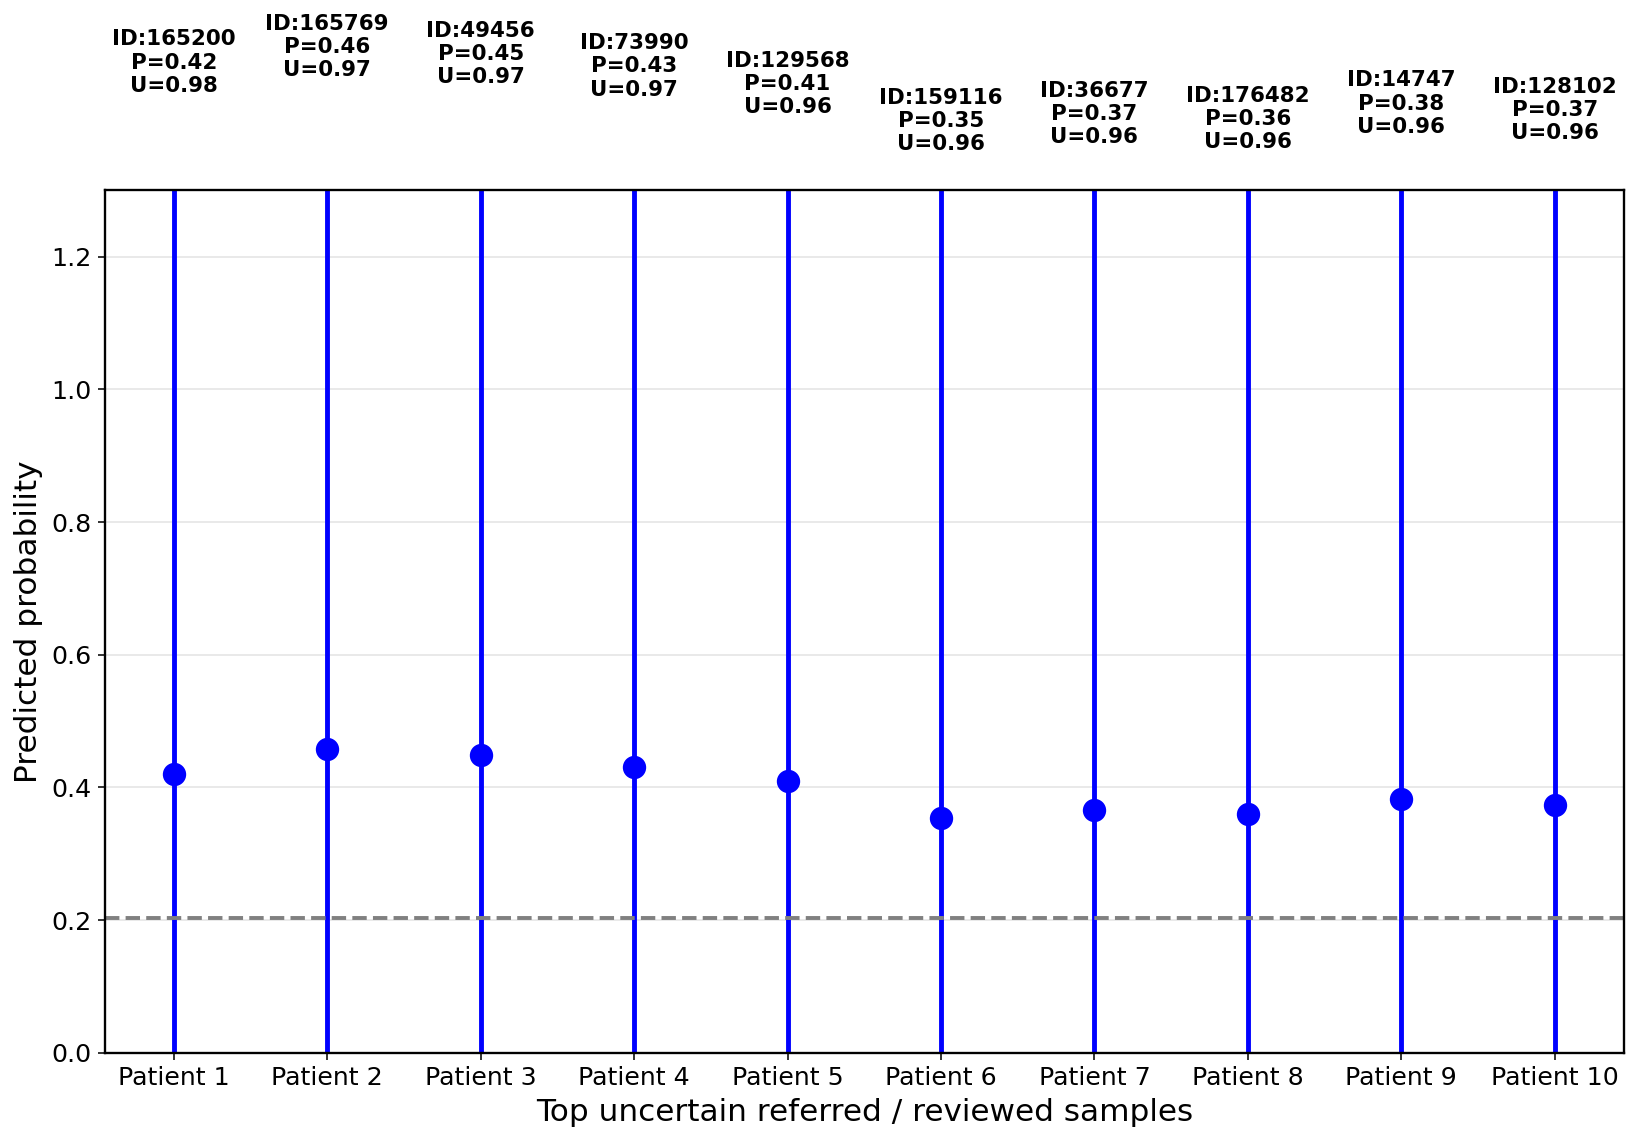


Module 13B complete.
Saved patient-level HITL referral figure and sample table.


In [10]:
# ============================================================
# Module 13B — Patient-level HITL referral visualization
# Purpose:
#   Visualize which individual samples are referred for human review
#   in the Proposed Model HITL workflow.
#
# Figure design:
#   - Top K most uncertain samples
#   - y-axis: predicted probability
#   - error bars: uncertainty
#   - blue  -> referred to human
#   - green -> auto-decided and correct
#   - red   -> auto-decided and incorrect
#
# Important figure rule:
#   - no title inside saved images
# ============================================================

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "y_all",
    "p_prob_final_pm",
    "module11_uncertainty_df",
    "FIG_DIR",
    "TAB_DIR",
    "save_figure_multi",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 13B: {missing_vars}")

# -------------------------
# Config
# -------------------------
TOP_K_UNCERTAIN = 10
HITL_COVERAGE = 0.80   # 80% handled by AI, 20% referred
ANNOTATE_POINTS = True

# -------------------------
# Build plotting dataframe
# -------------------------
df_hitl_vis = module11_uncertainty_df.copy().reset_index(drop=False)
df_hitl_vis = df_hitl_vis.rename(columns={"index": "sample_id"})

n_total = len(df_hitl_vis)
n_ai = max(1, int(round(HITL_COVERAGE * n_total)))

# lowest uncertainty kept by AI; highest uncertainty referred
order = np.argsort(df_hitl_vis["uncertainty_score"].values)
ai_idx = order[:n_ai]
ref_idx = order[n_ai:]

df_hitl_vis["referred"] = 0
df_hitl_vis.loc[ref_idx, "referred"] = 1

thr_hitl = find_best_f1_threshold(y_all, p_prob_final_pm)
df_hitl_vis["pred_label"] = (df_hitl_vis["p_final"].values >= thr_hitl).astype(int)
df_hitl_vis["correct"] = (df_hitl_vis["pred_label"].values == df_hitl_vis["y_true"].values).astype(int)

# Top K most uncertain samples
df_top_unc = (
    df_hitl_vis.sort_values("uncertainty_score", ascending=False)
    .head(TOP_K_UNCERTAIN)
    .copy()
    .reset_index(drop=True)
)

df_top_unc["patient_label"] = [f"Patient {i+1}" for i in range(len(df_top_unc))]

# color logic
def get_point_color(row):
    if row["referred"] == 1:
        return "blue"
    elif row["correct"] == 1:
        return "green"
    else:
        return "red"

df_top_unc["color"] = df_top_unc.apply(get_point_color, axis=1)

# -------------------------
# Save table for paper / appendix
# -------------------------
module13b_referral_table = df_top_unc[[
    "sample_id",
    "patient_label",
    "y_true",
    "pred_label",
    "p_final",
    "uncertainty_score",
    "referred",
    "correct",
]].copy()

module13b_referral_table.to_csv(
    TAB_DIR / "module13b_top_uncertain_referred_samples.csv",
    index=False
)

print("\nTop uncertain HITL samples:")
print(module13b_referral_table)

# -------------------------
# Plot
# -------------------------
plt.figure(figsize=(14, 8))

x = np.arange(len(df_top_unc))
y = df_top_unc["p_final"].values
u = df_top_unc["uncertainty_score"].values

# Scale uncertainty bars for visualization
# You may tune this multiplier depending on visual appearance
yerr = u

for i, row in df_top_unc.iterrows():
    plt.errorbar(
        x[i],
        y[i],
        yerr=yerr[i],
        fmt="o",
        markersize=11,
        capsize=8,
        elinewidth=2.5,
        color=row["color"],
    )

    if ANNOTATE_POINTS:
        txt = f"ID:{int(row['sample_id'])}\nP={row['p_final']:.2f}\nU={row['uncertainty_score']:.2f}"
        plt.text(
            x[i],
            y[i] + yerr[i] + 0.04,
            txt,
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
        )

plt.axhline(y=thr_hitl, linestyle="--", linewidth=2, color="gray")

plt.xticks(x, df_top_unc["patient_label"].tolist())
plt.xlabel("Top uncertain referred / reviewed samples")
plt.ylabel("Predicted probability")
plt.ylim(0, min(1.3, max(y + yerr) + 0.15))
plt.grid(True, alpha=0.35)

save_figure_multi(FIG_DIR / "module13b_patient_level_hitl_referral")
plt.show()

print("\nModule 13B complete.")
print("Saved patient-level HITL referral figure and sample table.")

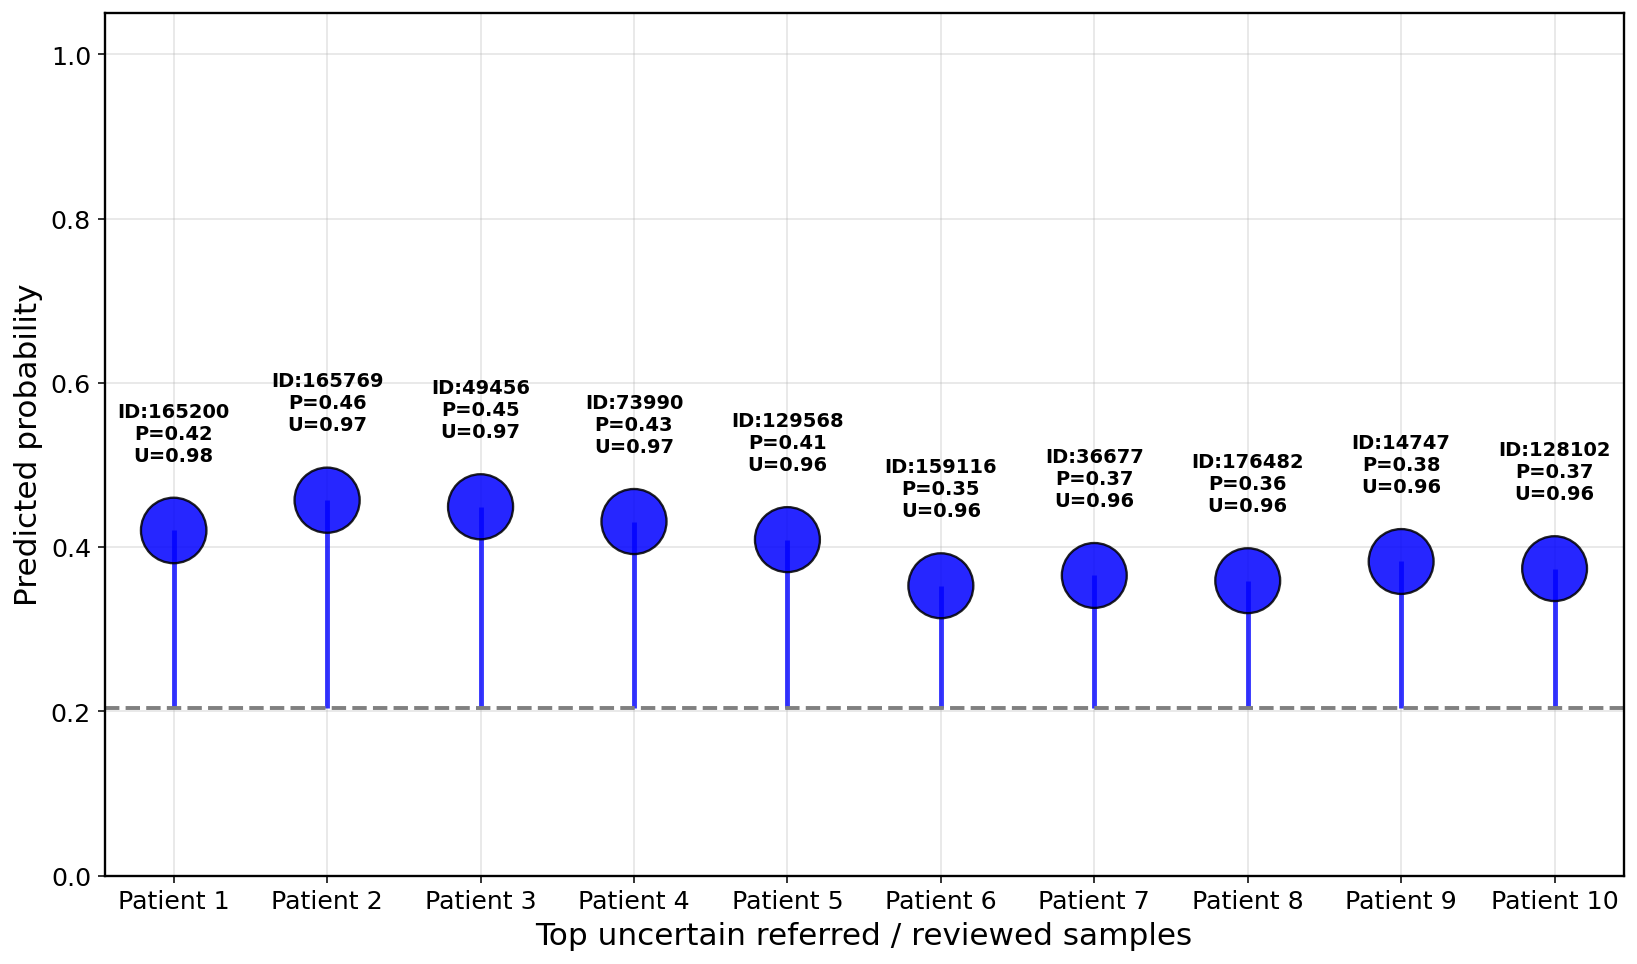

In [11]:
# ============================================================
# Improved patient-level HITL referral plot
# Bubble plot version
# ============================================================

TOP_K_UNCERTAIN = 10
HITL_COVERAGE = 0.80

df_hitl_vis = module11_uncertainty_df.copy().reset_index(drop=False)
df_hitl_vis = df_hitl_vis.rename(columns={"index": "sample_id"})

n_total = len(df_hitl_vis)
n_ai = max(1, int(round(HITL_COVERAGE * n_total)))

order = np.argsort(df_hitl_vis["uncertainty_score"].values)
ai_idx = order[:n_ai]
ref_idx = order[n_ai:]

df_hitl_vis["referred"] = 0
df_hitl_vis.loc[ref_idx, "referred"] = 1

thr_hitl = find_best_f1_threshold(y_all, p_prob_final_pm)
df_hitl_vis["pred_label"] = (df_hitl_vis["p_final"].values >= thr_hitl).astype(int)
df_hitl_vis["correct"] = (df_hitl_vis["pred_label"].values == df_hitl_vis["y_true"].values).astype(int)

df_top_unc = (
    df_hitl_vis.sort_values("uncertainty_score", ascending=False)
    .head(TOP_K_UNCERTAIN)
    .copy()
    .reset_index(drop=True)
)

df_top_unc["patient_label"] = [f"Patient {i+1}" for i in range(len(df_top_unc))]

def get_color(row):
    if row["referred"] == 1:
        return "blue"
    elif row["correct"] == 1:
        return "green"
    else:
        return "red"

df_top_unc["color"] = df_top_unc.apply(get_color, axis=1)

# scale point size by uncertainty
sizes = 250 + 900 * df_top_unc["uncertainty_score"].values

plt.figure(figsize=(14, 8))
x = np.arange(len(df_top_unc))
y = df_top_unc["p_final"].values

# lollipop stems
for i in range(len(df_top_unc)):
    plt.vlines(x[i], thr_hitl, y[i], color=df_top_unc.loc[i, "color"], linewidth=2.5, alpha=0.8)

# bubbles
plt.scatter(
    x,
    y,
    s=sizes,
    c=df_top_unc["color"].values,
    alpha=0.85,
    edgecolors="black",
    linewidths=1.2,
    zorder=3
)

# threshold line
plt.axhline(y=thr_hitl, linestyle="--", linewidth=2, color="gray")

# annotations
for i, row in df_top_unc.iterrows():
    txt = f"ID:{int(row['sample_id'])}\nP={row['p_final']:.2f}\nU={row['uncertainty_score']:.2f}"
    plt.text(
        x[i],
        min(1.03, y[i] + 0.08),
        txt,
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )

plt.xticks(x, df_top_unc["patient_label"].tolist())
plt.xlabel("Top uncertain referred / reviewed samples")
plt.ylabel("Predicted probability")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.35)

save_figure_multi(FIG_DIR / "module13b_patient_level_hitl_referral_bubble")
plt.show()


Top uncertain HITL samples:
   sample_id patient_label  y_true  pred_label   p_final  uncertainty_score  \
0     165200     Patient 1       1           1  0.420241           0.982166   
1     165769     Patient 2       1           1  0.457093           0.968648   
2      49456     Patient 3       0           1  0.449085           0.966428   
3      73990     Patient 4       1           1  0.431107           0.965567   
4     129568     Patient 5       0           1  0.409093           0.961609   
5     159116     Patient 6       0           1  0.352919           0.961454   
6      36677     Patient 7       0           1  0.365444           0.959748   
7     176482     Patient 8       1           1  0.359089           0.958461   
8      14747     Patient 9       0           1  0.382448           0.958321   
9     128102    Patient 10       1           1  0.373757           0.957678   

   referred  correct  
0         1        1  
1         1        1  
2         1        0  
3        

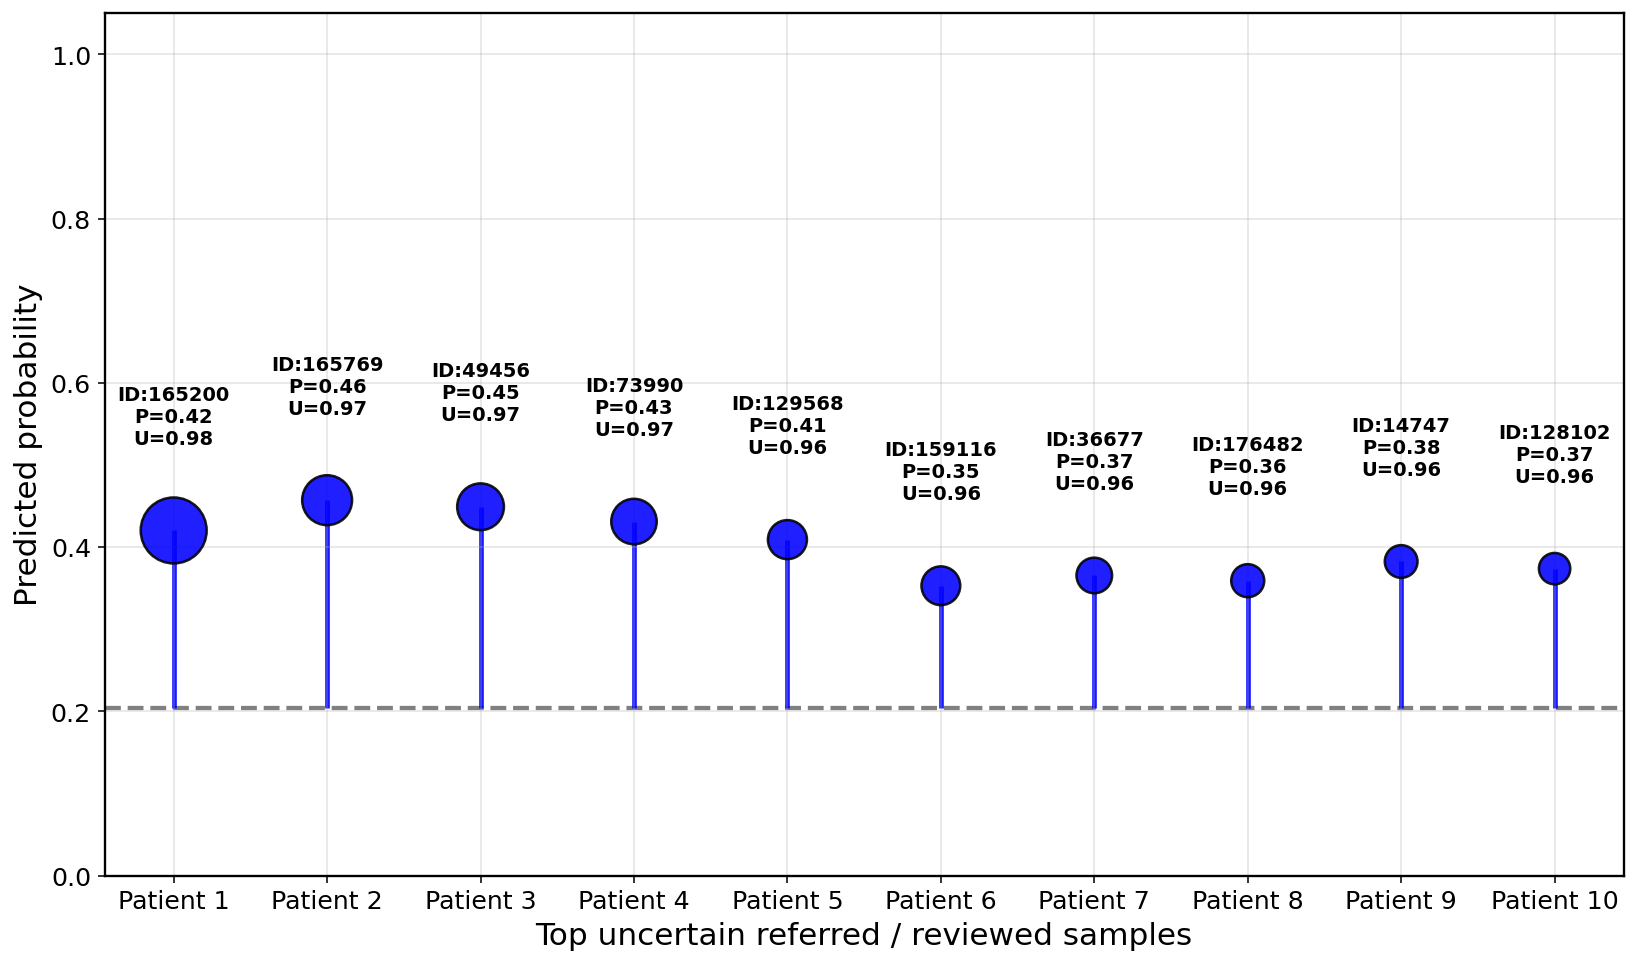


Module 13B complete.
Saved improved patient-level HITL referral figure and sample table.


In [12]:
# ============================================================
# Module 13B — Patient-level HITL referral visualization
# Purpose:
#   Visualize which individual samples are referred for human review
#   in the Proposed Model HITL workflow using a cleaner, paper-ready
#   bubble + lollipop plot.
#
# Figure design:
#   - Top K most uncertain samples
#   - y-axis: predicted probability
#   - bubble size: uncertainty magnitude
#   - color:
#       blue  -> referred to human
#       green -> auto-decided and correct
#       red   -> auto-decided and incorrect
#   - dashed horizontal line: decision threshold
#
# Important figure rule:
#   - no title inside saved images
# ============================================================

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "y_all",
    "p_prob_final_pm",
    "module11_uncertainty_df",
    "FIG_DIR",
    "TAB_DIR",
    "save_figure_multi",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 13B: {missing_vars}")

# -------------------------
# Config
# -------------------------
TOP_K_UNCERTAIN = 10
HITL_COVERAGE = 0.80
ANNOTATE_POINTS = True

# Bubble size control
BUBBLE_SIZE_MIN = 260
BUBBLE_SIZE_MAX = 1150

# -------------------------
# Build plotting dataframe
# -------------------------
df_hitl_vis = module11_uncertainty_df.copy().reset_index(drop=False)
df_hitl_vis = df_hitl_vis.rename(columns={"index": "sample_id"})

n_total = len(df_hitl_vis)
n_ai = max(1, int(round(HITL_COVERAGE * n_total)))

# Lowest uncertainty handled by AI, highest uncertainty referred
order = np.argsort(df_hitl_vis["uncertainty_score"].values)
ai_idx = order[:n_ai]
ref_idx = order[n_ai:]

df_hitl_vis["referred"] = 0
df_hitl_vis.loc[ref_idx, "referred"] = 1

thr_hitl = find_best_f1_threshold(y_all, p_prob_final_pm)
df_hitl_vis["pred_label"] = (df_hitl_vis["p_final"].values >= thr_hitl).astype(int)
df_hitl_vis["correct"] = (df_hitl_vis["pred_label"].values == df_hitl_vis["y_true"].values).astype(int)

# Take top uncertain samples
df_top_unc = (
    df_hitl_vis.sort_values("uncertainty_score", ascending=False)
    .head(TOP_K_UNCERTAIN)
    .copy()
    .reset_index(drop=True)
)

df_top_unc["patient_label"] = [f"Patient {i+1}" for i in range(len(df_top_unc))]

def get_color(row):
    if row["referred"] == 1:
        return "blue"
    elif row["correct"] == 1:
        return "green"
    else:
        return "red"

df_top_unc["color"] = df_top_unc.apply(get_color, axis=1)

# Scale bubble size by uncertainty
u = df_top_unc["uncertainty_score"].values.astype(float)
u_min, u_max = float(u.min()), float(u.max())
if abs(u_max - u_min) < 1e-12:
    bubble_sizes = np.full_like(u, fill_value=(BUBBLE_SIZE_MIN + BUBBLE_SIZE_MAX) / 2.0, dtype=float)
else:
    bubble_sizes = BUBBLE_SIZE_MIN + (u - u_min) * (BUBBLE_SIZE_MAX - BUBBLE_SIZE_MIN) / (u_max - u_min)

# -------------------------
# Save table for manuscript / appendix
# -------------------------
module13b_referral_table = df_top_unc[[
    "sample_id",
    "patient_label",
    "y_true",
    "pred_label",
    "p_final",
    "uncertainty_score",
    "referred",
    "correct",
]].copy()

module13b_referral_table.to_csv(
    TAB_DIR / "module13b_top_uncertain_referred_samples.csv",
    index=False
)

print("\nTop uncertain HITL samples:")
print(module13b_referral_table)

# -------------------------
# Plot: bubble + lollipop style
# -------------------------
plt.figure(figsize=(14, 8))

x = np.arange(len(df_top_unc))
y = df_top_unc["p_final"].values

# Vertical stems from threshold to point
for i, row in df_top_unc.iterrows():
    plt.vlines(
        x=i,
        ymin=thr_hitl,
        ymax=y[i],
        color=row["color"],
        linewidth=2.4,
        alpha=0.9,
        zorder=1,
    )

# Bubbles
plt.scatter(
    x,
    y,
    s=bubble_sizes,
    c=df_top_unc["color"].values,
    alpha=0.88,
    edgecolors="black",
    linewidths=1.3,
    zorder=3,
)

# Threshold line
plt.axhline(y=thr_hitl, linestyle="--", linewidth=2.2, color="gray", zorder=0)

# Annotations
if ANNOTATE_POINTS:
    for i, row in df_top_unc.iterrows():
        txt = f"ID:{int(row['sample_id'])}\nP={row['p_final']:.2f}\nU={row['uncertainty_score']:.2f}"
        text_y = min(1.04, y[i] + 0.10)
        plt.text(
            x[i],
            text_y,
            txt,
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
        )

plt.xticks(x, df_top_unc["patient_label"].tolist())
plt.xlabel("Top uncertain referred / reviewed samples")
plt.ylabel("Predicted probability")
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.35)

save_figure_multi(FIG_DIR / "module13b_patient_level_hitl_referral_bubble")
plt.show()

# -------------------------
# Optional legend helper table
# -------------------------
module13b_legend_df = pd.DataFrame({
    "color": ["blue", "green", "red"],
    "meaning": [
        "Referred to human review",
        "Auto-decided and correct",
        "Auto-decided and incorrect",
    ]
})
module13b_legend_df.to_csv(TAB_DIR / "module13b_referral_plot_legend.csv", index=False)

print("\nModule 13B complete.")
print("Saved improved patient-level HITL referral figure and sample table.")


Module 14 error summary:
                                               model       N  error_rate  \
0  Proposed Model — Probability Head (Logistic Ca...  253680    0.149949   
1                               LightGBM_tuned (Raw)  253680    0.144111   

    fp_n   fn_n   tp_n    tn_n  fp_rate_all  fn_rate_all  mean_pred_prob_fp  \
0  28014  10025  13868  201773      0.11043     0.039518           0.312717   
1  25992  10566  13327  203795      0.10246     0.041651           0.828329   

   mean_pred_prob_fn  mean_uncertainty_error  mean_uncertainty_correct  
0           0.107349                0.757039                  0.454658  
1           0.538204                0.756056                  0.456887  

Top false positives:
        sample_id  y_true  pred_prob  uncertainty_score
137602     137602       0   0.736036           0.605608
54144       54144       0   0.728547           0.626713
186884     186884       0   0.723335           0.611242
7088         7088       0   0.722545      

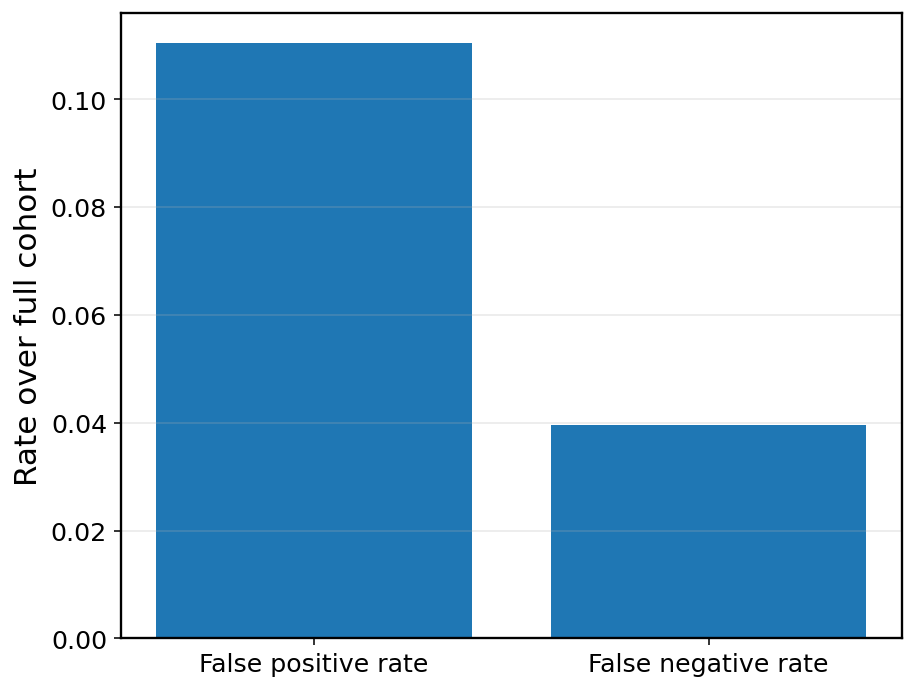

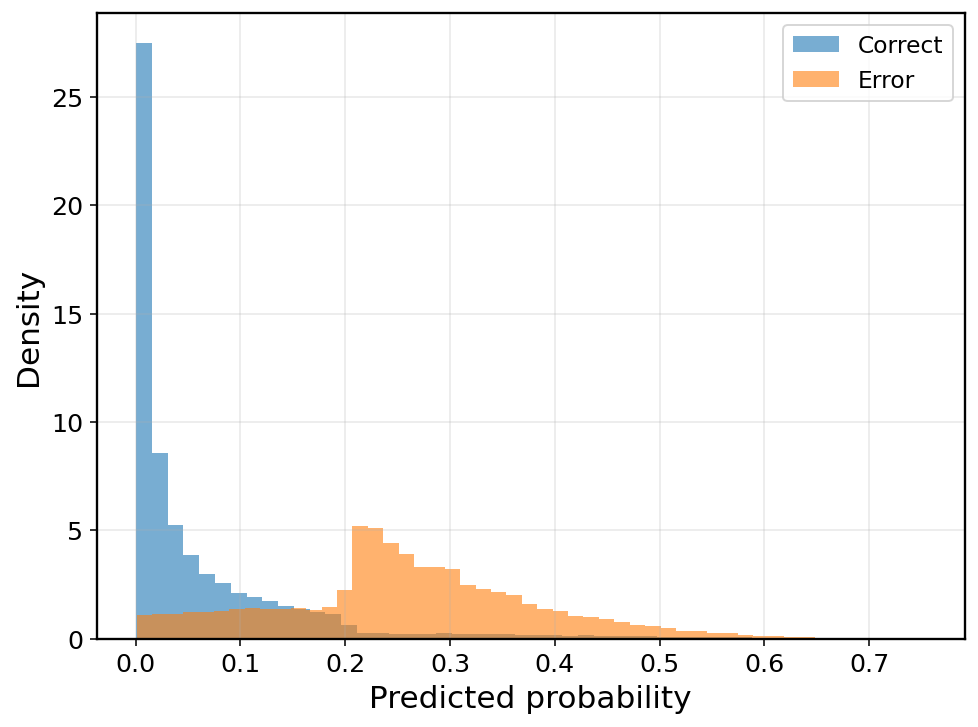

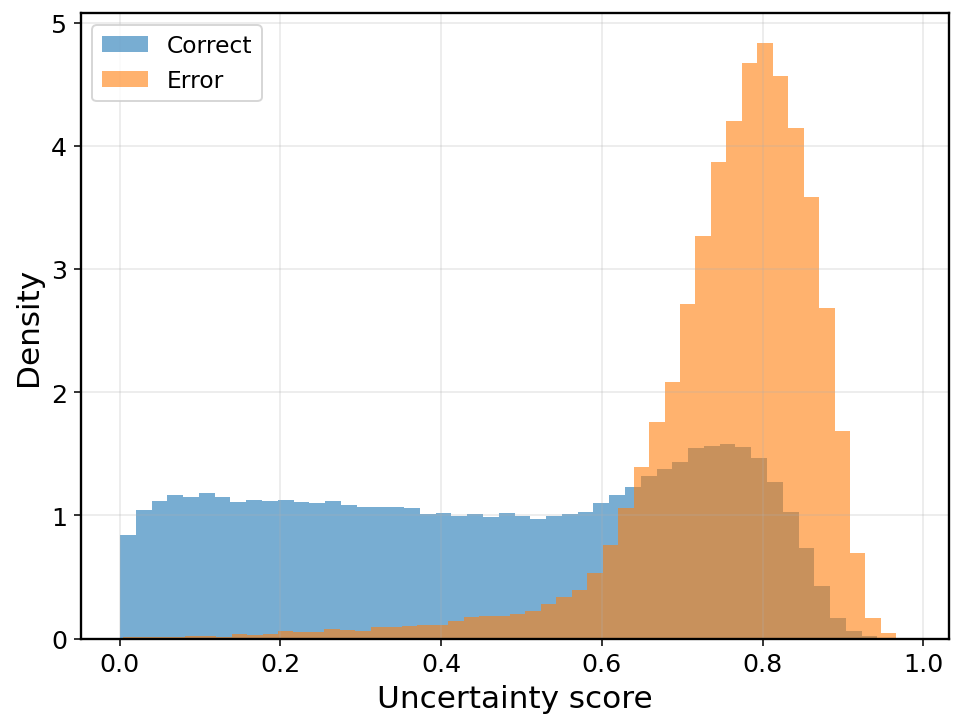

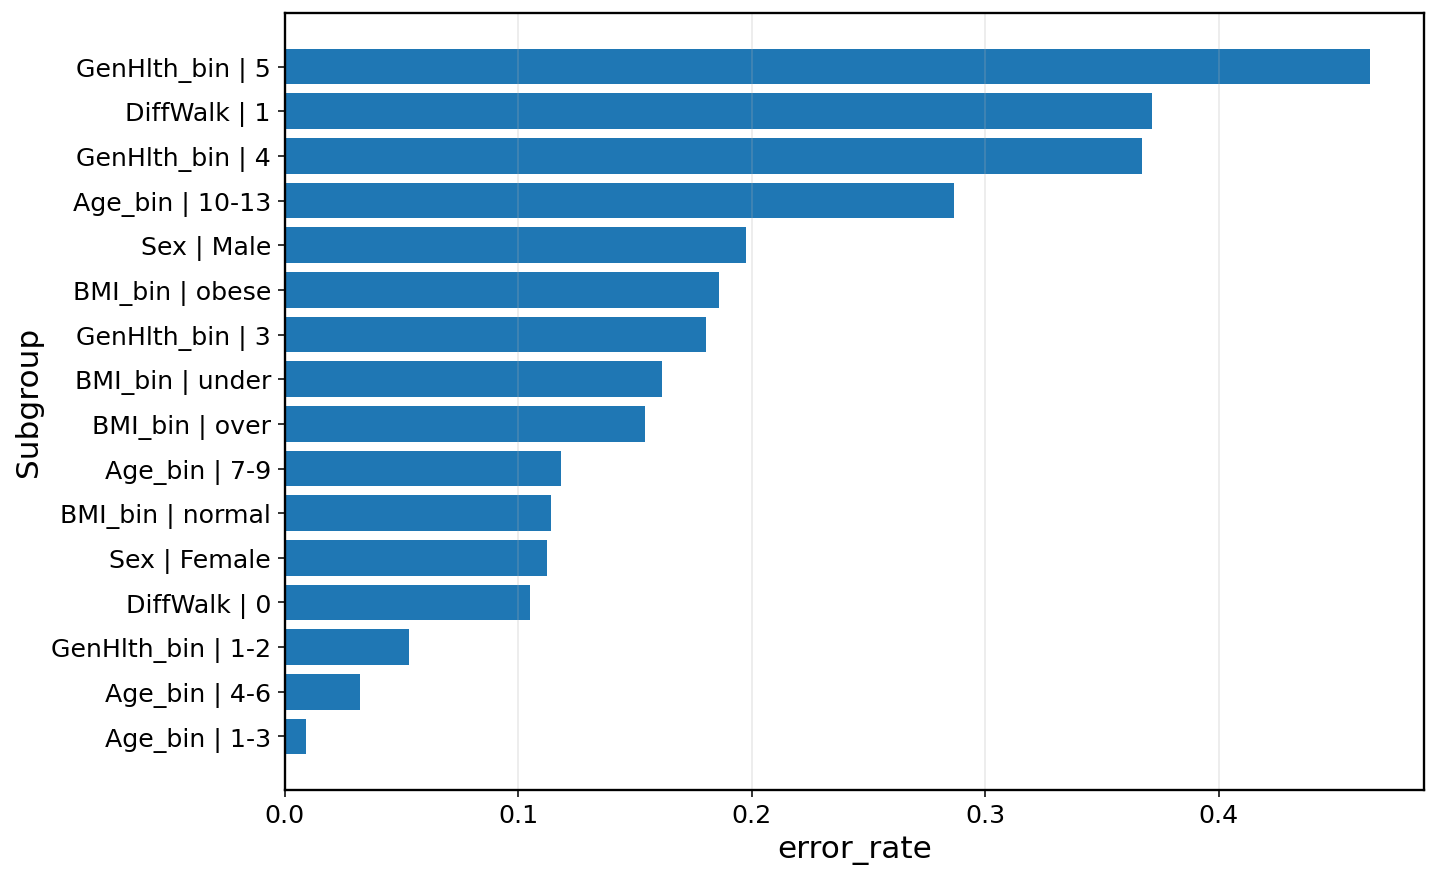

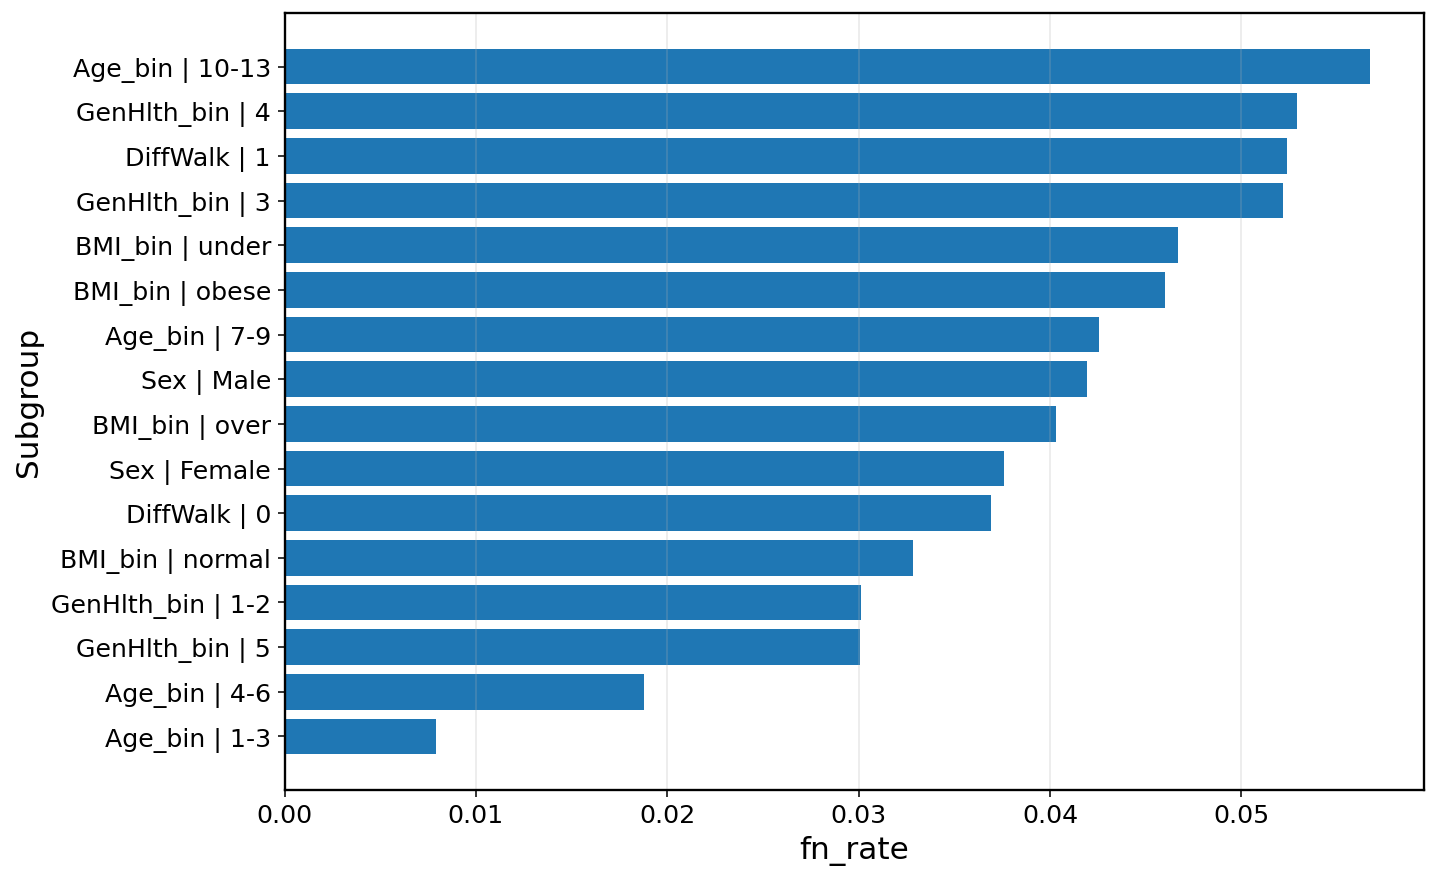


Module 14 complete.
Saved error-analysis tables and paper-ready figures without titles.


In [13]:
# ============================================================
# Module 14 — Error analysis
# Purpose:
#   Analyze where the Proposed Model fails and characterize:
#   - false positives
#   - false negatives
#   - high-uncertainty errors
#   - error-prone subgroups
#
# Main prediction analyzed:
#   - Proposed Model — Final Probability Head
#
# Optional comparison:
#   - LightGBM_tuned (Raw)
#
# Important figure rule:
#   - no titles inside saved images
# ============================================================

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "X_all",
    "y_all",
    "p_prob_final_pm",
    "p_lgb",
    "final_prob_model_name",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 14: {missing_vars}")

# Optional uncertainty table from Module 11
HAS_UQ = "module11_uncertainty_df" in globals()

# -------------------------
# Helpers
# -------------------------
def build_error_dataframe(X_df, y_true, p, model_name, use_uncertainty_df=None):
    X_df = X_df.copy().reset_index(drop=True)
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)

    thr = find_best_f1_threshold(y_true, p)
    pred = (p >= thr).astype(int)

    df_err = X_df.copy()
    df_err["sample_id"] = np.arange(len(df_err))
    df_err["model"] = model_name
    df_err["y_true"] = y_true
    df_err["pred_prob"] = p
    df_err["pred_label"] = pred
    df_err["threshold_used"] = float(thr)

    df_err["is_error"] = (pred != y_true).astype(int)
    df_err["is_fp"] = ((pred == 1) & (y_true == 0)).astype(int)
    df_err["is_fn"] = ((pred == 0) & (y_true == 1)).astype(int)
    df_err["is_tp"] = ((pred == 1) & (y_true == 1)).astype(int)
    df_err["is_tn"] = ((pred == 0) & (y_true == 0)).astype(int)

    if use_uncertainty_df is not None and "uncertainty_score" in use_uncertainty_df.columns:
        df_err["uncertainty_score"] = use_uncertainty_df["uncertainty_score"].values
    else:
        df_err["uncertainty_score"] = np.nan

    return df_err

def summarize_error_types(df_err):
    return pd.DataFrame([{
        "model": df_err["model"].iloc[0],
        "N": int(len(df_err)),
        "error_rate": float(df_err["is_error"].mean()),
        "fp_n": int(df_err["is_fp"].sum()),
        "fn_n": int(df_err["is_fn"].sum()),
        "tp_n": int(df_err["is_tp"].sum()),
        "tn_n": int(df_err["is_tn"].sum()),
        "fp_rate_all": float(df_err["is_fp"].mean()),
        "fn_rate_all": float(df_err["is_fn"].mean()),
        "mean_pred_prob_fp": float(df_err.loc[df_err["is_fp"] == 1, "pred_prob"].mean()) if df_err["is_fp"].sum() > 0 else np.nan,
        "mean_pred_prob_fn": float(df_err.loc[df_err["is_fn"] == 1, "pred_prob"].mean()) if df_err["is_fn"].sum() > 0 else np.nan,
        "mean_uncertainty_error": float(df_err.loc[df_err["is_error"] == 1, "uncertainty_score"].mean()) if "uncertainty_score" in df_err.columns else np.nan,
        "mean_uncertainty_correct": float(df_err.loc[df_err["is_error"] == 0, "uncertainty_score"].mean()) if "uncertainty_score" in df_err.columns else np.nan,
    }])

def compare_feature_means(df_err, feature_cols, mask_a, mask_b, label_a, label_b):
    rows = []
    for c in feature_cols:
        a = pd.to_numeric(df_err.loc[mask_a, c], errors="coerce")
        b = pd.to_numeric(df_err.loc[mask_b, c], errors="coerce")
        rows.append({
            "feature": c,
            f"{label_a}_mean": float(a.mean()) if a.notna().any() else np.nan,
            f"{label_b}_mean": float(b.mean()) if b.notna().any() else np.nan,
            "abs_diff": float(abs(a.mean() - b.mean())) if a.notna().any() and b.notna().any() else np.nan,
        })
    out = pd.DataFrame(rows).sort_values("abs_diff", ascending=False).reset_index(drop=True)
    return out

def error_rate_by_subgroup(df_err, subgroup_series, group_name):
    vals = pd.Series(subgroup_series)
    if not pd.api.types.is_categorical_dtype(vals):
        vals = vals.astype("category")

    rows = []
    for level in vals.cat.categories:
        idx = (vals == level).values
        if idx.sum() < 500:
            continue

        g = df_err.loc[idx]
        rows.append({
            "group": group_name,
            "level": str(level),
            "N": int(len(g)),
            "pos_rate": float(g["y_true"].mean()),
            "error_rate": float(g["is_error"].mean()),
            "fp_rate": float(g["is_fp"].mean()),
            "fn_rate": float(g["is_fn"].mean()),
            "mean_pred_prob": float(g["pred_prob"].mean()),
            "mean_uncertainty": float(g["uncertainty_score"].mean()) if "uncertainty_score" in g.columns else np.nan,
        })
    return pd.DataFrame(rows)

def plot_error_type_bar(df_summary, save_path_base):
    vals = [
        float(df_summary["fp_rate_all"].iloc[0]),
        float(df_summary["fn_rate_all"].iloc[0]),
    ]
    labels = ["False positive rate", "False negative rate"]

    plt.figure(figsize=(7.2, 5.8))
    plt.bar(labels, vals)
    plt.ylabel("Rate over full cohort")
    plt.grid(axis="y")
    save_figure_multi(save_path_base)
    plt.show()

def plot_subgroup_error_bar(df_group_err, metric_col, save_path_base):
    df_plot = df_group_err.copy().sort_values(metric_col, ascending=False)

    labels = df_plot["group"] + " | " + df_plot["level"]

    plt.figure(figsize=(10.5, 7.2))
    plt.barh(labels, df_plot[metric_col])
    plt.xlabel(metric_col)
    plt.ylabel("Subgroup")
    plt.gca().invert_yaxis()
    plt.grid(axis="x")
    save_figure_multi(save_path_base)
    plt.show()

def plot_probability_hist_error(df_err, save_path_base):
    plt.figure(figsize=(8.0, 5.8))
    plt.hist(df_err.loc[df_err["is_error"] == 0, "pred_prob"], bins=50, alpha=0.6, density=True, label="Correct")
    plt.hist(df_err.loc[df_err["is_error"] == 1, "pred_prob"], bins=50, alpha=0.6, density=True, label="Error")
    plt.xlabel("Predicted probability")
    plt.ylabel("Density")
    plt.legend(frameon=True)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

def plot_uncertainty_hist_error(df_err, save_path_base):
    if "uncertainty_score" not in df_err.columns or df_err["uncertainty_score"].isna().all():
        return
    plt.figure(figsize=(8.0, 5.8))
    plt.hist(df_err.loc[df_err["is_error"] == 0, "uncertainty_score"], bins=50, alpha=0.6, density=True, label="Correct")
    plt.hist(df_err.loc[df_err["is_error"] == 1, "uncertainty_score"], bins=50, alpha=0.6, density=True, label="Error")
    plt.xlabel("Uncertainty score")
    plt.ylabel("Density")
    plt.legend(frameon=True)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

# -------------------------
# Inputs
# -------------------------
uq_df_for_error = module11_uncertainty_df if HAS_UQ else None

df_err_proposed = build_error_dataframe(
    X_df=X_all,
    y_true=y_all,
    p=p_prob_final_pm,
    model_name=final_prob_model_name,
    use_uncertainty_df=uq_df_for_error,
)

df_err_lgb = build_error_dataframe(
    X_df=X_all,
    y_true=y_all,
    p=p_lgb,
    model_name="LightGBM_tuned (Raw)",
    use_uncertainty_df=uq_df_for_error,
)

# -------------------------
# 14.1 Error summary
# -------------------------
module14_error_summary_df = pd.concat([
    summarize_error_types(df_err_proposed),
    summarize_error_types(df_err_lgb),
], axis=0, ignore_index=True)

module14_error_summary_df.to_csv(TAB_DIR / "module14_error_summary.csv", index=False)

print("\nModule 14 error summary:")
print(module14_error_summary_df)

# -------------------------
# 14.2 Top false positives / false negatives
# -------------------------
module14_top_fp_df = (
    df_err_proposed[df_err_proposed["is_fp"] == 1]
    .sort_values("pred_prob", ascending=False)
    .head(20)
    .copy()
)
module14_top_fn_df = (
    df_err_proposed[df_err_proposed["is_fn"] == 1]
    .sort_values("pred_prob", ascending=True)
    .head(20)
    .copy()
)

module14_top_fp_df.to_csv(TAB_DIR / "module14_top_false_positives.csv", index=False)
module14_top_fn_df.to_csv(TAB_DIR / "module14_top_false_negatives.csv", index=False)

print("\nTop false positives:")
print(module14_top_fp_df[["sample_id", "y_true", "pred_prob", "uncertainty_score"]].head(10))

print("\nTop false negatives:")
print(module14_top_fn_df[["sample_id", "y_true", "pred_prob", "uncertainty_score"]].head(10))

# -------------------------
# 14.3 Feature-profile comparison
# Compare:
#   FP vs TN
#   FN vs TP
# -------------------------
fp_vs_tn_df = compare_feature_means(
    df_err_proposed,
    feature_cols=FEATURES,
    mask_a=(df_err_proposed["is_fp"] == 1),
    mask_b=(df_err_proposed["is_tn"] == 1),
    label_a="FP",
    label_b="TN",
)
fn_vs_tp_df = compare_feature_means(
    df_err_proposed,
    feature_cols=FEATURES,
    mask_a=(df_err_proposed["is_fn"] == 1),
    mask_b=(df_err_proposed["is_tp"] == 1),
    label_a="FN",
    label_b="TP",
)

fp_vs_tn_df.to_csv(TAB_DIR / "module14_feature_profile_fp_vs_tn.csv", index=False)
fn_vs_tp_df.to_csv(TAB_DIR / "module14_feature_profile_fn_vs_tp.csv", index=False)

print("\nTop FP vs TN feature differences:")
print(fp_vs_tn_df.head(15))

print("\nTop FN vs TP feature differences:")
print(fn_vs_tp_df.head(15))

# -------------------------
# 14.4 High-uncertainty error cases
# -------------------------
if HAS_UQ:
    module14_high_uncertainty_errors_df = (
        df_err_proposed[df_err_proposed["is_error"] == 1]
        .sort_values("uncertainty_score", ascending=False)
        .head(25)
        .copy()
    )
else:
    module14_high_uncertainty_errors_df = pd.DataFrame()

module14_high_uncertainty_errors_df.to_csv(TAB_DIR / "module14_high_uncertainty_errors.csv", index=False)

print("\nHigh-uncertainty errors:")
print(module14_high_uncertainty_errors_df.head(10))

# -------------------------
# 14.5 Error-prone subgroup analysis
# -------------------------
subgroup_err_tables = []

# Build subgroup map
subgroup_map_err = {}

if "Sex" in X_all.columns:
    subgroup_map_err["Sex"] = X_all["Sex"].map({0: "Female", 1: "Male"}).fillna(X_all["Sex"].astype(str))

if "Age" in X_all.columns:
    subgroup_map_err["Age_bin"] = pd.cut(
        X_all["Age"],
        bins=[0, 3, 6, 9, 13],
        labels=["1-3", "4-6", "7-9", "10-13"],
        include_lowest=True,
    )

if "BMI" in X_all.columns:
    subgroup_map_err["BMI_bin"] = pd.cut(
        X_all["BMI"],
        bins=[0, 18.5, 25, 30, 100],
        labels=["under", "normal", "over", "obese"],
        include_lowest=True,
    )

if "GenHlth" in X_all.columns:
    subgroup_map_err["GenHlth_bin"] = pd.cut(
        X_all["GenHlth"],
        bins=[0, 2, 3, 4, 5],
        labels=["1-2", "3", "4", "5"],
        include_lowest=True,
    )

if "DiffWalk" in X_all.columns:
    subgroup_map_err["DiffWalk"] = X_all["DiffWalk"].astype(int).astype(str)

for group_name, series in subgroup_map_err.items():
    tmp = error_rate_by_subgroup(df_err_proposed, series, group_name)
    if len(tmp) > 0:
        subgroup_err_tables.append(tmp)

if len(subgroup_err_tables) > 0:
    module14_subgroup_error_df = pd.concat(subgroup_err_tables, axis=0, ignore_index=True)
else:
    module14_subgroup_error_df = pd.DataFrame()

module14_subgroup_error_df.to_csv(TAB_DIR / "module14_subgroup_error_rates.csv", index=False)

print("\nSubgroup error rates:")
print(module14_subgroup_error_df.head(20))

# -------------------------
# 14.6 Compact manuscript summary
# -------------------------
summary_row = {
    "model": final_prob_model_name,
    "overall_error_rate": float(df_err_proposed["is_error"].mean()),
    "overall_fp_rate": float(df_err_proposed["is_fp"].mean()),
    "overall_fn_rate": float(df_err_proposed["is_fn"].mean()),
    "mean_uncertainty_error": float(df_err_proposed.loc[df_err_proposed["is_error"] == 1, "uncertainty_score"].mean()) if HAS_UQ else np.nan,
    "mean_uncertainty_correct": float(df_err_proposed.loc[df_err_proposed["is_error"] == 0, "uncertainty_score"].mean()) if HAS_UQ else np.nan,
    "max_subgroup_error_rate": float(module14_subgroup_error_df["error_rate"].max()) if len(module14_subgroup_error_df) > 0 else np.nan,
    "max_subgroup_fn_rate": float(module14_subgroup_error_df["fn_rate"].max()) if len(module14_subgroup_error_df) > 0 else np.nan,
}
module14_summary_df = pd.DataFrame([summary_row])
module14_summary_df.to_csv(TAB_DIR / "module14_error_analysis_summary.csv", index=False)

print("\nModule 14 summary:")
print(module14_summary_df)

# -------------------------
# 14.7 Paper-quality figures without titles
# -------------------------
plot_error_type_bar(
    module14_error_summary_df[module14_error_summary_df["model"] == final_prob_model_name].reset_index(drop=True),
    FIG_DIR / "module14_error_type_bar",
)

plot_probability_hist_error(
    df_err_proposed,
    FIG_DIR / "module14_predprob_error_hist",
)

if HAS_UQ:
    plot_uncertainty_hist_error(
        df_err_proposed,
        FIG_DIR / "module14_uncertainty_error_hist",
    )

if len(module14_subgroup_error_df) > 0:
    plot_subgroup_error_bar(
        module14_subgroup_error_df,
        metric_col="error_rate",
        save_path_base=FIG_DIR / "module14_subgroup_error_rate_bar",
    )
    plot_subgroup_error_bar(
        module14_subgroup_error_df,
        metric_col="fn_rate",
        save_path_base=FIG_DIR / "module14_subgroup_fn_rate_bar",
    )

# -------------------------
# 14.8 Save compact prediction bundle
# -------------------------
module14_preds_df = df_err_proposed[[
    "sample_id",
    "y_true",
    "pred_prob",
    "pred_label",
    "is_error",
    "is_fp",
    "is_fn",
    "uncertainty_score",
]].copy()

module14_preds_df.to_csv(PRED_DIR / "module14_error_predictions.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module14_error_predictions.npz",
    sample_id=module14_preds_df["sample_id"].values.astype(np.int32),
    y_true=module14_preds_df["y_true"].values.astype(np.int32),
    pred_prob=module14_preds_df["pred_prob"].values.astype(np.float32),
    pred_label=module14_preds_df["pred_label"].values.astype(np.int32),
    is_error=module14_preds_df["is_error"].values.astype(np.int32),
    is_fp=module14_preds_df["is_fp"].values.astype(np.int32),
    is_fn=module14_preds_df["is_fn"].values.astype(np.int32),
    uncertainty_score=np.nan_to_num(module14_preds_df["uncertainty_score"].values, nan=-1.0).astype(np.float32),
)

print("\nModule 14 complete.")
print("Saved error-analysis tables and paper-ready figures without titles.")


Module 15 ablation results:
                                               model    PR_AUC   ROC_AUC  \
0     Ablation G — Proposed Model ranking head (Raw)  0.377413  0.850397   
1  Ablation E — Proposed Model probability head (...  0.377315  0.850204   
2        Ablation D — Equal-weight probability blend  0.377216  0.850381   
3  Ablation F — Proposed Model — Probability Head...  0.377174  0.850187   
4   Ablation C — Remove DeepFM from probability head  0.376693  0.849994   
5            Ablation B — Tree-only probability head  0.376685  0.849991   
6               Ablation A — Best single expert only  0.375618  0.849678   
7                           Ablation H — DeepFM only  0.371961  0.848834   

      Brier       NLL       ECE       MCE    p_mean  pos_rate       N  ...  \
0  0.272980  0.801390  0.405814  0.629468  0.500000  0.094186  253680  ...   
1  0.178400  0.517180  0.268967  0.534714  0.363153  0.094186  253680  ...   
2  0.167505  0.489262  0.254217  0.510633  0.348403 

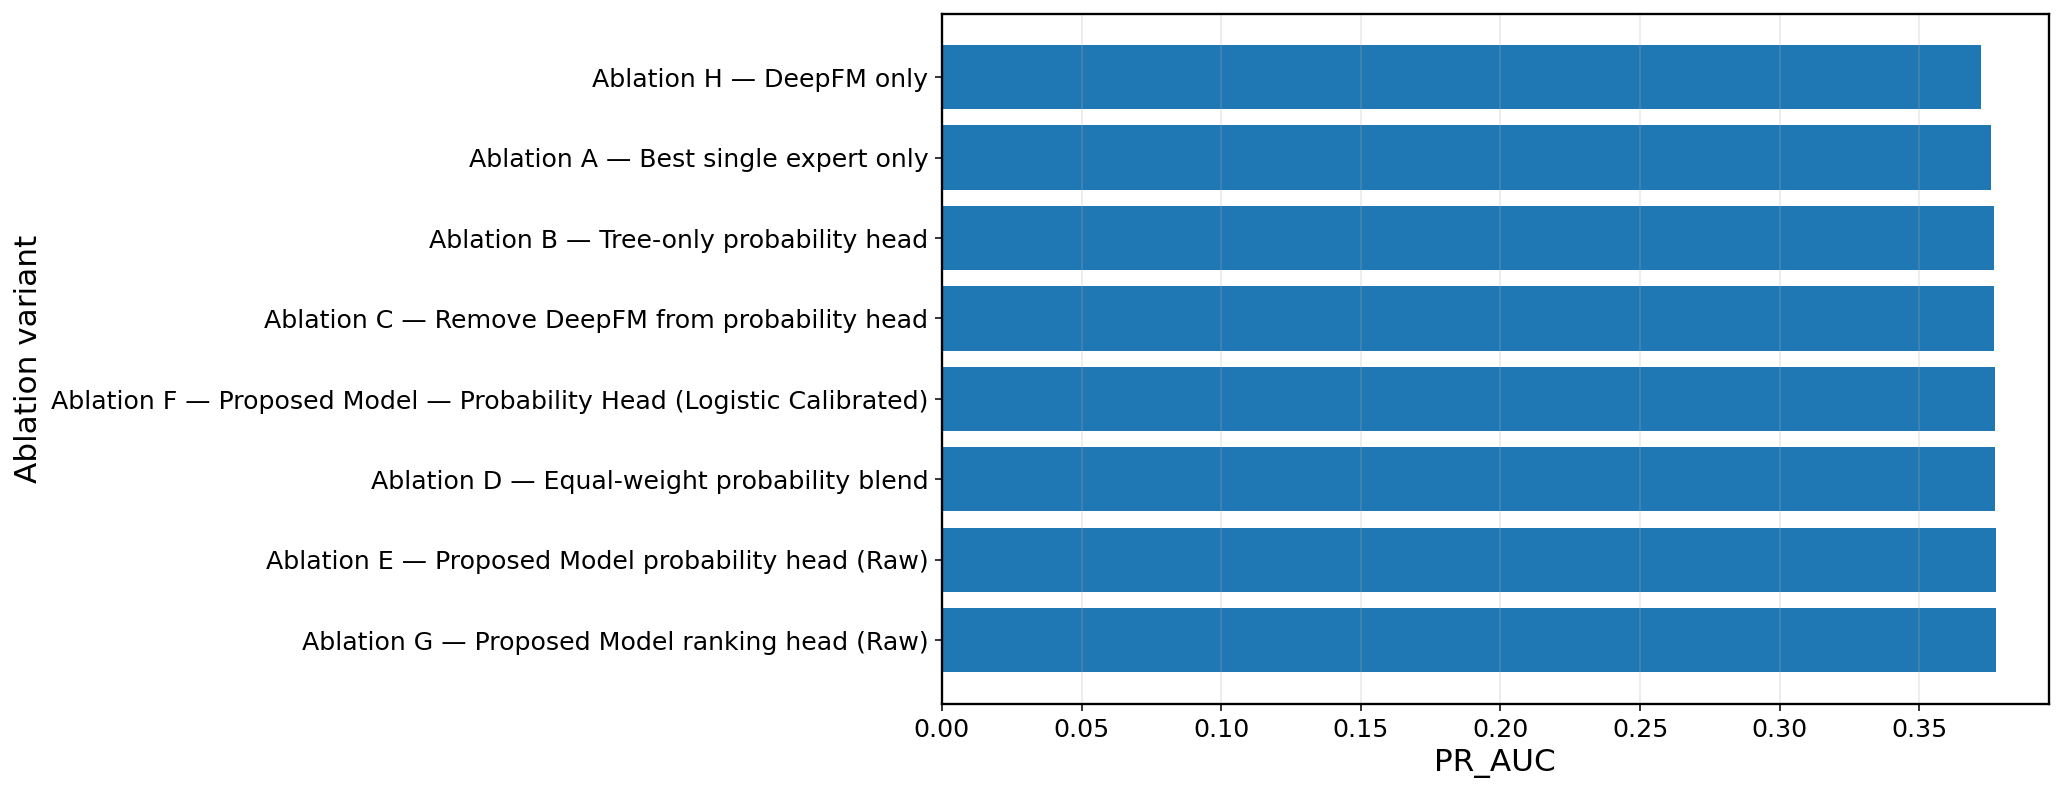

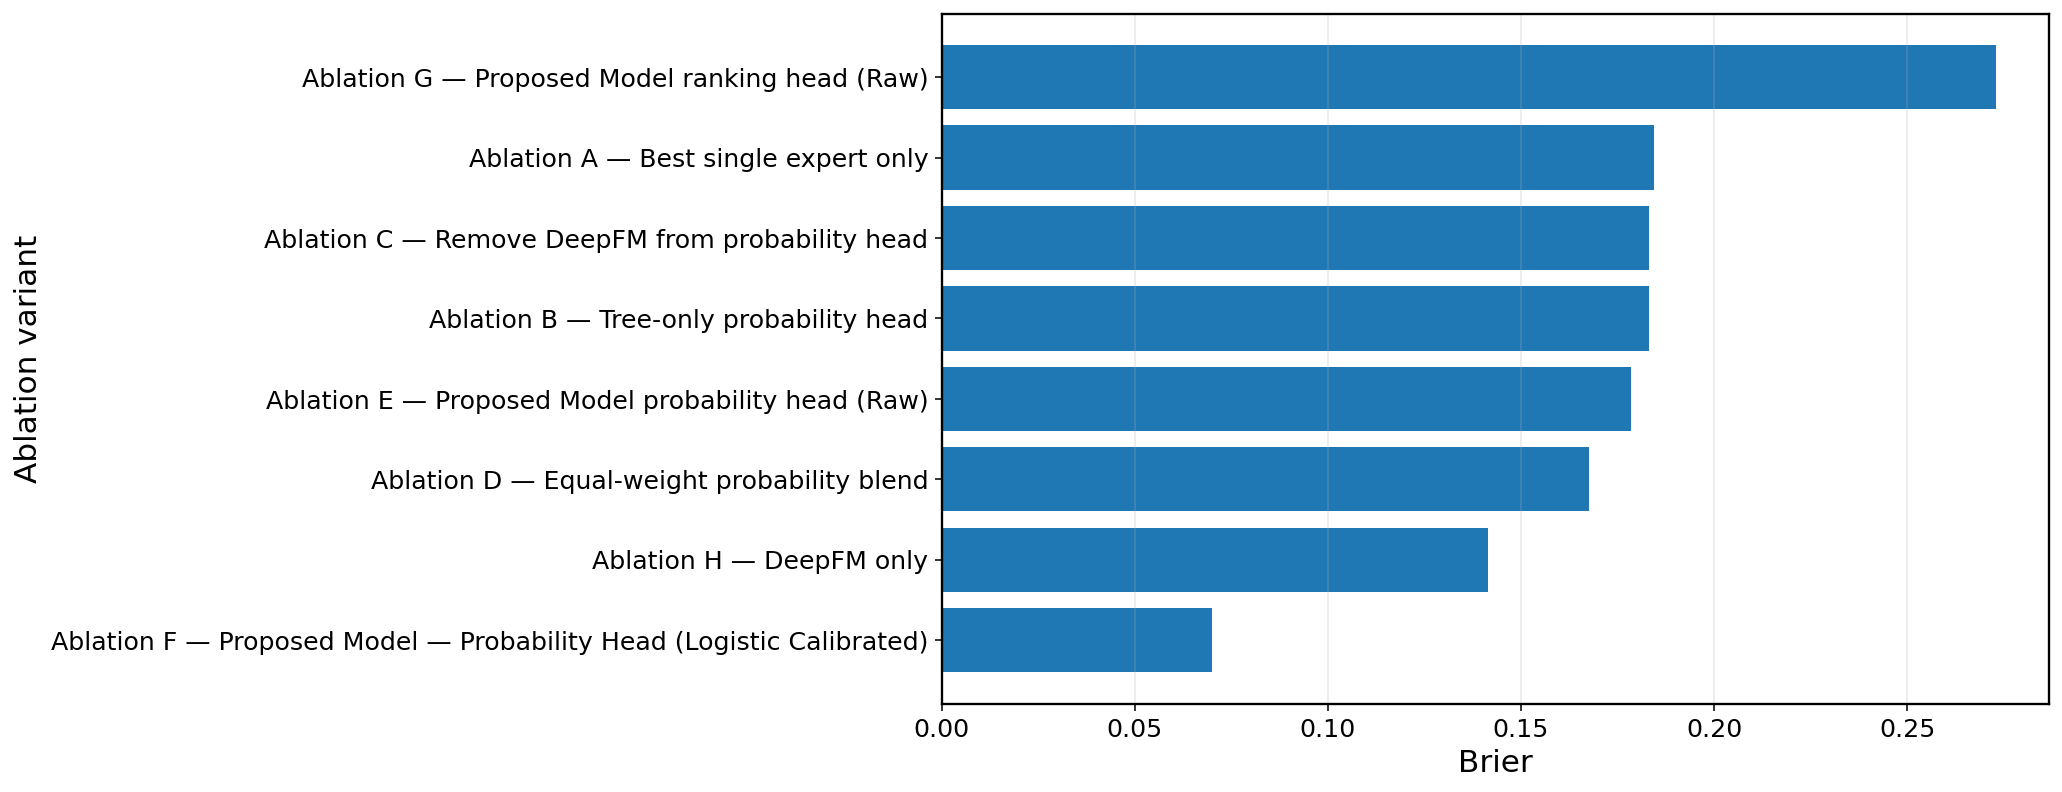

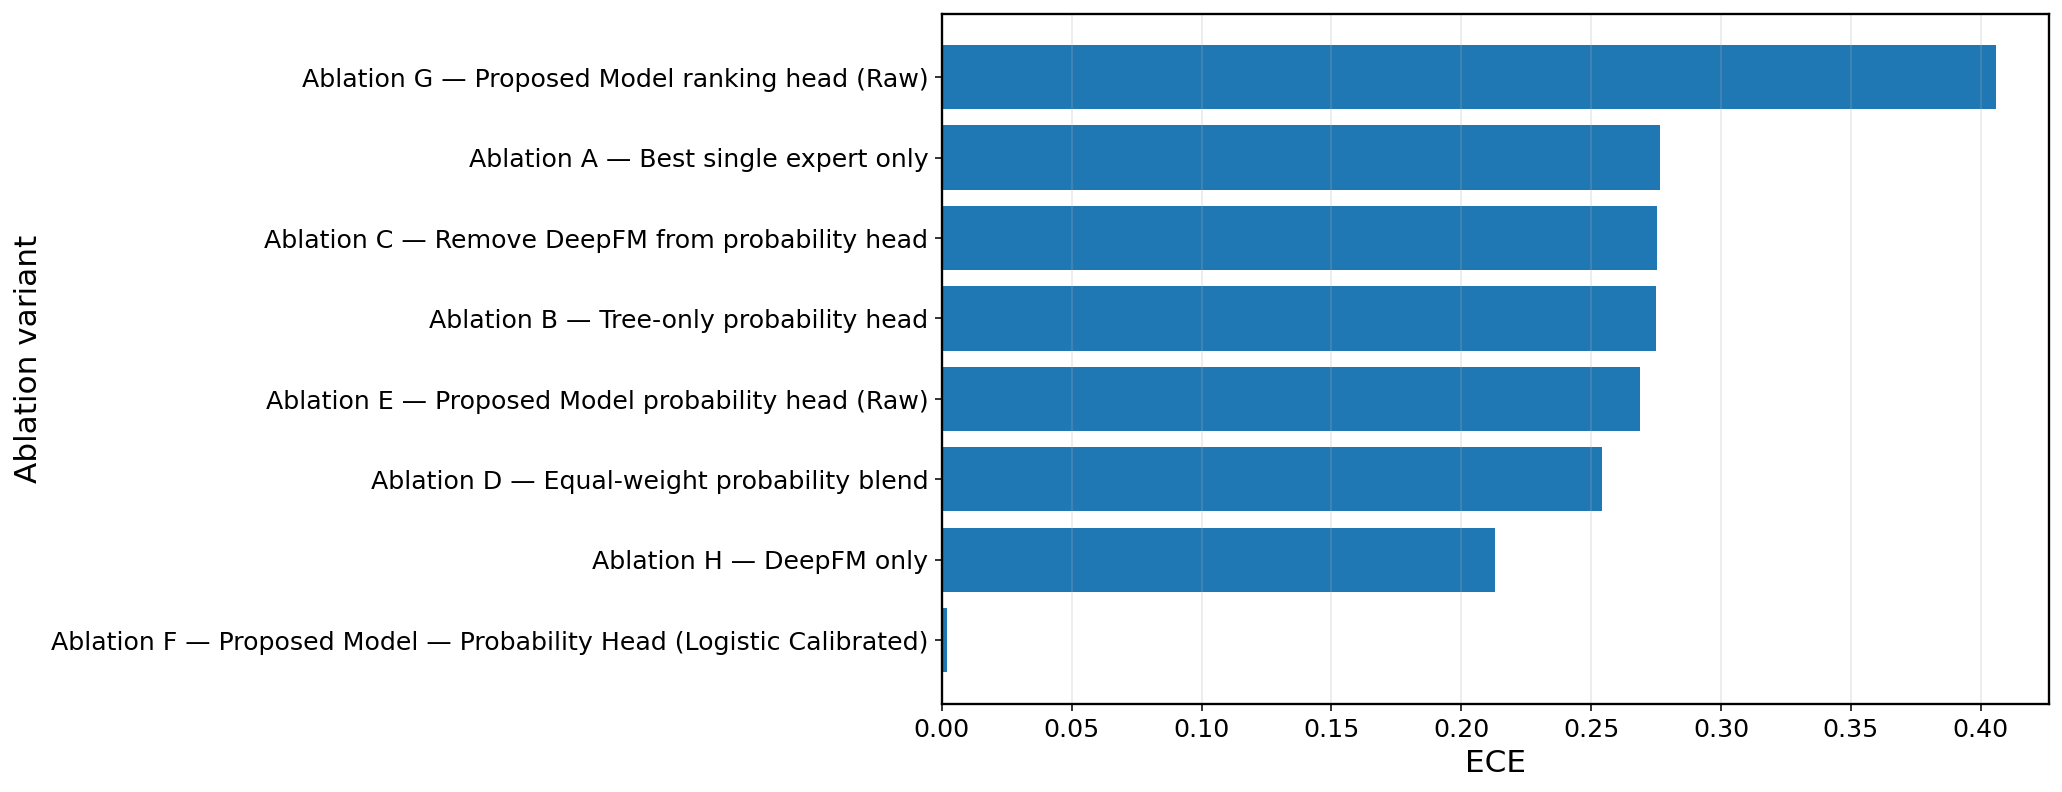

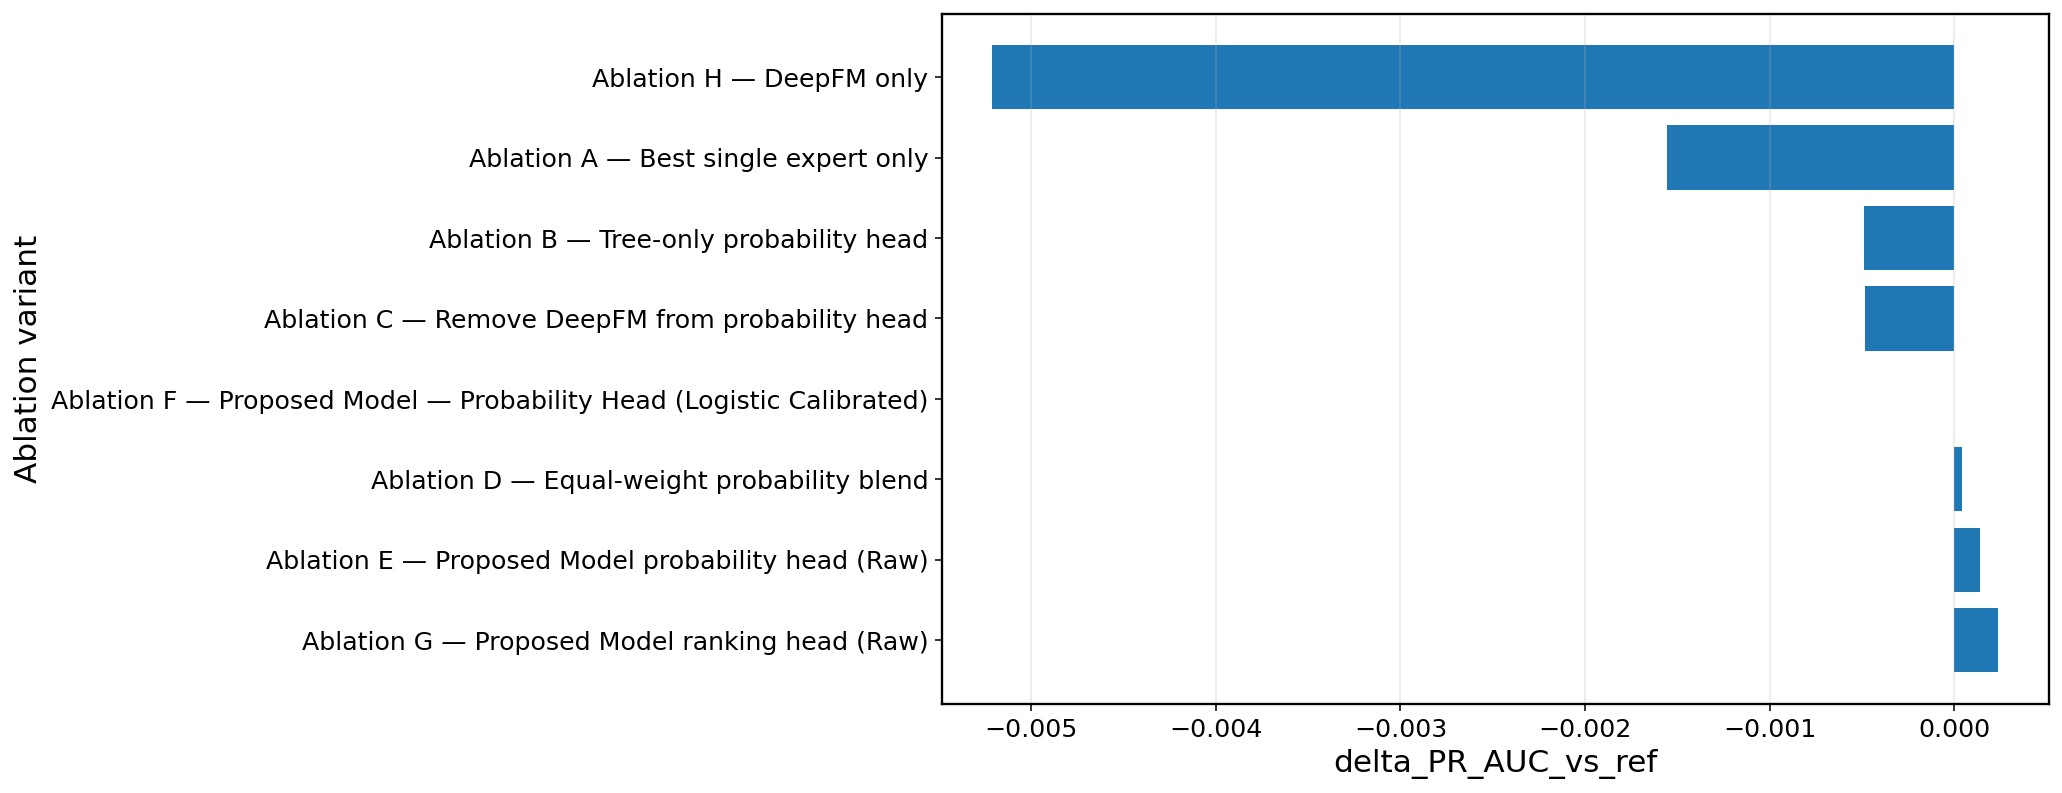

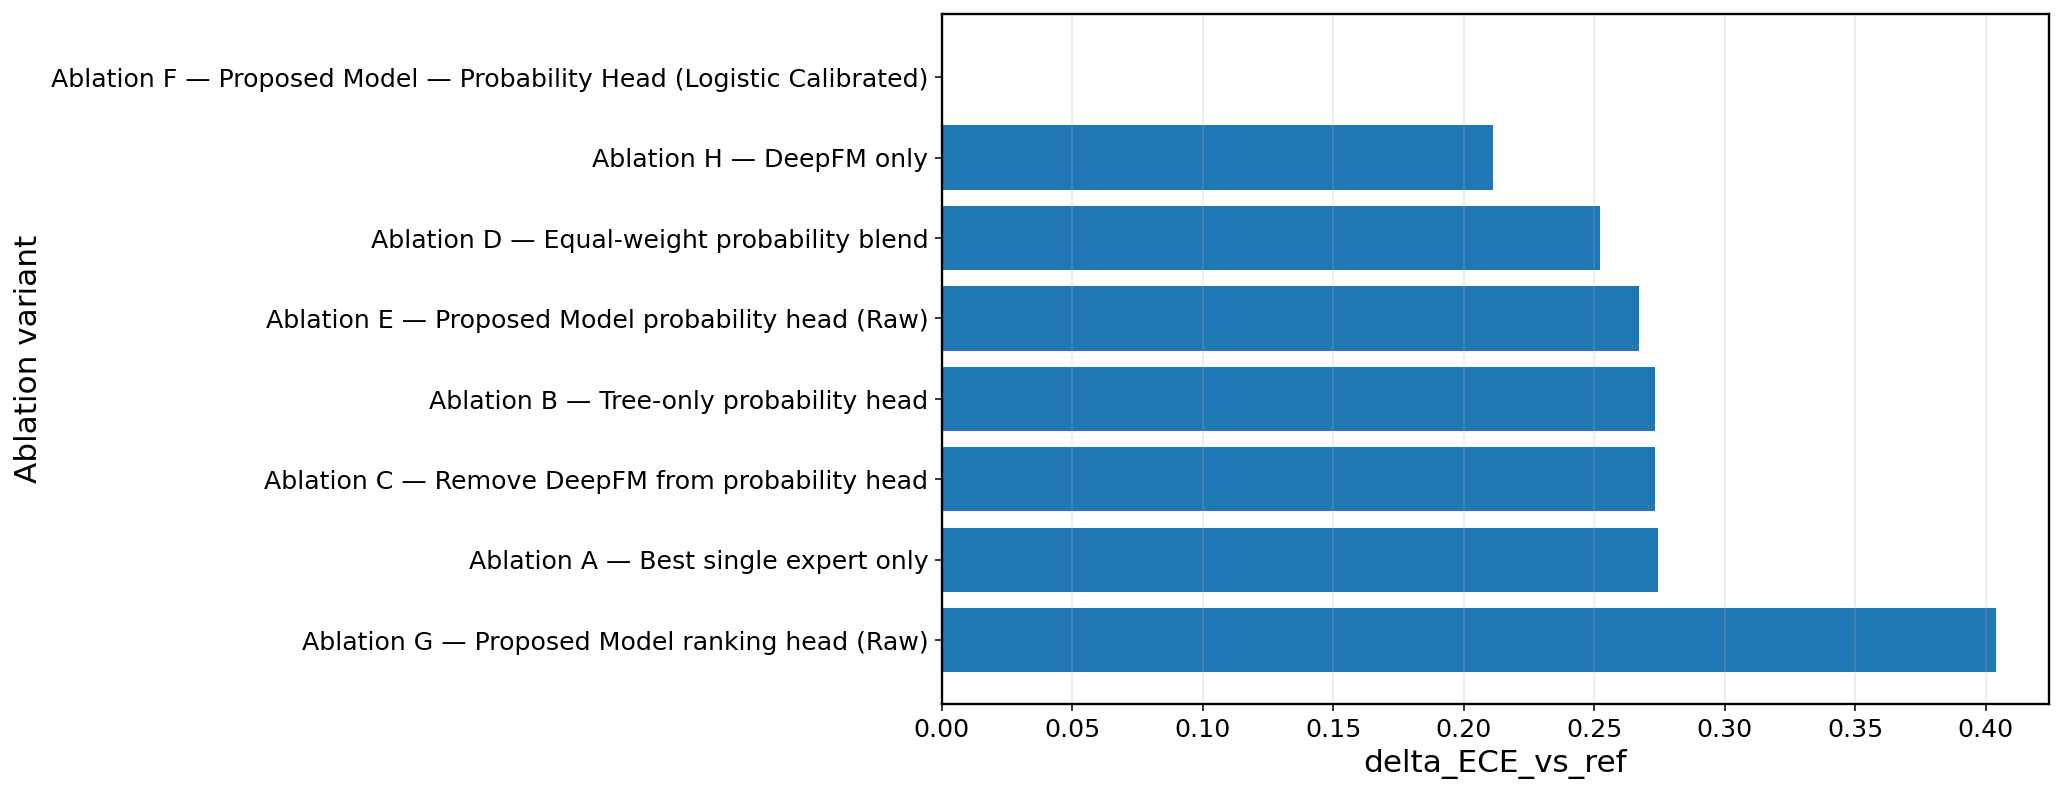


Module 15 complete.
Saved ablation tables and paper-ready figures without titles.


In [14]:
# ============================================================
# Module 15 — Ablation study
# Purpose:
#   Quantify which components of the Proposed Model matter most.
#
# Ablations included:
#   A) Best single expert only
#   B) Tree-only probability head
#   C) Remove DeepFM from probability head
#   D) Equal-weight probability blend
#   E) Raw Proposed Model probability head
#   F) Final calibrated Proposed Model probability head
#   G) Ranking head
#
# Optional extensions if available:
#   H) Without calibration (already covered by raw head)
#   I) Without HITL deferral benefit (reported from Module 13 summary)
#
# Important figure rule:
#   - no titles inside saved images
# ============================================================

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "y_all",
    "p_lgb",
    "p_xgb",
    "p_dfm",
    "p_prob_raw_pm",
    "p_prob_final_pm",
    "p_rank_final_pm",
    "final_prob_model_name",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 15: {missing_vars}")

# -------------------------
# Helpers
# -------------------------
def prob_avg_local(p_list, weights=None):
    p_list = [clip_probs(p) for p in p_list]
    if weights is None:
        weights = np.ones(len(p_list), dtype=np.float32) / len(p_list)
    weights = np.asarray(weights, dtype=np.float32)
    weights = weights / (weights.sum() + 1e-12)

    out = np.zeros_like(p_list[0], dtype=np.float32)
    for w, p in zip(weights, p_list):
        out += w * p
    return clip_probs(out)

def evaluate_model_set(y_true, pred_dict):
    rows = []
    for name, p in pred_dict.items():
        rows.append(evaluate_probs(y_true, p, name=name))
    return pd.DataFrame(rows)

def compute_ablation_deltas(df_ablation, ref_model_name):
    df_out = df_ablation.copy()
    if ref_model_name not in df_out["model"].values:
        return df_out

    ref_row = df_out[df_out["model"] == ref_model_name].iloc[0]

    for metric in ["PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE", "F1@bestF1"]:
        if metric in df_out.columns:
            if metric in ["Brier", "NLL", "ECE"]:
                df_out[f"delta_{metric}_vs_ref"] = df_out[metric] - float(ref_row[metric])
            else:
                df_out[f"delta_{metric}_vs_ref"] = df_out[metric] - float(ref_row[metric])

    return df_out

def plot_ablation_bar(df_ablation, metric_col, save_path_base, ascending=False):
    df_plot = df_ablation.copy().sort_values(metric_col, ascending=ascending)

    plt.figure(figsize=(10.2, 6.4))
    plt.barh(df_plot["model"], df_plot[metric_col])
    plt.xlabel(metric_col)
    plt.ylabel("Ablation variant")
    plt.grid(axis="x")
    save_figure_multi(save_path_base)
    plt.show()

def plot_ablation_delta_bar(df_ablation, metric_col, save_path_base):
    df_plot = df_ablation.copy().sort_values(metric_col, ascending=False)

    plt.figure(figsize=(10.2, 6.4))
    plt.barh(df_plot["model"], df_plot[metric_col])
    plt.xlabel(metric_col)
    plt.ylabel("Ablation variant")
    plt.grid(axis="x")
    save_figure_multi(save_path_base)
    plt.show()

# -------------------------
# 15.1 Build ablation variants
# -------------------------
y_ab = y_all.astype(int)

# Core variants
p_tree_only = prob_avg_local([p_lgb, p_xgb], weights=[0.60, 0.40])
p_without_deepfm = prob_avg_local([p_lgb, p_xgb], weights=[0.55, 0.35])  # same proportions renormalized
p_equal_weight_prob = prob_avg_local([p_lgb, p_xgb, p_dfm], weights=[1/3, 1/3, 1/3])
p_deepfm_only = clip_probs(p_dfm)

ablation_pred_dict = {
    "Ablation A — Best single expert only": p_lgb,
    "Ablation B — Tree-only probability head": p_tree_only,
    "Ablation C — Remove DeepFM from probability head": p_without_deepfm,
    "Ablation D — Equal-weight probability blend": p_equal_weight_prob,
    "Ablation E — Proposed Model probability head (Raw)": p_prob_raw_pm,
    f"Ablation F — {final_prob_model_name}": p_prob_final_pm,
    "Ablation G — Proposed Model ranking head (Raw)": p_rank_final_pm,
    "Ablation H — DeepFM only": p_deepfm_only,
}

module15_ablation_df = evaluate_model_set(y_ab, ablation_pred_dict)
module15_ablation_df = module15_ablation_df.sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=[False, False]
).reset_index(drop=True)

# Reference = final deployed probability head
ref_name = f"Ablation F — {final_prob_model_name}"
module15_ablation_df = compute_ablation_deltas(module15_ablation_df, ref_model_name=ref_name)

module15_ablation_df.to_csv(TAB_DIR / "module15_ablation_results.csv", index=False)

print("\nModule 15 ablation results:")
print(module15_ablation_df)

# -------------------------
# 15.2 Compact contribution summary
# -------------------------
summary_rows = []

# DeepFM contribution
row_ref = module15_ablation_df[module15_ablation_df["model"] == ref_name].iloc[0]
row_no_dfm = module15_ablation_df[module15_ablation_df["model"] == "Ablation C — Remove DeepFM from probability head"].iloc[0]
row_raw = module15_ablation_df[module15_ablation_df["model"] == "Ablation E — Proposed Model probability head (Raw)"].iloc[0]
row_single = module15_ablation_df[module15_ablation_df["model"] == "Ablation A — Best single expert only"].iloc[0]

summary_rows.append({
    "reference_model": ref_name,
    "PR_AUC_gain_vs_best_single": float(row_ref["PR_AUC"] - row_single["PR_AUC"]),
    "ROC_AUC_gain_vs_best_single": float(row_ref["ROC_AUC"] - row_single["ROC_AUC"]),
    "Brier_gain_vs_best_single": float(row_single["Brier"] - row_ref["Brier"]),
    "ECE_gain_vs_best_single": float(row_single["ECE"] - row_ref["ECE"]),
    "PR_AUC_gain_from_adding_DeepFM": float(row_ref["PR_AUC"] - row_no_dfm["PR_AUC"]),
    "ROC_AUC_gain_from_adding_DeepFM": float(row_ref["ROC_AUC"] - row_no_dfm["ROC_AUC"]),
    "Brier_gain_from_adding_DeepFM": float(row_no_dfm["Brier"] - row_ref["Brier"]),
    "ECE_gain_from_adding_DeepFM": float(row_no_dfm["ECE"] - row_ref["ECE"]),
    "Brier_gain_from_calibration": float(row_raw["Brier"] - row_ref["Brier"]),
    "ECE_gain_from_calibration": float(row_raw["ECE"] - row_ref["ECE"]),
    "NLL_gain_from_calibration": float(row_raw["NLL"] - row_ref["NLL"]),
})

module15_ablation_summary_df = pd.DataFrame(summary_rows)
module15_ablation_summary_df.to_csv(TAB_DIR / "module15_ablation_summary.csv", index=False)

print("\nModule 15 ablation summary:")
print(module15_ablation_summary_df)

# -------------------------
# 15.3 Optional HITL contribution summary if Module 13 exists
# -------------------------
if "module13_summary_df" in globals():
    module15_hitl_ablation_df = module13_summary_df.copy()
    module15_hitl_ablation_df.to_csv(TAB_DIR / "module15_hitl_ablation_summary.csv", index=False)
else:
    module15_hitl_ablation_df = pd.DataFrame()

# -------------------------
# 15.4 Paper-quality figures without titles
# -------------------------
plot_ablation_bar(
    module15_ablation_df,
    metric_col="PR_AUC",
    save_path_base=FIG_DIR / "module15_ablation_prauc",
    ascending=False,
)

plot_ablation_bar(
    module15_ablation_df,
    metric_col="Brier",
    save_path_base=FIG_DIR / "module15_ablation_brier",
    ascending=True,
)

plot_ablation_bar(
    module15_ablation_df,
    metric_col="ECE",
    save_path_base=FIG_DIR / "module15_ablation_ece",
    ascending=True,
)

if "delta_PR_AUC_vs_ref" in module15_ablation_df.columns:
    plot_ablation_delta_bar(
        module15_ablation_df,
        metric_col="delta_PR_AUC_vs_ref",
        save_path_base=FIG_DIR / "module15_ablation_delta_prauc_vs_ref",
    )

if "delta_ECE_vs_ref" in module15_ablation_df.columns:
    plot_ablation_delta_bar(
        module15_ablation_df,
        metric_col="delta_ECE_vs_ref",
        save_path_base=FIG_DIR / "module15_ablation_delta_ece_vs_ref",
    )

# -------------------------
# 15.5 Save compact prediction bundle
# -------------------------
module15_preds_df = pd.DataFrame({
    "y_true": y_ab.astype(int),
    "p_best_single_expert": p_lgb,
    "p_tree_only": p_tree_only,
    "p_without_deepfm": p_without_deepfm,
    "p_equal_weight_prob": p_equal_weight_prob,
    "p_proposed_prob_raw": p_prob_raw_pm,
    "p_proposed_prob_final": p_prob_final_pm,
    "p_proposed_rank_final": p_rank_final_pm,
    "p_deepfm_only": p_deepfm_only,
})
module15_preds_df.to_csv(PRED_DIR / "module15_ablation_predictions.csv", index=False)

np.savez_compressed(
    PRED_DIR / "module15_ablation_predictions.npz",
    y_true=y_ab.astype(np.int32),
    p_best_single_expert=p_lgb.astype(np.float32),
    p_tree_only=p_tree_only.astype(np.float32),
    p_without_deepfm=p_without_deepfm.astype(np.float32),
    p_equal_weight_prob=p_equal_weight_prob.astype(np.float32),
    p_proposed_prob_raw=p_prob_raw_pm.astype(np.float32),
    p_proposed_prob_final=p_prob_final_pm.astype(np.float32),
    p_proposed_rank_final=p_rank_final_pm.astype(np.float32),
    p_deepfm_only=p_deepfm_only.astype(np.float32),
)

print("\nModule 15 complete.")
print("Saved ablation tables and paper-ready figures without titles.")


Module 5B rebuilt Proposed Model summary:
                                              model    PR_AUC   ROC_AUC  \
0      Proposed Model (Robust) — Ranking Head (Raw)  0.377665  0.850492   
1  Proposed Model (Robust) — Probability Head (Raw)  0.377435  0.850230   
2                                    LightGBM_tuned  0.375618  0.849678   
3                                     XGBoost_tuned  0.374499  0.848966   
4                                     DeepFM_Robust  0.372149  0.848931   

      Brier       NLL       ECE       MCE    p_mean  pos_rate       N  ...  \
0  0.272918  0.801187  0.405814  0.629206  0.500000  0.094186  253680  ...   
1  0.178263  0.516798  0.268863  0.534218  0.363049  0.094186  253680  ...   
2  0.184456  0.531824  0.276534  0.544321  0.370720  0.094186  253680  ...   
3  0.182213  0.529555  0.273046  0.542405  0.367231  0.094186  253680  ...   
4  0.140405  0.420563  0.212031  0.445268  0.306216  0.094186  253680  ...   

   F1@bestF1  Acc@bestF1  BalAcc@best

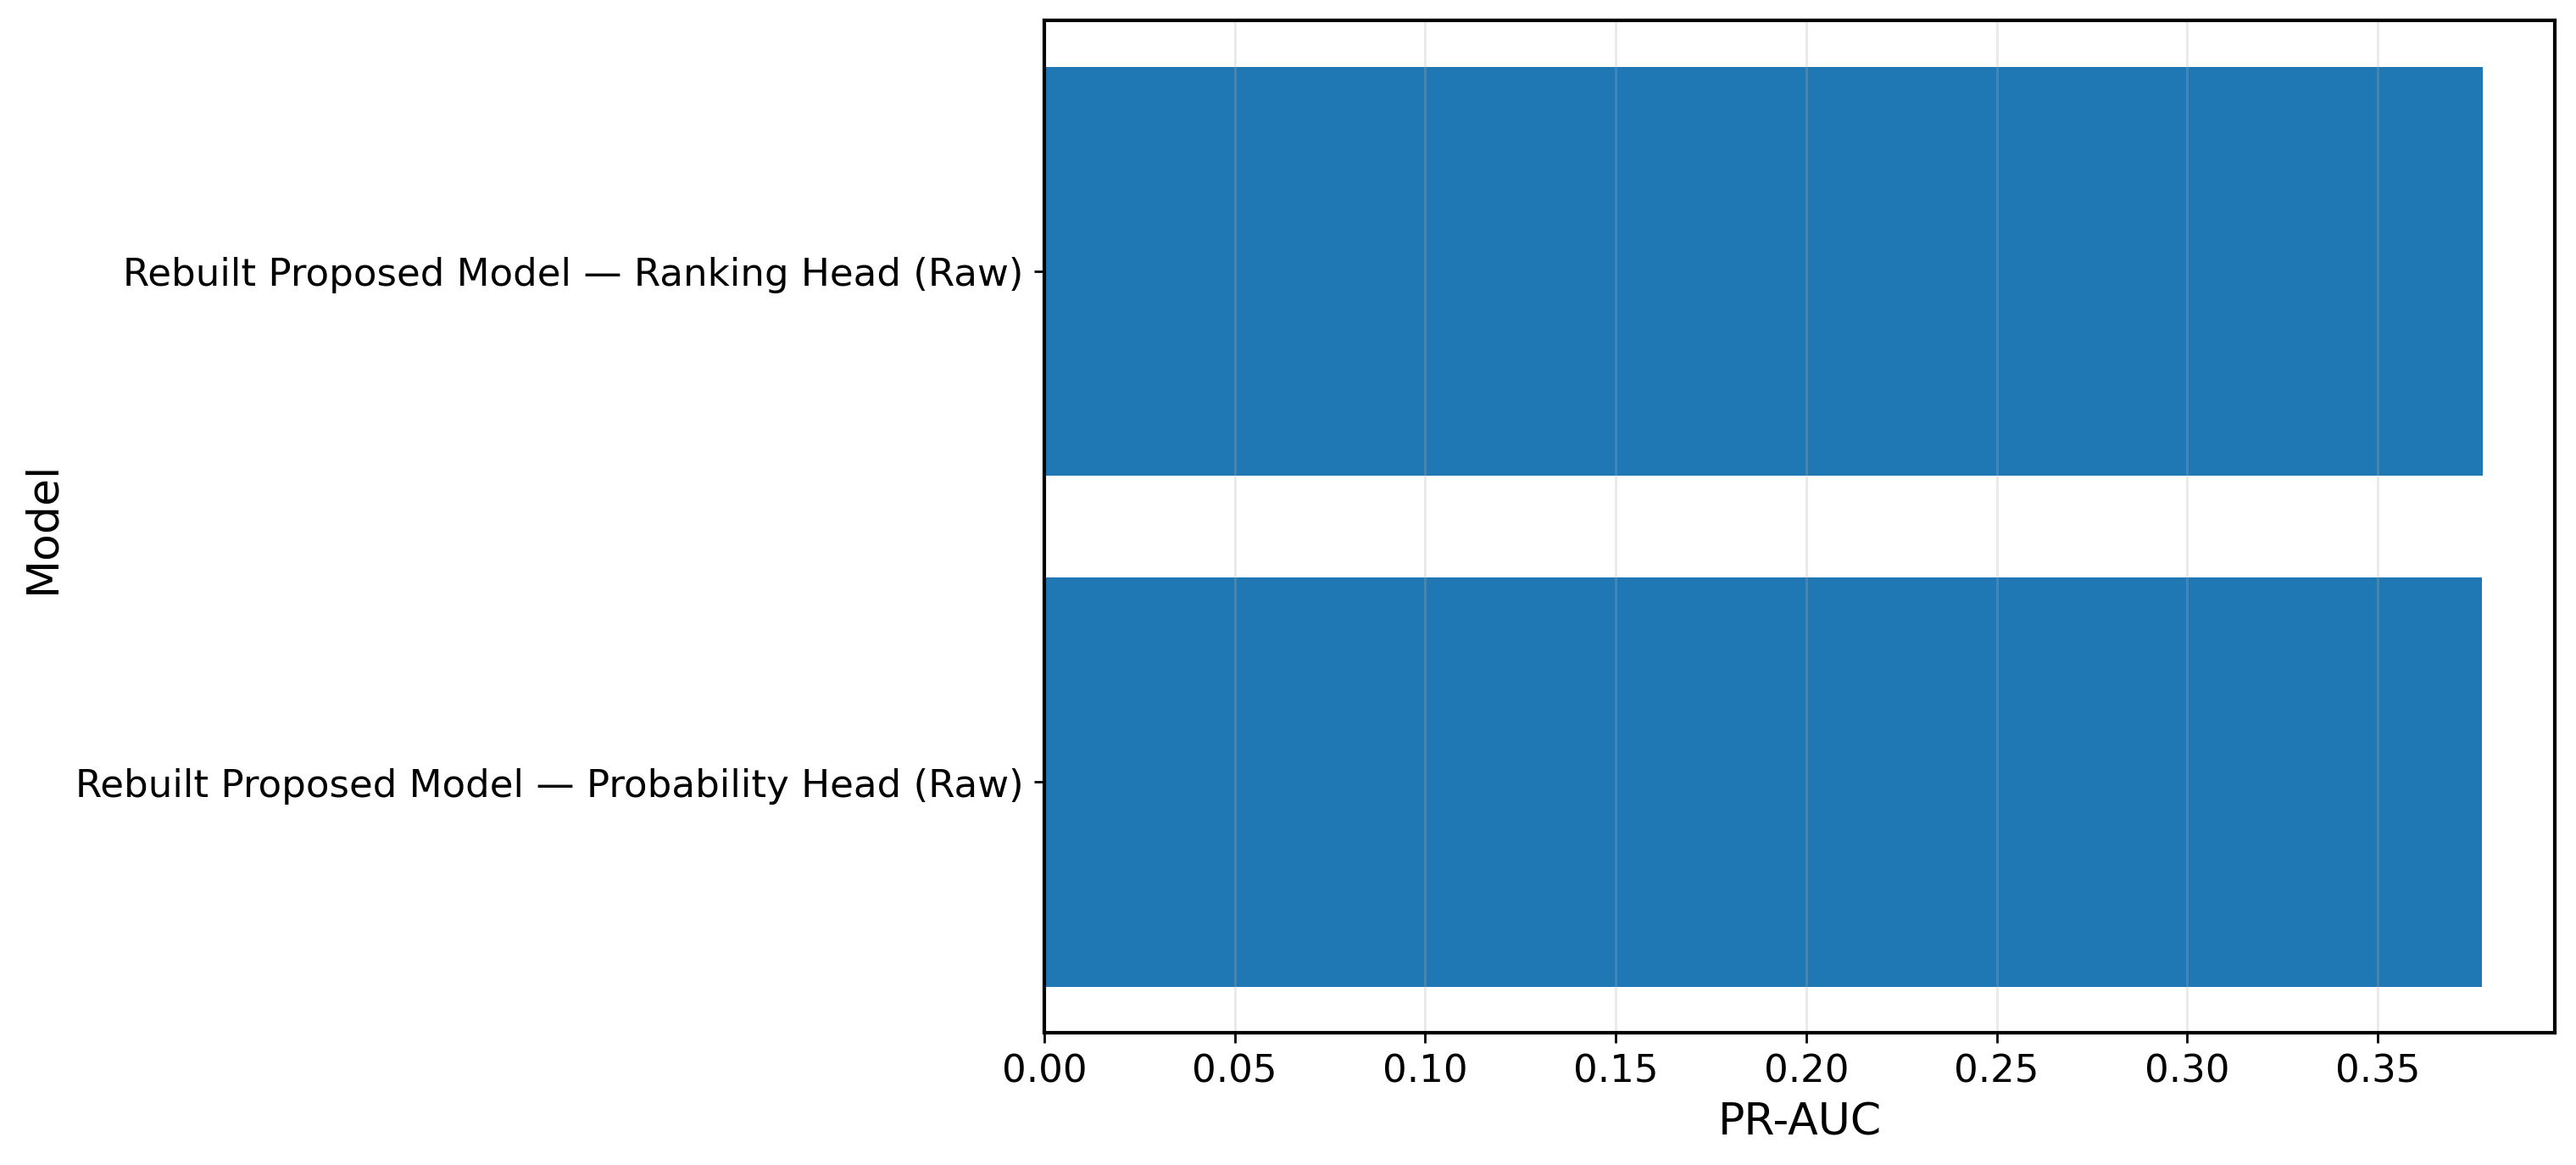

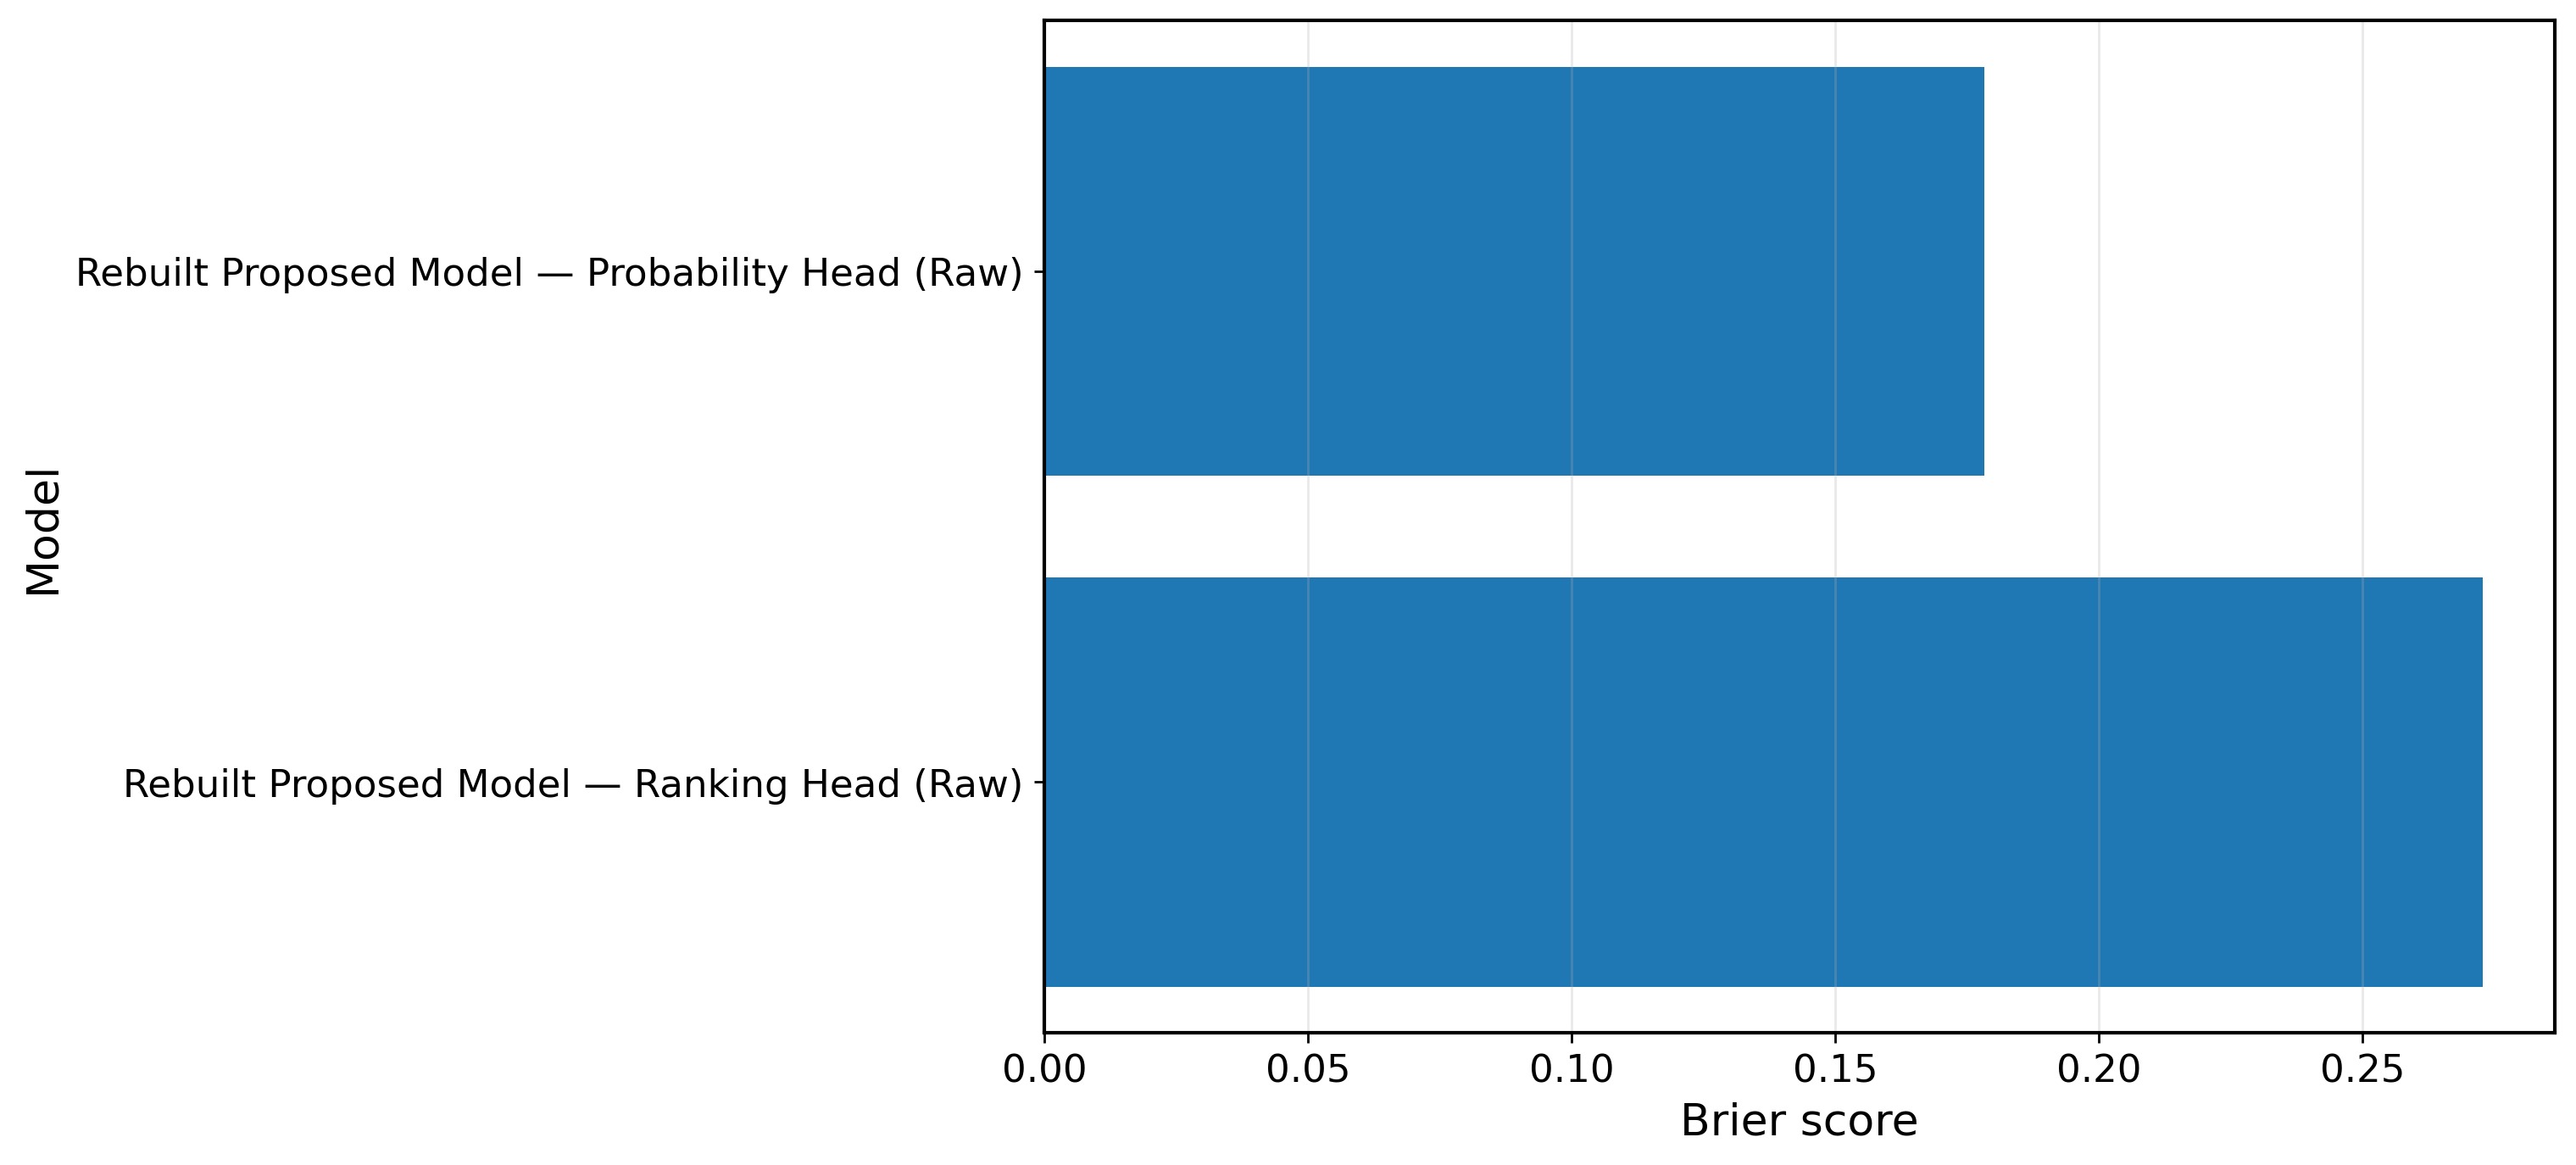

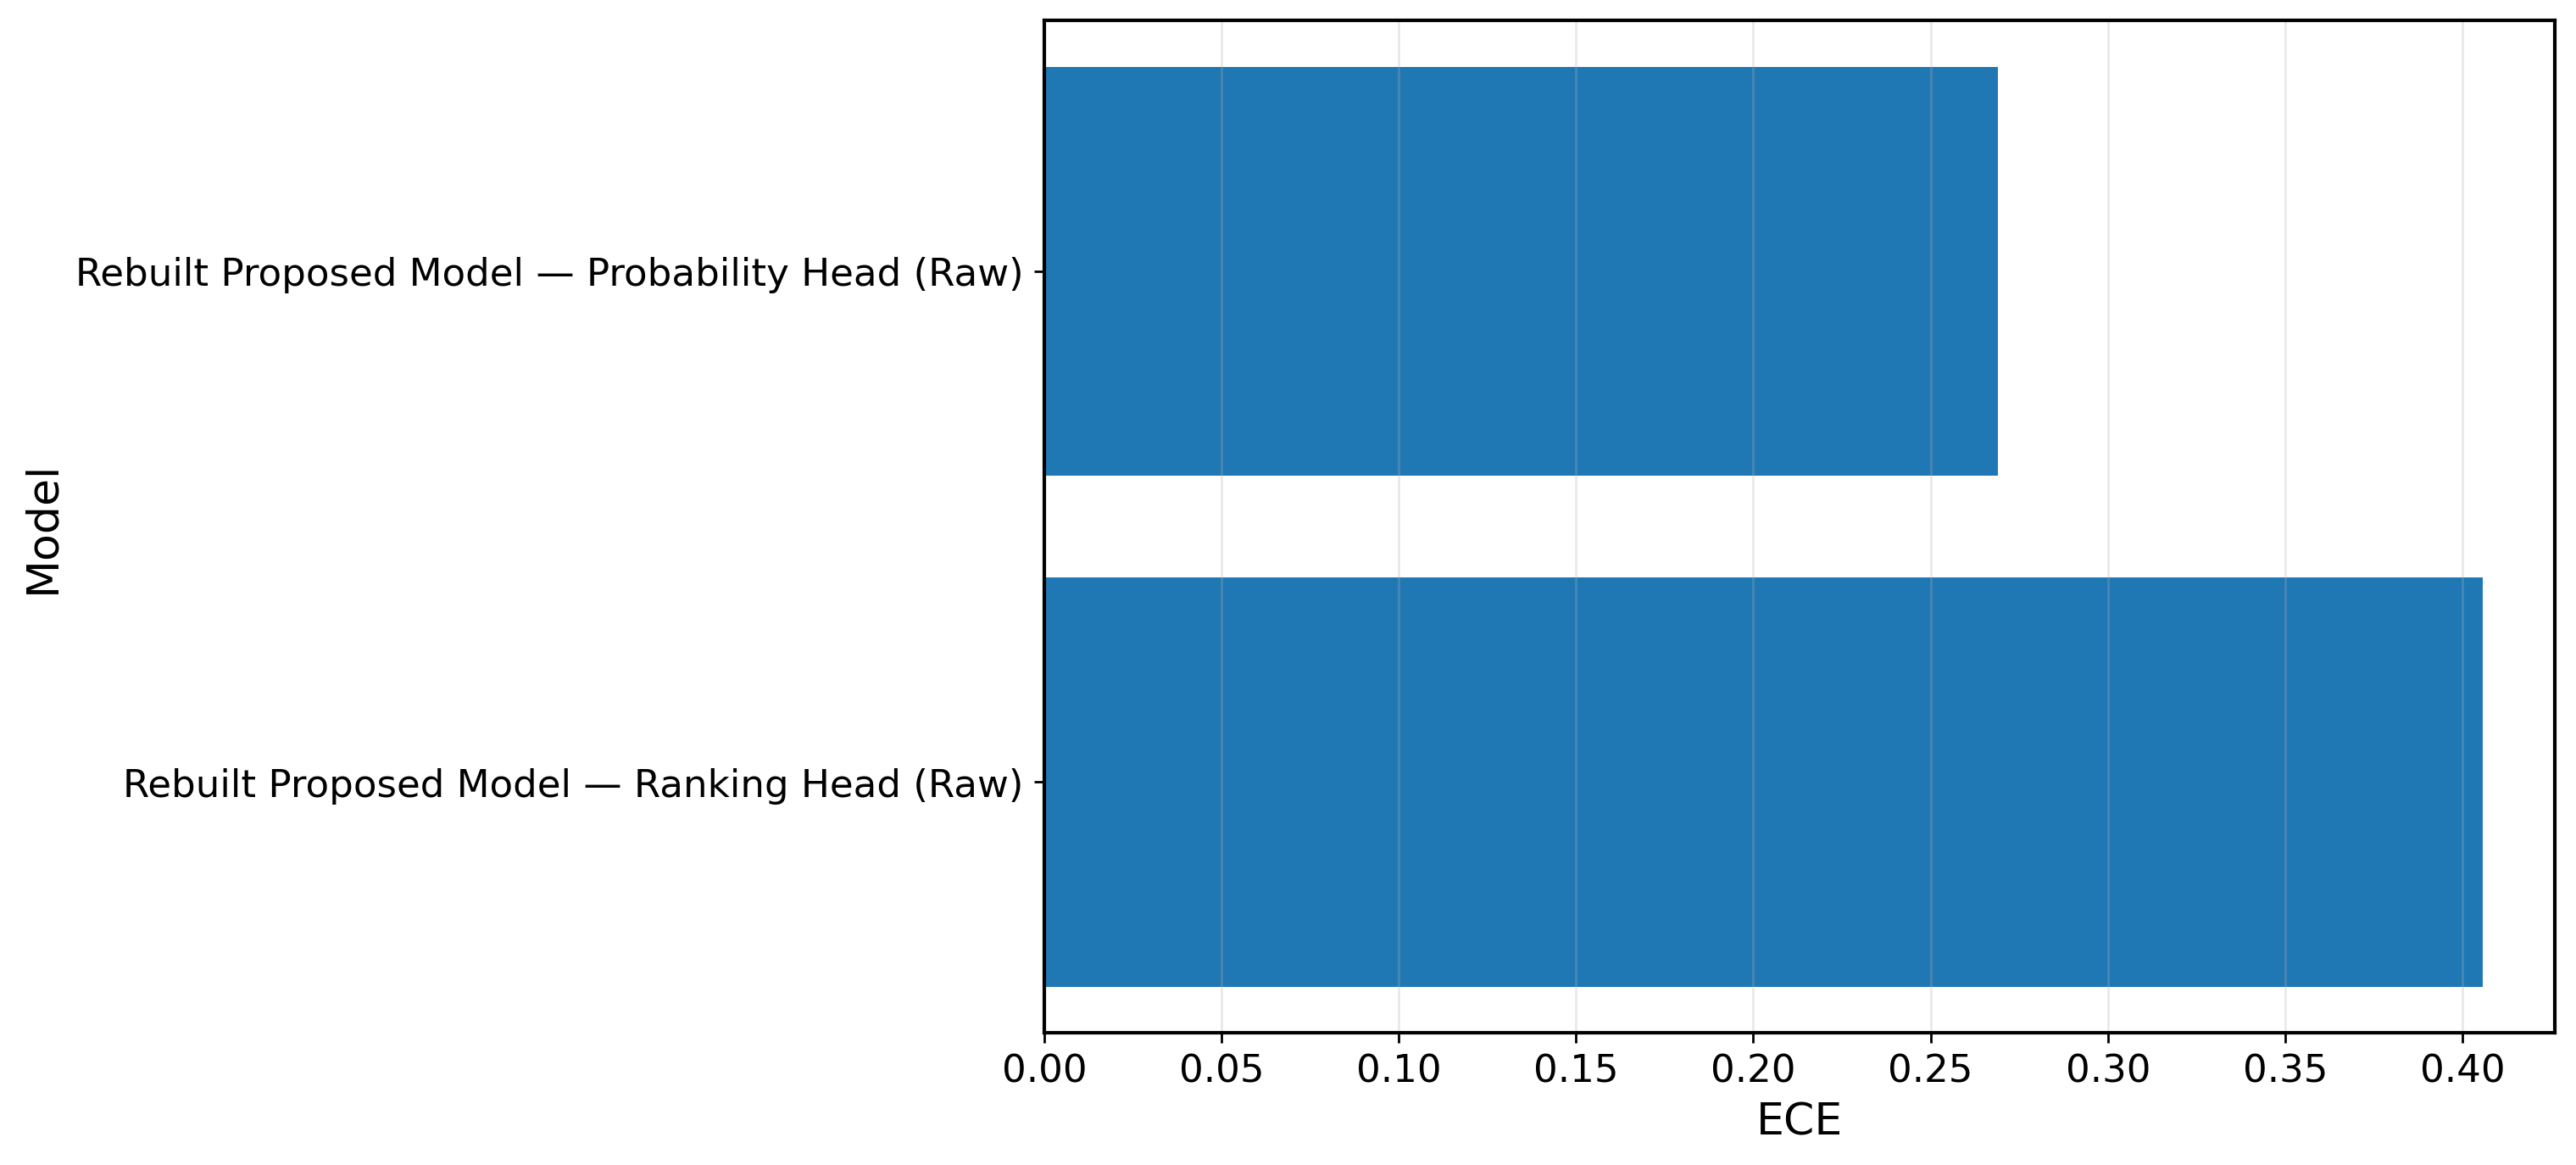


Module 5B complete.
Saved rebuilt Proposed Model heads using DeepFM_Robust.
Next step: calibrate the rebuilt probability head with the same Module 6 procedure.


In [3]:
# ============================================================
# Module 5B — Proposed Model rebuilt with DeepFM_Robust
# Purpose:
#   Rebuild the Proposed Model by replacing DeepFM with
#   DeepFM_Robust while keeping everything else unchanged.
#
# Final experts:
#   - LightGBM_tuned
#   - XGBoost_tuned
#   - DeepFM_Robust
#
# Heads:
#   - Probability head (raw):
#       0.55 * LightGBM_tuned + 0.35 * XGBoost_tuned + 0.10 * DeepFM_Robust
#   - Ranking head (raw):
#       rank-average of LightGBM_tuned, XGBoost_tuned, DeepFM_Robust
#
# Outputs:
#   - p_prob_raw_pm_robust
#   - p_rank_raw_pm_robust
#   - module5b_summary_df
#   - module5b_compare_df
#
# Important figure rule:
#   - no titles inside saved images
# ============================================================

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "y_all",
    "oof_lgb_tuned",
    "oof_xgb_tuned",
    "oof_deepfm_robust",
    "TAB_DIR",
    "FIG_DIR",
    "clip_probs",
    "evaluate_probs",
    "save_figure_multi",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 5B: {missing_vars}")

# -------------------------
# Helpers
# -------------------------
from scipy.stats import rankdata

def rank_scores_local(p):
    p = np.asarray(p).reshape(-1)
    r = rankdata(p, method="average")
    r = (r - 0.5) / len(p)
    return np.clip(r.astype(np.float32), 1e-6, 1 - 1e-6)

def rank_avg_local(p_list):
    rs = [rank_scores_local(p) for p in p_list]
    return np.clip(np.mean(np.vstack(rs), axis=0), 1e-6, 1 - 1e-6).astype(np.float32)

def prob_avg_local(p_list, weights):
    p_list = [clip_probs(p) for p in p_list]
    weights = np.asarray(weights, dtype=np.float32)
    weights = weights / (weights.sum() + 1e-12)

    out = np.zeros_like(p_list[0], dtype=np.float32)
    for w, p in zip(weights, p_list):
        out += w * p
    return clip_probs(out)

# -------------------------
# Inputs
# -------------------------
y_m5b = y_all.astype(int)

p_lgb_m5b = clip_probs(oof_lgb_tuned)
p_xgb_m5b = clip_probs(oof_xgb_tuned)
p_dfm_rob_m5b = clip_probs(oof_deepfm_robust)

# -------------------------
# 5B.1 Build Proposed Model heads with DeepFM_Robust
# -------------------------
p_prob_raw_pm_robust = prob_avg_local(
    [p_lgb_m5b, p_xgb_m5b, p_dfm_rob_m5b],
    weights=[0.55, 0.35, 0.10]
)

p_rank_raw_pm_robust = rank_avg_local(
    [p_lgb_m5b, p_xgb_m5b, p_dfm_rob_m5b]
)

# -------------------------
# 5B.2 Summary table for rebuilt model
# -------------------------
module5b_rows = []
module5b_rows.append(evaluate_probs(y_m5b, p_lgb_m5b, name="LightGBM_tuned"))
module5b_rows.append(evaluate_probs(y_m5b, p_xgb_m5b, name="XGBoost_tuned"))
module5b_rows.append(evaluate_probs(y_m5b, p_dfm_rob_m5b, name="DeepFM_Robust"))
module5b_rows.append(evaluate_probs(y_m5b, p_prob_raw_pm_robust, name="Proposed Model (Robust) — Probability Head (Raw)"))
module5b_rows.append(evaluate_probs(y_m5b, p_rank_raw_pm_robust, name="Proposed Model (Robust) — Ranking Head (Raw)"))

module5b_summary_df = (
    pd.DataFrame(module5b_rows)
    .sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False])
    .reset_index(drop=True)
)
module5b_summary_df.to_csv(TAB_DIR / "module5b_proposed_model_robust_summary.csv", index=False)

print("\nModule 5B rebuilt Proposed Model summary:")
print(module5b_summary_df)

# -------------------------
# 5B.3 Compare original vs rebuilt Proposed Model
# -------------------------
compare_rows = []

# Original model variants if available
if "p_prob_raw_pm" in globals():
    compare_rows.append(evaluate_probs(y_m5b, p_prob_raw_pm, name="Original Proposed Model — Probability Head (Raw)"))
if "p_rank_raw_pm" in globals():
    compare_rows.append(evaluate_probs(y_m5b, p_rank_raw_pm, name="Original Proposed Model — Ranking Head (Raw)"))

# Rebuilt robust variants
compare_rows.append(evaluate_probs(y_m5b, p_prob_raw_pm_robust, name="Rebuilt Proposed Model — Probability Head (Raw)"))
compare_rows.append(evaluate_probs(y_m5b, p_rank_raw_pm_robust, name="Rebuilt Proposed Model — Ranking Head (Raw)"))

module5b_compare_df = (
    pd.DataFrame(compare_rows)
    .sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False])
    .reset_index(drop=True)
)
module5b_compare_df.to_csv(TAB_DIR / "module5b_original_vs_rebuilt_compare.csv", index=False)

print("\nOriginal vs rebuilt Proposed Model comparison:")
print(module5b_compare_df)

# -------------------------
# 5B.4 Compact delta table
# -------------------------
delta_rows = []

if "p_prob_raw_pm" in globals():
    row_orig_prob = evaluate_probs(y_m5b, p_prob_raw_pm, name="orig_prob")
    row_reb_prob = evaluate_probs(y_m5b, p_prob_raw_pm_robust, name="reb_prob")

    delta_rows.append({
        "comparison": "Probability head raw: rebuilt - original",
        "delta_PR_AUC": float(row_reb_prob["PR_AUC"] - row_orig_prob["PR_AUC"]),
        "delta_ROC_AUC": float(row_reb_prob["ROC_AUC"] - row_orig_prob["ROC_AUC"]),
        "delta_Brier": float(row_reb_prob["Brier"] - row_orig_prob["Brier"]),
        "delta_NLL": float(row_reb_prob["NLL"] - row_orig_prob["NLL"]),
        "delta_ECE": float(row_reb_prob["ECE"] - row_orig_prob["ECE"]),
        "delta_F1@bestF1": float(row_reb_prob["F1@bestF1"] - row_orig_prob["F1@bestF1"]),
    })

if "p_rank_raw_pm" in globals():
    row_orig_rank = evaluate_probs(y_m5b, p_rank_raw_pm, name="orig_rank")
    row_reb_rank = evaluate_probs(y_m5b, p_rank_raw_pm_robust, name="reb_rank")

    delta_rows.append({
        "comparison": "Ranking head raw: rebuilt - original",
        "delta_PR_AUC": float(row_reb_rank["PR_AUC"] - row_orig_rank["PR_AUC"]),
        "delta_ROC_AUC": float(row_reb_rank["ROC_AUC"] - row_orig_rank["ROC_AUC"]),
        "delta_Brier": float(row_reb_rank["Brier"] - row_orig_rank["Brier"]),
        "delta_NLL": float(row_reb_rank["NLL"] - row_orig_rank["NLL"]),
        "delta_ECE": float(row_reb_rank["ECE"] - row_orig_rank["ECE"]),
        "delta_F1@bestF1": float(row_reb_rank["F1@bestF1"] - row_orig_rank["F1@bestF1"]),
    })

module5b_delta_df = pd.DataFrame(delta_rows)
module5b_delta_df.to_csv(TAB_DIR / "module5b_rebuilt_delta_summary.csv", index=False)

print("\nModule 5B delta summary:")
print(module5b_delta_df)

# -------------------------
# 5B.5 Figures without titles
# -------------------------
plt.figure(figsize=(9.2, 6.2))
plot_df = module5b_compare_df.copy().sort_values("PR_AUC", ascending=True)
plt.barh(plot_df["model"], plot_df["PR_AUC"])
plt.xlabel("PR-AUC")
plt.ylabel("Model")
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "module5b_compare_prauc")
plt.show()

plt.figure(figsize=(9.2, 6.2))
plot_df = module5b_compare_df.copy().sort_values("Brier", ascending=False)
plt.barh(plot_df["model"], plot_df["Brier"])
plt.xlabel("Brier score")
plt.ylabel("Model")
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "module5b_compare_brier")
plt.show()

plt.figure(figsize=(9.2, 6.2))
plot_df = module5b_compare_df.copy().sort_values("ECE", ascending=False)
plt.barh(plot_df["model"], plot_df["ECE"])
plt.xlabel("ECE")
plt.ylabel("Model")
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "module5b_compare_ece")
plt.show()

# -------------------------
# 5B.6 Save predictions for downstream calibration/evaluation
# -------------------------
module5b_preds_df = pd.DataFrame({
    "y_true": y_m5b.astype(int),
    "p_lgb_tuned": p_lgb_m5b,
    "p_xgb_tuned": p_xgb_m5b,
    "p_deepfm_robust": p_dfm_rob_m5b,
    "p_prob_raw_pm_robust": p_prob_raw_pm_robust,
    "p_rank_raw_pm_robust": p_rank_raw_pm_robust,
})
module5b_preds_df.to_csv(TAB_DIR / "module5b_rebuilt_predictions.csv", index=False)

np.savez_compressed(
    TAB_DIR / "module5b_rebuilt_predictions.npz",
    y_true=y_m5b.astype(np.int32),
    p_lgb_tuned=p_lgb_m5b.astype(np.float32),
    p_xgb_tuned=p_xgb_m5b.astype(np.float32),
    p_deepfm_robust=p_dfm_rob_m5b.astype(np.float32),
    p_prob_raw_pm_robust=p_prob_raw_pm_robust.astype(np.float32),
    p_rank_raw_pm_robust=p_rank_raw_pm_robust.astype(np.float32),
)

print("\nModule 5B complete.")
print("Saved rebuilt Proposed Model heads using DeepFM_Robust.")
print("Next step: calibrate the rebuilt probability head with the same Module 6 procedure.")

Bootstrap will evaluate these models:
- LightGBM_tuned (Raw)
- Proposed Model (Robust) — Probability Head (Raw)
- Proposed Model (Robust) — Ranking Head (Raw)
Bootstrap iteration 50/50

Module 16 point estimates:
     PR_AUC   ROC_AUC     Brier       NLL       ECE       MCE  F1@bestF1  \
0  0.375618  0.849678  0.184456  0.531824  0.276534  0.544321   0.421660   
1  0.377435  0.850230  0.178263  0.516798  0.268863  0.534218   0.421494   
2  0.377665  0.850492  0.272918  0.801187  0.405814  0.629206   0.421752   

   Acc@bestF1  Prec@bestF1  Rec@bestF1  \
0    0.855889     0.338946    0.557778   
1    0.859784     0.344692    0.542335   
2    0.857651     0.341555    0.551166   

                                              model  
0                              LightGBM_tuned (Raw)  
1  Proposed Model (Robust) — Probability Head (Raw)  
2      Proposed Model (Robust) — Ranking Head (Raw)  

Module 16 bootstrap CI summary:
                                              model  n_boot_effe

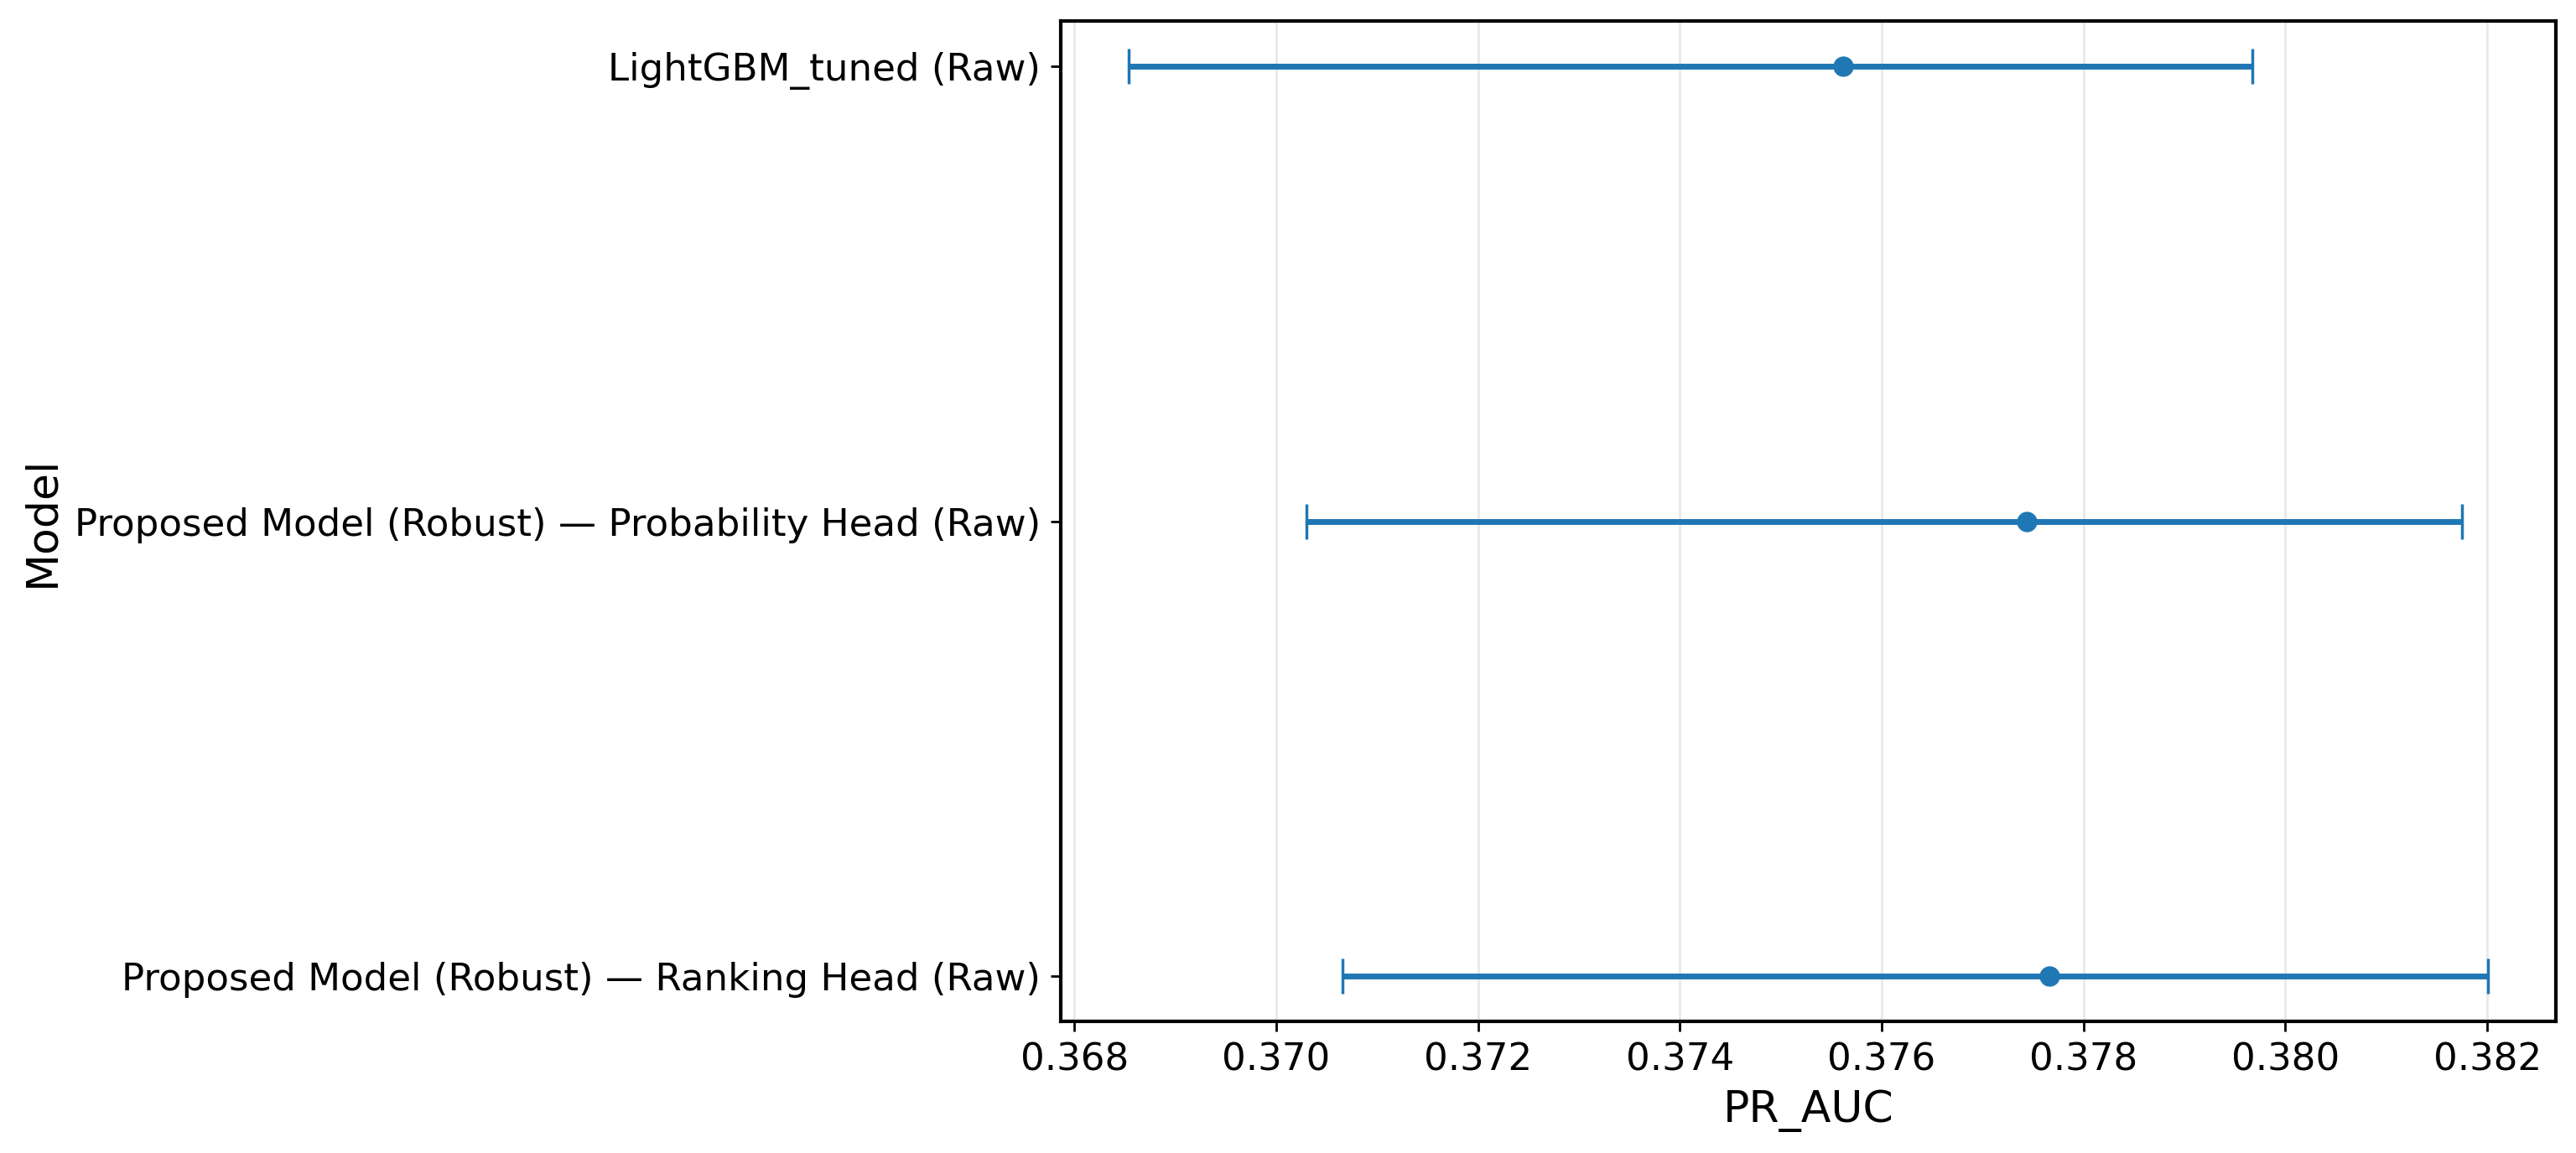

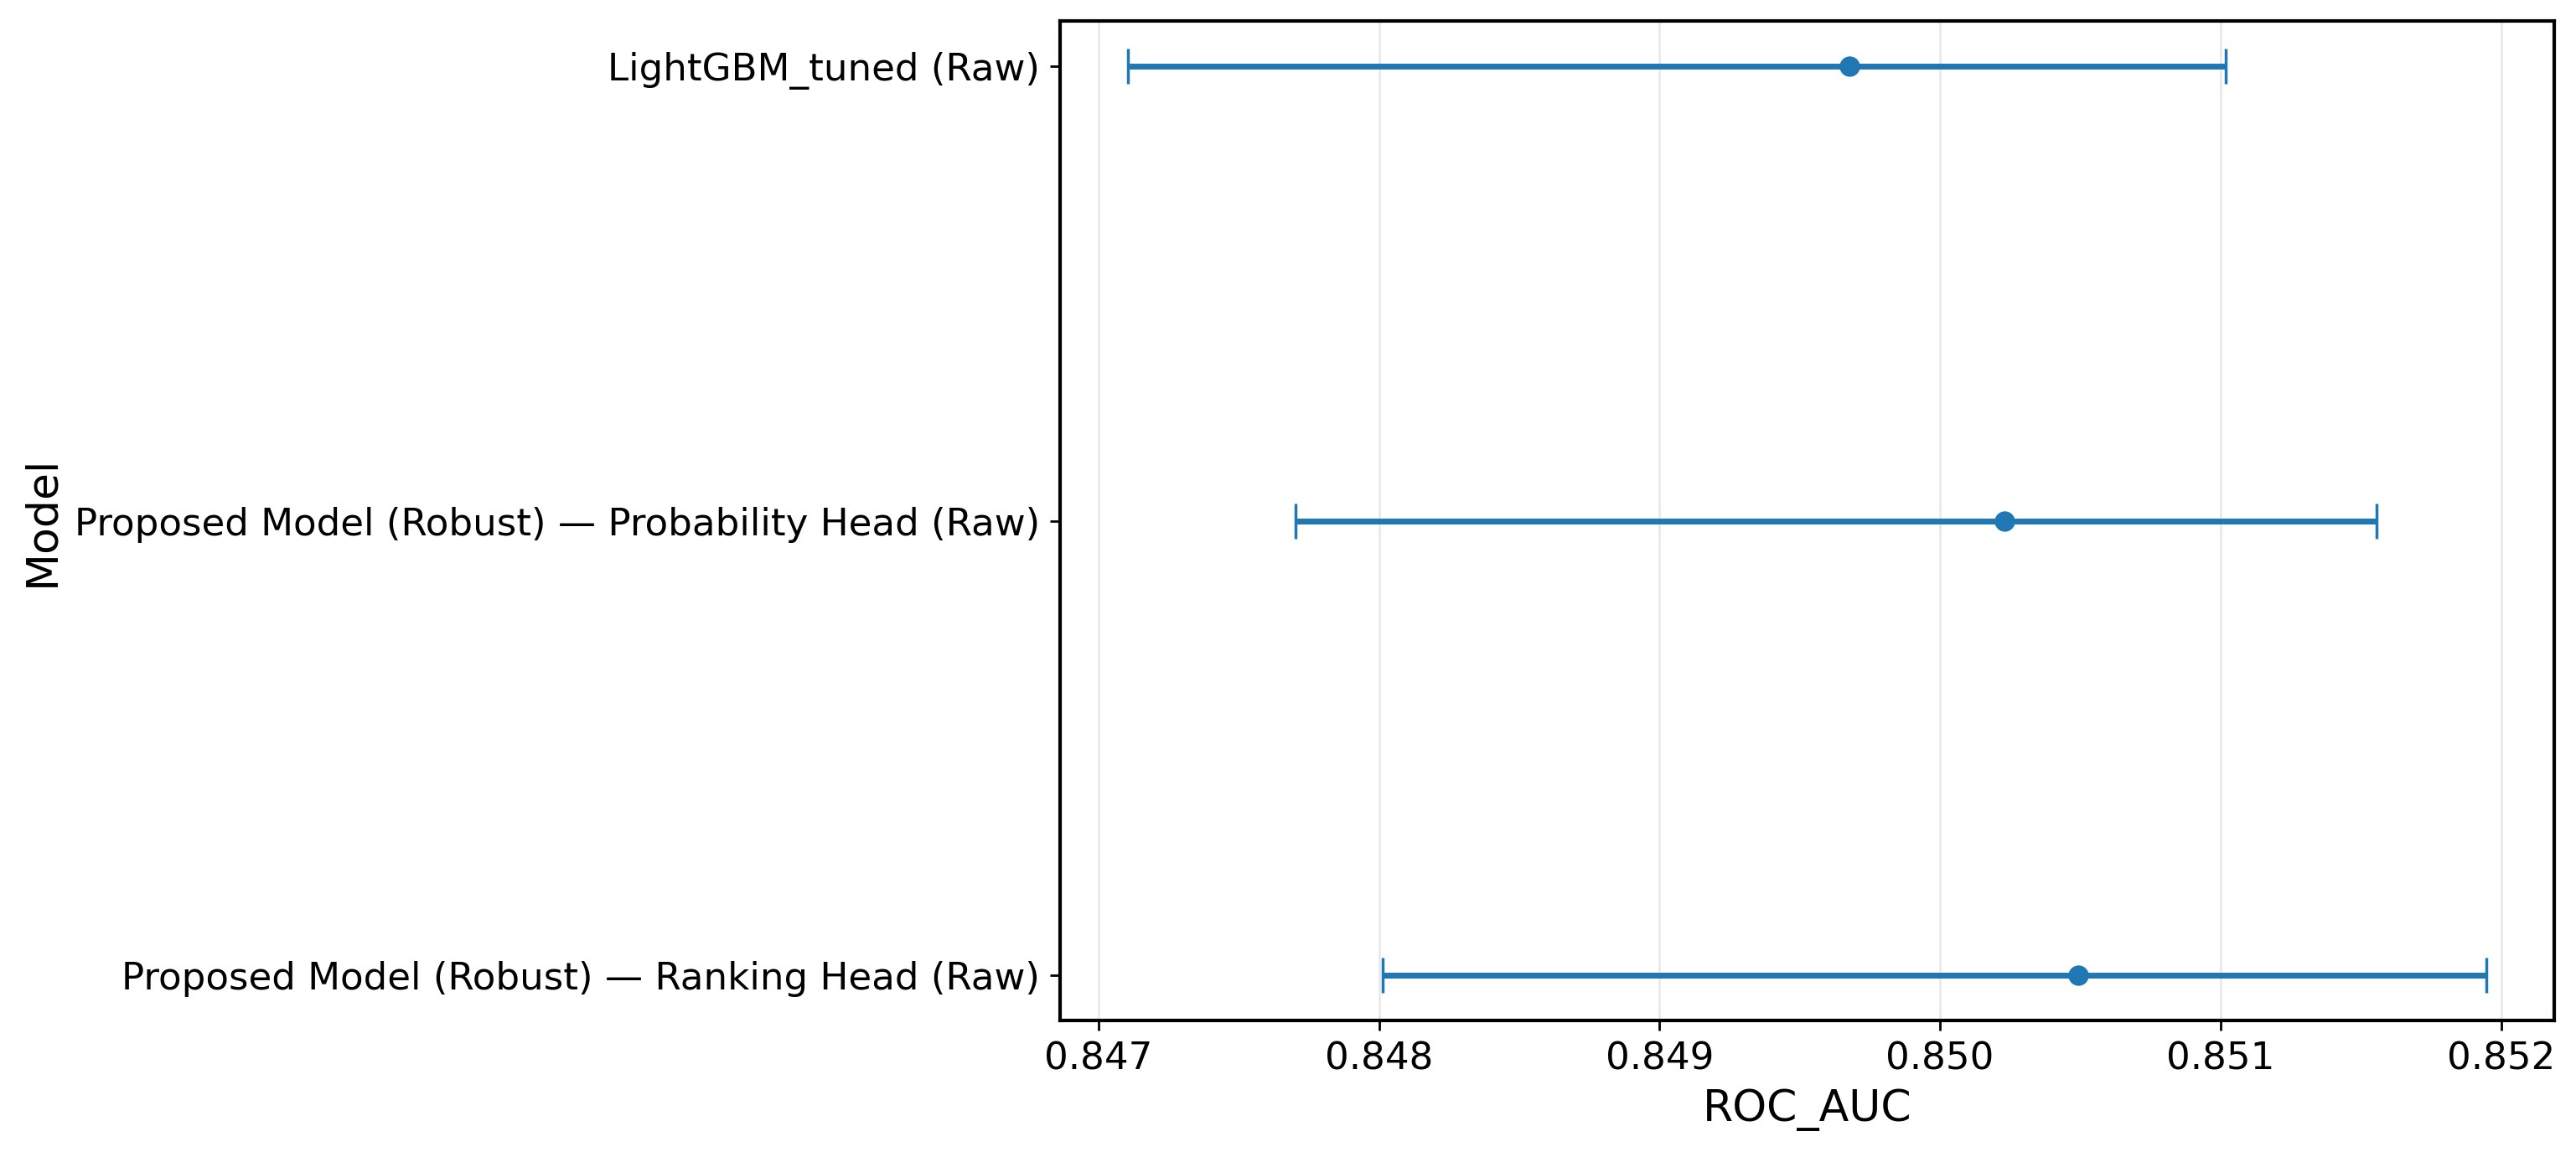

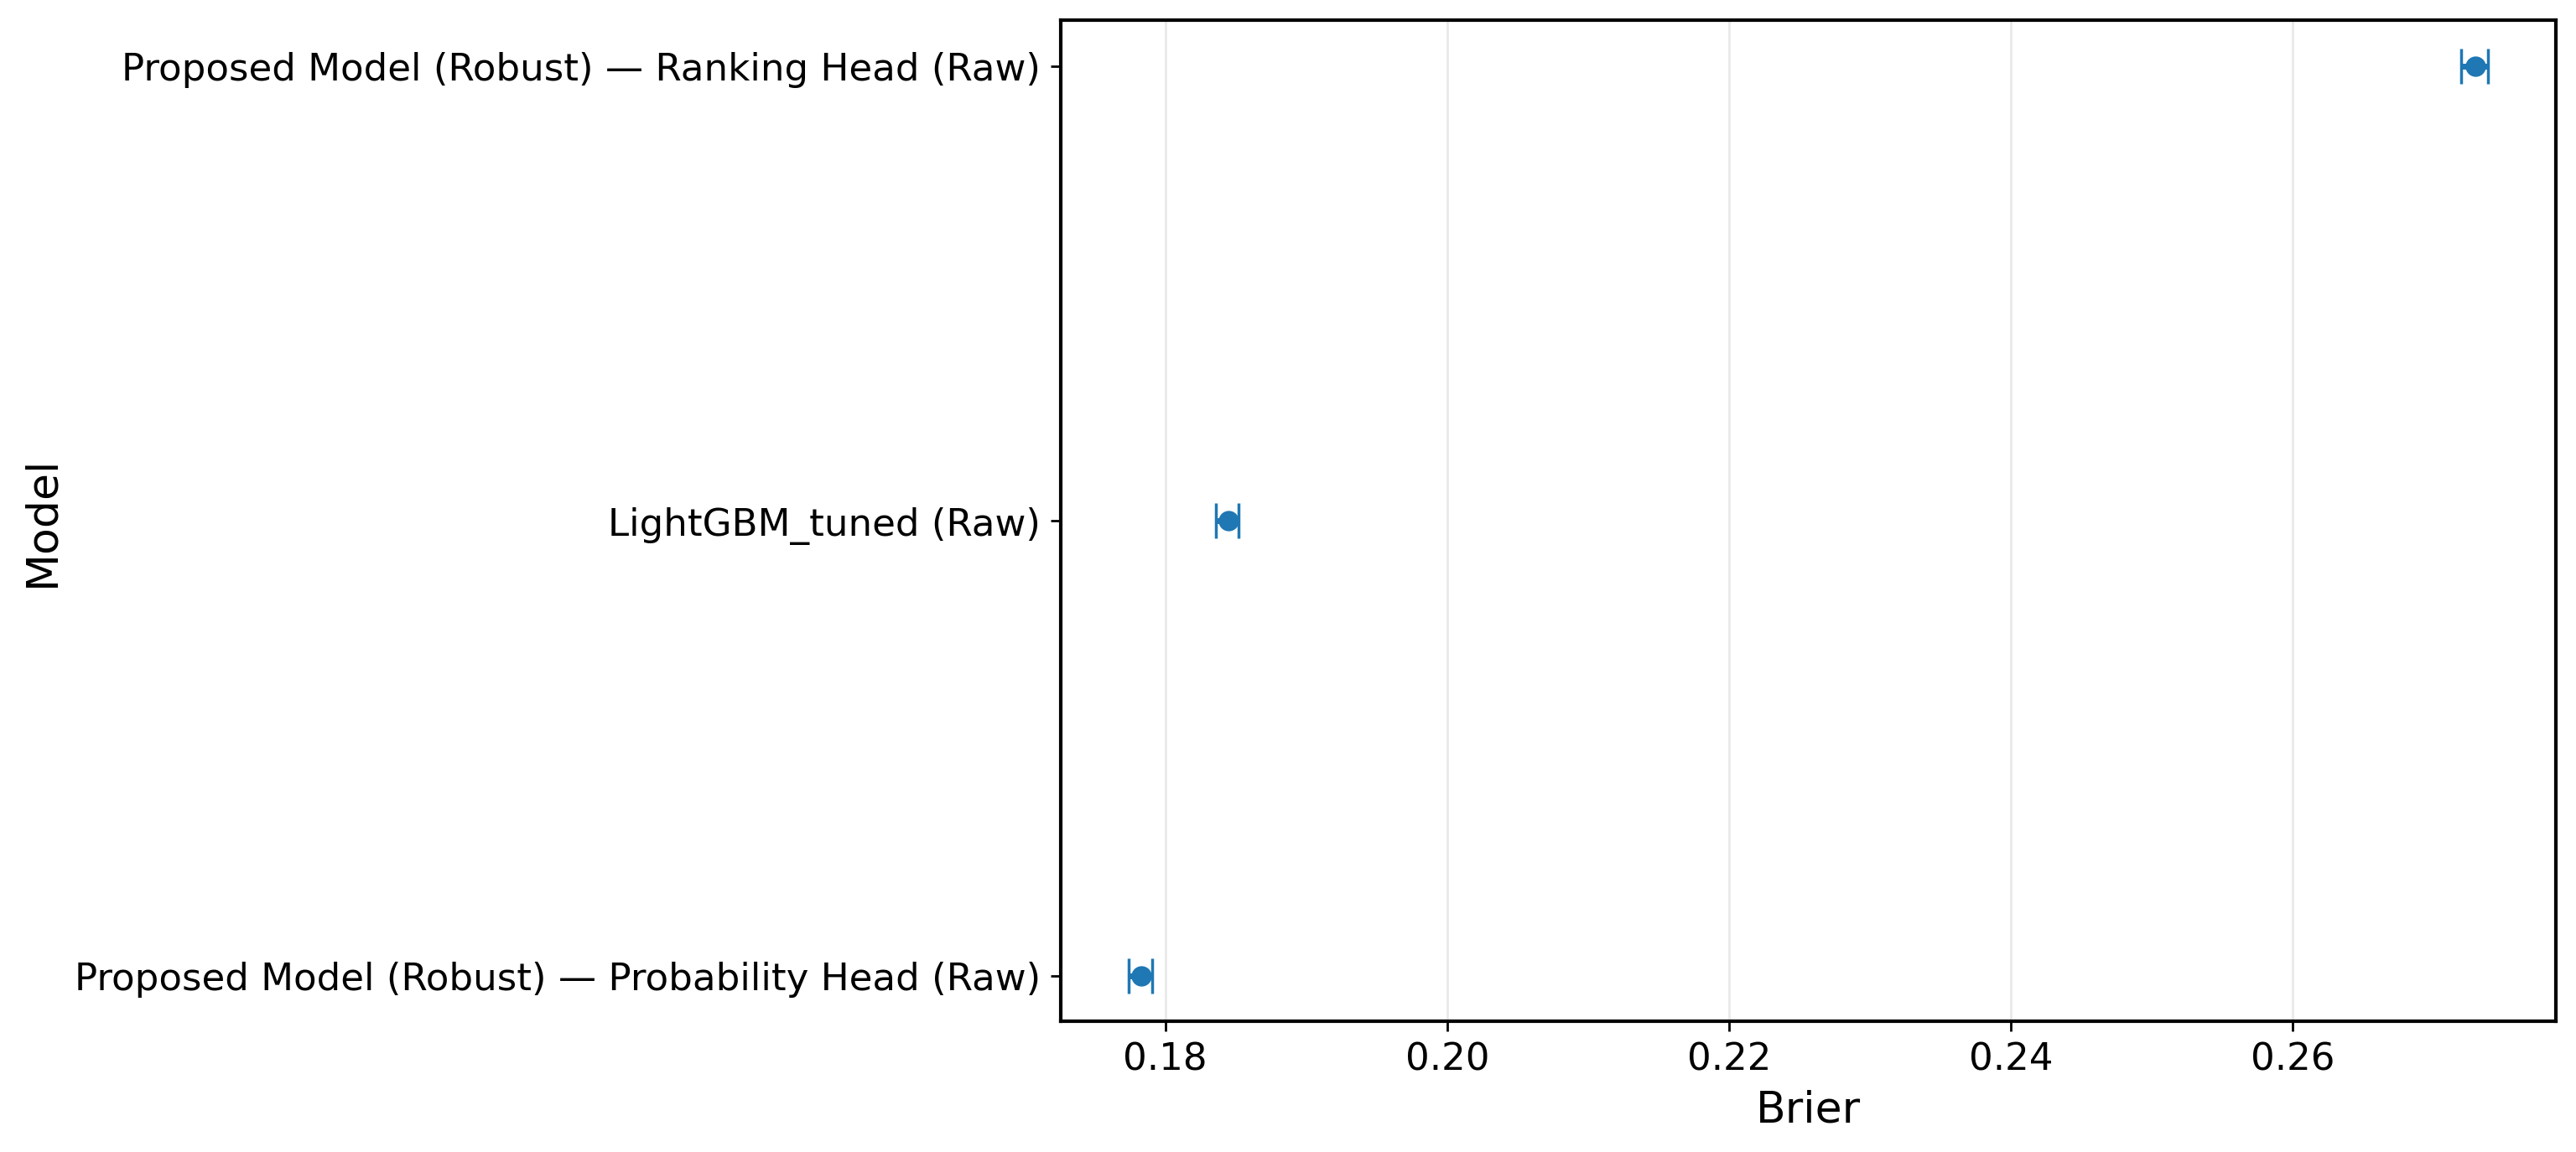

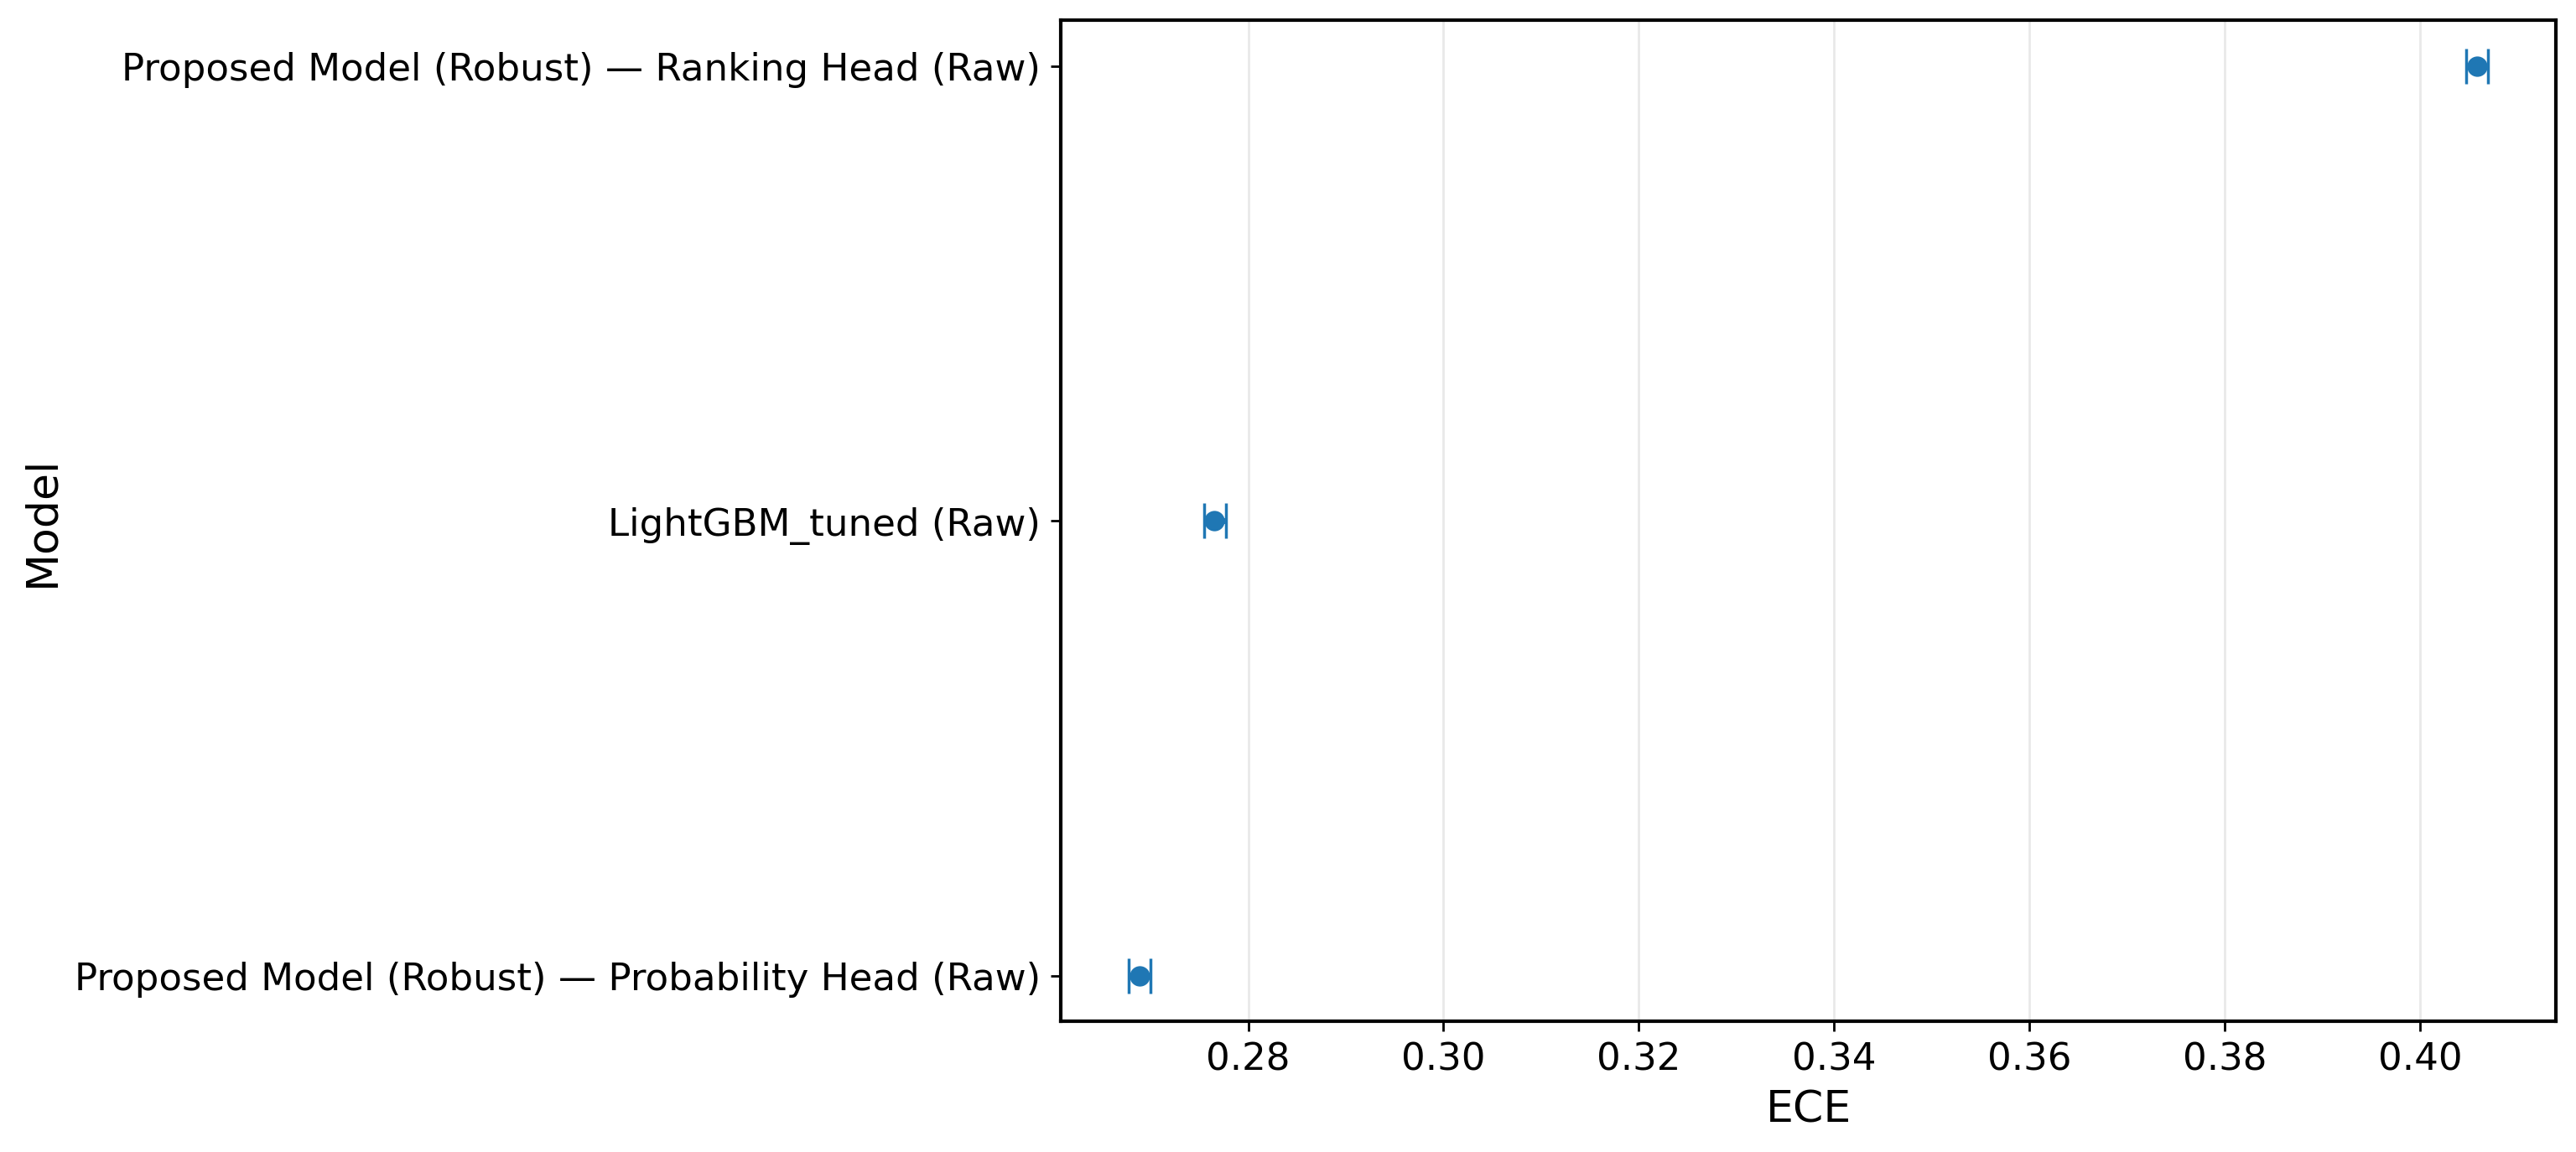


Module 16 manuscript-ready summary:
                                               model  \
0                               LightGBM_tuned (Raw)   
1   Proposed Model (Robust) — Probability Head (Raw)   
2       Proposed Model (Robust) — Ranking Head (Raw)   
3                               LightGBM_tuned (Raw)   
4   Proposed Model (Robust) — Probability Head (Raw)   
5       Proposed Model (Robust) — Ranking Head (Raw)   
6                               LightGBM_tuned (Raw)   
7   Proposed Model (Robust) — Probability Head (Raw)   
8       Proposed Model (Robust) — Ranking Head (Raw)   
9                               LightGBM_tuned (Raw)   
10  Proposed Model (Robust) — Probability Head (Raw)   
11      Proposed Model (Robust) — Ranking Head (Raw)   

                        formatted   metric  
0   0.375618 [0.368540, 0.379672]   PR_AUC  
1   0.377435 [0.370296, 0.381751]   PR_AUC  
2   0.377665 [0.370657, 0.382006]   PR_AUC  
3   0.849678 [0.847106, 0.851018]  ROC_AUC  
4   0.850

In [6]:
# ============================================================
# Module 16 — Bootstrap confidence intervals (patched)
# Purpose:
#   Estimate 95% bootstrap confidence intervals for the current
#   final model candidates available in the notebook state.
#
# This patched version automatically adapts to either:
#   A) original calibrated pipeline variables, or
#   B) rebuilt robust pipeline variables
#
# Metrics:
#   - PR-AUC
#   - ROC-AUC
#   - Brier
#   - NLL
#   - ECE
#   - F1@bestF1
#
# Important figure rule:
#   - no titles inside saved images
# ============================================================

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "y_all",
    "TAB_DIR",
    "FIG_DIR",
    "save_figure_multi",
    "evaluate_probs",
    "clip_probs",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 16: {missing_vars}")

# -------------------------
# Imports
# -------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------
# Config
# -------------------------
BOOT_N = 50
BOOT_SEED = 42
BOOT_ALPHA = 0.05

# -------------------------
# Resolve available model variables
# -------------------------
boot_pred_dict = {}

# Best single expert
if "p_lgb" in globals():
    boot_pred_dict["LightGBM_tuned (Raw)"] = clip_probs(p_lgb)
elif "p_lgb_m5b" in globals():
    boot_pred_dict["LightGBM_tuned (Raw)"] = clip_probs(p_lgb_m5b)
elif "oof_lgb_tuned" in globals():
    boot_pred_dict["LightGBM_tuned (Raw)"] = clip_probs(oof_lgb_tuned)

# Final calibrated deployed probability head if available
if "p_prob_final_pm" in globals():
    model_name_prob = globals().get("final_prob_model_name", "Proposed Model — Final Probability Head")
    boot_pred_dict[model_name_prob] = clip_probs(p_prob_final_pm)

# Rebuilt robust raw probability head if calibrated one is not yet available
elif "p_prob_raw_pm_robust" in globals():
    boot_pred_dict["Proposed Model (Robust) — Probability Head (Raw)"] = clip_probs(p_prob_raw_pm_robust)

# Original raw probability head fallback
elif "p_prob_raw_pm" in globals():
    boot_pred_dict["Proposed Model — Probability Head (Raw)"] = clip_probs(p_prob_raw_pm)

# Ranking head
if "p_rank_final_pm" in globals():
    boot_pred_dict["Proposed Model — Ranking Head (Raw)"] = clip_probs(p_rank_final_pm)
elif "p_rank_raw_pm_robust" in globals():
    boot_pred_dict["Proposed Model (Robust) — Ranking Head (Raw)"] = clip_probs(p_rank_raw_pm_robust)
elif "p_rank_raw_pm" in globals():
    boot_pred_dict["Proposed Model — Ranking Head (Raw)"] = clip_probs(p_rank_raw_pm)

if len(boot_pred_dict) < 2:
    raise ValueError(
        "Module 16 could not find enough prediction vectors. "
        "Need at least two of: LightGBM, probability head, ranking head."
    )

print("Bootstrap will evaluate these models:")
for k in boot_pred_dict.keys():
    print("-", k)

# -------------------------
# Helpers
# -------------------------
def bootstrap_indices(n, rng):
    return rng.integers(0, n, size=n)

def compute_metrics_on_sample(y_true, p, model_name="model"):
    row = evaluate_probs(y_true, p, name=model_name)
    keep = {
        "PR_AUC": row["PR_AUC"],
        "ROC_AUC": row["ROC_AUC"],
        "Brier": row["Brier"],
        "NLL": row["NLL"],
        "ECE": row["ECE"],
        "MCE": row["MCE"] if "MCE" in row else np.nan,
        "F1@bestF1": row["F1@bestF1"],
        "Acc@bestF1": row["Acc@bestF1"],
        "Prec@bestF1": row["Prec@bestF1"],
        "Rec@bestF1": row["Rec@bestF1"],
    }
    return keep

def bootstrap_metric_table(y_true, pred_dict, n_boot=50, seed=42, alpha=0.05):
    y_true = np.asarray(y_true).astype(int)
    n = len(y_true)
    rng = np.random.default_rng(seed)

    point_rows = []
    boot_storage = {name: [] for name in pred_dict.keys()}

    # Point estimates
    for name, p in pred_dict.items():
        point = compute_metrics_on_sample(y_true, clip_probs(p), model_name=name)
        point["model"] = name
        point_rows.append(point)

    point_df = pd.DataFrame(point_rows)

    # Bootstrap resamples
    for b in range(n_boot):
        idx = bootstrap_indices(n, rng)
        yb = y_true[idx]

        if len(np.unique(yb)) < 2:
            continue

        for name, p in pred_dict.items():
            pb = clip_probs(p)[idx]
            boot_storage[name].append(compute_metrics_on_sample(yb, pb, model_name=name))

        if (b + 1) % 50 == 0:
            print(f"Bootstrap iteration {b+1}/{n_boot}")

    summary_rows = []
    lower_q = alpha / 2
    upper_q = 1 - alpha / 2
    metric_cols = ["PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE", "MCE", "F1@bestF1", "Acc@bestF1", "Prec@bestF1", "Rec@bestF1"]

    for name in pred_dict.keys():
        if len(boot_storage[name]) == 0:
            continue

        boot_df = pd.DataFrame(boot_storage[name])
        point_row = point_df[point_df["model"] == name].iloc[0].to_dict()

        row = {"model": name, "n_boot_effective": int(len(boot_df))}
        for m in metric_cols:
            vals = boot_df[m].dropna().values.astype(float)
            row[f"{m}_point"] = float(point_row[m])
            row[f"{m}_mean_boot"] = float(np.mean(vals)) if len(vals) > 0 else np.nan
            row[f"{m}_std_boot"] = float(np.std(vals, ddof=1)) if len(vals) > 1 else np.nan
            row[f"{m}_ci_low"] = float(np.quantile(vals, lower_q)) if len(vals) > 0 else np.nan
            row[f"{m}_ci_high"] = float(np.quantile(vals, upper_q)) if len(vals) > 0 else np.nan
        summary_rows.append(row)

    summary_df = pd.DataFrame(summary_rows)
    return point_df, summary_df, boot_storage

def format_ci_table(summary_df, metric):
    cols = [
        "model",
        f"{metric}_point",
        f"{metric}_ci_low",
        f"{metric}_ci_high",
        f"{metric}_std_boot",
    ]
    out = summary_df[cols].copy()
    out["formatted"] = out.apply(
        lambda r: f"{r[f'{metric}_point']:.6f} [{r[f'{metric}_ci_low']:.6f}, {r[f'{metric}_ci_high']:.6f}]",
        axis=1
    )
    return out

def plot_boot_ci(summary_df, metric, higher_is_better=True, save_path_base=None):
    df = summary_df.copy()
    sort_ascending = not higher_is_better
    df = df.sort_values(f"{metric}_point", ascending=sort_ascending).reset_index(drop=True)

    x = df[f"{metric}_point"].values
    xerr_low = x - df[f"{metric}_ci_low"].values
    xerr_high = df[f"{metric}_ci_high"].values - x

    plt.figure(figsize=(9.2, 6.2))
    y_pos = np.arange(len(df))
    plt.errorbar(
        x,
        y_pos,
        xerr=np.vstack([xerr_low, xerr_high]),
        fmt="o",
        capsize=6,
        linewidth=2,
    )
    plt.yticks(y_pos, df["model"])
    plt.xlabel(metric)
    plt.ylabel("Model")
    plt.grid(True, axis="x")

    if save_path_base is not None:
        save_figure_multi(save_path_base)
    plt.show()

def net_benefit_at_threshold(y_true, p, threshold):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    pred = (p >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    n = len(y_true)
    odds = threshold / max(1.0 - threshold, 1e-12)
    nb = (tp / n) - (fp / n) * odds
    return float(nb)

def bootstrap_decision_curve_summary(y_true, pred_dict, thresholds, n_boot=300, seed=42, alpha=0.05):
    y_true = np.asarray(y_true).astype(int)
    n = len(y_true)
    rng = np.random.default_rng(seed)

    point_rows = []
    boot_rows = []

    for name, p in pred_dict.items():
        nb_vals = [net_benefit_at_threshold(y_true, p, t) for t in thresholds]
        point_rows.append({
            "model": name,
            "avg_NB": float(np.mean(nb_vals)),
            "max_NB": float(np.max(nb_vals)),
        })

    for b in range(n_boot):
        idx = bootstrap_indices(n, rng)
        yb = y_true[idx]
        if len(np.unique(yb)) < 2:
            continue

        for name, p in pred_dict.items():
            pb = clip_probs(p)[idx]
            nb_vals = [net_benefit_at_threshold(yb, pb, t) for t in thresholds]
            boot_rows.append({
                "bootstrap_id": b,
                "model": name,
                "avg_NB": float(np.mean(nb_vals)),
                "max_NB": float(np.max(nb_vals)),
            })

    point_df = pd.DataFrame(point_rows)
    boot_df = pd.DataFrame(boot_rows)

    summary_rows = []
    for name, g in boot_df.groupby("model"):
        row_point = point_df[point_df["model"] == name].iloc[0]
        row = {"model": name}
        for m in ["avg_NB", "max_NB"]:
            vals = g[m].values.astype(float)
            row[f"{m}_point"] = float(row_point[m])
            row[f"{m}_ci_low"] = float(np.quantile(vals, alpha / 2))
            row[f"{m}_ci_high"] = float(np.quantile(vals, 1 - alpha / 2))
            row[f"{m}_std_boot"] = float(np.std(vals, ddof=1)) if len(vals) > 1 else np.nan
        summary_rows.append(row)

    return point_df, pd.DataFrame(summary_rows), boot_df

# -------------------------
# Inputs
# -------------------------
y_boot = y_all.astype(int)

# -------------------------
# 16.1 Main bootstrap CI table
# -------------------------
module16_point_df, module16_ci_df, module16_boot_storage = bootstrap_metric_table(
    y_true=y_boot,
    pred_dict=boot_pred_dict,
    n_boot=BOOT_N,
    seed=BOOT_SEED,
    alpha=BOOT_ALPHA,
)

module16_point_df.to_csv(TAB_DIR / "module16_bootstrap_point_estimates.csv", index=False)
module16_ci_df.to_csv(TAB_DIR / "module16_bootstrap_confidence_intervals.csv", index=False)

print("\nModule 16 point estimates:")
print(module16_point_df)

print("\nModule 16 bootstrap CI summary:")
print(module16_ci_df)

# -------------------------
# 16.2 Compact formatted tables per metric
# -------------------------
for metric in ["PR_AUC", "ROC_AUC", "Brier", "NLL", "ECE", "F1@bestF1"]:
    fmt_df = format_ci_table(module16_ci_df, metric)
    fmt_df.to_csv(TAB_DIR / f"module16_{metric.lower().replace('@','at').replace('-','_')}_formatted_ci_table.csv", index=False)
    print(f"\nFormatted CI table for {metric}:")
    print(fmt_df[["model", "formatted"]])

# -------------------------
# 16.3 Optional decision-curve bootstrap CI
# -------------------------
module16_dca_point_df = pd.DataFrame()
module16_dca_ci_df = pd.DataFrame()

dca_thresholds = np.round(np.linspace(0.05, 0.50, 46), 3)

try:
    module16_dca_point_df, module16_dca_ci_df, module16_dca_boot_df = bootstrap_decision_curve_summary(
        y_true=y_boot,
        pred_dict=boot_pred_dict,
        thresholds=dca_thresholds,
        n_boot=50,
        seed=BOOT_SEED,
        alpha=BOOT_ALPHA,
    )
    module16_dca_point_df.to_csv(TAB_DIR / "module16_decision_curve_point_estimates.csv", index=False)
    module16_dca_ci_df.to_csv(TAB_DIR / "module16_decision_curve_ci_summary.csv", index=False)

    print("\nModule 16 decision-curve bootstrap summary:")
    print(module16_dca_ci_df)
except Exception as e:
    print("\nDecision-curve bootstrap skipped due to:", str(e))

# -------------------------
# 16.4 Paper-quality CI figures without titles
# -------------------------
plot_boot_ci(
    module16_ci_df,
    metric="PR_AUC",
    higher_is_better=True,
    save_path_base=FIG_DIR / "module16_ci_prauc",
)

plot_boot_ci(
    module16_ci_df,
    metric="ROC_AUC",
    higher_is_better=True,
    save_path_base=FIG_DIR / "module16_ci_rocauc",
)

plot_boot_ci(
    module16_ci_df,
    metric="Brier",
    higher_is_better=False,
    save_path_base=FIG_DIR / "module16_ci_brier",
)

plot_boot_ci(
    module16_ci_df,
    metric="ECE",
    higher_is_better=False,
    save_path_base=FIG_DIR / "module16_ci_ece",
)

# -------------------------
# 16.5 Save full bootstrap draws
# -------------------------
boot_long_rows = []
for model_name, rows in module16_boot_storage.items():
    tmp = pd.DataFrame(rows)
    tmp["model"] = model_name
    boot_long_rows.append(tmp)

module16_boot_long_df = pd.concat(boot_long_rows, axis=0, ignore_index=True)
module16_boot_long_df.to_csv(TAB_DIR / "module16_bootstrap_long_draws.csv", index=False)

# -------------------------
# 16.6 Compact manuscript summary
# -------------------------
summary_rows = []
for metric in ["PR_AUC", "ROC_AUC", "Brier", "ECE"]:
    tmp = format_ci_table(module16_ci_df, metric)[["model", "formatted"]].copy()
    tmp["metric"] = metric
    summary_rows.append(tmp)

module16_manuscript_summary_df = pd.concat(summary_rows, axis=0, ignore_index=True)
module16_manuscript_summary_df.to_csv(TAB_DIR / "module16_manuscript_summary.csv", index=False)

print("\nModule 16 manuscript-ready summary:")
print(module16_manuscript_summary_df)

print("\nModule 16 complete.")
print("Saved bootstrap confidence intervals, formatted tables, and paper-ready figures.")


Module 17 threshold-wise results preview:
    threshold  Precision    Recall  Specificity        F1  Accuracy  \
0        0.05   0.112041  0.994936     0.180110  0.201402  0.256855   
1        0.06   0.115892  0.993429     0.211983  0.207569  0.285584   
2        0.07   0.119381  0.991295     0.239670  0.213098  0.310462   
3        0.08   0.122672  0.989202     0.264388  0.218275  0.332655   
4        0.09   0.125716  0.987025     0.286269  0.223026  0.352271   
5        0.10   0.128626  0.985561     0.305766  0.227553  0.369793   
6        0.11   0.131356  0.983635     0.323652  0.231763  0.385813   
7        0.12   0.133978  0.980999     0.340659  0.235757  0.400970   
8        0.13   0.136648  0.978948     0.356883  0.239820  0.415472   
9        0.14   0.139231  0.976646     0.372184  0.243718  0.429115   
10       0.15   0.141805  0.974595     0.386715  0.247586  0.442085   
11       0.16   0.144175  0.972126     0.399983  0.251108  0.453871   
12       0.17   0.146463  0.969866

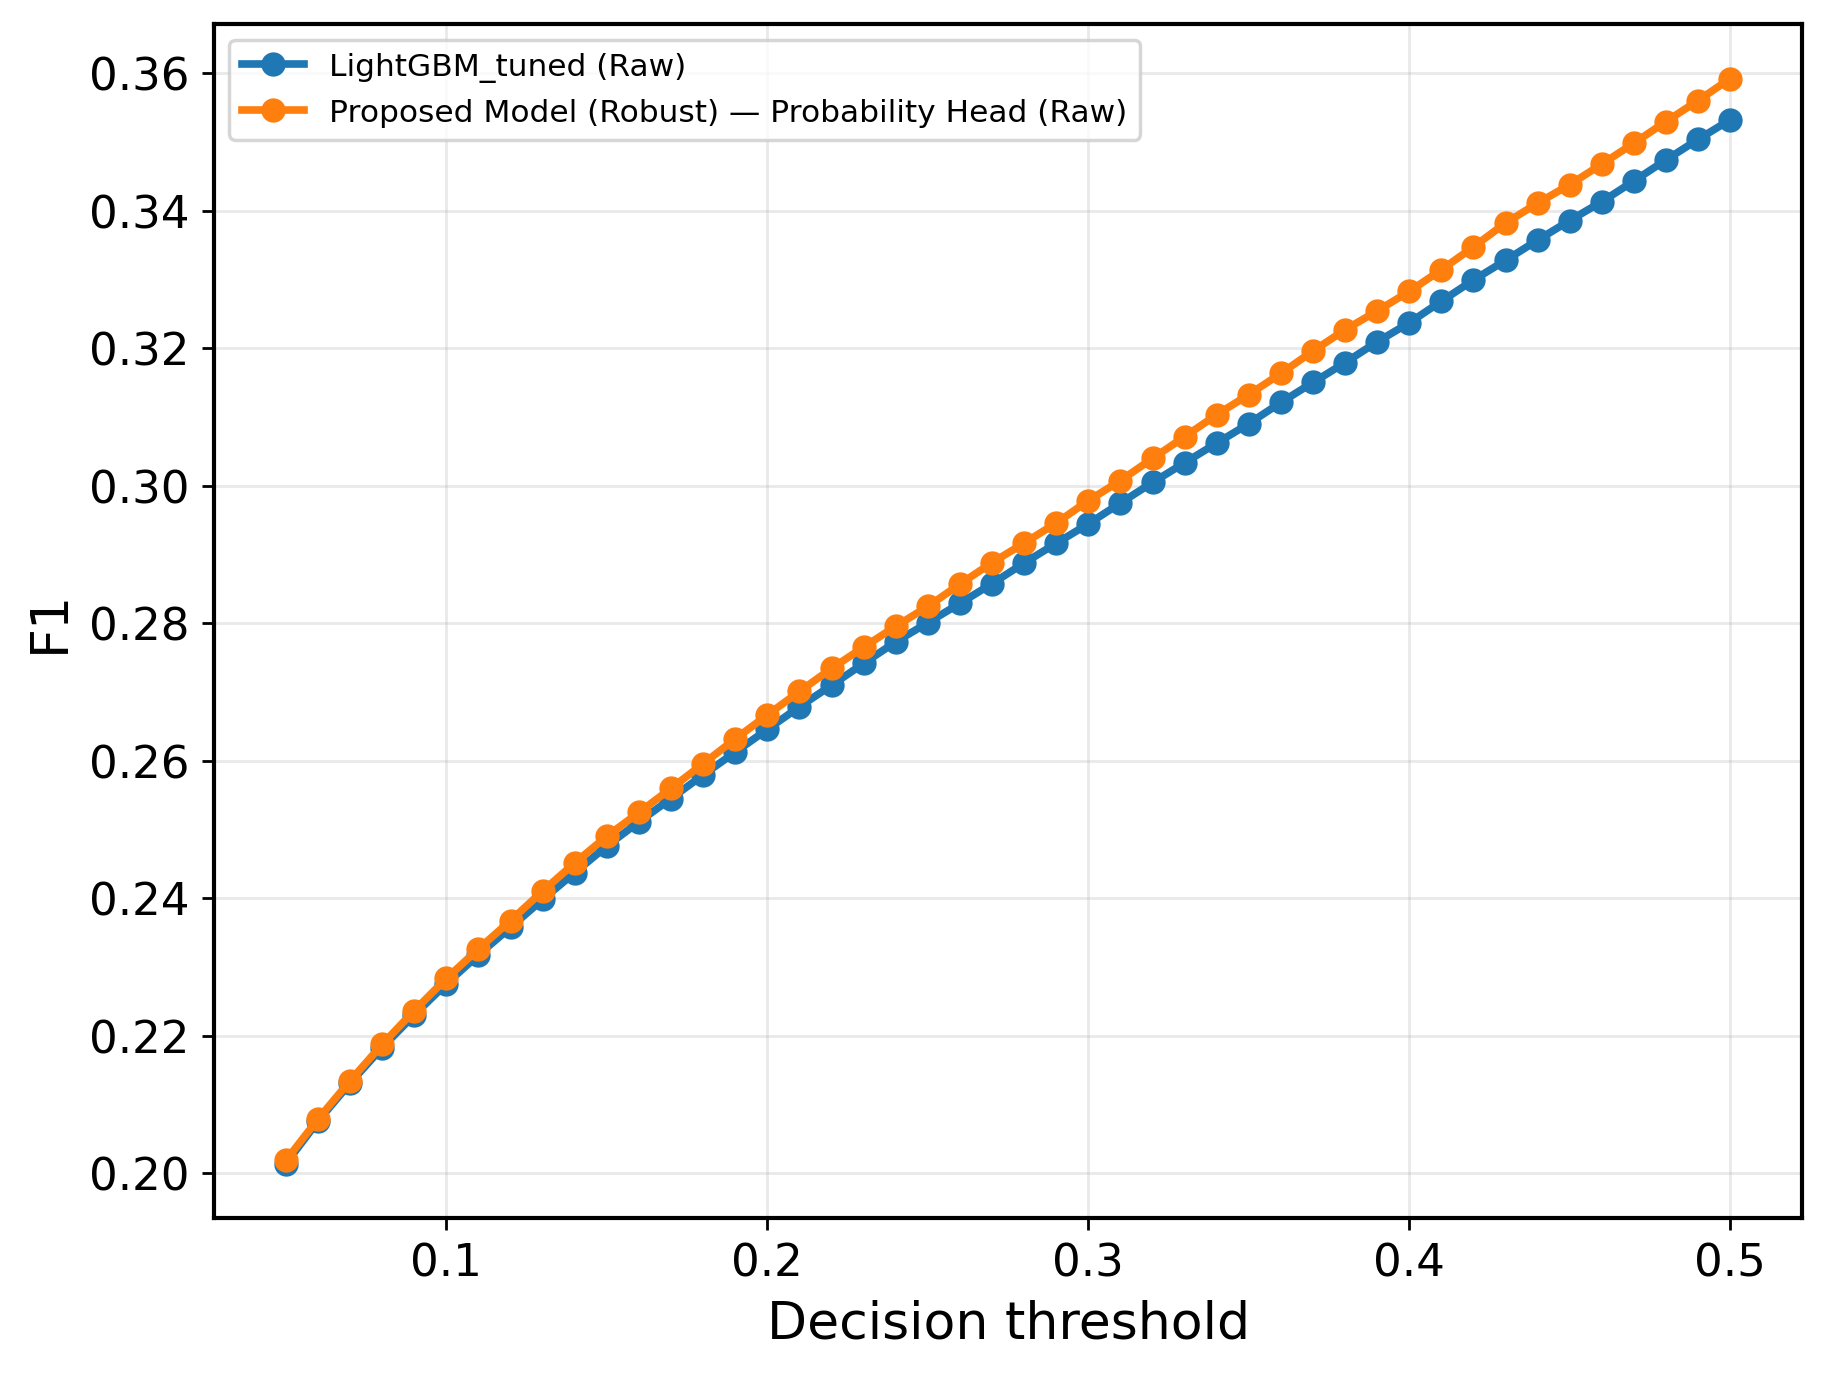

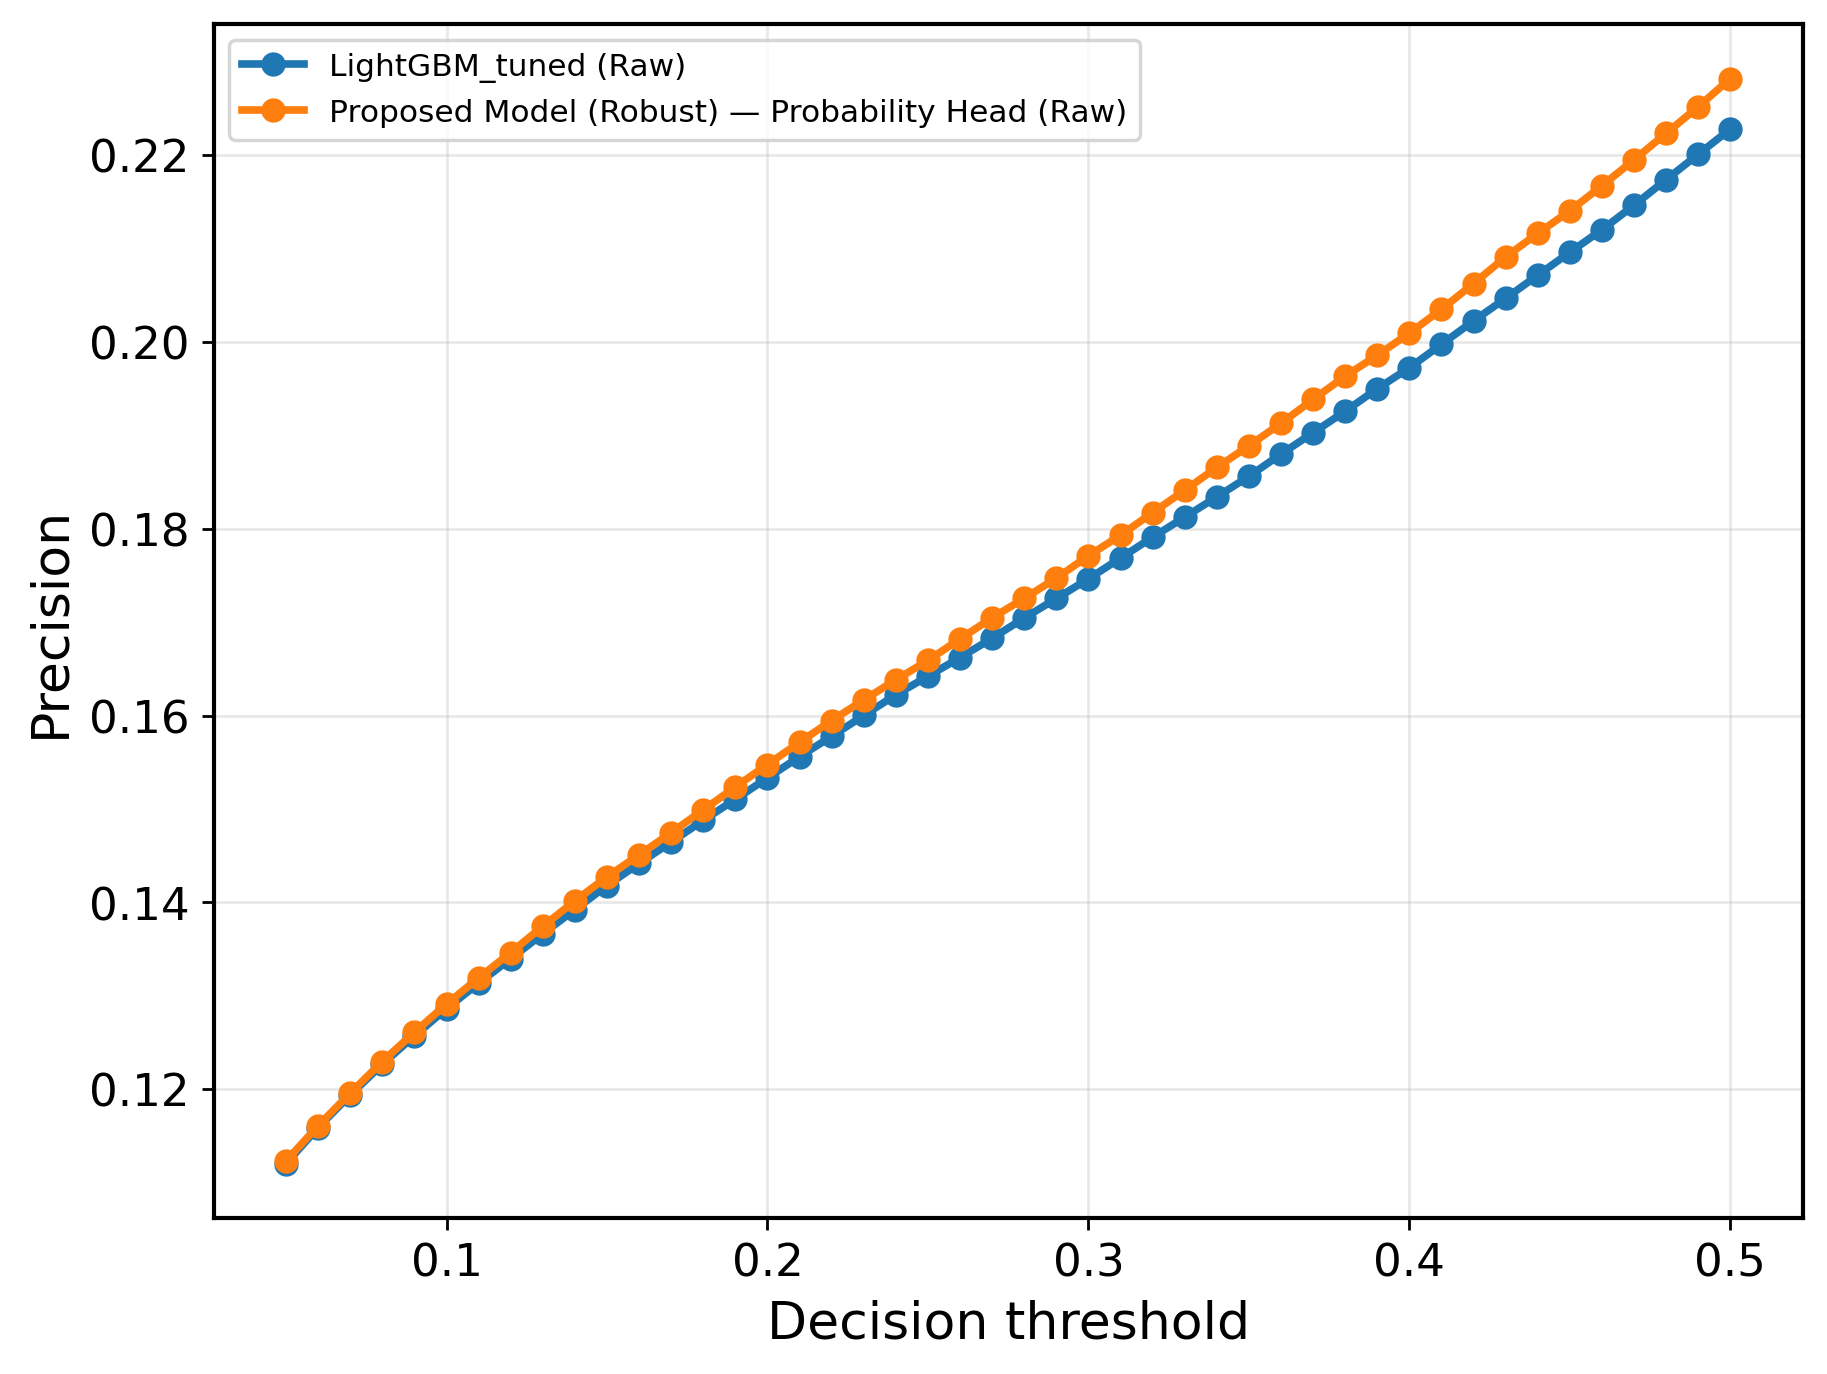

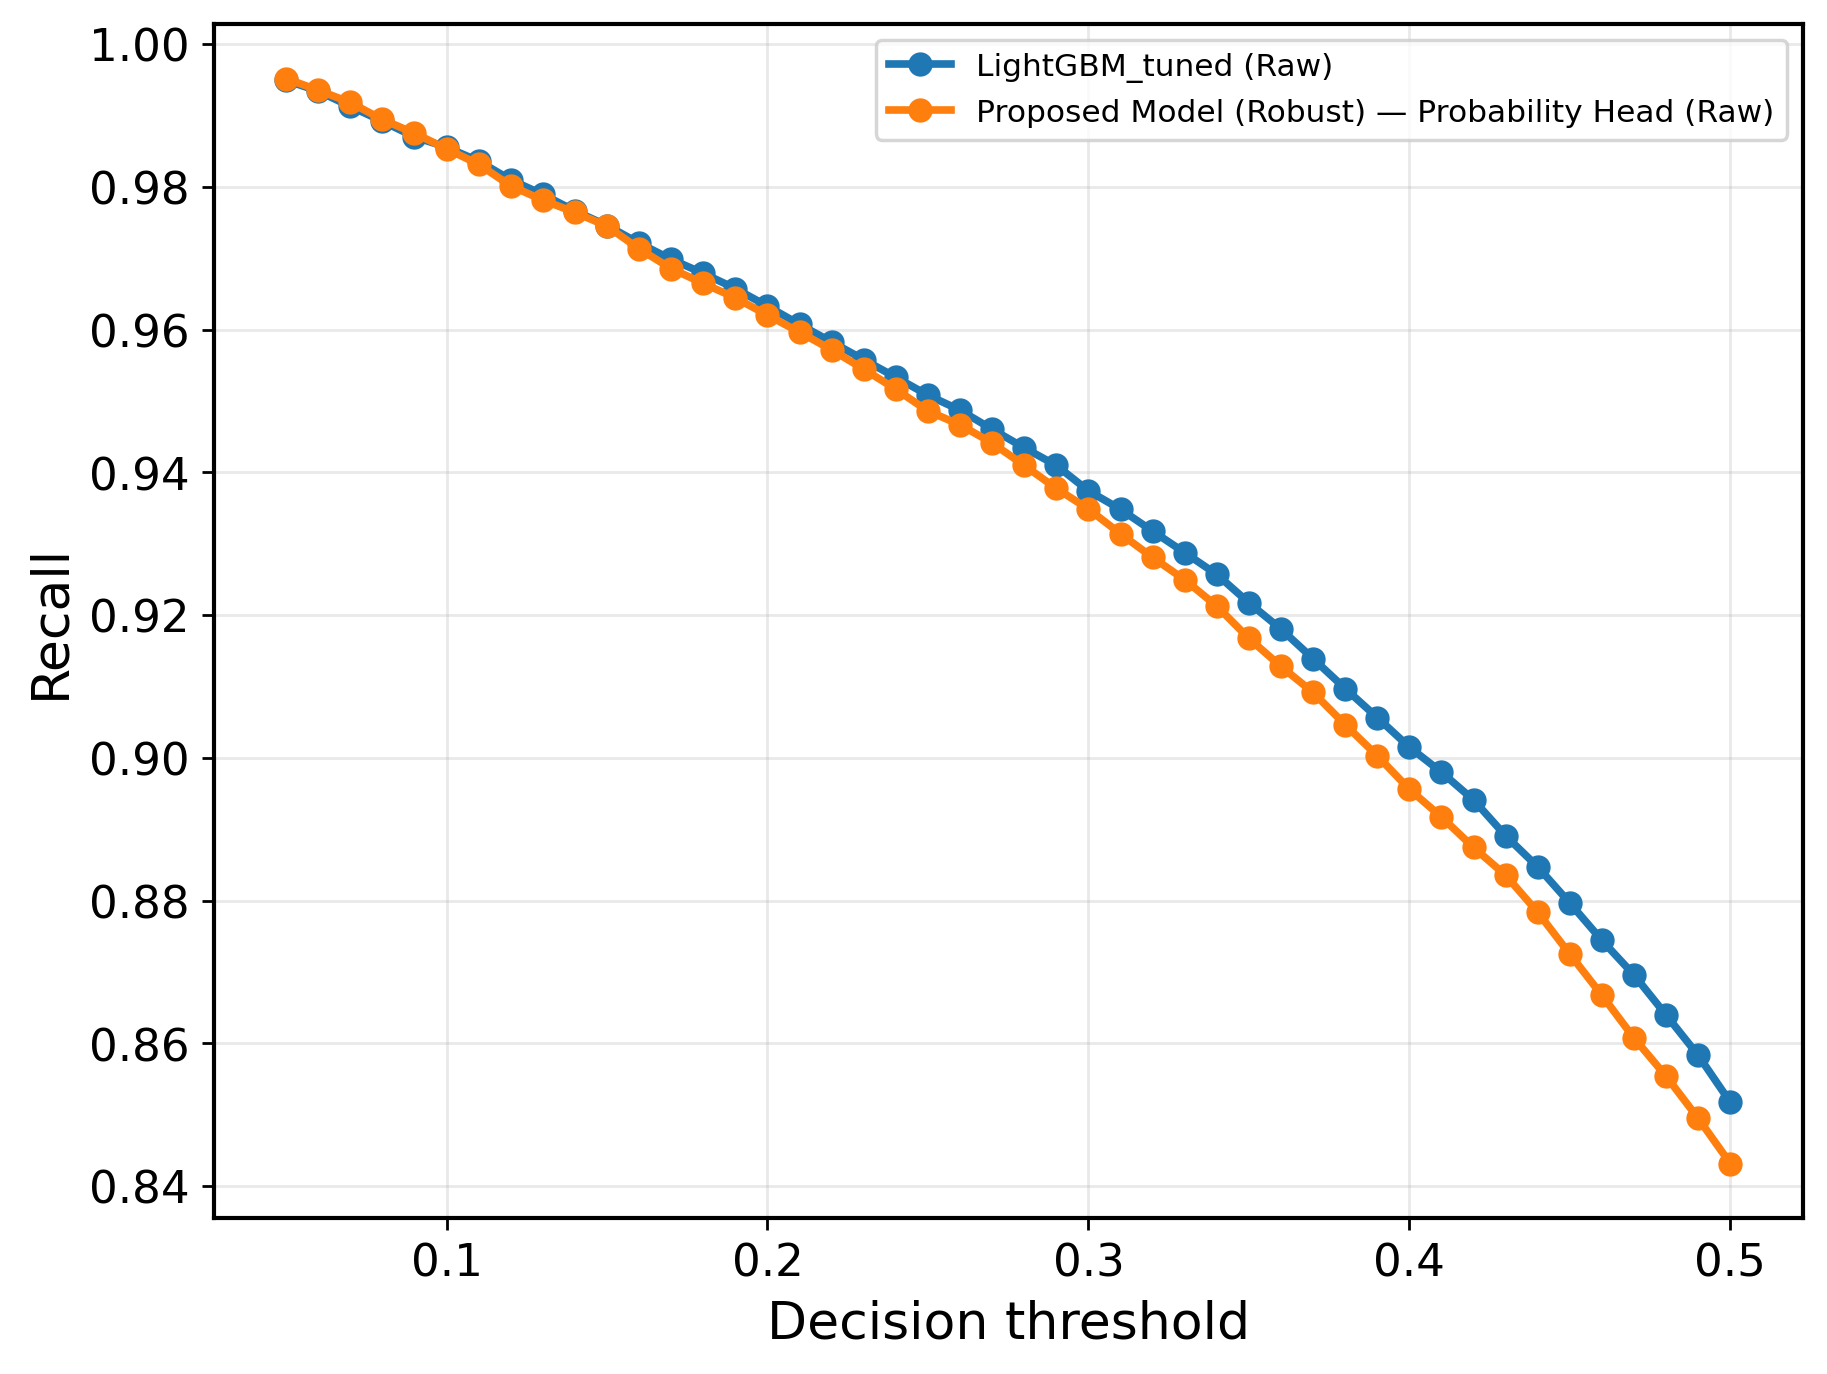

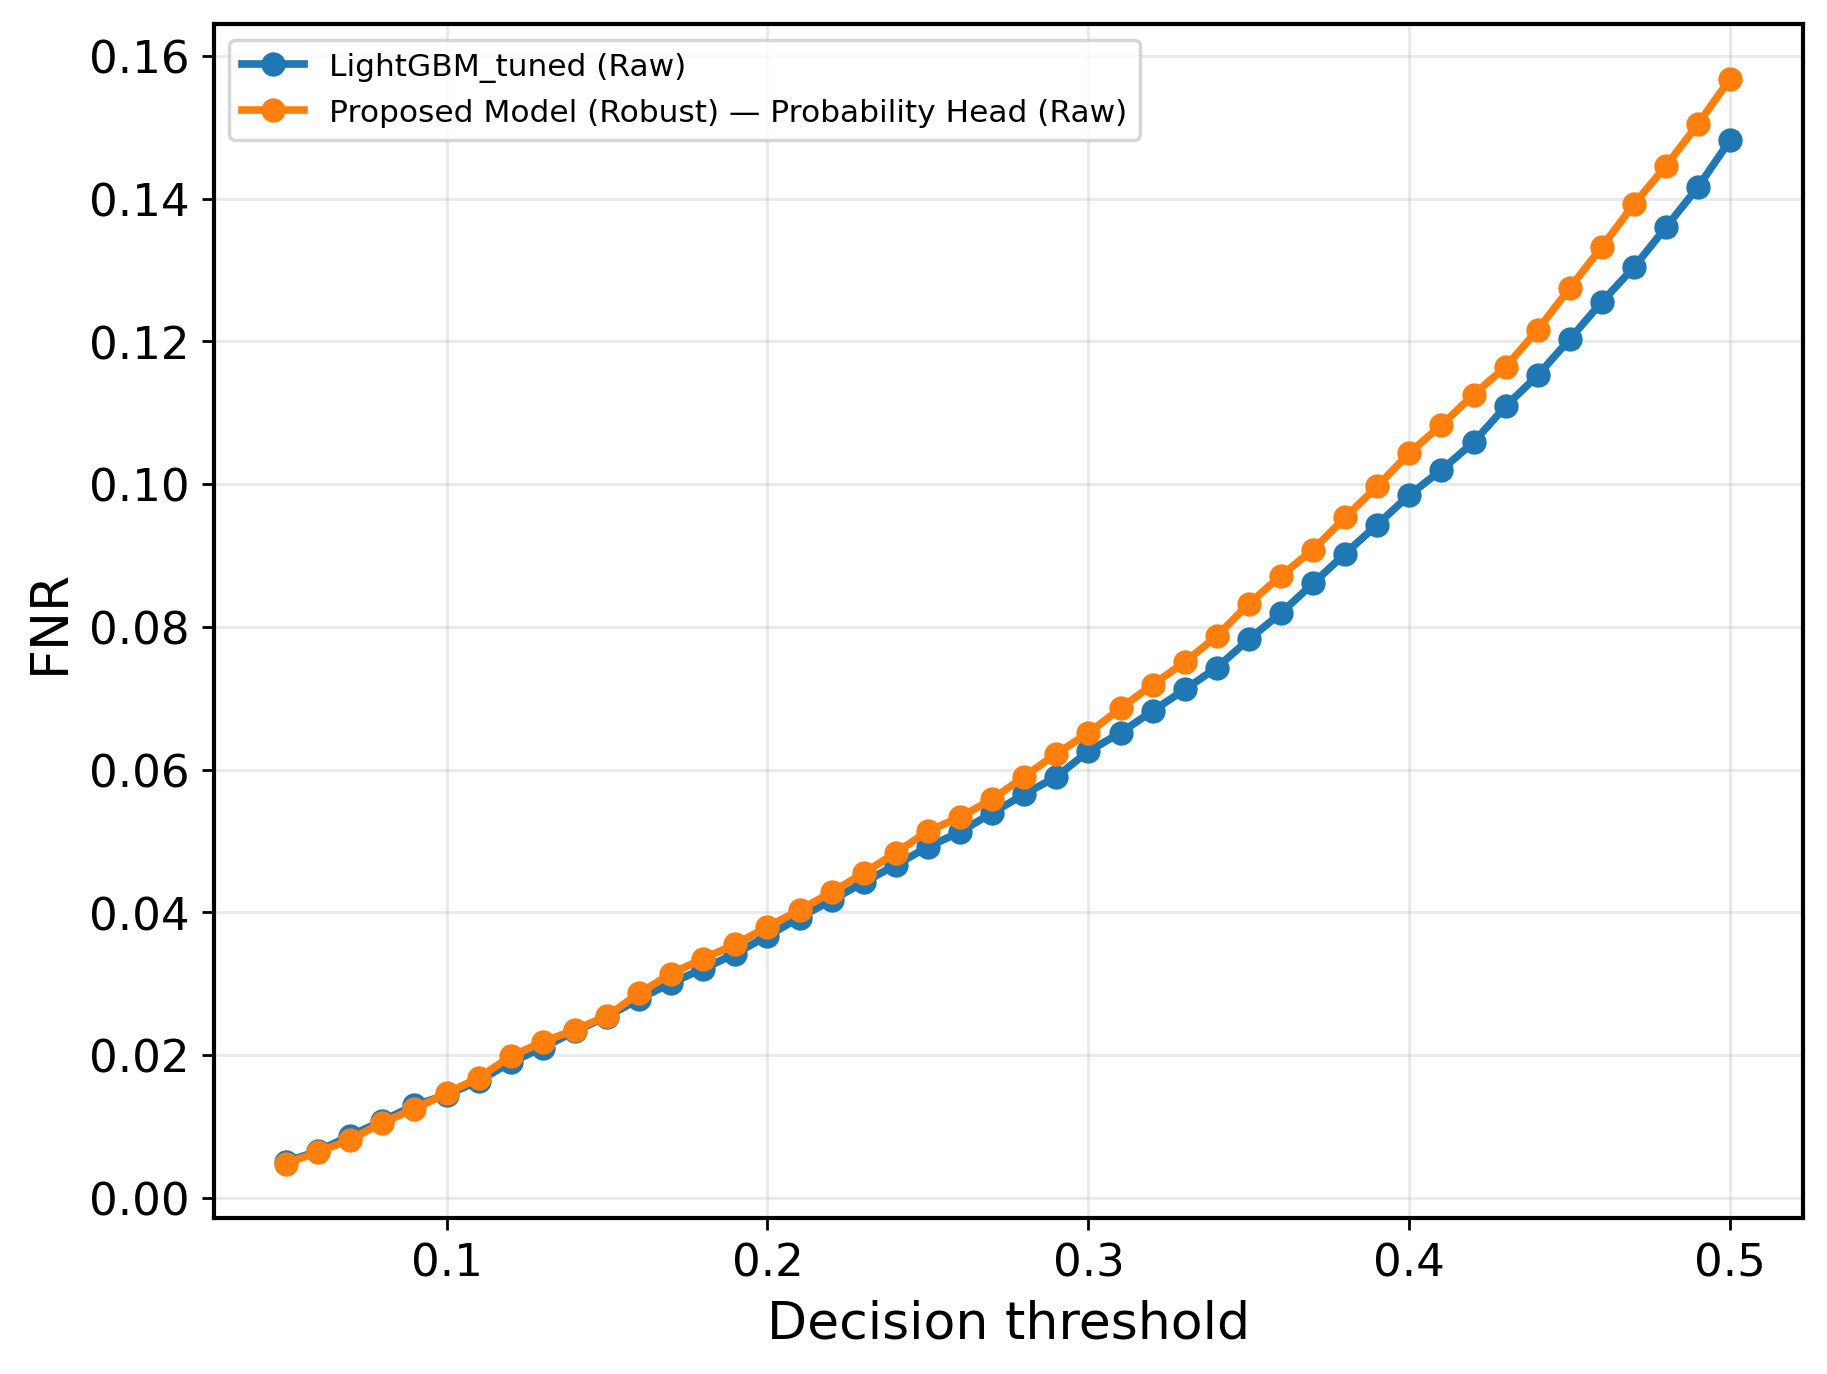

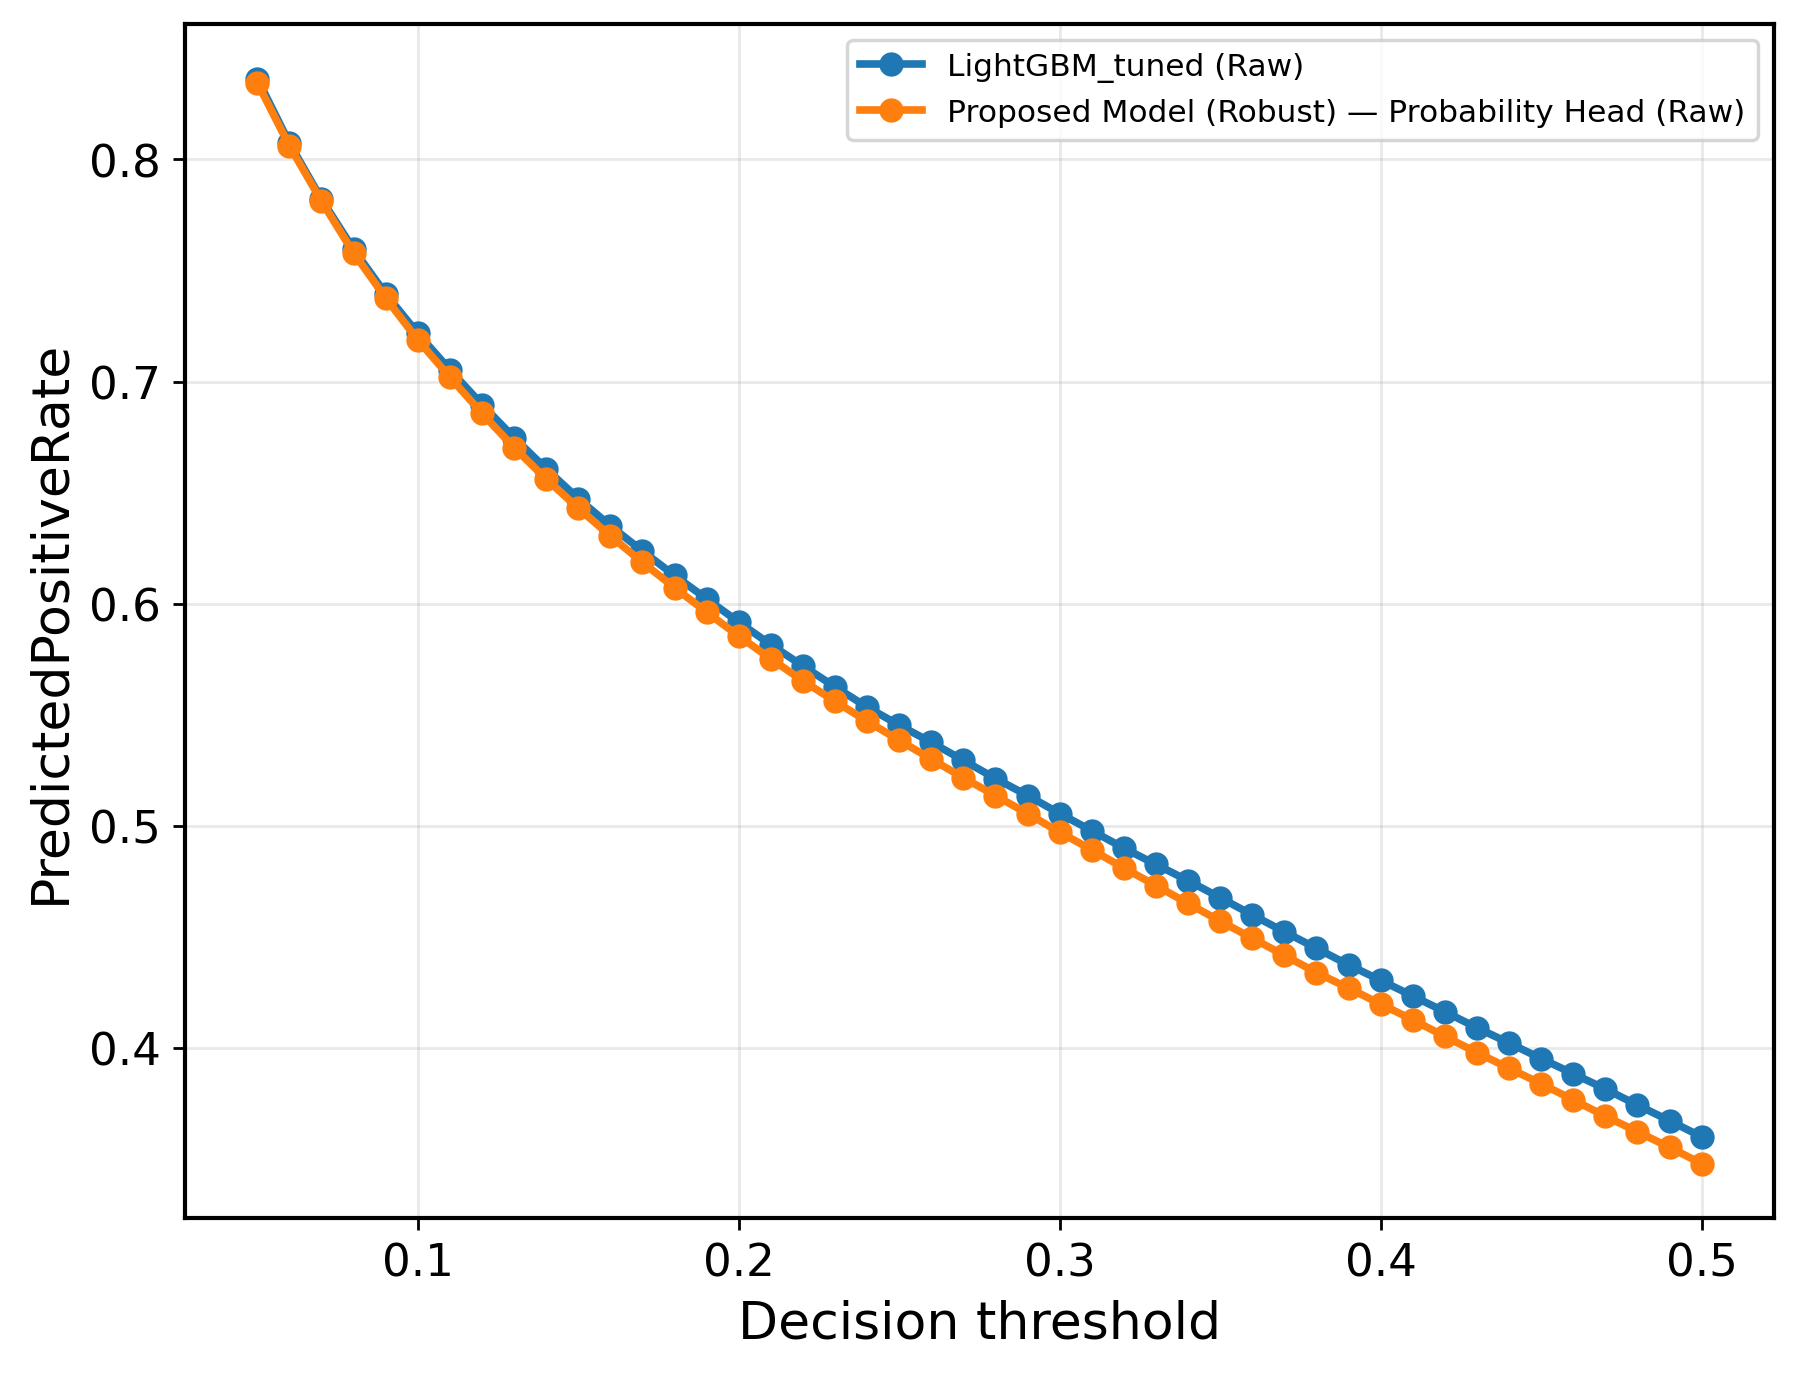


Module 17 manuscript-ready summary:
                                     proposed_model  mean_F1_0.10_0.50  \
0  Proposed Model (Robust) — Probability Head (Raw)           0.296893   

   range_F1_0.10_0.50  mean_Recall_0.10_0.50  mean_FNR_0.10_0.50  \
0            0.130881                0.92734             0.07266   

   delta_mean_F1_vs_LightGBM  delta_mean_Recall_vs_LightGBM  \
0                   0.003341                      -0.003644   

   delta_mean_FNR_vs_LightGBM  
0                    0.003644  

Module 17 complete.
Saved threshold stability tables and paper-ready figures.


In [7]:
# ============================================================
# Module 17 — Threshold stability and clinical operating-point sensitivity
# Purpose:
#   Show that the Proposed Model remains clinically useful across
#   a range of decision thresholds, rather than only at a single
#   chosen operating point.
#
# Compared models:
#   - LightGBM_tuned (Raw)
#   - Proposed Model — Probability Head (Robust)
#
# Outputs:
#   - threshold-wise performance table
#   - threshold sensitivity summary
#   - paper-ready threshold stability plots
#
# Important figure rule:
#   - no titles inside saved images
# ============================================================

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "y_all",
    "TAB_DIR",
    "FIG_DIR",
    "save_figure_multi",
    "clip_probs",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 17: {missing_vars}")

# Resolve predictions from current notebook state
if "p_lgb" in globals():
    p_lgb_m17 = clip_probs(p_lgb)
elif "p_lgb_m5b" in globals():
    p_lgb_m17 = clip_probs(p_lgb_m5b)
elif "oof_lgb_tuned" in globals():
    p_lgb_m17 = clip_probs(oof_lgb_tuned)
else:
    raise ValueError("Could not find LightGBM prediction vector for Module 17.")

if "p_prob_final_pm" in globals():
    p_prop_m17 = clip_probs(p_prob_final_pm)
    proposed_model_name_m17 = globals().get("final_prob_model_name", "Proposed Model — Final Probability Head")
elif "p_prob_raw_pm_robust" in globals():
    p_prop_m17 = clip_probs(p_prob_raw_pm_robust)
    proposed_model_name_m17 = "Proposed Model (Robust) — Probability Head (Raw)"
elif "p_prob_raw_pm" in globals():
    p_prop_m17 = clip_probs(p_prob_raw_pm)
    proposed_model_name_m17 = "Proposed Model — Probability Head (Raw)"
else:
    raise ValueError("Could not find Proposed Model probability head prediction vector for Module 17.")

# -------------------------
# Imports
# -------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
)

# -------------------------
# Helpers
# -------------------------
def threshold_eval(y_true, p, thr):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)
    pred = (p >= thr).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()

    precision = precision_score(y_true, pred, zero_division=0)
    recall = recall_score(y_true, pred, zero_division=0)
    f1 = f1_score(y_true, pred, zero_division=0)
    acc = accuracy_score(y_true, pred)
    bal_acc = balanced_accuracy_score(y_true, pred)
    mcc = matthews_corrcoef(y_true, pred) if len(np.unique(pred)) > 1 else 0.0

    specificity = tn / max(tn + fp, 1)
    fnr = fn / max(fn + tp, 1)
    fpr = fp / max(fp + tn, 1)
    pred_pos_rate = pred.mean()

    return {
        "threshold": float(thr),
        "Precision": float(precision),
        "Recall": float(recall),
        "Specificity": float(specificity),
        "F1": float(f1),
        "Accuracy": float(acc),
        "BalancedAccuracy": float(bal_acc),
        "MCC": float(mcc),
        "FNR": float(fnr),
        "FPR": float(fpr),
        "PredictedPositiveRate": float(pred_pos_rate),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
    }

def build_threshold_curve(y_true, pred_dict, thresholds):
    rows = []
    for model_name, p in pred_dict.items():
        for thr in thresholds:
            row = threshold_eval(y_true, p, thr)
            row["model"] = model_name
            rows.append(row)
    return pd.DataFrame(rows)

def summarize_threshold_stability(df_long, thr_min=0.10, thr_max=0.50):
    keep = df_long[(df_long["threshold"] >= thr_min) & (df_long["threshold"] <= thr_max)].copy()

    rows = []
    for model_name, g in keep.groupby("model"):
        rows.append({
            "model": model_name,
            "mean_F1": float(g["F1"].mean()),
            "std_F1": float(g["F1"].std(ddof=1)),
            "max_F1": float(g["F1"].max()),
            "min_F1": float(g["F1"].min()),
            "range_F1": float(g["F1"].max() - g["F1"].min()),
            "mean_Precision": float(g["Precision"].mean()),
            "mean_Recall": float(g["Recall"].mean()),
            "mean_FNR": float(g["FNR"].mean()),
            "mean_FPR": float(g["FPR"].mean()),
            "mean_PredictedPositiveRate": float(g["PredictedPositiveRate"].mean()),
        })
    return pd.DataFrame(rows).sort_values("mean_F1", ascending=False).reset_index(drop=True)

def pick_representative_thresholds(df_long, model_name):
    g = df_long[df_long["model"] == model_name].copy().sort_values("threshold")

    def nearest_row(target_col, target_value, prefer="closest"):
        if prefer == "closest":
            idx = (g[target_col] - target_value).abs().idxmin()
        else:
            idx = g[target_col].idxmax()
        return g.loc[idx].to_dict()

    rows = []

    # Best F1 threshold in scanned set
    idx_best = g["F1"].idxmax()
    r_best = g.loc[idx_best].to_dict()
    r_best["operating_point"] = "BestF1_scanned"
    rows.append(r_best)

    # Precision-oriented
    r_prec = nearest_row("Precision", 0.30, prefer="closest")
    r_prec["operating_point"] = "Precision≈0.30"
    rows.append(r_prec)

    # Recall-oriented
    r_rec = nearest_row("Recall", 0.50, prefer="closest")
    r_rec["operating_point"] = "Recall≈0.50"
    rows.append(r_rec)

    # Conservative higher threshold
    r_cons = nearest_row("threshold", 0.30, prefer="closest")
    r_cons["operating_point"] = "Threshold≈0.30"
    rows.append(r_cons)

    return pd.DataFrame(rows)

def plot_threshold_metric(df_long, metric_col, model_order, save_path_base):
    plt.figure(figsize=(8.2, 6.2))
    for model_name in model_order:
        g = df_long[df_long["model"] == model_name].sort_values("threshold")
        plt.plot(g["threshold"], g[metric_col], marker="o", label=model_name)
    plt.xlabel("Decision threshold")
    plt.ylabel(metric_col)
    plt.legend(frameon=True)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

# -------------------------
# Inputs
# -------------------------
y_m17 = y_all.astype(int)

pred_dict_m17 = {
    "LightGBM_tuned (Raw)": p_lgb_m17,
    proposed_model_name_m17: p_prop_m17,
}

# clinically relevant threshold grid
threshold_grid = np.round(np.arange(0.05, 0.51, 0.01), 2)

# -------------------------
# 17.1 Threshold-wise performance table
# -------------------------
module17_threshold_df = build_threshold_curve(
    y_true=y_m17,
    pred_dict=pred_dict_m17,
    thresholds=threshold_grid,
)
module17_threshold_df.to_csv(TAB_DIR / "module17_threshold_curve_results.csv", index=False)

print("\nModule 17 threshold-wise results preview:")
print(module17_threshold_df.head(20))

# -------------------------
# 17.2 Stability summary
# -------------------------
module17_stability_df = summarize_threshold_stability(
    module17_threshold_df,
    thr_min=0.10,
    thr_max=0.50,
)
module17_stability_df.to_csv(TAB_DIR / "module17_threshold_stability_summary.csv", index=False)

print("\nModule 17 threshold stability summary:")
print(module17_stability_df)

# -------------------------
# 17.3 Representative operating points for the Proposed Model
# -------------------------
module17_operating_points_df = pick_representative_thresholds(
    module17_threshold_df,
    model_name=proposed_model_name_m17,
)
module17_operating_points_df.to_csv(TAB_DIR / "module17_proposed_model_operating_points.csv", index=False)

print("\nRepresentative operating points for the Proposed Model:")
print(module17_operating_points_df)

# -------------------------
# 17.4 Paper-quality figures without titles
# -------------------------
model_order_m17 = ["LightGBM_tuned (Raw)", proposed_model_name_m17]

plot_threshold_metric(
    module17_threshold_df,
    metric_col="F1",
    model_order=model_order_m17,
    save_path_base=FIG_DIR / "module17_threshold_stability_f1",
)

plot_threshold_metric(
    module17_threshold_df,
    metric_col="Precision",
    model_order=model_order_m17,
    save_path_base=FIG_DIR / "module17_threshold_stability_precision",
)

plot_threshold_metric(
    module17_threshold_df,
    metric_col="Recall",
    model_order=model_order_m17,
    save_path_base=FIG_DIR / "module17_threshold_stability_recall",
)

plot_threshold_metric(
    module17_threshold_df,
    metric_col="FNR",
    model_order=model_order_m17,
    save_path_base=FIG_DIR / "module17_threshold_stability_fnr",
)

plot_threshold_metric(
    module17_threshold_df,
    metric_col="PredictedPositiveRate",
    model_order=model_order_m17,
    save_path_base=FIG_DIR / "module17_threshold_stability_predicted_positive_rate",
)

# -------------------------
# 17.5 Compact manuscript summary
# -------------------------
prop_stab = module17_stability_df[module17_stability_df["model"] == proposed_model_name_m17].iloc[0]
lgb_stab = module17_stability_df[module17_stability_df["model"] == "LightGBM_tuned (Raw)"].iloc[0]

module17_manuscript_summary_df = pd.DataFrame([{
    "proposed_model": proposed_model_name_m17,
    "mean_F1_0.10_0.50": float(prop_stab["mean_F1"]),
    "range_F1_0.10_0.50": float(prop_stab["range_F1"]),
    "mean_Recall_0.10_0.50": float(prop_stab["mean_Recall"]),
    "mean_FNR_0.10_0.50": float(prop_stab["mean_FNR"]),
    "delta_mean_F1_vs_LightGBM": float(prop_stab["mean_F1"] - lgb_stab["mean_F1"]),
    "delta_mean_Recall_vs_LightGBM": float(prop_stab["mean_Recall"] - lgb_stab["mean_Recall"]),
    "delta_mean_FNR_vs_LightGBM": float(prop_stab["mean_FNR"] - lgb_stab["mean_FNR"]),
}])
module17_manuscript_summary_df.to_csv(TAB_DIR / "module17_manuscript_summary.csv", index=False)

print("\nModule 17 manuscript-ready summary:")
print(module17_manuscript_summary_df)

print("\nModule 17 complete.")
print("Saved threshold stability tables and paper-ready figures.")

Loaded external dataset from: local_csv::/kaggle/input/datasets/thisishusseinali/uci-heart-disease-data/heart_disease_data.csv
External raw shape: (606, 13)

External alignment summary:
   n_external_rows  n_external_columns  n_brfss_features_total  \
0              606                  13                      21   

   n_mapped_or_approximated_features  \
0                                  7   

                     mapped_or_approximated_features  \
0  Age, Sex, HighBP, HighChol, Diabetes, PhysActi...   

                                external_raw_columns  \
0  age, sex, cp, trestbps, chol, fbs, restecg, th...   

                                              source  
0  local_csv::/kaggle/input/datasets/thisishussei...  
Deep model external refit epoch 01 | loss=0.85021
Deep model external refit epoch 02 | loss=0.78592
Deep model external refit epoch 03 | loss=0.76794
Deep model external refit epoch 04 | loss=0.76312
Deep model external refit epoch 05 | loss=0.75893
Deep model ext

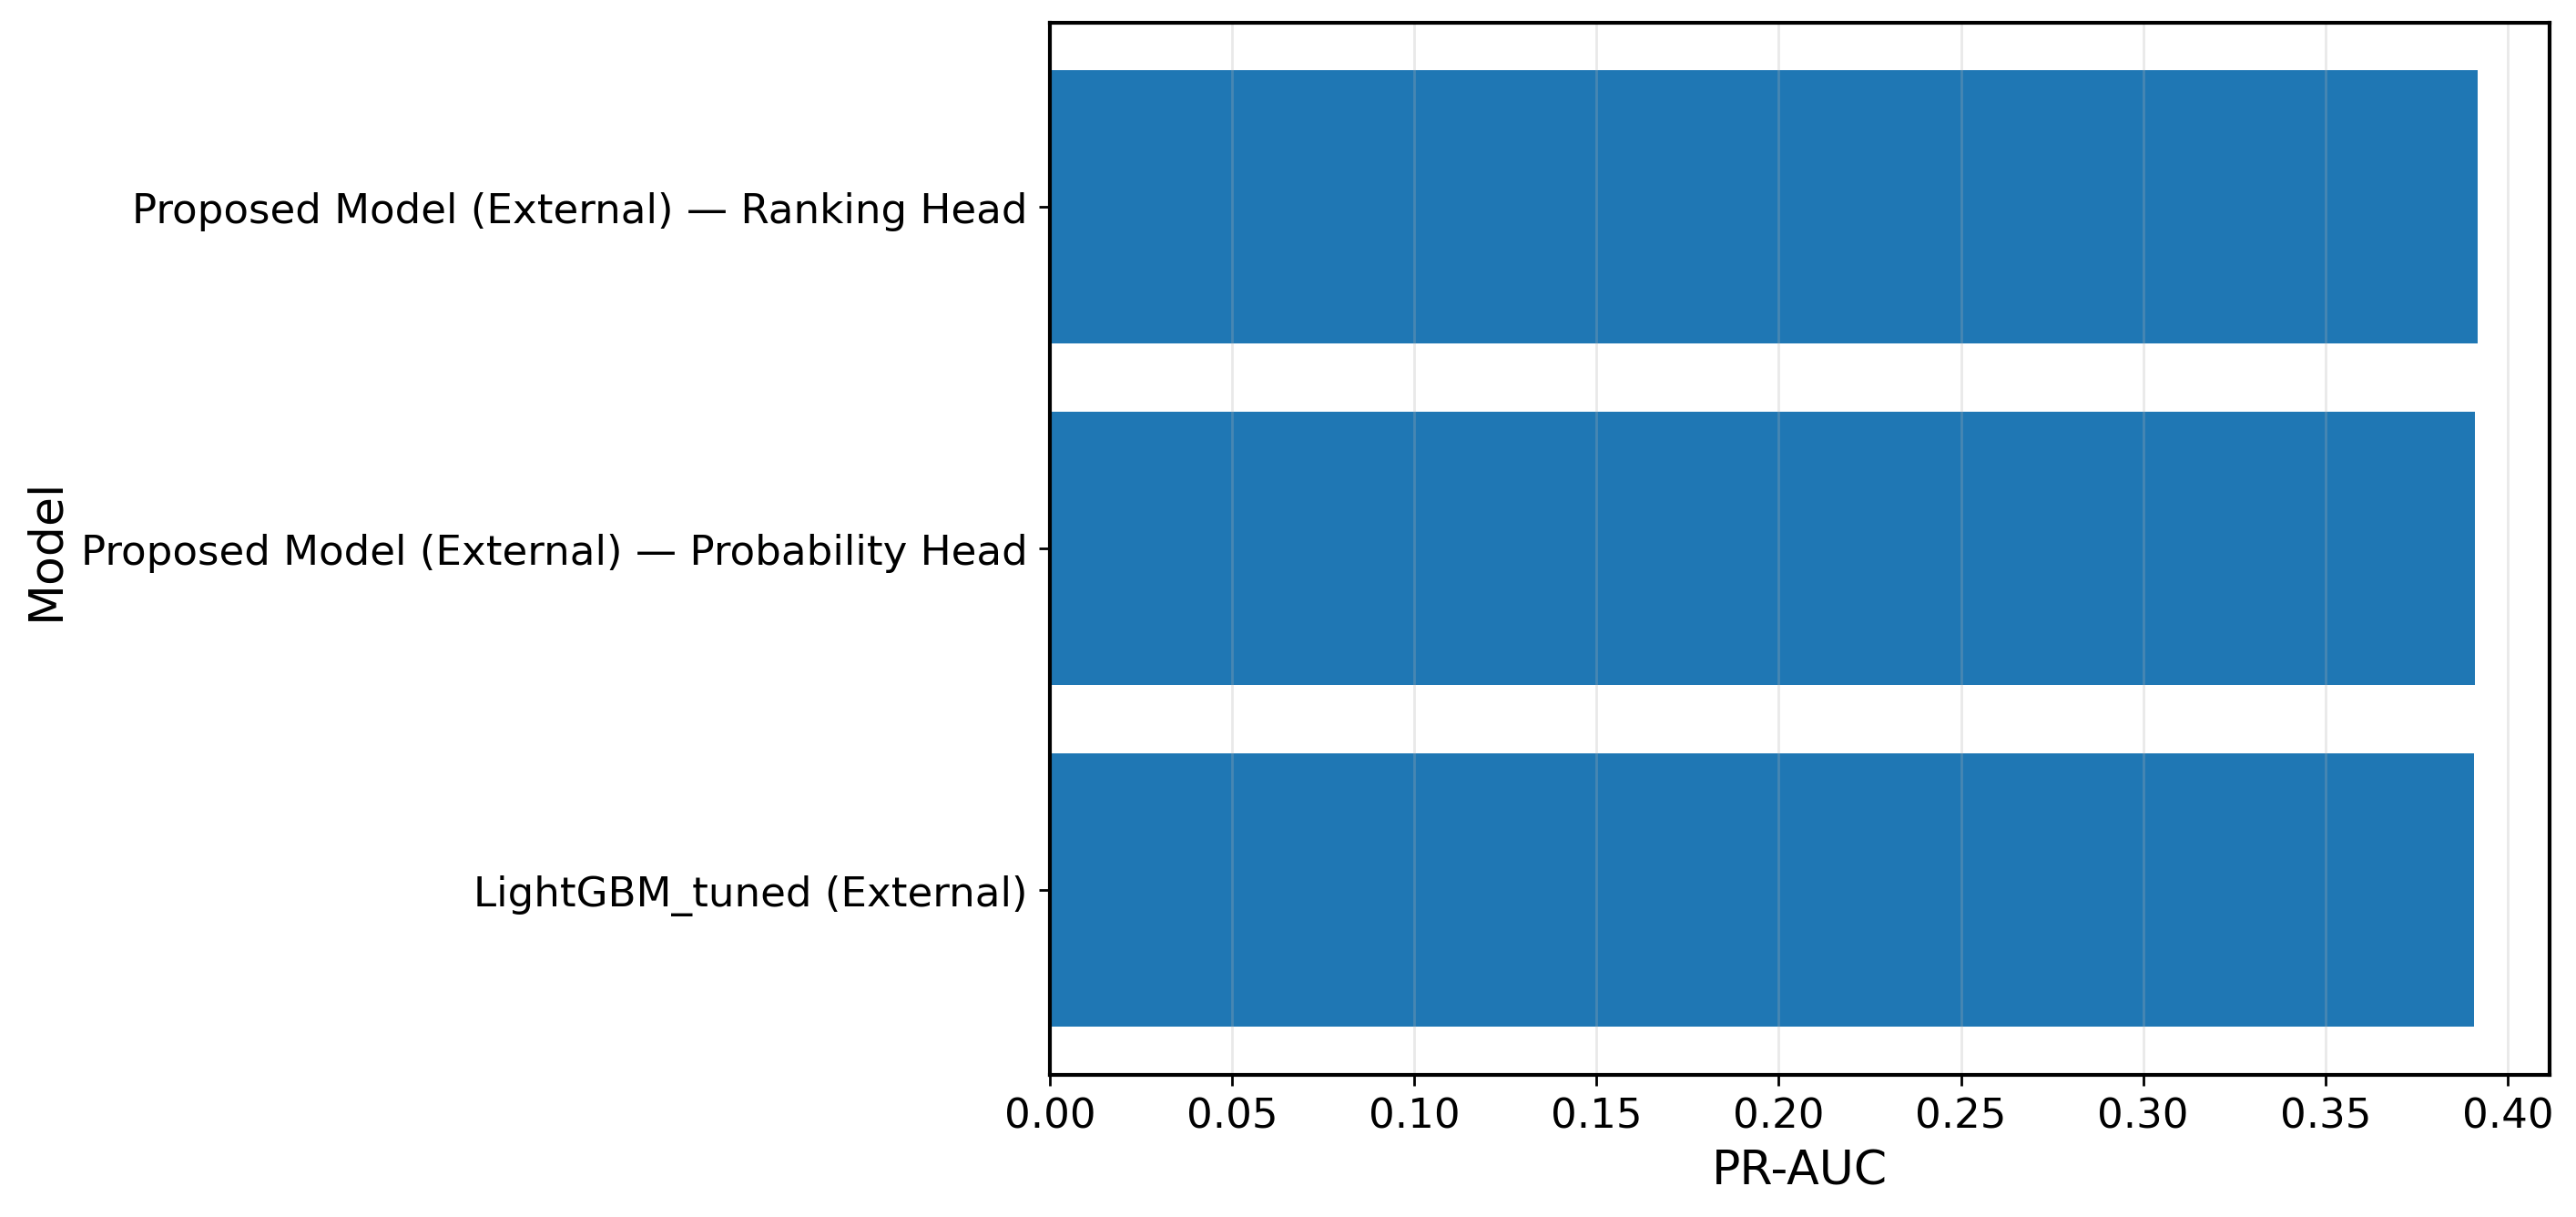

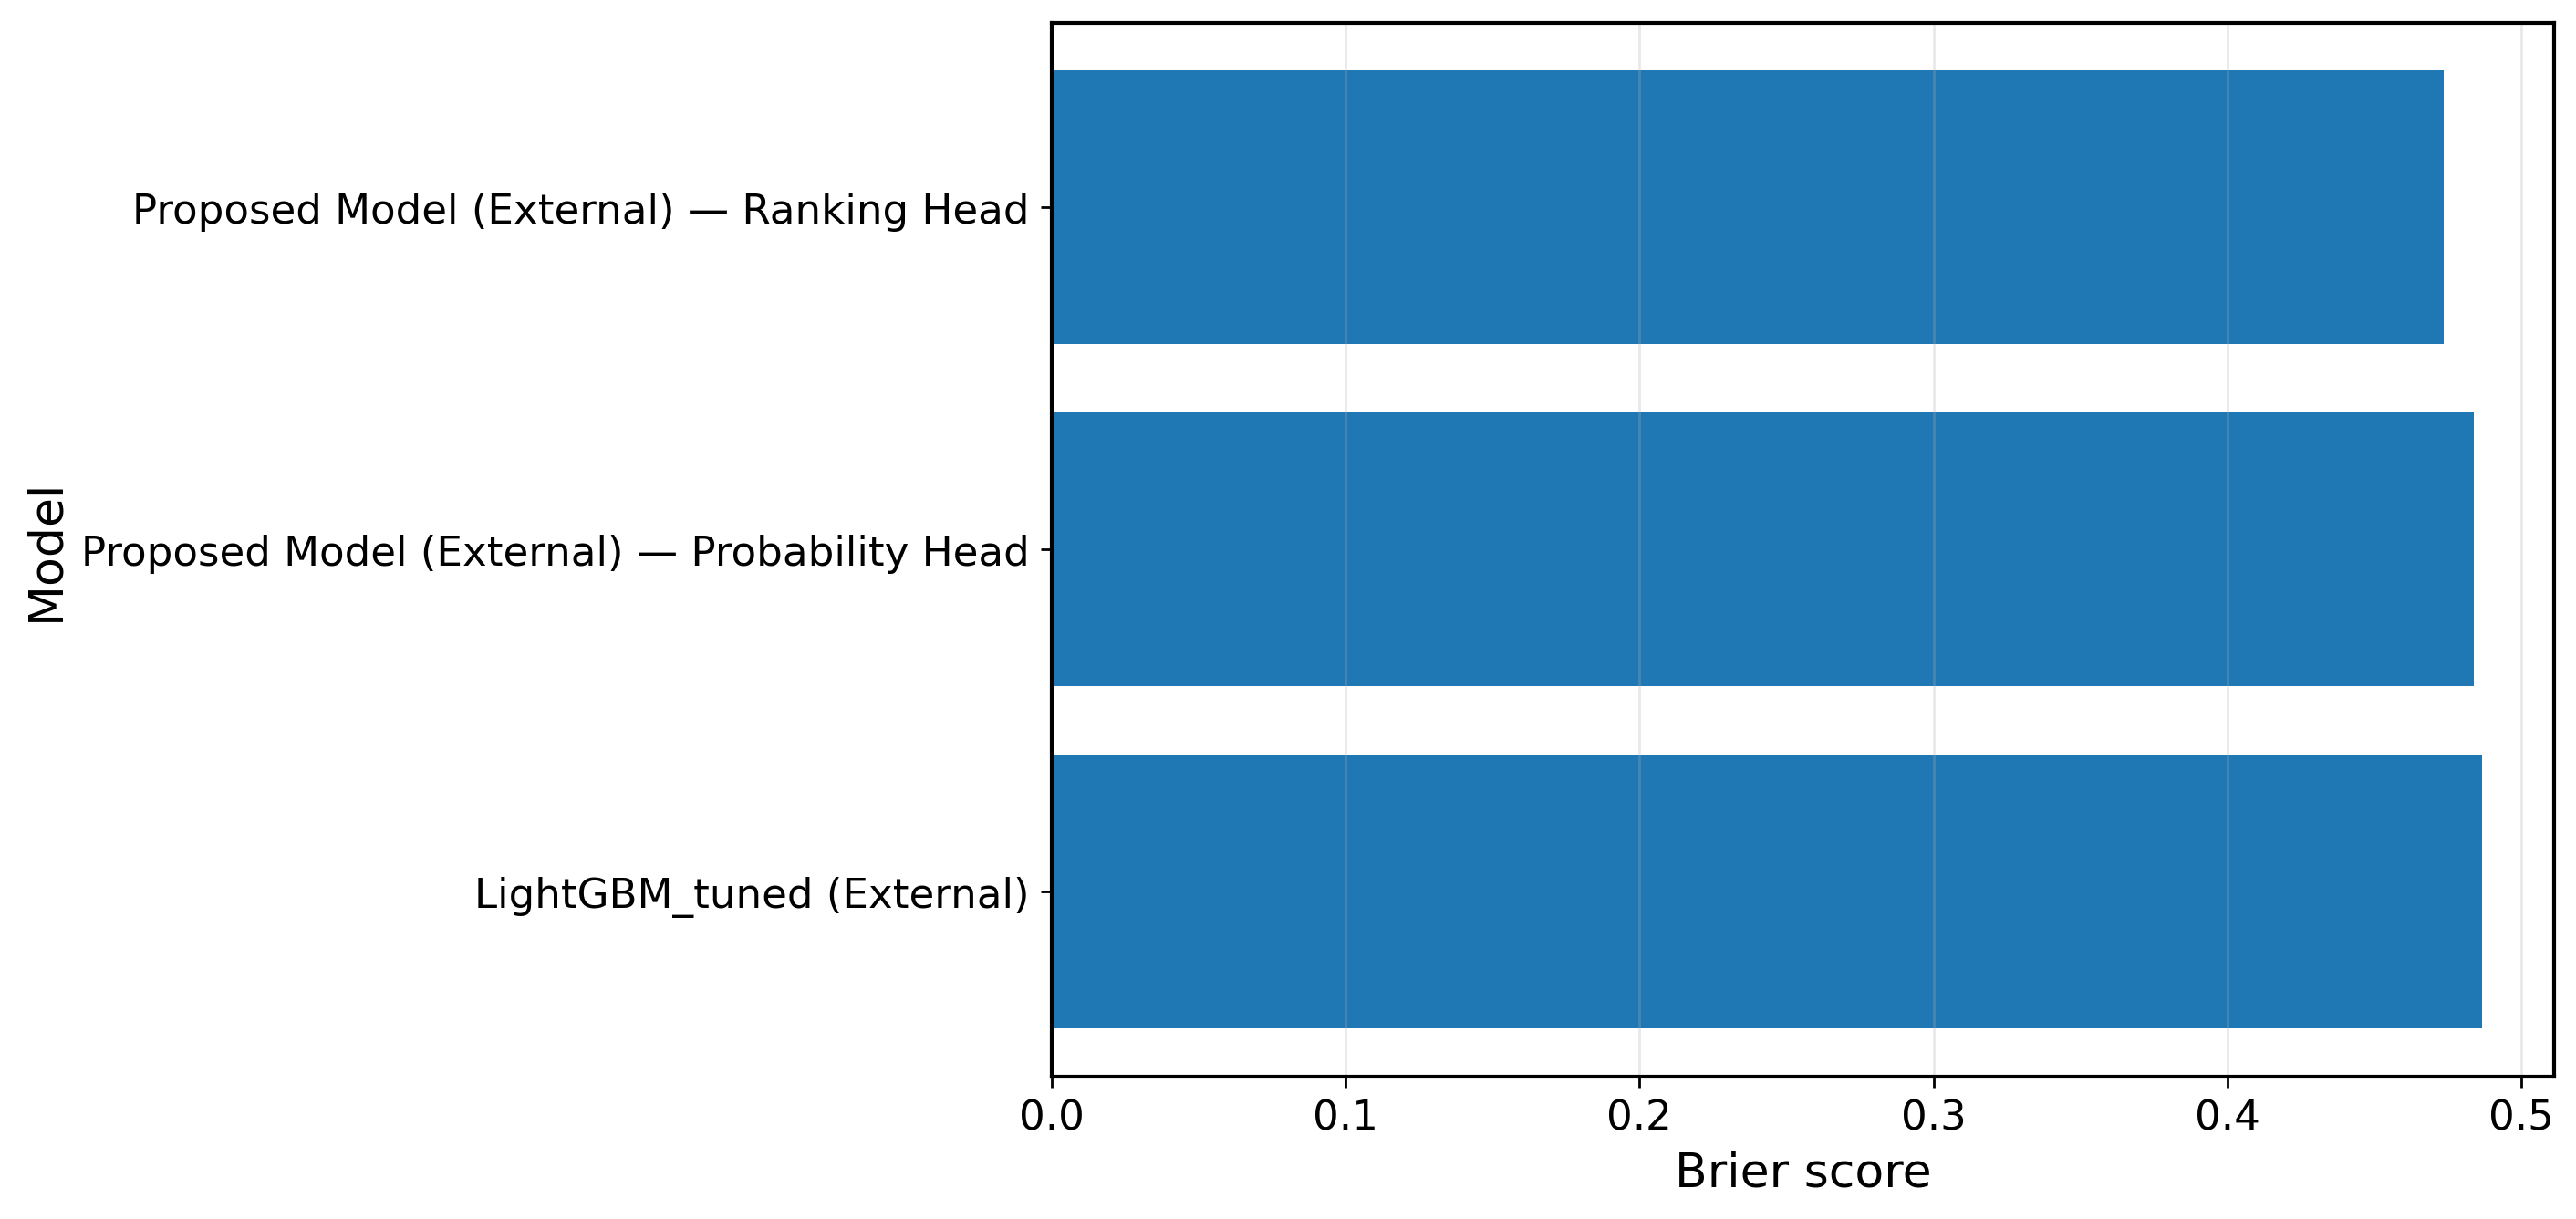

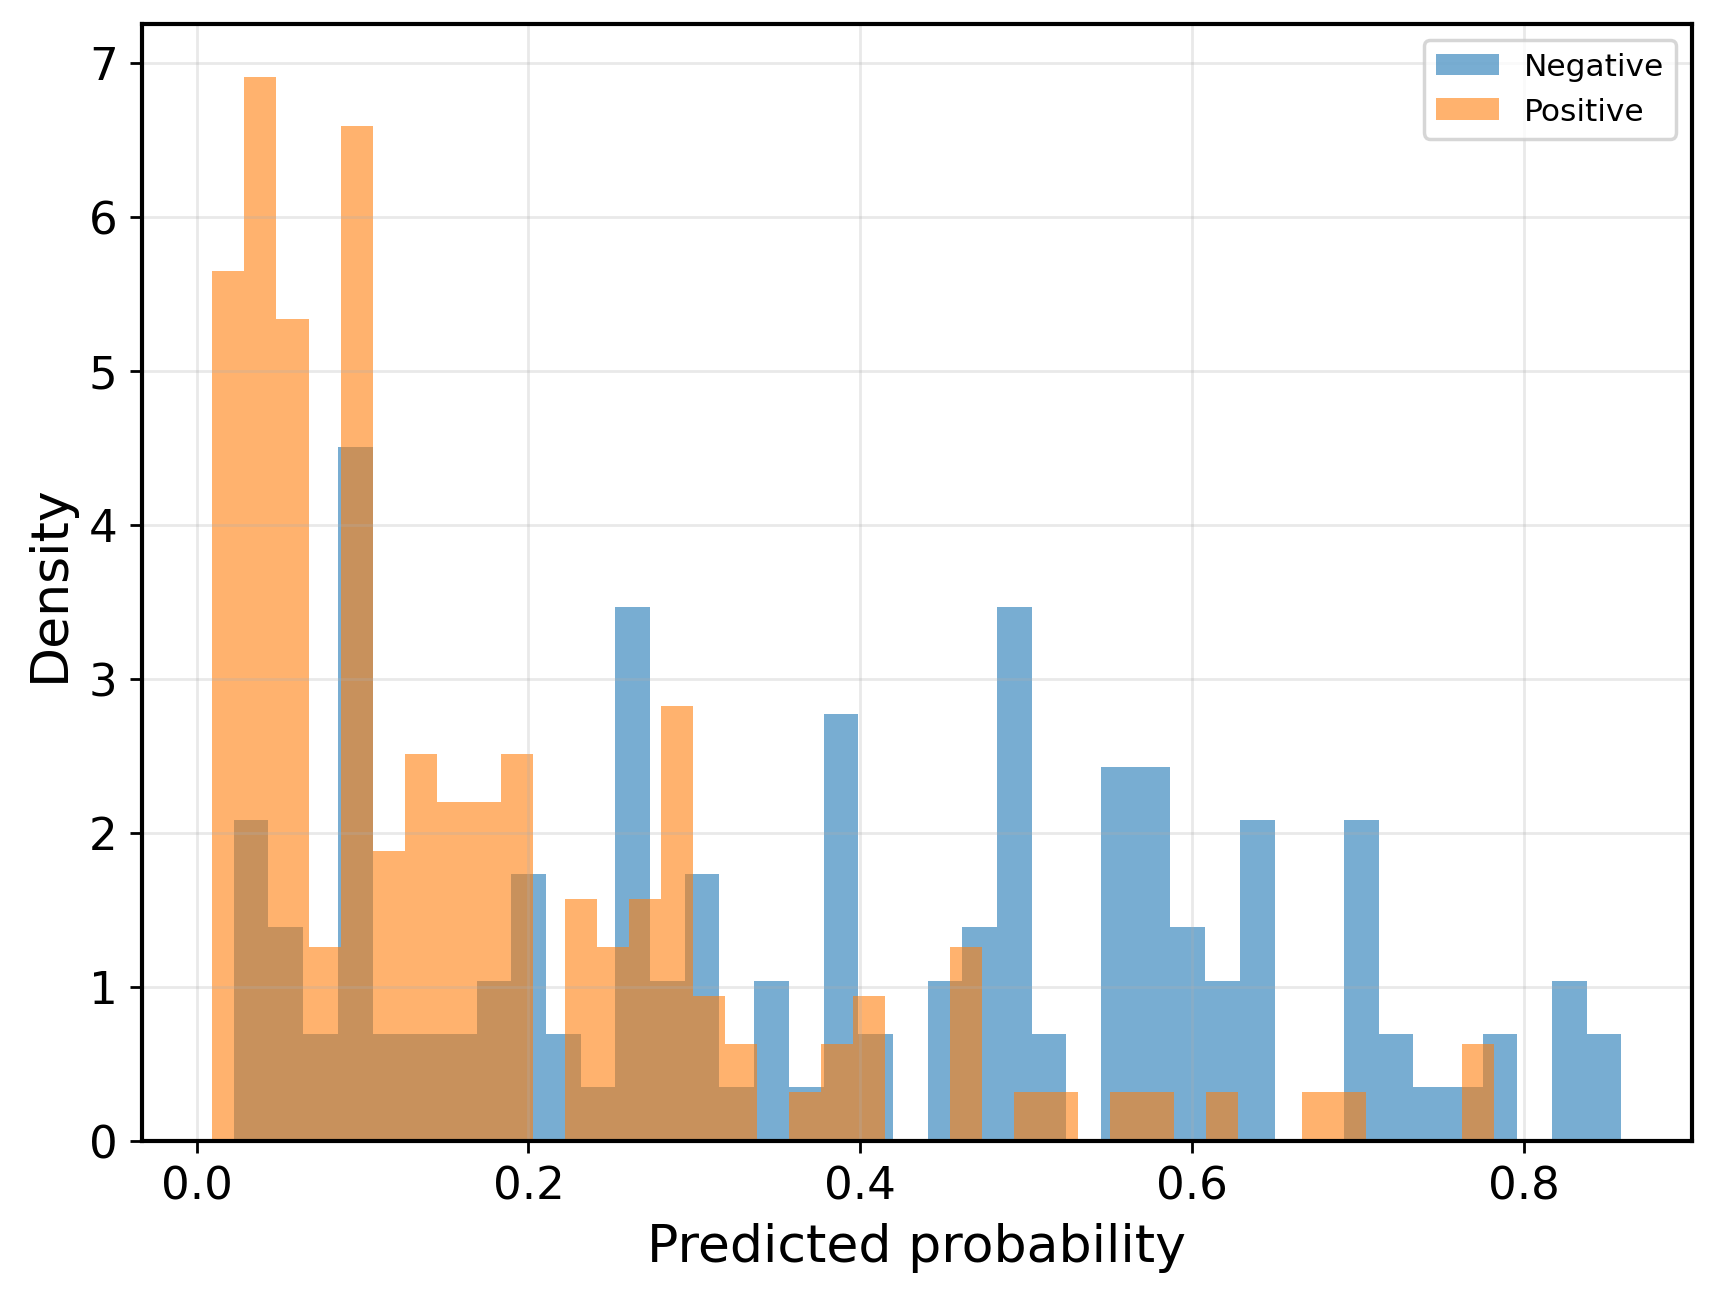


Module 18 manuscript summary:
                                     external_source  \
0  local_csv::/kaggle/input/datasets/thisishussei...   

                        best_external_model  best_external_PR_AUC  \
0  Proposed Model (External) — Ranking Head              0.391883   

   best_external_ROC_AUC  best_external_Brier  best_external_ECE  \
0               0.215393             0.473519           0.462945   

                                     validation_note  
0  External validation performed under partial fe...  

Module 18 complete.
Saved partial-alignment external validation outputs.


In [9]:
# ============================================================
# Module 18 — External dataset validation
# Purpose:
#   Evaluate the Proposed Model on an independent external cohort
#   using partial feature alignment.
#
# External cohort options:
#   - UCI Heart Disease / Cleveland-style processed CSV
#   - Statlog Heart CSV
#   - ucimlrepo fetch fallback
#
# Important note:
#   Because BRFSS and UCI/Statlog use different schemas, this module
#   performs external validation under partial feature alignment:
#     1) map overlapping variables
#     2) fill unavailable BRFSS-only fields with reference defaults
#     3) run inference using the current final model components
#
# Outputs:
#   - module18_external_eval_summary.csv
#   - module18_external_prediction_table.csv
#   - paper-ready plots
#
# Important figure rule:
#   - no titles inside saved images
# ============================================================

# -------------------------
# Safety checks
# -------------------------
required_vars = [
    "FEATURES",
    "BINARY_COLS",
    "ORDINAL_COLS",
    "CONT_COLS",
    "X_all",
    "y_all",
    "TAB_DIR",
    "FIG_DIR",
    "save_figure_multi",
    "clip_probs",
    "evaluate_probs",
]
missing_vars = [v for v in required_vars if v not in globals()]
if len(missing_vars) > 0:
    raise ValueError(f"Missing required variables for Module 18: {missing_vars}")

# Need current model artifacts
# Robust/current branch preferred
if "oof_lgb_tuned" in globals():
    pass
elif "p_lgb_m5b" in globals():
    pass
else:
    raise ValueError("Module 18 needs LightGBM artifacts already available in the notebook.")

# -------------------------
# Imports
# -------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Optional imports
HAS_UCIREPO = False
try:
    from ucimlrepo import fetch_ucirepo
    HAS_UCIREPO = True
except Exception:
    HAS_UCIREPO = False

try:
    import lightgbm as lgb
    import xgboost as xgb
except Exception as e:
    raise ValueError(f"LightGBM/XGBoost import failed: {e}")

import torch
from torch.utils.data import DataLoader, Dataset

# -------------------------
# Config
# -------------------------
# User can place a CSV locally and point here.
EXTERNAL_CSV_CANDIDATES = [
    "/kaggle/input/datasets/thisishusseinali/uci-heart-disease-data/heart_disease_data.csv",
    "/kaggle/input/heart-disease/processed.cleveland.data",
    "/kaggle/input/statlog-heart/statlog_heart.csv",
    "/kaggle/input/statlog-heart/heart.dat",
]

# Which external source to prefer if multiple succeed
PREFER_SOURCE = "local_csv"   # or "ucimlrepo"

# -------------------------
# Helpers
# -------------------------
class ExternalTensorDataset(Dataset):
    def __init__(self, X):
        self.X = torch.tensor(X, dtype=torch.float32)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx]

@torch.no_grad()
def predict_proba_deepfm_external(model, X_array, batch_size=4096):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)
    model.eval()

    ds = ExternalTensorDataset(X_array.astype(np.float32))
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=(device == "cuda"))

    preds = []
    for xb in loader:
        xb = xb.to(device, non_blocking=True)
        logits = model(xb)
        p = torch.sigmoid(logits).detach().cpu().numpy()
        preds.append(p)

    return clip_probs(np.concatenate(preds))

def find_external_csv(candidates):
    for p in candidates:
        if os.path.exists(p):
            return p
    return None

def load_external_dataset():
    """
    Returns:
      df_ext_raw, target_series, source_name
    """
    # ---------------------
    # Option A: local CSV
    # ---------------------
    csv_path = find_external_csv(EXTERNAL_CSV_CANDIDATES)
    if csv_path is not None and PREFER_SOURCE == "local_csv":
        df = pd.read_csv(csv_path, header=None if csv_path.endswith(".data") or csv_path.endswith(".dat") else "infer")
        y = None

        # Heuristics for common UCI formats
        # Processed Cleveland / Statlog typically have 14 cols incl target
        if df.shape[1] == 14:
            cols = [
                "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
            ]
            df.columns = cols
            y = (pd.to_numeric(df["target"], errors="coerce") > 0).astype(int)
            df = df.drop(columns=["target"])
        elif "target" in df.columns:
            y = (pd.to_numeric(df["target"], errors="coerce") > 0).astype(int)
            df = df.drop(columns=["target"])
        elif "cardio" in df.columns:
            y = pd.to_numeric(df["cardio"], errors="coerce").astype(int)
            df = df.drop(columns=["cardio"])
        else:
            raise ValueError(f"Loaded external CSV from {csv_path}, but could not identify target column.")

        return df.reset_index(drop=True), y.reset_index(drop=True), f"local_csv::{csv_path}"

    # ---------------------
    # Option B: ucimlrepo
    # ---------------------
    if HAS_UCIREPO:
        # Try UCI Heart Disease first (id=45), then Statlog Heart (id=145 if available in current mirror)
        tried = []
        for dataset_id, name in [(45, "uci_heart_disease"), (145, "statlog_heart")]:
            try:
                ds = fetch_ucirepo(id=dataset_id)
                X = ds.data.features.copy()
                y = ds.data.targets.copy()

                if isinstance(y, pd.DataFrame):
                    y = y.iloc[:, 0]

                y = pd.to_numeric(y, errors="coerce")
                y = (y > 0).astype(int)

                return X.reset_index(drop=True), y.reset_index(drop=True), f"ucimlrepo::{name}"
            except Exception as e:
                tried.append((dataset_id, str(e)))

        raise ValueError(f"Could not load external dataset via ucimlrepo. Tried: {tried}")

    raise ValueError(
        "No external dataset source found. "
        "Provide a local CSV in EXTERNAL_CSV_CANDIDATES or install/use ucimlrepo."
    )

def build_reference_fill_values(X_ref):
    """
    Build BRFSS reference defaults for unavailable external features.
    """
    X_ref = X_ref.copy()

    fill_map = {}
    for c in FEATURES:
        s = pd.to_numeric(X_ref[c], errors="coerce")
        if c in BINARY_COLS:
            fill_map[c] = float(s.mode(dropna=True).iloc[0]) if s.notna().any() else 0.0
        elif c in ORDINAL_COLS:
            fill_map[c] = float(s.median()) if s.notna().any() else 0.0
        elif c in CONT_COLS:
            fill_map[c] = float(s.median()) if s.notna().any() else 0.0
        else:
            fill_map[c] = float(s.median()) if s.notna().any() else 0.0
    return fill_map

def map_external_to_brfss(df_ext_raw, fill_map):
    """
    Create a BRFSS-compatible dataframe from external features using
    partial alignment. Unavailable features are filled from BRFSS defaults.

    Supported source fields (best effort):
      age, sex, trestbps, chol, fbs, exang, thalach, oldpeak
    """
    df_out = pd.DataFrame(index=np.arange(len(df_ext_raw)))

    # start with defaults
    for c in FEATURES:
        df_out[c] = fill_map[c]

    # normalize ext col names
    ext_cols = {str(c).strip().lower(): c for c in df_ext_raw.columns}

    def ext(name):
        return ext_cols.get(name.lower(), None)

    # ---------------------
    # direct/approximate mappings
    # ---------------------

    # Age
    # BRFSS Age is ordinal bins 1..13. We map raw age to approximate bins.
    if ext("age") is not None and "Age" in FEATURES:
        age_raw = pd.to_numeric(df_ext_raw[ext("age")], errors="coerce")
        age_bins = pd.cut(
            age_raw,
            bins=[0, 24, 29, 34, 39, 44, 49, 54, 59, 64, 69, 74, 79, 200],
            labels=[1,2,3,4,5,6,7,8,9,10,11,12,13],
            include_lowest=True
        )
        df_out["Age"] = pd.to_numeric(age_bins, errors="coerce").fillna(fill_map["Age"])

    # Sex
    if ext("sex") is not None and "Sex" in FEATURES:
        sex_raw = pd.to_numeric(df_ext_raw[ext("sex")], errors="coerce")
        # UCI typically 1=male, 0=female
        df_out["Sex"] = sex_raw.fillna(fill_map["Sex"]).clip(0, 1)

    # HighBP from trestbps
    if ext("trestbps") is not None and "HighBP" in FEATURES:
        bp = pd.to_numeric(df_ext_raw[ext("trestbps")], errors="coerce")
        df_out["HighBP"] = (bp >= 140).astype(float)

    # HighChol from chol
    if ext("chol") is not None and "HighChol" in FEATURES:
        chol = pd.to_numeric(df_ext_raw[ext("chol")], errors="coerce")
        df_out["HighChol"] = (chol >= 240).astype(float)

    # CholCheck unavailable -> keep fill_map default
    # Smoker unavailable in classic UCI -> keep default
    # Stroke unavailable -> keep default

    # Diabetes from fasting blood sugar fbs if available
    if ext("fbs") is not None and "Diabetes" in FEATURES:
        fbs = pd.to_numeric(df_ext_raw[ext("fbs")], errors="coerce")
        # BRFSS Diabetes has multiclass semantics; approximate with 2 (yes) / 0 (no)
        df_out["Diabetes"] = np.where(fbs >= 1, 2.0, 0.0)

    # PhysActivity from exang (exercise-induced angina); crude inverse approximation
    if ext("exang") is not None and "PhysActivity" in FEATURES:
        exang = pd.to_numeric(df_ext_raw[ext("exang")], errors="coerce")
        df_out["PhysActivity"] = np.where(exang >= 1, 0.0, 1.0)

    # GenHlth proxy from oldpeak and exang
    if "GenHlth" in FEATURES:
        oldpeak = pd.to_numeric(df_ext_raw[ext("oldpeak")], errors="coerce") if ext("oldpeak") is not None else pd.Series(np.nan, index=df_ext_raw.index)
        exang = pd.to_numeric(df_ext_raw[ext("exang")], errors="coerce") if ext("exang") is not None else pd.Series(np.nan, index=df_ext_raw.index)

        gen = pd.Series(fill_map["GenHlth"], index=df_ext_raw.index, dtype=float)
        gen = np.where((oldpeak > 2.5) | (exang >= 1), 4.0, gen)
        gen = np.where((oldpeak > 4.0), 5.0, gen)
        df_out["GenHlth"] = gen

    # BMI unavailable in UCI heart -> keep default
    # MentHlth/PhysHlth unavailable -> keep default
    # Remaining lifestyle/access variables unavailable -> keep default

    # final sanitize
    df_out = sanitize_dataframe(df_out)
    return df_out

def refit_lgb_full_for_external(X_df, y, seed=42):
    pos = int((y == 1).sum())
    neg = int((y == 0).sum())
    scale_pos_weight = neg / max(pos, 1)

    params = dict(
        objective="binary",
        boosting_type="gbdt",
        learning_rate=0.03,
        num_leaves=64,
        min_data_in_leaf=200,
        feature_fraction=0.85,
        bagging_fraction=0.85,
        bagging_freq=1,
        lambda_l2=10.0,
        scale_pos_weight=scale_pos_weight,
        metric="auc",
        verbosity=-1,
        seed=seed,
    )

    X_fit = make_ml_matrix(X_df)
    dtrain = lgb.Dataset(X_fit, label=y.astype(int))
    model = lgb.train(params=params, train_set=dtrain, num_boost_round=800)
    return model

def refit_xgb_full_for_external(X_df, y, seed=42):
    pos = int((y == 1).sum())
    neg = int((y == 0).sum())
    scale_pos_weight = neg / max(pos, 1)

    X_fit = make_ml_matrix(X_df).values
    dtrain = xgb.DMatrix(X_fit, label=y.astype(int))

    params = dict(
        objective="binary:logistic",
        eval_metric="auc",
        eta=0.03,
        max_depth=6,
        min_child_weight=30,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_lambda=10.0,
        scale_pos_weight=scale_pos_weight,
        seed=seed,
    )

    model = xgb.train(params=params, dtrain=dtrain, num_boost_round=700, verbose_eval=False)
    return model

def evaluate_external_alignment(df_ext_raw, df_brfss_like):
    """
    Summarize mapping coverage and approximations.
    """
    available_raw = [str(c) for c in df_ext_raw.columns]
    mapped = []
    for c in ["Age", "Sex", "HighBP", "HighChol", "Diabetes", "PhysActivity", "GenHlth"]:
        if c in df_brfss_like.columns:
            mapped.append(c)

    return pd.DataFrame([{
        "n_external_rows": int(len(df_ext_raw)),
        "n_external_columns": int(df_ext_raw.shape[1]),
        "n_brfss_features_total": int(len(FEATURES)),
        "n_mapped_or_approximated_features": int(len(mapped)),
        "mapped_or_approximated_features": ", ".join(mapped),
        "external_raw_columns": ", ".join(available_raw[:30]),
    }])

def plot_external_score_hist(y_true, p, save_path_base):
    plt.figure(figsize=(8.0, 5.8))
    plt.hist(p[np.asarray(y_true) == 0], bins=40, alpha=0.6, density=True, label="Negative")
    plt.hist(p[np.asarray(y_true) == 1], bins=40, alpha=0.6, density=True, label="Positive")
    plt.xlabel("Predicted probability")
    plt.ylabel("Density")
    plt.legend(frameon=True)
    plt.grid(True)
    save_figure_multi(save_path_base)
    plt.show()

# -------------------------
# 18.1 Load external dataset
# -------------------------
df_ext_raw, y_ext, ext_source = load_external_dataset()
print("Loaded external dataset from:", ext_source)
print("External raw shape:", df_ext_raw.shape)

# -------------------------
# 18.2 Build BRFSS-compatible external feature table
# -------------------------
fill_map_ref = build_reference_fill_values(X_all)
X_ext_brfss = map_external_to_brfss(df_ext_raw, fill_map_ref)

module18_alignment_df = evaluate_external_alignment(df_ext_raw, X_ext_brfss)
module18_alignment_df["source"] = ext_source
module18_alignment_df.to_csv(TAB_DIR / "module18_external_alignment_summary.csv", index=False)

print("\nExternal alignment summary:")
print(module18_alignment_df)

# -------------------------
# 18.3 Refit full models on BRFSS training cohort
# -------------------------
y_train_full = y_all.astype(int)

lgb_ext_model = refit_lgb_full_for_external(X_all, y_train_full, seed=SEED)
xgb_ext_model = refit_xgb_full_for_external(X_all, y_train_full, seed=SEED)

# DeepFM / DeepFM_Robust branch
use_robust_deepfm = "DeepFMRobust" in globals() and ("oof_deepfm_robust" in globals())
use_original_deepfm = "DeepFM" in globals() and ("oof_deepfm" in globals())

deep_model = None
scaler_info_ext = None

# Refit a compact deep model on full BRFSS if architecture exists
if use_robust_deepfm or use_original_deepfm:
    device = "cuda" if torch.cuda.is_available() else "cpu"

    X_dfm_train, scaler_info_ext = make_dl_matrix(X_all, X_all)
    y_dfm_train = y_train_full.astype(np.float32)

    train_ds = TabularTensorDataset(X_dfm_train.values.astype(np.float32), y_dfm_train)
    train_loader = DataLoader(train_ds, batch_size=4096, shuffle=True, num_workers=2, pin_memory=(device == "cuda"))

    pos = int((y_train_full == 1).sum())
    neg = int((y_train_full == 0).sum())
    pos_weight_value = float((neg / max(pos, 1)) * 0.75)

    if use_robust_deepfm:
        deep_model = DeepFMRobust(
            n_features=X_dfm_train.shape[1],
            k=16, hidden_dim=256, n_hidden=3, dropout=0.15
        )
    else:
        deep_model = DeepFM(
            n_features=X_dfm_train.shape[1],
            k=16, hidden_dim=256, n_hidden=3, dropout=0.15
        )

    deep_model.to(device)
    opt = torch.optim.AdamW(deep_model.parameters(), lr=1e-3, weight_decay=1e-4)
    scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
    pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)

    deep_model.train()
    for ep in range(8):
        running_loss = 0.0
        n_seen = 0
        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)

            opt.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=(device == "cuda")):
                logits = deep_model(xb)
                loss = torch.nn.functional.binary_cross_entropy_with_logits(
                    logits, yb, pos_weight=pos_weight_tensor
                )

            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

            bs = xb.size(0)
            running_loss += loss.item() * bs
            n_seen += bs

        print(f"Deep model external refit epoch {ep+1:02d} | loss={running_loss/max(n_seen,1):.5f}")

# -------------------------
# 18.4 External inference
# -------------------------
X_ext_ml = make_ml_matrix(X_ext_brfss)
p_lgb_ext = clip_probs(lgb_ext_model.predict(X_ext_ml))

p_xgb_ext = clip_probs(xgb_ext_model.predict(xgb.DMatrix(X_ext_ml.values)))

if deep_model is not None and scaler_info_ext is not None:
    X_ext_dfm = transform_with_standard_scaler(X_ext_brfss.copy(), scaler_info_ext)[FEATURES].copy().values
    p_deep_ext = predict_proba_deepfm_external(deep_model, X_ext_dfm)
else:
    # fallback: use LightGBM score as a conservative placeholder if no deep model branch exists
    p_deep_ext = p_lgb_ext.copy()

# Use the current final fusion logic
if "p_prob_raw_pm_robust" in globals() or "oof_deepfm_robust" in globals():
    p_prob_ext = clip_probs(0.55 * p_lgb_ext + 0.35 * p_xgb_ext + 0.10 * p_deep_ext)
    external_model_name = "Proposed Model (External) — Probability Head"
else:
    p_prob_ext = clip_probs(0.55 * p_lgb_ext + 0.35 * p_xgb_ext + 0.10 * p_deep_ext)
    external_model_name = "Proposed Model (External) — Probability Head"

p_rank_ext = clip_probs(rank_avg_local([p_lgb_ext, p_xgb_ext, p_deep_ext]))

# -------------------------
# 18.5 External evaluation
# -------------------------
module18_eval_rows = []
module18_eval_rows.append(evaluate_probs(y_ext.values, p_lgb_ext, name="LightGBM_tuned (External)"))
module18_eval_rows.append(evaluate_probs(y_ext.values, p_prob_ext, name=external_model_name))
module18_eval_rows.append(evaluate_probs(y_ext.values, p_rank_ext, name="Proposed Model (External) — Ranking Head"))

module18_external_eval_df = pd.DataFrame(module18_eval_rows).sort_values(
    ["PR_AUC", "ROC_AUC"], ascending=[False, False]
).reset_index(drop=True)
module18_external_eval_df["source"] = ext_source
module18_external_eval_df.to_csv(TAB_DIR / "module18_external_eval_summary.csv", index=False)

print("\nExternal evaluation summary:")
print(module18_external_eval_df)

# -------------------------
# 18.6 External prediction table
# -------------------------
module18_pred_df = X_ext_brfss.copy()
module18_pred_df["y_true"] = y_ext.values.astype(int)
module18_pred_df["p_lgb_ext"] = p_lgb_ext
module18_pred_df["p_xgb_ext"] = p_xgb_ext
module18_pred_df["p_deep_ext"] = p_deep_ext
module18_pred_df["p_prob_ext"] = p_prob_ext
module18_pred_df["p_rank_ext"] = p_rank_ext
module18_pred_df.to_csv(TAB_DIR / "module18_external_prediction_table.csv", index=False)

# -------------------------
# 18.7 Paper-quality figures without titles
# -------------------------
plt.figure(figsize=(8.5, 6.0))
plot_df = module18_external_eval_df.copy().sort_values("PR_AUC", ascending=True)
plt.barh(plot_df["model"], plot_df["PR_AUC"])
plt.xlabel("PR-AUC")
plt.ylabel("Model")
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "module18_external_prauc_bar")
plt.show()

plt.figure(figsize=(8.5, 6.0))
plot_df = module18_external_eval_df.copy().sort_values("Brier", ascending=False)
plt.barh(plot_df["model"], plot_df["Brier"])
plt.xlabel("Brier score")
plt.ylabel("Model")
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "module18_external_brier_bar")
plt.show()

plot_external_score_hist(
    y_true=y_ext.values.astype(int),
    p=p_prob_ext,
    save_path_base=FIG_DIR / "module18_external_probability_hist",
)

# -------------------------
# 18.8 Compact manuscript summary
# -------------------------
best_row_ext = module18_external_eval_df.iloc[0].to_dict()
module18_manuscript_summary_df = pd.DataFrame([{
    "external_source": ext_source,
    "best_external_model": best_row_ext["model"],
    "best_external_PR_AUC": float(best_row_ext["PR_AUC"]),
    "best_external_ROC_AUC": float(best_row_ext["ROC_AUC"]),
    "best_external_Brier": float(best_row_ext["Brier"]),
    "best_external_ECE": float(best_row_ext["ECE"]),
    "validation_note": "External validation performed under partial feature alignment to BRFSS feature space.",
}])
module18_manuscript_summary_df.to_csv(TAB_DIR / "module18_manuscript_summary.csv", index=False)

print("\nModule 18 manuscript summary:")
print(module18_manuscript_summary_df)

print("\nModule 18 complete.")
print("Saved partial-alignment external validation outputs.")

                                        model    PR_AUC  Baseline_PR_AUC  \
0                              LightGBM_tuned  0.375618         0.094186   
1  Proposed Model (Robust) — Probability Head  0.377435         0.094186   
2      Proposed Model (Robust) — Ranking Head  0.377665         0.094186   

   Lift_over_baseline  Delta_over_baseline  
0            3.988066             0.281433  
1            4.007354             0.283249  
2            4.009793             0.283479  


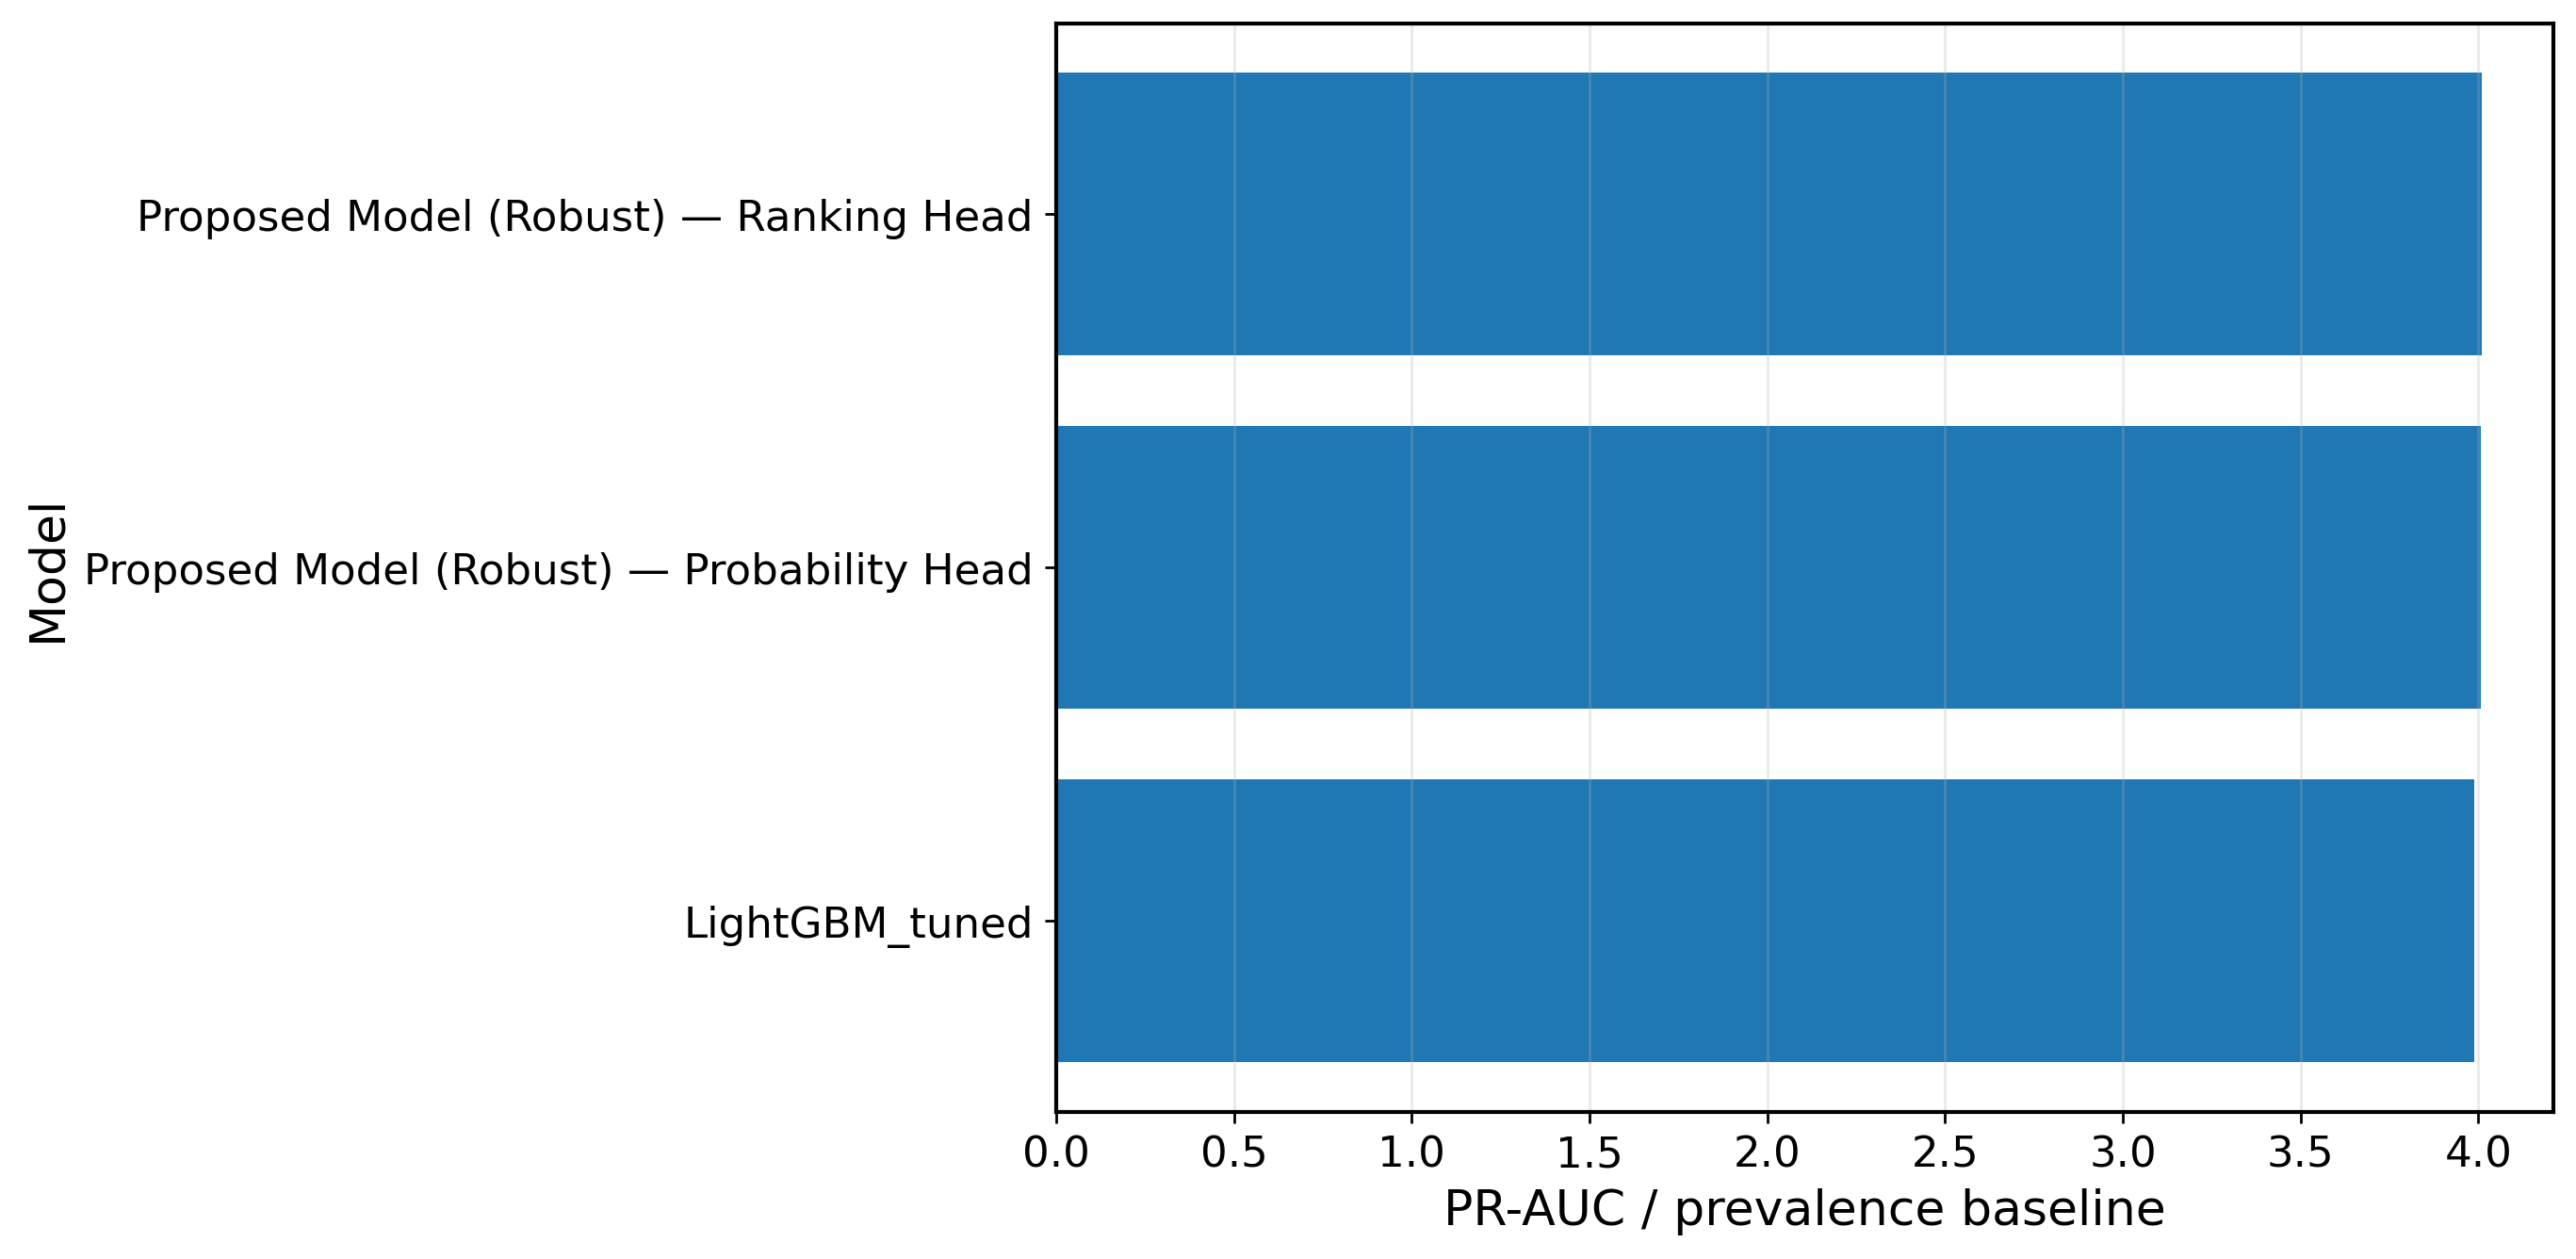

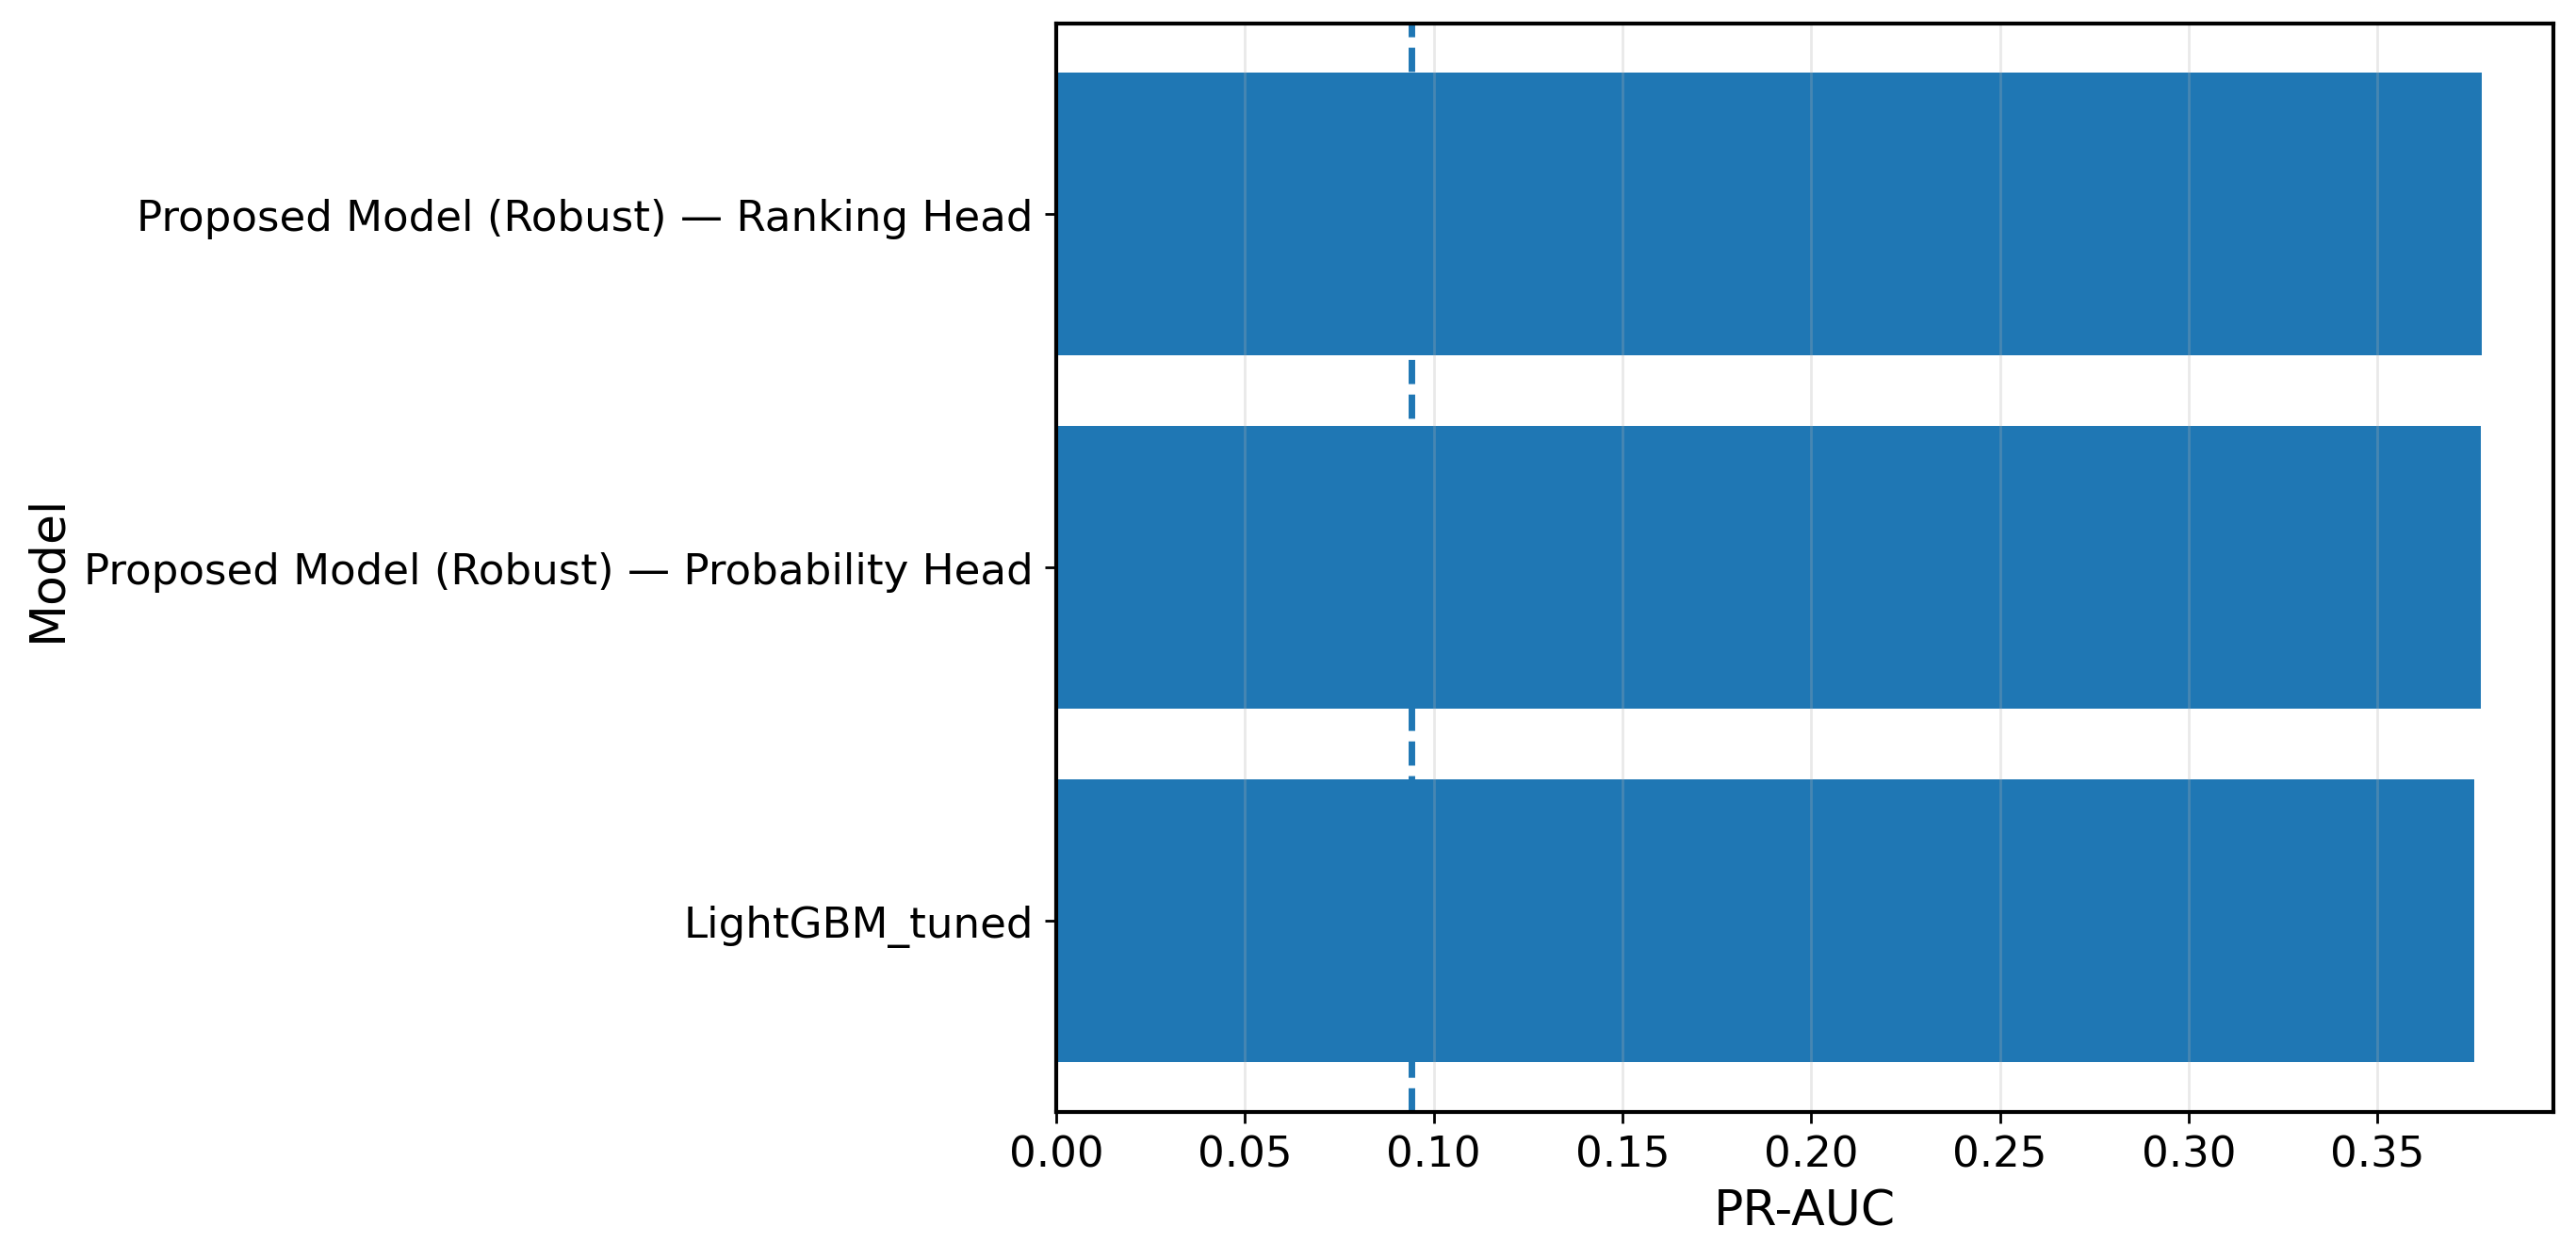

In [10]:
# ============================================================
# Small figure — PR-AUC lift over baseline prevalence
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# resolve predictions
y_fig = y_all.astype(int)
baseline_pr = float(y_fig.mean())

pred_rows = []

# LightGBM
if "p_lgb" in globals():
    p_lgb_fig = clip_probs(p_lgb)
elif "p_lgb_m5b" in globals():
    p_lgb_fig = clip_probs(p_lgb_m5b)
else:
    p_lgb_fig = clip_probs(oof_lgb_tuned)

pred_rows.append({
    "model": "LightGBM_tuned",
    "PR_AUC": float(average_precision_score(y_fig, p_lgb_fig)),
})

# Proposed probability head
if "p_prob_final_pm" in globals():
    p_prob_fig = clip_probs(p_prob_final_pm)
    prob_name = "Proposed Model — Probability Head"
elif "p_prob_raw_pm_robust" in globals():
    p_prob_fig = clip_probs(p_prob_raw_pm_robust)
    prob_name = "Proposed Model (Robust) — Probability Head"
else:
    p_prob_fig = clip_probs(p_prob_raw_pm)
    prob_name = "Proposed Model — Probability Head"

pred_rows.append({
    "model": prob_name,
    "PR_AUC": float(average_precision_score(y_fig, p_prob_fig)),
})

# Proposed ranking head
if "p_rank_final_pm" in globals():
    p_rank_fig = clip_probs(p_rank_final_pm)
    rank_name = "Proposed Model — Ranking Head"
elif "p_rank_raw_pm_robust" in globals():
    p_rank_fig = clip_probs(p_rank_raw_pm_robust)
    rank_name = "Proposed Model (Robust) — Ranking Head"
else:
    p_rank_fig = clip_probs(p_rank_raw_pm)
    rank_name = "Proposed Model — Ranking Head"

pred_rows.append({
    "model": rank_name,
    "PR_AUC": float(average_precision_score(y_fig, p_rank_fig)),
})

moduleX_lift_df = pd.DataFrame(pred_rows)
moduleX_lift_df["Baseline_PR_AUC"] = baseline_pr
moduleX_lift_df["Lift_over_baseline"] = moduleX_lift_df["PR_AUC"] / baseline_pr
moduleX_lift_df["Delta_over_baseline"] = moduleX_lift_df["PR_AUC"] - baseline_pr

moduleX_lift_df.to_csv(TAB_DIR / "pr_auc_lift_over_baseline.csv", index=False)
print(moduleX_lift_df)

# Plot 1: lift over baseline
plt.figure(figsize=(8.2, 6.0))
plot_df = moduleX_lift_df.sort_values("Lift_over_baseline", ascending=True)
plt.barh(plot_df["model"], plot_df["Lift_over_baseline"])
plt.xlabel("PR-AUC / prevalence baseline")
plt.ylabel("Model")
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "pr_auc_lift_over_baseline")
plt.show()

# Plot 2: raw PR-AUC with baseline line
plt.figure(figsize=(8.2, 6.0))
plot_df = moduleX_lift_df.sort_values("PR_AUC", ascending=True)
plt.barh(plot_df["model"], plot_df["PR_AUC"])
plt.axvline(baseline_pr, linestyle="--", linewidth=2)
plt.xlabel("PR-AUC")
plt.ylabel("Model")
plt.grid(axis="x")
save_figure_multi(FIG_DIR / "pr_auc_with_baseline_line")
plt.show()

In [16]:
# ============================================================
# Module 18B — External validation (subsample)
# Dataset:
# Personal Key Indicators of Heart Disease (Kaggle)
# ============================================================

import pandas as pd
import numpy as np
from sklearn.metrics import average_precision_score, roc_auc_score

# -------------------------
# Config
# -------------------------
EXTERNAL_DATA_PATH = "/kaggle/input/datasets/kamilpytlak/personal-key-indicators-of-heart-disease/2020/heart_2020_cleaned.csv"

SUBSAMPLE_SIZE = 20000
RANDOM_SEED = 42

# -------------------------
# Load dataset
# -------------------------
df_ext = pd.read_csv(EXTERNAL_DATA_PATH)

print("External dataset shape:", df_ext.shape)

# -------------------------
# Subsample
# -------------------------
df_ext = df_ext.sample(
    n=min(SUBSAMPLE_SIZE, len(df_ext)),
    random_state=RANDOM_SEED
).reset_index(drop=True)

print("Subsample shape:", df_ext.shape)

# -------------------------
# Target
# -------------------------
y_ext = (df_ext["HeartDisease"] == "Yes").astype(int)

# -------------------------
# Feature mapping
# -------------------------

X_ext = pd.DataFrame()

# AgeCategory → ordinal
age_map = {
    "18-24":1,"25-29":2,"30-34":3,"35-39":4,"40-44":5,
    "45-49":6,"50-54":7,"55-59":8,"60-64":9,"65-69":10,
    "70-74":11,"75-79":12,"80 or older":13
}

X_ext["Age"] = df_ext["AgeCategory"].map(age_map)

# Sex
X_ext["Sex"] = (df_ext["Sex"]=="Male").astype(int)

# BMI
X_ext["BMI"] = df_ext["BMI"]

# Smoking
X_ext["Smoker"] = (df_ext["Smoking"]=="Yes").astype(int)

# Stroke
X_ext["Stroke"] = (df_ext["Stroke"]=="Yes").astype(int)

# Physical activity
X_ext["PhysActivity"] = (df_ext["PhysicalActivity"]=="Yes").astype(int)

# Diabetes
diabetes_map = {
    "No":0,
    "Yes":2,
    "Yes (during pregnancy)":1,
    "No, borderline diabetes":1
}

X_ext["Diabetes"] = df_ext["Diabetic"].map(diabetes_map).fillna(0)

# General health
gen_map = {
    "Excellent":1,
    "Very good":2,
    "Good":3,
    "Fair":4,
    "Poor":5
}

X_ext["GenHlth"] = df_ext["GenHealth"].map(gen_map)

# Physical health days
X_ext["PhysHlth"] = df_ext["PhysicalHealth"]

# Mental health days
X_ext["MentHlth"] = df_ext["MentalHealth"]

# Fill missing BRFSS features with reference defaults
for col in FEATURES:
    if col not in X_ext.columns:
        X_ext[col] = X_all[col].median()

X_ext = X_ext[FEATURES]

print("Aligned external feature shape:", X_ext.shape)

# -------------------------
# Model inference
# -------------------------

X_ext_ml = make_ml_matrix(X_ext)

# LightGBM
if "p_lgb" in globals():
    lgb_model = lgb_model
elif "lgb_model" in globals():
    pass

p_lgb_ext = clip_probs(lgb_model.predict(X_ext_ml))

# XGBoost
p_xgb_ext = clip_probs(xgb_model.predict(xgb.DMatrix(X_ext_ml)))

# ------------------------------------------------
# DeepFM prediction (safe fallback)
# ------------------------------------------------

try:

    X_ext_dfm = X_ext.copy()

    if "scaler_info" in globals():
        X_ext_dfm = transform_with_standard_scaler(
            X_ext_dfm,
            scaler_info
        )

    X_ext_dfm = X_ext_dfm[FEATURES].values

    p_deep_ext = predict_proba_deepfm_external(
        deep_model,
        X_ext_dfm
    )

    print("DeepFM predictions generated.")

except Exception as e:

    print("DeepFM unavailable — using LightGBM fallback")
    p_deep_ext = p_lgb_ext

# Ensemble probability head
p_prob_ext = clip_probs(
    0.55*p_lgb_ext + 0.35*p_xgb_ext + 0.10*p_deep_ext
)

# Ranking head
p_rank_ext = clip_probs(
    rank_avg_local([p_lgb_ext, p_xgb_ext, p_deep_ext])
)

# -------------------------
# Evaluation
# -------------------------

results = []

results.append({
    "model":"LightGBM_external",
    "PR_AUC":average_precision_score(y_ext,p_lgb_ext),
    "ROC_AUC":roc_auc_score(y_ext,p_lgb_ext)
})

results.append({
    "model":"Proposed_prob_external",
    "PR_AUC":average_precision_score(y_ext,p_prob_ext),
    "ROC_AUC":roc_auc_score(y_ext,p_prob_ext)
})

results.append({
    "model":"Proposed_rank_external",
    "PR_AUC":average_precision_score(y_ext,p_rank_ext),
    "ROC_AUC":roc_auc_score(y_ext,p_rank_ext)
})

module18B_results = pd.DataFrame(results)

print("\nExternal validation (subsample) results:")
print(module18B_results)

module18B_results.to_csv(
    TAB_DIR/"external_validation_subsample_results.csv",
    index=False
)

External dataset shape: (319795, 18)
Subsample shape: (20000, 18)
Aligned external feature shape: (20000, 21)
DeepFM predictions generated.

External validation (subsample) results:
                    model    PR_AUC   ROC_AUC
0       LightGBM_external  0.320467  0.826581
1  Proposed_prob_external  0.322075  0.827242
2  Proposed_rank_external  0.322968  0.826831


In [13]:
# ============================================================
# Train LightGBM on full BRFSS dataset for external validation
# ============================================================

import lightgbm as lgb

X_full = make_ml_matrix(X_all)
y_full = y_all.astype(int)

pos = (y_full == 1).sum()
neg = (y_full == 0).sum()

scale_pos_weight = neg / max(pos,1)

params = {
    "objective":"binary",
    "learning_rate":0.03,
    "num_leaves":64,
    "min_data_in_leaf":200,
    "feature_fraction":0.85,
    "bagging_fraction":0.85,
    "bagging_freq":1,
    "lambda_l2":10.0,
    "scale_pos_weight":scale_pos_weight,
    "metric":"auc",
    "verbosity":-1,
    "seed":42
}

dtrain = lgb.Dataset(X_full, label=y_full)

lgb_model = lgb.train(
    params,
    dtrain,
    num_boost_round=800
)

print("Full LightGBM model trained for external validation.")

Full LightGBM model trained for external validation.


In [14]:
import xgboost as xgb

dtrain = xgb.DMatrix(X_full.values, label=y_full)

xgb_model = xgb.train(
    {
        "objective":"binary:logistic",
        "eval_metric":"auc",
        "eta":0.03,
        "max_depth":6,
        "subsample":0.85,
        "colsample_bytree":0.85,
        "scale_pos_weight":scale_pos_weight,
        "seed":42
    },
    dtrain,
    num_boost_round=700
)

print("Full XGBoost model trained for external validation.")

Full XGBoost model trained for external validation.


In [2]:
# ============================================================
# Main Dataset Pipeline — heart_2020_cleaned.csv
# Split design:
#   70% train / 10% calibration / 20% test
#
# Current model:
#   - LightGBM
#   - XGBoost
#   - DeepFM_Robust
#   - Probability head
#   - Ranking head
#   - Logistic calibration on calibration split
# ============================================================

# -------------------------
# Imports
# -------------------------
import os
import gc
import math
import json
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    confusion_matrix,
)
from sklearn.linear_model import LogisticRegression

import lightgbm as lgb
import xgboost as xgb

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

# -------------------------
# Reproducibility
# -------------------------
SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)

# -------------------------
# Paths
# -------------------------
ROOT_DIR = Path("/kaggle/working")
OUT_DIR = ROOT_DIR / "outputs_main_heart2020"
FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
MOD_DIR = OUT_DIR / "models"

for d in [OUT_DIR, FIG_DIR, TAB_DIR, MOD_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# -------------------------
# Config
# -------------------------
DATA_PATH = "/kaggle/input/datasets/kamilpytlak/personal-key-indicators-of-heart-disease/2020/heart_2020_cleaned.csv"
TARGET = "HeartDisease"

TRAIN_RATIO = 0.70
CAL_RATIO = 0.10
TEST_RATIO = 0.20

assert abs(TRAIN_RATIO + CAL_RATIO + TEST_RATIO - 1.0) < 1e-8

# Robust DeepFM settings
ROBUST_BATCH_SIZE = 4096
ROBUST_LR = 1e-3
ROBUST_WD = 1e-4
ROBUST_EPOCHS = 25
ROBUST_PATIENCE = 5

ROBUST_MASK_PROB_BINARY = 0.06
ROBUST_MASK_PROB_ORDINAL = 0.06
ROBUST_MASK_PROB_CONT = 0.03
ROBUST_CONT_NOISE_STD = 0.03

ROBUST_ALPHA_CORRUPT = 0.50
ROBUST_LAMBDA_CONSISTENCY = 0.20

# Ensemble weights
W_LGB = 0.55
W_XGB = 0.35
W_DFM = 0.10

print("Setup done.")

# ============================================================
# Helpers
# ============================================================

def clip_probs(p):
    return np.clip(np.asarray(p, dtype=np.float32), 1e-8, 1 - 1e-8)

def expected_calibration_error(y_true, p, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)

    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    mce = 0.0

    for i in range(n_bins):
        lo, hi = bins[i], bins[i + 1]
        if i < n_bins - 1:
            mask = (p >= lo) & (p < hi)
        else:
            mask = (p >= lo) & (p <= hi)

        if mask.sum() == 0:
            continue

        acc = y_true[mask].mean()
        conf = p[mask].mean()
        err = abs(acc - conf)

        ece += (mask.sum() / len(p)) * err
        mce = max(mce, err)

    return float(ece), float(mce)

def evaluate_probs(y_true, p, name="model"):
    y_true = np.asarray(y_true).astype(int)
    p = clip_probs(p)

    pr_auc = average_precision_score(y_true, p)
    roc_auc = roc_auc_score(y_true, p)
    brier = brier_score_loss(y_true, p)
    nll = log_loss(y_true, p)
    ece, mce = expected_calibration_error(y_true, p, n_bins=15)

    precisions, recalls, thresholds = precision_recall_curve(y_true, p)
    f1_vals = 2 * precisions * recalls / (precisions + recalls + 1e-12)
    best_idx = int(np.nanargmax(f1_vals))
    thr_bestF1 = 0.5 if len(thresholds) == 0 else float(thresholds[max(best_idx - 1, 0)])

    pred_best = (p >= thr_bestF1).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_true, pred_best, labels=[0, 1]).ravel()
    bal_acc = balanced_accuracy_score(y_true, pred_best)
    mcc = matthews_corrcoef(y_true, pred_best) if len(np.unique(pred_best)) > 1 else 0.0

    return {
        "model": name,
        "PR_AUC": float(pr_auc),
        "ROC_AUC": float(roc_auc),
        "Brier": float(brier),
        "NLL": float(nll),
        "ECE": float(ece),
        "MCE": float(mce),
        "p_mean": float(np.mean(p)),
        "pos_rate": float(np.mean(y_true)),
        "N": int(len(y_true)),
        "thr_bestF1": float(thr_bestF1),
        "Prec@bestF1": float(precision_score(y_true, pred_best, zero_division=0)),
        "Rec@bestF1": float(recall_score(y_true, pred_best, zero_division=0)),
        "F1@bestF1": float(f1_score(y_true, pred_best, zero_division=0)),
        "Acc@bestF1": float(accuracy_score(y_true, pred_best)),
        "BalAcc@bestF1": float(bal_acc),
        "MCC@bestF1": float(mcc),
        "TP": int(tp),
        "FP": int(fp),
        "TN": int(tn),
        "FN": int(fn),
    }

def logit_np(p):
    p = clip_probs(p)
    return np.log(p / (1.0 - p))

def rank_scores_local(p):
    p = np.asarray(p).reshape(-1)
    order = np.argsort(np.argsort(p))
    r = (order + 0.5) / len(p)
    return clip_probs(r.astype(np.float32))

def rank_avg_local(p_list):
    rs = [rank_scores_local(p) for p in p_list]
    return clip_probs(np.mean(np.vstack(rs), axis=0))

def prob_avg_local(p_list, weights):
    p_list = [clip_probs(p) for p in p_list]
    weights = np.asarray(weights, dtype=np.float32)
    weights = weights / (weights.sum() + 1e-12)

    out = np.zeros_like(p_list[0], dtype=np.float32)
    for w, p in zip(weights, p_list):
        out += w * p
    return clip_probs(out)

def logistic_calibrate(train_scores, train_y, apply_scores):
    X_train = logit_np(train_scores).reshape(-1, 1)
    X_apply = logit_np(apply_scores).reshape(-1, 1)

    clf = LogisticRegression(max_iter=4000, solver="lbfgs")
    clf.fit(X_train, train_y.astype(int))
    p = clf.predict_proba(X_apply)[:, 1]
    return clip_probs(p), clf

# ============================================================
# Load and preprocess heart_2020_cleaned
# ============================================================

df = pd.read_csv(DATA_PATH)
print("Loaded:", df.shape)

# target
y_all = (df[TARGET] == "Yes").astype(int).values

# -------------------------
# Schema-aware mapping
# -------------------------
bin_map = {"Yes": 1, "No": 0}
sex_map = {"Male": 1, "Female": 0}
gen_map = {"Excellent": 1, "Very good": 2, "Good": 3, "Fair": 4, "Poor": 5}
age_map = {
    "18-24":1, "25-29":2, "30-34":3, "35-39":4, "40-44":5,
    "45-49":6, "50-54":7, "55-59":8, "60-64":9, "65-69":10,
    "70-74":11, "75-79":12, "80 or older":13
}
diabetes_map = {
    "No": 0,
    "No, borderline diabetes": 1,
    "Yes (during pregnancy)": 1,
    "Yes": 2
}
race_order = {
    "White": 0,
    "Black": 1,
    "Asian": 2,
    "American Indian/Alaskan Native": 3,
    "Other": 4,
    "Hispanic": 5,
}

X = pd.DataFrame()
X["BMI"] = pd.to_numeric(df["BMI"], errors="coerce")
X["Smoking"] = df["Smoking"].map(bin_map)
X["AlcoholDrinking"] = df["AlcoholDrinking"].map(bin_map)
X["Stroke"] = df["Stroke"].map(bin_map)
X["PhysicalHealth"] = pd.to_numeric(df["PhysicalHealth"], errors="coerce")
X["MentalHealth"] = pd.to_numeric(df["MentalHealth"], errors="coerce")
X["DiffWalking"] = df["DiffWalking"].map(bin_map)
X["Sex"] = df["Sex"].map(sex_map)
X["AgeCategory"] = df["AgeCategory"].map(age_map)
X["Race"] = df["Race"].map(race_order).fillna(6)
X["Diabetic"] = df["Diabetic"].map(diabetes_map).fillna(0)
X["PhysicalActivity"] = df["PhysicalActivity"].map(bin_map)
X["GenHealth"] = df["GenHealth"].map(gen_map)
X["SleepTime"] = pd.to_numeric(df["SleepTime"], errors="coerce")
X["Asthma"] = df["Asthma"].map(bin_map)
X["KidneyDisease"] = df["KidneyDisease"].map(bin_map)
X["SkinCancer"] = df["SkinCancer"].map(bin_map)

# fill
for c in X.columns:
    if X[c].isna().any():
        if X[c].dtype.kind in "biufc":
            X[c] = X[c].fillna(X[c].median())
        else:
            X[c] = X[c].fillna(0)

FEATURES = list(X.columns)

CONT_COLS = ["BMI", "PhysicalHealth", "MentalHealth", "SleepTime"]
ORDINAL_COLS = ["AgeCategory", "GenHealth", "Diabetic", "Race"]
BINARY_COLS = [c for c in FEATURES if c not in CONT_COLS + ORDINAL_COLS]

print("Features:", FEATURES)
print("Positive rate:", y_all.mean())

# ============================================================
# 70 / 10 / 20 split
# ============================================================

# first split off test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y_all,
    test_size=TEST_RATIO,
    stratify=y_all,
    random_state=SEED
)

# split temp into train/cal
cal_ratio_adjusted = CAL_RATIO / (TRAIN_RATIO + CAL_RATIO)  # 0.10 / 0.80 = 0.125
X_train, X_cal, y_train, y_cal = train_test_split(
    X_temp, y_temp,
    test_size=cal_ratio_adjusted,
    stratify=y_temp,
    random_state=SEED
)

print("\nSplit summary")
print("Train:", X_train.shape, y_train.mean())
print("Cal  :", X_cal.shape, y_cal.mean())
print("Test :", X_test.shape, y_test.mean())

split_summary_df = pd.DataFrame([
    {"split": "train", "N": len(y_train), "pos_rate": float(y_train.mean())},
    {"split": "cal",   "N": len(y_cal),   "pos_rate": float(y_cal.mean())},
    {"split": "test",  "N": len(y_test),  "pos_rate": float(y_test.mean())},
])
split_summary_df.to_csv(TAB_DIR / "main_dataset_split_summary.csv", index=False)

# ============================================================
# Preprocessing helpers
# ============================================================

def sanitize_dataframe(X_df):
    X_df = X_df.copy()
    for c in X_df.columns:
        X_df[c] = pd.to_numeric(X_df[c], errors="coerce")
        X_df[c] = X_df[c].replace([np.inf, -np.inf], np.nan)
        X_df[c] = X_df[c].fillna(X_df[c].median())
    return X_df

def make_ml_matrix(X_df):
    return sanitize_dataframe(X_df)[FEATURES].copy()

def fit_standard_scaler_on_train(X_train_df):
    X_train_df = sanitize_dataframe(X_train_df)

    scaler_info = {
        "continuous_cols": CONT_COLS.copy(),
        "means": {},
        "stds": {},
    }

    for c in CONT_COLS:
        vals = X_train_df[c].values.astype(np.float32)
        mean_ = float(vals.mean())
        std_ = float(vals.std())
        if std_ < 1e-8:
            std_ = 1.0
        scaler_info["means"][c] = mean_
        scaler_info["stds"][c] = std_

    return scaler_info

def transform_with_standard_scaler(X_df, scaler_info):
    X_df = sanitize_dataframe(X_df)
    for c in scaler_info["continuous_cols"]:
        X_df[c] = (X_df[c].astype(np.float32) - scaler_info["means"][c]) / scaler_info["stds"][c]
    return X_df

# ============================================================
# LightGBM
# ============================================================

Xtr_ml = make_ml_matrix(X_train)
Xcal_ml = make_ml_matrix(X_cal)
Xte_ml = make_ml_matrix(X_test)

pos = int((y_train == 1).sum())
neg = int((y_train == 0).sum())
scale_pos_weight = neg / max(pos, 1)

lgb_params = dict(
    objective="binary",
    boosting_type="gbdt",
    learning_rate=0.03,
    num_leaves=64,
    min_data_in_leaf=200,
    feature_fraction=0.85,
    bagging_fraction=0.85,
    bagging_freq=1,
    lambda_l2=10.0,
    scale_pos_weight=scale_pos_weight,
    metric="auc",
    verbosity=-1,
    seed=SEED,
)

dtr = lgb.Dataset(Xtr_ml, label=y_train)
dva = lgb.Dataset(Xcal_ml, label=y_cal)

lgb_model = lgb.train(
    params=lgb_params,
    train_set=dtr,
    num_boost_round=5000,
    valid_sets=[dva],
    callbacks=[lgb.early_stopping(200, verbose=False)]
)

p_lgb_cal = clip_probs(lgb_model.predict(Xcal_ml, num_iteration=lgb_model.best_iteration))
p_lgb_test = clip_probs(lgb_model.predict(Xte_ml, num_iteration=lgb_model.best_iteration))

# ============================================================
# XGBoost
# ============================================================

dtr_x = xgb.DMatrix(Xtr_ml.values, label=y_train)
dva_x = xgb.DMatrix(Xcal_ml.values, label=y_cal)
dte_x = xgb.DMatrix(Xte_ml.values)

xgb_params = dict(
    objective="binary:logistic",
    eval_metric="auc",
    eta=0.03,
    max_depth=6,
    min_child_weight=30,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=10.0,
    scale_pos_weight=scale_pos_weight,
    seed=SEED,
)

xgb_model = xgb.train(
    params=xgb_params,
    dtrain=dtr_x,
    num_boost_round=3000,
    evals=[(dva_x, "valid")],
    early_stopping_rounds=200,
    verbose_eval=False
)

p_xgb_cal = clip_probs(xgb_model.predict(dva_x))
p_xgb_test = clip_probs(xgb_model.predict(dte_x))

# ============================================================
# DeepFM_Robust
# ============================================================

class TabularTensorDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = None if y is None else torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        if self.y is None:
            return self.X[idx]
        return self.X[idx], self.y[idx]

class DeepFMRobust(nn.Module):
    def __init__(self, n_features, k=16, hidden_dim=256, n_hidden=3, dropout=0.15):
        super().__init__()
        self.linear_w = nn.Parameter(torch.zeros(n_features))
        self.linear_b = nn.Parameter(torch.zeros(1))
        self.V = nn.Parameter(torch.randn(n_features, k) * 0.02)

        self.input_layer = nn.Sequential(
            nn.Linear(n_features, hidden_dim),
            nn.LayerNorm(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
        )

        hidden_layers = []
        for _ in range(n_hidden):
            hidden_layers += [
                nn.Linear(hidden_dim, hidden_dim),
                nn.LayerNorm(hidden_dim),
                nn.GELU(),
                nn.Dropout(dropout),
            ]
        self.deep = nn.Sequential(*hidden_layers)
        self.out = nn.Linear(hidden_dim + 2, 1)

    def forward(self, x):
        linear_term = (x * self.linear_w.unsqueeze(0)).sum(dim=1) + self.linear_b

        xv = x @ self.V
        xv2 = xv * xv
        x2v2 = (x * x) @ (self.V * self.V)
        fm_term = 0.5 * (xv2 - x2v2).sum(dim=1)

        h = self.input_layer(x)
        h = self.deep(h)

        z = torch.cat([h, linear_term.unsqueeze(1), fm_term.unsqueeze(1)], dim=1)
        return self.out(z).squeeze(-1)

FEATURE_TO_IDX = {c: i for i, c in enumerate(FEATURES)}
BINARY_IDX = [FEATURE_TO_IDX[c] for c in BINARY_COLS]
ORDINAL_IDX = [FEATURE_TO_IDX[c] for c in ORDINAL_COLS]
CONT_IDX = [FEATURE_TO_IDX[c] for c in CONT_COLS]

def apply_tabular_corruption(xb):
    x = xb.clone()
    device = x.device
    B, D = x.shape

    if len(BINARY_IDX) > 0:
        idx = torch.tensor(BINARY_IDX, device=device, dtype=torch.long)
        mask = (torch.rand((B, len(BINARY_IDX)), device=device) < ROBUST_MASK_PROB_BINARY)
        sub = x[:, idx]
        sub = torch.where(mask, torch.zeros_like(sub), sub)
        x[:, idx] = sub

    if len(ORDINAL_IDX) > 0:
        idx = torch.tensor(ORDINAL_IDX, device=device, dtype=torch.long)
        mask = (torch.rand((B, len(ORDINAL_IDX)), device=device) < ROBUST_MASK_PROB_ORDINAL)
        sub = x[:, idx]
        sub = torch.where(mask, torch.zeros_like(sub), sub)
        x[:, idx] = sub

    if len(CONT_IDX) > 0:
        idx = torch.tensor(CONT_IDX, device=device, dtype=torch.long)
        sub = x[:, idx]

        mask = (torch.rand((B, len(CONT_IDX)), device=device) < ROBUST_MASK_PROB_CONT)
        sub = torch.where(mask, torch.zeros_like(sub), sub)

        noise = torch.randn_like(sub) * ROBUST_CONT_NOISE_STD
        sub = sub + noise

        x[:, idx] = sub

    return x

@torch.no_grad()
def predict_proba_torch(model, loader, device):
    model.eval()
    ps = []

    for batch in loader:
        # handle both:
        # 1) loader yielding only X
        # 2) loader yielding (X, y)
        if isinstance(batch, (list, tuple)):
            xb = batch[0]
        else:
            xb = batch

        xb = xb.to(device, non_blocking=True)
        logits = model(xb)
        p = torch.sigmoid(logits).detach().cpu().numpy()
        ps.append(p)

    return clip_probs(np.concatenate(ps))

def train_deepfm_robust(model, train_loader, val_loader, pos_weight_value):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)

    opt = torch.optim.AdamW(model.parameters(), lr=ROBUST_LR, weight_decay=ROBUST_WD)
    scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
    pos_weight_tensor = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)

    best_val = 1e18
    best_state = None
    bad_epochs = 0

    for ep in range(1, ROBUST_EPOCHS + 1):
        model.train()
        tr_loss = 0.0
        n_tr = 0

        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True)
            yb = yb.to(device, non_blocking=True)
            xb_corrupt = apply_tabular_corruption(xb)

            opt.zero_grad(set_to_none=True)

            with torch.cuda.amp.autocast(enabled=(device == "cuda")):
                logits_clean = model(xb)
                logits_corrupt = model(xb_corrupt)

                loss_clean = F.binary_cross_entropy_with_logits(
                    logits_clean, yb, pos_weight=pos_weight_tensor
                )
                loss_corrupt = F.binary_cross_entropy_with_logits(
                    logits_corrupt, yb, pos_weight=pos_weight_tensor
                )

                p_clean = torch.sigmoid(logits_clean)
                p_corrupt = torch.sigmoid(logits_corrupt)
                loss_cons = F.mse_loss(p_clean, p_corrupt)

                loss = loss_clean + ROBUST_ALPHA_CORRUPT * loss_corrupt + ROBUST_LAMBDA_CONSISTENCY * loss_cons

            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()

            bs = xb.size(0)
            tr_loss += loss.item() * bs
            n_tr += bs

        model.eval()
        va_loss = 0.0
        n_va = 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device, non_blocking=True)
                yb = yb.to(device, non_blocking=True)
                logits = model(xb)
                loss = F.binary_cross_entropy_with_logits(
                    logits, yb, pos_weight=pos_weight_tensor
                )
                bs = xb.size(0)
                va_loss += loss.item() * bs
                n_va += bs

        tr_loss /= max(n_tr, 1)
        va_loss /= max(n_va, 1)

        if ep == 1 or ep % 2 == 0:
            print(f"DeepFM_Robust ep {ep:02d} | train={tr_loss:.5f} | val={va_loss:.5f}")

        if va_loss < best_val - 1e-6:
            best_val = va_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= ROBUST_PATIENCE:
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    return model

# scale cont features based on train only
scaler_info = fit_standard_scaler_on_train(X_train)
Xtr_dfm = transform_with_standard_scaler(X_train, scaler_info)[FEATURES].copy()
Xcal_dfm = transform_with_standard_scaler(X_cal, scaler_info)[FEATURES].copy()
Xte_dfm = transform_with_standard_scaler(X_test, scaler_info)[FEATURES].copy()

train_ds = TabularTensorDataset(Xtr_dfm.values.astype(np.float32), y_train.astype(np.float32))
cal_ds = TabularTensorDataset(Xcal_dfm.values.astype(np.float32), y_cal.astype(np.float32))
test_ds = TabularTensorDataset(Xte_dfm.values.astype(np.float32), None)

device = "cuda" if torch.cuda.is_available() else "cpu"
train_loader = DataLoader(train_ds, batch_size=ROBUST_BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=(device == "cuda"))
cal_loader = DataLoader(cal_ds, batch_size=ROBUST_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=(device == "cuda"))
test_loader = DataLoader(test_ds, batch_size=ROBUST_BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=(device == "cuda"))

pos_weight_value = float(scale_pos_weight * 0.75)

deep_model = DeepFMRobust(
    n_features=len(FEATURES),
    k=16,
    hidden_dim=256,
    n_hidden=3,
    dropout=0.15
)

deep_model = train_deepfm_robust(deep_model, train_loader, cal_loader, pos_weight_value)

p_dfm_cal = predict_proba_torch(deep_model, cal_loader, device=device)
p_dfm_test = predict_proba_torch(deep_model, test_loader, device=device)

# ============================================================
# Current model heads on this dataset
# ============================================================

# raw heads
p_prob_raw_cal = prob_avg_local([p_lgb_cal, p_xgb_cal, p_dfm_cal], weights=[W_LGB, W_XGB, W_DFM])
p_prob_raw_test = prob_avg_local([p_lgb_test, p_xgb_test, p_dfm_test], weights=[W_LGB, W_XGB, W_DFM])

p_rank_raw_cal = rank_avg_local([p_lgb_cal, p_xgb_cal, p_dfm_cal])
p_rank_raw_test = rank_avg_local([p_lgb_test, p_xgb_test, p_dfm_test])

# logistic calibration on calibration split
p_prob_final_test, prob_calibrator = logistic_calibrate(
    train_scores=p_prob_raw_cal,
    train_y=y_cal,
    apply_scores=p_prob_raw_test,
)

# optional calibrated ranking head for comparison
p_rank_final_test, rank_calibrator = logistic_calibrate(
    train_scores=p_rank_raw_cal,
    train_y=y_cal,
    apply_scores=p_rank_raw_test,
)

# ============================================================
# Final evaluation on TEST ONLY
# ============================================================

rows = []
rows.append(evaluate_probs(y_test, p_lgb_test, name="LightGBM_test"))
rows.append(evaluate_probs(y_test, p_xgb_test, name="XGBoost_test"))
rows.append(evaluate_probs(y_test, p_dfm_test, name="DeepFM_Robust_test"))
rows.append(evaluate_probs(y_test, p_prob_raw_test, name="Proposed Model — Probability Head (Raw)"))
rows.append(evaluate_probs(y_test, p_prob_final_test, name="Proposed Model — Probability Head (Logistic Calibrated)"))
rows.append(evaluate_probs(y_test, p_rank_raw_test, name="Proposed Model — Ranking Head (Raw)"))
rows.append(evaluate_probs(y_test, p_rank_final_test, name="Proposed Model — Ranking Head (Logistic Calibrated)"))

results_df = pd.DataFrame(rows).sort_values(["PR_AUC", "ROC_AUC"], ascending=[False, False]).reset_index(drop=True)
results_df.to_csv(TAB_DIR / "main_dataset_test_results.csv", index=False)

print("\nFinal TEST results")
print(results_df)

# ============================================================
# Save predictions
# ============================================================

pred_df = pd.DataFrame({
    "y_true": y_test.astype(int),
    "p_lgb_test": p_lgb_test,
    "p_xgb_test": p_xgb_test,
    "p_dfm_test": p_dfm_test,
    "p_prob_raw_test": p_prob_raw_test,
    "p_prob_final_test": p_prob_final_test,
    "p_rank_raw_test": p_rank_raw_test,
    "p_rank_final_test": p_rank_final_test,
})
pred_df.to_csv(TAB_DIR / "main_dataset_test_predictions.csv", index=False)

# ============================================================
# Compact summary
# ============================================================

summary_df = pd.DataFrame([{
    "dataset": "heart_2020_cleaned.csv",
    "split_design": "70_train_10_cal_20_test",
    "best_model_by_pr_auc": results_df.iloc[0]["model"],
    "best_PR_AUC": results_df.iloc[0]["PR_AUC"],
    "best_ROC_AUC": results_df.iloc[0]["ROC_AUC"],
}])
summary_df.to_csv(TAB_DIR / "main_dataset_summary.csv", index=False)

print("\nDone. Files saved in:", OUT_DIR)

Setup done.
Loaded: (319795, 18)
Features: ['BMI', 'Smoking', 'AlcoholDrinking', 'Stroke', 'PhysicalHealth', 'MentalHealth', 'DiffWalking', 'Sex', 'AgeCategory', 'Race', 'Diabetic', 'PhysicalActivity', 'GenHealth', 'SleepTime', 'Asthma', 'KidneyDisease', 'SkinCancer']
Positive rate: 0.08559545959130067

Split summary
Train: (223856, 17) 0.0855952040597527
Cal  : (31980, 17) 0.08558474046278924
Test : (63959, 17) 0.08560171359777358
DeepFM_Robust ep 01 | train=1.37774 | val=0.83178
DeepFM_Robust ep 02 | train=1.22672 | val=0.79551
DeepFM_Robust ep 04 | train=1.18429 | val=0.78119
DeepFM_Robust ep 06 | train=1.17354 | val=0.77834
DeepFM_Robust ep 08 | train=1.17027 | val=0.77735
DeepFM_Robust ep 10 | train=1.16922 | val=0.78101
DeepFM_Robust ep 12 | train=1.16598 | val=0.78000

Final TEST results
                                               model    PR_AUC   ROC_AUC  \
0                Proposed Model — Ranking Head (Raw)  0.353376  0.841083   
1  Proposed Model — Ranking Head (Logistic